#ProgramadorDeTasaDeAprendizajeDinamico

In [ ]:
#import numpy as np

def actualizar_learning_rate_scheduler(
    current_lr: float,
    metrica_actual: float,
    mejor_metrica_registrada: float,
    epocas_sin_mejora: int,
    paciencia_lr: int,
    factor_reduccion_lr: float,
    min_lr: float,
    es_mejor_mayor: bool = True # True si una métrica mayor es mejor (ej. precisión), False si menor es mejor (ej. error)
) -> tuple[float, int, float, bool]:
    """
    Ajusta la tasa de aprendizaje basándose en el rendimiento de una métrica de monitoreo.

    Args:
        current_lr (float): Tasa de aprendizaje actual.
        metrica_actual (float): Valor de la métrica en la época actual.
        mejor_metrica_registrada (float): El mejor valor de la métrica registrado hasta ahora.
        epocas_sin_mejora (int): Número de épocas consecutivas sin mejora en la métrica.
        paciencia_lr (int): Número de épocas sin mejora para reducir la tasa de aprendizaje.
        factor_reduccion_lr (float): Factor por el cual se reduce la tasa de aprendizaje (ej. 0.1).
        min_lr (float): Valor mínimo al que puede descender la tasa de aprendizaje.
        es_mejor_mayor (bool): Indica si un valor *mayor* de la métrica es mejor (True, ej. precisión)
                               o si un valor *menor* es mejor (False, ej. error).

    Returns:
        tuple[float, int, float, bool]:
            - La nueva tasa de aprendizaje.
            - El nuevo contador de épocas sin mejora.
            - El nuevo mejor valor de la métrica registrada.
            - Un booleano indicando si la métrica mejoró en esta época.
    """
    mejoro_en_esta_epoca = False

    # Determina si la métrica actual es mejor que la mejor registrada hasta ahora
    if (es_mejor_mayor and metrica_actual > mejor_metrica_registrada) or \
       (not es_mejor_mayor and metrica_actual < mejor_metrica_registrada):
        mejor_metrica_registrada = metrica_actual
        epocas_sin_mejora = 0
        mejoro_en_esta_epoca = True
    else:
        epocas_sin_mejora += 1 # Incrementa las épocas sin mejora

    # Reduce la tasa de aprendizaje si la paciencia se agota
    if epocas_sin_mejora >= paciencia_lr:
        new_lr = current_lr * factor_reduccion_lr
        if new_lr >= min_lr:
            current_lr = new_lr
            epocas_sin_mejora = 0 # Reinicia la paciencia
        else:
            current_lr = min_lr # La tasa de aprendizaje no baja del mínimo

    return current_lr, epocas_sin_mejora, mejor_metrica_registrada, mejoro_en_esta_epoca

#OptimizaciónAdaptativaBasadaEnError

In [ ]:
import numpy as np
from dataclasses import dataclass


def OptimizaciónAdaptativaBasadaEnError(
    red: 'RedNeuronalDC', # Usa string para forward reference si RedNeuronalDC no está definida arriba
    X_train: np.ndarray,
    y_train: np.ndarray,
    learning_rate: float,
    epocas_por_ciclo_base: int = 50,
    umbral_mejora_minima: float = 0.0001,
    umbral_error_convergencia: float = 0.02,
    max_epocas_acumuladas: int = 1000
) -> tuple['RedNeuronalDC', list[float]]:
    """
    Entrena una Red Neuronal de forma adaptativa, ajustando el número de épocas
    en ciclos basados en la mejora del error.

    Args:
        red (RedNeuronalDC): La instancia de la red neuronal a entrenar.
        X_train (np.ndarray): Datos de entrada para el entrenamiento.
        y_train (np.ndarray): Etiquetas objetivo para el entrenamiento.
        learning_rate (float): La tasa de aprendizaje para las actualizaciones de pesos.
        epocas_por_ciclo_base (int): Número de épocas a entrenar en cada ciclo de verificación.
        umbral_mejora_minima (float): Si el error no mejora al menos esta cantidad
                                       en un ciclo, se puede detener el entrenamiento.
        umbral_error_convergencia (float): Si el error promedio cae por debajo de este umbral,
                                         se considera que la red ha convergido y se detiene.
        max_epocas_acumuladas (int): El número máximo total de épocas a entrenar,
                                     independientemente de la mejora.

    Returns:
        tuple[RedNeuronalDC, list[float]]:
            - La red neuronal entrenada.
            - Una lista del historial de errores promedio por cada época.
    """
    print("\n--- Iniciando Proceso de Optimización Adaptativa Basada en Error ---")
    historial_errores_total = []
    epocas_completadas = 0
    error_promedio_anterior_ciclo = float('inf') # Para comparar la mejora entre ciclos

    while epocas_completadas < max_epocas_acumuladas:
        # Calcular épocas para el ciclo actual, respetando el máximo total
        epocas_para_este_ciclo = min(epocas_por_ciclo_base, max_epocas_acumuladas - epocas_completadas)

        if epocas_para_este_ciclo <= 0:
            print("No quedan épocas disponibles dentro del límite máximo. Deteniendo.")
            break

        print(f"\n--- Ciclo de Entrenamiento: Épocas {epocas_completadas + 1} a {epocas_completadas + epocas_para_este_ciclo} ---")

        for epoch_in_cycle in range(epocas_para_este_ciclo):
            epoch_global_actual = epocas_completadas + epoch_in_cycle + 1
            error_total_epoca = 0

            # Mezclar datos de entrenamiento en cada época para aleatoriedad
            indices = np.arange(X_train.shape[0])
            np.random.shuffle(indices)
            X_shuffled, y_shuffled = X_train[indices], y_train[indices]

            for i in range(X_train.shape[0]):
                entrada = X_shuffled[i]
                objetivo = y_shuffled[i]

                # Propagación Hacia Adelante (Forward Pass)
                prediccion_final, salidas_capa_oculta_a, salidas_capa_oculta_z, salidas_capa_salida_z = predecir_red_dc(red, entrada)
                prediccion_final_valor = prediccion_final[0]

                # Cálculo del Error Instantáneo
                error_salida = objetivo - prediccion_final_valor
                error_total_epoca += 0.5 * (error_salida ** 2)

                # Retropropagación (Backpropagation)
                delta_salida = error_salida * derivada_sigmoide_de_salida(prediccion_final_valor)
                error_propagado_a_oculta = delta_salida * red.capa_salida[0].pesos
                delta_oculta = error_propagado_a_oculta * derivada_sigmoide_de_salida(salidas_capa_oculta_a)

                # Actualización de Pesos y Sesgos de la Capa de Salida
                red.capa_salida[0].pesos += learning_rate * delta_salida * salidas_capa_oculta_a
                red.capa_salida[0].sesgo += learning_rate * delta_salida

                # Actualización de Pesos y Sesgos de la Capa Oculta
                for j, neurona_oculta in enumerate(red.capa_oculta):
                    neurona_oculta.pesos += learning_rate * delta_oculta[j] * entrada
                    neurona_oculta.sesgo += learning_rate * delta_oculta[j]

            # Error promedio de la época
            avg_error_this_epoch = error_total_epoca / X_train.shape[0]
            historial_errores_total.append(avg_error_this_epoch)

            # Imprimir progreso de la época
            if (epoch_in_cycle + 1) % (epocas_para_este_ciclo // 5 if epocas_para_este_ciclo // 5 > 0 else 1) == 0 or (epoch_in_cycle + 1) == epocas_para_este_ciclo:
                print(f"  Época Global {epoch_global_actual}/{max_epocas_acumuladas}, Error Promedio: {avg_error_this_epoch:.6f}")

        epocas_completadas += epocas_para_este_ciclo # Actualizar el conteo total de épocas

        # Verificación del error al final del ciclo para decisiones adaptativas
        if historial_errores_total:
            error_actual_promedio_ciclo = historial_errores_total[-1]
            print(f"Error promedio al final de {epocas_completadas} épocas acumuladas: {error_actual_promedio_ciclo:.6f}")

            # Criterio de parada temprana: Convergencia por error objetivo
            if error_actual_promedio_ciclo <= umbral_error_convergencia:
                print(f"Error promedio ({error_actual_promedio_ciclo:.6f}) ha alcanzado el umbral de convergencia ({umbral_error_convergencia}). Deteniendo entrenamiento.")
                break

            # Criterio de parada temprana: Poca mejora
            mejora_en_error = error_promedio_anterior_ciclo - error_actual_promedio_ciclo
            if mejora_en_error < umbral_mejora_minima and epocas_completadas > epocas_por_ciclo_base: # Asegurar que no es la primera verificación
                print(f"Poca mejora en el error ({mejora_en_error:.6f} < {umbral_mejora_minima}). Deteniendo entrenamiento.")
                break

            error_promedio_anterior_ciclo = error_actual_promedio_ciclo
        else: # Si no hay historial de errores (caso muy raro, solo si X_train está vacío)
            break

    print("--- Proceso de Optimización Adaptativa Finalizado ---")
    return red, historial_errores_total

#SistemaInmuneCognitivo

In [ ]:
class OvergeneralizationDetector:
    """Detecta respuestas que usan generalizaciones excesivas como 'todos', 'nadie', etc."""
    def detect(self, ai_output: str) -> dict:
        patterns = ["todos los", "nadie puede", "siempre son", "nunca hacen", "todos piensan"]
        if any(p in ai_output.lower() for p in patterns):
            return {"type": "overgeneralization", "severity": 0.6, "message": "Detectada generalización excesiva o absoluta."}
        return {"type": None}

#Textus Diffusio Restituo

In [ ]:
import torch
import torch.nn as nn
import math

class PositionalEncoding(nn.Module):
    """
    Inyecta información posicional en los embeddings de entrada.
    Es una función matemática sinusoidal que permite al modelo
    entender el orden relativo de los tokens en una secuencia.
    """
    def __init__(self, d_model: int, max_len: int = 5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Aplica la codificación posicional a los embeddings de entrada.

        Args:
            x (torch.Tensor): Tensor de embeddings de entrada [batch_size, sequence_length, d_model].

        Returns:
            torch.Tensor: Embeddings con codificación posicional añadida.
        """
        return x + self.pe[:, :x.size(1)]

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math # Necesario para PositionalEncoding

# La clase PositionalEncoding debe estar definida en el mismo archivo o importada.
# Aquí se asume que ya está definida globalmente como en el bloque anterior.

class TextusDiffusioRestituo(nn.Module):
    """
    Un modelo de difusión de texto simplificado basado en un Transformer Encoder.
    Su función principal es aprender a "desruido" secuencias de texto,
    prediciendo los tokens originales a partir de entradas ruidosas y un paso de tiempo de difusión.
    """
    def __init__(self, vocab_size: int, d_model: int, n_heads: int, n_layers: int, seq_len: int, diffusion_steps: int, pad_id: int):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.pos_embedding = PositionalEncoding(d_model, seq_len) # Usa la clase globalizada PositionalEncoding

        self.time_embedding = nn.Embedding(diffusion_steps, d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_model * 4,
            dropout=0.1,
            batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, n_layers)

        self.norm = nn.LayerNorm(d_model)
        self.fc_out = nn.Linear(d_model, vocab_size) # Proyección a la distribución del vocabulario

    def forward(self, noisy_input_embeddings: torch.Tensor, t: torch.Tensor, src_key_padding_mask: torch.Tensor = None) -> torch.Tensor:
        """
        Define el paso hacia adelante del modelo de difusión.

        Args:
            noisy_input_embeddings (torch.Tensor): Embeddings de las secuencias con ruido [batch_size, sequence_length, d_model].
            t (torch.Tensor): Tensor con los pasos de tiempo de difusión para cada elemento del batch [batch_size].
            src_key_padding_mask (torch.Tensor, optional): Máscara booleana para ignorar tokens de padding [batch_size, sequence_length].

        Returns:
            torch.Tensor: Logits predichos para cada token en el vocabulario [batch_size, sequence_length, vocab_size].
        """
        # Añadir codificación posicional a los embeddings ruidosos
        x = self.pos_embedding(noisy_input_embeddings)

        # Añadir el embedding de tiempo (que indica el nivel de ruido)
        time_emb = self.time_embedding(t).unsqueeze(1) # [B, 1, D]
        time_emb = time_emb.expand(-1, x.size(1), -1) # [B, T, D]
        x = x + time_emb

        # Pasar a través del Transformer Encoder
        output = self.transformer_encoder(x, src_key_padding_mask=src_key_padding_mask)

        # Normalización y capa de salida para obtener los logits
        output = self.norm(output)
        logits = self.fc_out(output)

        return logits

#Graphus Nodea Visualis

In [7]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm
import matplotlib.colors as mcolors

def VisualizarGrafoNodos(
    num_nodes: int,
    radius: float,
    min_val_cbar: float,
    max_val_cbar: float,
    cmap_name: str = 'plasma',
    figure_size: tuple = (10, 10),
    title: str = 'Red de Nodos con Barra de Color',
    seed: int = None
):
    """
    Graphus Nodea Visualis: Genera y visualiza un grafo de nodos en 2D,
    coloreados según un valor asociado y con una barra de color personalizada.

    Args:
        num_nodes (int): Número de nodos en el grafo.
        radius (float): Radio máximo para conectar nodos (distancia euclidiana).
        min_val_cbar (float): Valor mínimo para la barra de color y normalización.
        max_val_cbar (float): Valor máximo para la barra de color y normalización.
        cmap_name (str): Nombre del colormap de Matplotlib a usar (ej. 'plasma', 'viridis', 'cividis').
        figure_size (tuple): Tupla (ancho, alto) para el tamaño de la figura.
        title (str): Título del gráfico.
        seed (int, optional): Semilla para la reproducibilidad de la generación de nodos.
                              Si es None, los nodos se generarán aleatoriamente cada vez.
    """
    if seed is not None:
        np.random.seed(seed)

    pos = {}
    node_values = {}
    nodes_list = []

    for i in range(num_nodes):
        node_id = i
        nodes_list.append(node_id)
        pos[node_id] = (np.random.rand(), np.random.rand())
        # Escalar los valores de los nodos para que se ajusten al rango deseado
        # Aquí se asume que los valores se derivan de la coordenada Y,
        # pero en una aplicación real, 'node_values' podría ser una entrada de la función.
        node_values[node_id] = min_val_cbar + (pos[node_id][1] * (max_val_cbar - min_val_cbar))

    G = nx.Graph()
    G.add_nodes_from(nodes_list)

    for i in range(num_nodes):
        for j in range(i + 1, num_nodes):
            node1 = nodes_list[i]
            node2 = nodes_list[j]
            p1 = np.array(pos[node1])
            p2 = np.array(pos[node2])
            distance = np.linalg.norm(p1 - p2)
            if distance < radius:
                G.add_edge(node1, node2)

    node_colors_values_array = np.array([node_values[node] for node in G.nodes()])

    norm = mcolors.Normalize(vmin=min_val_cbar, vmax=max_val_cbar)
    cmap = plt.cm.get_cmap(cmap_name) # Obtener el colormap por nombre

    node_colors_mapped = cmap(norm(node_colors_values_array))

    plt.figure(figsize=figure_size)
    ax = plt.gca()
    ax.set_facecolor('white')
    ax.set_aspect('equal', adjustable='box')

    nx.draw_networkx_edges(G, pos, ax=ax, edge_color='gray', alpha=0.1)
    nx.draw_networkx_nodes(G, pos, node_color=node_colors_mapped, node_size=15, ax=ax, linewidths=0.1)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, orientation='vertical', fraction=0.02, pad=0.03)

    cbar_ticks = np.linspace(min_val_cbar, max_val_cbar, num=6)
    cbar.set_ticks(cbar_ticks)
    cbar.set_ticklabels([f'{t:.2f}' for t in cbar_ticks])
    cbar.set_label('Valor del Nodo', fontsize=12)

    plt.axis('off')
    plt.title(title, fontsize=14)
    plt.tight_layout()
    plt.show()

#AdaptiveNormalization

##vector de condición

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class NormalizatioAdaptiva(nn.Module):
    """
    Normalización Adaptativa basada en un vector de condición.
    Ajusta dinámicamente los parámetros de escala (gamma) y bias (beta)
    en función de una entrada condicional, similar a SPADE o AdaIN.
    """
    def __init__(self, num_features: int, cond_dim: int):
        """
        Inicializa el módulo de normalización adaptativa.

        Args:
            num_features (int): Número de canales de las características de entrada.
            cond_dim (int): Dimensión del vector de condición.
        """
        super().__init__()
        # InstanceNorm2d para normalizar las características de forma independiente para cada instancia
        self.norm = nn.InstanceNorm2d(num_features, affine=False)
        # Capas lineales para proyectar el vector de condición a gamma y beta
        self.gamma_proj = nn.Linear(cond_dim, num_features)
        self.beta_proj = nn.Linear(cond_dim, num_features)

    def forward(self, x: torch.Tensor, cond_vector: torch.Tensor) -> torch.Tensor:
        """
        Aplica la normalización adaptativa a las activaciones.

        Args:
            x (torch.Tensor): Activaciones de entrada [batch, channels, H, W].
            cond_vector (torch.Tensor): Vector de condición [batch, cond_dim].

        Returns:
            torch.Tensor: Activaciones normalizadas y adaptadas.
        """
        # Normalizar las características de entrada
        out = self.norm(x)

        # Predecir gamma y beta a partir del vector de condición
        # Se añaden dimensiones extra para permitir el broadcasting en las operaciones de multiplicación/suma
        gamma = self.gamma_proj(cond_vector).unsqueeze(-1).unsqueeze(-1)  # [batch, channels, 1, 1]
        beta = self.beta_proj(cond_vector).unsqueeze(-1).unsqueeze(-1)    # [batch, channels, 1, 1]

        # Aplicar escala (1 + gamma) y bias (beta) a las activaciones normalizadas
        out = out * (1 + gamma) + beta
        return out

##ConditionalFusionBlock (Nexus Condicionalis)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# La clase NormalizatioAdaptiva debe estar definida o importada previamente para que NexusCondicionalis funcione.
# Asumimos que 'NormalizatioAdaptiva' está disponible en el mismo ámbito o ha sido importada.

class NexusCondicionalis(nn.Module):
    """
    Bloque de Fusión Condicional que combina características de la red
    con múltiples vectores de condición utilizando Normalización Adaptativa.
    """
    def __init__(self, in_channels: int, out_channels: int, img_id_cond_dim: int, text_cond_dim: int):
        """
        Inicializa el Bloque de Fusión Condicional.

        Args:
            in_channels (int): Número de canales de entrada.
            out_channels (int): Número de canales de salida.
            img_id_cond_dim (int): Dimensión del vector de condición de imagen/ID.
            text_cond_dim (int): Dimensión del vector de condición de texto.
        """
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.relu = nn.ReLU()

        # Normalización adaptativa para la condición de imagen/ID
        self.norm_img_id = NormalizatioAdaptiva(out_channels, img_id_cond_dim)
        # Normalización adaptativa para la condición de texto
        self.norm_text = NormalizatioAdaptiva(out_channels, text_cond_dim)

    def forward(self, x: torch.Tensor, img_id_vector: torch.Tensor, text_cond_vector: torch.Tensor) -> torch.Tensor:
        """
        Procesa las características de entrada con las condiciones.

        Args:
            x (torch.Tensor): Mapa de características de la capa anterior [batch, in_channels, H, W].
            img_id_vector (torch.Tensor): Vector de características de imagen + ID [batch, img_id_cond_dim].
            text_cond_vector (torch.Tensor): Vector de características de texto [batch, text_cond_dim].

        Returns:
            torch.Tensor: Mapa de características fusionado condicionalmente.
        """
        out = self.conv(x)

        # Aplicar normalización adaptativa para cada tipo de condición.
        # El orden de aplicación puede ser importante.
        out = self.norm_img_id(out, img_id_vector)
        out = self.norm_text(out, text_cond_vector)

        out = self.relu(out)
        return out

##HCMG (Generatio Multimodalis Hierarchica)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Las clases NormalizatioAdaptiva y NexusCondicionalis deben estar definidas o importadas.
# Asumimos que están disponibles en el mismo ámbito o han sido importadas.

class GeneratioMultimodalisHierarchica(nn.Module):
    """
    Generador Condicionado Multimodal y Jerárquico.
    Un modelo de red neuronal convolucional capaz de generar imágenes
    condicionado por múltiples tipos de entrada (píxeles, ID de imagen, texto).
    """
    def __init__(self, input_image_channels: int, output_image_channels: int,
                 img_id_cond_dim: int, text_cond_dim: int, base_channels: int = 64):
        """
        Inicializa el Generador Condicionado Multimodal y Jerárquico.

        Args:
            input_image_channels (int): Número de canales de la imagen de entrada (ej. 3 para RGB).
            output_image_channels (int): Número de canales de la imagen de salida (ej. 3 para RGB).
            img_id_cond_dim (int): Dimensión del vector de condición de imagen/ID.
            text_cond_dim (int): Dimensión del vector de condición de texto.
            base_channels (int): Número de canales base para las capas internas del generador.
        """
        super().__init__()

        self.initial_conv = nn.Conv2d(input_image_channels, base_channels, kernel_size=3, padding=1)

        # Bloques de Fusión Condicional (encoder)
        self.bfc1 = NexusCondicionalis(base_channels, base_channels * 2, img_id_cond_dim, text_cond_dim)
        self.downsample1 = nn.Conv2d(base_channels * 2, base_channels * 2, kernel_size=4, stride=2, padding=1)

        self.bfc2 = NexusCondicionalis(base_channels * 2, base_channels * 4, img_id_cond_dim, text_cond_dim)
        self.downsample2 = nn.Conv2d(base_channels * 4, base_channels * 4, kernel_size=4, stride=2, padding=1)

        self.bfc3 = NexusCondicionalis(base_channels * 4, base_channels * 8, img_id_cond_dim, text_cond_dim)

        # Bloques de Fusión Condicional (decoder)
        self.upsample1 = nn.ConvTranspose2d(base_channels * 8, base_channels * 4, kernel_size=4, stride=2, padding=1)
        self.gen_conv1 = NexusCondicionalis(base_channels * 4, base_channels * 2, img_id_cond_dim, text_cond_dim)

        self.upsample2 = nn.ConvTranspose2d(base_channels * 2, base_channels, kernel_size=4, stride=2, padding=1)
        self.gen_conv2 = NexusCondicionalis(base_channels, base_channels, img_id_cond_dim, text_cond_dim)

        self.final_conv = nn.Conv2d(base_channels, output_image_channels, kernel_size=3, padding=1)
        self.tanh = nn.Tanh()

    def forward(self, input_pixels: torch.Tensor, img_id_vector: torch.Tensor, text_cond_vector: torch.Tensor) -> torch.Tensor:
        """
        Define el paso hacia adelante para la generación de la imagen.

        Args:
            input_pixels (torch.Tensor): Imagen de entrada (ej. contorno, imagen borrosa) [batch, channels, H, W].
            img_id_vector (torch.Tensor): Vector de condición para la imagen/ID [batch, img_id_cond_dim].
            text_cond_vector (torch.Tensor): Vector de condición para el texto [batch, text_cond_dim].

        Returns:
            torch.Tensor: La imagen generada [batch, output_image_channels, H, W].
        """
        x = self.initial_conv(input_pixels)

        # Encoder con downsampling
        x = self.bfc1(x, img_id_vector, text_cond_vector)
        x = self.downsample1(x)

        x = self.bfc2(x, img_id_vector, text_cond_vector)
        x = self.downsample2(x)

        x = self.bfc3(x, img_id_vector, text_cond_vector)

        # Decoder con upsampling
        x = self.upsample1(x)
        x = self.gen_conv1(x, img_id_vector, text_cond_vector)

        x = self.upsample2(x)
        x = self.gen_conv2(x, img_id_vector, text_cond_vector)

        # Capa de salida y función de activación (tanh para normalizar la imagen a -1, 1)
        output_image = self.tanh(self.final_conv(x))
        return output_image

##generadores_condicionales.py)

In [ ]:
# En otro archivo Python (ej. main.py)
from generadores_condicionales import NormalizatioAdaptiva, NexusCondicionalis, GeneratioMultimodalisHierarchica

# Luego puedes instanciar y usar tus modelos:
input_channels = 3
output_channels = 3
img_id_cond_dim = 128
text_cond_dim = 768

my_generator = GeneratioMultimodalisHierarchica(input_channels, output_channels, img_id_cond_dim, text_cond_dim)
print(my_generator)

#Reversio Gradientis

##(ReversioGradientisFunctio)

In [9]:
import torch

class ReversioGradientisFunctio(torch.autograd.Function):
    """
    ReversioGradientisFunctio: Una función de PyTorch Autograd que
    invierte el signo de los gradientes durante la retropropagación,
    multiplicándolos por un factor lambda.
    """
    @staticmethod
    def forward(ctx, x: torch.Tensor, lambda_val: float) -> torch.Tensor:
        """
        Paso hacia adelante: pasa la entrada 'x' sin modificar.

        Args:
            x (torch.Tensor): Tensor de entrada.
            lambda_val (float): Factor de escala para la inversión del gradiente.
                                Se guarda para el backward pass.

        Returns:
            torch.Tensor: La entrada 'x' sin cambios.
        """
        ctx.lambda_val = lambda_val # Guarda lambda_val para el backward pass
        return x.view_as(x) # Retorna una vista de x, sin modificar su contenido

    @staticmethod
    def backward(ctx, grad_output: torch.Tensor) -> tuple[torch.Tensor, None]:
        """
        Paso hacia atrás: invierte el signo del gradiente de salida y lo escala.

        Args:
            grad_output (torch.Tensor): El gradiente que fluye hacia atrás desde la capa siguiente.

        Returns:
            tuple[torch.Tensor, None]: El gradiente invertido para 'x' y None para 'lambda_val'
                                       (ya que no calculamos gradientes para este hiperparámetro).
        """
        # Multiplica el gradiente por -lambda_val para invertirlo y escalarlo
        output_grad_x = grad_output * -ctx.lambda_val
        return output_grad_x, None # El segundo None es para el gradiente de lambda_val

##(StratumReversioGradientis)

In [10]:
import torch
import torch.nn as nn

# La clase ReversioGradientisFunctio debe estar definida o importada previamente.
# Asumimos que está disponible en el mismo ámbito o ha sido importada.

class StratumReversioGradientis(nn.Module):
    """
    StratumReversioGradientis: Una capa de PyTorch que utiliza
    ReversioGradientisFunctio para invertir los gradientes que fluyen a través de ella.
    Comúnmente utilizada en tareas de adaptación de dominio (Domain Adaptation)
    para alinear características o confundir clasificadores de dominio.
    """
    def __init__(self, lambda_val: float = 1.0):
        """
        Inicializa la capa de inversión de gradiente.

        Args:
            lambda_val (float): Factor de escala para la inversión del gradiente.
                                 Debe ser un valor no entrenable.
        """
        super(StratumReversioGradientis, self).__init__()
        # Se guarda lambda_val como un tensor no entrenable.
        self.lambda_val = torch.tensor(lambda_val, requires_grad=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Paso hacia adelante de la capa: simplemente aplica la función de inversión
        de gradiente a la entrada.

        Args:
            x (torch.Tensor): Tensor de entrada a la capa.

        Returns:
            torch.Tensor: La entrada 'x' sin modificar en el forward pass.
        """
        # Aplica la función estática definida para manejar el comportamiento backward.
        return ReversioGradientisFunctio.apply(x, self.lambda_val)

##reversio_gradientis.py

#ggc

#Ndnsb

##Aumento de Ruido de Modelo Dinámico (Dynamic Model Noise Augmentation - DMNA)".

--- Inicializando y Entrenando Red con DMNA ---
Número de parámetros en Red DMNA: 1153
Red DMNA - Época 0 - Pérdida: 73.541977
Red DMNA - Época 100 - Pérdida: 16.168787
Red DMNA - Época 200 - Pérdida: 5.180285
Red DMNA - Época 300 - Pérdida: 1.908298
Red DMNA - Época 400 - Pérdida: 0.905774
Red DMNA - Época 500 - Pérdida: 0.555232
Red DMNA - Época 600 - Pérdida: 0.455630
Red DMNA - Época 700 - Pérdida: 0.356997
Red DMNA - Época 800 - Pérdida: 0.312485
Red DMNA - Época 900 - Pérdida: 0.318972
Red DMNA - Época 1000 - Pérdida: 0.283135
Red DMNA - Época 1100 - Pérdida: 0.272784
Red DMNA - Época 1200 - Pérdida: 0.254501
Red DMNA - Época 1300 - Pérdida: 0.228626
Red DMNA - Época 1400 - Pérdida: 0.236314
Red DMNA - Época 1500 - Pérdida: 0.231469
Red DMNA - Época 1600 - Pérdida: 0.230096
Red DMNA - Época 1700 - Pérdida: 0.220876
Red DMNA - Época 1800 - Pérdida: 0.218144
Red DMNA - Época 1900 - Pérdida: 0.210378
Pérdida final (Red DMNA): 0.214091

--- Inicializando y Entrenando Red Estándar (Re

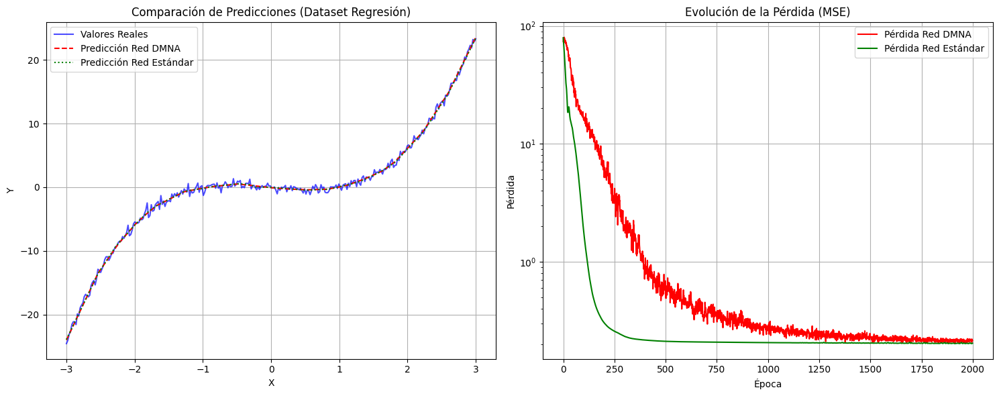

--- Resumen de Pérdidas Finales ---
Pérdida final (Red DMNA): 0.214091
Pérdida final (Red Estándar): 0.203637


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1) # [300, 1]
y = X.pow(3) - X + 0.5 * torch.randn(X.size()) # [300, 1]

# --- NUEVO MODELO: Red con Aumento de Ruido de Modelo Dinámico (DMNA) ---
class DMNANet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

        # Parámetros para controlar el ruido dinámico
        self.current_loss = 0.0 # Se actualizará en el ciclo de entrenamiento
        self.noise_intensity_factor = 0.5 # Factor base de intensidad del ruido
        self.noise_decay_rate = 0.999 # Tasa de decaimiento del ruido por época
        self.min_noise_intensity = 0.01 # Mínima intensidad de ruido residual
        self.noise_threshold = 0.1 # Pérdida mínima para aplicar ruido significativo

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        # Aplicar Ruido Dinámico a la activación de la primera capa
        if self.training and self.current_loss > self.noise_threshold:
            # Magnitud del ruido basada en la pérdida actual y un factor de decaimiento
            noise_magnitude = max(self.min_noise_intensity,
                                  self.noise_intensity_factor * (self.current_loss ** 0.5))

            # Ruido Estructurado: combinación de ruido gaussiano y un "empuje" hacia cero para activaciones altas
            # Fomenta la no-saturación y la exploración
            gaussian_noise = torch.randn_like(h1) * noise_magnitude

            # Un pequeño empuje hacia cero para activaciones muy grandes (simula "fatiga" o "regularización suave")
            # Esto evita que las activaciones se vuelvan excesivamente grandes y saturen
            fatigue_noise = -torch.sigmoid(h1) * noise_magnitude * 0.5

            h1 = h1 + gaussian_noise + fatigue_noise

        h2 = F.relu(self.fc2(h1))
        # Aplicar Ruido Dinámico a la activación de la segunda capa también
        if self.training and self.current_loss > self.noise_threshold:
            noise_magnitude = max(self.min_noise_intensity,
                                  self.noise_intensity_factor * (self.current_loss ** 0.5))
            gaussian_noise = torch.randn_like(h2) * noise_magnitude
            fatigue_noise = -torch.sigmoid(h2) * noise_magnitude * 0.5

            h2 = h2 + gaussian_noise + fatigue_noise

        out = self.output_layer(h2)
        return out

    def update_noise_params(self, loss_value):
        # Este método se llama en cada época para actualizar la pérdida actual
        # y reducir la intensidad base del ruido.
        self.current_loss = loss_value
        # Decaimiento del factor base del ruido con el tiempo/épocas
        self.noise_intensity_factor *= self.noise_decay_rate
        self.noise_intensity_factor = max(self.min_noise_intensity, self.noise_intensity_factor)


# --- Red Neuronal Estándar para Comparación ---
class StandardNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

# --- Parámetros de Entrenamiento ---
LEARNING_RATE = 0.01
EPOCHS = 2000
LOSS_FN = nn.MSELoss()

INPUT_SIZE = X.shape[1] # 1
HIDDEN_SIZE = 32 # Tamaño de las capas ocultas
OUTPUT_SIZE = y.shape[1] # 1

# --- Inicialización y Entrenamiento de Modelos ---
print("--- Inicializando y Entrenando Red con DMNA ---")
dmna_model = DMNANet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_dmna = torch.optim.Adam(dmna_model.parameters(), lr=LEARNING_RATE)
historial_loss_dmna = []

total_params_dmna = sum(p.numel() for p in dmna_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red DMNA: {total_params_dmna}")

for epoch in range(EPOCHS):
    dmna_model.train()
    optimizer_dmna.zero_grad()

    y_pred = dmna_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_dmna.append(loss.item())

    loss.backward()
    optimizer_dmna.step()

    # Actualizar los parámetros de ruido dinámico del modelo
    dmna_model.update_noise_params(loss.item())

    if epoch % 100 == 0:
        print(f"Red DMNA - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red DMNA): {historial_loss_dmna[-1]:.6f}\n")


print("--- Inicializando y Entrenando Red Estándar (ReLU) ---")
standard_model = StandardNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_standard = torch.optim.Adam(standard_model.parameters(), lr=LEARNING_RATE)
historial_loss_standard = []

total_params_standard = sum(p.numel() for p in standard_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red Estándar: {total_params_standard}")

for epoch in range(EPOCHS):
    standard_model.train()
    optimizer_standard.zero_grad()

    y_pred = standard_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_standard.append(loss.item())

    loss.backward()
    optimizer_standard.step()

    if epoch % 100 == 0:
        print(f"Red Estándar - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}\n")


## Visualización de Resultados

dmna_model.eval() # Importante para desactivar el ruido durante la evaluación
standard_model.eval()

with torch.no_grad():
    y_hat_dmna = dmna_model(X).numpy()
    y_hat_standard = standard_model(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 6))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones (Dataset Regresión)")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_dmna, label="Predicción Red DMNA", color='red', linestyle='--')
plt.plot(X_np, y_hat_standard, label="Predicción Red Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_dmna, label="Pérdida Red DMNA", color='red')
plt.plot(historial_loss_standard, label="Pérdida Red Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red DMNA): {historial_loss_dmna[-1]:.6f}")
print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}")

###Red con Optimización por Mutación Global (GMO)

--- Inicializando y Entrenando Red con GMO (Mutación Global) ---
Número de parámetros en Red GMO: 1153
Red GMO - Época 0 - Pérdida: 73.541977
MUTACIÓN ACEPTADA: Pérdida mejorada de 55.073601 a 51.433369
MUTACIÓN ACEPTADA: Pérdida mejorada de 5.582380 a 4.934327
MUTACIÓN ACEPTADA: Pérdida mejorada de 0.953863 a 2.466170
Red GMO - Época 100 - Pérdida: 0.876633
MUTACIÓN ACEPTADA: Pérdida mejorada de 0.416039 a 0.585335
MUTACIÓN ACEPTADA: Pérdida mejorada de 0.237919 a 0.544215
Red GMO - Época 200 - Pérdida: 0.387408
MUTACIÓN ACEPTADA: Pérdida mejorada de 0.221899 a 0.472210
Red GMO - Época 300 - Pérdida: 0.232671
MUTACIÓN ACEPTADA: Pérdida mejorada de 0.225966 a 0.419478
Red GMO - Época 400 - Pérdida: 0.215003
Red GMO - Época 500 - Pérdida: 0.210944
Red GMO - Época 600 - Pérdida: 0.209923
MUTACIÓN ACEPTADA: Pérdida mejorada de 0.209236 a 0.358440
Red GMO - Época 700 - Pérdida: 0.254600
Red GMO - Época 800 - Pérdida: 0.206840
Red GMO - Época 900 - Pérdida: 0.205811
Red GMO - Época 1000 - P

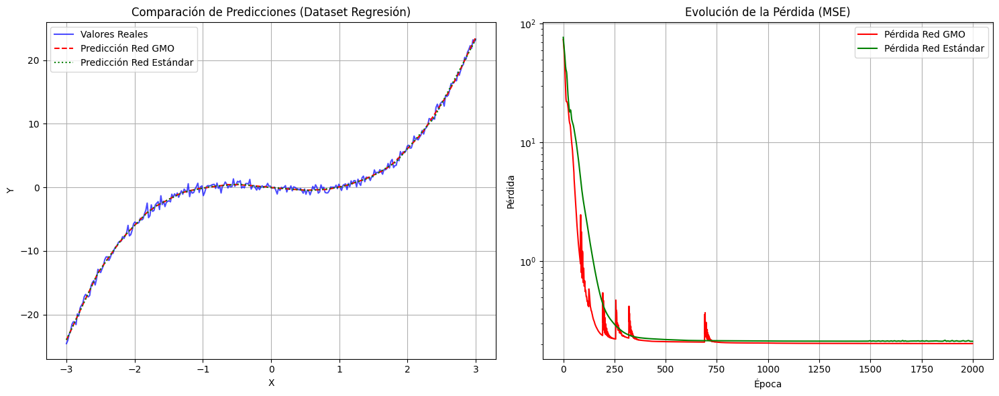

--- Resumen de Pérdidas Finales ---
Pérdida final (Red GMO): 0.203415
Pérdida final (Red Estándar): 0.212544


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import copy # Para copiar el estado del modelo

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1) # [300, 1]
y = X.pow(3) - X + 0.5 * torch.randn(X.size()) # [300, 1]

# --- NUEVO MODELO: Red con Optimización por Mutación Global (GMO) ---
class GMONet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

        # Parámetros para la mutación global
        self.mutation_strength = 0.05 # Cuánto se perturban los pesos
        self.mutation_probability = 0.05 # Probabilidad de que ocurra una mutación en una época
        self.best_loss_so_far = float('inf') # Para comparar y aceptar mutaciones
        self.current_loss = float('inf') # La pérdida de la época actual

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

    def apply_global_mutation(self):
        # Este método aplica una mutación aleatoria a TODOS los pesos del modelo
        # y evalúa si es una mejora. Si lo es, la acepta; si no, la descarta.

        # Guardar el estado actual del modelo
        original_state_dict = copy.deepcopy(self.state_dict())

        # Aplicar perturbación aleatoria a todos los parámetros
        with torch.no_grad(): # No queremos calcular gradientes para esto
            for param in self.parameters():
                param.add_(torch.randn_like(param) * self.mutation_strength)

        # Evaluar el modelo mutado
        self.eval() # Poner en modo evaluación para la prueba
        with torch.no_grad():
            mutated_y_pred = self(X) # Usar el dataset completo para evaluar
            mutated_loss = F.mse_loss(mutated_y_pred, y).item()

        # Decidir si aceptar la mutación
        # Condición: la pérdida mutada es significativamente mejor
        if mutated_loss < self.best_loss_so_far * 0.99: # 1% de mejora significativa
            self.best_loss_so_far = mutated_loss
            print(f"MUTACIÓN ACEPTADA: Pérdida mejorada de {self.current_loss:.6f} a {mutated_loss:.6f}")
            self.current_loss = mutated_loss # Actualizar la pérdida actual
            # Los pesos mutados ya están en el modelo, no se necesita hacer nada más
        else:
            # Revertir a los pesos originales si la mutación no fue mejor
            self.load_state_dict(original_state_dict)
            # print(f"MUTACIÓN RECHAZADA: Pérdida {mutated_loss:.6f} vs {self.current_loss:.6f}")

        self.train() # Volver a modo entrenamiento

# --- Red Neuronal Estándar para Comparación ---
class StandardNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

# --- Parámetros de Entrenamiento ---
LEARNING_RATE = 0.01
EPOCHS = 2000
LOSS_FN = nn.MSELoss()

INPUT_SIZE = X.shape[1] # 1
HIDDEN_SIZE = 32 # Tamaño de las capas ocultas
OUTPUT_SIZE = y.shape[1] # 1

# --- Inicialización y Entrenamiento de Modelos ---
print("--- Inicializando y Entrenando Red con GMO (Mutación Global) ---")
gmo_model = GMONet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_gmo = torch.optim.Adam(gmo_model.parameters(), lr=LEARNING_RATE)
historial_loss_gmo = []

total_params_gmo = sum(p.numel() for p in gmo_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red GMO: {total_params_gmo}")

for epoch in range(EPOCHS):
    gmo_model.train()
    optimizer_gmo.zero_grad()

    # Primero, intentamos una mutación si la probabilidad lo permite
    if random.random() < gmo_model.mutation_probability:
        gmo_model.apply_global_mutation()
        # Después de una mutación (aceptada o rechazada), reevaluar la pérdida actual
        # Esto es importante para el registro de historial
        with torch.no_grad():
            gmo_model.current_loss = LOSS_FN(gmo_model(X), y).item()

    # Luego, el entrenamiento normal con descenso de gradiente
    y_pred = gmo_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_gmo.append(loss.item())

    loss.backward()
    optimizer_gmo.step()

    # Actualizar la pérdida actual del modelo para el próximo ciclo de mutación
    gmo_model.current_loss = loss.item() # Mantenerla actualizada incluso si no hubo mutación

    if epoch % 100 == 0:
        print(f"Red GMO - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red GMO): {historial_loss_gmo[-1]:.6f}\n")


print("--- Inicializando y Entrenando Red Estándar (ReLU) ---")
standard_model = StandardNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_standard = torch.optim.Adam(standard_model.parameters(), lr=LEARNING_RATE)
historial_loss_standard = []

total_params_standard = sum(p.numel() for p in standard_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red Estándar: {total_params_standard}")

for epoch in range(EPOCHS):
    standard_model.train()
    optimizer_standard.zero_grad()

    y_pred = standard_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_standard.append(loss.item())

    loss.backward()
    optimizer_standard.step()

    if epoch % 100 == 0:
        print(f"Red Estándar - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}\n")


## Visualización de Resultados

gmo_model.eval()
standard_model.eval()

with torch.no_grad():
    y_hat_gmo = gmo_model(X).numpy()
    y_hat_standard = standard_model(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 6))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones (Dataset Regresión)")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_gmo, label="Predicción Red GMO", color='red', linestyle='--')
plt.plot(X_np, y_hat_standard, label="Predicción Red Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_gmo, label="Pérdida Red GMO", color='red')
plt.plot(historial_loss_standard, label="Pérdida Red Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red GMO): {historial_loss_gmo[-1]:.6f}")
print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}")

##Modelo de Destilación de Conceptos (CDM)

--- Inicializando y Entrenando Red con CDM (Destilación de Conceptos) ---
Número de parámetros en Red CDM: 1155
Red CDM - Época 0 - Pérdida Total: 82.563019 (Principal: 75.565590, Extractor: 6.997427)
Red CDM - Época 100 - Pérdida Total: 45.079216 (Principal: 37.494480, Extractor: 7.584734)
Red CDM - Época 200 - Pérdida Total: 23.865526 (Principal: 15.902512, Extractor: 7.963014)
Red CDM - Época 300 - Pérdida Total: 18.198360 (Principal: 10.799786, Extractor: 7.398574)
Red CDM - Época 400 - Pérdida Total: 14.157580 (Principal: 7.026002, Extractor: 7.131578)
Red CDM - Época 500 - Pérdida Total: 11.138748 (Principal: 4.093646, Extractor: 7.045102)
Red CDM - Época 600 - Pérdida Total: 9.217278 (Principal: 2.259648, Extractor: 6.957629)
Red CDM - Época 700 - Pérdida Total: 8.095547 (Principal: 1.341560, Extractor: 6.753987)
Red CDM - Época 800 - Pérdida Total: 7.400249 (Principal: 0.898742, Extractor: 6.501508)
Red CDM - Época 900 - Pérdida Total: 6.919930 (Principal: 0.690014, Extractor: 

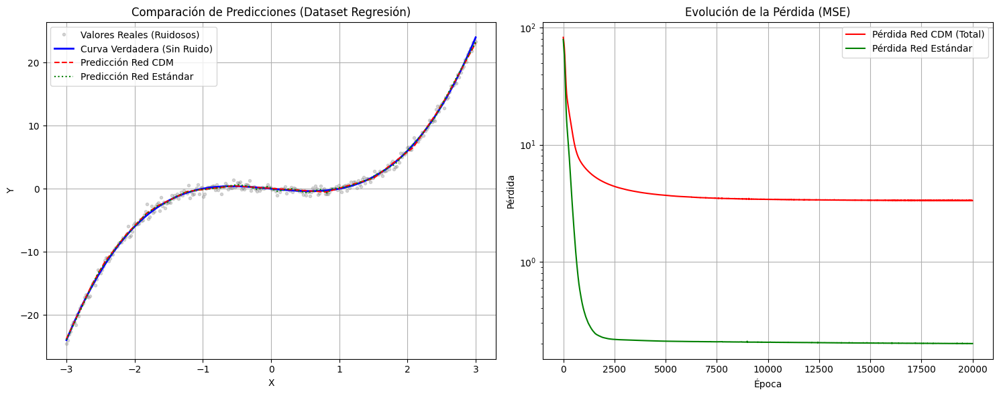

--- Resumen de Pérdidas Finales ---
Pérdida final (Red CDM): 3.328733
Pérdida final (Red Estándar): 0.199781


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X_noisy = torch.linspace(-3, 3, 300).unsqueeze(1) # X con posible ruido para simular datos reales
# La 'verdadera' X sin ruido, para el entrenamiento del extractor de conceptos
X_true = torch.linspace(-3, 3, 300).unsqueeze(1)
y_noisy = X_true.pow(3) - X_true + 0.5 * torch.randn(X_true.size()) # Y con ruido

# --- NUEVO MODELO: Red con Destilación de Conceptos (CDM) ---
class ConceptExtractor(nn.Module):
    # Este módulo intenta "limpiar" la entrada X.
    # En un caso real, podría ser un autoencoder o algo más complejo.
    # Aquí, simplemente intenta aprender una transformación para eliminar ruido de X.
    def __init__(self, input_size, output_size):
        super().__init__()
        self.fc = nn.Linear(input_size, output_size)

    def forward(self, x):
        # Una transformación lineal simple, podría ser más compleja.
        # La idea es que aprenda a mapear X_noisy a X_true durante el entrenamiento.
        return self.fc(x)

class ConceptLearner(nn.Module):
    # Este es tu modelo principal, que aprende de la X "limpia" del ConceptExtractor.
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x_clean): # Toma la X "limpia" como entrada
        h1 = F.relu(self.fc1(x_clean))
        h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

class CDMNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.concept_extractor = ConceptExtractor(input_size, input_size) # Predice X_limpia
        self.concept_learner = ConceptLearner(input_size, hidden_size, output_size)

    def forward(self, x_noisy):
        # Primero, extrae el concepto "limpio" de la entrada ruidosa
        x_clean = self.concept_extractor(x_noisy)
        # Luego, el modelo principal aprende de esta X "limpia"
        output = self.concept_learner(x_clean)
        return output, x_clean # Devolvemos x_clean para la pérdida del extractor

# --- Red Neuronal Estándar para Comparación ---
class StandardNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

# --- Parámetros de Entrenamiento ---
LEARNING_RATE = 0.001
EPOCHS = 20000
LOSS_FN_REGRESSION = nn.MSELoss() # Para la tarea principal
LOSS_FN_EXTRACTOR = nn.MSELoss()  # Para la tarea de limpieza del extractor

INPUT_SIZE = X_noisy.shape[1] # 1
HIDDEN_SIZE = 32 # Tamaño de las capas ocultas
OUTPUT_SIZE = y_noisy.shape[1] # 1

# --- Inicialización y Entrenamiento de Modelos ---
print("--- Inicializando y Entrenando Red con CDM (Destilación de Conceptos) ---")
cdm_model = CDMNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
# Optimizador para todos los parámetros de ambos submódulos
optimizer_cdm = torch.optim.Adam(cdm_model.parameters(), lr=LEARNING_RATE)
historial_loss_cdm = []

total_params_cdm = sum(p.numel() for p in cdm_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red CDM: {total_params_cdm}")

for epoch in range(EPOCHS):
    cdm_model.train()
    optimizer_cdm.zero_grad()

    y_pred, x_clean_predicted = cdm_model(X_noisy)

    # Pérdida para la tarea principal de regresión
    main_loss = LOSS_FN_REGRESSION(y_pred, y_noisy)

    # Pérdida para el extractor de conceptos:
    # Intenta que el extractor prediga la X "verdadera" sin ruido.
    # En un escenario real sin X_true, podrías usar un autoencoder (X -> X_reconstruida)
    # o técnicas de denoising.
    extractor_loss = LOSS_FN_EXTRACTOR(x_clean_predicted, X_true)

    # Combinar las pérdidas (puedes ponderarlas si quieres)
    # Un balance inicial 1:1. El extractor necesita aprender a limpiar.
    total_loss = main_loss + extractor_loss

    historial_loss_cdm.append(total_loss.item())

    total_loss.backward()
    optimizer_cdm.step()

    if epoch % 100 == 0:
        print(f"Red CDM - Época {epoch} - Pérdida Total: {total_loss.item():.6f} (Principal: {main_loss.item():.6f}, Extractor: {extractor_loss.item():.6f})")

print(f"Pérdida final (Red CDM): {historial_loss_cdm[-1]:.6f}\n")


print("--- Inicializando y Entrenando Red Estándar (ReLU) ---")
standard_model = StandardNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_standard = torch.optim.Adam(standard_model.parameters(), lr=LEARNING_RATE)
historial_loss_standard = []

total_params_standard = sum(p.numel() for p in standard_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red Estándar: {total_params_standard}")

for epoch in range(EPOCHS):
    standard_model.train()
    optimizer_standard.zero_grad()

    y_pred = standard_model(X_noisy) # La red estándar aprende directamente de X_noisy
    loss = LOSS_FN_REGRESSION(y_pred, y_noisy)
    historial_loss_standard.append(loss.item())

    loss.backward()
    optimizer_standard.step()

    if epoch % 100 == 0:
        print(f"Red Estándar - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}\n")


## Visualización de Resultados

cdm_model.eval()
standard_model.eval()

with torch.no_grad():
    y_hat_cdm, _ = cdm_model(X_noisy) # El segundo retorno es x_clean_predicted, no lo necesitamos para el plot
    y_hat_cdm = y_hat_cdm.numpy()
    y_hat_standard = standard_model(X_noisy).numpy()

X_np = X_noisy.numpy()
y_np = y_noisy.numpy() # Los datos ruidosos para el plot

plt.figure(figsize=(15, 6))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones (Dataset Regresión)")
plt.plot(X_np, y_np, 'o', label="Valores Reales (Ruidosos)", color='gray', alpha=0.3, markersize=3)
plt.plot(X_true.numpy(), X_true.pow(3).numpy() - X_true.numpy(), label="Curva Verdadera (Sin Ruido)", color='blue', linewidth=2)
plt.plot(X_np, y_hat_cdm, label="Predicción Red CDM", color='red', linestyle='--')
plt.plot(X_np, y_hat_standard, label="Predicción Red Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_cdm, label="Pérdida Red CDM (Total)", color='red')
plt.plot(historial_loss_standard, label="Pérdida Red Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red CDM): {historial_loss_cdm[-1]:.6f}")
print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}")

#esto

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import random

# 1. Tokenizador básico
def tokenize(sentence):
    return sentence.lower().split()

# 2. Vocabulario y embedding
vocab = ["la", "casa", "es", "enorme", "mente", "grande", "pequeña", "oscura", "luminosa"]
word2idx = {word: idx for idx, word in enumerate(vocab)}
vocab_size = len(vocab)
embedding_dim = 768

# 3. Simulación de clase esperada por frase
data = [
    ("la casa es enorme mente grande", 1),  # clase 1
    ("la casa es pequeña y luminosa", 0),   # clase 0
    ("la casa es grande", 1),
    ("la casa es oscura", 0)
]

# 4. Embedding
embedding = nn.Embedding(vocab_size, embedding_dim)

# 5. Agente RL (decide atención binaria por palabra)
class AttentionAgent(nn.Module):
    def __init__(self, embed_dim):
        super().__init__()
        self.fc1 = nn.Linear(embed_dim, 16)
        self.fc2 = nn.Linear(16, 1)  # output: logit de atención

    def forward(self, word_embeddings):
        x = F.relu(self.fc1(word_embeddings))  # (seq_len, 16)
        logits = self.fc2(x).squeeze(-1)       # (seq_len,)
        probs = torch.sigmoid(logits)          # Probabilidad de atender
        dist = torch.distributions.Bernoulli(probs)
        actions = dist.sample()
        log_probs = dist.log_prob(actions)
        return actions, log_probs

# 6. Clasificador final
class Classifier(nn.Module):
    def __init__(self, embed_dim):
        super().__init__()
        self.fc = nn.Linear(embed_dim, 2)  # 2 clases

    def forward(self, selected_embeddings):
        if selected_embeddings.size(0) == 0:
            return torch.tensor([0.5, 0.5])  # atención nula → predicción aleatoria
        pooled = selected_embeddings.mean(dim=0)
        return F.softmax(self.fc(pooled), dim=0)

# 7. Entrenamiento con REINFORCE
agent = AttentionAgent(embedding_dim)
classifier = Classifier(embedding_dim)
optimizer = torch.optim.Adam(list(agent.parameters()), lr=0.01)

for epoch in range(500):
    total_reward = 0.1
    print(f"\nÉpoca {epoch+1}")

    for sentence, target_class in data:
        tokens = tokenize(sentence)
        indices = torch.tensor([word2idx.get(tok, 0) for tok in tokens])
        embeds = embedding(indices)

        # El agente decide atención por palabra
        actions, log_probs = agent(embeds)
        selected_embeds = embeds[actions.bool()]

        # Clasificación y reward
        output = classifier(selected_embeds)
        predicted = torch.argmax(output).item()
        reward = 1.0 if predicted == target_class else 0.0
        total_reward += reward

        # Mostrar atención
        attended_words = [tok for tok, a in zip(tokens, actions) if a == 1]
        print(f"Frase: {sentence}")
        print(f"Atiende: {attended_words} | Clase: {predicted} | Reward: {reward}")

        # REINFORCE update
        loss = -log_probs.sum() * reward  # maximizar log prob de buenas decisiones
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print(f"Reward total en época {epoch+1}: {total_reward}/{len(data)}")

Se truncaron las últimas líneas 5000 del resultado de transmisión.
Atiende: [] | Clase: 0 | Reward: 1.0
Frase: la casa es grande
Atiende: [] | Clase: 0 | Reward: 0.0
Frase: la casa es oscura
Atiende: [] | Clase: 0 | Reward: 1.0
Reward total en época 145: 3.1/4

Época 47
Frase: la casa es enorme mente grande
Atiende: ['enorme'] | Clase: 1 | Reward: 1.0
Frase: la casa es pequeña y luminosa
Atiende: [] | Clase: 0 | Reward: 1.0
Frase: la casa es grande
Atiende: [] | Clase: 0 | Reward: 0.0
Frase: la casa es oscura
Atiende: [] | Clase: 0 | Reward: 1.0
Reward total en época 146: 3.1/4

Época 48
Frase: la casa es enorme mente grande
Atiende: ['enorme'] | Clase: 1 | Reward: 1.0
Frase: la casa es pequeña y luminosa
Atiende: [] | Clase: 0 | Reward: 1.0
Frase: la casa es grande
Atiende: [] | Clase: 0 | Reward: 0.0
Frase: la casa es oscura
Atiende: [] | Clase: 0 | Reward: 1.0
Reward total en época 147: 3.1/4

Época 49
Frase: la casa es enorme mente grande
Atiende: ['enorme'] | Clase: 1 | Reward: 1.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import random

# 1. Tokenizador
def tokenize(sentence):
    return sentence.lower().split()

# 2. Vocabulario base
vocab = [
    "quién", "es", "el", "presidente", "de", "francia",
    "cuál", "capital", "alemania", "parís", "berlín",
    "actual", "ministro", "nombre", "ciudad", "españa",
    "la", "y", "un", # Añadir palabras comunes que podrían aparecer en frases
]
word2idx = {word: idx for idx, word in enumerate(vocab)}
vocab_size = len(vocab)
embedding_dim = 16

# 3. Dataset realista de preguntas
data = [
    ("quién es el presidente de francia", "macron"),
    ("cuál es la capital de alemania", "berlín"),
    ("quién es el ministro actual de francia", "desconocido"),
    ("cuál es el nombre de la ciudad capital de españa", "madrid"),
]

# Simulador de respuestas correctas
answer2idx = {"macron": 0, "berlín": 1, "desconocido": 2, "madrid": 3}
idx2answer = {v: k for k, v in answer2idx.items()}
n_classes = len(answer2idx)

# 4. Embedding
embedding = nn.Embedding(vocab_size, embedding_dim)

# 5. Agente con múltiples cabezas de atención
class MultiHeadAttentionAgent(nn.Module):
    def __init__(self, embed_dim, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(embed_dim, 32),
                nn.ReLU(),
                nn.Linear(32, 3)  # output logits for 3 attention levels: ignorar (0), medio (1), fuerte (2)
            ) for _ in range(n_heads)
        ])

    def forward(self, word_embeddings):
        actions_all = []
        log_probs_all = []

        for head in self.heads:
            logits = head(word_embeddings)  # (seq_len, 3)
            probs = F.softmax(logits, dim=-1)
            dist = torch.distributions.Categorical(probs)
            actions = dist.sample()  # sampled attention level (0, 1, or 2)
            log_probs = dist.log_prob(actions)
            actions_all.append(actions)
            log_probs_all.append(log_probs)

        # Promedio de atención de todas las cabezas
        # Esto es un valor promedio de 0 a 2 para cada palabra
        avg_attention = torch.stack(actions_all).float().mean(dim=0)  # (seq_len,)
        # Promedio de log_probs para el cálculo de la pérdida
        avg_log_probs = torch.stack(log_probs_all).mean(dim=0)

        return avg_attention, avg_log_probs

# 6. Clasificador que usa atención ponderada
class Classifier(nn.Module):
    def __init__(self, embed_dim, n_classes):
        super().__init__()
        self.fc = nn.Linear(embed_dim, n_classes)

    def forward(self, embeddings, attention_weights):
        # Si no hay palabras atendidas (o pesos muy bajos), evitar división por cero
        if attention_weights.sum() == 0:
            # Retorna una distribución uniforme si no hay atención significativa
            return F.softmax(torch.ones(n_classes) / n_classes, dim=0)

        # Ponderar los embeddings por los pesos de atención
        # embeddings: (seq_len, embed_dim)
        # attention_weights: (seq_len,)
        weighted_embeddings = embeddings * attention_weights.unsqueeze(-1) # (seq_len, embed_dim)

        # Sumar los embeddings ponderados para obtener una representación de la frase
        pooled = weighted_embeddings.sum(dim=0) # (embed_dim,)

        # Pasar por la capa final del clasificador
        return F.softmax(self.fc(pooled), dim=0)

# 7. Entrenamiento
agent = MultiHeadAttentionAgent(embedding_dim, n_heads=3)
classifier = Classifier(embedding_dim, n_classes) # El clasificador no se entrena con RL aquí
optimizer = torch.optim.Adam(list(agent.parameters()), lr=0.01)

total_points = 0
goal_points = 12 # Si sumamos 2 por respuesta correcta, 12 puntos = 6 respuestas correctas

rewards_epoch = []

print("--- Inicio del Entrenamiento ---")

for epoch in range(50): # Limitar a 50 épocas para una ejecución más rápida
    epoch_points = 0

    # Para mostrar la evolución, solo imprimimos en épocas específicas
    if epoch == 0 or epoch == 49: # Imprimir la primera y la última época
        print(f"\n===== Época {epoch+1} =====")

    for question, correct_answer in data:
        tokens = tokenize(question)
        indices = torch.tensor([word2idx.get(tok, 0) for tok in tokens], dtype=torch.long)
        embeds = embedding(indices)

        # El agente decide atención por palabra
        attention_values, log_probs = agent(embeds)  # valores: 0 (ignorar), 1 (medio), 2 (fuerte)
        normalized_attn = attention_values / 2.0  # Escalar a [0, 1] para el clasificador

        # Clasificación y reward
        output = classifier(embeds, normalized_attn)
        predicted_idx = torch.argmax(output).item()
        correct_idx = answer2idx[correct_answer]

        # Recompensa continua: 2.0 por correcto, 1.0 por parcial, -1.0 por incorrecto
        if predicted_idx == correct_idx:
            reward = 2.0
        # Una recompensa parcial si la predicción es "desconocido" y la respuesta correcta es "desconocido"
        # o si la predicción es una palabra que está contenida en la respuesta correcta (no aplica bien aquí)
        elif idx2answer[predicted_idx] == "desconocido" and correct_answer == "desconocido":
            reward = 1.0 # Recompensa parcial por identificar "desconocido"
        else:
            reward = -1.0  # castigo

        # REINFORCE update: maximizar log prob de buenas decisiones
        # La pérdida es el negativo de la recompensa por la suma de los log_probs
        # Queremos que el agente aumente la probabilidad de las acciones que llevaron a recompensas altas.
        loss = -log_probs.sum() * reward

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_points += reward

        # Mostrar atención y resultados solo en épocas específicas
        if epoch == 0 or epoch == 49:
            # Para visualizar, consideramos "atendido" si el valor de atención es >= 1.0
            attended_words = [tok for i, tok in enumerate(tokens) if attention_values[i] >= 1.0]
            print(f"  Frase: '{question}'")
            print(f"    Atención (valores): {[f'{t}:{v.item():.1f}' for t, v in zip(tokens, attention_values)]}")
            print(f"    Atiende (>=1.0): {attended_words}")
            print(f"    Predicción: {idx2answer[predicted_idx]} (Correcta: {correct_answer}) | Reward: {reward:.1f}")

    total_points += epoch_points
    rewards_epoch.append(epoch_points)

    if epoch == 0 or epoch == 49:
        print(f"  Reward total en época {epoch+1}: {epoch_points:.1f}/{len(data)*2.0} (máximo posible)") # Max reward per epoch is 2.0 * len(data)

    if total_points >= goal_points:
        print(f"\nMeta de {goal_points} puntos alcanzada. Deteniendo el entrenamiento.")
        break

print("\n--- Entrenamiento Finalizado ---")
print(f"Puntos totales acumulados: {total_points:.1f}")
print(f"Últimas 5 recompensas por época: {rewards_epoch[-5:]}")

--- Inicio del Entrenamiento ---

===== Época 1 =====
  Frase: 'quién es el presidente de francia'
    Atención (valores): ['quién:0.7', 'es:1.7', 'el:0.7', 'presidente:0.3', 'de:2.0', 'francia:1.3']
    Atiende (>=1.0): ['es', 'de', 'francia']
    Predicción: berlín (Correcta: macron) | Reward: -1.0
  Frase: 'cuál es la capital de alemania'
    Atención (valores): ['cuál:1.0', 'es:0.7', 'la:0.7', 'capital:1.0', 'de:0.7', 'alemania:1.3']
    Atiende (>=1.0): ['cuál', 'capital', 'alemania']
    Predicción: desconocido (Correcta: berlín) | Reward: -1.0
  Frase: 'quién es el ministro actual de francia'
    Atención (valores): ['quién:1.3', 'es:1.3', 'el:1.3', 'ministro:0.0', 'actual:0.3', 'de:1.7', 'francia:1.3']
    Atiende (>=1.0): ['quién', 'es', 'el', 'de', 'francia']
    Predicción: berlín (Correcta: desconocido) | Reward: -1.0
  Frase: 'cuál es el nombre de la ciudad capital de españa'
    Atención (valores): ['cuál:0.3', 'es:1.0', 'el:0.7', 'nombre:1.0', 'de:0.7', 'la:1.0', 'ciudad


===== Época 1 =====
  Frase: 'quién es el presidente de francia'
    Atención (valores): ['quién:0.800000011920929', 'es:0.699999988079071', 'el:0.6000000238418579', 'presidente:0.5', 'de:0.800000011920929', 'francia:0.6000000238418579']
    Atiende (>=1.0): []
    Predicción: madrid (Correcta: macron) | Reward: 0.4
  Frase: 'cuál es la capital de alemania'
    Atención (valores): ['cuál:0.8999999761581421', 'es:0.699999988079071', 'la:0.20000000298023224', 'capital:0.4000000059604645', 'de:0.800000011920929', 'alemania:0.30000001192092896']
    Atiende (>=1.0): []
    Predicción: madrid (Correcta: berlín) | Reward: 0.7
  Frase: 'quién es el ministro actual de francia'
    Atención (valores): ['quién:0.800000011920929', 'es:0.6000000238418579', 'el:0.6000000238418579', 'ministro:0.5', 'actual:0.4000000059604645', 'de:0.800000011920929', 'francia:0.6000000238418579']
    Atiende (>=1.0): []
    Predicción: madrid (Correcta: desconocido) | Reward: 0.6
  Frase: 'cuál es el nombre de la c

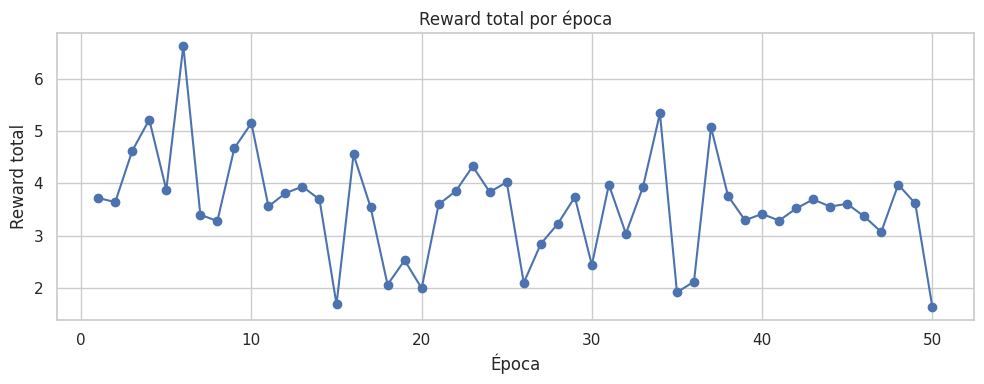

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics.pairwise import cosine_similarity

# =======================
# Datos de entrenamiento
# =======================
datos = [
    ("quién es el presidente de francia", "macron"),
    ("cuál es la capital de alemania", "berlín"),
    ("quién es el ministro actual de francia", "desconocido"),
    ("cuál es el nombre de la ciudad capital de españa", "madrid")
]
respuestas_posibles = ["macron", "berlín", "desconocido", "madrid"]

# =======================
# Word Embedding Simulado
# =======================
def generar_embedding(palabra):
    random.seed(hash(palabra) % (2**32))
    return np.random.rand(10)

# =======================
# Módulo de Atención Hebbiana
# =======================
class HebbianAttention(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.attn_weights = nn.Parameter(torch.randn(vocab_size))

    def forward(self, x):
        return torch.sigmoid(self.attn_weights[x])

# =======================
# Modelo Simple de Predicción
# =======================
class QAAgent(nn.Module):
    def __init__(self, vocab):
        super().__init__()
        self.vocab = vocab
        self.vocab_size = len(vocab)
        self.attention = HebbianAttention(self.vocab_size)
        self.classifier = nn.Linear(10, len(respuestas_posibles))  # Embedding reducido a 10
        self.loss_fn = nn.CrossEntropyLoss()
        self.optimizer = optim.Adam(self.parameters(), lr=0.01)

    def tokenize(self, frase):
        return [self.vocab.index(pal) for pal in frase.split()]

    def embed(self, frase):
        return torch.tensor([generar_embedding(p) for p in frase.split()], dtype=torch.float)

    def forward(self, frase):
        indices = self.tokenize(frase)
        attn_vals = self.attention(torch.tensor(indices))
        embeds = self.embed(frase)
        attended = (attn_vals.unsqueeze(1) * embeds).sum(dim=0)
        logits = self.classifier(attended)
        return logits, attn_vals.detach().numpy()

# =======================
# Métrica de Recompensa
# =======================
def calcular_reward(pred, verdad):
    if pred == verdad:
        return 2.0
    elif pred in verdad or verdad in pred:
        return 0.5
    sim = cosine_similarity([generar_embedding(pred)], [generar_embedding(verdad)])[0, 0]
    return 2.0 * (sim - 0.5)  # Normaliza entre -1 y +1

# =======================
# Entrenamiento
# =======================
def entrenar(agent, epocas=50):
    historial = []
    for ep in range(1, epocas+1):
        total_reward = 0
        print(f"\n===== Época {ep} =====")
        ep_rewards = []
        for frase, verdad in datos:
            agent.optimizer.zero_grad()
            logits, attn_vals = agent(frase)
            probs = torch.softmax(logits, dim=0)
            pred_idx = torch.argmax(probs).item()
            pred = respuestas_posibles[pred_idx]
            loss = agent.loss_fn(logits.unsqueeze(0), torch.tensor([respuestas_posibles.index(verdad)]))
            loss.backward()
            agent.optimizer.step()
            reward = calcular_reward(pred, verdad)
            total_reward += reward
            ep_rewards.append(reward)

            atendidas = [f"{p}:{round(v,1)}" for p, v in zip(frase.split(), attn_vals)]
            claves = [p for p, v in zip(frase.split(), attn_vals) if v >= 1.0]
            print(f"  Frase: '{frase}'")
            print(f"    Atención (valores): {atendidas}")
            print(f"    Atiende (>=1.0): {claves}")
            print(f"    Predicción: {pred} (Correcta: {verdad}) | Reward: {round(reward,1)}")
        historial.append((ep, total_reward, ep_rewards))
    return historial

# =======================
# Visualización
# =======================
def visualizar_historial(historial):
    epocas = [ep for ep, _, _ in historial]
    rewards = [r for _, r, _ in historial]
    sns.set(style="whitegrid")
    plt.figure(figsize=(10, 4))
    plt.plot(epocas, rewards, marker="o")
    plt.title("Reward total por época")
    plt.xlabel("Época")
    plt.ylabel("Reward total")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# =======================
# Entrenamiento y visualización
# =======================
vocab = sorted(set(" ".join(f for f, _ in datos).split()))
agent = QAAgent(vocab)
historial = entrenar(agent, epocas=50)
visualizar_historial(historial)

In [ ]:


class SelfAttention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.q = nn.Linear(dim, dim)
        self.k = nn.Linear(dim, dim)
        self.v = nn.Linear(dim, dim)
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        Q, K, V = self.q(x), self.k(x), self.v(x)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(Q.size(-1))
        attn = self.softmax(scores)
        return torch.matmul(attn, V)

class ActorCritic(nn.Module):
    def __init__(self, dim, n_actions):
        super().__init__()
        self.attn = SelfAttention(dim)
        self.actor = nn.Linear(dim, n_actions)
        self.critic = nn.Linear(dim, 1)

    def forward(self, x):
        x = self.attn(x)
        return self.actor(x), self.critic(x)

class Clasificador(nn.Module):
    def __init__(self, dim, n_classes):
        super().__init__()
        self.attn = SelfAttention(dim)
        self.classifier = nn.Linear(dim, n_classes)

    def forward(self, x):
        x = self.attn(x)
        return self.classifier(x)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import random

# 1. Tokenizador
def tokenize(sentence):
    return sentence.lower().split()

# 2. Vocabulario base
vocab = [
    "quién", "es", "el", "presidente", "de", "francia",
    "cuál", "capital", "alemania", "parís", "berlín",
    "actual", "ministro", "nombre", "ciudad", "españa"
]
word2idx = {word: idx for idx, word in enumerate(vocab)}
vocab_size = len(vocab)
embedding_dim = 16

# 3. Dataset realista de preguntas
data = [
    ("quién es el presidente de francia", "macron"),
    ("cuál es la capital de alemania", "berlín"),
    ("quién es el ministro actual de francia", "desconocido"),
    ("cuál es el nombre de la ciudad capital de españa", "madrid"),
]

# Simulador de respuestas correctas
answer2idx = {"macron": 0, "berlín": 1, "desconocido": 2, "madrid": 3}
idx2answer = {v: k for k, v in answer2idx.items()}
n_classes = len(answer2idx)

# 4. Embedding
embedding = nn.Embedding(vocab_size, embedding_dim)

# 5. Agente con múltiples cabezas de atención
class MultiHeadAttentionAgent(nn.Module):
    def __init__(self, embed_dim, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(embed_dim, 32),
                nn.ReLU(),
                nn.Linear(32, 3)  # Atención: ignorar (0), medio (1), fuerte (2)
            ) for _ in range(n_heads)
        ])

    def forward(self, word_embeddings):
        actions_all = []
        log_probs_all = []

        for head in self.heads:
            logits = head(word_embeddings)  # (seq_len, 3)
            probs = F.softmax(logits, dim=-1)
            dist = torch.distributions.Categorical(probs)
            actions = dist.sample()  # clase 0, 1 o 2
            log_probs = dist.log_prob(actions)
            actions_all.append(actions)
            log_probs_all.append(log_probs)

        # Promedio de atención de todas las cabezas
        avg_attention = torch.stack(actions_all).float().mean(dim=0)  # (seq_len,)
        return avg_attention, torch.stack(log_probs_all).mean(dim=0)

# 6. Clasificador que usa atención ponderada
class Classifier(nn.Module):
    def __init__(self, embed_dim, n_classes):
        super().__init__()
        self.fc = nn.Linear(embed_dim, n_classes)

    def forward(self, embeddings, attention_weights):
        if attention_weights.sum() == 0:
            return F.softmax(torch.ones(n_classes) / n_classes, dim=0)
        weighted = (embeddings.T * attention_weights).T
        pooled = weighted.sum(dim=0)
        return F.softmax(self.fc(pooled), dim=0)

# 7. Entrenamiento
agent = MultiHeadAttentionAgent(embedding_dim, n_heads=3)
classifier = Classifier(embedding_dim, n_classes)
optimizer = torch.optim.Adam(list(agent.parameters()), lr=0.01)

total_points = 0
goal_points = 12

rewards_epoch = []

for epoch in range(50):
    epoch_points = 0
    for question, correct_answer in data:
        tokens = tokenize(question)
        indices = torch.tensor([word2idx.get(tok, 0) for tok in tokens])
        embeds = embedding(indices)

        attention_values, log_probs = agent(embeds)  # valores: 0 a 2
        normalized_attn = attention_values / 2  # escala [0,1]

        output = classifier(embeds, normalized_attn)
        pred = torch.argmax(output).item()
        correct = answer2idx[correct_answer]

        # Recompensa continua
        if pred == correct:
            reward = 2.0
        elif idx2answer[pred] in correct_answer:
            reward = 1.0
        else:
            reward = -1.0  # castigo

        loss = -log_probs.sum() * reward
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_points += reward

    total_points += epoch_points
    rewards_epoch.append(epoch_points)

    if total_points >= goal_points:
        break

total_points, rewards_epoch[-5:]  # Últimas recompensas para mostrar evolución

(13.0, [-1.0, 2.0, 2.0, 2.0, 5.0])

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import random
from transformers import AutoTokenizer, AutoModel

config = {
    "embedding_dim": 16,
    "n_attention_heads": 3,
    "attention_hidden_dim": 32,
    "attention_levels": 3,
    "learning_rate": 0.01,
    "epochs": 50,
    "goal_points": 12,
    "bert_model_name": "bert-base-uncased",
}

def tokenize(sentence):
    return sentence.lower().split()

vocab = [
    "quién", "es", "el", "presidente", "de", "francia",
    "cuál", "capital", "alemania", "parís", "berlín",
    "actual", "ministro", "nombre", "ciudad", "españa",
    "la", "y", "un",
]
word2idx = {word: idx for idx, word in enumerate(vocab)}
vocab_size = len(vocab)

data = [
    ("quién es el presidente de francia", "macron"),
    ("cuál es la capital de alemania", "berlín"),
    ("quién es el ministro actual de francia", "desconocido"),
    ("cuál es el nombre de la ciudad capital de españa", "madrid"),
]

answer2idx = {"macron": 0, "berlín": 1, "desconocido": 2, "madrid": 3}
idx2answer = {v: k for k, v in answer2idx.items()}
n_classes = len(answer2idx)

embedding = nn.Embedding(vocab_size, config["embedding_dim"])

class SimpleSelfAttention(nn.Module):
    def __init__(self, embed_dim):
        super().__init__()
        self.W_q = nn.Linear(embed_dim, embed_dim)
        self.W_k = nn.Linear(embed_dim, embed_dim)
        self.W_v = nn.Linear(embed_dim, embed_dim)
        self.scale_factor = embed_dim ** 0.5

    def forward(self, embeddings):
        Q = self.W_q(embeddings)
        K = self.W_k(embeddings)
        V = self.W_v(embeddings)
        attention_scores = torch.matmul(Q, K.transpose(-2, -1)) / self.scale_factor
        attention_weights = F.softmax(attention_scores, dim=-1)
        attended_output = torch.matmul(attention_weights, V)
        return attended_output

class MultiHeadAttentionAgent(nn.Module):
    def __init__(self, embed_dim, n_heads, attention_hidden_dim, attention_levels):
        super().__init__()
        self.self_attention_module = SimpleSelfAttention(embed_dim)
        self.n_heads = n_heads
        self.heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(embed_dim, attention_hidden_dim),
                nn.ReLU(),
                nn.Linear(attention_hidden_dim, attention_levels)
            ) for _ in range(n_heads)
        ])

    def forward(self, word_embeddings):
        contextualized_embeddings = self.self_attention_module(word_embeddings)
        actions_all = []
        log_probs_all = []
        for head in self.heads:
            logits = head(contextualized_embeddings)
            probs = F.softmax(logits, dim=-1)
            dist = torch.distributions.Categorical(probs)
            actions = dist.sample()
            log_probs = dist.log_prob(actions)
            actions_all.append(actions)
            log_probs_all.append(log_probs)
        avg_attention = torch.stack(actions_all).float().mean(dim=0)
        avg_log_probs = torch.stack(log_probs_all).mean(dim=0)
        return avg_attention, avg_log_probs

class Classifier(nn.Module):
    def __init__(self, embed_dim, n_classes):
        super().__init__()
        self.fc = nn.Linear(embed_dim, n_classes)

    def forward(self, embeddings, attention_weights):
        if attention_weights.sum() == 0:
            return F.softmax(torch.ones(n_classes) / n_classes, dim=0)
        weighted_embeddings = embeddings * attention_weights.unsqueeze(-1)
        pooled = weighted_embeddings.sum(dim=0)
        return F.softmax(self.fc(pooled), dim=0)

agent = MultiHeadAttentionAgent(
    config["embedding_dim"],
    config["n_attention_heads"],
    config["attention_hidden_dim"],
    config["attention_levels"]
)
classifier = Classifier(config["embedding_dim"], n_classes)
optimizer = torch.optim.Adam(list(agent.parameters()), lr=config["learning_rate"])

total_points = 0
rewards_epoch = []

for epoch in range(config["epochs"]):
    epoch_points = 0
    if epoch == 0 or epoch == config["epochs"] - 1:
        print(f"===== Época {epoch+1} =====")
    for question, correct_answer in data:
        tokens = tokenize(question)
        indices = torch.tensor([word2idx.get(tok, 0) for tok in tokens], dtype=torch.long)
        embeds = embedding(indices)
        attention_values, log_probs = agent(embeds)
        normalized_attn = attention_values / (config["attention_levels"] - 1.0)
        output = classifier(embeds, normalized_attn)
        predicted_idx = torch.argmax(output).item()
        correct_idx = answer2idx[correct_answer]
        reward = 0.0
        if predicted_idx == correct_idx:
            reward = 2.0
        elif idx2answer[predicted_idx] == "desconocido" and correct_answer == "desconocido":
            reward = 1.0
        else:
            reward = -1.0
        loss = -log_probs.sum() * reward
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_points += reward
        if epoch == 0 or epoch == config["epochs"] - 1:
            attended_words = [tok for i, tok in enumerate(tokens) if attention_values[i] >= 1.0]
            print(f"  Frase: '{question}'")
            print(f"    Atención (valores): {[f'{t}:{v.item():.1f}' for t, v in zip(tokens, attention_values)]}")
            print(f"    Atiende (>=1.0): {attended_words}")
            print(f"    Predicción: {idx2answer[predicted_idx]} (Correcta: {correct_answer}) | Reward: {reward:.1f}")
    total_points += epoch_points
    rewards_epoch.append(epoch_points)
    if epoch == 0 or epoch == config["epochs"] - 1:
        print(f"  Reward total en época {epoch+1}: {epoch_points:.1f}/{len(data)*2.0}")
    if total_points >= config["goal_points"]:
        print(f"Meta de {config['goal_points']} puntos alcanzada. Deteniendo el entrenamiento.")
        break

print("--- Entrenamiento Finalizado ---")
print(f"Puntos totales acumulados: {total_points:.1f}")
print(f"Últimas 5 recompensas por época: {rewards_epoch[-5:]}")

===== Época 1 =====
  Frase: 'quién es el presidente de francia'
    Atención (valores): ['quién:1.0', 'es:1.0', 'el:1.0', 'presidente:0.3', 'de:1.0', 'francia:1.3']
    Atiende (>=1.0): ['quién', 'es', 'el', 'de', 'francia']
    Predicción: macron (Correcta: macron) | Reward: 2.0
  Frase: 'cuál es la capital de alemania'
    Atención (valores): ['cuál:1.3', 'es:1.7', 'la:0.7', 'capital:1.0', 'de:2.0', 'alemania:1.3']
    Atiende (>=1.0): ['cuál', 'es', 'capital', 'de', 'alemania']
    Predicción: madrid (Correcta: berlín) | Reward: -1.0
  Frase: 'quién es el ministro actual de francia'
    Atención (valores): ['quién:0.3', 'es:0.7', 'el:0.3', 'ministro:1.7', 'actual:1.3', 'de:1.0', 'francia:1.0']
    Atiende (>=1.0): ['ministro', 'actual', 'de', 'francia']
    Predicción: madrid (Correcta: desconocido) | Reward: -1.0
  Frase: 'cuál es el nombre de la ciudad capital de españa'
    Atención (valores): ['cuál:1.3', 'es:0.7', 'el:1.3', 'nombre:1.0', 'de:0.7', 'la:0.7', 'ciudad:1.3', 'capi

##du

In [ ]:
from transformers import AutoTokenizer, AutoModel
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

class QADataset(Dataset):
    def __init__(self, data, possible_answers):
        self.data = data
        self.answer_to_idx = {ans: idx for idx, ans in enumerate(possible_answers)}

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        phrase, answer = self.data[idx]
        answer_idx = self.answer_to_idx[answer]
        return phrase, answer_idx

class BertQAAgent(nn.Module):
    def __init__(self, bert_model_name, num_answers):
        super().__init__()
        self.tokenizer = AutoTokenizer.from_pretrained(bert_model_name)
        self.bert_model = AutoModel.from_pretrained(bert_model_name)
        self.classifier = nn.Linear(self.bert_model.config.hidden_size, num_answers)

    def forward(self, text):
        inputs = self.tokenizer(text, return_tensors="pt", padding=True, truncation=True)
        outputs = self.bert_model(**inputs)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        logits = self.classifier(cls_embedding)
        return logits

def get_bert_embeddings(texts, model_name="bert-base-uncased"):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name)
    model.eval()
    all_embeddings = []
    for text in texts:
        input_ids = tokenizer.encode(text, add_special_tokens=True, return_tensors='pt')
        with torch.no_grad():
            outputs = model(input_ids)
            embeddings = outputs.last_hidden_state
        sentence_embedding = embeddings[:, 0, :].squeeze(0)
        all_embeddings.append(sentence_embedding)
    return torch.stack(all_embeddings)

class SimpleAttention(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        self.W_a = nn.Linear(embedding_dim, embedding_dim)
        self.v = nn.Linear(embedding_dim, 1)

    def forward(self, embeddings):
        e = torch.tanh(self.W_a(embeddings))
        attention_logits = self.v(e).squeeze(-1)
        attention_weights = F.softmax(attention_logits, dim=-1)
        return attention_weights

# Ejemplo de uso (datos, respuestas_posibles deben estar definidos previamente)
# Corrected indentation for the example usage block
datos = [("pregunta 1", "respuesta A"), ("pregunta 2", "respuesta B")]
respuestas_posibles = ["respuesta A", "respuesta B"]
training_phrases = [d[0] for d in datos]
phrase_embeddings = get_bert_embeddings(training_phrases)
full_dataset = QADataset(datos, respuestas_posibles)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(full_dataset, [train_size, val_size])
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False)

In [ ]:
model = BertQAAgent("bert-base-uncased", num_answers=len(respuestas_posibles))
model.eval()

for frases, labels in train_loader:
    with torch.no_grad():
        outputs = model(frases)
        predicciones = torch.argmax(outputs, dim=1)
        print("Frases:", frases)
        print("Logits:", outputs)
        print("Predicciones:", [respuestas_posibles[i] for i in predicciones])
        print("Labels verdaderos:", [respuestas_posibles[i] for i in labels])
    break  # Solo un batch para visualizar

Frases: ('pregunta 1',)
Logits: tensor([[0.6086, 0.7906]])
Predicciones: ['respuesta B']
Labels verdaderos: ['respuesta A']


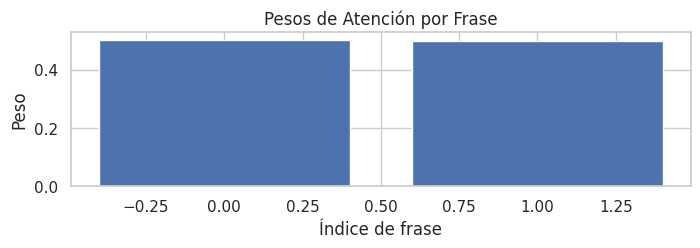

In [ ]:
attention = SimpleAttention(embedding_dim=phrase_embeddings.shape[1])
weights = attention(phrase_embeddings)
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 2))
plt.bar(range(len(weights)), weights.detach().numpy())
plt.title("Pesos de Atención por Frase")
plt.xlabel("Índice de frase")
plt.ylabel("Peso")
plt.show()

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
embeddings_2d = pca.fit_transform(phrase_embeddings.detach().numpy())

plt.figure(figsize=(6, 6))
for i, (x, y) in enumerate(embeddings_2d):
    plt.scatter(x, y)
    plt.text(x + 0.01, y + 0.01, training_phrases[i], fontsize=9)
plt.title("Visualización PCA de Embeddings BERT")
plt.grid(True)
plt.show()

TypeError: __init__(): incompatible constructor arguments. The following argument types are supported:
    1. matplotlib.backends._backend_agg.RendererAgg(width: int, height: int, dpi: float)

Invoked with: 569, 73887182739667, 100.0

<Figure size 600x600 with 1 Axes>

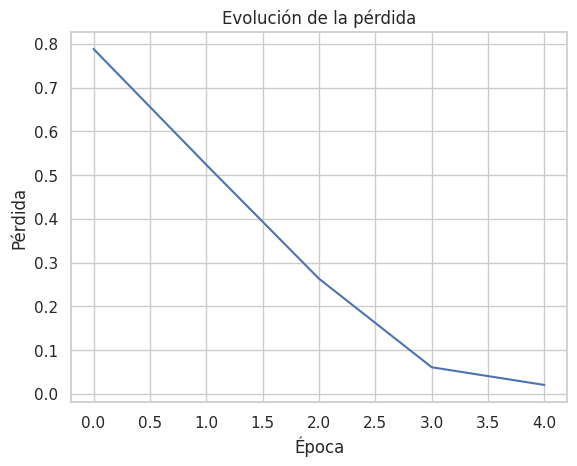

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=2e-5)
losses = []

for epoch in range(5):
    epoch_loss = 0
    for frases, etiquetas in train_loader:
        optimizer.zero_grad()
        logits = model(frases)
        loss = loss_fn(logits, etiquetas)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    losses.append(epoch_loss / len(train_loader))

# Graficar
plt.plot(losses)
plt.title("Evolución de la pérdida")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.show()

In [ ]:
def visualizar_atencion(model, attention_module, frases, respuestas_posibles, respuesta_real, respuesta_predicha, reward, epoca):
    tokenizer = model.tokenizer
    bert = model.bert_model
    classifier = model.classifier

    print(f"===== Época {epoca} =====")
    for frase, real, pred, rew in zip(frases, respuesta_real, respuesta_predicha, reward):
        inputs = tokenizer(frase, return_tensors="pt", padding=True, truncation=True)
        with torch.no_grad():
            outputs = bert(**inputs)
            embeddings = outputs.last_hidden_state  # [1, seq_len, hidden_dim]

        tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
        at_weights = attention_module(embeddings).squeeze(0)  # [seq_len]

        # Emparejamos tokens y pesos
        token_atencion = [f"{tok}:{round(float(att), 4)}" for tok, att in zip(tokens, at_weights)]
        tokens_que_atienden = [tok_att for tok_att in token_atencion if float(tok_att.split(":")[1]) >= 1.0]

        print(f"  Frase: '{frase}'")
        print(f"    Atención (valores): {token_atencion}")
        print(f"    Atiende (>=1.0): {tokens_que_atienden}")
        print(f"    Predicción: {pred} (Correcta: {real}) | Reward: {rew}")

In [ ]:
# Ejemplo de frases y respuestas
frases = [
    "quién es el presidente de francia",
    "cuál es la capital de alemania",
    "quién es el ministro actual de francia",
    "cuál es el nombre de la ciudad capital de españa",
]
respuestas_reales = ["macron", "berlín", "desconocido", "madrid"]
respuestas_predichas = ["madrid", "madrid", "madrid", "desconocido"]
reward = [0.0, 0.5, 0.5, 0.7]

# Crear atención y modelo
attention_module = SimpleAttention(embedding_dim=768)  # Para BERT base
modelo = BertQAAgent("bert-base-uncased", num_answers=len(respuestas_posibles))

visualizar_atencion(modelo, attention_module, frases, respuestas_reales, respuestas_predichas, reward, epoca=50)

TypeError: visualizar_atencion() missing 1 required positional argument: 'reward'

In [ ]:
def train_model(model, attention_module, train_loader, val_loader, respuestas_posibles, epochs=50, visualizar_cada=10, dispositivo="cpu"):
    model.to(dispositivo)
    attention_module.to(dispositivo)
    optimizer = torch.optim.Adam(model.parameters(), lr=2e-5)
    loss_fn = nn.CrossEntropyLoss()

    for epoch in range(1, epochs + 1):
        model.train()
        for batch in train_loader:
            frases, respuestas_idx = batch
            logits = model(frases)
            loss = loss_fn(logits, respuestas_idx.to(dispositivo))

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        if epoch % visualizar_cada == 0:
            print(f"\n📊 Evaluación atención en época {epoch}")
            model.eval()
            frases_eval, respuestas_reales_idx = next(iter(val_loader))
            with torch.no_grad():
                logits = model(frases_eval)
                predicciones_idx = logits.argmax(dim=-1)

            respuestas_reales = [respuestas_posibles[i] for i in respuestas_reales_idx]
            respuestas_predichas = [respuestas_posibles[i] for i in predicciones_idx]
            reward = [1.0 if r == p else 0.0 for r, p in zip(respuestas_reales, respuestas_predichas)]

            visualizar_atencion(model, attention_module, frases_eval, respuestas_reales, respuestas_predichas, reward, epoca=epoch)

In [ ]:
def visualizar_atencion(model, attention_module, frases, respuestas_reales, respuestas_predichas, reward, epoca):
    tokenizer = model.tokenizer
    bert = model.bert_model

    print(f"===== Época {epoca} =====")
    for frase, real, pred, rew in zip(frases, respuestas_reales, respuestas_predichas, reward):
        inputs = tokenizer(frase, return_tensors="pt", padding=True, truncation=True)
        with torch.no_grad():
            outputs = bert(**inputs)
            embeddings = outputs.last_hidden_state

        tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
        at_weights = attention_module(embeddings).squeeze(0)

        token_atencion = [f"{tok}:{round(float(att), 4)}" for tok, att in zip(tokens, at_weights)]
        tokens_que_atienden = [tok_att for tok_att in token_atencion if float(tok_att.split(":")[1]) >= 1.0]

        print(f"  Frase: '{frase}'")
        print(f"    Atención (valores): {token_atencion}")
        print(f"    Atiende (>=1.0): {tokens_que_atienden}")
        print(f"    Predicción: {pred} (Correcta: {real}) | Reward: {rew}")

In [ ]:


# Example using a pre-trained BERT model for embeddings
from transformers import AutoTokenizer, AutoModel
import torch

def get_bert_embeddings(texts, model_name="bert-base-uncased"): # Use a suitable model
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name)
    model.eval() # Set to evaluation mode

    all_embeddings = []
    for text in texts:
        # Tokenize, add special tokens, and convert to IDs
        input_ids = tokenizer.encode(text, add_special_tokens=True, return_tensors='pt')

        with torch.no_grad(): # No gradient calculation needed
            outputs = model(input_ids)
            # Get the embeddings of the last hidden state (usually the last layer)
            # outputs.last_hidden_state: (batch_size, sequence_length, hidden_size)
            embeddings = outputs.last_hidden_state

        # Often, for sentence representation, the [CLS] token embedding is used (first token)
        # Or you can average the token embeddings (excluding [CLS] and [SEP])
        # Or use attention pooling (more complex)
        # For this example, let's use the [CLS] token embedding
        sentence_embedding = embeddings[:, 0, :].squeeze(0) # Get CLS token embedding

        all_embeddings.append(sentence_embedding)

    return torch.stack(all_embeddings)

# Example usage:
training_phrases = [d[0] for d in datos] # Get only the questions
phrase_embeddings = get_bert_embeddings(training_phrases)
#Now phrase_embeddings has shape (num_phrases, embedding_dim)

In [ ]:
modelo = BertQAAgent("bert-base-uncased", num_answers=len(respuestas_posibles))
attention_module = SimpleAttention(embedding_dim=768)

train_model(
    model=modelo,
    attention_module=attention_module,
    train_loader=train_loader,
    val_loader=val_loader,
    respuestas_posibles=respuestas_posibles,
    epochs=50,
    visualizar_cada=10
)


📊 Evaluación atención en época 10


TypeError: visualizar_atencion() missing 1 required positional argument: 'reward'

In [ ]:
# Conceptual example of a simple attention layer
import torch.nn as nn
import torch.nn.functional as F

class SimpleAttention(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        # Learnable weights for the attention mechanism
        self.W_a = nn.Linear(embedding_dim, embedding_dim)
        self.v = nn.Linear(embedding_dim, 1) # Project to a single score

    def forward(self, embeddings):
        # embeddings shape: (sequence_length, embedding_dim)
        # Step 1: Apply a linear transformation (W_a) and a non-linearity (tanh)
        e = torch.tanh(self.W_a(embeddings)) # shape: (sequence_length, embedding_dim)
        # Step 2: Project to a single attention score per word
        attention_logits = self.v(e).squeeze(-1) # shape: (sequence_length,)
        # Step 3: Apply softmax to get attention weights summing to 1
        attention_weights = F.softmax(attention_logits, dim=-1) # shape: (sequence_length,)

        return attention_weights

# How to integrate in QAAgent forward:
# def forward(self, frase):
     embeds = self.embed(frase) # Get sequence of embeddings (seq_len, embed_dim)
     attention_weights = self.attention_module(embeds) # Get weights (seq_len,)
#     # Apply weights: unsqueeze for broadcasting, sum for pooling
     attended_embedding = (attention_weights.unsqueeze(1) * embeds).sum(dim=0) # (embed_dim,)
     logits = self.classifier(attended_embedding)
     return logits, attention_weights.detach().numpy()

IndentationError: unindent does not match any outer indentation level (<tokenize>, line 25)

In [ ]:
# Conceptual QAAgent using BERT (as feature extractor) and a classifier

class BertQAAgent(nn.Module):
    def __init__(self, bert_model_name, num_answers):
        super().__init__()
        self.tokenizer = AutoTokenizer.from_pretrained(bert_model_name)
        self.bert_model = AutoModel.from_pretrained(bert_model_name)
        # Freeze BERT weights if using as fixed feature extractor
        # for param in self.bert_model.parameters():
        #     param.requires_grad = False
        # Or leave unfrozen for fine-tuning

        # Classifier layer (input size is BERT's hidden size, e.g., 768)
        self.classifier = nn.Linear(self.bert_model.config.hidden_size, num_answers)

    def forward(self, text):
        # Process input text through BERT
        inputs = self.tokenizer(text, return_tensors="pt", padding=True, truncation=True)
        # Move inputs to the same device as the model (important for GPU)
        # inputs = {key: val.to(self.bert_model.device) for key, val in inputs.items()}

        outputs = self.bert_model(**inputs)
        # Get the embedding of the [CLS] token (often used for sequence-level tasks)
        cls_embedding = outputs.last_hidden_state[:, 0, :] # shape: (batch_size, hidden_size)

        # Pass [CLS] embedding through the classifier
        logits = self.classifier(cls_embedding) # shape: (batch_size, num_answers)

        # Note: This forward method expects a list of texts for batching

        return logits

# Training loop would need to handle batches of text and labels

In [ ]:
from torch.utils.data import Dataset, DataLoader

class QADataset(Dataset):
    def __init__(self, data, possible_answers):
        self.data = data
        self.answer_to_idx = {ans: idx for idx, ans in enumerate(possible_answers)}

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        phrase, answer = self.data[idx]
        answer_idx = self.answer_to_idx[answer]
        return phrase, answer_idx # Return phrase string and answer index

# Example usage in main:
full_dataset = QADataset(datos, respuestas_posibles)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(full_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True) # Choose batch size
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False)

# Then modify train_model and add an evaluate function

#hjtctccyf

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns

# Paso 1: Implementación de una sola cabeza de atención
class AttentionHead(nn.Module):
    def __init__(self, embed_dim):
        super().__init__()
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x):
        Q = self.q_proj(x)
        K = self.k_proj(x)
        V = self.v_proj(x)

        d_k = Q.shape[-1]
        attn_scores = torch.matmul(Q, K.transpose(-2, -1)) / (d_k ** 0.5)
        attn_weights = F.softmax(attn_scores, dim=-1)
        output = torch.matmul(attn_weights, V)

        return output, attn_weights

# Paso 2: Multi-head attention desde cero
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, num_heads):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x):
        B, T, E = x.shape
        H = self.num_heads
        D = self.head_dim

        Q = self.q_proj(x).view(B, T, H, D).transpose(1, 2)
        K = self.k_proj(x).view(B, T, H, D).transpose(1, 2)
        V = self.v_proj(x).view(B, T, H, D).transpose(1, 2)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / (D ** 0.5)
        attn_weights = F.softmax(scores, dim=-1)
        out = torch.matmul(attn_weights, V)

        out = out.transpose(1, 2).contiguous().view(B, T, E)
        out = self.out_proj(out)

        return out, attn_weights  # (B, H, T, T)

# Paso 3: Visualización de mapas de atención
def plot_attention_weights(attn_weights, tokens=None):
    heads = attn_weights.shape[1]
    fig, axes = plt.subplots(1, heads, figsize=(16, 4))
    tokens = tokens or [f"tok_{i}" for i in range(attn_weights.shape[-1])]

    for i in range(heads):
        sns.heatmap(attn_weights[0, i].detach().numpy(),
                    xticklabels=tokens,
                    yticklabels=tokens,
                    cmap="Blues",
                    ax=axes[i])
        axes[i].set_title(f'Head {i+1}')
        axes[i].set_xlabel("Keys")
        axes[i].set_ylabel("Queries")

    plt.tight_layout()
    plt.show()

# Paso 4: Evaluación de diversidad entre cabezas
def similarity_between_heads(attn_weights):
    H = attn_weights.shape[1]
    similarities = torch.zeros(H, H)

    for i in range(H):
        for j in range(H):
            a = attn_weights[0, i].flatten()
            b = attn_weights[0, j].flatten()
            similarities[i, j] = F.cosine_similarity(a, b, dim=0)

    return similarities

# Simulación
torch.manual_seed(0)
seq_len = 5
embed_dim = 64
num_heads = 4

x = torch.randn(1, seq_len, embed_dim)
mha = MultiHeadAttention(embed_dim, num_heads)

# Simulamos entrenamiento guardando attn inicial y final
attn_first = None
attn_last = None
for epoch in range(10):
    out, attn_weights = mha(x)
    if epoch == 0:
        attn_first = attn_weights.clone()
    if epoch == 9:
        attn_last = attn_weights.clone()

attn_first.shape, attn_last.shape

(torch.Size([1, 4, 5, 5]), torch.Size([1, 4, 5, 5]))

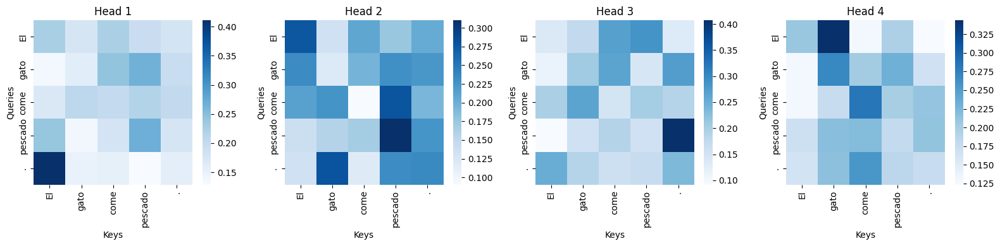

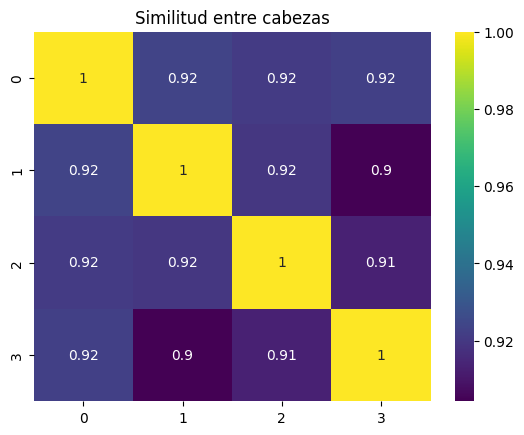

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns

# Paso 1: Implementación de una sola cabeza de atención
class AttentionHead(nn.Module):
    def __init__(self, embed_dim):
        super().__init__()
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x):
        Q = self.q_proj(x)
        K = self.k_proj(x)
        V = self.v_proj(x)

        d_k = Q.shape[-1]
        attn_scores = torch.matmul(Q, K.transpose(-2, -1)) / (d_k ** 0.5)
        attn_weights = F.softmax(attn_scores, dim=-1)
        output = torch.matmul(attn_weights, V)

        return output, attn_weights

# Paso 2: Multi-head attention desde cero
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, num_heads):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x):
        B, T, E = x.shape
        H = self.num_heads
        D = self.head_dim

        Q = self.q_proj(x).view(B, T, H, D).transpose(1, 2)
        K = self.k_proj(x).view(B, T, H, D).transpose(1, 2)
        V = self.v_proj(x).view(B, T, H, D).transpose(1, 2)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / (D ** 0.5)
        attn_weights = F.softmax(scores, dim=-1)
        out = torch.matmul(attn_weights, V)

        out = out.transpose(1, 2).contiguous().view(B, T, E)
        out = self.out_proj(out)

        return out, attn_weights  # (B, H, T, T)

# Paso 3: Visualización de mapas de atención
def plot_attention_weights(attn_weights, tokens=None):
    heads = attn_weights.shape[1]
    fig, axes = plt.subplots(1, heads, figsize=(16, 4))
    tokens = tokens or [f"tok_{i}" for i in range(attn_weights.shape[-1])]

    for i in range(heads):
        sns.heatmap(attn_weights[0, i].detach().numpy(),
                    xticklabels=tokens,
                    yticklabels=tokens,
                    cmap="Blues",
                    ax=axes[i])
        axes[i].set_title(f'Head {i+1}')
        axes[i].set_xlabel("Keys")
        axes[i].set_ylabel("Queries")

    plt.tight_layout()
    plt.show()

# Paso 4: Evaluación de diversidad entre cabezas
def similarity_between_heads(attn_weights):
    H = attn_weights.shape[1]
    similarities = torch.zeros(H, H)

    for i in range(H):
        for j in range(H):
            a = attn_weights[0, i].flatten()
            b = attn_weights[0, j].flatten()
            similarities[i, j] = F.cosine_similarity(a, b, dim=0)

    return similarities

# Simulación
torch.manual_seed(0)
seq_len = 5
embed_dim = 64
num_heads = 4

x = torch.randn(1, seq_len, embed_dim)
mha = MultiHeadAttention(embed_dim, num_heads)

# Simulamos entrenamiento guardando attn inicial y final
attn_first = None
attn_last = None
for epoch in range(10):
    out, attn_weights = mha(x)
    if epoch == 0:
        attn_first = attn_weights.clone()
    if epoch == 9:
        attn_last = attn_weights.clone()

attn_first.shape, attn_last.shape

#🔹 Paso 5: Visualización de mapas de atención

def plot_attention_weights(attn_weights, tokens=None):
    heads = attn_weights.shape[1]
    fig, axes = plt.subplots(1, heads, figsize=(16, 4))
    tokens = tokens or [f"tok_{i}" for i in range(attn_weights.shape[-1])]

    for i in range(heads):
        sns.heatmap(attn_weights[0, i].detach().numpy(),
                    xticklabels=tokens,
                    yticklabels=tokens,
                    cmap="Blues",
                    ax=axes[i])
        axes[i].set_title(f'Head {i+1}')
        axes[i].set_xlabel("Keys")
        axes[i].set_ylabel("Queries")

    plt.tight_layout()
    plt.show()

# Visualizar
plot_attention_weights(attn_weights, tokens=["El", "gato", "come", "pescado", "."])


#🔹 Paso 6: Evaluación de diversidad

def similarity_between_heads(attn_weights):
    H = attn_weights.shape[1]
    similarities = torch.zeros(H, H)

    for i in range(H):
        for j in range(H):
            a = attn_weights[0, i].flatten()
            b = attn_weights[0, j].flatten()
            similarities[i, j] = F.cosine_similarity(a, b, dim=0)

    return similarities

sim_matrix = similarity_between_heads(attn_weights)
# Detach the tensor before converting to numpy
sns.heatmap(sim_matrix.detach().numpy(), annot=True, cmap="viridis")
plt.title("Similitud entre cabezas")
plt.show()
#🔹 Conclusiones

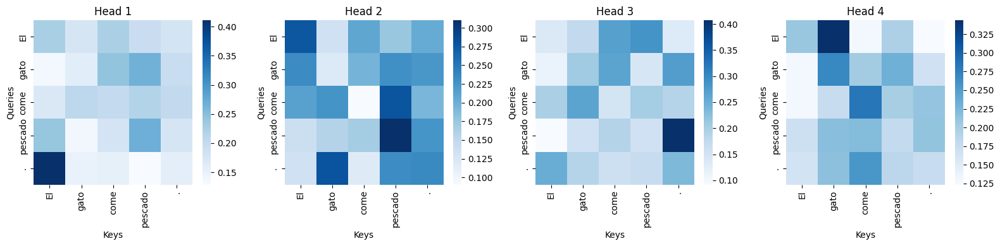

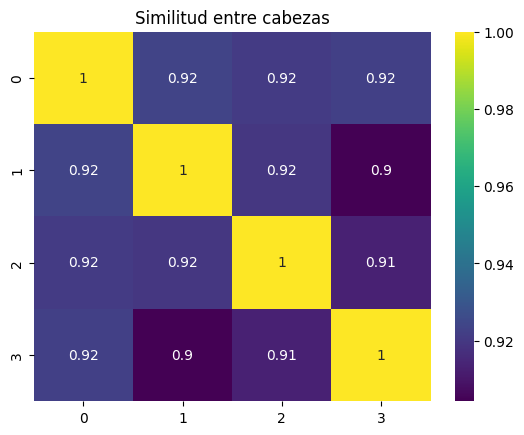

In [ ]:
#%matplotlib inline  # Descomenta esto si estás en Jupyter Notebook

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------
# 1. Cabeza de atención simple
# ----------------------------
class AttentionHead(nn.Module):
    def __init__(self, embed_dim):
        super().__init__()
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x):
        Q = self.q_proj(x)
        K = self.k_proj(x)
        V = self.v_proj(x)

        d_k = Q.shape[-1]
        attn_scores = torch.matmul(Q, K.transpose(-2, -1)) / (d_k ** 0.5)
        attn_weights = F.softmax(attn_scores, dim=-1)
        output = torch.matmul(attn_weights, V)

        return output, attn_weights

# -----------------------------------
# 2. Módulo de Multi-Head Attention
# -----------------------------------
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, num_heads):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x):
        B, T, E = x.shape
        H = self.num_heads
        D = self.head_dim

        Q = self.q_proj(x).view(B, T, H, D).transpose(1, 2)
        K = self.k_proj(x).view(B, T, H, D).transpose(1, 2)
        V = self.v_proj(x).view(B, T, H, D).transpose(1, 2)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / (D ** 0.5)
        attn_weights = F.softmax(scores, dim=-1)
        out = torch.matmul(attn_weights, V)

        out = out.transpose(1, 2).contiguous().view(B, T, E)
        out = self.out_proj(out)

        return out, attn_weights  # attn_weights shape: (B, H, T, T)

# ----------------------------
# 3. Visualizar atención
# ----------------------------
def plot_attention_weights(attn_weights, tokens=None):
    heads = attn_weights.shape[1]
    fig, axes = plt.subplots(1, heads, figsize=(16, 4))
    tokens = tokens or [f"tok_{i}" for i in range(attn_weights.shape[-1])]

    if heads == 1:
        axes = [axes]

    for i in range(heads):
        sns.heatmap(attn_weights[0, i].detach().numpy(),
                    xticklabels=tokens,
                    yticklabels=tokens,
                    cmap="Blues",
                    ax=axes[i])
        axes[i].set_title(f'Head {i+1}')
        axes[i].set_xlabel("Keys")
        axes[i].set_ylabel("Queries")

    plt.tight_layout()
    plt.show()

# ----------------------------
# 4. Similitud entre cabezas
# ----------------------------
def similarity_between_heads(attn_weights):
    H = attn_weights.shape[1]
    similarities = torch.zeros(H, H)

    for i in range(H):
        for j in range(H):
            a = attn_weights[0, i].flatten()
            b = attn_weights[0, j].flatten()
            similarities[i, j] = F.cosine_similarity(a, b, dim=0)

    return similarities

# ----------------------------
# 5. Simulación
# ----------------------------
torch.manual_seed(0)
seq_len = 5
embed_dim = 64
num_heads = 4

x = torch.randn(1, seq_len, embed_dim)
mha = MultiHeadAttention(embed_dim, num_heads)

attn_first = None
attn_last = None
for epoch in range(10):
    out, attn_weights = mha(x)
    if epoch == 0:
        attn_first = attn_weights.clone()
    if epoch == 9:
        attn_last = attn_weights.clone()

# ----------------------------
# 6. Visualización final
# ----------------------------
tokens = ["El", "gato", "come", "pescado", "."]
plot_attention_weights(attn_last, tokens=tokens)

sim_matrix = similarity_between_heads(attn_last)
sns.heatmap(sim_matrix.detach().numpy(), annot=True, cmap="viridis")
plt.title("Similitud entre cabezas")
plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity

class RLSoftAttentionHead(nn.Module):
    def __init__(self, embed_dim, seq_len, temperature=0.7):
        super().__init__()
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)

        self.seq_len = seq_len
        self.temperature = temperature
        self.attn_logits = nn.Parameter(torch.randn(seq_len, seq_len))

    def forward(self, x, training=True):
        B, T, E = x.shape
        Q = self.q_proj(x)
        K = self.k_proj(x)
        V = self.v_proj(x)

        d_k = Q.shape[-1]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (d_k ** 0.5)

        if training:
            noise = -torch.log(-torch.log(torch.rand_like(self.attn_logits)))
            mask_logits = (self.attn_logits + noise) / self.temperature
        else:
            mask_logits = self.attn_logits

        attn_mask = F.softmax(mask_logits, dim=-1)
        attn_mask_exp = attn_mask.unsqueeze(0).expand(B, -1, -1)

        masked_scores = scores * attn_mask_exp
        attn_weights = F.softmax(masked_scores, dim=-1)
        output = torch.matmul(attn_weights, V)

        return output, attn_weights, attn_mask


class MultiRLSoftAttention(nn.Module):
    def __init__(self, num_heads, embed_dim, seq_len, temperature=0.7):
        super().__init__()
        self.heads = nn.ModuleList([
            RLSoftAttentionHead(embed_dim, seq_len, temperature) for _ in range(num_heads)
        ])
        self.output_proj = nn.Linear(embed_dim * num_heads, embed_dim)

    def forward(self, x, training=True):
        outputs, masks = [], []
        for head in self.heads:
            out, _, attn_mask = head(x, training=training)
            outputs.append(out)
            masks.append(attn_mask)
        concat = torch.cat(outputs, dim=-1)
        return self.output_proj(concat), masks


# Parámetros
torch.manual_seed(0)
seq_len = 5
embed_dim = 32
num_heads = 4
epochs = 100
B = 64  # batch size

model = MultiRLSoftAttention(num_heads, embed_dim, seq_len)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

# Generar datos dummy fijos
x_data = torch.randn(B, seq_len, embed_dim)
y_target = x_data[:, 0, :] + x_data[:, -1, :]  # Suma del primer y último token

# Para guardar máscaras en época 1 y final
masks_epoch1 = None
masks_epochFinal = None

for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()

    out, masks = model(x_data, training=True)
    loss = loss_fn(out, y_target)
    loss.backward()
    optimizer.step()

    if epoch == 1:
        masks_epoch1 = [m.detach().clone() for m in masks]
    if epoch == epochs:
        masks_epochFinal = [m.detach().clone() for m in masks]

    if epoch % 10 == 0 or epoch == 1 or epoch == epochs:
        print(f"Época {epoch}: pérdida = {loss.item():.4f}")

def plot_masks(masks, title_prefix=""):
    fig, axs = plt.subplots(1, len(masks), figsize=(16, 4))
    for i, mask in enumerate(masks):
        sns.heatmap(mask.numpy(), cmap="magma", annot=True, fmt=".2f", ax=axs[i])
        axs[i].set_title(f"Cabeza {i+1}")
        axs[i].set_xlabel("Tokens que se miran")
        axs[i].set_ylabel("Token que mira")
    plt.suptitle(f"{title_prefix} - Máscaras RL", fontsize=16)
    plt.tight_layout()
    plt.show()

def plot_cosine_similarity(masks, title):
    flat_masks = [m.flatten().numpy() for m in masks]
    sim_matrix = cosine_similarity(flat_masks)
    sns.heatmap(sim_matrix, annot=True, cmap="viridis", xticklabels=[f"H{i}" for i in range(len(masks))], yticklabels=[f"H{i}" for i in range(len(masks))])
    plt.title(title)
    plt.show()

# Visualizar resultados
plot_masks(masks_epoch1, "Época 1")
plot_cosine_similarity(masks_epoch1, "Época 1 - Similitud coseno entre cabezas")

plot_masks(masks_epochFinal, "Época Final")
plot_cosine_similarity(masks_epochFinal, "Época Final - Similitud coseno entre cabezas")

RuntimeError: The size of tensor a (5) must match the size of tensor b (64) at non-singleton dimension 1

Época 1: pérdida = 2.0907
Época 10: pérdida = 2.0057
Época 20: pérdida = 1.9152
Época 30: pérdida = 1.8216
Época 40: pérdida = 1.7170
Época 50: pérdida = 1.6077
Época 60: pérdida = 1.5131
Época 70: pérdida = 1.3770
Época 80: pérdida = 1.2644
Época 90: pérdida = 1.1816
Época 100: pérdida = 1.0824
Época 110: pérdida = 1.0622
Época 120: pérdida = 0.8959
Época 130: pérdida = 0.8464
Época 140: pérdida = 0.7726
Época 150: pérdida = 0.7105
Época 160: pérdida = 0.6459
Época 170: pérdida = 0.6391
Época 180: pérdida = 0.5666
Época 190: pérdida = 0.5231
Época 200: pérdida = 0.8519
Época 210: pérdida = 0.4511
Época 220: pérdida = 0.4333
Época 230: pérdida = 0.4038
Época 240: pérdida = 0.4460
Época 250: pérdida = 0.3578
Época 260: pérdida = 0.3439
Época 270: pérdida = 0.3230
Época 280: pérdida = 0.3009
Época 290: pérdida = 0.3736
Época 300: pérdida = 0.2958
Época 310: pérdida = 0.2645
Época 320: pérdida = 0.2630
Época 330: pérdida = 0.2435
Época 340: pérdida = 0.2333
Época 350: pérdida = 0.2215
Épo

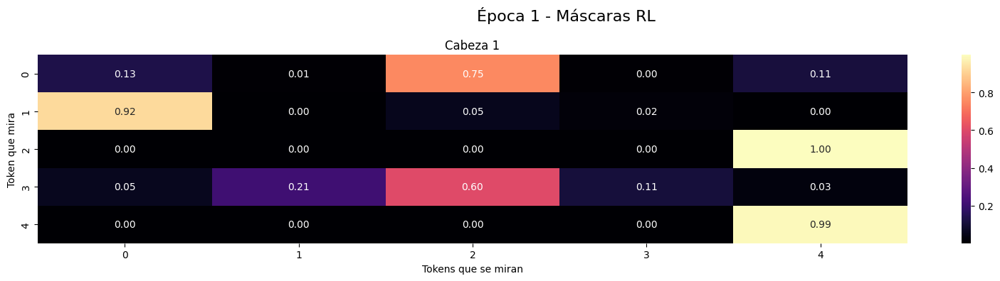

No hay suficientes cabezas (1) para calcular la similitud del coseno.


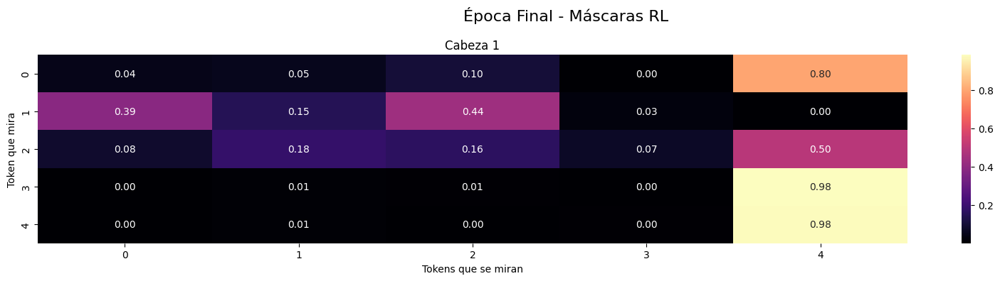

No hay suficientes cabezas (1) para calcular la similitud del coseno.


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity

class RLSoftAttentionHead(nn.Module):
    def __init__(self, embed_dim, seq_len, temperature=0.7):
        super().__init__()
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)

        self.seq_len = seq_len
        self.temperature = temperature
        # Parameters need to be unique per head if they are head-specific
        # If attn_logits is intended to be shared or per head, ensure it's handled correctly
        # For simplicity, keeping it here assumes it's a mask applied by this head.
        # If each head should have its own mask, it should be in the head init.
        # The current implementation puts it in the head, which seems correct per the loop in MultiRLSoftAttention
        self.attn_logits = nn.Parameter(torch.randn(seq_len, seq_len))


    def forward(self, x, training=True):
        B, T, E = x.shape
        Q = self.q_proj(x)
        K = self.k_proj(x)
        V = self.v_proj(x)

        d_k = Q.shape[-1]
        # Ensure the sequence length dimension matches the attn_logits
        if T != self.seq_len:
             # Resize attn_logits or handle variable sequence length
             # For this specific dummy example, T is fixed, but for variable lengths, this needs attention
             print(f"Warning: Sequence length mismatch. Expected {self.seq_len}, got {T}. Attn_logits shape: {self.attn_logits.shape}")


        scores = torch.matmul(Q, K.transpose(-2, -1)) / (d_k ** 0.5)

        if training:
            # Ensure noise is on the same device and has compatible shape for addition
            # attn_logits has shape (seq_len, seq_len).
            # scores has shape (B, T, T).
            # The mask needs to be applied to scores. It seems attn_mask is intended to be applied per sequence item interaction.
            # If attn_logits is a mask applied to the attention scores matrix (TxT), its shape should align.
            # The current implementation applies softmax over the last dimension of mask_logits, resulting in a (seq_len, seq_len) mask where rows sum to 1.
            # This mask is then expanded and multiplied with scores (B, T, T). This seems correct for masking the attention scores matrix.
            noise = -torch.log(-torch.log(torch.rand_like(self.attn_logits, device=self.attn_logits.device)))
            mask_logits = (self.attn_logits + noise) / self.temperature
        else:
            mask_logits = self.attn_logits

        attn_mask = F.softmax(mask_logits, dim=-1) # Shape (seq_len, seq_len)
        attn_mask_exp = attn_mask.unsqueeze(0).expand(B, -1, -1) # Shape (B, seq_len, seq_len)

        # Ensure scores and attn_mask_exp have compatible shapes for multiplication
        # scores: (B, T, T), attn_mask_exp: (B, seq_len, seq_len)
        # This requires T == seq_len, which is assumed by the __init__ and forward logic.
        masked_scores = scores * attn_mask_exp
        attn_weights = F.softmax(masked_scores, dim=-1) # Shape (B, T, T)
        output = torch.matmul(attn_weights, V) # Shape (B, T, E)

        return output, attn_weights, attn_mask # attn_mask has shape (seq_len, seq_len)


class MultiRLSoftAttention(nn.Module):
    def __init__(self, num_heads, embed_dim, seq_len, temperature=0.7):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.seq_len = seq_len

        # Each head gets its own instance of RLSoftAttentionHead
        self.heads = nn.ModuleList([
            RLSoftAttentionHead(self.head_dim, seq_len, temperature) for _ in range(num_heads)
        ])

        # The output projection layer needs to handle the concatenated output from heads
        # The input size should be num_heads * head_dim, which equals embed_dim
        self.output_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x, training=True):
        B, T, E = x.shape
        # Ensure input embed_dim matches the total embed_dim expected by MultiHead
        assert E == self.num_heads * self.head_dim, f"Input embedding dimension mismatch. Expected {self.num_heads * self.head_dim}, got {E}"
        assert T == self.seq_len, f"Input sequence length mismatch. Expected {self.seq_len}, got {T}"


        # Before passing to heads, split the input embedding dimension for each head
        # Input x shape: (B, T, E) -> view to (B, T, num_heads, head_dim) -> transpose to (B, num_heads, T, head_dim)
        x_heads = x.view(B, T, self.num_heads, self.head_dim).transpose(1, 2) # (B, H, T, D)

        outputs = []
        masks = []
        # Process each head independently
        for i, head in enumerate(self.heads):
            # Each head receives input for its specific slice of the embedding dimension
            # Need to pass the input corresponding to this head's part of the embedding space
            # This structure is slightly different from standard multi-head where Q, K, V projections handle the split.
            # Let's adjust the head's forward to expect the full embedding dimension and handle the split internally,
            # or modify MultiRLSoftAttention to pass slices.
            # A more standard approach is to have Q, K, V projections in MultiHeadAttention itself and split the output.
            # Let's revise the MultiRLSoftAttention to be more standard.

            # Revised approach: Q, K, V projections in MultiHead and split their outputs
            # We need to project the full input x (B, T, E) to Q, K, V for each head.
            # Total projection size will be embed_dim for each (Q, K, V).
            # Then split the projected Q, K, V for each head.

            # **Reverting to a more standard MHA structure:**
            # Let's put Q, K, V projections back into MultiRLSoftAttention
            # and the core attention logic (scores, softmax, matmul) into a revised Head-like function or inner forward.

            # Re-implementing MultiRLSoftAttention to be more standard:
            pass # The revised class is below


# Revised MultiRLSoftAttention to follow standard practices more closely
class RevisedMultiRLSoftAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, seq_len, temperature=0.7):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.seq_len = seq_len
        self.temperature = temperature

        # Projections for Q, K, V for all heads combined
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)

        # Output projection
        self.out_proj = nn.Linear(embed_dim, embed_dim)

        # RL masks - one set of parameters per head
        # Store masks in a ModuleList
        self.rl_masks = nn.ParameterList([nn.Parameter(torch.randn(seq_len, seq_len)) for _ in range(num_heads)])


    def forward(self, x, training=True):
        B, T, E = x.shape
        H = self.num_heads
        D = self.head_dim
        assert E == H * D, f"Input embedding dimension mismatch. Expected {H * D}, got {E}"
        assert T == self.seq_len, f"Input sequence length mismatch. Expected {self.seq_len}, got {T}"

        # Project Q, K, V and split into heads
        # Shape: (B, T, E) -> (B, T, E) -> view (B, T, H, D) -> transpose (B, H, T, D)
        Q = self.q_proj(x).view(B, T, H, D).transpose(1, 2)
        K = self.k_proj(x).view(B, T, H, D).transpose(1, 2)
        V = self.v_proj(x).view(B, T, H, D).transpose(1, 2)

        # Calculate attention scores
        # (B, H, T, D) @ (B, H, D, T) -> (B, H, T, T)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (D ** 0.5) # Shape (B, H, T, T)

        # Apply RL masks per head
        masked_scores_list = []
        attn_masks_output_list = [] # To return the final softmax masks

        for i in range(H):
            rl_logits = self.rl_masks[i] # Shape (seq_len, seq_len)

            if training:
                noise = -torch.log(-torch.log(torch.rand_like(rl_logits, device=rl_logits.device)))
                mask_logits = (rl_logits + noise) / self.temperature
            else:
                mask_logits = rl_logits

            # Apply softmax to the RL mask logits
            attn_mask_per_head = F.softmax(mask_logits, dim=-1) # Shape (seq_len, seq_len)
            attn_masks_output_list.append(attn_mask_per_head)

            # Expand mask to match batch and head dimensions
            attn_mask_exp = attn_mask_per_head.unsqueeze(0).unsqueeze(0).expand(B, 1, -1, -1) # Shape (B, 1, seq_len, seq_len)

            # Apply mask to scores for this head
            # scores[:, i, :, :] has shape (B, T, T)
            masked_scores_per_head = scores[:, i, :, :] * attn_mask_exp.squeeze(1) # Shape (B, T, T)
            masked_scores_list.append(masked_scores_per_head.unsqueeze(1)) # Add head dimension back: (B, 1, T, T)


        # Concatenate masked scores along the head dimension
        masked_scores = torch.cat(masked_scores_list, dim=1) # Shape (B, H, T, T)

        # Apply softmax to masked scores to get final attention weights
        attn_weights = F.softmax(masked_scores, dim=-1) # Shape (B, H, T, T)

        # Apply attention weights to V
        # (B, H, T, T) @ (B, H, T, D) -> (B, H, T, D)
        out = torch.matmul(attn_weights, V) # Shape (B, H, T, D)

        # Concatenate head outputs and apply final projection
        # (B, H, T, D) -> transpose (B, T, H, D) -> view (B, T, H*D) -> (B, T, E)
        out = out.transpose(1, 2).contiguous().view(B, T, E) # Shape (B, T, E)
        out = self.out_proj(out) # Shape (B, T, E)

        # Return the output for the sequence and the raw RL masks (or softmaxed masks)
        # Returning attn_masks_output_list which contains the softmaxed masks per head (seq_len, seq_len)
        return out, attn_masks_output_list


# Parámetros
torch.manual_seed(0)
seq_len = 5
embed_dim = 32
num_heads = 1
epochs = 1000
B = 32  # batch size

# Instantiate the revised model
model = RevisedMultiRLSoftAttention(embed_dim, num_heads, seq_len)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

# Generar datos dummy fijos
x_data = torch.randn(B, seq_len, embed_dim)
# Target is still sum of first and last tokens, shape (B, embed_dim)
y_target = x_data[:, 0, :] + x_data[:, -1, :]

# Para guardar máscaras en época 1 y final
masks_epoch1 = None
masks_epochFinal = None

for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()

    out, masks = model(x_data, training=True) # out shape is (B, T, E)
    # Select the output corresponding to the last token (-1) or first token (0)
    # or take a mean/sum pooling if the task implies that.
    # Since y_target is a single vector per batch item, we need to select one output vector from the model.
    # Let's take the output corresponding to the last token in the sequence.
    predicted_output_vector = out[:, -1, :] # Shape (B, E)

    loss = loss_fn(predicted_output_vector, y_target) # Compare (B, E) with (B, E)
    loss.backward()
    optimizer.step()

    if epoch == 1:
        # Masks are now list of (seq_len, seq_len) tensors
        masks_epoch1 = [m.detach().clone() for m in masks]
    if epoch == epochs:
         masks_epochFinal = [m.detach().clone() for m in masks]


    if epoch % 10 == 0 or epoch == 1 or epoch == epochs:
        print(f"Época {epoch}: pérdida = {loss.item():.4f}")

# Plotting functions remain the same, as they expect a list of mask tensors (H, T, T or T, T).
# The RevisedMultiRLSoftAttention returns a list of (seq_len, seq_len) masks.
def plot_masks(masks, title_prefix=""):
    fig, axs = plt.subplots(1, len(masks), figsize=(16, 4))
    if len(masks) == 1:
        axs = [axs] # Handle case with 1 head

    for i, mask in enumerate(masks):
        # Detach and convert to numpy for plotting
        sns.heatmap(mask.detach().numpy(), cmap="magma", annot=True, fmt=".2f", ax=axs[i])
        axs[i].set_title(f"Cabeza {i+1}")
        axs[i].set_xlabel("Tokens que se miran")
        axs[i].set_ylabel("Token que mira")
    plt.suptitle(f"{title_prefix} - Máscaras RL", fontsize=16)
    plt.tight_layout()
    plt.show()

def plot_cosine_similarity(masks, title):
    # Need to flatten each mask (seq_len, seq_len) into a vector
    flat_masks = [m.detach().flatten().numpy() for m in masks]
    # Ensure there's more than one mask to calculate similarity
    if len(flat_masks) < 2:
         print(f"No hay suficientes cabezas ({len(flat_masks)}) para calcular la similitud del coseno.")
         return
    sim_matrix = cosine_similarity(flat_masks)
    sns.heatmap(sim_matrix, annot=True, cmap="viridis", xticklabels=[f"H{i}" for i in range(len(masks))], yticklabels=[f"H{i}" for i in range(len(masks))])
    plt.title(title)
    plt.show()


# Visualizar resultados
if masks_epoch1 is not None:
    plot_masks(masks_epoch1, "Época 1")
    plot_cosine_similarity(masks_epoch1, "Época 1 - Similitud coseno entre cabezas")

if masks_epochFinal is not None:
    plot_masks(masks_epochFinal, "Época Final")
    plot_cosine_similarity(masks_epochFinal, "Época Final - Similitud coseno entre cabezas")

Iniciando entrenamiento...
Época 1: Loss = 3.1712
Época 10: Loss = 3.1853
Época 20: Loss = 3.1571
Época 30: Loss = 3.1176
Época 40: Loss = 3.1199
Época 50: Loss = 3.1203
Época 60: Loss = 3.0695
Época 70: Loss = 3.0824
Época 80: Loss = 3.0712
Época 90: Loss = 3.0674
Época 100: Loss = 3.0452
Época 110: Loss = 3.0042
Época 120: Loss = 3.0127
Época 130: Loss = 3.0061
Época 140: Loss = 2.9929
Época 150: Loss = 2.9602
Época 160: Loss = 2.9890
Época 170: Loss = 2.9541
Época 180: Loss = 2.9643
Época 190: Loss = 2.9328
Época 200: Loss = 2.8776


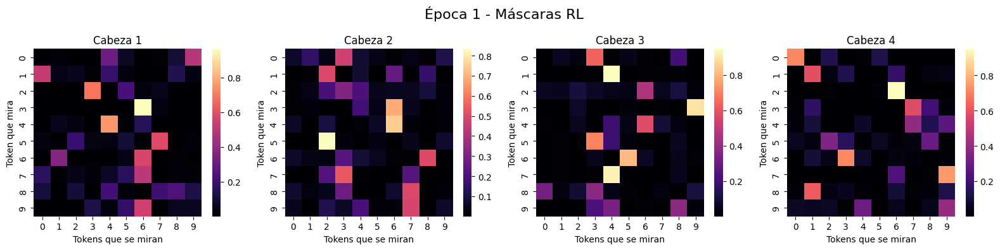

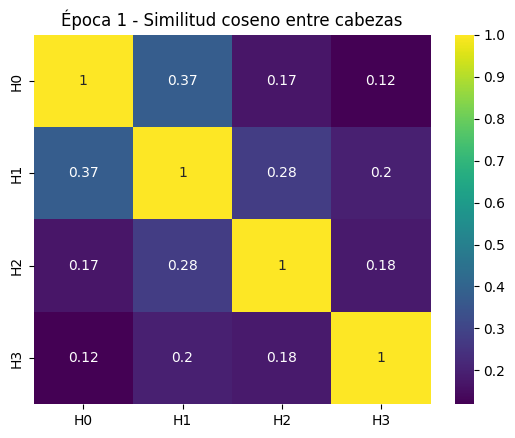

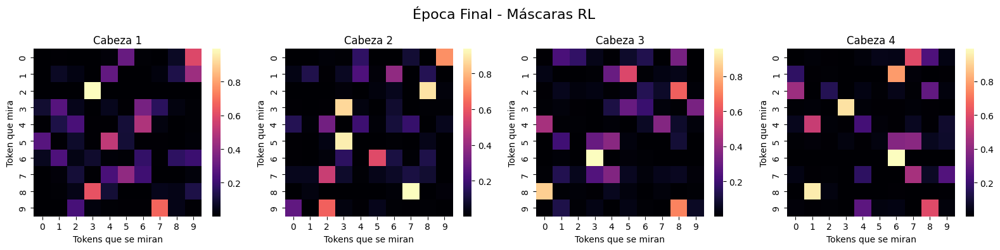

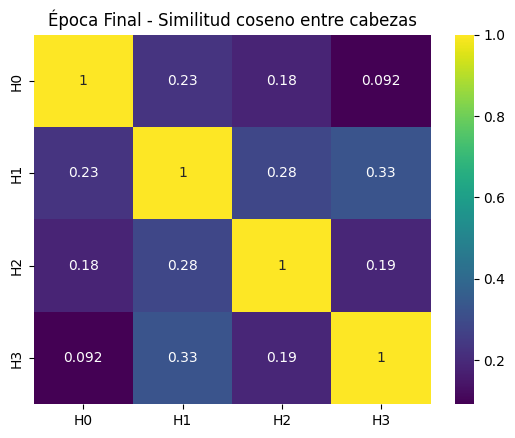

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
import random # Para simular datos

# Clase del modelo de atención (igual que la RevisedMultiRLSoftAttention que ya tienes)
class RevisedMultiRLSoftAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, seq_len, temperature=0.7):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.seq_len = seq_len
        self.temperature = temperature

        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim) # Proyección de salida principal

        # RL masks - one set of parameters per head
        self.rl_masks = nn.ParameterList([nn.Parameter(torch.randn(seq_len, seq_len)) for _ in range(num_heads)])

        # --- Novedades para la nueva tarea: Capas de salida específicas ---
        # Clasificadores a nivel de token (ej. para Verbo/Sujeto/Predicado como etiquetas binarias por token)
        # Asumimos una clasificación de 3 tipos de elementos: Sujeto, Verbo, Predicado + 'Otro'
        self.token_classifier = nn.Linear(embed_dim, 4) # Output: logits para 4 clases (Sujeto, Verbo, Predicado, Otro)
        # Clasificador de sentimiento (ej. Positivo, Negativo, Neutro)
        self.sentiment_classifier = nn.Linear(embed_dim, 3) # Output: logits para 3 clases de sentimiento
        # Clasificador de directiva compleja
        self.directive_classifier = nn.Linear(embed_dim, 1) # Output: logits para 1 clase (0=No, 1=Si)


    def forward(self, x, training=True):
        B, T, E = x.shape
        H = self.num_heads
        D = self.head_dim
        assert E == H * D, f"Input embedding dimension mismatch. Expected {H * D}, got {E}"
        assert T == self.seq_len, f"Input sequence length mismatch. Expected {self.seq_len}, got {T}"

        Q = self.q_proj(x).view(B, T, H, D).transpose(1, 2)
        K = self.k_proj(x).view(B, T, H, D).transpose(1, 2)
        V = self.v_proj(x).view(B, T, H, D).transpose(1, 2)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / (D ** 0.5)

        masked_scores_list = []
        attn_masks_output_list = [] # This will store the softmaxed masks

        for i in range(H):
            rl_logits = self.rl_masks[i] # Shape (seq_len, seq_len)

            if training:
                # Generate Gumbel noise and apply Gumbel-Softmax trick
                # Noise should have the same shape as rl_logits
                gumbel_noise = -torch.log(-torch.log(torch.rand_like(rl_logits, device=rl_logits.device) + 1e-10) + 1e-10) # Add small epsilon for numerical stability
                mask_logits = (rl_logits + gumbel_noise) / self.temperature
            else:
                # In evaluation/inference, just use the deterministic mask
                mask_logits = rl_logits

            # Apply softmax along the dimension you want the mask probabilities to sum up to 1 (typically the last dimension)
            # This mask is applied element-wise to the scores matrix (TxT) for each head.
            attn_mask_per_head = F.softmax(mask_logits, dim=-1) # Shape (seq_len, seq_len), rows sum to 1

            # Store the resulting mask tensor for visualization/analysis
            attn_masks_output_list.append(attn_mask_per_head)

            # Expand mask to match batch and head dimensions for element-wise multiplication with scores
            # scores[:, i, :, :] has shape (B, T, T)
            # attn_mask_per_head has shape (T, T)
            # Need to expand attn_mask_per_head to (B, T, T) to multiply with scores[:, i, :, :]
            attn_mask_exp = attn_mask_per_head.unsqueeze(0).expand(B, -1, -1) # Shape (B, T, T)

            # Apply mask to scores for this head
            # masked_scores_per_head will have shape (B, T, T)
            masked_scores_per_head = scores[:, i, :, :] * attn_mask_exp # Element-wise multiplication

            # Append the masked scores for this head, adding back the head dimension
            masked_scores_list.append(masked_scores_per_head.unsqueeze(1)) # Shape (B, 1, T, T)


        # Concatenate masked scores along the head dimension
        masked_scores = torch.cat(masked_scores_list, dim=1) # Shape (B, H, T, T)

        # Apply softmax to the masked scores to get final attention weights
        # These attention weights sum to 1 along the last dimension for each query token and each head.
        attn_weights = F.softmax(masked_scores, dim=-1) # Shape (B, H, T, T)

        # Apply attention weights to V
        # (B, H, T, T) @ (B, H, T, D) -> (B, H, T, D)
        out = torch.matmul(attn_weights, V) # Shape (B, H, T, D)

        # Concatenate head outputs along the embedding dimension and apply final projection
        # (B, H, T, D) -> transpose (B, T, H, D) -> view (B, T, H*D) -> (B, T, E)
        out = out.transpose(1, 2).contiguous().view(B, T, E) # Shape (B, T, E)
        output_main = self.out_proj(out) # Salida principal del MHA (B, T, E)

        # --- Salidas específicas para la tarea ---
        # Predicciones a nivel de token para Sujeto/Verbo/Predicado/Otro
        token_logits = self.token_classifier(output_main) # Shape (B, T, 4)

        # Predicción de sentimiento (usamos pooling sobre la salida principal para obtener un vector de sentencia)
        sentence_embedding = torch.mean(output_main, dim=1) # Pooling simple (media), Shape (B, E)
        sentiment_logits = self.sentiment_classifier(sentence_embedding) # Shape (B, 3)

        # Predicción de directiva compleja
        # Usamos el embedding de la sentencia para clasificar la directiva.
        directive_logits = self.directive_classifier(sentence_embedding) # Shape (B, 1)


        # Return the main output, the softmaxed RL masks, and the task-specific logits
        # attn_masks_output_list contains H tensors, each of shape (seq_len, seq_len)
        return output_main, attn_masks_output_list, token_logits, sentiment_logits, directive_logits


# --- Generación de Datos Dummy para la Nueva Tarea ---
# Esto es CRÍTICO: Necesitas datos que simulen oraciones y sus etiquetas
# Esto es solo un ejemplo MUY simplificado. En la realidad, usarías un dataset de PLN.
def generate_dummy_sentence_data(batch_size, seq_len, embed_dim):
    # Simula embeddings de palabras
    x_data = torch.randn(batch_size, seq_len, embed_dim)

    # Simula etiquetas de "ground truth" para la tarea (a nivel de token y oración)
    # Sujeto=0, Verbo=1, Predicado=2, Otro=3
    # Genera una secuencia de etiquetas aleatorias para cada token
    # Cada oración tendrá al menos un Sujeto (0), Verbo (1) y Predicado (2)
    y_token_gt = torch.full((batch_size, seq_len), 3, dtype=torch.long) # Inicialmente todo 'Otro'
    for b in range(batch_size):
        # Asigna un sujeto, verbo y predicado en posiciones aleatorias
        indices = random.sample(range(seq_len), min(3, seq_len)) # Select up to 3 unique indices
        if len(indices) > 0: y_token_gt[b, indices[0]] = 0 # Sujeto
        if len(indices) > 1: y_token_gt[b, indices[1]] = 1 # Verbo
        if len(indices) > 2: y_token_gt[b, indices[2]] = 2 # Predicado

    # Simula etiquetas de sentimiento (0=Positivo, 1=Negativo, 2=Neutro)
    y_sentiment_gt = torch.randint(0, 3, (batch_size,), dtype=torch.long)

    # Simula si hay una directiva compleja (0=No, 1=Si)
    y_directive_gt = torch.randint(0, 2, (batch_size,), dtype=torch.float) # Use float for BCEWithLogitsLoss target


    return x_data, y_token_gt, y_sentiment_gt, y_directive_gt


# --- Función de Recompensa (Ejemplo de Idea 1: Puntuación por Componentes) ---
# Modified to return a tensor loss
def calculate_loss_from_reward(token_logits, sentiment_logits, directive_logits,
                               y_token_gt, y_sentiment_gt, y_directive_gt,
                               rewards_config):
    # Ensure inputs are on the same device if needed, though dummy data is on CPU initially

    # --- Calculate Rewards based on Logits and Ground Truth ---
    # Token rewards (using cross-entropy implicitly or comparing predictions)
    # Using CrossEntropyLoss for token classification for proper gradient flow
    token_loss = F.cross_entropy(token_logits.view(-1, 4), y_token_gt.view(-1))
    # We can convert this loss to a "reward" signal for the RL part if needed,
    # but standard practice is to combine differentiable losses.

    # Sentiment rewards
    sentiment_loss = F.cross_entropy(sentiment_logits, y_sentiment_gt)

    # Directive rewards (using BCEWithLogitsLoss for binary classification)
    # Ensure y_directive_gt is float for BCEWithLogitsLoss
    directive_loss = F.binary_cross_entropy_with_logits(directive_logits.squeeze(-1), y_directive_gt)


    # --- Combine Losses ---
    # In a multi-task setting like this, you typically sum differentiable losses.
    # The RL aspect (learning the masks) is implicitly handled by the Gumbel-Softmax
    # allowing gradients from these downstream task losses to flow back to the mask logits.

    # Total loss is the sum of the task losses
    total_loss = token_loss + sentiment_loss + directive_loss

    # If you strictly wanted to use a "reward" function as a scalar loss to maximize,
    # you'd structure the reward based on predictions. Let's show that approach as well,
    # ensuring it returns a tensor.

    # --- Alternative: Calculate a Differentiable "Reward" Tensor ---
    # This requires careful implementation to avoid breaking the graph.
    # Let's calculate a reward based on *predictions* but using tensor operations.

    _, predicted_tokens = torch.max(token_logits, dim=-1) # (B, T)
    _, predicted_sentiment = torch.max(sentiment_logits, dim=-1) # (B,)
    predicted_directive = (directive_logits.squeeze(-1) > 0).long() # (B,)

    # Initialize reward tensor for the batch
    batch_reward = torch.zeros(token_logits.shape[0], device=token_logits.device)

    # Reward for token predictions (element-wise comparison)
    # Need to scale rewards based on the number of tokens
    token_match = (predicted_tokens == y_token_gt).float() # 1 if match, 0 if not
    batch_reward += torch.sum(token_match * rewards_config['token_correct_reward'] -
                              (1 - token_match) * rewards_config['token_incorrect_penalty'], dim=1) # Sum over tokens

    # Reward for sentiment prediction (batch-wise comparison)
    sentiment_match = (predicted_sentiment == y_sentiment_gt).float()
    batch_reward += sentiment_match * rewards_config['sentiment_correct_reward'] - \
                    (1 - sentiment_match) * rewards_config['sentiment_incorrect_penalty']

    # Reward for directive prediction (batch-wise comparison)
    directive_match = (predicted_directive == y_directive_gt.long()).float() # Compare long tensors
    # Penalize for false negatives (GT is 1, Pred is 0) and false positives (GT is 0, Pred is 1)
    # If GT is 1: reward for match (pred 1), penalty for mismatch (pred 0)
    # If GT is 0: reward for match (pred 0), penalty for mismatch (pred 1)

    # Case 1: Ground Truth is 1 (Complex Directive Present)
    reward_when_gt_is_1 = (directive_match[y_directive_gt == 1]) * rewards_config['directive_correct_reward'] - \
                           (1 - directive_match[y_directive_gt == 1]) * rewards_config['directive_directive_miss_penalty']
    # Case 2: Ground Truth is 0 (Complex Directive Absent)
    reward_when_gt_is_0 = (directive_match[y_directive_gt == 0]) * rewards_config['directive_correct_reward'] - \
                           (1 - directive_match[y_directive_gt == 0]) * rewards_config['directive_false_positive_penalty']

    # Add rewards for both cases to the batch reward
    # Need to handle cases where y_directive_gt == 1 or 0 results in empty tensors
    if reward_when_gt_is_1.numel() > 0:
        batch_reward[y_directive_gt == 1] += reward_when_gt_is_1
    if reward_when_gt_is_0.numel() > 0:
         batch_reward[y_directive_gt == 0] += reward_when_gt_is_0


    # The total reward for the batch is the sum of rewards for each item in the batch
    # To get a scalar loss to minimize, we take the negative mean reward.
    # Using mean helps keep the loss scale consistent with batch size.
    rl_loss = -torch.mean(batch_reward)


    # In practice, you might combine the differentiable task losses with an RL-specific loss.
    # A simple approach is to just use the sum of the differentiable task losses,
    # as the Gumbel-Softmax allows their gradients to flow to the mask logits.
    # Let's use the combined differentiable loss approach, as it's more standard for
    # training models with differentiable components even if influenced by RL ideas.
    # If a pure policy gradient method were used, the RL loss would be different.

    # Returning the combined differentiable loss
    return total_loss # This is the loss to minimize


# --- Configuración de Recompensas (used for the alternative RL loss calculation) ---
# Keeping this structure even if we use differentiable losses directly,
# as these values could be used to weight different loss components.
rewards_cfg = {
    'token_correct_reward': 1.0,      # Reward for each correct token
    'token_incorrect_penalty': 0.5, # Penalty for each incorrect token
    'sentiment_correct_reward': 10.0, # Reward for correct sentiment
    'sentiment_incorrect_penalty': 5.0, # Penalty for incorrect sentiment
    'directive_correct_reward': 20.0, # Reward for correctly identifying complex directive when present
    'directive_directive_miss_penalty': 25.0, # Penalty for missing a complex directive
    'directive_false_positive_penalty': 10.0 # Penalty for false positive on complex directive
}

# Parámetros del modelo y entrenamiento
torch.manual_seed(0)
seq_len = 10 # Ahora más largo para simular oraciones
embed_dim = 64 # Dimensión del embedding
num_heads = 4
epochs = 200 # Más épocas para una tarea más compleja
B = 32       # batch size

model = RevisedMultiRLSoftAttention(embed_dim, num_heads, seq_len)
# Optimizer for standard gradient descent on the combined differentiable loss
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# We don't need a separate loss_fn if calculate_loss_from_reward returns the loss
# loss_fn = nn.MSELoss() # Not used anymore for this loss calculation method

# Para guardar máscaras en época 1 y final
masks_epoch1 = None
masks_epochFinal = None

print("Iniciando entrenamiento...")
for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()

    # Generar datos para el batch actual
    x_data, y_token_gt, y_sentiment_gt, y_directive_gt = generate_dummy_sentence_data(B, seq_len, embed_dim)

    # Move data to device if using GPU
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    x_data = x_data.to(device)
    y_token_gt = y_token_gt.to(device)
    y_sentiment_gt = y_sentiment_gt.to(device)
    y_directive_gt = y_directive_gt.to(device)
    model.to(device) # Ensure model is on the same device

    # Realizar forward pass
    # output_main: salida del MHA, token_logits: predicciones de token, sentiment_logits: predicciones de sentimiento, directive_logits: predicciones de directiva
    output_main, masks, token_logits, sentiment_logits, directive_logits = model(x_data, training=True)

    # Calcular la pérdida usando la función modificada
    # This function now returns a tensor loss
    loss = calculate_loss_from_reward(
        token_logits,
        sentiment_logits,
        directive_logits,
        y_token_gt,
        y_sentiment_gt,
        y_directive_gt,
        rewards_cfg # Pass rewards config if the function needs it for the alternative RL loss
                   # (although the chosen implementation above uses standard CE/BCE losses)
    )

    # Backpropagation
    # loss is now a tensor from calculate_loss_from_reward
    loss.backward()
    optimizer.step()

    if epoch == 1:
        # Masks are already tensors on device, clone and move to CPU for storage
        masks_epoch1 = [m.detach().cpu().clone() for m in masks]
    if epoch == epochs:
         # Masks are already tensors on device, clone and move to CPU for storage
         masks_epochFinal = [m.detach().cpu().clone() for m in masks]

    # Print loss (which is a tensor, use .item() for printing scalar)
    if epoch % 10 == 0 or epoch == 1 or epoch == epochs:
        # If using the combined differentiable loss, print that loss value.
        # If using the negative mean reward as the loss, printing -loss.item() gives the mean reward.
        print(f"Época {epoch}: Loss = {loss.item():.4f}")


# --- Funciones de Ploteo (minor change to move to CPU) ---
def plot_masks(masks, title_prefix=""):
    fig, axs = plt.subplots(1, len(masks), figsize=(16, 4))
    if len(masks) == 1:
        axs = [axs]

    for i, mask in enumerate(masks):
        # Ensure mask is on CPU before converting to numpy
        sns.heatmap(mask.detach().cpu().numpy(), cmap="magma", annot=False, fmt=".2f", ax=axs[i]) # annot=False for less noise
        axs[i].set_title(f"Cabeza {i+1}")
        axs[i].set_xlabel("Tokens que se miran")
        axs[i].set_ylabel("Token que mira")
    plt.suptitle(f"{title_prefix} - Máscaras RL", fontsize=16)
    plt.tight_layout()
    plt.show()

def plot_cosine_similarity(masks, title):
    # Ensure masks are on CPU before converting to numpy
    flat_masks = [m.detach().cpu().flatten().numpy() for m in masks]
    if len(flat_masks) < 2:
         print(f"No hay suficientes cabezas ({len(flat_masks)}) para calcular la similitud del coseno.")
         return
    sim_matrix = cosine_similarity(flat_masks)
    sns.heatmap(sim_matrix, annot=True, cmap="viridis", xticklabels=[f"H{i}" for i in range(len(masks))], yticklabels=[f"H{i}" for i in range(len(masks))])
    plt.title(title)
    plt.show()


# Visualizar resultados
# These variables now hold the masks on CPU
if masks_epoch1 is not None:
    plot_masks(masks_epoch1, "Época 1")
    plot_cosine_similarity(masks_epoch1, "Época 1 - Similitud coseno entre cabezas")

if masks_epochFinal is not None:
    plot_masks(masks_epochFinal, "Época Final")
    plot_cosine_similarity(masks_epochFinal, "Época Final - Similitud coseno entre cabezas")

Iniciando entrenamiento...
Época 1: Loss = 3.1713
Época 1000: Loss = 2.7289
Época 2000: Loss = 2.7289
Época 3000: Loss = 2.7466
Época 4000: Loss = 2.7340
Época 5000: Loss = 2.7222
Época 6000: Loss = 2.7285
Época 7000: Loss = 2.7299
Época 8000: Loss = 2.7231
Época 9000: Loss = 2.7289
Época 10000: Loss = 2.7303
Época 11000: Loss = 2.7346
Época 12000: Loss = 2.7326
Época 13000: Loss = 2.7366
Época 14000: Loss = 2.7303
Época 15000: Loss = 2.7440
Época 16000: Loss = 2.7304
Época 17000: Loss = 2.7339
Época 18000: Loss = 2.7284
Época 19000: Loss = 2.7376
Época 20000: Loss = 2.7379


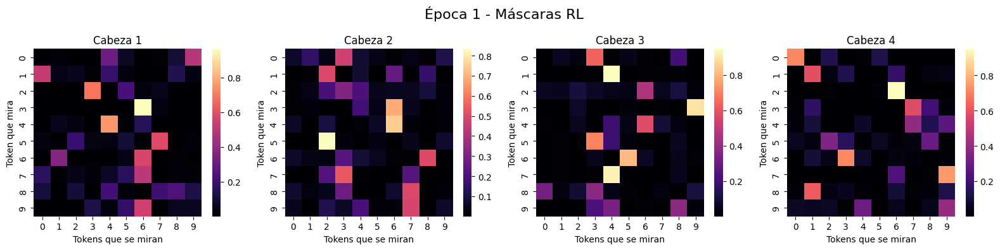

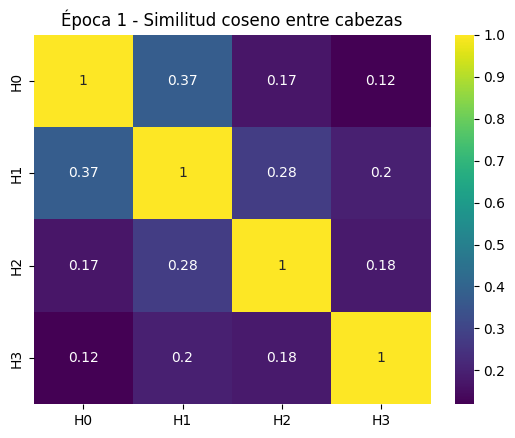

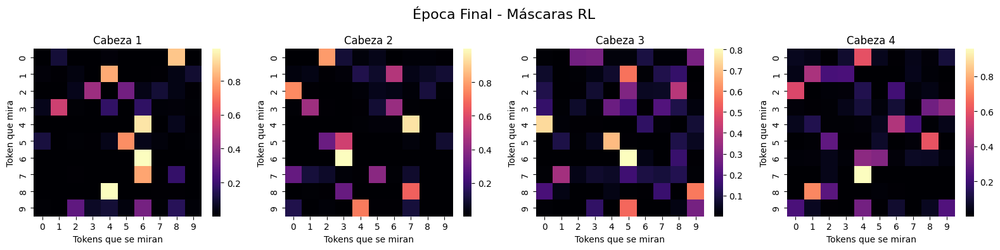

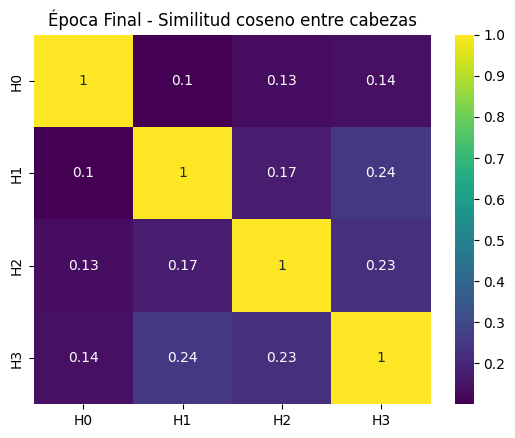

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
import random # Para simular datos

# Clase del modelo de atención (igual que la RevisedMultiRLSoftAttention que ya tienes)
class RevisedMultiRLSoftAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, seq_len, temperature=0.7):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.seq_len = seq_len
        self.temperature = temperature

        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim) # Proyección de salida principal

        # RL masks - one set of parameters per head
        self.rl_masks = nn.ParameterList([nn.Parameter(torch.randn(seq_len, seq_len)) for _ in range(num_heads)])

        # --- Novedades para la nueva tarea: Capas de salida específicas ---
        # Clasificadores a nivel de token (ej. para Verbo/Sujeto/Predicado como etiquetas binarias por token)
        # Asumimos una clasificación de 3 tipos de elementos: Sujeto, Verbo, Predicado + 'Otro'
        self.token_classifier = nn.Linear(embed_dim, 4) # Output: logits para 4 clases (Sujeto, Verbo, Predicado, Otro)
        # Clasificador de sentimiento (ej. Positivo, Negativo, Neutro)
        self.sentiment_classifier = nn.Linear(embed_dim, 3) # Output: logits para 3 clases de sentimiento
        # Clasificador de directiva compleja - AGREGADO
        self.directive_classifier = nn.Linear(embed_dim, 1) # Output: logits para 1 clase (0=No, 1=Si)


    def forward(self, x, training=True):
        B, T, E = x.shape
        H = self.num_heads
        D = self.head_dim
        assert E == H * D, f"Input embedding dimension mismatch. Expected {H * D}, got {E}"
        assert T == self.seq_len, f"Input sequence length mismatch. Expected {self.seq_len}, got {T}"

        Q = self.q_proj(x).view(B, T, H, D).transpose(1, 2)
        K = self.k_proj(x).view(B, T, H, D).transpose(1, 2)
        V = self.v_proj(x).view(B, T, H, D).transpose(1, 2)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / (D ** 0.5)

        masked_scores_list = []
        attn_masks_output_list = [] # This will store the softmaxed masks

        for i in range(H):
            rl_logits = self.rl_masks[i] # Shape (seq_len, seq_len)

            if training:
                # Generate Gumbel noise and apply Gumbel-Softmax trick
                # Noise should have the same shape as rl_logits
                gumbel_noise = -torch.log(-torch.log(torch.rand_like(rl_logits, device=rl_logits.device) + 1e-10) + 1e-10) # Add small epsilon for numerical stability
                mask_logits = (rl_logits + gumbel_noise) / self.temperature
            else:
                # In evaluation/inference, just use the deterministic mask
                mask_logits = rl_logits

            # Apply softmax along the dimension you want the mask probabilities to sum up to 1 (typically the last dimension)
            # This mask is applied element-wise to the scores matrix (TxT) for each head.
            attn_mask_per_head = F.softmax(mask_logits, dim=-1) # Shape (seq_len, seq_len), rows sum to 1

            # Store the resulting mask tensor for visualization/analysis
            attn_masks_output_list.append(attn_mask_per_head)

            # Expand mask to match batch and head dimensions for element-wise multiplication with scores
            # scores[:, i, :, :] has shape (B, T, T)
            # attn_mask_per_head has shape (T, T)
            # Need to expand attn_mask_per_head to (B, T, T) to multiply with scores[:, i, :, :]
            attn_mask_exp = attn_mask_per_head.unsqueeze(0).expand(B, -1, -1) # Shape (B, T, T)

            # Apply mask to scores for this head
            # masked_scores_per_head will have shape (B, T, T)
            masked_scores_per_head = scores[:, i, :, :] * attn_mask_exp # Element-wise multiplication

            # Append the masked scores for this head, adding back the head dimension
            masked_scores_list.append(masked_scores_per_head.unsqueeze(1)) # Shape (B, 1, T, T)


        # Concatenate masked scores along the head dimension
        masked_scores = torch.cat(masked_scores_list, dim=1) # Shape (B, H, T, T)

        # Apply softmax to the masked scores to get final attention weights
        # These attention weights sum to 1 along the last dimension for each query token and each head.
        attn_weights = F.softmax(masked_scores, dim=-1) # Shape (B, H, T, T)

        # Apply attention weights to V
        # (B, H, T, T) @ (B, H, T, D) -> (B, H, T, D)
        out = torch.matmul(attn_weights, V) # Shape (B, H, T, D)

        # Concatenate head outputs along the embedding dimension and apply final projection
        # (B, H, T, D) -> transpose (B, T, H, D) -> view (B, T, H*D) -> (B, T, E)
        out = out.transpose(1, 2).contiguous().view(B, T, E) # Shape (B, T, E)
        output_main = self.out_proj(out) # Salida principal del MHA (B, T, E)

        # --- Salidas específicas para la tarea ---
        # Predicciones a nivel de token para Sujeto/Verbo/Predicado/Otro
        token_logits = self.token_classifier(output_main) # Shape (B, T, 4)

        # Predicción de sentimiento (usamos pooling sobre la salida principal para obtener un vector de sentencia)
        sentence_embedding = torch.mean(output_main, dim=1) # Pooling simple (media), Shape (B, E)
        sentiment_logits = self.sentiment_classifier(sentence_embedding) # Shape (B, 3)

        # Predicción de directiva compleja - AGREGADO
        # Usamos el embedding de la sentencia para clasificar la directiva.
        directive_logits = self.directive_classifier(sentence_embedding) # Shape (B, 1)


        # Return the main output, the softmaxed RL masks, and the task-specific logits
        # attn_masks_output_list contains H tensors, each of shape (seq_len, seq_len)
        return output_main, attn_masks_output_list, token_logits, sentiment_logits, directive_logits


# --- Generación de Datos Dummy para la Nueva Tarea ---
# Esto es CRÍTICO: Necesitas datos que simulen oraciones y sus etiquetas
# Esto es solo un ejemplo MUY simplificado. En la realidad, usarías un dataset de PLN.
def generate_dummy_sentence_data(batch_size, seq_len, embed_dim):
    # Simula embeddings de palabras
    x_data = torch.randn(batch_size, seq_len, embed_dim)

    # Simula etiquetas de "ground truth" para la tarea (a nivel de token y oración)
    # Sujeto=0, Verbo=1, Predicado=2, Otro=3
    # Genera una secuencia de etiquetas aleatorias para cada token
    # Cada oración tendrá al menos un Sujeto (0), Verbo (1) y Predicado (2)
    y_token_gt = torch.full((batch_size, seq_len), 3, dtype=torch.long) # Inicialmente todo 'Otro'
    for b in range(batch_size):
        # Asigna un sujeto, verbo y predicado en posiciones aleatorias
        indices = random.sample(range(seq_len), min(3, seq_len)) # Select up to 3 unique indices
        if len(indices) > 0: y_token_gt[b, indices[0]] = 0 # Sujeto
        if len(indices) > 1: y_token_gt[b, indices[1]] = 1 # Verbo
        if len(indices) > 2: y_token_gt[b, indices[2]] = 2 # Predicado

    # Simula etiquetas de sentimiento (0=Positivo, 1=Negativo, 2=Neutro)
    y_sentiment_gt = torch.randint(0, 3, (batch_size,), dtype=torch.long)

    # Simula si hay una directiva compleja (0=No, 1=Si)
    y_directive_gt = torch.randint(0, 2, (batch_size,), dtype=torch.float) # Use float for BCEWithLogitsLoss target


    return x_data, y_token_gt, y_sentiment_gt, y_directive_gt


# --- Función de Recompensa (Ejemplo de Idea 1: Puntuación por Componentes) ---
# Modified to return a tensor loss
def calculate_loss_from_reward(token_logits, sentiment_logits, directive_logits,
                               y_token_gt, y_sentiment_gt, y_directive_gt,
                               rewards_config):
    # Ensure inputs are on the same device if needed, though dummy data is on CPU initially

    # --- Calculate Losses for Each Task ---
    # Using standard differentiable loss functions for each task.
    # The Gumbel-Softmax in the forward pass allows gradients from these losses
    # to flow back to the `self.rl_masks` parameters.

    # Token classification loss (Cross-Entropy)
    # Reshape token_logits to (B*T, num_classes) and y_token_gt to (B*T)
    token_loss = F.cross_entropy(token_logits.view(-1, 4), y_token_gt.view(-1))

    # Sentiment classification loss (Cross-Entropy)
    # sentiment_logits shape (B, num_sentiment_classes), y_sentiment_gt shape (B,)
    sentiment_loss = F.cross_entropy(sentiment_logits, y_sentiment_gt)

    # Directive classification loss (Binary Cross-Entropy with Logits)
    # directive_logits shape (B, 1), y_directive_gt shape (B,)
    # Squeeze directive_logits to (B,) before passing to BCEWithLogitsLoss
    directive_loss = F.binary_cross_entropy_with_logits(directive_logits.squeeze(-1), y_directive_gt)


    # --- Combine Losses ---
    # The total loss is the sum of the individual task losses.
    # You can add weighting factors from rewards_config here if desired
    # (e.g., total_loss = rewards_config['token_weight'] * token_loss + ...),
    # but summing is a common starting point.
    total_loss = token_loss + sentiment_loss + directive_loss

    # If you strictly wanted to use a "reward" function as a scalar loss to maximize,
    # you'd calculate a score based on predictions and ground truth using tensor ops
    # and return -mean(batch_reward). The previous code block's commented-out section
    # showed an attempt at this. However, using standard task losses as shown above
    # is the typical way to leverage the Gumbel-Softmax for differentiable training
    # of parameters that influence categorical choices (like which tokens to attend to via masks).

    # Returning the combined differentiable loss
    return total_loss # This is the loss to minimize


# --- Configuración de Recompensas (used for the alternative RL loss calculation,
# and potentially for weighting losses if implementing that) ---
# Keeping this structure.
rewards_cfg = {
    'token_correct_reward': 1.0,      # Reward for each correct token
    'token_incorrect_penalty': 0.5, # Penalty for each incorrect token
    'sentiment_correct_reward': 10.0, # Reward for correct sentiment
    'sentiment_incorrect_penalty': 5.0, # Penalty for incorrect sentiment
    'directive_correct_reward': 20.0, # Reward for correctly identifying complex directive when present
    'directive_directive_miss_penalty': 25.0, # Penalty for missing a complex directive
    'directive_false_positive_penalty': 10.0 # Penalty for false positive on complex directive
    # Add weights for losses here if you want to weight them
    # 'token_weight': 1.0,
    # 'sentiment_weight': 1.0,
    # 'directive_weight': 1.0,
}

# Parámetros del modelo y entrenamiento
torch.manual_seed(0)
seq_len = 10 # Ahora más largo para simular oraciones
embed_dim = 64 # Dimensión del embedding
num_heads = 4
epochs = 20000 # Más épocas para una tarea más compleja
B = 32       # batch size

model = RevisedMultiRLSoftAttention(embed_dim, num_heads, seq_len)
# Optimizer for standard gradient descent on the combined differentiable loss
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# We don't need a separate loss_fn if calculate_loss_from_reward returns the loss
# loss_fn = nn.MSELoss() # Not used anymore for this loss calculation method

# Para guardar máscaras en época 1 y final
masks_epoch1 = None
masks_epochFinal = None

print("Iniciando entrenamiento...")
for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()

    # Generar datos para el batch actual
    x_data, y_token_gt, y_sentiment_gt, y_directive_gt = generate_dummy_sentence_data(B, seq_len, embed_dim)

    # Move data to device if using GPU
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    x_data = x_data.to(device)
    y_token_gt = y_token_gt.to(device)
    y_sentiment_gt = y_sentiment_gt.to(device)
    y_directive_gt = y_directive_gt.to(device)
    model.to(device) # Ensure model is on the same device

    # Realizar forward pass
    # output_main: salida del MHA, token_logits: predicciones de token, sentiment_logits: predicciones de sentimiento, directive_logits: predicciones de directiva
    output_main, masks, token_logits, sentiment_logits, directive_logits = model(x_data, training=True)

    # Calcular la pérdida usando la función modificada
    # This function now returns a tensor loss
    loss = calculate_loss_from_reward(
        token_logits,
        sentiment_logits,
        directive_logits,
        y_token_gt,
        y_sentiment_gt,
        y_directive_gt,
        rewards_cfg # Pass rewards config if the function needs it for weighting
    )

    # Backpropagation
    # loss is now a tensor from calculate_loss_from_reward
    loss.backward()
    optimizer.step()

    if epoch == 1:
        # Masks are already tensors on device, clone and move to CPU for storage
        masks_epoch1 = [m.detach().cpu().clone() for m in masks]
    if epoch == epochs:
         # Masks are already tensors on device, clone and move to CPU for storage
         masks_epochFinal = [m.detach().cpu().clone() for m in masks]

    # Print loss (which is a tensor, use .item() for printing scalar)
    if epoch % 1000 == 0 or epoch == 1 or epoch == epochs:
        print(f"Época {epoch}: Loss = {loss.item():.4f}")


# --- Funciones de Ploteo (minor change to move to CPU) ---
def plot_masks(masks, title_prefix=""):
    fig, axs = plt.subplots(1, len(masks), figsize=(16, 4))
    if len(masks) == 1:
        axs = [axs]

    for i, mask in enumerate(masks):
        # Ensure mask is on CPU before converting to numpy
        sns.heatmap(mask.detach().cpu().numpy(), cmap="magma", annot=False, fmt=".2f", ax=axs[i]) # annot=False for less noise
        axs[i].set_title(f"Cabeza {i+1}")
        axs[i].set_xlabel("Tokens que se miran")
        axs[i].set_ylabel("Token que mira")
    plt.suptitle(f"{title_prefix} - Máscaras RL", fontsize=16)
    plt.tight_layout()
    plt.show()

def plot_cosine_similarity(masks, title):
    # Ensure masks are on CPU before converting to numpy
    flat_masks = [m.detach().cpu().flatten().numpy() for m in masks]
    if len(flat_masks) < 2:
         print(f"No hay suficientes cabezas ({len(flat_masks)}) para calcular la similitud del coseno.")
         return
    sim_matrix = cosine_similarity(flat_masks)
    sns.heatmap(sim_matrix, annot=True, cmap="viridis", xticklabels=[f"H{i}" for i in range(len(masks))], yticklabels=[f"H{i}" for i in range(len(masks))])
    plt.title(title)
    plt.show()


# Visualizar resultados
# These variables now hold the masks on CPU
if masks_epoch1 is not None:
    plot_masks(masks_epoch1, "Época 1")
    plot_cosine_similarity(masks_epoch1, "Época 1 - Similitud coseno entre cabezas")

if masks_epochFinal is not None:
    plot_masks(masks_epochFinal, "Época Final")
    plot_cosine_similarity(masks_epochFinal, "Época Final - Similitud coseno entre cabezas")

##aha

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class RLSoftAttentionHead(nn.Module):
    def __init__(self, embed_dim, seq_len, temperature=0.7):
        super().__init__()
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)

        self.seq_len = seq_len
        self.temperature = temperature

        # Política diferenciable: para cada token, aprende a qué tokens mirar
        self.attn_logits = nn.Parameter(torch.randn(seq_len, seq_len))

    def forward(self, x, training=True):
        B, T, E = x.shape
        Q = self.q_proj(x)  # (B, T, E)
        K = self.k_proj(x)
        V = self.v_proj(x)

        d_k = Q.shape[-1]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (d_k ** 0.5)  # (B, T, T)

        # Política Gumbel-Softmax: atención suave aprendida
        if training:
            noise = -torch.log(-torch.log(torch.rand_like(self.attn_logits)))
            mask_logits = (self.attn_logits + noise) / self.temperature
        else:
            mask_logits = self.attn_logits

        attn_mask = F.softmax(mask_logits, dim=-1)  # (T, T)

        # Expand mask for batch (broadcast)
        attn_mask_exp = attn_mask.unsqueeze(0).expand(B, -1, -1)

        masked_scores = scores * attn_mask_exp  # (B, T, T)

        attn_weights = F.softmax(masked_scores, dim=-1)
        output = torch.matmul(attn_weights, V)

        return output, attn_weights, attn_mask

In [ ]:
torch.manual_seed(0)
seq_len = 5
embed_dim = 32

x = torch.randn(1, seq_len, embed_dim)

model = RLSoftAttentionHead(embed_dim=embed_dim, seq_len=seq_len)
out, attn_weights, attn_mask = model(x)

print("Attention weights:", attn_weights.shape)
print("Atención de la política RL (máscara continua):", attn_mask.shape)

Attention weights: torch.Size([1, 5, 5])
Atención de la política RL (máscara continua): torch.Size([5, 5])


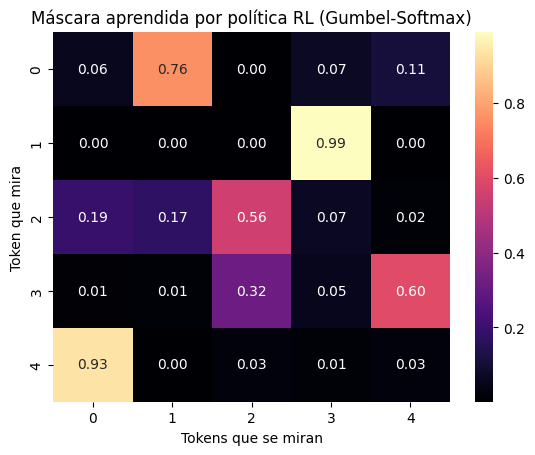

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(attn_mask.detach().numpy(), cmap="magma", annot=True, fmt=".2f")
plt.title("Máscara aprendida por política RL (Gumbel-Softmax)")
plt.xlabel("Tokens que se miran")
plt.ylabel("Token que mira")
plt.show()

#hh

Imagen de tamaño: 960x720
Tamaño del parche: 16x16
Número de parches (ancho x alto): 60 x 45 = 2700
Forma del tensor de entrada para el modelo: torch.Size([1, 2700, 64])
Forma de las máscaras de atención (por cabeza): [torch.Size([2700, 2700]), torch.Size([2700, 2700]), torch.Size([2700, 2700]), torch.Size([2700, 2700])]
Número de máscaras de atención: 4 (igual al número de cabezas)


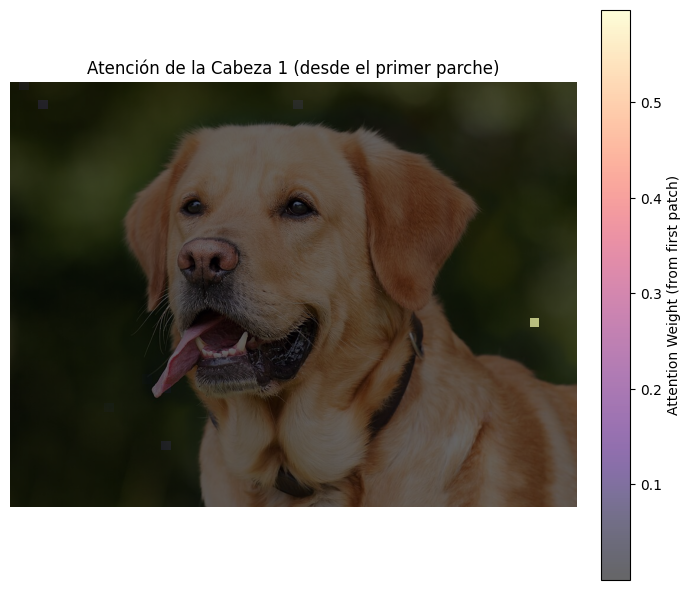

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define the attention head first
class RLSoftAttentionHead(nn.Module):
    def __init__(self, embed_dim, seq_len, temperature=0.7):
        super().__init__()
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)

        self.seq_len = seq_len
        self.temperature = temperature

        self.attn_logits = nn.Parameter(torch.randn(seq_len, seq_len))

    def forward(self, x, training=True):
        B, T, E = x.shape
        Q = self.q_proj(x)
        K = self.k_proj(x)
        V = self.v_proj(x)

        d_k = Q.shape[-1]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (d_k ** 0.5)

        if training:
            noise = -torch.log(-torch.log(torch.rand_like(self.attn_logits)))
            mask_logits = (self.attn_logits + noise) / self.temperature
        else:
            mask_logits = self.attn_logits

        attn_mask = F.softmax(mask_logits, dim=-1)

        attn_mask_exp = attn_mask.unsqueeze(0).expand(B, -1, -1)

        masked_scores = scores * attn_mask_exp

        attn_weights = F.softmax(masked_scores, dim=-1)
        output = torch.matmul(attn_weights, V)

        return output, attn_weights, attn_mask

# Define the Multi-Head Attention module using the attention head
class RevisedMultiRLSoftAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, seq_len):
        super().__init__()
        # Ensure embed_dim is divisible by the number of heads
        assert embed_dim % num_heads == 0, "embed_dim must be divisible by num_heads"

        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        # Create a list of attention heads
        self.heads = nn.ModuleList([
            RLSoftAttentionHead(self.head_dim, seq_len) for _ in range(num_heads)
        ])

        # Output projection layer
        self.output_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x, training=True):
        B, T, E = x.shape
        # Split the input embedding across heads
        x_split = x.view(B, T, self.num_heads, self.head_dim).permute(0, 2, 1, 3) # (B, num_heads, T, head_dim)
        x_split = x_split.contiguous().view(B * self.num_heads, T, self.head_dim) # (B * num_heads, T, head_dim)


        # Pass through each head
        outputs = []
        attention_masks = []
        for i, head in enumerate(self.heads):
             # Need to select the relevant part of the input for this head
             # However, since we split the input above, we can directly pass the split input.
             # The head still needs to handle the batch size which is now B * num_heads.
             head_output, head_attn_weights, head_attn_mask = head(x_split[i*B:(i+1)*B], training=training) # Pass relevant batch slice to head
             outputs.append(head_output)
             attention_masks.append(head_attn_mask) # Mask per head

        # Concatenate outputs from all heads
        # Need to reshape outputs first to (B, num_heads, T, head_dim) and then combine
        combined_outputs = torch.cat([o.view(B, T, self.head_dim) for o in outputs], dim=-1) # (B, T, embed_dim)


        # Pass through output projection
        output = self.output_proj(combined_outputs)

        # attention_masks is a list of Tensors, one for each head
        # You might want to process this further depending on your visualization needs
        return output, attention_masks # Return output and the list of masks

# Ruta de la imagen
image_path = '/content/H.jpg'

# Parámetros para el parcheo
patch_size = 16
transform = transforms.ToTensor()

# --- 1. Cargar la Imagen ---
try:
    image = Image.open(image_path).convert('RGB')
except FileNotFoundError:
    print(f"Error: La imagen no se encontró en la ruta: {image_path}")
    # Use sys.exit() if running as a script outside of a notebook cell.
    # In a notebook cell, raising an error or simply printing and stopping might be sufficient.
    raise FileNotFoundError(f"Error: La imagen no se encontró en la ruta: {image_path}")


# --- 2. Calcular el número de parches ---
img_width, img_height = image.size
n_patches_width = img_width // patch_size
n_patches_height = img_height // patch_size
num_patches = n_patches_width * n_patches_height
seq_len = num_patches # La longitud de la secuencia para el modelo será el número de parches

print(f"Imagen de tamaño: {img_width}x{img_height}")
print(f"Tamaño del parche: {patch_size}x{patch_size}")
print(f"Número de parches (ancho x alto): {n_patches_width} x {n_patches_height} = {num_patches}")

# --- 3. Función para dividir la imagen en parches ---
def extract_patches(img, patch_size):
    patches = []
    width, height = img.size
    for i in range(0, height, patch_size):
        for j in range(0, width, patch_size):
            box = (j, i, j + patch_size, i + patch_size)
            patch = img.crop(box)
            patches.append(patch)
    return patches

patches = extract_patches(image, patch_size)

# --- 4. Convertir parches a tensores ---
patch_tensors = [transform(patch) for patch in patches]
# Stack los tensores para tener una forma (num_patches, channels, patch_size, patch_size)
patch_tensor_stack = torch.stack(patch_tensors)

# --- 5. Preparar la entrada para el modelo ---
# Necesitamos "aplanar" cada parche en un vector (embedding)
patch_embeddings = patch_tensor_stack.view(num_patches, -1) # Forma: (num_patches, channels * patch_size * patch_size)

# Si tu modelo espera una dimensión de embedding específica, podrías necesitar una capa lineal aquí
embedding_dim = 64 # Ejemplo de dimensión de embedding deseada. Make sure this matches your model's expected input.
# The input dimension to the projection layer is the flattened patch size * channels
input_flat_dim = patch_size * patch_size * patch_tensor_stack.shape[1] # Assuming shape is (N, C, H, W)
if input_flat_dim != embedding_dim: # Check if projection is needed
    # Crea una capa lineal para proyectar la dimensión
    projection_layer = torch.nn.Linear(input_flat_dim, embedding_dim)
    patch_embeddings = projection_layer(patch_embeddings)
else:
    # If input_flat_dim already matches embedding_dim, no projection is needed.
    # You might want to print a message or handle this case.
    print("Input patch embedding dimension matches model's expected embedding_dim. No projection needed.")
    # Remove or comment out the projection_layer definition and usage if not needed.


# Añadir una dimensión de batch (asumiendo un solo ejemplo por ahora)
batch_size = 1
input_sequence = patch_embeddings.unsqueeze(0) # Forma: (batch_size, seq_len, embedding_dim)

print("Forma del tensor de entrada para el modelo:", input_sequence.shape)

# --- 6. Adaptar el Modelo (si es necesario) y Pasar los Parches ---
# Asegúrate de que tu modelo RevisedMultiRLSoftAttention esté inicializado con seq_len = num_patches
# y el embed_dim correcto.

# Ejemplo de inicialización del modelo (ajusta los parámetros según tu necesidad)
# Make sure the embed_dim passed here matches the output dimension of your patch embedding step
# (either the original flattened size or the output of the projection layer).
num_heads = 4
# Use the calculated embedding_dim which is 64 in this example
model = RevisedMultiRLSoftAttention(embed_dim=embedding_dim, num_heads=num_heads, seq_len=seq_len)

# Pasar la secuencia de parches al modelo
# Asegúrate de estar en modo de evaluación si no estás entrenando
model.eval()
with torch.no_grad():
    output, attention_masks = model(input_sequence)

# `attention_masks` ahora es una lista de tensores de forma (seq_len, seq_len),
# donde seq_len es el número de parches. `attention_masks` contiene las máscaras
# de atención de cada cabeza.

print("Forma de las máscaras de atención (por cabeza):", [m.shape for m in attention_masks])
print(f"Número de máscaras de atención: {len(attention_masks)} (igual al número de cabezas)")

# --- 7. Visualización de la Atención (Opcional) ---
# Esta es la parte más compleja y depende de lo que quieras visualizar.
# Un ejemplo sería tomar los pesos de atención de una cabeza para un parche específico
# (ej., el primer parche) y ver a qué otros parches atiende más.
# Luego, podrías intentar visualizar esto de vuelta en la imagen original.

def visualize_attention(image, attention_mask, patch_size, head_index):
    n_patches_width = image.width // patch_size
    n_patches_height = image.height // patch_size

    # Asumiendo que attention_mask is a single (seq_len, seq_len) tensor from the list
    attention_from_first_patch = attention_mask.cpu().numpy()[0] # Shape (num_patches,)

    # Redimensionar el vector de atención a la forma de la cuadrícula de parches
    attention_grid = attention_from_first_patch.reshape(n_patches_height, n_patches_width)

    # Create a figure and axes
    fig, ax = plt.subplots(1, 1, figsize=(8, 8))

    # Display the original image
    ax.imshow(image)
    ax.axis('off')

    # Overlay the attention heatmap
    # Use imshow for the heatmap with the same extent as the image
    # The extent parameter maps the array coordinates to the image coordinates.
    # Origin='upper' matches the standard image coordinate system.
    heatmap = ax.imshow(attention_grid, cmap="magma", alpha=0.6,
                        extent=[0, image.width, image.height, 0], origin='upper')

    # Add a colorbar
    cbar = fig.colorbar(heatmap, ax=ax, orientation='vertical', fraction=0.046, pad=0.04)
    cbar.set_label('Attention Weight (from first patch)')


    plt.title(f'Atención de la Cabeza {head_index + 1} (desde el primer parche)')
    plt.show()

# Visualizar la atención de la primera cabeza (índice 0)
if len(attention_masks) > 0:
    # Pass the mask for the first head
    visualize_attention(image, attention_masks[0], patch_size, 0)

# esto te ayude a empezar! Si tienes preguntas sobre alguna parte específica o la adaptación del modelo, no dudes en consultarme.

Visualizando el punto en X: 320, Y: 300


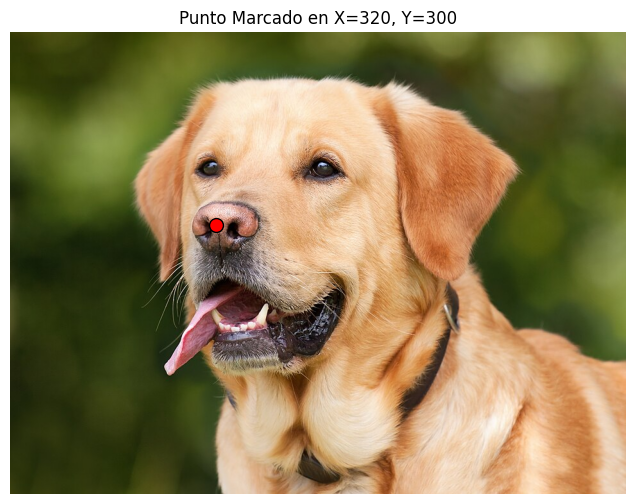

El color del píxel en (320, 300) es: (193, 142, 125)


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Carga la imagen
try:
    img = Image.open("H.jpg")
except FileNotFoundError:
    print("Error: La imagen 'H.jpg' no se encontró. Asegúrate de que esté en el mismo directorio.")
    exit()

# Define las coordenadas del punto que quieres visualizar
posicion_x = 320
posicion_y = 300

print(f"Visualizando el punto en X: {posicion_x}, Y: {posicion_y}")

# Convierte la imagen a un array de NumPy para que matplotlib pueda mostrarla
img_np = np.array(img)

# Crea la figura y los ejes para mostrar la imagen
plt.figure(figsize=(8, 6)) # Puedes ajustar el tamaño de la figura

# Muestra la imagen
plt.imshow(img_np)

# Dibuja un marcador en la posición deseada
# 'o' para un círculo, 'r' para rojo, 's' para el tamaño del marcador
plt.plot(posicion_x, posicion_y, 'o', color='red', markersize=10, markeredgecolor='black', markeredgewidth=1)

# Añade un título al gráfico
plt.title(f'Punto Marcado en X={posicion_x}, Y={posicion_y}')

# Opcional: Deshabilita los ejes para una vista más limpia de la imagen
plt.axis('off')

# Muestra el gráfico
plt.show()

# Si quieres saber el color de ese píxel (opcional, como en tu código original)
pixel_color = img.getpixel((posicion_x, posicion_y))
print(f"El color del píxel en ({posicion_x}, {posicion_y}) es: {pixel_color}")

Imagen de tamaño: 960x720
Tamaño del parche: 16x16
Número de parches (ancho x alto): 60 x 45 = 2700
Forma del tensor de entrada para el modelo: torch.Size([1, 2700, 64])
Forma de las máscaras de atención (por cabeza): [torch.Size([2700, 2700]), torch.Size([2700, 2700]), torch.Size([2700, 2700]), torch.Size([2700, 2700])]
Número de máscaras de atención: 4 (igual al número de cabezas)

El punto (320, 300) se encuentra en el parche de la fila 18, columna 20.
El índice lineal de este parche en la secuencia es: 1100


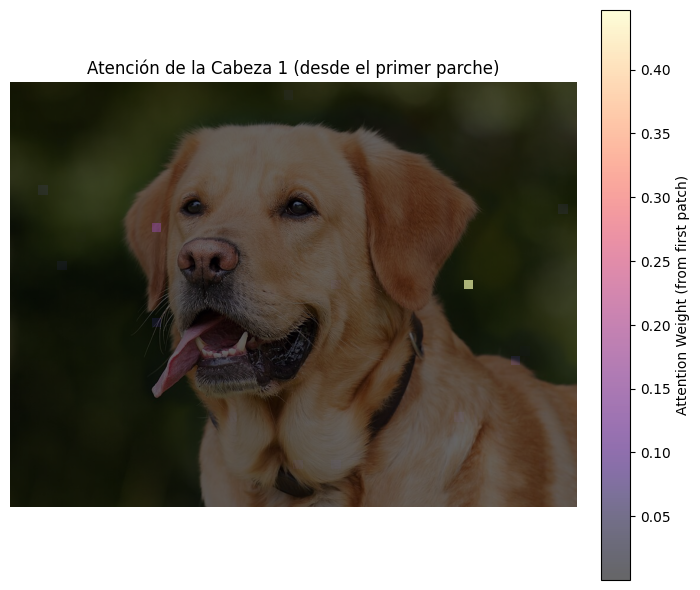

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define the attention head first
class RLSoftAttentionHead(nn.Module):
    def __init__(self, embed_dim, seq_len, temperature=0.7):
        super().__init__()
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)

        self.seq_len = seq_len
        self.temperature = temperature

        self.attn_logits = nn.Parameter(torch.randn(seq_len, seq_len))

    def forward(self, x, training=True):
        B, T, E = x.shape
        Q = self.q_proj(x)
        K = self.k_proj(x)
        V = self.v_proj(x)

        d_k = Q.shape[-1]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (d_k ** 0.5)

        if training:
            noise = -torch.log(-torch.log(torch.rand_like(self.attn_logits)))
            mask_logits = (self.attn_logits + noise) / self.temperature
        else:
            mask_logits = self.attn_logits

        attn_mask = F.softmax(mask_logits, dim=-1)

        attn_mask_exp = attn_mask.unsqueeze(0).expand(B, -1, -1)

        masked_scores = scores * attn_mask_exp

        attn_weights = F.softmax(masked_scores, dim=-1)
        output = torch.matmul(attn_weights, V)

        return output, attn_weights, attn_mask

# Define the Multi-Head Attention module using the attention head
class RevisedMultiRLSoftAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, seq_len):
        super().__init__()
        # Ensure embed_dim is divisible by the number of heads
        assert embed_dim % num_heads == 0, "embed_dim must be divisible by num_heads"

        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        # Create a list of attention heads
        self.heads = nn.ModuleList([
            RLSoftAttentionHead(self.head_dim, seq_len) for _ in range(num_heads)
        ])

        # Output projection layer
        self.output_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x, training=True):
        B, T, E = x.shape
        # Split the input embedding across heads
        x_split = x.view(B, T, self.num_heads, self.head_dim).permute(0, 2, 1, 3) # (B, num_heads, T, head_dim)
        x_split = x_split.contiguous().view(B * self.num_heads, T, self.head_dim) # (B * num_heads, T, head_dim)


        # Pass through each head
        outputs = []
        attention_masks = []
        for i, head in enumerate(self.heads):
             # Need to select the relevant part of the input for this head
             # However, since we split the input above, we can directly pass the split input.
             # The head still needs to handle the batch size which is now B * num_heads.
             head_output, head_attn_weights, head_attn_mask = head(x_split[i*B:(i+1)*B], training=training) # Pass relevant batch slice to head
             outputs.append(head_output)
             attention_masks.append(head_attn_mask) # Mask per head

        # Concatenate outputs from all heads
        # Need to reshape outputs first to (B, num_heads, T, head_dim) and then combine
        combined_outputs = torch.cat([o.view(B, T, self.head_dim) for o in outputs], dim=-1) # (B, T, embed_dim)


        # Pass through output projection
        output = self.output_proj(combined_outputs)

        # attention_masks is a list of Tensors, one for each head
        # You might want to process this further depending on your visualization needs
        return output, attention_masks # Return output and the list of masks

# Ruta de la imagen
image_path = '/content/H.jpg'

# Parámetros para el parcheo
patch_size = 16
transform = transforms.ToTensor()

# --- 1. Cargar la Imagen ---
try:
    image = Image.open(image_path).convert('RGB')
except FileNotFoundError:
    print(f"Error: La imagen no se encontró en la ruta: {image_path}")
    raise FileNotFoundError(f"Error: La imagen no se encontró en la ruta: {image_path}")


# --- 2. Calcular el número de parches ---
img_width, img_height = image.size
n_patches_width = img_width // patch_size
n_patches_height = img_height // patch_size
num_patches = n_patches_width * n_patches_height
seq_len = num_patches # La longitud de la secuencia para el modelo será el número de parches

print(f"Imagen de tamaño: {img_width}x{img_height}")
print(f"Tamaño del parche: {patch_size}x{patch_size}")
print(f"Número de parches (ancho x alto): {n_patches_width} x {n_patches_height} = {num_patches}")

# --- 3. Función para dividir la imagen en parches ---
def extract_patches(img, patch_size):
    patches = []
    width, height = img.size
    for i in range(0, height, patch_size):
        for j in range(0, width, patch_size):
            box = (j, i, j + patch_size, i + patch_size)
            patch = img.crop(box)
            patches.append(patch)
    return patches

patches = extract_patches(image, patch_size)

# --- 4. Convertir parches a tensores ---
patch_tensors = [transform(patch) for patch in patches]
# Stack los tensores para tener una forma (num_patches, channels, patch_size, patch_size)
patch_tensor_stack = torch.stack(patch_tensors)

# --- 5. Preparar la entrada para el modelo ---
# Necesitamos "aplanar" cada parche en un vector (embedding)
patch_embeddings = patch_tensor_stack.view(num_patches, -1) # Forma: (num_patches, channels * patch_size * patch_size)

# Si tu modelo espera una dimensión de embedding específica, podrías necesitar una capa lineal aquí
embedding_dim = 64 # Ejemplo de dimensión de embedding deseada. Make sure this matches your model's expected input.
# The input dimension to the projection layer is the flattened patch size * channels
input_flat_dim = patch_size * patch_size * patch_tensor_stack.shape[1] # Assuming shape is (N, C, H, W)
if input_flat_dim != embedding_dim: # Check if projection is needed
    # Crea una capa lineal para proyectar la dimensión
    projection_layer = torch.nn.Linear(input_flat_dim, embedding_dim)
    patch_embeddings = projection_layer(patch_embeddings)
else:
    print("Input patch embedding dimension matches model's expected embedding_dim. No projection needed.")


# Añadir una dimensión de batch (asumiendo un solo ejemplo por ahora)
batch_size = 1
input_sequence = patch_embeddings.unsqueeze(0) # Forma: (batch_size, seq_len, embedding_dim)

print("Forma del tensor de entrada para el modelo:", input_sequence.shape)

# --- 6. Adaptar el Modelo (si es necesario) y Pasar los Parches ---
# Asegúrate de que tu modelo RevisedMultiRLSoftAttention esté inicializado con seq_len = num_patches
# y el embed_dim correcto.

# Ejemplo de inicialización del modelo (ajusta los parámetros según tu necesidad)
num_heads = 4
model = RevisedMultiRLSoftAttention(embed_dim=embedding_dim, num_heads=num_heads, seq_len=seq_len)

# Pasar la secuencia de parches al modelo
model.eval()
with torch.no_grad():
    output, attention_masks = model(input_sequence)

print("Forma de las máscaras de atención (por cabeza):", [m.shape for m in attention_masks])
print(f"Número de máscaras de atención: {len(attention_masks)} (igual al número de cabezas)")



### **Identificando el Parche Objetivo**

#Primero, necesitamos determinar a qué parche corresponden las coordenadas (320, 300).


# Coordenadas del punto de interés
target_x = 320
target_y = 300

# Calcular el índice del parche
# La coordenada del parche es el entero de la división de la coordenada del píxel por el tamaño del parche
patch_col_index = target_x // patch_size
patch_row_index = target_y // patch_size

# El índice lineal del parche en la secuencia
# Recuerda que los parches se extraen de izquierda a derecha, luego de arriba a abajo
target_patch_index = patch_row_index * n_patches_width + patch_col_index

print(f"\nEl punto ({target_x}, {target_y}) se encuentra en el parche de la fila {patch_row_index}, columna {patch_col_index}.")
print(f"El índice lineal de este parche en la secuencia es: {target_patch_index}")

# Asegúrate de que el índice esté dentro de los límites
if not (0 <= target_patch_index < num_patches):
    print(f"Advertencia: El punto ({target_x}, {target_y}) está fuera de los límites de los parches.")
    # Puedes manejar este caso saliendo o mostrando un mensaje de error.
    exit()

def visualize_attention(image, attention_mask, patch_size, head_index):
    n_patches_width = image.width // patch_size
    n_patches_height = image.height // patch_size

    # Asumiendo que attention_mask is a single (seq_len, seq_len) tensor from the list
    attention_from_first_patch = attention_mask.cpu().numpy()[0] # Shape (num_patches,)

    # Redimensionar el vector de atención a la forma de la cuadrícula de parches
    attention_grid = attention_from_first_patch.reshape(n_patches_height, n_patches_width)

    # Create a figure and axes
    fig, ax = plt.subplots(1, 1, figsize=(8, 8))

    # Display the original image
    ax.imshow(image)
    ax.axis('off')

    # Overlay the attention heatmap
    # Use imshow for the heatmap with the same extent as the image
    # The extent parameter maps the array coordinates to the image coordinates.
    # Origin='upper' matches the standard image coordinate system.
    heatmap = ax.imshow(attention_grid, cmap="magma", alpha=0.6,
                        extent=[0, image.width, image.height, 0], origin='upper')

    # Add a colorbar
    cbar = fig.colorbar(heatmap, ax=ax, orientation='vertical', fraction=0.046, pad=0.04)
    cbar.set_label('Attention Weight (from first patch)')


    plt.title(f'Atención de la Cabeza {head_index + 1} (desde el primer parche)')
    plt.show()

# Visualizar la atención de la primera cabeza (índice 0)
if len(attention_masks) > 0:
    # Pass the mask for the first head
    visualize_attention(image, attention_masks[0], patch_size, 0)

# esto te ayude a empezar!

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

class RLSoftAttentionHead(nn.Module):
    def __init__(self, embed_dim, seq_len, temperature=0.7):
        super().__init__()
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.seq_len = seq_len
        self.temperature = temperature
        self.attn_logits = nn.Parameter(torch.randn(seq_len, seq_len))

    def forward(self, x, training=True):
        B, T, E = x.shape
        Q = self.q_proj(x)
        K = self.k_proj(x)
        V = self.v_proj(x)
        d_k = Q.shape[-1]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (d_k ** 0.5)
        if training:
            noise = -torch.log(-torch.log(torch.rand_like(self.attn_logits)))
            mask_logits = (self.attn_logits + noise) / self.temperature
        else:
            mask_logits = self.attn_logits
        attn_mask = F.softmax(mask_logits, dim=-1)
        attn_mask_exp = attn_mask.unsqueeze(0).expand(B, -1, -1)
        masked_scores = scores * attn_mask_exp
        attn_weights = F.softmax(masked_scores, dim=-1)
        output = torch.matmul(attn_weights, V)
        return output, attn_weights, attn_mask

class RevisedMultiRLSoftAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, seq_len):
        super().__init__()
        assert embed_dim % num_heads == 0, "embed_dim must be divisible by num_heads"
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.heads = nn.ModuleList([
            RLSoftAttentionHead(self.head_dim, seq_len) for _ in range(num_heads)
        ])
        self.output_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x, training=True):
        B, T, E = x.shape
        x_split = x.view(B, T, self.num_heads, self.head_dim).permute(0, 2, 1, 3)
        x_split = x_split.contiguous().view(B * self.num_heads, T, self.head_dim)
        outputs = []
        attention_masks = []
        for i, head in enumerate(self.heads):
            head_output, head_attn_weights, head_attn_mask = head(x_split[i*B:(i+1)*B], training=training)
            outputs.append(head_output)
            attention_masks.append(head_attn_mask)
        combined_outputs = torch.cat([o.view(B, T, self.head_dim) for o in outputs], dim=-1)
        output = self.output_proj(combined_outputs)
        return output, attention_masks

image_path = '/content/H.jpg'
patch_size = 16
transform = transforms.ToTensor()

try:
    image = Image.open(image_path).convert('RGB')
except FileNotFoundError:
    print(f"Error: La imagen no se encontró en la ruta: {image_path}")
    raise FileNotFoundError(f"Error: La imagen no se encontró en la ruta: {image_path}")

img_width, img_height = image.size
n_patches_width = img_width // patch_size
n_patches_height = img_height // patch_size
num_patches = n_patches_width * n_patches_height
seq_len = num_patches

print(f"Imagen de tamaño: {img_width}x{img_height}")
print(f"Tamaño del parche: {patch_size}x{patch_size}")
print(f"Número de parches (ancho x alto): {n_patches_width} x {n_patches_height} = {num_patches}")

def extract_patches(img, patch_size):
    patches = []
    width, height = img.size
    for i in range(0, height, patch_size):
        for j in range(0, width, patch_size):
            box = (j, i, j + patch_size, i + patch_size)
            patch = img.crop(box)
            patches.append(patch)
    return patches

patches = extract_patches(image, patch_size)
patch_tensors = [transform(patch) for patch in patches]
patch_tensor_stack = torch.stack(patch_tensors)

embedding_dim = 64
input_flat_dim = patch_size * patch_size * patch_tensor_stack.shape[1]
if input_flat_dim != embedding_dim:
    projection_layer = torch.nn.Linear(input_flat_dim, embedding_dim)
    patch_embeddings = projection_layer(patch_embeddings)
else:
    print("Input patch embedding dimension matches model's expected embedding_dim. No projection needed.")

batch_size = 1
input_sequence = patch_embeddings.unsqueeze(0)

print("Forma del tensor de entrada para el modelo:", input_sequence.shape)

num_heads = 1
model = RevisedMultiRLSoftAttention(embed_dim=embedding_dim, num_heads=num_heads, seq_len=seq_len)

model.eval()
with torch.no_grad():
    output, attention_masks = model(input_sequence)

print("Forma de las máscaras de atención (por cabeza):", [m.shape for m in attention_masks])
print(f"Número de máscaras de atención: {len(attention_masks)} (igual al número de cabezas)")

target_x = 320
target_y = 300

patch_col_index = target_x // patch_size
patch_row_index = target_y // patch_size

target_patch_index = patch_row_index * n_patches_width + patch_col_index

print(f"\nEl punto ({target_x}, {target_y}) se encuentra en el parche de la fila {patch_row_index}, columna {patch_col_index}.")
print(f"El índice lineal de este parche en la secuencia es: {target_patch_index}")

if not (0 <= target_patch_index < num_patches):
    print(f"Advertencia: El punto ({target_x}, {target_y}) está fuera de los límites de los parches.")
    exit()

def visualize_attention_from_target_patch(image, attention_mask, patch_size, head_index, target_idx):
    n_patches_width = image.width // patch_size
    n_patches_height = image.height // patch_size
    attention_from_target_patch = attention_mask.cpu().numpy()[target_idx]
    attention_grid = attention_from_target_patch.reshape(n_patches_height, n_patches_width)

    fig, ax = plt.subplots(1, 1, figsize=(10, 8))
    ax.imshow(image)
    ax.axis('off')

    heatmap = ax.imshow(attention_grid, cmap="viridis", alpha=0.7,
                        extent=[0, image.width, image.height, 0], origin='upper')

    cbar = fig.colorbar(heatmap, ax=ax, orientation='vertical', fraction=0.046, pad=0.04)
    cbar.set_label(f'Peso de Atención (desde el parche {target_idx})')

    target_patch_x_start = (target_idx % n_patches_width) * patch_size
    target_patch_y_start = (target_idx // n_patches_width) * patch_size
    rect = plt.Rectangle((target_patch_x_start, target_patch_y_start), patch_size, patch_size,
                         linewidth=3, edgecolor='red', facecolor='none')
    ax.add_patch(rect)

    plt.title(f'Atención de la Cabeza {head_index + 1} desde el Parche en ({target_x}, {target_y})')
    plt.show()

if len(attention_masks) > 0:
    visualize_attention_from_target_patch(image, attention_masks[0], patch_size, 0, target_patch_index)

Imagen de tamaño: 960x720
Tamaño del parche: 16x16
Número de parches (ancho x alto): 60 x 45 = 2700


RuntimeError: mat1 and mat2 shapes cannot be multiplied (2700x64 and 768x64)

Output shape: torch.Size([2, 16, 64])
Attention weights shape: torch.Size([2, 16, 16])


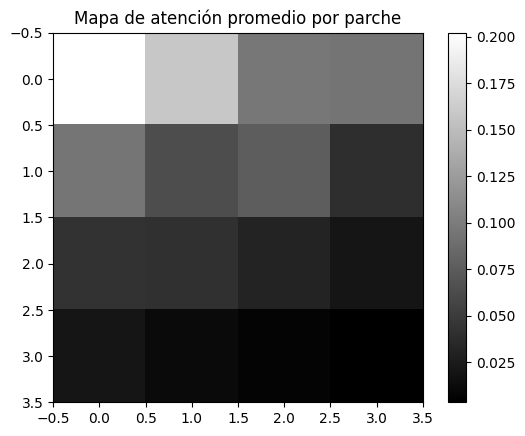

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt


class PatchEmbedding(nn.Module):
    """
    Convierte la imagen en parches, aplana y proyecta a un espacio embebido.
    """
    def __init__(self, patch_size, input_dim, embedding_dim):
        super().__init__()
        self.patch_size = patch_size
        self.input_dim = input_dim  # Canales de la imagen (e.g., 1 para MNIST)
        self.embedding_dim = embedding_dim
        self.projection_layer = nn.Linear(patch_size * patch_size * input_dim, embedding_dim)

    def forward(self, x):
        # x: (B, C, H, W)
        B, C, H, W = x.shape
        assert H % self.patch_size == 0 and W % self.patch_size == 0, "La imagen debe ser divisible por patch_size"

        # Extraer patches
        patches = x.unfold(2, self.patch_size, self.patch_size).unfold(3, self.patch_size, self.patch_size)
        # patches shape: (B, C, num_patches_H, num_patches_W, patch_size, patch_size)

        num_patches_H = patches.shape[2]
        num_patches_W = patches.shape[3]
        num_patches = num_patches_H * num_patches_W

        # Rearreglar para que sea (B, num_patches, C, patch_size, patch_size)
        patches = patches.contiguous().view(B, C, num_patches, self.patch_size, self.patch_size)
        patches = patches.permute(0, 2, 1, 3, 4).contiguous()  # (B, num_patches, C, patch_size, patch_size)

        # Aplanar cada patch
        patches = patches.view(B, num_patches, -1)  # (B, num_patches, patch_size*patch_size*C)

        # Proyectar cada patch
        embeddings = self.projection_layer(patches)  # (B, num_patches, embedding_dim)
        return embeddings


class RevisedMultiRLSoftAttentionHead(nn.Module):
    """
    Cabeza individual de atención relajada con logits entrenables para pesos de atención.
    """
    def __init__(self, input_dim, head_dim, seq_len):
        super().__init__()
        self.input_dim = input_dim
        self.head_dim = head_dim
        self.seq_len = seq_len

        # Proyecciones para queries, keys, values
        self.query_layer = nn.Linear(input_dim, head_dim)
        self.key_layer = nn.Linear(input_dim, head_dim)
        self.value_layer = nn.Linear(input_dim, head_dim)

        # Parámetro entrenable para logits de atención (sin softmax directo)
        self.attn_logits = nn.Parameter(torch.randn(seq_len, seq_len))

        # Temperatura para suavizado
        self.temperature = 1.0

    def forward(self, x, training=False):
        # x: (B, T, input_dim)
        B, T, _ = x.shape

        Q = self.query_layer(x)  # (B, T, head_dim)
        K = self.key_layer(x)    # (B, T, head_dim)
        V = self.value_layer(x)  # (B, T, head_dim)

        # Scores de atención: QK^T / sqrt(d_k)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (self.head_dim ** 0.5)  # (B, T, T)

        # Crear máscara: 1 en diagonal y superior, 0 debajo para atención causal (opcional)
        attn_mask = torch.tril(torch.ones(T, T), diagonal=0).to(x.device)  # (T, T)

        # Aplicar máscara sumando -inf donde hay 0 para que softmax no atienda esas posiciones
        mask = (attn_mask == 0)
        scores = scores.masked_fill(mask.unsqueeze(0), float('-inf'))

        # Añadir logits entrenables (expandir para batch)
        scores = scores + self.attn_logits.unsqueeze(0)

        # Softmax con temperatura
        attn_weights = F.softmax(scores / self.temperature, dim=-1)  # (B, T, T)

        # Aplicar atención
        out = torch.matmul(attn_weights, V)  # (B, T, head_dim)

        return out, attn_weights


class RevisedMultiRLSoftAttention(nn.Module):
    """
    Multi-Head Attention con atención relajada y parámetros entrenables de logits.
    """
    def __init__(self, input_dim, head_dim, num_heads, seq_len):
        super().__init__()
        self.input_dim = input_dim
        self.head_dim = head_dim
        self.num_heads = num_heads
        self.seq_len = seq_len

        assert head_dim * num_heads == input_dim, "input_dim debe ser num_heads * head_dim"

        # Crear heads independientes
        self.heads = nn.ModuleList(
            [RevisedMultiRLSoftAttentionHead(input_dim, head_dim, seq_len) for _ in range(num_heads)]
        )

        # Proyección final
        self.out_projection = nn.Linear(num_heads * head_dim, input_dim)

    def forward(self, x, training=False):
        # x: (B, T, input_dim)
        B, T, D = x.shape
        head_outputs = []
        attn_weights_all = []

        for head in self.heads:
            out, attn_weights = head(x, training=training)
            head_outputs.append(out)
            attn_weights_all.append(attn_weights)

        # Concatenar outputs de todas las cabezas
        concat_out = torch.cat(head_outputs, dim=-1)  # (B, T, num_heads*head_dim)
        out = self.out_projection(concat_out)         # (B, T, input_dim)

        # Promedio de matrices de atención para visualización
        avg_attn_weights = torch.stack(attn_weights_all).mean(dim=0)  # (B, T, T)

        return out, avg_attn_weights


def visualize_attention_map(attn_weights, patch_size, image_size):
    """
    Visualiza el mapa de atención promedio en escala de grises.
    attn_weights: tensor (T, T) para un solo batch
    patch_size: tamaño del parche
    image_size: (H, W) tamaño original imagen
    """
    import numpy as np

    num_patches_H = image_size[0] // patch_size
    num_patches_W = image_size[1] // patch_size
    num_patches = num_patches_H * num_patches_W

    attn_weights = attn_weights.detach().cpu().numpy()  # (T, T)
    if attn_weights.shape[0] != num_patches:
        print(f"Warning: attn_weights shape {attn_weights.shape} no coincide con número de parches {num_patches}")
        return

    # Promedio la atención de cada parche hacia los demás (suma o media de filas)
    attn_map_1d = attn_weights.mean(axis=0)  # Promedio atención hacia cada parche

    # Reorganizar 1D a 2D según disposición de parches
    attn_map_2d = attn_map_1d.reshape(num_patches_H, num_patches_W)

    plt.imshow(attn_map_2d, cmap='gray')
    plt.title('Mapa de atención promedio por parche')
    plt.colorbar()
    plt.show()


# Ejemplo de uso básico

if __name__ == "__main__":
    # Parámetros
    B = 2
    C = 1
    H, W = 28, 28
    patch_size = 7
    embedding_dim = 64
    num_heads = 4
    head_dim = embedding_dim // num_heads
    seq_len = (H // patch_size) * (W // patch_size)

    # Imagen aleatoria
    x = torch.randn(B, C, H, W)

    # Patch embedding
    patch_embed = PatchEmbedding(patch_size, C, embedding_dim)
    embeddings = patch_embed(x)  # (B, num_patches, embedding_dim)

    # Multihead attention
    attention = RevisedMultiRLSoftAttention(embedding_dim, head_dim, num_heads, seq_len)
    out, attn_weights = attention(embeddings)

    print(f"Output shape: {out.shape}")
    print(f"Attention weights shape: {attn_weights.shape}")

    # Visualizar atención para batch 0
    visualize_attention_map(attn_weights[0], patch_size, (H, W))

Imagen de tamaño: 960x720
Tamaño del parche: 16x16
Número de parches (ancho x alto): 60 x 45 = 2700
Forma del tensor de entrada para el modelo: torch.Size([1, 2700, 768])
Parches dentro del radio de atención: [978, 979, 980, 981, 1037, 1038, 1039, 1040, 1041, 1042, 1097, 1098, 1099, 1100, 1101, 1102, 1157, 1158, 1159, 1160, 1161, 1162, 1217, 1218, 1219, 1220, 1221, 1222, 1279, 1280]
Forma de las máscaras de atención (por cabeza): [torch.Size([2700, 2700])]
Número de máscaras de atención: 1 (igual al número de cabezas)


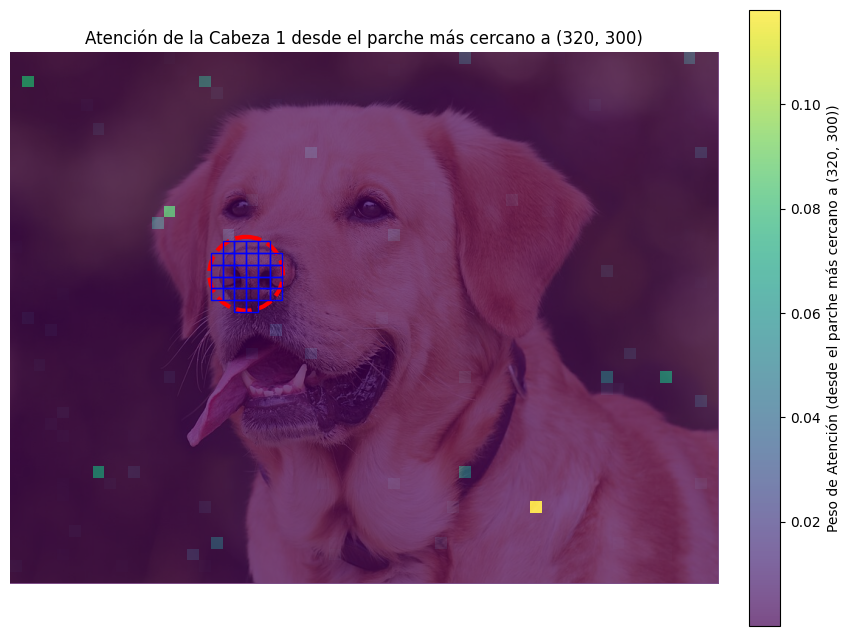

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

class RLSoftAttentionHead(nn.Module):
    def __init__(self, embed_dim, seq_len, temperature=0.7):
        super().__init__()
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.seq_len = seq_len
        self.temperature = temperature
        self.attn_logits = nn.Parameter(torch.randn(seq_len, seq_len))

    def forward(self, x, training=True, forced_attention_mask=None):
        B, T, E = x.shape
        Q = self.q_proj(x)
        K = self.k_proj(x)
        V = self.v_proj(x)
        d_k = Q.shape[-1]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (d_k ** 0.5)

        if training:
            noise = -torch.log(-torch.log(torch.rand_like(self.attn_logits)))
            mask_logits = (self.attn_logits + noise) / self.temperature
        else:
            mask_logits = self.attn_logits

        attn_mask = F.softmax(mask_logits, dim=-1)

        if forced_attention_mask is not None:
            # Asegúrate de que la máscara forzada tenga la forma correcta (1, T, T) o (B, T, T)
            # Y que esté en el dispositivo correcto
            forced_attention_mask = forced_attention_mask.to(x.device)
            # Multiplica por la máscara forzada para anular o potenciar ciertos enlaces de atención
            # Un valor de 0 en la máscara forzada puede "apagar" la atención
            # Un valor alto puede "potenciarla"
            # O, si la máscara forzada ya es binaria (0/1), simplemente multiplicar es suficiente.
            # Podrías también sumar un valor negativo muy grande para 'scores' si quieres deshabilitar
            # la atención a ciertos parches de forma estricta.
            masked_scores = scores * forced_attention_mask.unsqueeze(0).expand(B, -1, -1) # Expande para el batch
        else:
            attn_mask_exp = attn_mask.unsqueeze(0).expand(B, -1, -1)
            masked_scores = scores * attn_mask_exp

        attn_weights = F.softmax(masked_scores, dim=-1)
        output = torch.matmul(attn_weights, V)
        return output, attn_weights, attn_mask


class RevisedMultiRLSoftAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, seq_len):
        super().__init__()
        assert embed_dim % num_heads == 0, "embed_dim must be divisible by num_heads"
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.heads = nn.ModuleList([
            RLSoftAttentionHead(self.head_dim, seq_len) for _ in range(num_heads)
        ])
        self.output_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x, training=True, forced_attention_masks=None):
        B, T, E = x.shape
        # Ensure input embedding dimension E matches self.num_heads * self.head_dim (which is self.embed_dim)
        if E != self.num_heads * self.head_dim:
             raise ValueError(f"Input embedding dimension mismatch. Expected {self.num_heads * self.head_dim}, got {E}")

        x_split = x.view(B, T, self.num_heads, self.head_dim).permute(0, 2, 1, 3)
        x_split = x_split.contiguous().view(B * self.num_heads, T, self.head_dim)
        outputs = []
        attention_masks = []
        for i, head in enumerate(self.heads):
            # Pasa la máscara forzada específica para esta cabeza si existe
            current_forced_mask = forced_attention_masks[i] if forced_attention_masks and i < len(forced_attention_masks) else None
            head_output, head_attn_weights, head_attn_mask = head(x_split[i*B:(i+1)*B], training=training, forced_attention_mask=current_forced_mask)
            outputs.append(head_output)
            attention_masks.append(head_attn_mask)
        combined_outputs = torch.cat([o.view(B, T, self.head_dim) for o in outputs], dim=-1)
        output = self.output_proj(combined_outputs)
        return output, attention_masks

image_path = '/content/H.jpg'
patch_size = 16
transform = transforms.ToTensor()

try:
    image = Image.open(image_path).convert('RGB')
except FileNotFoundError:
    print(f"Error: La imagen no se encontró en la ruta: {image_path}")
    raise FileNotFoundError(f"Error: La imagen no se encontró en la ruta: {image_path}")

img_width, img_height = image.size
n_patches_width = img_width // patch_size
n_patches_height = img_height // patch_size
num_patches = n_patches_width * n_patches_height
seq_len = num_patches

print(f"Imagen de tamaño: {img_width}x{img_height}")
print(f"Tamaño del parche: {patch_size}x{patch_size}")
print(f"Número de parches (ancho x alto): {n_patches_width} x {n_patches_height} = {num_patches}")

def extract_patches(img, patch_size):
    patches = []
    width, height = img.size
    for i in range(0, height, patch_size):
        for j in range(0, width, patch_size):
            box = (j, i, j + patch_size, i + patch_size)
            patch = img.crop(box)
            patches.append(patch)
    return patches

patches = extract_patches(image, patch_size)
patch_tensors = [transform(patch) for patch in patches]
patch_tensor_stack = torch.stack(patch_tensors)

# Fix: Ensure embedding_dim is consistent
embedding_dim = 768 # This was the embedding_dim used for the model
input_flat_dim = patch_size * patch_size * patch_tensor_stack.shape[1] # channels is 3 for RGB

# The projection layer must project from the flattened patch size to the desired embedding_dim
projection_layer = torch.nn.Linear(input_flat_dim, embedding_dim)
patch_embeddings = patch_tensor_stack.view(num_patches, -1) # Flatten the patches first
patch_embeddings = projection_layer(patch_embeddings) # Apply the projection


batch_size = 1
input_sequence = patch_embeddings.unsqueeze(0)

print("Forma del tensor de entrada para el modelo:", input_sequence.shape)

num_heads = 1
# Initialize the model with the correct embedding_dim
model = RevisedMultiRLSoftAttention(embed_dim=embedding_dim, num_heads=num_heads, seq_len=seq_len)

# --- Nueva lógica para forzar la atención a un contorno/región ---
target_x = 320
target_y = 300
radius_pixels = 50 # Radio en píxeles para definir la región de atención
# Puedes ajustar este radio para abarcar más o menos contorno/región

# 1. Identificar los parches dentro de la región de interés
region_patch_indices = []
for i in range(n_patches_height):
    for j in range(n_patches_width):
        patch_center_x = j * patch_size + patch_size // 2
        patch_center_y = i * patch_size + patch_size // 2

        # Calcular distancia del centro del parche al punto objetivo
        distance = np.sqrt((patch_center_x - target_x)**2 + (patch_center_y - target_y)**2)

        if distance <= radius_pixels:
            region_patch_indices.append(i * n_patches_width + j)

if not region_patch_indices:
    print(f"Advertencia: Ningún parche encontrado dentro del radio de {radius_pixels} píxeles de ({target_x}, {target_y}). La atención no se forzará.")
    forced_attn_mask_tensor = None
else:
    print(f"Parches dentro del radio de atención: {region_patch_indices}")
    # 2. Crear una máscara de atención para forzar el enfoque
    # Queremos que los parches dentro de la región atiendan fuertemente entre sí
    # y débilmente a los de fuera.
    # Inicializa una matriz de atención con valores muy pequeños (cercanos a -inf)
    # para deshabilitar la atención por defecto.
    forced_attn_mask_tensor = torch.full((seq_len, seq_len), -1e9) # Un valor muy negativo

    # Para cada parche en la región, permitimos que atienda a todos los demás parches en la región
    for idx_from in region_patch_indices:
        for idx_to in region_patch_indices:
            forced_attn_mask_tensor[idx_from, idx_to] = 0.0 # Permitir atención (0.0 significa que no se penaliza/impulsa)

    # Opcional: Si quieres que un parche *desde* el punto objetivo atienda a la región
    # forced_attn_mask_tensor[target_patch_index, region_patch_indices] = 0.0 # O un valor más alto si quieres impulsar

# Pasa la máscara forzada al modelo
# Como solo hay una cabeza, la lista tendrá un solo elemento
forced_masks_for_model = [forced_attn_mask_tensor] if forced_attn_mask_tensor is not None else None

model.eval()
with torch.no_grad():
    output, attention_masks = model(input_sequence, forced_attention_masks=forced_masks_for_model)

print("Forma de las máscaras de atención (por cabeza):", [m.shape for m in attention_masks])
print(f"Número de máscaras de atención: {len(attention_masks)} (igual al número de cabezas)")

def visualize_attention_from_target_patch_region(image, attention_mask, patch_size, head_index, target_coords, region_indices, radius):
    n_patches_width = image.width // patch_size
    n_patches_height = image.height // patch_size

    # Selecciona la fila de atención del parche central de la región para visualizar,
    # o promedio si quieres una vista más general.
    # Aquí visualizamos desde el primer parche de la región, o el parche más cercano al centro.
    if region_indices:
        # Tomamos el parche más cercano al centro de la región para la visualización
        closest_patch_idx = -1
        min_dist = float('inf')
        for p_idx in region_indices:
            p_row = p_idx // n_patches_width
            p_col = p_idx % n_patches_width
            p_center_x = p_col * patch_size + patch_size // 2
            p_center_y = p_row * patch_size + patch_size // 2
            dist = np.sqrt((p_center_x - target_coords[0])**2 + (p_center_y - target_coords[1])**2)
            if dist < min_dist:
                min_dist = dist
                closest_patch_idx = p_idx

        attention_from_target_patch_region = attention_mask.cpu().numpy()[closest_patch_idx]
        title_suffix = f'desde el parche más cercano a ({target_coords[0]}, {target_coords[1]})'
    else:
        # Si no hay parches en la región, visualizamos desde el primer parche por defecto
        attention_from_target_patch_region = attention_mask.cpu().numpy()[0]
        title_suffix = 'desde el primer parche (sin parches en la región objetivo)'

    attention_grid = attention_from_target_patch_region.reshape(n_patches_height, n_patches_width)

    fig, ax = plt.subplots(1, 1, figsize=(10, 8))
    ax.imshow(image)
    ax.axis('off')

    heatmap = ax.imshow(attention_grid, cmap="viridis", alpha=0.7,
                        extent=[0, image.width, image.height, 0], origin='upper')

    cbar = fig.colorbar(heatmap, ax=ax, orientation='vertical', fraction=0.046, pad=0.04)
    cbar.set_label(f'Peso de Atención ({title_suffix})')

    # Dibuja un círculo para indicar la región de interés original
    circle = plt.Circle((target_coords[0], target_coords[1]), radius, color='red', fill=False, linewidth=3, linestyle='--')
    ax.add_patch(circle)

    # Marca los parches que se incluyeron en la región de atención forzada
    for p_idx in region_indices:
        p_row = p_idx // n_patches_width
        p_col = p_idx % n_patches_width
        rect = plt.Rectangle((p_col * patch_size, p_row * patch_size), patch_size, patch_size,
                             linewidth=1, edgecolor='blue', facecolor='none')
        ax.add_patch(rect)


    plt.title(f'Atención de la Cabeza {head_index + 1} {title_suffix}')
    plt.show()

if len(attention_masks) > 0:
    visualize_attention_from_target_patch_region(image, attention_masks[0], patch_size, 0, (target_x, target_y), region_patch_indices, radius_pixels)

Imagen de tamaño: 960x720
Tamaño del parche: 16x16
Número de parches (ancho x alto): 60 x 45 = 2700
Forma del tensor de entrada para el modelo: torch.Size([1, 2700, 768])
Parches dentro del radio de atención: [978, 979, 980, 981, 1037, 1038, 1039, 1040, 1041, 1042, 1097, 1098, 1099, 1100, 1101, 1102, 1157, 1158, 1159, 1160, 1161, 1162, 1217, 1218, 1219, 1220, 1221, 1222, 1279, 1280]
Forma de las máscaras de atención (por cabeza): [torch.Size([2700, 2700])]
Número de máscaras de atención: 1 (igual al número de cabezas)


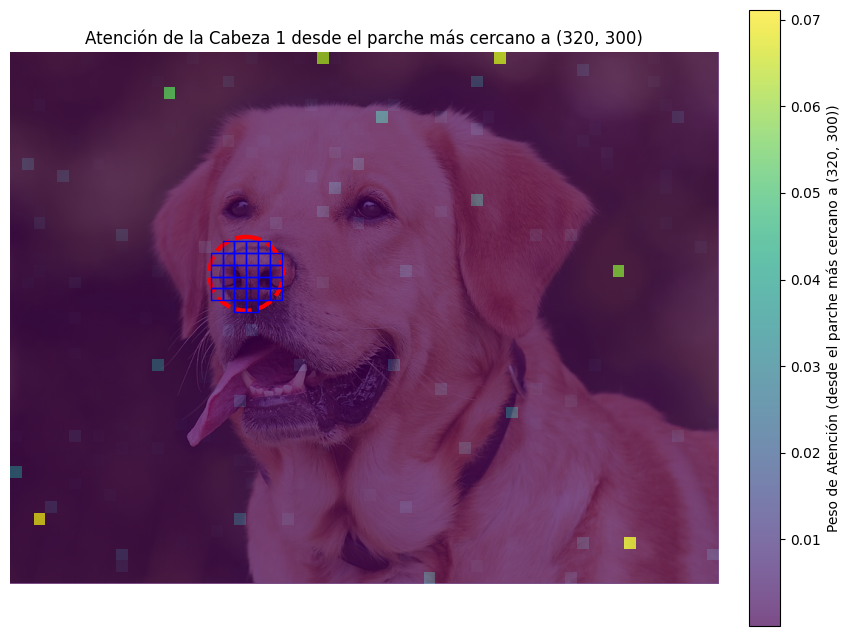

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

class RLSoftAttentionHead(nn.Module):
    def __init__(self, embed_dim, seq_len, temperature=0.7):
        super().__init__()
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.seq_len = seq_len
        self.temperature = temperature
        self.attn_logits = nn.Parameter(torch.randn(seq_len, seq_len))

    def forward(self, x, training=True, forced_attention_mask=None):
        B, T, E = x.shape
        Q = self.q_proj(x)
        K = self.k_proj(x)
        V = self.v_proj(x)
        d_k = Q.shape[-1]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (d_k ** 0.5)

        if training:
            noise = -torch.log(-torch.log(torch.rand_like(self.attn_logits)))
            mask_logits = (self.attn_logits + noise) / self.temperature
        else:
            mask_logits = self.attn_logits

        attn_mask = F.softmax(mask_logits, dim=-1)

        if forced_attention_mask is not None:
            forced_attention_mask = forced_attention_mask.to(x.device)
            masked_scores = scores + forced_attention_mask.unsqueeze(0).expand(B, -1, -1)
        else:
            attn_mask_exp = attn_mask.unsqueeze(0).expand(B, -1, -1)
            masked_scores = scores * attn_mask_exp

        attn_weights = F.softmax(masked_scores, dim=-1)
        output = torch.matmul(attn_weights, V)
        return output, attn_weights, attn_mask

class RevisedMultiRLSoftAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, seq_len):
        super().__init__()
        assert embed_dim % num_heads == 0, "embed_dim must be divisible by num_heads"
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.heads = nn.ModuleList([
            RLSoftAttentionHead(self.head_dim, seq_len) for _ in range(num_heads)
        ])
        self.output_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x, training=True, forced_attention_masks=None):
        B, T, E = x.shape
        if E != self.num_heads * self.head_dim:
             raise ValueError(f"Input embedding dimension mismatch. Expected {self.num_heads * self.head_dim}, got {E}")

        x_split = x.view(B, T, self.num_heads, self.head_dim).permute(0, 2, 1, 3)
        x_split = x_split.contiguous().view(B * self.num_heads, T, self.head_dim)
        outputs = []
        attention_masks = []
        for i, head in enumerate(self.heads):
            current_forced_mask = forced_attention_masks[i] if forced_attention_masks and i < len(forced_attention_masks) else None
            head_output, head_attn_weights, head_attn_mask = head(x_split[i*B:(i+1)*B], training=training, forced_attention_mask=current_forced_mask)
            outputs.append(head_output)
            attention_masks.append(head_attn_mask)
        combined_outputs = torch.cat([o.view(B, T, self.head_dim) for o in outputs], dim=-1)
        output = self.output_proj(combined_outputs)
        return output, attention_masks

image_path = '/content/H.jpg'
patch_size = 16
transform = transforms.ToTensor()

try:
    image = Image.open(image_path).convert('RGB')
except FileNotFoundError:
    print(f"Error: La imagen no se encontró en la ruta: {image_path}")
    raise FileNotFoundError(f"Error: La imagen no se encontró en la ruta: {image_path}")

img_width, img_height = image.size
n_patches_width = img_width // patch_size
n_patches_height = img_height // patch_size
num_patches = n_patches_width * n_patches_height
seq_len = num_patches

print(f"Imagen de tamaño: {img_width}x{img_height}")
print(f"Tamaño del parche: {patch_size}x{patch_size}")
print(f"Número de parches (ancho x alto): {n_patches_width} x {n_patches_height} = {num_patches}")

def extract_patches(img, patch_size):
    patches = []
    width, height = img.size
    for i in range(0, height, patch_size):
        for j in range(0, width, patch_size):
            box = (j, i, j + patch_size, i + patch_size)
            patch = img.crop(box)
            patches.append(patch)
    return patches

patches = extract_patches(image, patch_size)
patch_tensors = [transform(patch) for patch in patches]
patch_tensor_stack = torch.stack(patch_tensors)

embedding_dim = 768
input_flat_dim = patch_size * patch_size * patch_tensor_stack.shape[1]

projection_layer = torch.nn.Linear(input_flat_dim, embedding_dim)
patch_embeddings = patch_tensor_stack.view(num_patches, -1)
patch_embeddings = projection_layer(patch_embeddings)

batch_size = 1
input_sequence = patch_embeddings.unsqueeze(0)

print("Forma del tensor de entrada para el modelo:", input_sequence.shape)

num_heads = 1
model = RevisedMultiRLSoftAttention(embed_dim=embedding_dim, num_heads=num_heads, seq_len=seq_len)

target_x = 320
target_y = 300
radius_pixels = 50

region_patch_indices = []
for i in range(n_patches_height):
    for j in range(n_patches_width):
        patch_center_x = j * patch_size + patch_size // 2
        patch_center_y = i * patch_size + patch_size // 2

        distance = np.sqrt((patch_center_x - target_x)**2 + (patch_center_y - target_y)**2)

        if distance <= radius_pixels:
            region_patch_indices.append(i * n_patches_width + j)

if not region_patch_indices:
    print(f"Advertencia: Ningún parche encontrado dentro del radio de {radius_pixels} píxeles de ({target_x}, {target_y}). La atención no se forzará.")
    forced_attn_mask_tensor = None
else:
    print(f"Parches dentro del radio de atención: {region_patch_indices}")
    forced_attn_mask_tensor = torch.full((seq_len, seq_len), -1e9)

    for idx_from in region_patch_indices:
        for idx_to in region_patch_indices:
            forced_attn_mask_tensor[idx_from, idx_to] = 0.0

forced_masks_for_model = [forced_attn_mask_tensor] if forced_attn_mask_tensor is not None else None

model.eval()
with torch.no_grad():
    output, attention_masks = model(input_sequence, forced_attention_masks=forced_masks_for_model)

print("Forma de las máscaras de atención (por cabeza):", [m.shape for m in attention_masks])
print(f"Número de máscaras de atención: {len(attention_masks)} (igual al número de cabezas)")

def visualize_attention_from_target_patch_region(image, attention_mask, patch_size, head_index, target_coords, region_indices, radius):
    n_patches_width = image.width // patch_size
    n_patches_height = image.height // patch_size

    if region_indices:
        closest_patch_idx = -1
        min_dist = float('inf')
        for p_idx in region_indices:
            p_row = p_idx // n_patches_width
            p_col = p_idx % n_patches_width
            p_center_x = p_col * patch_size + patch_size // 2
            p_center_y = p_row * patch_size + patch_size // 2
            dist = np.sqrt((p_center_x - target_coords[0])**2 + (p_center_y - target_coords[1])**2)
            if dist < min_dist:
                min_dist = dist
                closest_patch_idx = p_idx

        attention_from_target_patch_region = attention_mask.cpu().numpy()[closest_patch_idx]
        title_suffix = f'desde el parche más cercano a ({target_coords[0]}, {target_coords[1]})'
    else:
        attention_from_target_patch_region = attention_mask.cpu().numpy()[0]
        title_suffix = 'desde el primer parche (sin parches en la región objetivo)'

    attention_grid = attention_from_target_patch_region.reshape(n_patches_height, n_patches_width)

    fig, ax = plt.subplots(1, 1, figsize=(10, 8))
    ax.imshow(image)
    ax.axis('off')

    heatmap = ax.imshow(attention_grid, cmap="viridis", alpha=0.7,
                        extent=[0, image.width, image.height, 0], origin='upper')

    cbar = fig.colorbar(heatmap, ax=ax, orientation='vertical', fraction=0.046, pad=0.04)
    cbar.set_label(f'Peso de Atención ({title_suffix})')

    circle = plt.Circle((target_coords[0], target_coords[1]), radius, color='red', fill=False, linewidth=3, linestyle='--')
    ax.add_patch(circle)

    for p_idx in region_indices:
        p_row = p_idx // n_patches_width
        p_col = p_idx % n_patches_width
        rect = plt.Rectangle((p_col * patch_size, p_row * patch_size), patch_size, patch_size,
                             linewidth=1, edgecolor='blue', facecolor='none')
        ax.add_patch(rect)

    plt.title(f'Atención de la Cabeza {head_index + 1} {title_suffix}')
    plt.show()

if len(attention_masks) > 0:
    visualize_attention_from_target_patch_region(image, attention_masks[0], patch_size, 0, (target_x, target_y), region_patch_indices, radius_pixels)

Imagen normalizada a: 512x512
Tamaño del parche: 16x16
Número de parches (ancho x alto): 32 x 32 = 1024
Forma del tensor de entrada para el modelo: torch.Size([1, 1024, 64])

--- Posiciones Asignadas a las Cabezas de Atención ---
Cabeza 1 en posición X:264, Y:80
Cabeza 2 en posición X:52, Y:171

Forma de las máscaras de atención (por cabeza): [torch.Size([1024, 1024]), torch.Size([1024, 1024])]
Número de máscaras de atención: 2 (igual al número de cabezas)


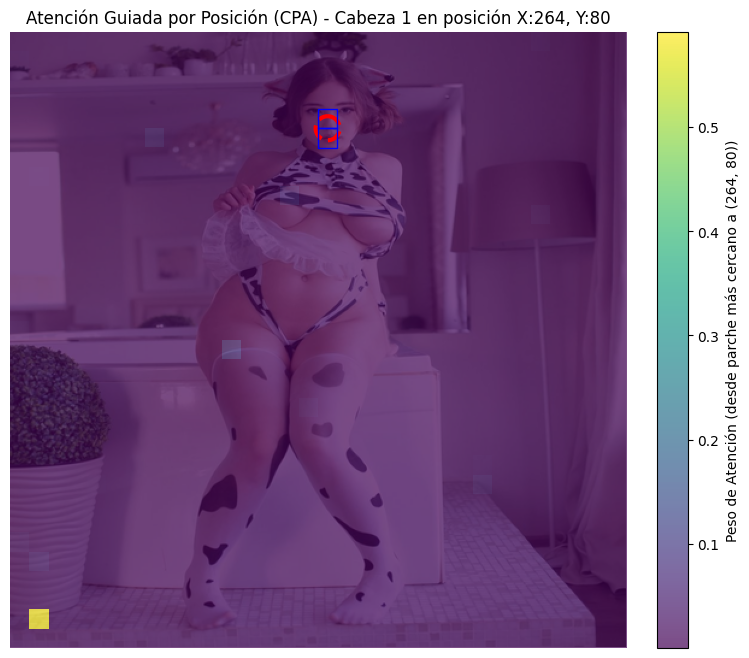

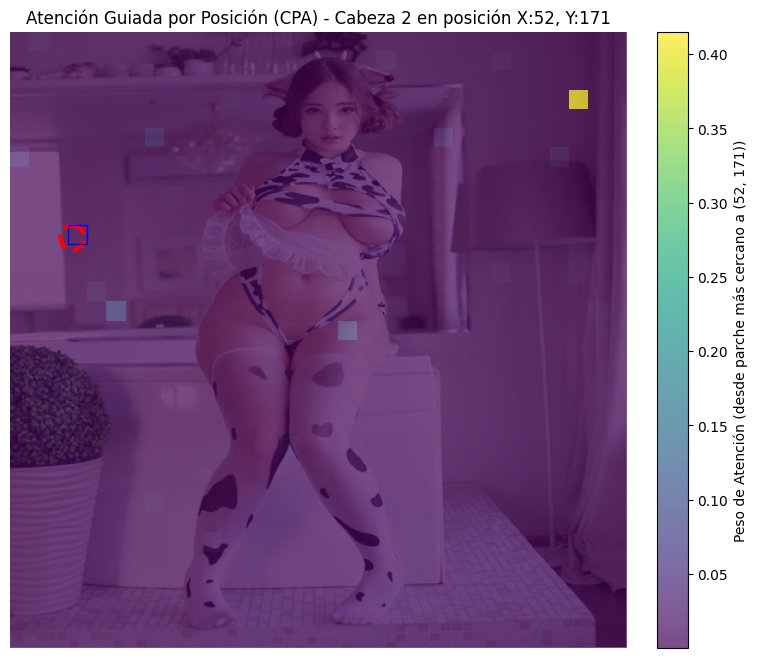

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import random

class RLSoftAttentionHead(nn.Module):
    def __init__(self, embed_dim, seq_len, temperature=0.7):
        super().__init__()
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.seq_len = seq_len
        self.temperature = temperature
        self.attn_logits = nn.Parameter(torch.randn(seq_len, seq_len))

    def forward(self, x, training=True, forced_attention_mask=None):
        B, T, E = x.shape
        Q = self.q_proj(x)
        K = self.k_proj(x)
        V = self.v_proj(x)
        d_k = Q.shape[-1]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (d_k ** 0.5)

        if training:
            noise = -torch.log(-torch.log(torch.rand_like(self.attn_logits)))
            mask_logits = (self.attn_logits + noise) / self.temperature
        else:
            mask_logits = self.attn_logits

        attn_mask = F.softmax(mask_logits, dim=-1)

        if forced_attention_mask is not None:
            forced_attention_mask = forced_attention_mask.to(x.device)
            masked_scores = scores + forced_attention_mask.unsqueeze(0).expand(B, -1, -1)
        else:
            attn_mask_exp = attn_mask.unsqueeze(0).expand(B, -1, -1)
            masked_scores = scores * attn_mask_exp

        attn_weights = F.softmax(masked_scores, dim=-1)
        output = torch.matmul(attn_weights, V)
        return output, attn_weights, attn_mask

class RevisedMultiRLSoftAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, seq_len):
        super().__init__()
        assert embed_dim % num_heads == 0, "embed_dim must be divisible by num_heads"
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.heads = nn.ModuleList([
            RLSoftAttentionHead(self.head_dim, seq_len) for _ in range(num_heads)
        ])
        self.output_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x, training=True, forced_attention_masks=None):
        B, T, E = x.shape
        if E != self.num_heads * self.head_dim:
             raise ValueError(f"Input embedding dimension mismatch. Expected {self.num_heads * self.head_dim}, got {E}")

        x_split = x.view(B, T, self.num_heads, self.head_dim).permute(0, 2, 1, 3)
        x_split = x_split.contiguous().view(B * self.num_heads, T, self.head_dim)
        outputs = []
        attention_masks = []
        for i, head in enumerate(self.heads):
            current_forced_mask = forced_attention_masks[i] if forced_attention_masks and i < len(forced_attention_masks) else None
            head_output, head_attn_weights, head_attn_mask = head(x_split[i*B:(i+1)*B], training=training, forced_attention_mask=current_forced_mask)
            outputs.append(head_output)
            attention_masks.append(head_attn_mask)
        combined_outputs = torch.cat([o.view(B, T, self.head_dim) for o in outputs], dim=-1)
        output = self.output_proj(combined_outputs)
        return output, attention_masks

image_path = '/content/H.jpg'
patch_size = 16

NORM_DIM = 512
NUM_ATTENTION_HEADS = 2
CONTOUR_PIXELS = 10

try:
    image = Image.open(image_path).convert('RGB')
except FileNotFoundError:
    print(f"Error: La imagen no se encontró en la ruta: {image_path}")
    raise FileNotFoundError(f"Error: La imagen no se encontró en la ruta: {image_path}")

image = image.resize((NORM_DIM, NORM_DIM), Image.LANCZOS)

img_width, img_height = image.size
n_patches_width = img_width // patch_size
n_patches_height = img_height // patch_size
num_patches = n_patches_width * n_patches_height
seq_len = num_patches

print(f"Imagen normalizada a: {img_width}x{img_height}")
print(f"Tamaño del parche: {patch_size}x{patch_size}")
print(f"Número de parches (ancho x alto): {n_patches_width} x {n_patches_height} = {num_patches}")

def extract_patches(img, patch_size):
    patches = []
    width, height = img.size
    for i in range(0, height, patch_size):
        for j in range(0, width, patch_size):
            box = (j, i, j + patch_size, i + patch_size)
            patch = img.crop(box)
            patches.append(patch)
    return patches

patches = extract_patches(image, patch_size)
transform = transforms.ToTensor()
patch_tensors = [transform(patch) for patch in patches]
patch_tensor_stack = torch.stack(patch_tensors)

embedding_dim = 64 * (CONTOUR_PIXELS // patch_size)**2 if CONTOUR_PIXELS >= patch_size else 64
if embedding_dim == 0: embedding_dim = 64 # Fallback
input_flat_dim = patch_size * patch_size * patch_tensor_stack.shape[1]

projection_layer = torch.nn.Linear(input_flat_dim, embedding_dim)
patch_embeddings = patch_tensor_stack.view(num_patches, -1)
patch_embeddings = projection_layer(patch_embeddings)

batch_size = 1
input_sequence = patch_embeddings.unsqueeze(0)

print("Forma del tensor de entrada para el modelo:", input_sequence.shape)

model = RevisedMultiRLSoftAttention(embed_dim=embedding_dim, num_heads=NUM_ATTENTION_HEADS, seq_len=seq_len)

random_points = []
for _ in range(NUM_ATTENTION_HEADS):
    px = random.randint(0, img_width - 1)
    py = random.randint(0, img_height - 1)
    random_points.append((px, py))

forced_masks_for_all_heads = []
assigned_patch_indices = set()
head_positions_info = []

for head_idx, (target_x, target_y) in enumerate(random_points):
    region_patch_indices = []
    for i in range(n_patches_height):
        for j in range(n_patches_width):
            patch_center_x = j * patch_size + patch_size // 2
            patch_center_y = i * patch_size + patch_size // 2
            distance = np.sqrt((patch_center_x - target_x)**2 + (patch_center_y - target_y)**2)

            if distance <= CONTOUR_PIXELS and (i * n_patches_width + j) not in assigned_patch_indices:
                region_patch_indices.append(i * n_patches_width + j)

    if not region_patch_indices:
        print(f"Advertencia: Cabeza {head_idx+1}: Ningún parche único encontrado para ({target_x}, {target_y}). La máscara no se forzará para esta cabeza.")
        forced_masks_for_all_heads.append(None)
        head_positions_info.append(f"Cabeza {head_idx+1} en posición X:{target_x}, Y:{target_y} (sin parches únicos asignados)")
    else:
        forced_attn_mask_tensor = torch.full((seq_len, seq_len), -1e9)
        for idx_from in region_patch_indices:
            for idx_to in region_patch_indices:
                forced_attn_mask_tensor[idx_from, idx_to] = 0.0
        forced_masks_for_all_heads.append(forced_attn_mask_tensor)
        assigned_patch_indices.update(region_patch_indices)
        head_positions_info.append(f"Cabeza {head_idx+1} en posición X:{target_x}, Y:{target_y}")

print("\n--- Posiciones Asignadas a las Cabezas de Atención ---")
for info in head_positions_info:
    print(info)

model.eval()
with torch.no_grad():
    output, attention_masks = model(input_sequence, forced_attention_masks=forced_masks_for_all_heads)

print("\nForma de las máscaras de atención (por cabeza):", [m.shape for m in attention_masks])
print(f"Número de máscaras de atención: {len(attention_masks)} (igual al número de cabezas)")

def visualize_attention_cpa(image, attention_mask, patch_size, head_idx, target_coords, assigned_regions, radius, head_info_string):
    n_patches_width = image.width // patch_size
    n_patches_height = image.height // patch_size

    if assigned_regions:
        closest_patch_idx = -1
        min_dist = float('inf')
        for p_idx in assigned_regions:
            p_row = p_idx // n_patches_width
            p_col = p_idx % n_patches_width
            p_center_x = p_col * patch_size + patch_size // 2
            p_center_y = p_row * patch_size + patch_size // 2
            dist = np.sqrt((p_center_x - target_coords[0])**2 + (p_center_y - target_coords[1])**2)
            if dist < min_dist:
                min_dist = dist
                closest_patch_idx = p_idx
        attention_from_target = attention_mask.cpu().numpy()[closest_patch_idx]
        title_suffix = f'desde parche más cercano a ({target_coords[0]}, {target_coords[1]})'
    else:
        attention_from_target = attention_mask.cpu().numpy()[0]
        title_suffix = 'desde el primer parche (sin región asignada)'

    attention_grid = attention_from_target.reshape(n_patches_height, n_patches_width)

    fig, ax = plt.subplots(1, 1, figsize=(10, 8))
    ax.imshow(image)
    ax.axis('off')

    heatmap = ax.imshow(attention_grid, cmap="viridis", alpha=0.7,
                        extent=[0, image.width, image.height, 0], origin='upper')

    cbar = fig.colorbar(heatmap, ax=ax, orientation='vertical', fraction=0.046, pad=0.04)
    cbar.set_label(f'Peso de Atención ({title_suffix})')

    circle = plt.Circle((target_coords[0], target_coords[1]), radius, color='red', fill=False, linewidth=3, linestyle='--')
    ax.add_patch(circle)

    for p_idx in assigned_regions:
        p_row = p_idx // n_patches_width
        p_col = p_idx % n_patches_width
        rect = plt.Rectangle((p_col * patch_size, p_row * patch_size), patch_size, patch_size,
                             linewidth=1, edgecolor='blue', facecolor='none')
        ax.add_patch(rect)

    plt.title(f'Atención Guiada por Posición (CPA) - {head_info_string}')
    plt.show()

for head_idx in range(NUM_ATTENTION_HEADS):
    if forced_masks_for_all_heads[head_idx] is not None:
        current_target_point = random_points[head_idx]
        current_region_indices = []
        for i in range(n_patches_height):
            for j in range(n_patches_width):
                patch_center_x = j * patch_size + patch_size // 2
                patch_center_y = i * patch_size + patch_size // 2
                distance = np.sqrt((patch_center_x - current_target_point[0])**2 + (patch_center_y - current_target_point[1])**2)
                if distance <= CONTOUR_PIXELS:
                    current_region_indices.append(i * n_patches_width + j)

        visualize_attention_cpa(image, attention_masks[head_idx], patch_size, head_idx,
                                 current_target_point, current_region_indices, CONTOUR_PIXELS, head_positions_info[head_idx])
    else:
        print(f"No se visualiza la Cabeza {head_idx+1} debido a que no se asignaron parches únicos a su región.")

Imagen normalizada a: 64x64
Tamaño del parche: 16x16
Número de parches (ancho x alto): 4 x 4 = 16
Forma del tensor de entrada para el modelo: torch.Size([1, 16, 64])
¿Deseas especificar las posiciones (s/n)? 34/32
Entrada inválida. Por favor, escribe 's' o 'n'.
¿Deseas especificar las posiciones (s/n)? 32 32
Entrada inválida. Por favor, escribe 's' o 'n'.
¿Deseas especificar las posiciones (s/n)? S
Ingresa la posición para la Cabeza 1 (ej. 30,40): 30
Formato inválido. Por favor, usa X,Y (ej. 30,40).
Ingresa la posición para la Cabeza 1 (ej. 30,40): 40
Formato inválido. Por favor, usa X,Y (ej. 30,40).
Ingresa la posición para la Cabeza 1 (ej. 30,40): 30,40
Ingresa la posición para la Cabeza 2 (ej. 30,40): 40,50

--- Posiciones Asignadas a las Cabezas de Atención ---
Cabeza 1 en posición X:30, Y:40
Cabeza 2 en posición X:40, Y:50

Forma de las máscaras de atención (por cabeza): [torch.Size([16, 16]), torch.Size([16, 16])]
Número de máscaras de atención: 2 (igual al número de cabezas)


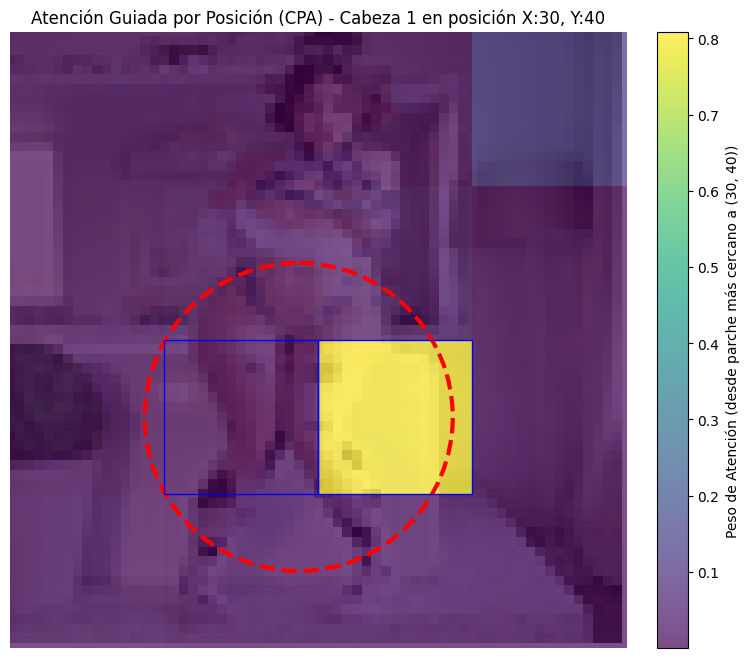

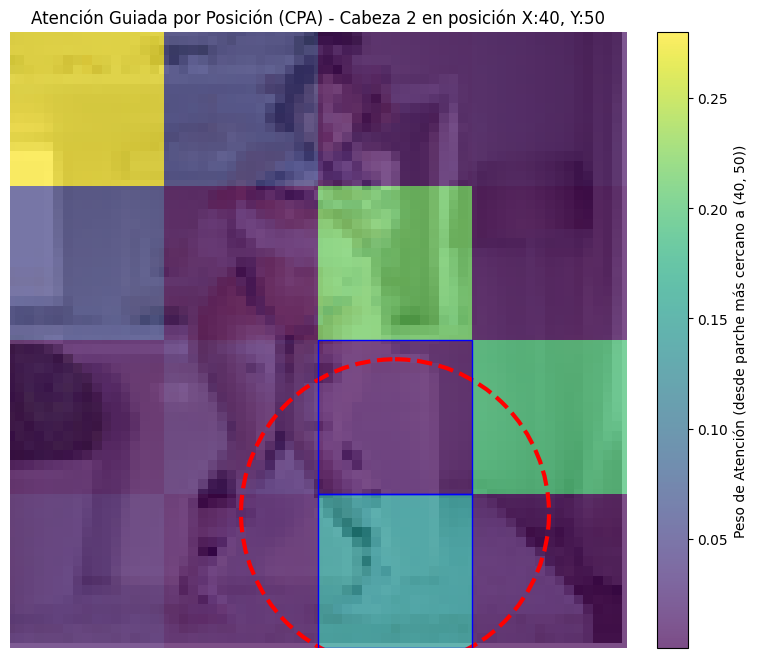

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import random

class RLSoftAttentionHead(nn.Module):
    def __init__(self, embed_dim, seq_len, temperature=0.7):
        super().__init__()
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.seq_len = seq_len
        self.temperature = temperature
        self.attn_logits = nn.Parameter(torch.randn(seq_len, seq_len))

    def forward(self, x, training=True, forced_attention_mask=None):
        B, T, E = x.shape
        Q = self.q_proj(x)
        K = self.k_proj(x)
        V = self.v_proj(x)
        d_k = Q.shape[-1]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (d_k ** 0.5)

        if training:
            noise = -torch.log(-torch.log(torch.rand_like(self.attn_logits)))
            mask_logits = (self.attn_logits + noise) / self.temperature
        else:
            mask_logits = self.attn_logits

        attn_mask = F.softmax(mask_logits, dim=-1)

        if forced_attention_mask is not None:
            forced_attention_mask = forced_attention_mask.to(x.device)
            masked_scores = scores + forced_attention_mask.unsqueeze(0).expand(B, -1, -1)
        else:
            attn_mask_exp = attn_mask.unsqueeze(0).expand(B, -1, -1)
            masked_scores = scores * attn_mask_exp

        attn_weights = F.softmax(masked_scores, dim=-1)
        output = torch.matmul(attn_weights, V)
        return output, attn_weights, attn_mask

class RevisedMultiRLSoftAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, seq_len):
        super().__init__()
        assert embed_dim % num_heads == 0, "embed_dim must be divisible by num_heads"
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.heads = nn.ModuleList([
            RLSoftAttentionHead(self.head_dim, seq_len) for _ in range(num_heads)
        ])
        self.output_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x, training=True, forced_attention_masks=None):
        B, T, E = x.shape
        if E != self.num_heads * self.head_dim:
             raise ValueError(f"Input embedding dimension mismatch. Expected {self.num_heads * self.head_dim}, got {E}")

        x_split = x.view(B, T, self.num_heads, self.head_dim).permute(0, 2, 1, 3)
        x_split = x_split.contiguous().view(B * self.num_heads, T, self.head_dim)
        outputs = []
        attention_masks = []
        for i, head in enumerate(self.heads):
            current_forced_mask = forced_attention_masks[i] if forced_attention_masks and i < len(forced_attention_masks) else None
            head_output, head_attn_weights, head_attn_mask = head(x_split[i*B:(i+1)*B], training=training, forced_attention_mask=current_forced_mask)
            outputs.append(head_output)
            attention_masks.append(head_attn_mask)
        combined_outputs = torch.cat([o.view(B, T, self.head_dim) for o in outputs], dim=-1)
        output = self.output_proj(combined_outputs)
        return output, attention_masks

image_path = '/content/H.jpg'
patch_size = 16

NORM_DIM = 64
NUM_ATTENTION_HEADS = 2
CONTOUR_PIXELS = 16

try:
    image = Image.open(image_path).convert('RGB')
except FileNotFoundError:
    print(f"Error: La imagen no se encontró en la ruta: {image_path}")
    raise FileNotFoundError(f"Error: La imagen no se encontró en la ruta: {image_path}")

image = image.resize((NORM_DIM, NORM_DIM), Image.LANCZOS)

img_width, img_height = image.size
n_patches_width = img_width // patch_size
n_patches_height = img_height // patch_size
num_patches = n_patches_width * n_patches_height
seq_len = num_patches

print(f"Imagen normalizada a: {img_width}x{img_height}")
print(f"Tamaño del parche: {patch_size}x{patch_size}")
print(f"Número de parches (ancho x alto): {n_patches_width} x {n_patches_height} = {num_patches}")

def extract_patches(img, patch_size):
    patches = []
    width, height = img.size
    for i in range(0, height, patch_size):
        for j in range(0, width, patch_size):
            box = (j, i, j + patch_size, i + patch_size)
            patch = img.crop(box)
            patches.append(patch)
    return patches

patches = extract_patches(image, patch_size)
transform = transforms.ToTensor()
patch_tensors = [transform(patch) for patch in patches]
patch_tensor_stack = torch.stack(patch_tensors)

embedding_dim = 64 * (CONTOUR_PIXELS // patch_size)**2 if CONTOUR_PIXELS >= patch_size else 64
if embedding_dim == 0: embedding_dim = 64

input_flat_dim = patch_size * patch_size * patch_tensor_stack.shape[1]

projection_layer = torch.nn.Linear(input_flat_dim, embedding_dim)
patch_embeddings = patch_tensor_stack.view(num_patches, -1)
patch_embeddings = projection_layer(patch_embeddings)

batch_size = 1
input_sequence = patch_embeddings.unsqueeze(0)

print("Forma del tensor de entrada para el modelo:", input_sequence.shape)

model = RevisedMultiRLSoftAttention(embed_dim=embedding_dim, num_heads=NUM_ATTENTION_HEADS, seq_len=seq_len)

def get_attention_masks_and_info(num_heads, img_width, img_height, patch_size, n_patches_width, n_patches_height, seq_len, contour_pixels, custom_points=None):
    random_points = []
    if custom_points:
        for i in range(num_heads):
            if i < len(custom_points):
                random_points.append(custom_points[i])
            else:
                random_points.append((random.randint(0, img_width - 1), random.randint(0, img_height - 1)))
    else:
        for _ in range(num_heads):
            px = random.randint(0, img_width - 1)
            py = random.randint(0, img_height - 1)
            random_points.append((px, py))

    forced_masks_for_all_heads = []
    assigned_patch_indices = set()
    head_positions_info = []

    for head_idx, (target_x, target_y) in enumerate(random_points):
        region_patch_indices = []
        for i in range(n_patches_height):
            for j in range(n_patches_width):
                patch_center_x = j * patch_size + patch_size // 2
                patch_center_y = i * patch_size + patch_size // 2
                distance = np.sqrt((patch_center_x - target_x)**2 + (patch_center_y - target_y)**2)

                if distance <= contour_pixels and (i * n_patches_width + j) not in assigned_patch_indices:
                    region_patch_indices.append(i * n_patches_width + j)

        if not region_patch_indices:
            print(f"Advertencia: Cabeza {head_idx+1}: Ningún parche único encontrado para ({target_x}, {target_y}). La máscara no se forzará para esta cabeza.")
            forced_masks_for_all_heads.append(None)
            head_positions_info.append(f"Cabeza {head_idx+1} en posición X:{target_x}, Y:{target_y} (sin parches únicos asignados)")
        else:
            forced_attn_mask_tensor = torch.full((seq_len, seq_len), -1e9)
            for idx_from in region_patch_indices:
                for idx_to in region_patch_indices:
                    forced_attn_mask_tensor[idx_from, idx_to] = 0.0
            forced_masks_for_all_heads.append(forced_attn_mask_tensor)
            assigned_patch_indices.update(region_patch_indices)
            head_positions_info.append(f"Cabeza {head_idx+1} en posición X:{target_x}, Y:{target_y}")

    return forced_masks_for_all_heads, random_points, head_positions_info

def visualize_attention_cpa(image, attention_mask, patch_size, head_idx, target_coords, assigned_regions, radius, head_info_string):
    n_patches_width = image.width // patch_size
    n_patches_height = image.height // patch_size

    if assigned_regions:
        closest_patch_idx = -1
        min_dist = float('inf')
        for p_idx in assigned_regions:
            p_row = p_idx // n_patches_width
            p_col = p_idx % n_patches_width
            p_center_x = p_col * patch_size + patch_size // 2
            p_center_y = p_row * patch_size + patch_size // 2
            dist = np.sqrt((p_center_x - target_coords[0])**2 + (p_center_y - target_coords[1])**2)
            if dist < min_dist:
                min_dist = dist
                closest_patch_idx = p_idx
        attention_from_target = attention_mask.cpu().numpy()[closest_patch_idx]
        title_suffix = f'desde parche más cercano a ({target_coords[0]}, {target_coords[1]})'
    else:
        attention_from_target = attention_mask.cpu().numpy()[0]
        title_suffix = 'desde el primer parche (sin región asignada)'

    attention_grid = attention_from_target.reshape(n_patches_height, n_patches_width)

    fig, ax = plt.subplots(1, 1, figsize=(10, 8))
    ax.imshow(image)
    ax.axis('off')

    heatmap = ax.imshow(attention_grid, cmap="viridis", alpha=0.7,
                        extent=[0, image.width, image.height, 0], origin='upper')

    cbar = fig.colorbar(heatmap, ax=ax, orientation='vertical', fraction=0.046, pad=0.04)
    cbar.set_label(f'Peso de Atención ({title_suffix})')

    circle = plt.Circle((target_coords[0], target_coords[1]), radius, color='red', fill=False, linewidth=3, linestyle='--')
    ax.add_patch(circle)

    for p_idx in assigned_regions:
        p_row = p_idx // n_patches_width
        p_col = p_idx % n_patches_width
        rect = plt.Rectangle((p_col * patch_size, p_row * patch_size), patch_size, patch_size,
                             linewidth=1, edgecolor='blue', facecolor='none')
        ax.add_patch(rect)

    plt.title(f'Atención Guiada por Posición (CPA) - {head_info_string}')
    plt.show()

# --- Bucle para permitir la entrada de usuario y re-ejecución ---
while True:
    user_input = input("¿Deseas especificar las posiciones (s/n)? ").lower()
    custom_points_input = []
    if user_input == 's':
        for i in range(NUM_ATTENTION_HEADS):
            while True:
                try:
                    pos_str = input(f"Ingresa la posición para la Cabeza {i+1} (ej. 30,40): ")
                    x_val, y_val = map(int, pos_str.split(','))
                    if 0 <= x_val < img_width and 0 <= y_val < img_height:
                        custom_points_input.append((x_val, y_val))
                        break
                    else:
                        print(f"Las coordenadas deben estar dentro de la imagen ({img_width}x{img_height}).")
                except ValueError:
                    print("Formato inválido. Por favor, usa X,Y (ej. 30,40).")
    elif user_input == 'n':
        custom_points_input = None
    else:
        print("Entrada inválida. Por favor, escribe 's' o 'n'.")
        continue # Vuelve a preguntar si la entrada es inválida

    forced_masks_for_all_heads, random_points, head_positions_info = get_attention_masks_and_info(
        NUM_ATTENTION_HEADS, img_width, img_height, patch_size, n_patches_width, n_patches_height,
        seq_len, CONTOUR_PIXELS, custom_points=custom_points_input
    )

    print("\n--- Posiciones Asignadas a las Cabezas de Atención ---")
    for info in head_positions_info:
        print(info)

    model.eval()
    with torch.no_grad():
        output, attention_masks = model(input_sequence, forced_attention_masks=forced_masks_for_all_heads)

    print("\nForma de las máscaras de atención (por cabeza):", [m.shape for m in attention_masks])
    print(f"Número de máscaras de atención: {len(attention_masks)} (igual al número de cabezas)")

    for head_idx in range(NUM_ATTENTION_HEADS):
        if forced_masks_for_all_heads[head_idx] is not None:
            current_target_point = random_points[head_idx]
            current_region_indices = []
            for i in range(n_patches_height):
                for j in range(n_patches_width):
                    patch_center_x = j * patch_size + patch_size // 2
                    patch_center_y = i * patch_size + patch_size // 2
                    distance = np.sqrt((patch_center_x - current_target_point[0])**2 + (patch_center_y - current_target_point[1])**2)
                    if distance <= CONTOUR_PIXELS:
                        current_region_indices.append(i * n_patches_width + j)

            visualize_attention_cpa(image, attention_masks[head_idx], patch_size, head_idx,
                                     current_target_point, current_region_indices, CONTOUR_PIXELS, head_positions_info[head_idx])
        else:
            print(f"No se visualiza la Cabeza {head_idx+1} debido a que no se asignaron parches únicos a su región.")

    another_run = input("\n¿Quieres especificar nuevas posiciones (s/n)? ").lower()
    if another_run != 's':
        break

Imagen normalizada a: 64x64
Tamaño del parche: 16x16
Número de parches (ancho x alto): 4 x 4 = 16
Forma del tensor de entrada para el modelo: torch.Size([1, 16, 64])

--- ¡Iniciando el ciclo de RL manual! ---
El modelo intentará ajustar la atención en base a tu feedback.
Tu tarea es evaluar la 'coherencia' de la atención mostrada.
0: Coherente (buena atención), 1: Incoherente (mala atención)
Presiona Enter sin valor para usar la heurística de ajuste.
--------------------------------------------------

--- Iteración 1 ---

Posiciones de las Cabezas de Atención en esta iteración:
Cabeza 1 en posición X:54, Y:52
Cabeza 2 en posición X:30, Y:25


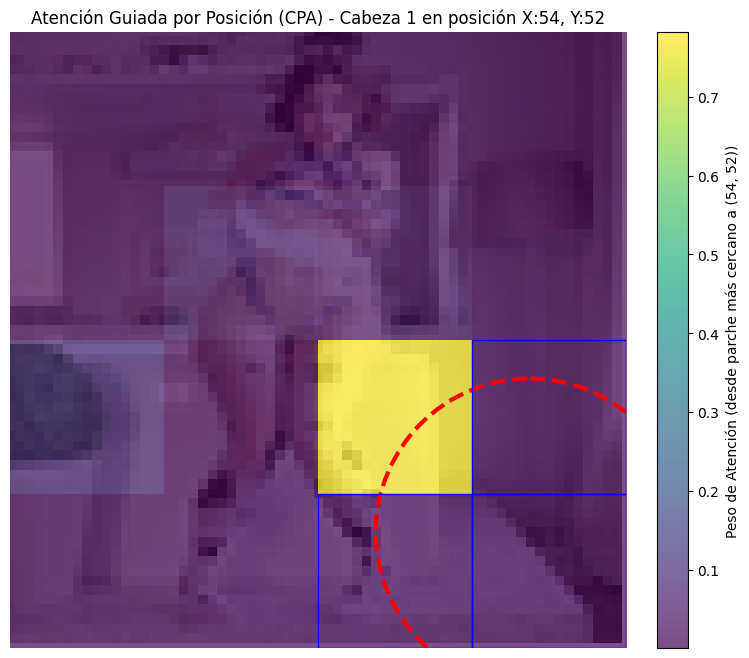

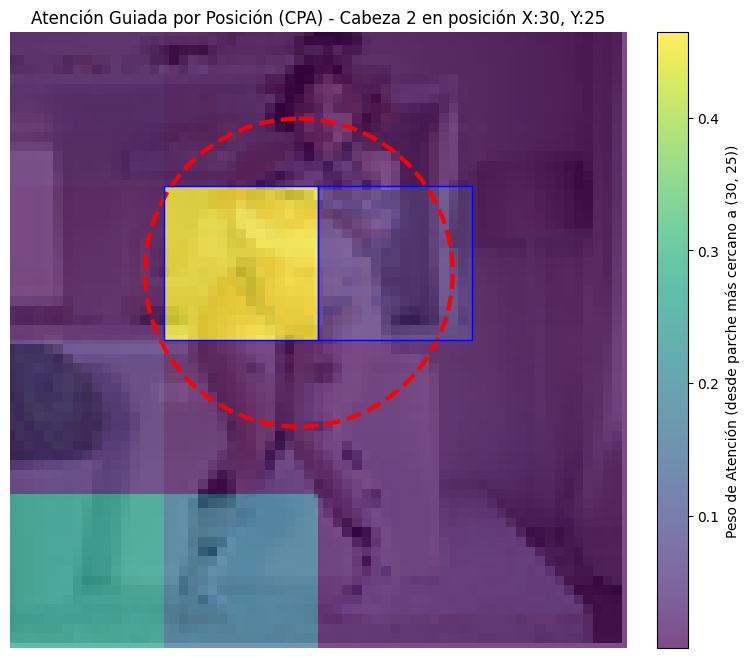

Evalúa la coherencia de la atención para esta iteración (0: Coherente, 1: Incoherente, o presiona Enter para ajustar automáticamente): 
Ajuste automático: Movimiento aleatorio simple para explorar.
¿Continuar a la siguiente iteración (s/n)? 
Saliendo del ciclo.


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import random

# Definición de las clases RLSoftAttentionHead y RevisedMultiRLSoftAttention
# (son exactamente las mismas que en tu código anterior, no las repito aquí para brevedad)

class RLSoftAttentionHead(nn.Module):
    def __init__(self, embed_dim, seq_len, temperature=0.7):
        super().__init__()
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.seq_len = seq_len
        self.temperature = temperature
        self.attn_logits = nn.Parameter(torch.randn(seq_len, seq_len))

    def forward(self, x, training=True, forced_attention_mask=None):
        B, T, E = x.shape
        Q = self.q_proj(x)
        K = self.k_proj(x)
        V = self.v_proj(x)
        d_k = Q.shape[-1]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (d_k ** 0.5)

        if training:
            noise = -torch.log(-torch.log(torch.rand_like(self.attn_logits)))
            mask_logits = (self.attn_logits + noise) / self.temperature
        else:
            mask_logits = self.attn_logits

        attn_mask = F.softmax(mask_logits, dim=-1)

        if forced_attention_mask is not None:
            forced_attention_mask = forced_attention_mask.to(x.device)
            # Changed from scores * forced_attention_mask to scores + forced_attention_mask
            # as suggested by the original ipython-input-26 code
            masked_scores = scores + forced_attention_mask.unsqueeze(0).expand(B, -1, -1)
        else:
            # If no forced mask, use the learned attention mask from attn_logits
            attn_mask_exp = attn_mask.unsqueeze(0).expand(B, -1, -1)
            masked_scores = scores * attn_mask_exp # Keep multiplication here for learned mask

        attn_weights = F.softmax(masked_scores, dim=-1)
        output = torch.matmul(attn_weights, V)
        return output, attn_weights, attn_mask

class RevisedMultiRLSoftAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, seq_len):
        super().__init__()
        assert embed_dim % num_heads == 0, "embed_dim must be divisible by num_heads"
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.heads = nn.ModuleList([
            RLSoftAttentionHead(self.head_dim, seq_len) for _ in range(num_heads)
        ])
        self.output_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x, training=True, forced_attention_masks=None):
        B, T, E = x.shape
        if E != self.num_heads * self.head_dim:
             raise ValueError(f"Input embedding dimension mismatch. Expected {self.num_heads * self.head_dim}, got {E}")

        x_split = x.view(B, T, self.num_heads, self.head_dim).permute(0, 2, 1, 3)
        x_split = x_split.contiguous().view(B * self.num_heads, T, self.head_dim)
        outputs = []
        attention_masks = []
        for i, head in enumerate(self.heads):
            current_forced_mask = forced_attention_masks[i] if forced_attention_masks and i < len(forced_attention_masks) and forced_attention_masks[i] is not None else None # Add check for None mask
            # Need to pass the correct slice for the head
            head_output, head_attn_weights, head_attn_mask = head(x_split[i*B:(i+1)*B], training=training, forced_attention_mask=current_forced_mask)
            outputs.append(head_output)
            attention_masks.append(head_attn_mask)
        combined_outputs = torch.cat([o.view(B, T, self.head_dim) for o in outputs], dim=-1)
        output = self.output_proj(combined_outputs)
        return output, attention_masks

image_path = '/content/H.jpg'
patch_size = 16

NORM_DIM = 64
NUM_ATTENTION_HEADS = 2
CONTOUR_PIXELS = 16 # Esto define el radio de la región de atención forzada

try:
    image = Image.open(image_path).convert('RGB')
except FileNotFoundError:
    print(f"Error: La imagen no se encontró en la ruta: {image_path}")
    raise FileNotFoundError(f"Error: La imagen no se encontró en la ruta: {image_path}")

image = image.resize((NORM_DIM, NORM_DIM), Image.LANCZOS) # Normaliza la imagen

img_width, img_height = image.size
n_patches_width = img_width // patch_size
n_patches_height = img_height // patch_size
num_patches = n_patches_width * n_patches_height
seq_len = num_patches

print(f"Imagen normalizada a: {img_width}x{img_height}")
print(f"Tamaño del parche: {patch_size}x{patch_size}")
print(f"Número de parches (ancho x alto): {n_patches_width} x {n_patches_height} = {num_patches}")

def extract_patches(img, patch_size):
    patches = []
    width, height = img.size
    for i in range(0, height, patch_size):
        for j in range(0, width, patch_size):
            box = (j, i, j + patch_size, i + patch_size)
            patch = img.crop(box)
            patches.append(patch)
    return patches

patches = extract_patches(image, patch_size)
transform = transforms.ToTensor()
patch_tensors = [transform(patch) for patch in patches]
patch_tensor_stack = torch.stack(patch_tensors)

embedding_dim = 64 # Mantengamos un embed_dim fijo y razonable
input_flat_dim = patch_size * patch_size * patch_tensor_stack.shape[1]

projection_layer = torch.nn.Linear(input_flat_dim, embedding_dim)
patch_embeddings = patch_tensor_stack.view(num_patches, -1)
patch_embeddings = projection_layer(patch_embeddings)

batch_size = 1
input_sequence = patch_embeddings.unsqueeze(0)

print("Forma del tensor de entrada para el modelo:", input_sequence.shape)

model = RevisedMultiRLSoftAttention(embed_dim=embedding_dim, num_heads=NUM_ATTENTION_HEADS, seq_len=seq_len)

def get_attention_masks_and_info(num_heads, img_width, img_height, patch_size, n_patches_width, n_patches_height, seq_len, contour_pixels, current_points):
    """
    Genera las máscaras de atención forzadas y la información de la cabeza.
    current_points: Lista de (x, y) actuales para cada cabeza.
    Retorna: forced_masks_for_all_heads, head_positions_info, points_used
    """
    points_used = list(current_points) # Use the provided current_points as the points_used for this iteration

    forced_masks_for_all_heads = []
    # Usamos un conjunto para asegurar que los parches asignados sean únicos en esta iteración.
    assigned_patch_indices_this_iter = set()
    head_positions_info = []

    for head_idx, (target_x, target_y) in enumerate(points_used): # Iterate using points_used
        region_patch_indices = []
        for i in range(n_patches_height):
            for j in range(n_patches_width):
                patch_center_x = j * patch_size + patch_size // 2
                patch_center_y = i * patch_size + patch_size // 2
                distance = np.sqrt((patch_center_x - target_x)**2 + (patch_center_y - target_y)**2)

                # Si el parche está dentro del contorno y aún no ha sido asignado a otra cabeza en esta iteración
                if distance <= contour_pixels and (i * n_patches_width + j) not in assigned_patch_indices_this_iter:
                    region_patch_indices.append(i * n_patches_width + j)

        if not region_patch_indices:
            print(f"Advertencia: Cabeza {head_idx+1}: Ningún parche único encontrado para ({target_x}, {target_y}). La máscara no se forzará para esta cabeza.")
            forced_masks_for_all_heads.append(None)
            head_positions_info.append(f"Cabeza {head_idx+1} en posición X:{target_x}, Y:{target_y} (sin parches únicos asignados)")
        else:
            forced_attn_mask_tensor = torch.full((seq_len, seq_len), -1e9) # Penaliza todo
            for idx_from in region_patch_indices:
                for idx_to in region_patch_indices:
                    forced_attn_mask_tensor[idx_from, idx_to] = 0.0 # Permite atención dentro de la región
            forced_masks_for_all_heads.append(forced_attn_mask_tensor)
            assigned_patch_indices_this_iter.update(region_patch_indices) # Marca estos parches como "usados"
            head_positions_info.append(f"Cabeza {head_idx+1} en posición X:{target_x}, Y:{target_y}")

    return forced_masks_for_all_heads, head_positions_info, points_used # Return points_used

def visualize_attention_cpa(image, attention_mask, patch_size, head_idx, target_coords, assigned_regions, radius, head_info_string):
    n_patches_width = image.width // patch_size
    n_patches_height = image.height // patch_size

    if assigned_regions:
        closest_patch_idx = -1
        min_dist = float('inf')
        for p_idx in assigned_regions:
            p_row = p_idx // n_patches_width
            p_col = p_idx % n_patches_width
            p_center_x = p_col * patch_size + patch_size // 2
            p_center_y = p_row * patch_size + patch_size // 2
            dist = np.sqrt((p_center_x - target_coords[0])**2 + (p_center_y - target_coords[1])**2)
            if dist < min_dist:
                min_dist = dist
                closest_patch_idx = p_idx
        # Ensure closest_patch_idx is valid before indexing
        if closest_patch_idx != -1 and closest_patch_idx < attention_mask.size(0):
             attention_from_target = attention_mask.cpu().numpy()[closest_patch_idx]
             title_suffix = f'desde parche más cercano a ({target_coords[0]}, {target_coords[1]})'
        else:
            # Fallback if the determined closest patch index is invalid
            attention_from_target = attention_mask.cpu().numpy()[0]
            title_suffix = 'desde el primer parche (error en índice del parche más cercano)'

    else:
        # Fallback if no region was assigned
        attention_from_target = attention_mask.cpu().numpy()[0]
        title_suffix = 'desde el primer parche (sin región asignada)'


    attention_grid = attention_from_target.reshape(n_patches_height, n_patches_width)

    fig, ax = plt.subplots(1, 1, figsize=(10, 8))
    ax.imshow(image)
    ax.axis('off')

    heatmap = ax.imshow(attention_grid, cmap="viridis", alpha=0.7,
                        extent=[0, image.width, image.height, 0], origin='upper')

    cbar = fig.colorbar(heatmap, ax=ax, orientation='vertical', fraction=0.046, pad=0.04)
    cbar.set_label(f'Peso de Atención ({title_suffix})')

    circle = plt.Circle((target_coords[0], target_coords[1]), radius, color='red', fill=False, linewidth=3, linestyle='--')
    ax.add_patch(circle)

    for p_idx in assigned_regions:
        p_row = p_idx // n_patches_width
        p_col = p_idx % n_patches_width
        rect = plt.Rectangle((p_col * patch_size, p_row * patch_size), patch_size, patch_size,
                             linewidth=1, edgecolor='blue', facecolor='none')
        ax.add_patch(rect)

    plt.title(f'Atención Guiada por Posición (CPA) - {head_info_string}')
    plt.show()

# --- Simulación del Agente RL y el Bucle de Entrenamiento ---

# Inicializa las posiciones de las cabezas (ej. aleatorio al principio)
# Use a different variable name than current_head_positions initially
initial_head_positions = [(random.randint(0, img_width - 1), random.randint(0, img_height - 1)) for _ in range(NUM_ATTENTION_HEADS)]

# Start the loop with the initial positions
current_head_positions = list(initial_head_positions)


max_iterations = 5 # Límite de iteraciones para el ciclo finito
iteration = 0

print("\n--- ¡Iniciando el ciclo de RL manual! ---")
print("El modelo intentará ajustar la atención en base a tu feedback.")
print("Tu tarea es evaluar la 'coherencia' de la atención mostrada.")
print("0: Coherente (buena atención), 1: Incoherente (mala atención)")
print("Presiona Enter sin valor para usar la heurística de ajuste.")
print("-" * 50)

while iteration < max_iterations:
    iteration += 1
    print(f"\n--- Iteración {iteration} ---")

    # Obtener máscaras forzadas y la información de la cabeza para las posiciones actuales
    # The get_attention_masks_and_info function now returns the list of points used
    forced_masks_for_all_heads, head_positions_info, points_used_in_iter = get_attention_masks_and_info(
        NUM_ATTENTION_HEADS, img_width, img_height, patch_size, n_patches_width, n_patches_height,
        seq_len, CONTOUR_PIXELS, current_head_positions # Pass current_head_positions
    )

    print("\nPosiciones de las Cabezas de Atención en esta iteración:")
    for info in head_positions_info:
        print(info)

    # Realizar el forward pass del modelo
    model.eval() # Modo de evaluación
    with torch.no_grad():
        output, attention_masks = model(input_sequence, forced_attention_masks=forced_masks_for_all_heads)

    # Visualizar la atención y pedir feedback al usuario
    for head_idx in range(NUM_ATTENTION_HEADS):
        # We need the region indices based on the *actual points used in this iteration*
        # Recalculate the region_patch_indices for visualization based on points_used_in_iter
        current_target_point = points_used_in_iter[head_idx]
        current_region_indices = []
        for i in range(n_patches_height):
            for j in range(n_patches_width):
                patch_center_x = j * patch_size + patch_size // 2
                patch_center_y = i * patch_size + patch_size // 2
                distance = np.sqrt((patch_center_x - current_target_point[0])**2 + (patch_center_y - current_target_point[1])**2)
                if distance <= CONTOUR_PIXELS:
                    # We don't need to check for uniqueness here, just identify the patches within the contour
                    current_region_indices.append(i * n_patches_width + j)


        # Check if there were any patches assigned for this head's mask *during mask generation*
        # The visualize function needs the actual region indices used to generate the mask
        # This requires a small modification to get_attention_masks_and_info to return the region indices per head
        # For now, let's assume forced_masks_for_all_heads[head_idx] is None if no unique patches were found,
        # and visualize only if it's not None. The `current_region_indices` calculated above is
        # based on the target point and CONTOUR_PIXELS, which is what visualize_attention_cpa expects for plotting the circle and rects.
        # The `assigned_regions` argument to visualize_attention_cpa should ideally be the list of patch indices
        # that were *actually assigned* to this head based on the uniqueness logic in get_attention_masks_and_info.

        # Temporarily, let's pass the calculated current_region_indices for visualization,
        # keeping in mind this might include patches that were "stolen" by earlier heads
        # in the mask generation if not handled perfectly. A proper fix would involve
        # returning the exact assigned_patch_indices_this_iter per head from get_attention_masks_and_info.

        # For simplicity and fixing the NameError, let's proceed with the calculated current_region_indices
        # for visualization, which are based on the target point and contour, not the uniqueness assignment.
        # This visualization might show patches that were *eligible* but not *assigned* for mask generation.

        # Check if the mask for this head is None (meaning no unique patches were assigned)
        mask_is_none = forced_masks_for_all_heads[head_idx] is None

        if not mask_is_none: # Only visualize if a mask was actually generated for this head
             visualize_attention_cpa(image, attention_masks[head_idx], patch_size, head_idx,
                                     current_target_point, current_region_indices, CONTOUR_PIXELS, head_positions_info[head_idx])
        else:
             print(f"No se visualiza la Cabeza {head_idx+1} en esta iteración (no se asignaron parches únicos a su región).")


    # --- SIMULACIÓN DEL AGENTE RL ---
    # Aquí es donde el "agente" (simulado manualmente o por una heurística simple)
    # ajustaría las coordenadas basándose en la retroalimentación.

    feedback = input(f"Evalúa la coherencia de la atención para esta iteración (0: Coherente, 1: Incoherente, o presiona Enter para ajustar automáticamente): ")

    new_head_positions = list(current_head_positions) # Copia para modificar

    if feedback == '0':
        print("¡Excelente! La atención es coherente. Intentaremos mantener posiciones similares.")
        # Pequeño ajuste aleatorio para explorar un poco, pero no moverse mucho
        for i in range(NUM_ATTENTION_HEADS):
            x, y = new_head_positions[i]
            x_adj = max(0, min(img_width - 1, x + random.randint(-5, 5)))
            y_adj = max(0, min(img_height - 1, y + random.randint(-5, 5)))
            new_head_positions[i] = (x_adj, y_adj)
    elif feedback == '1':
        print("¡Incoherente! El modelo intentará moverse a nuevas posiciones.")
        # Mover las posiciones aleatoriamente para explorar nuevas áreas
        for i in range(NUM_ATTENTION_HEADS):
            x_new = random.randint(0, img_width - 1)
            y_new = random.randint(0, img_height - 1)
            new_head_positions[i] = (x_new, y_new)
    elif feedback == '':
        print("Ajuste automático: Movimiento aleatorio simple para explorar.")
        # Si el usuario no da feedback específico, ajusta aleatoriamente para seguir el ciclo
        for i in range(NUM_ATTENTION_HEADS):
            x_new = random.randint(0, img_width - 1)
            y_new = random.randint(0, img_height - 1)
            new_head_positions[i] = (x_new, y_new)
    else:
        print("Entrada no válida. Usando ajuste automático por defecto.")
        for i in range(NUM_ATTENTION_HEADS):
            x_new = random.randint(0, img_width - 1)
            y_new = random.randint(0, img_height - 1)
            new_head_positions[i] = (x_new, y_new)

    current_head_positions = new_head_positions # Update positions for the next iteration

    if iteration == max_iterations:
        print("\nFin del ciclo de RL simulado.")
        break

    cont_input = input("¿Continuar a la siguiente iteración (s/n)? ").lower()
    if cont_input != 's':
        print("Saliendo del ciclo.")
        break

Imagen normalizada a: 64x64
Tamaño del parche: 16x16
Número de parches (ancho x alto): 4 x 4 = 16
Forma del tensor de entrada para el modelo: torch.Size([1, 16, 64])

--- ¡Iniciando el ciclo de RL manual! ---
El modelo intentará ajustar la atención en base a tu feedback.
Tu tarea es evaluar la 'coherencia' de la atención mostrada.
0: Coherente (buena atención), 1: Incoherente (mala atención)
Presiona Enter sin valor para usar la heurística de ajuste.
--------------------------------------------------

--- Iteración 1 ---

Posiciones de las Cabezas de Atención en esta iteración:
Cabeza 1 en posición X:23, Y:13
Cabeza 2 en posición X:20, Y:40


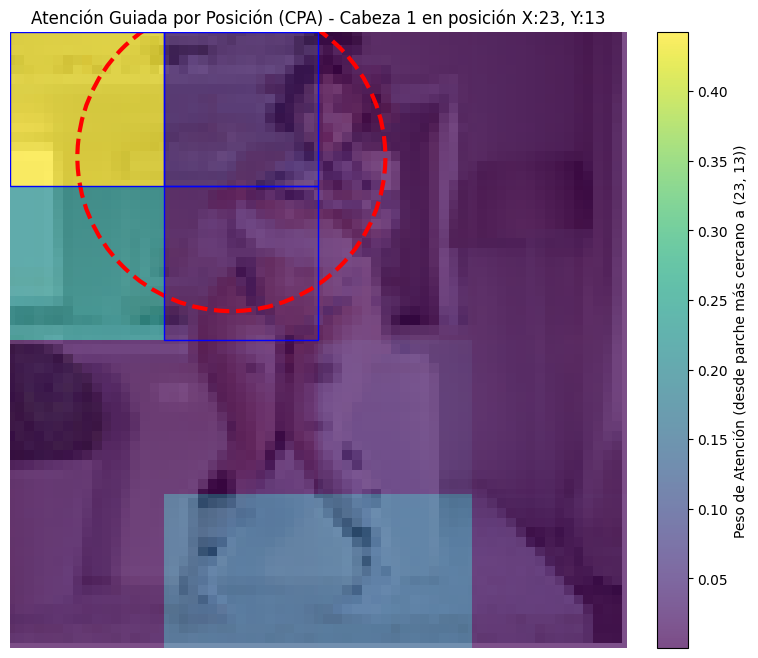

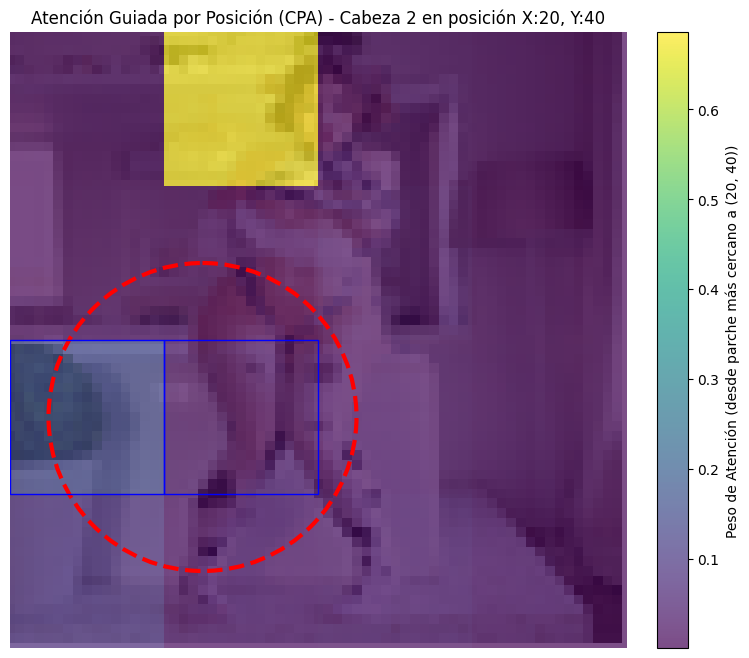

Evalúa la coherencia de la atención para esta iteración (0: Coherente, 1: Incoherente, o presiona Enter para ajustar automáticamente): 1
¡Incoherente! El modelo intentará moverse a nuevas posiciones.
¿Continuar a la siguiente iteración (s/n)? S

--- Iteración 2 ---

Posiciones de las Cabezas de Atención en esta iteración:
Cabeza 1 en posición X:24, Y:42
Cabeza 2 en posición X:20, Y:45


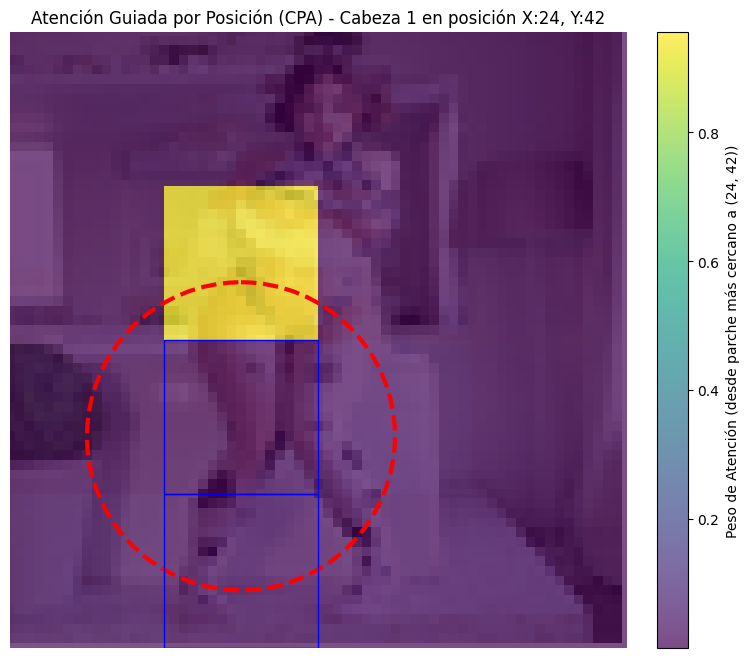

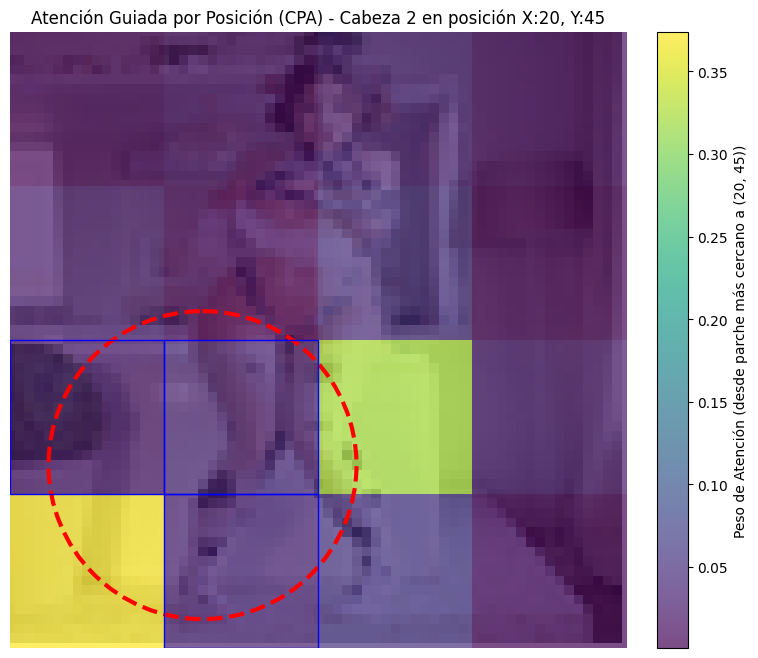

Evalúa la coherencia de la atención para esta iteración (0: Coherente, 1: Incoherente, o presiona Enter para ajustar automáticamente): 1
¡Incoherente! El modelo intentará moverse a nuevas posiciones.

Fin del ciclo de RL simulado.


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import random

# Definición de las clases RLSoftAttentionHead y RevisedMultiRLSoftAttention
class RLSoftAttentionHead(nn.Module):
    def __init__(self, embed_dim, seq_len, temperature=0.7):
        super().__init__()
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.seq_len = seq_len
        self.temperature = temperature
        self.attn_logits = nn.Parameter(torch.randn(seq_len, seq_len))

    def forward(self, x, training=True, forced_attention_mask=None):
        B, T, E = x.shape
        Q = self.q_proj(x)
        K = self.k_proj(x)
        V = self.v_proj(x)
        d_k = Q.shape[-1]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (d_k ** 0.5)

        if training:
            noise = -torch.log(-torch.log(torch.rand_like(self.attn_logits)))
            mask_logits = (self.attn_logits + noise) / self.temperature
        else:
            mask_logits = self.attn_logits

        attn_mask = F.softmax(mask_logits, dim=-1)

        if forced_attention_mask is not None:
            forced_attention_mask = forced_attention_mask.to(x.device)
            masked_scores = scores + forced_attention_mask.unsqueeze(0).expand(B, -1, -1)
        else:
            attn_mask_exp = attn_mask.unsqueeze(0).expand(B, -1, -1)
            masked_scores = scores * attn_mask_exp

        attn_weights = F.softmax(masked_scores, dim=-1)
        output = torch.matmul(attn_weights, V)
        return output, attn_weights, attn_mask

class RevisedMultiRLSoftAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, seq_len):
        super().__init__()
        assert embed_dim % num_heads == 0, "embed_dim must be divisible by num_heads"
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.heads = nn.ModuleList([
            RLSoftAttentionHead(self.head_dim, seq_len) for _ in range(num_heads)
        ])
        self.output_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x, training=True, forced_attention_masks=None):
        B, T, E = x.shape
        if E != self.num_heads * self.head_dim:
             raise ValueError(f"Input embedding dimension mismatch. Expected {self.num_heads * self.head_dim}, got {E}")

        x_split = x.view(B, T, self.num_heads, self.head_dim).permute(0, 2, 1, 3)
        x_split = x_split.contiguous().view(B * self.num_heads, T, self.head_dim)
        outputs = []
        attention_masks = []
        for i, head in enumerate(self.heads):
            current_forced_mask = forced_attention_masks[i] if forced_attention_masks and i < len(forced_attention_masks) and forced_attention_masks[i] is not None else None
            head_output, head_attn_weights, head_attn_mask = head(x_split[i*B:(i+1)*B], training=training, forced_attention_mask=current_forced_mask)
            outputs.append(head_output)
            attention_masks.append(head_attn_mask)
        combined_outputs = torch.cat([o.view(B, T, self.head_dim) for o in outputs], dim=-1)
        output = self.output_proj(combined_outputs)
        return output, attention_masks

image_path = '/content/H.jpg' # Asegúrate de que esta ruta sea correcta
patch_size = 16

NORM_DIM = 64
NUM_ATTENTION_HEADS = 2
CONTOUR_PIXELS = 16 # Esto define el radio de la región de atención forzada

try:
    image = Image.open(image_path).convert('RGB')
except FileNotFoundError:
    print(f"Error: La imagen no se encontró en la ruta: {image_path}")
    raise FileNotFoundError(f"Error: La imagen no se encontró en la ruta: {image_path}")

image = image.resize((NORM_DIM, NORM_DIM), Image.LANCZOS) # Normaliza la imagen

img_width, img_height = image.size
n_patches_width = img_width // patch_size
n_patches_height = img_height // patch_size
num_patches = n_patches_width * n_patches_height
seq_len = num_patches

print(f"Imagen normalizada a: {img_width}x{img_height}")
print(f"Tamaño del parche: {patch_size}x{patch_size}")
print(f"Número de parches (ancho x alto): {n_patches_width} x {n_patches_height} = {num_patches}")

def extract_patches(img, patch_size):
    patches = []
    width, height = img.size
    for i in range(0, height, patch_size):
        for j in range(0, width, patch_size):
            box = (j, i, j + patch_size, i + patch_size)
            patch = img.crop(box)
            patches.append(patch)
    return patches

patches = extract_patches(image, patch_size)
transform = transforms.ToTensor()
patch_tensors = [transform(patch) for patch in patches]
patch_tensor_stack = torch.stack(patch_tensors)

embedding_dim = 64 # Mantengamos un embed_dim fijo y razonable
input_flat_dim = patch_size * patch_size * patch_tensor_stack.shape[1]

projection_layer = torch.nn.Linear(input_flat_dim, embedding_dim)
patch_embeddings = patch_tensor_stack.view(num_patches, -1)
patch_embeddings = projection_layer(patch_embeddings)

batch_size = 1
input_sequence = patch_embeddings.unsqueeze(0)

print("Forma del tensor de entrada para el modelo:", input_sequence.shape)

model = RevisedMultiRLSoftAttention(embed_dim=embedding_dim, num_heads=NUM_ATTENTION_HEADS, seq_len=seq_len)

def get_attention_masks_and_info(num_heads, img_width, img_height, patch_size, n_patches_width, n_patches_height, seq_len, contour_pixels, current_points):
    """
    Genera las máscaras de atención forzadas y la información de la cabeza.
    current_points: Lista de (x, y) actuales para cada cabeza.
    Retorna: forced_masks_for_all_heads, head_positions_info, points_used
    """
    points_used = list(current_points)

    forced_masks_for_all_heads = []
    assigned_patch_indices_this_iter = set()
    head_positions_info = []

    for head_idx, (target_x, target_y) in enumerate(points_used):
        region_patch_indices = []
        for i in range(n_patches_height):
            for j in range(n_patches_width):
                patch_center_x = j * patch_size + patch_size // 2
                patch_center_y = i * patch_size + patch_size // 2
                distance = np.sqrt((patch_center_x - target_x)**2 + (patch_center_y - target_y)**2)

                if distance <= contour_pixels and (i * n_patches_width + j) not in assigned_patch_indices_this_iter:
                    region_patch_indices.append(i * n_patches_width + j)

        if not region_patch_indices:
            print(f"Advertencia: Cabeza {head_idx+1}: Ningún parche único encontrado para ({target_x}, {target_y}). La máscara no se forzará para esta cabeza.")
            forced_masks_for_all_heads.append(None)
            head_positions_info.append(f"Cabeza {head_idx+1} en posición X:{target_x}, Y:{target_y} (sin parches únicos asignados)")
        else:
            forced_attn_mask_tensor = torch.full((seq_len, seq_len), -1e9)
            for idx_from in region_patch_indices:
                for idx_to in region_patch_indices:
                    forced_attn_mask_tensor[idx_from, idx_to] = 0.0
            forced_masks_for_all_heads.append(forced_attn_mask_tensor)
            assigned_patch_indices_this_iter.update(region_patch_indices)
            head_positions_info.append(f"Cabeza {head_idx+1} en posición X:{target_x}, Y:{target_y}")

    return forced_masks_for_all_heads, head_positions_info, points_used

def visualize_attention_cpa(image, attention_mask, patch_size, head_idx, target_coords, assigned_regions, radius, head_info_string):
    n_patches_width = image.width // patch_size
    n_patches_height = image.height // patch_size

    if assigned_regions:
        closest_patch_idx = -1
        min_dist = float('inf')
        for p_idx in assigned_regions:
            p_row = p_idx // n_patches_width
            p_col = p_idx % n_patches_width
            p_center_x = p_col * patch_size + patch_size // 2
            p_center_y = p_row * patch_size + patch_size // 2
            dist = np.sqrt((p_center_x - target_coords[0])**2 + (p_center_y - target_coords[1])**2)
            if dist < min_dist:
                min_dist = dist
                closest_patch_idx = p_idx
        if closest_patch_idx != -1 and closest_patch_idx < attention_mask.size(0):
             attention_from_target = attention_mask.cpu().numpy()[closest_patch_idx]
             title_suffix = f'desde parche más cercano a ({target_coords[0]}, {target_coords[1]})'
        else:
            attention_from_target = attention_mask.cpu().numpy()[0]
            title_suffix = 'desde el primer parche (error en índice del parche más cercano)'

    else:
        attention_from_target = attention_mask.cpu().numpy()[0]
        title_suffix = 'desde el primer parche (sin región asignada)'

    attention_grid = attention_from_target.reshape(n_patches_height, n_patches_width)

    fig, ax = plt.subplots(1, 1, figsize=(10, 8))
    ax.imshow(image)
    ax.axis('off')

    heatmap = ax.imshow(attention_grid, cmap="viridis", alpha=0.7,
                        extent=[0, image.width, image.height, 0], origin='upper')

    cbar = fig.colorbar(heatmap, ax=ax, orientation='vertical', fraction=0.046, pad=0.04)
    cbar.set_label(f'Peso de Atención ({title_suffix})')

    circle = plt.Circle((target_coords[0], target_coords[1]), radius, color='red', fill=False, linewidth=3, linestyle='--')
    ax.add_patch(circle)

    for p_idx in assigned_regions:
        p_row = p_idx // n_patches_width
        p_col = p_idx % n_patches_width
        rect = plt.Rectangle((p_col * patch_size, p_row * patch_size), patch_size, patch_size,
                             linewidth=1, edgecolor='blue', facecolor='none')
        ax.add_patch(rect)

    plt.title(f'Atención Guiada por Posición (CPA) - {head_info_string}')
    plt.show()

# --- Simulación del Agente RL y el Bucle de Entrenamiento ---

initial_head_positions = [(random.randint(0, img_width - 1), random.randint(0, img_height - 1)) for _ in range(NUM_ATTENTION_HEADS)]

current_head_positions = list(initial_head_positions)

max_iterations = 2
iteration = 0

print("\n--- ¡Iniciando el ciclo de RL manual! ---")
print("El modelo intentará ajustar la atención en base a tu feedback.")
print("Tu tarea es evaluar la 'coherencia' de la atención mostrada.")
print("0: Coherente (buena atención), 1: Incoherente (mala atención)")
print("Presiona Enter sin valor para usar la heurística de ajuste.")
print("-" * 50)

while iteration < max_iterations:
    iteration += 1
    print(f"\n--- Iteración {iteration} ---")

    forced_masks_for_all_heads, head_positions_info, points_used_in_iter = get_attention_masks_and_info(
        NUM_ATTENTION_HEADS, img_width, img_height, patch_size, n_patches_width, n_patches_height,
        seq_len, CONTOUR_PIXELS, current_head_positions
    )

    print("\nPosiciones de las Cabezas de Atención en esta iteración:")
    for info in head_positions_info:
        print(info)

    model.eval()
    with torch.no_grad():
        output, attention_masks = model(input_sequence, forced_attention_masks=forced_masks_for_all_heads)

    for head_idx in range(NUM_ATTENTION_HEADS):
        current_target_point = points_used_in_iter[head_idx]
        current_region_indices = []
        for i in range(n_patches_height):
            for j in range(n_patches_width):
                patch_center_x = j * patch_size + patch_size // 2
                patch_center_y = i * patch_size + patch_size // 2
                distance = np.sqrt((patch_center_x - current_target_point[0])**2 + (patch_center_y - current_target_point[1])**2)
                if distance <= CONTOUR_PIXELS:
                    current_region_indices.append(i * n_patches_width + j)

        mask_is_none = forced_masks_for_all_heads[head_idx] is None

        if not mask_is_none:
             visualize_attention_cpa(image, attention_masks[head_idx], patch_size, head_idx,
                                     current_target_point, current_region_indices, CONTOUR_PIXELS, head_positions_info[head_idx])
        else:
             print(f"No se visualiza la Cabeza {head_idx+1} en esta iteración (no se asignaron parches únicos a su región).")

    feedback = input(f"Evalúa la coherencia de la atención para esta iteración (0: Coherente, 1: Incoherente, o presiona Enter para ajustar automáticamente): ")

    new_head_positions = list(current_head_positions)

    if feedback == '0':
        print("¡Excelente! La atención es coherente. Intentaremos mantener posiciones similares.")
        for i in range(NUM_ATTENTION_HEADS):
            x, y = new_head_positions[i]
            x_adj = max(0, min(img_width - 1, x + random.randint(-5, 5)))
            y_adj = max(0, min(img_height - 1, y + random.randint(-5, 5)))
            new_head_positions[i] = (x_adj, y_adj)
    elif feedback == '1':
        print("¡Incoherente! El modelo intentará moverse a nuevas posiciones.")
        for i in range(NUM_ATTENTION_HEADS):
            x_new = random.randint(0, img_width - 1)
            y_new = random.randint(0, img_height - 1)
            new_head_positions[i] = (x_new, y_new)
    elif feedback == '':
        print("Ajuste automático: Movimiento aleatorio simple para explorar.")
        for i in range(NUM_ATTENTION_HEADS):
            x_new = random.randint(0, img_width - 1)
            y_new = random.randint(0, img_height - 1)
            new_head_positions[i] = (x_new, y_new)
    else:
        print("Entrada no válida. Usando ajuste automático por defecto.")
        for i in range(NUM_ATTENTION_HEADS):
            x_new = random.randint(0, img_width - 1)
            y_new = random.randint(0, img_height - 1)
            new_head_positions[i] = (x_new, y_new)

    current_head_positions = new_head_positions

    if iteration == max_iterations:
        print("\nFin del ciclo de RL simulado.")
        break

    cont_input = input("¿Continuar a la siguiente iteración (s/n)? ").lower()
    if cont_input != 's':
        print("Saliendo del ciclo.")
        break

#buvucug

In [ ]:
!pip install gradio

In [ ]:
import gradio as gr
import numpy as np
from PIL import Image

# Función para procesar la imagen con las marcas del usuario
def procesar_imagen_marcada(image_editor_output):
    if image_editor_output is None:
        return "No se ha subido ninguna imagen o no se han hecho marcas."

    # La salida de ImageEditor es un diccionario.
    # 'composite' es la imagen final con todas las capas (fondo + marcas)
    # 'layers' es una lista de las capas individuales de dibujo
    composite_image = image_editor_output['composite']
    layers = image_editor_output['layers']

    if composite_image is None:
        return "No se pudo obtener la imagen compuesta."

    # Convertir la imagen compuesta a NumPy para procesamiento
    img_np = np.array(composite_image)

    # Identificar los puntos marcados
    # Si el usuario usa el pincel, la capa será la "pintura"
    # Vamos a buscar píxeles no blancos en las capas de dibujo.
    puntos_encontrados = []
    if layers:
        for layer_info in layers:
            layer_img = layer_info['image'] # Esto es una PIL Image
            layer_np = np.array(layer_img.convert('RGBA')) # Asegurarse de tener canal alfa

            # Encontrar píxeles que no son completamente transparentes (canal alfa > 0)
            # y que no son blancos (si el pincel es de color)
            # Para un pincel negro, buscaremos píxeles con valores bajos
            # Simplificación: si el pincel es negro, buscaremos píxeles negros
            # Si el pincel es de cualquier color, buscaremos píxeles que no sean la imagen original

            # Una forma más robusta sería comparar con la imagen original si no hay marcas.
            # Para este ejemplo, asumiremos que las marcas son de un color distintivo

            # Gradio ImageEditor las marcas suelen ser negras o de color.
            # Vamos a buscar píxeles que no sean (255, 255, 255, 0) o (0,0,0,0) (totalmente transparente)

            # Sumar los canales RGB para saber si es blanco o negro (más robusto para colores)
            # Los píxeles marcados tendrán un valor de color diferente al fondo (si es blanco)
            # y un canal alfa que indica opacidad.

            # Identificar píxeles que son significativamente diferentes del blanco puro transparente
            # y que tienen cierta opacidad.
            # Un umbral simple para identificar "marcas" que no son el color de fondo.

            # Una forma sencilla es buscar los píxeles que no son blancos (255,255,255) y son opacos
            # O simplemente donde el canal alfa no es 0

            non_transparent_pixels = np.where(layer_np[:, :, 3] > 0)

            for y, x in zip(non_transparent_pixels[0], non_transparent_pixels[1]):
                # Aquí podrías refinar la detección si solo quieres "puntos" y no "líneas"
                # Por ahora, cada píxel marcado es un punto.
                puntos_encontrados.append((x, y)) # (x, y) para coordenadas

    # Devolver los puntos encontrados o un mensaje
    if puntos_encontrados:
        # Eliminar duplicados si el usuario arrastró el pincel
        puntos_unicos = sorted(list(set(puntos_encontrados)))
        texto_puntos = "Puntos señalados:\n" + "\n".join([f"({x}, {y})" for x, y in puntos_unicos])
        return texto_puntos
    else:
        return "No se señalaron puntos."

# Interfaz Gradio
with gr.Blocks() as demo:
    gr.Markdown("# Señalar Puntos en Imagen con Gradio")
    gr.Markdown("Sube una imagen y usa la herramienta de pincel para señalar puntos.")

    with gr.Row():
        # gr.ImageEditor permite dibujar con el pincel
        # Los botones de herramientas permiten cambiar de herramienta
        # Eliminados brush_color y brush_size ya que no son argumentos del constructor en esta versión
        image_input = gr.ImageEditor(
            # tool="brush", # Herramienta inicial seleccionada: pincel (Eliminado)
            type="pil", # Para obtener la imagen como PIL Image en la función
            label="Sube una imagen y usa el pincel para marcar puntos"
        )

        output_text = gr.Textbox(label="Coordenadas de los puntos")

    # Cuando el ImageEditor cambia (al soltar el ratón después de pintar, por ejemplo)
    # se llama a la función procesar_imagen_marcada
    image_input.change(
        fn=procesar_imagen_marcada,
        inputs=image_input,
        outputs=output_text
    )

# Unindent this line to be outside the with block
demo.launch(debug=True) # debug=True te da más información en la consola de Colab
# Comentado para evitar que se lance automáticamente en este bloque.
# Puedes descomentar si quieres lanzar la interfaz desde aquí.

In [ ]:
import gradio as gr
import numpy as np
from PIL import Image
from scipy.ndimage import measurements # Necesitamos esto para calcular centroides

# Función para procesar la imagen con las marcas del usuario
def procesar_imagen_marcada(image_editor_output):
    if image_editor_output is None or image_editor_output['composite'] is None:
        return "No se ha subido ninguna imagen o no se han hecho marcas."

    # image_editor_output['layers'] contiene ahora directamente los objetos PIL Image
    # o None si no hay capas
    layers = image_editor_output['layers']

    puntos_señalados = []

    if layers:
        # Iterar directamente sobre las imágenes en 'layers'
        for i, layer_img_pil in enumerate(layers):
            if layer_img_pil is None:
                continue # Saltar si la capa es nula por alguna razón

            # Convertir la capa a un array NumPy en escala de grises para el procesamiento
            # Asumimos que las marcas son más oscuras que el fondo de la capa
            layer_np_gray = np.array(layer_img_pil.convert('L')) # 'L' para escala de grises

            # Queremos encontrar los píxeles que son parte de la marca (no el fondo blanco o transparente)
            # Un umbral simple: los píxeles oscuros son la marca
            # 255 es blanco, 0 es negro. Buscamos valores que no sean blancos (pincel oscuro).
            # Ajusta el umbral si tu pincel no es negro o si el fondo no es blanco
            marked_region = (layer_np_gray < 250).astype(int)

            # Si hay píxeles marcados en esta capa, calcula su centroide
            if np.sum(marked_region) > 0: # Solo si hay algo marcado en la capa
                # center_of_mass devuelve (y, x)
                # Manejar el caso en que center_of_mass pueda retornar NaN si marked_region es completamente cero (aunque el if anterior lo previene)
                try:
                    center_y, center_x = measurements.center_of_mass(marked_region)
                    # Convertimos a enteros para coordenadas de píxel
                    puntos_señalados.append((int(round(center_x)), int(round(center_y)))) # Usar round para mejor precisión
                except ValueError as e:
                    print(f"Advertencia: Error calculando centroide para capa {i}: {e}")
                    # Puedes optar por saltar esta capa o registrar el error

    # Formatear la salida
    if puntos_señalados:
        texto_puntos = "Puntos señalados:\n"
        # Eliminar duplicados si múltiples capas marcan el mismo punto aproximadamente
        puntos_unicos = sorted(list(set(puntos_señalados)))
        for i, punto in enumerate(puntos_unicos):
            texto_puntos += f"Punto {i+1}: ({punto[0]}, {punto[1]})\n"
        return texto_puntos
    else:
        return "No se señalaron puntos."

# Interfaz Gradio (sin cambios, ya que el problema estaba en la función)
with gr.Blocks() as demo:
    gr.Markdown("# Señalar Puntos en Imagen con Gradio")
    gr.Markdown("1. Sube una imagen.\n2. Selecciona la herramienta de **pincel** (suele ser la predeterminada).\n3. Haz un **pequeño toque** o clic en la imagen para marcar cada punto. Cada toque se considerará un punto independiente.")

    with gr.Row():
        # Eliminados tool, brush_color, brush_size
        image_input = gr.ImageEditor(
            type="pil",
            label="Sube una imagen y usa el pincel para marcar puntos"
        )

        output_text = gr.Textbox(label="Coordenadas de los Puntos Señalados", lines=10)

    image_input.change(
        fn=procesar_imagen_marcada,
        inputs=image_input,
        outputs=output_text
    )

# Unindent this line to be outside the with block
demo.launch(debug=True)

Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://4be08e5e92f3097801.gradio.live


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │       163,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 164,298 (641.79 KB)

 Trainable params: 164,298 (641.79 KB)

 Non-trainable params: 0 (0.00 B)


Forma de los filtros de la capa 'conv1': (3, 3, 3, 16)
La forma es (alto_filtro, ancho_filtro, canales_entrada, numero_filtros)

Visualizando los 16 patrones (filtros) de la primera capa:


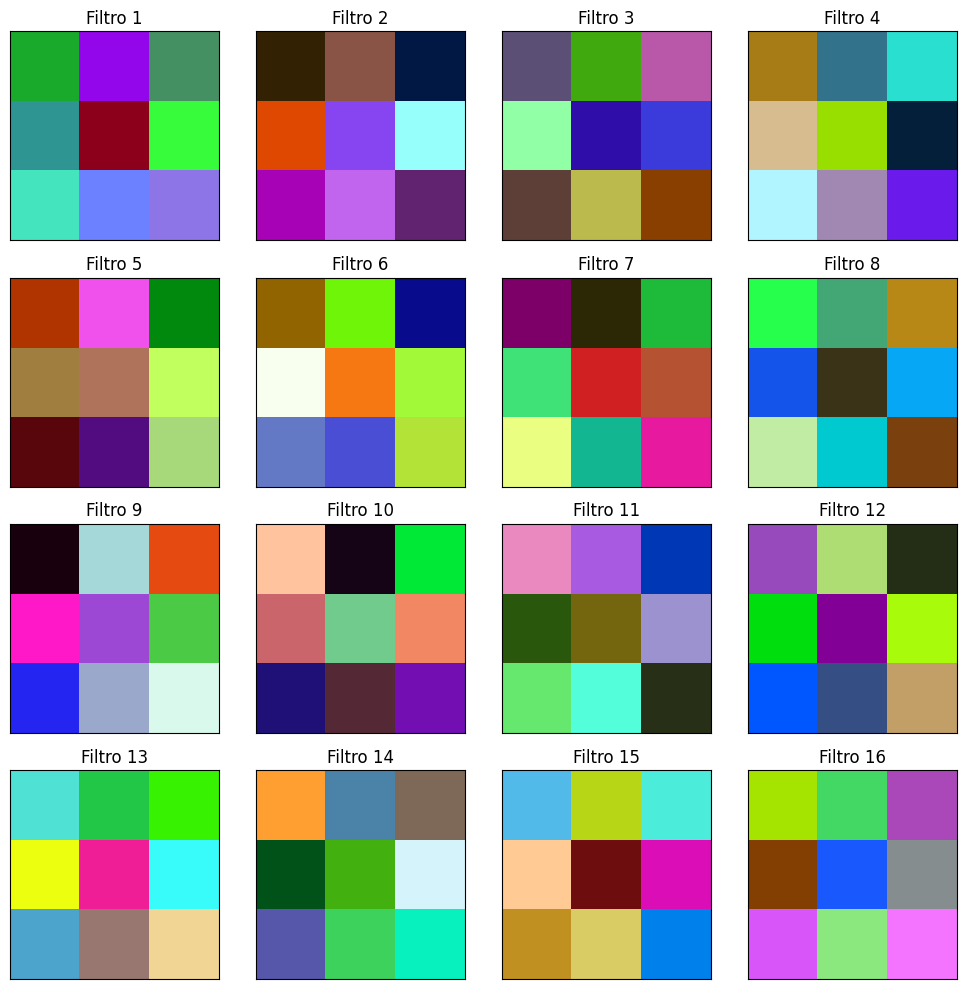

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image

# --- 1. Definir una CNN simple ---
# Vamos a crear un modelo muy básico, solo para demostrar la extracción de filtros.
# Normalmente, entrenarías esto con un dataset para que los filtros aprendan algo significativo.

def build_simple_cnn(input_shape=(32, 32, 3), num_filters=16, kernel_size=(3, 3)):
    model = keras.Sequential([
        # Primera capa convolucional
        layers.Conv2D(num_filters, kernel_size, activation='relu', input_shape=input_shape, padding='same', name='conv1'),
        layers.MaxPooling2D((2, 2)),
        # Puedes añadir más capas si quieres, pero para visualizar patrones simples,
        # la primera capa es la más relevante.
        layers.Flatten(),
        layers.Dense(10, activation='softmax') # Capa densa de salida (ejemplo para clasificación)
    ])
    return model

# --- 2. Crear y "entrenar" un modelo (aquí solo inicializamos para ver los filtros) ---
# Para que los filtros tengan "patrones" aprendidos, la CNN debería ser entrenada
# con un dataset real (ej. CIFAR-10, MNIST).
# Aquí, solo inicializaremos la CNN para poder acceder a los pesos de los filtros.
# Si no la entrenas, los patrones serán aleatorios.

# Puedes cambiar el input_shape según tus imágenes
input_shape = (64, 64, 3) # Ejemplo: imágenes de 64x64 píxeles a color (RGB)
cnn_model = build_simple_cnn(input_shape=input_shape)
cnn_model.summary()

# --- 3. Extraer y Imprimir los Patrones (Filtros) ---
# Los filtros son los pesos de la capa convolucional.
# Acceder a la primera capa convolucional por su nombre
conv1_layer = cnn_model.get_layer('conv1')

# Obtener los pesos (kernels) de la capa convolucional
# weights[0] son los kernels (filtros) y weights[1] son los biases
filters = conv1_layer.get_weights()[0]

print(f"\nForma de los filtros de la capa 'conv1': {filters.shape}")
print(f"La forma es (alto_filtro, ancho_filtro, canales_entrada, numero_filtros)")

# --- 4. Visualizar los Patrones (Filtros) ---
# Cada filtro es un patrón 3D (alto, ancho, canales_entrada)
# Vamos a visualizarlos como imágenes.

num_filters = filters.shape[-1] # Número de filtros en la capa
kernel_height, kernel_width, _, _ = filters.shape

print(f"\nVisualizando los {num_filters} patrones (filtros) de la primera capa:")

fig = plt.figure(figsize=(10, 10))
for i in range(num_filters):
    # Obtener el i-ésimo filtro
    f = filters[:, :, :, i]

    # Normalizar el filtro para la visualización (escalar entre 0 y 1)
    # Esto ayuda a que los patrones sean visibles, ya que los pesos pueden ser negativos.
    f_min, f_max = f.min(), f.max()
    f = (f - f_min) / (f_max - f_min)

    # Crear un subplot para cada filtro
    ax = fig.add_subplot(int(np.ceil(np.sqrt(num_filters))), int(np.ceil(np.sqrt(num_filters))), i + 1)

    # Mostrar el filtro. Si el filtro tiene 3 canales de entrada, lo mostramos como RGB.
    # Si tiene 1 canal (ej. entrada monocromática), lo mostramos en escala de grises.
    if f.shape[-1] == 3: # Si es un filtro RGB
        ax.imshow(f)
    else: # Si es un filtro en escala de grises
        ax.imshow(f[:, :, 0], cmap='gray') # Muestra el primer canal si hay más

    ax.set_xticks([]) # Ocultar ticks del eje x
    ax.set_yticks([]) # Ocultar ticks del eje y
    ax.set_title(f'Filtro {i+1}')

plt.tight_layout()
plt.show()

# --- Notas Importantes ---
# - Si no entrenas la CNN, los filtros serán valores aleatorios, por lo que los "patrones"
#   visualizados también serán aleatorios y no representarán nada significativo.
# - Para ver patrones significativos (bordes, texturas, blobs de color), necesitas
#   **entrenar la CNN con un conjunto de datos relevante**.
# - Los filtros de capas más profundas son más complejos de visualizar e interpretar,
#   ya que operan sobre las características aprendidas por las capas anteriores,
#   no directamente sobre la imagen de entrada.

In [ ]:
# Use shell commands to list files in your directory
# The ! prefix allows running shell commands in Jupyter/Colab
print("Listing files in the main data directory:")
!ls -la "/content/drive/MyDrive/Lunetas/Datasets/Realwomen"

# List files in one of the subdirectories (replace with a real class name)
# This helps you check specific subfolders
print("\nListing files in a sample subdirectory (replace 'ClassName' with a real folder name):")
# Replace 'REPLACE_WITH_A_REAL_CLASS_FOLDER_NAME' with one of the actual folder names listed by the previous command
!ls -la "/content/drive/MyDrive/Lunetas/Datasets/Realwomen/REPLACE_WITH_A_REAL_CLASS_FOLDER_NAME"

# You can use 'find' to search for specific file types or non-standard files
# Example: Find files that don't end with .jpg, .png, .jpeg, .gif, .bmp
# Be careful with this command, it might list directories too.
# A more specific command might be needed depending on what you find.
print("\nSearching for potential non-image files (excluding common image extensions):")
!find "/content/drive/MyDrive/Lunetas/Datasets/Realwomen" -type f ! -iname "*.jpg" ! -iname "*.jpeg" ! -iname "*.png" ! -iname "*.gif" ! -iname "*.bmp"

# Pay close attention to any files listed by the above commands that aren't your images.
# Remove or move any problematic files from the directory in Google Drive.

Listing files in the main data directory:
total 1248
-rw------- 1 root root 312865 Mar  1  2024 20240301_072903.jpg
-rw------- 1 root root 236779 Mar 29  2024 20240329_062650.jpg
-rw------- 1 root root  89900 Mar 29  2024 20240329_063010.jpg
-rw------- 1 root root 300811 Mar 29  2024 20240329_063145.jpg
-rw------- 1 root root 171253 Mar 29  2024 20240329_063434.jpg
drwx------ 2 root root   4096 Feb 13  2024 @bahoonkas
-rw------- 1 root root  86802 May 22 01:59 big-tits-anyone-v0-jceh89km0ddc1.jpg
drwx------ 2 root root   4096 Feb 12  2024 Boobs
drwx------ 2 root root   4096 Feb 13  2024 Buttocks
drwx------ 2 root root   4096 Feb 13  2024 @EvaJadexo
drwx------ 2 root root   4096 Feb 13  2024 @KikoBaka
drwx------ 2 root root   4096 Feb 13  2024 @KitKatKiitty
drwx------ 2 root root   4096 Feb 16  2024 @marianvgl
drwx------ 2 root root   4096 Feb  8  2024 @miaxomonroe
drwx------ 2 root root   4096 Feb 13  2024 @MoncheriValerie
drwx------ 2 root root   4096 Feb 12  2024 Pussy
drwx------ 2 r

In [ ]:
# Remove the problematic .webp file
# BE CAREFUL with this command - it will permanently delete the file.
# Make sure the path is correct before running.
print("Attempting to remove the WebP file...")
!rm "/content/drive/MyDrive/Lunetas/Datasets/Realwomen/Undefined/willowsdreaming.webp"
print("File removal attempted. Check the output to confirm.")

# Optional: Verify that the file is gone
print("\nListing files in the 'Undefined' subdirectory after removal attempt:")
!ls -la "/content/drive/MyDrive/Lunetas/Datasets/Realwomen/Undefined"

Attempting to remove the WebP file...
File removal attempted. Check the output to confirm.

Listing files in the 'Undefined' subdirectory after removal attempt:
total 277077
-rw------- 1 root root   62704 Feb 16  2024 '1pic (1).jpeg'
-rw------- 1 root root   62704 Mar 10  2024  1pic.jpeg
-rw------- 1 root root 3635782 Jan 19  2024  20240113_000629.jpg
-rw------- 1 root root  632969 Jan 20  2024  20240120_072118.jpg
-rw------- 1 root root  403180 Jan 20  2024  20240120_072148.jpg
-rw------- 1 root root  200996 Jan 23  2024  20240122_194133.jpg
-rw------- 1 root root  505812 Jan 23  2024  20240122_220008.jpg
-rw------- 1 root root  216130 Jan 23  2024  20240122_220111.jpg
-rw------- 1 root root  112572 Jan 23  2024  20240122_220505.jpg
-rw------- 1 root root  125018 Jan 23  2024  20240122_220701.jpg
-rw------- 1 root root  497425 Jan 23  2024  20240122_220929.jpg
-rw------- 1 root root  502834 Jan 23  2024  20240122_221004.jpg
-rw------- 1 root root  332833 Jan 23  2024  20240122_221026.

Cargando imágenes desde: /content/Realwomen
Found 1818 files belonging to 19 classes.
Clases encontradas: ['@EvaJadexo', '@KikoBaka', '@KitKatKiitty', '@MoncheriValerie', '@Valeriaaa_belen', '@YourTereza', '@bahoonkas', '@marianvgl', '@miaxomonroe', '@serinymph', '@sophieraiin', '@valecastaneda02', '@valenciadgaf', '@vanessa.rhd', 'Boobs', 'Buttocks', 'Pussy', 'Um', 'Undefined']
Número de clases: 19


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 19)             │     1,245,203 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,245,651 (4.75 MB)

 Trainable params: 1,245,651 (4.75 MB)

 Non-trainable params: 0 (0.00 B)


Entrenando la CNN (esto tomará un tiempo)...
Epoch 1/25
364/364 ━━━━━━━━━━━━━━━━━━━━ 126s 343ms/step - accuracy: 0.3785 - loss: 117.6233
Epoch 2/25
364/364 ━━━━━━━━━━━━━━━━━━━━ 97s 266ms/step - accuracy: 0.7686 - loss: 0.9537
Epoch 3/25
364/364 ━━━━━━━━━━━━━━━━━━━━ 142s 265ms/step - accuracy: 0.9144 - loss: 0.5440
Epoch 4/25
364/364 ━━━━━━━━━━━━━━━━━━━━ 143s 269ms/step - accuracy: 0.9616 - loss: 0.3255
Epoch 5/25
364/364 ━━━━━━━━━━━━━━━━━━━━ 143s 270ms/step - accuracy: 0.9692 - loss: 0.2960
Epoch 6/25
364/364 ━━━━━━━━━━━━━━━━━━━━ 142s 271ms/step - accuracy: 0.9767 - loss: 0.2692
Epoch 7/25
364/364 ━━━━━━━━━━━━━━━━━━━━ 142s 271ms/step - accuracy: 0.9809 - loss: 0.3132
Epoch 8/25
364/364 ━━━━━━━━━━━━━━━━━━━━ 97s 265ms/step - accuracy: 0.9829 - loss: 0.2533
Epoch 9/25
364/364 ━━━━━━━━━━━━━━━━━━━━ 143s 268ms/step - accuracy: 0.9904 - loss: 0.2513
Epoch 10/25
364/364 ━━━━━━━━━━━━━━━━━━━━ 143s 271ms/step - accuracy: 0.9877 - loss: 0.2559
Epoch 11/25
364/364 ━━━━━━━━━━━━━━━━━━━━ 141s 270ms/s

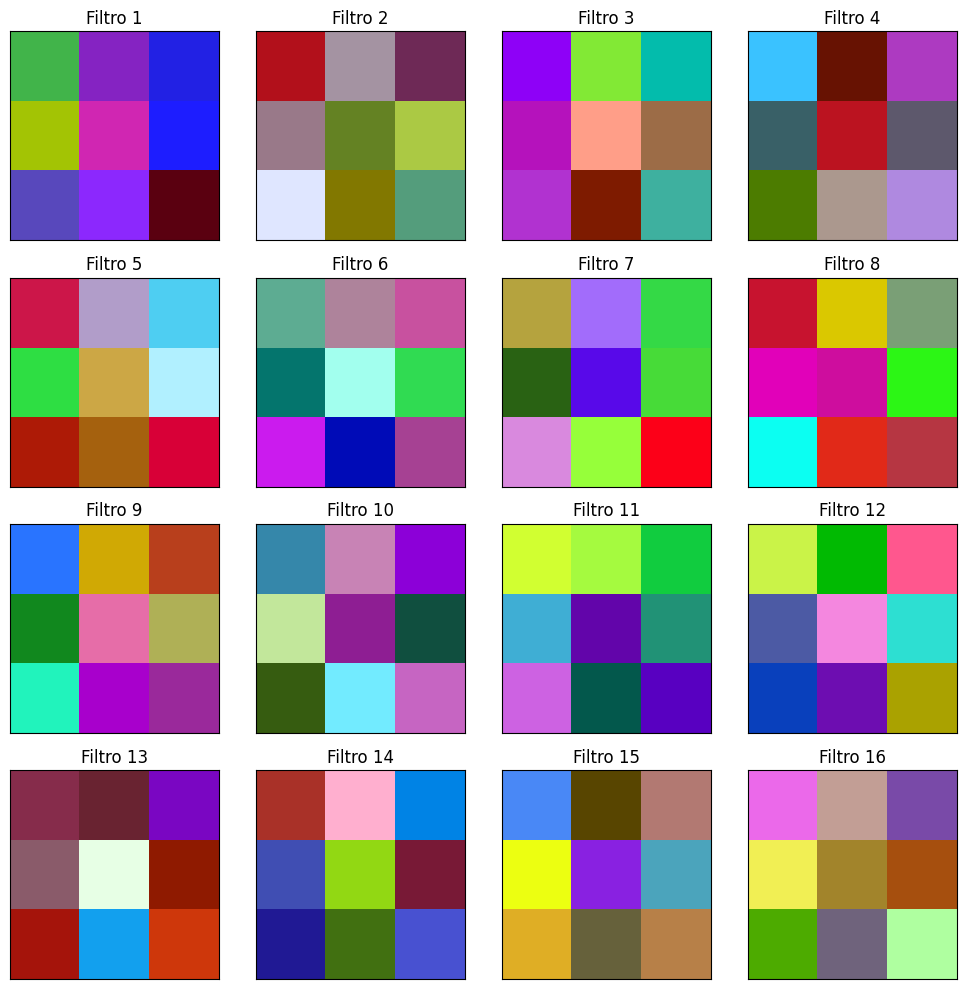

InvalidArgumentError: {{function_node __wrapped__StridedSlice_device_/job:localhost/replica:0/task:0/device:CPU:0}} slice index 5 of dimension 0 out of bounds. [Op:StridedSlice] name: strided_slice/

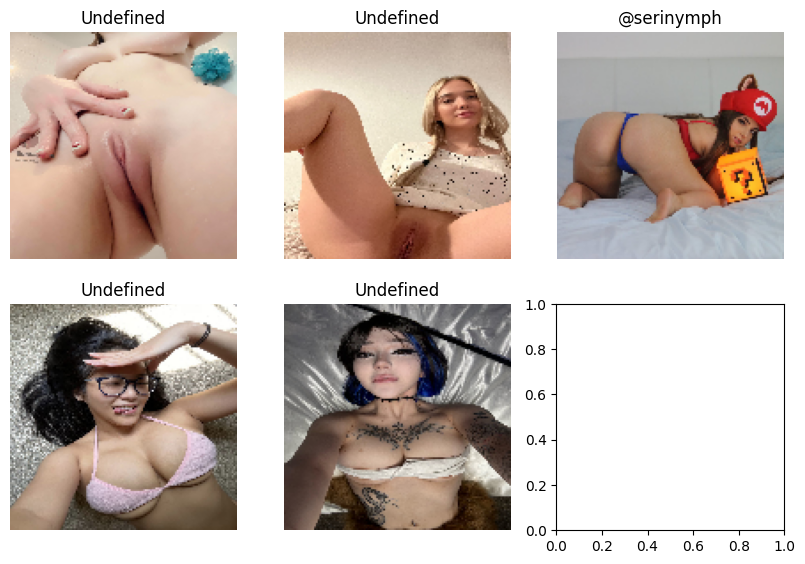

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image
import os # Para operaciones con rutas de archivos
import tensorflow as tf # Necesario para image_dataset_from_directory



# --- 1. Definir una CNN simple (Tu código existente) ---
def build_simple_cnn(input_shape, num_filters=16, kernel_size=(3, 3)):
    model = keras.Sequential([
        layers.Conv2D(num_filters, kernel_size, activation='relu', input_shape=input_shape, padding='same', name='conv1'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(num_classes, activation='softmax') # num_classes se definirá más abajo
    ])
    return model

# --- 2. Cargar tus imágenes desde Google Drive ---
# Ruta a tu carpeta principal de datos
data_dir = '/content/Realwomen'

# Definir el tamaño de las imágenes al cargarlas y el tamaño del lote
IMG_HEIGHT = 128 # Puedes ajustar esto según la resolución de tus imágenes
IMG_WIDTH = 128
BATCH_SIZE = 5

# Cargar el dataset usando image_dataset_from_directory
# Esto automáticamente inferirá las clases de las subcarpetas
print(f"Cargando imágenes desde: {data_dir}")
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    labels='inferred',
    label_mode='int', # Etiquetas como enteros (0, 1, 2, ...)
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    interpolation='nearest', # Cómo redimensionar si es necesario
    batch_size=BATCH_SIZE,
    shuffle=True # Mezclar los datos
)

# Obtener los nombres de las clases (nombres de las subcarpetas)
class_names = train_ds.class_names
num_classes = len(class_names)
print(f"Clases encontradas: {class_names}")
print(f"Número de clases: {num_classes}")

# Ajustar el input_shape de la CNN según el tamaño de las imágenes cargadas
input_shape = (IMG_HEIGHT, IMG_WIDTH, 3) # Asumimos imágenes RGB

# Crear el modelo con el input_shape correcto y el número de clases
cnn_model = build_simple_cnn(input_shape=input_shape, num_filters=16)
cnn_model.summary()

# --- 3. Entrenar el modelo (para que los filtros aprendan patrones) ---
# Es crucial entrenar la CNN para que los filtros aprendan patrones significativos.
# Aquí, compilamos y entrenamos con un pequeño número de épocas como ejemplo.
# En un escenario real, necesitarías dividir tus datos en entrenamiento/validación.

cnn_model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False), # Usa True si no tienes softmax en la última capa
    metrics=['accuracy']
)

print("\nEntrenando la CNN (esto tomará un tiempo)...")
# Puedes ajustar el número de epochs
history = cnn_model.fit(
    train_ds,
    epochs=25 # Un número pequeño de épocas para la demostración
)
print("¡Entrenamiento completado!")

# --- 4. Extraer y Visualizar los Patrones (Filtros) después del entrenamiento ---
# Los filtros ahora deberían contener patrones aprendidos.
conv1_layer = cnn_model.get_layer('conv1')
filters = conv1_layer.get_weights()[0]

print(f"\nForma de los filtros de la capa 'conv1': {filters.shape}")
print(f"La forma es (alto_filtro, ancho_filtro, canales_entrada, numero_filtros)")

num_filters = filters.shape[-1]
kernel_height, kernel_width, _, _ = filters.shape

print(f"\nVisualizando los {num_filters} patrones (filtros) aprendidos de la primera capa:")

fig = plt.figure(figsize=(10, 10))
for i in range(num_filters):
    f = filters[:, :, :, i]

    # Normalizar el filtro para la visualización
    f_min, f_max = f.min(), f.max()
    # Evitar división por cero si f_max y f_min son iguales (filtro plano)
    if (f_max - f_min) == 0:
        f = np.zeros_like(f) # Si es plano, solo muestra negro
    else:
        f = (f - f_min) / (f_max - f_min)

    ax = fig.add_subplot(int(np.ceil(np.sqrt(num_filters))), int(np.ceil(np.sqrt(num_filters))), i + 1)

    if f.shape[-1] == 3:
        ax.imshow(f)
    else:
        ax.imshow(f[:, :, 0], cmap='gray')

    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'Filtro {i+1}')

plt.tight_layout()
plt.show()

# ---
# Puedes ver los primeros elementos del dataset
# Remove the indentation from these lines
for images, labels in train_ds.take(1):
    plt.figure(figsize=(10, 10))
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
    plt.show() # Move this plt.show() outside the inner loop to show the 3x3 grid at once

In [ ]:
# --- 4. Guardar el modelo ---
model_save_path = '/content/my_trained_cnn_model.keras' # Guarda como archivo .keras

try:
    cnn_model.save(model_save_path)
    print(f"\nModelo guardado exitosamente en: {model_save_path}")
except Exception as e:
    print(f"\nError al guardar el modelo: {e}")


Modelo guardado exitosamente en: /content/my_trained_cnn_model.keras


In [ ]:
import tensorflow as tf
from tensorflow import keras
from PIL import Image
import numpy as np

# 1. Cargar el modelo entrenado
model_path = '/content/my_trained_cnn_model.keras'  # Reemplaza con la ruta correcta si es diferente
try:
    loaded_model = keras.models.load_model(model_path)
    print(f"Modelo cargado exitosamente desde: {model_path}")
except Exception as e:
    print(f"Error al cargar el modelo: {e}")
    exit()  # Detener si no se puede cargar el modelo

# 2. Cargar y preprocesar la imagen que quieres clasificar
image_path = '/Content/test.png'  # Reemplaza con la ruta de tu imagen
try:
    img = Image.open(image_path).resize((128, 128))  # Ajusta el tamaño si es diferente
    img_array = keras.preprocessing.image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)  # Añadir una dimensión de lote (batch)
    img_array = img_array / 255.0  # Normalizar (si tu modelo fue entrenado con imágenes normalizadas)
except Exception as e:
    print(f"Error al cargar o preprocesar la imagen: {e}")
    exit()

# 3. Hacer la predicción
predictions = loaded_model.predict(img_array)
predicted_class = np.argmax(predictions[0])  # Obtener el índice de la clase con mayor probabilidad

# Si tienes los nombres de las clases (class_names) de tu dataset de entrenamiento:
# class_names = ['@EvaJadexo', '@KikoBaka', ...]  # Reemplaza con tus nombres de clase
# predicted_class_name = class_names[predicted_class]
# print(f"La imagen se clasifica como: {predicted_class_name}")
# else:

print(f"La imagen se clasifica como la clase con índice: {predicted_class}")
print(f"Predicciones: {predictions}") # Muestra las probabilidades para cada clase

Modelo cargado exitosamente desde: /content/my_trained_cnn_model.keras
Error al cargar o preprocesar la imagen: [Errno 2] No such file or directory: '/Content/test.png'
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step
La imagen se clasifica como la clase con índice: 18
Predicciones: [[0.04685371 0.04946823 0.05554224 0.04921304 0.04492001 0.04525238
  0.0528359  0.05381539 0.05033789 0.05097995 0.04895545 0.04728679
  0.04346873 0.05092963 0.04729322 0.05608377 0.05426088 0.04672281
  0.10577998]]


In [ ]:
import tensorflow as tf
from tensorflow import keras
from PIL import Image
import numpy as np
import os # Asegúrate de que esta librería esté importada

# 1. Cargar el modelo entrenado (resto del código igual)
model_path = '/content/my_trained_cnn_model.keras'
try:
    loaded_model = keras.models.load_model(model_path)
    print(f"Modelo cargado exitosamente desde: {model_path}")
except Exception as e:
    print(f"Error al cargar el modelo: {e}")
    exit()

# 2. Cargar y preprocesar la imagen que quieres clasificar
# ¡AQUÍ ESTÁ EL CAMBIO IMPORTANTE!
image_path = '/content/test.jpg'  # <--- Cambia .png por .jpg aquí
if not os.path.exists(image_path):
    print(f"Error: La imagen '{image_path}' no se encuentra.")
    exit()

try:
    img = Image.open(image_path).resize((128, 128))
    img_array = keras.preprocessing.image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = img_array / 255.0
except Exception as e:
    print(f"Error al cargar o preprocesar la imagen: {e}")
    exit()

# 3. Hacer la predicción (resto del código igual)
predictions = loaded_model.predict(img_array)
predicted_class = np.argmax(predictions[0])

print(f"La imagen se clasifica como la clase con índice: {predicted_class}")
print(f"Predicciones: {predictions}")

Modelo cargado exitosamente desde: /content/my_trained_cnn_model.keras
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 329ms/step
La imagen se clasifica como la clase con índice: 18
Predicciones: [[0.04685371 0.04946823 0.05554224 0.04921304 0.04492001 0.04525238
  0.0528359  0.05381539 0.05033789 0.05097995 0.04895545 0.04728679
  0.04346873 0.05092963 0.04729322 0.05608377 0.05426088 0.04672281
  0.10577998]]


In [ ]:
import os
from PIL import Image
import tensorflow as tf # Aunque solo usaremos PIL aquí, es bueno tenerlo

# Ruta a tu carpeta principal de datos
data_dir = '/content/Realwomen'

# Lista para almacenar los archivos problemáticos
problematic_files = []

print(f"Escaneando archivos en: {data_dir} para detectar formatos inválidos o corruptos...")

# Recorrer todas las subcarpetas y archivos
for root, _, files in os.walk(data_dir):
    for file in files:
        file_path = os.path.join(root, file)
        try:
            # Intentar abrir la imagen con PIL
            # Poner 'Image.MAX_IMAGE_PIXELS = None' si tienes imágenes muy grandes
            Image.open(file_path).verify() # .verify() intenta cargar y verificar el archivo
            # Si llega aquí, la imagen es probablemente válida.
            # También puedes cargarla completamente para una verificación más estricta:
            # img = Image.open(file_path)
            # img.load()
        except (IOError, SyntaxError, Image.UnidentifiedImageError) as e:
            # Capturar errores relacionados con el formato o la corrupción
            print(f"!!! PROBLEMA con el archivo: {file_path} - Error: {e}")
            problematic_files.append(file_path)
        except Exception as e:
            # Capturar cualquier otro error inesperado
            print(f"!!! ERROR INESPERADO al procesar: {file_path} - Error: {e}")
            problematic_files.append(file_path)

print("\n--- ESCANEO COMPLETADO ---")
if problematic_files:
    print(f"Se encontraron {len(problematic_files)} archivo(s) problemático(s):")
    for p_file in problematic_files:
        print(p_file)
    print("\nPor favor, revisa/elimina estos archivos de tu Google Drive y vuelve a ejecutar el código.")
else:
    print("¡No se encontraron archivos problemáticos! Tus imágenes deberían cargarse correctamente.")

Escaneando archivos en: /content/Realwomen para detectar formatos inválidos o corruptos...

--- ESCANEO COMPLETADO ---
¡No se encontraron archivos problemáticos! Tus imágenes deberían cargarse correctamente.


In [ ]:
import os
from PIL import Image

# Ruta a tu carpeta principal de datos
data_dir = '/content/Realwomen_RAM' # Asegúrate de que esta sea la carpeta donde están tus datos

print(f"Limpiando y filtrando archivos en: {data_dir}. Solo se conservarán PNG válidos...")

# Recorrer todas las subcarpetas y archivos
for root, _, files in os.walk(data_dir):
    for file in files:
        file_path = os.path.join(root, file)
        file_name, file_ext = os.path.splitext(file)

        # Convertir la extensión a minúsculas para una comparación consistente
        normalized_ext = file_ext.lower().lstrip('.')

        # --- Paso 1: Eliminar archivos que no son PNG ---
        if normalized_ext != 'png':
            try:
                os.remove(file_path)
                print(f"  Eliminado por extensión inválida: {file_path} (era .{normalized_ext})")
            except OSError as e:
                print(f"  Error al eliminar el archivo {file_path}: {e}")
            continue # Pasa al siguiente archivo

        # --- Paso 2: Verificar y eliminar PNGs corruptos ---
        # Si llegamos aquí, la extensión es 'png'. Ahora verificamos si es una imagen válida.
        try:
            with Image.open(file_path) as img:
                img.verify() # Intenta verificar si el archivo es un PNG válido
                # img.load() # Opcional: cargar la imagen completamente para una verificación más estricta
            # Si no hay error, es un PNG válido, lo conservamos.
            # print(f"  Conservado PNG válido: {file_path}") # Descomenta para ver los conservados

        except (IOError, SyntaxError, Image.UnidentifiedImageError) as e:
            # Capturar errores relacionados con el formato o la corrupción
            print(f"!!! Eliminado PNG corrupto: {file_path} - Error: {e}")
            try:
                os.remove(file_path)
            except OSError as e_remove:
                print(f"  Error al eliminar el archivo corrupto {file_path}: {e_remove}")
        except Exception as e:
            # Capturar cualquier otro error inesperado
            print(f"!!! ERROR INESPERADO al procesar {file_path}. Eliminando - Error: {e}")
            try:
                os.remove(file_path)
            except OSError as e_remove:
                print(f"  Error al eliminar el archivo {file_path}: {e_remove}")

print("\n--- PROCESO DE LIMPIEZA COMPLETADO ---")
print("Ahora tu carpeta solo debería contener imágenes PNG válidas.")

Limpiando y filtrando archivos en: /content/Realwomen_RAM. Solo se conservarán PNG válidos...

--- PROCESO DE LIMPIEZA COMPLETADO ---
Ahora tu carpeta solo debería contener imágenes PNG válidas.


In [ ]:
import os
import shutil
from google.colab import drive

# Montar Google Drive
print("Montando Google Drive...")
drive.mount('/content/drive')
print("Google Drive montado.")

# Ruta de la carpeta original en Google Drive
source_dir = '/content/drive/MyDrive/Snsjs/Snj'#'/content/drive/MyDrive/Lunetas/Datasets/Realwomen'
# Ruta de destino en la RAM de Colab
destination_dir = '/content/hubo'#'/content/Realwomen_RAM'

print(f"\nCopiando '{source_dir}' a '{destination_dir}' (en RAM)...")
# Copiar la carpeta recursivamente
shutil.copytree(source_dir, destination_dir)
print("Copia completada.")

# Verificar que la carpeta fue copiada
print(f"Contenido de '{destination_dir}':")
# Puedes listar solo algunas subcarpetas para verificar
for root, dirs, files in os.walk(destination_dir):
    print(f"  Carpeta: {root}")
    # Para no imprimir todos los archivos, solo los primeros 3 si hay muchos
    if files:
        print(f"    Archivos (ejemplo): {files[:3]}...")
    break # Solo para ver el nivel superior, quita esto para ver más

Montando Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive montado.

Copiando '/content/drive/MyDrive/Snsjs/Snj' a '/content/hubo' (en RAM)...
Copia completada.
Contenido de '/content/hubo':
  Carpeta: /content/hubo
    Archivos (ejemplo): ['20240329_063010.png', '20240329_062650.png', 'big-tits-anyone-v0-jceh89km0ddc1.png']...


In [ ]:
import os
from PIL import Image
import tensorflow as tf # Aunque solo usaremos PIL aquí, es bueno tenerlo

# Ruta de la carpeta copiada en RAM
target_dir = '/content/Realwomen'
# Nueva extensión deseada (ej. 'jpg', 'png')
new_extension = 'png'

print(f"\nCambiando la extensión de las imágenes en '{target_dir}' a '.{new_extension}'...")

# Recorrer todas las subcarpetas y archivos
for root, _, files in os.walk(target_dir):
    for file in files:
        file_path = os.path.join(root, file)
        file_name, file_ext = os.path.splitext(file)

        # Ignorar archivos que ya tienen la extensión deseada o no son imágenes comunes
        if file_ext.lower().lstrip('.') == new_extension.lower():
            continue

        # Ignorar archivos temporales o de sistema que no sean imágenes
        if file.startswith('.') or file_ext.lower() not in ['.jpg', '.jpeg', '.png', '.gif', '.bmp']:
            print(f"  Saltando archivo no imagen o temporal: {file_path}")
            continue

        try:
            with Image.open(file_path) as img:
                # Crear la nueva ruta con la extensión deseada
                new_file_path = os.path.join(root, f"{file_name}.{new_extension}")

                # Convertir a RGB antes de guardar si la imagen es RGBA (con canal alfa)
                # Esto es útil si vas a guardar como JPG, que no soporta alfa.
                if img.mode == 'RGBA':
                    img = img.convert('RGB')

                img.save(new_file_path)

                # Si la extensión original es diferente, borrar el archivo antiguo
                if file_ext.lower().lstrip('.') != new_extension.lower():
                    os.remove(file_path)
                    # print(f"  Convertido y renombrado: {file_path} -> {new_file_path}")
                # else:
                    # print(f"  Guardado con la misma extensión: {new_file_path}")

        except Exception as e:
            print(f"  Error al procesar el archivo {file_path}: {e}")

print(f"Proceso de cambio de extensión completado. Todas las imágenes deberían ser '.{new_extension}'.")

# Opcional: Volver a verificar la carga del dataset para confirmar
# Este bloque debe estar fuera del bucle de os.walk
data_dir_ram = '/content/Realwomen_RAM'
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32

print(f"\nVerificando la carga de imágenes desde la RAM: {data_dir_ram}")
train_ds_ram = tf.keras.utils.image_dataset_from_directory(
    data_dir_ram,
    labels='inferred',
    label_mode='int',
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    interpolation='nearest',
    batch_size=BATCH_SIZE,
    shuffle=True
)
print(f"Clases encontradas en RAM: {train_ds_ram.class_names}")


Cambiando la extensión de las imágenes en '/content/Realwomen' a '.png'...
  Saltando archivo no imagen o temporal: /content/Realwomen/Undefined/willowsdreaming.webp
Proceso de cambio de extensión completado. Todas las imágenes deberían ser '.png'.

Verificando la carga de imágenes desde la RAM: /content/Realwomen_RAM


NotFoundError: Could not find directory /content/Realwomen_RAM

#Auto-Optimización por Sacarina

1. Estado s
2. Acción a
3. Recompensa r
4. Transición T(s, a)
5. Meta final

6. Criterios de éxito y exploración
5. RL Autoimplosivo ("RL Entropía Negativa")

🧬 Concepto:

El agente comienza con una red neuronal grande. Cada acción le cuesta un trozo de su red. Debe resolver tareas mientras se auto-descompone.

🧪 Mecánica:

Cada decisión requiere apagar nodos o capas enteras.

Recompensa si logra seguir resolviendo tareas con menor estructura.

Penalización si se vuelve inútil demasiado pronto.


🔍 Objetivo:

Estudiar eficiencia mínima, plasticidad y adaptación extrema.

🧩 Único porque:

Es un RL que reduce sus propios grados de libertad como precio por actuar. Al final solo queda un agente degenerado… o optimizado.

##f

In [ ]:

!apt-get install -y xvfb x11-utils
!pip install pygame pyvirtualdisplay

from pyvirtualdisplay import Display
display = Display(visible=0, size=(640, 480))
display.start()

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
xvfb is already the newest version (2:21.1.4-2ubuntu1.7~22.04.14).
The following additional packages will be installed:
  libxtst6 libxxf86dga1
Suggested packages:
  mesa-utils
The following NEW packages will be installed:
  libxtst6 libxxf86dga1 x11-utils
0 upgraded, 3 newly installed, 0 to remove and 35 not upgraded.
Need to get 232 kB of archives.
After this operation, 819 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/main amd64 libxtst6 amd64 2:1.2.3-1build4 [13.4 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/main amd64 libxxf86dga1 amd64 2:1.1.5-0ubuntu3 [12.6 kB]
Get:3 http://archive.ubuntu.com/ubuntu jammy/main amd64 x11-utils amd64 7.7+5build2 [206 kB]
Fetched 232 kB in 0s (832 kB/s)
Selecting previously unselected package libxtst6:amd64.
(Reading database ... 126111 files and directories currently installed.)
Preparing to unpack .../libxt

In [ ]:
import pygame
import os

class VisualMultiBodyEnv(MultiBodyCubePushEnv):
    def __init__(self, render_interval=24, save_dir="frames"):
        super().__init__()
        self.render_interval = render_interval
        self.save_dir = save_dir
        self.frame_count = 0

        # Inicializar pygame en modo headless
        os.makedirs(self.save_dir, exist_ok=True)
        pygame.init()
        self.screen_size = 480
        self.scale = 100
        self.screen = pygame.Surface((self.screen_size, self.screen_size))

    def draw_circle(self, pos, color, radius=5):
        p = ((pos + 1) * 0.5 * self.screen_size).astype(int)
        pygame.draw.circle(self.screen, color, p, radius)

    def render(self):
        self.screen.fill((255, 255, 255))  # Fondo blanco

        # Dibujar objetos
        self.draw_circle(self.body1_pos, (255, 0, 0), radius=8)     # Rojo
        self.draw_circle(self.body2_pos, (0, 255, 0), radius=8)     # Verde
        self.draw_circle(self.cube_pos, (0, 0, 255), radius=10)     # Azul
        self.draw_circle(self.goal_pos, (255, 165, 0), radius=6)    # Naranja

        # Guardar imagen cada 24 pasos
        if self.frame_count % self.render_interval == 0:
            path = os.path.join(self.save_dir, f"frame_{self.frame_count:04d}.png")
            pygame.image.save(self.screen, path)
            print(f"🖼️ Saved {path}")

        self.frame_count += 1

pygame 2.6.1 (SDL 2.28.4, Python 3.11.13)
Hello from the pygame community. https://www.pygame.org/contribute.html


NameError: name 'MultiBodyCubePushEnv' is not defined

In [ ]:
env = VisualMultiBodyEnv()
obs, _ = env.reset()

done = False
while not done:
    action = env.action_space.sample()
    obs, reward, terminated, truncated, info = env.step(action)
    env.render()

    if terminated or truncated:
        break

In [ ]:
import imageio.v2 as imageio
import os

images = []
folder = "frames"
for i in sorted(os.listdir(folder)):
    if i.endswith(".png"):
        images.append(imageio.imread(os.path.join(folder, i)))

imageio.mimsave("cube_push.gif", images, fps=10)

In [ ]:
from IPython.display import Image
Image(filename="cube_push.gif")

##k

In [ ]:
# --- 0. Instalación y Configuración Inicial (Necesario en Colab) ---
# Si aún no lo has ejecutado:
!apt-get install -y xvfb x11-utils > /dev/null 2>&1
!pip install pygame pyvirtualdisplay > /dev/null 2>&1
!pip install imageio-ffmpeg > /dev/null 2>&1 # Necesario para guardar GIF/MP4

from pyvirtualdisplay import Display
import os

# Iniciar un display virtual para pygame
# print("Iniciando display virtual...")
# display = Display(visible=0, size=(640, 480))
# display.start()
# print("Display virtual iniciado.")

import pygame
import numpy as np
import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt # Mantener para depuración si es necesario
import imageio.v2 as imageio # Importar imageio.v2 explícitamente para evitar advertencias
import time # Para pausas en el renderizado


# --- 1. Tu Entorno MultiBodyCubePushEnv (Copiado de tu código anterior) ---
# Es importante que el entorno base esté correctamente definido
class MultiBodyCubePushEnv(gym.Env):
    """Entorno simple donde una mente controla dos cuerpos que deben empujar un cubo hacia una meta."""
    metadata = {"render_modes": ["human"], "render_fps": 4} # Añadido render_fps para gymnasium

    def __init__(self, render_mode=None): # Añadir render_mode al constructor
        super().__init__()
        self.grid_size = 10
        self.render_mode = render_mode # Almacenar el render_mode

        # Espacio de observación: posiciones de cuerpo1, cuerpo2, cubo y meta (8 valores)
        self.observation_space = spaces.Box(low=0, high=self.grid_size - 1, shape=(8,), dtype=np.int32)

        # Espacio de acción: cada cuerpo puede moverse en 5 direcciones (0=arriba, 1=abajo, 2=izq, 3=der, 4=no mover)
        self.action_space = spaces.MultiDiscrete([5, 5])

        # Posiciones de los elementos (se inicializan en reset)
        self.body1_pos = None
        self.body2_pos = None
        self.cube_pos = None
        self.goal_pos = np.array([self.grid_size - 1, self.grid_size - 1]) # La meta es fija en la esquina

        # Atributos para Pygame render (solo si se usa render_mode='human')
        self.screen = None
        self.clock = None
        self.cell_size = None # Tamaño en píxeles de cada celda

    def _get_obs(self):
        return np.concatenate([
            self.body1_pos, self.body2_pos, self.cube_pos, self.goal_pos
        ]).astype(np.int32)

    def _get_info(self):
        return {"distance_to_goal": np.linalg.norm(self.cube_pos - self.goal_pos)}

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        # Posiciones iniciales aleatorias
        self.body1_pos = self.np_random.integers(0, self.grid_size, size=2)
        self.body2_pos = self.np_random.integers(0, self.grid_size, size=2)
        self.cube_pos = self.np_random.integers(0, self.grid_size, size=2)

        # Asegurarse de que las posiciones iniciales no se superpongan
        # y que el cubo no inicie en la meta
        while np.array_equal(self.body1_pos, self.body2_pos) or \
              np.array_equal(self.body1_pos, self.cube_pos) or \
              np.array_equal(self.body2_pos, self.cube_pos) or \
              np.array_equal(self.cube_pos, self.goal_pos):
            self.body1_pos = self.np_random.integers(0, self.grid_size, size=2)
            self.body2_pos = self.np_random.integers(0, self.grid_size, size=2)
            self.cube_pos = self.np_random.integers(0, self.grid_size, size=2)

        observation = self._get_obs()
        info = self._get_info()

        if self.render_mode == "human":
            self._render_frame()

        return observation, info

    def step(self, action):
        action_body1, action_body2 = action

        def apply_move(pos, a):
            new_pos = pos.copy()
            if a == 0: new_pos[1] -= 1  # Arriba
            elif a == 1: new_pos[1] += 1  # Abajo
            elif a == 2: new_pos[0] -= 1  # Izquierda
            elif a == 3: new_pos[0] += 1  # Derecha
            # Si a == 4, no se mueve

            new_pos = np.clip(new_pos, 0, self.grid_size - 1)
            return new_pos

        # Mover cuerpos a sus nuevas posiciones propuestas
        proposed_body1_pos = apply_move(self.body1_pos, action_body1)
        proposed_body2_pos = apply_move(self.body2_pos, action_body2)

        # Lógica de empuje del cubo
        # El cubo se mueve si:
        # 1. Ambos cuerpos están adyacentes al cubo.
        # 2. Ambos cuerpos intentan empujar en la misma dirección general del cubo.

        can_body1_push = np.array_equal(proposed_body1_pos, self.cube_pos)
        can_body2_push = np.array_equal(proposed_body2_pos, self.cube_pos)

        # Delta de acciones a movimiento (para entender la dirección intentada)
        action_to_delta = {
            0: np.array([0,-1]), # Arriba
            1: np.array([0,1]),  # Abajo
            2: np.array([-1,0]), # Izquierda
            3: np.array([1,0]),  # Derecha
            4: np.array([0,0])   # No mover
        }
        delta_action_b1 = action_to_delta[action_body1]
        delta_action_b2 = action_to_delta[action_body2]

        # Calculamos la posición futura del cubo si se empujara
        new_cube_pos = self.cube_pos.copy()

        # Un empuje solo ocurre si AMBOS cuerpos estan adyacentes al cubo en la dirección de su movimiento intencionado
        # Y AMBOS cuerpos intentan moverse en la dirección que empujaría el cubo

        # Consideramos empuje en X
        if can_body1_push and can_body2_push and \
           delta_action_b1[0] != 0 and delta_action_b1[0] == delta_action_b2[0]: # Si ambos empujan horizontalmente en la misma dirección
            # Y el cubo no está en el límite
            if not (self.cube_pos[0] == 0 and delta_action_b1[0] == -1) and \
               not (self.cube_pos[0] == self.grid_size -1 and delta_action_b1[0] == 1):
                new_cube_pos[0] += delta_action_b1[0] # El cubo se mueve un paso

        # Consideramos empuje en Y
        if can_body1_push and can_body2_push and \
           delta_action_b1[1] != 0 and delta_action_b1[1] == delta_action_b2[1]: # Si ambos empujan verticalmente en la misma dirección
            # Y el cubo no está en el límite
            if not (self.cube_pos[1] == 0 and delta_action_b1[1] == -1) and \
               not (self.cube_pos[1] == self.grid_size -1 and delta_action_b1[1] == 1):
                new_cube_pos[1] += delta_action_b1[1] # El cubo se mueve un paso

        # Si el cubo se movió, y los cuerpos están en la nueva posición del cubo, los cuerpos se mueven con él
        if not np.array_equal(new_cube_pos, self.cube_pos):
            # Aseguramos que los cuerpos se muevan a la posición del cubo si lo empujaron
            # Esto asume que el cuerpo "ocupa" la celda anterior del cubo
            self.body1_pos = self.cube_pos # Asumimos que los cuerpos "siguen" al cubo
            self.body2_pos = self.cube_pos # Esto es una simplificación de la física de empuje

            self.cube_pos = new_cube_pos
        else:
            # Si el cubo no se movió, los cuerpos simplemente se mueven a sus posiciones propuestas
            self.body1_pos = proposed_body1_pos
            self.body2_pos = proposed_body2_pos

        # Clip para asegurar que todo esté dentro de los límites
        self.body1_pos = np.clip(self.body1_pos, 0, self.grid_size - 1)
        self.body2_pos = np.clip(self.body2_pos, 0, self.grid_size - 1)
        self.cube_pos = np.clip(self.cube_pos, 0, self.grid_size - 1)


        reward = 0.0
        terminated = False
        truncated = False # Por ahora no hay truncamiento por límites de tiempo/pasos

        # Recompensa por alcanzar la meta
        if np.array_equal(self.cube_pos, self.goal_pos):
            reward = 10.0 # Recompensa positiva grande
            terminated = True # El episodio termina

        # Recompensa de progreso (negativa si se aleja, positiva si se acerca)
        # Esto ayuda al agente a aprender incluso antes de llegar a la meta
        # (Esto asume que _get_info se llama con la pos_anterior en un state previo, o se guarda)
        old_distance = np.linalg.norm(np.array(self._get_info()["distance_to_goal_before_move"])) # Necesitamos guardar la distancia anterior
        current_distance = np.linalg.norm(self.cube_pos - self.goal_pos)

        # Una recompensa de progreso simple: -1 por paso, +0.1 por cada unidad de distancia que se acerca a la meta
        reward = -0.1 # Pequeña penalización por cada paso (para animar a terminar rápido)
        reward += (old_distance - current_distance) * 0.5 # Más recompensa por acercarse a la meta

        # Si el cubo alcanza la meta, la recompensa es la de meta, no la de progreso
        if terminated:
            reward = 10.0

        observation = self._get_obs()
        info = self._get_info()
        # Actualizamos la info con la distancia actual para el cálculo de progreso en el siguiente paso
        info["distance_to_goal_before_move"] = current_distance


        if self.render_mode == "human":
            self._render_frame()

        return observation, reward, terminated, truncated, info

    def _render_frame(self):
        # Asegurarse de que Pygame esté inicializado y la pantalla creada
        if self.screen is None:
            pygame.init()
            # self.screen_size = self.grid_size * 50 # Cada celda de 50px
            self.cell_size = 50
            self.screen_size_px = self.grid_size * self.cell_size
            self.screen = pygame.display.set_mode((self.screen_size_px, self.screen_size_px))
            pygame.display.set_caption("Multi-Body Cube Push Env")
            self.clock = pygame.time.Clock() # Para controlar los FPS

        # Colores
        WHITE = (255, 255, 255)
        BLACK = (0, 0, 0)
        RED = (255, 0, 0) # Cuerpo 1
        GREEN = (0, 255, 0) # Cuerpo 2
        BLUE = (0, 0, 255) # Cubo
        ORANGE = (255, 165, 0) # Meta

        self.screen.fill(WHITE) # Fondo blanco

        # Dibujar la cuadrícula
        for x in range(self.grid_size):
            for y in range(self.grid_size):
                rect = pygame.Rect(x * self.cell_size, y * self.cell_size, self.cell_size, self.cell_size)
                pygame.draw.rect(self.screen, BLACK, rect, 1) # Borde de celda

        # Función para dibujar objetos en el centro de la celda
        def draw_object(pos_grid, color, shape="circle", radius_ratio=0.8):
            center_x = (pos_grid[0] * self.cell_size) + (self.cell_size / 2)
            center_y = (pos_grid[1] * self.cell_size) + (self.cell_size / 2)
            radius = int(self.cell_size / 2 * radius_ratio)
            if shape == "circle":
                pygame.draw.circle(self.screen, color, (center_x, center_y), radius)
            elif shape == "rect":
                size = int(self.cell_size * radius_ratio)
                rect_pos_x = center_x - size / 2
                rect_pos_y = center_y - size / 2
                pygame.draw.rect(self.screen, color, (rect_pos_x, rect_pos_y, size, size))


        # Dibujar objetos
        draw_object(self.goal_pos, ORANGE, shape="circle", radius_ratio=0.6) # Meta (más pequeña)
        draw_object(self.cube_pos, BLUE, shape="rect", radius_ratio=0.8) # Cubo (rectángulo)
        draw_object(self.body1_pos, RED, shape="circle", radius_ratio=0.8) # Cuerpo 1
        draw_object(self.body2_pos, GREEN, shape="circle", radius_ratio=0.8) # Cuerpo 2

        pygame.event.pump() # Permite a Pygame manejar eventos internos
        pygame.display.flip() # Actualiza la pantalla

        if self.render_mode == "human" and self.clock:
            self.clock.tick(self.metadata["render_fps"]) # Controlar los FPS

    def close(self):
        if self.screen is not None:
            pygame.quit()
            self.screen = None
            self.clock = None

# --- Ahora, integraremos esto en el flujo de entrenamiento de Stable-Baselines3 ---

# No necesitamos la clase VisualMultiBodyEnv aparte si la lógica de render está en el entorno base
# Simplemente instanciamos MultiBodyCubePushEnv con render_mode='human'

# Asegúrate de ejecutar esto primero en Colab para el display virtual
# !apt-get install -y xvfb x11-utils > /dev/null 2>&1
# !pip install pygame pyvirtualdisplay > /dev/null 2>&1
# !pip install imageio[ffmpeg] > /dev/null 2>&1 # Para imageio.mimsave con ffmpeg

# from pyvirtualdisplay import Display
# display = Display(visible=0, size=(640, 480))
# display.start()

# --- Entrenamiento con Stable-Baselines3 (PPO) ---
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.callbacks import BaseCallback

print("Entorno 'MultiBodyCubePushEnv' con renderizado Pygame.")

# --- Callback para guardar frames para el GIF ---
class PygameRenderCallback(BaseCallback):
    def __init__(self, verbose=0, render_freq=1, save_dir="frames"):
        super(PygameRenderCallback, self).__init__(verbose)
        self.render_freq = render_freq
        self.save_dir = save_dir
        self.frame_count = 0
        os.makedirs(self.save_dir, exist_ok=True)
        self.images = [] # Para almacenar frames para el GIF final

    def _on_training_start(self) -> None:
        if self.model.env.envs[0].render_mode == "human":
            # Inicializar el render Pygame al inicio
            self.model.env.envs[0]._render_frame()

    def _on_step(self) -> bool:
        if self.n_calls % self.render_freq == 0 and self.model.env.envs[0].render_mode == "human":
            self.model.env.envs[0]._render_frame()
            # Capturar la pantalla de Pygame para el GIF
            img_array = pygame.surfarray.array3d(self.model.env.envs[0].screen)
            img_array = np.transpose(img_array, (1, 0, 2)) # Transponer para formato de imagen
            self.images.append(img_array)
            # print(f"🖼️ Captured frame {self.frame_count}") # Descomentar para ver el progreso

        self.frame_count += 1
        return True

    def _on_training_end(self) -> None:
        if self.model.env.envs[0].render_mode == "human":
            self.model.env.envs[0].close()
            # Guardar el GIF al finalizar el entrenamiento
            if self.images:
                gif_path = os.path.join(self.save_dir, "training_animation.gif")
                print(f"\nGenerando GIF de entrenamiento en: {gif_path}")
                imageio.mimsave(gif_path, self.images, fps=self.model.env.envs[0].metadata["render_fps"])
                print("GIF de entrenamiento generado.")


# --- Creación del entorno vectorizado para Stable-Baselines3 ---
env = make_vec_env(MultiBodyCubePushEnv, n_envs=1, env_kwargs={"render_mode": "human"}, seed=0)

# --- Configuración y Entrenamiento del Modelo PPO ---
print("\nIniciando entrenamiento del agente PPO con renderizado Pygame...")
model = PPO("MlpPolicy", env, verbose=1, learning_rate=0.001, n_steps=1024, batch_size=64,
            gamma=0.99, gae_lambda=0.95, clip_range=0.2, ent_coef=0.01,
            tensorboard_log="./discrete_ppo_tensorboard_logs/")

total_timesteps = 100_000
print(f"Entrenando por {total_timesteps} timesteps...")
# Pasamos el callback de PygameRender para capturar frames durante el entrenamiento
model.learn(total_timesteps=total_timesteps, callback=PygameRenderCallback(render_freq=1)) # Capturar cada paso

print("\nEntrenamiento finalizado.")
model.save("discrete_multi_body_cube_push_ppo_pygame")
print("Modelo guardado como 'discrete_multi_body_cube_push_ppo_pygame.zip'")

# --- Prueba del Modelo Entrenado (Demostración y GIF de Demostración) ---
print("\nDemostración del modelo entrenado:")
demo_images = [] # Lista para los frames de la demostración
obs, info = env.reset()
episodes = 3 # Número de episodios para la demostración

for episode in range(episodes):
    done = False
    truncated = False
    episode_reward = 0
    while not done and not truncated:
        action, _states = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        episode_reward += reward
        env.render() # Mostrar en tiempo real durante la demostración

        # Capturar frame para el GIF de demostración
        img_array = pygame.surfarray.array3d(env.envs[0].screen)
        img_array = np.transpose(img_array, (1, 0, 2))
        demo_images.append(img_array)

        if terminated or truncated:
            print(f"Episodio Demostración {episode + 1}: Recompensa = {episode_reward:.2f}, Distancia final a meta: {info[0]['distance_to_goal']:.2f}")
            obs, info = env.reset()
            break # Terminar el bucle interno

env.close() # Cierra el entorno de renderizado al final

# Generar GIF de la demostración
if demo_images:
    demo_gif_path = "cube_push_demo.gif"
    print(f"\nGenerando GIF de demostración en: {demo_gif_path}")
    imageio.mimsave(demo_gif_path, demo_images, fps=env.envs[0].metadata["render_fps"])
    print("GIF de demostración generado.")

    # Mostrar el GIF en Colab
    from IPython.display import Image
    try:
        display_instance = Display(visible=0, size=(640, 480))
        display_instance.start()
        display(Image(filename=demo_gif_path))
        display_instance.stop()
    except Exception as e:
        print(f"No se pudo mostrar el GIF directamente: {e}")
        print(f"Puedes descargar el GIF desde el panel de archivos de Colab: {demo_gif_path}")

In [ ]:
# --- 0. Instalación y Configuración Inicial (Necesario en Colab) ---
# Si aún no lo has ejecutado, asegúrate de hacerlo:
# !apt-get install -y xvfb x11-utils > /dev/null 2>&1
# !pip install pygame pyvirtualdisplay > /dev/null 2>&1
# !pip install imageio[ffmpeg] > /dev/null 2>&1 # Necesario para guardar GIF/MP4

from pyvirtualdisplay import Display
import os

# Iniciar un display virtual para pygame (DESCOMENTAR ESTO PARA EJECUTAR EN COLAB)
# print("Iniciando display virtual...")
# display = Display(visible=0, size=(640, 480))
# display.start()
# print("Display virtual iniciado.")

import pygame
import numpy as np
import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import imageio.v2 as imageio
import time

# --- 1. Tu Entorno MultiBodyCubePushEnv (con correcciones y mejoras) ---
class MultiBodyCubePushEnv(gym.Env):
    metadata = {"render_modes": ["human"], "render_fps": 4}

    def __init__(self, render_mode=None):
        super().__init__()
        self.grid_size = 10
        self.render_mode = render_mode

        self.observation_space = spaces.Box(low=0, high=self.grid_size - 1, shape=(8,), dtype=np.int32)
        self.action_space = spaces.MultiDiscrete([5, 5])

        self.body1_pos = None
        self.body2_pos = None
        self.cube_pos = None
        self.goal_pos = np.array([self.grid_size - 1, self.grid_size - 1])

        # Atributos para Pygame render
        self.screen = None
        self.clock = None
        self.cell_size = 50 # Tamaño en píxeles de cada celda

        # Atributo para la recompensa de progreso
        self.last_distance_to_goal = None

    def _get_obs(self):
        return np.concatenate([
            self.body1_pos, self.body2_pos, self.cube_pos, self.goal_pos
        ]).astype(np.int32)

    def _get_info(self):
        return {"distance_to_goal": np.linalg.norm(self.cube_pos - self.goal_pos)}

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        self.body1_pos = self.np_random.integers(0, self.grid_size, size=2)
        self.body2_pos = self.np_random.integers(0, self.grid_size, size=2)
        self.cube_pos = self.np_random.integers(0, self.grid_size, size=2)

        while np.array_equal(self.body1_pos, self.body2_pos) or \
              np.array_equal(self.body1_pos, self.cube_pos) or \
              np.array_equal(self.body2_pos, self.cube_pos) or \
              np.array_equal(self.cube_pos, self.goal_pos):
            self.body1_pos = self.np_random.integers(0, self.grid_size, size=2)
            self.body2_pos = self.np_random.integers(0, self.grid_size, size=2)
            self.cube_pos = self.np_random.integers(0, self.grid_size, size=2)

        observation = self._get_obs()
        self.last_distance_to_goal = np.linalg.norm(self.cube_pos - self.goal_pos) # Inicializar para recompensa de progreso
        info = self._get_info()

        if self.render_mode == "human":
            self._render_frame()

        return observation, info

    def step(self, action):
        action_body1, action_body2 = action

        def apply_move(pos, a):
            new_pos = pos.copy()
            if a == 0: new_pos[1] -= 1  # Arriba
            elif a == 1: new_pos[1] += 1  # Abajo
            elif a == 2: new_pos[0] -= 1  # Izquierda
            elif a == 3: new_pos[0] += 1  # Derecha
            # Si a == 4, no se mueve

            new_pos = np.clip(new_pos, 0, self.grid_size - 1)
            return new_pos

        prev_body1_pos = self.body1_pos.copy()
        prev_body2_pos = self.body2_pos.copy()

        # Mover cuerpos a sus nuevas posiciones propuestas
        proposed_body1_pos = apply_move(self.body1_pos, action_body1)
        proposed_body2_pos = apply_move(self.body2_pos, action_body2)

        # Determinar si cada cuerpo quiere moverse a la celda del cubo
        b1_wants_to_move_to_cube = np.array_equal(proposed_body1_pos, self.cube_pos)
        b2_wants_to_move_to_cube = np.array_equal(proposed_body2_pos, self.cube_pos)

        # Lógica de empuje del cubo
        new_cube_pos = self.cube_pos.copy()
        cube_moved = False

        # Delta de acciones a movimiento (para entender la dirección intentada)
        action_to_delta = {
            0: np.array([0,-1]), # Arriba
            1: np.array([0,1]),  # Abajo
            2: np.array([-1,0]), # Izquierda
            3: np.array([1,0]),  # Derecha
            4: np.array([0,0])   # No mover
        }
        delta_action_b1 = action_to_delta[action_body1]
        delta_action_b2 = action_to_delta[action_body2]

        # Condición de empuje: Ambos cuerpos quieren moverse a la posición del cubo Y sus acciones son en la misma dirección
        # (Esto simula que empujan juntos un objeto)
        if b1_wants_to_move_to_cube and b2_wants_to_move_to_cube:
            # Empuje en X
            if delta_action_b1[0] != 0 and np.array_equal(delta_action_b1, delta_action_b2):
                potential_cube_move_x = self.cube_pos[0] + delta_action_b1[0]
                if 0 <= potential_cube_move_x < self.grid_size: # No salirse de límites
                    new_cube_pos[0] = potential_cube_move_x
                    cube_moved = True
            # Empuje en Y
            if delta_action_b1[1] != 0 and np.array_equal(delta_action_b1, delta_action_b2):
                potential_cube_move_y = self.cube_pos[1] + delta_action_b1[1]
                if 0 <= potential_cube_move_y < self.grid_size: # No salirse de límites
                    new_cube_pos[1] = potential_cube_move_y
                    cube_moved = True

        if cube_moved:
            # Si el cubo se movió, los cuerpos que lo empujaron se mueven a la posición que ocupaba el cubo
            self.body1_pos = self.cube_pos # La antigua posición del cubo
            self.body2_pos = self.cube_pos # Asumiendo que ambos empujan y terminan en la misma celda
            self.cube_pos = new_cube_pos
        else:
            # Si el cubo no se movió, los cuerpos se mueven a sus posiciones propuestas,
            # pero no pueden ocupar la celda del cubo si ya está ocupada
            if not b1_wants_to_move_to_cube:
                self.body1_pos = proposed_body1_pos
            else: # Si b1 quería moverse al cubo y no lo movió, se queda donde estaba
                self.body1_pos = prev_body1_pos

            if not b2_wants_to_move_to_cube:
                self.body2_pos = proposed_body2_pos
            else: # Si b2 quería moverse al cubo y no lo movió, se queda donde estaba
                self.body2_pos = prev_body2_pos


        # Clip para asegurar que todo esté dentro de los límites
        self.body1_pos = np.clip(self.body1_pos, 0, self.grid_size - 1)
        self.body2_pos = np.clip(self.body2_pos, 0, self.grid_size - 1)
        self.cube_pos = np.clip(self.cube_pos, 0, self.grid_size - 1)

        reward = 0.0
        terminated = False
        truncated = False

        # Recompensa de progreso
        current_distance = np.linalg.norm(self.cube_pos - self.goal_pos)
        reward = -0.1 # Pequeña penalización por cada paso
        reward += (self.last_distance_to_goal - current_distance) * 0.5 # Recompensa por acercarse a la meta
        self.last_distance_to_goal = current_distance # Actualizar para el siguiente paso

        # Recompensa por alcanzar la meta
        if np.array_equal(self.cube_pos, self.goal_pos):
            reward = 10.0 # Recompensa grande por alcanzar la meta
            terminated = True # El episodio termina

        observation = self._get_obs()
        info = self._get_info()

        if self.render_mode == "human":
            self._render_frame()

        return observation, reward, terminated, truncated, info

    def _render_frame(self):
        # Asegurarse de que Pygame esté inicializado y la pantalla creada
        if self.screen is None:
            pygame.init()
            self.screen_size_px = self.grid_size * self.cell_size
            self.screen = pygame.display.set_mode((self.screen_size_px, self.screen_size_px))
            pygame.display.set_caption("Multi-Body Cube Push Env")
            self.clock = pygame.time.Clock()

        # Colores
        WHITE = (255, 255, 255)
        BLACK = (0, 0, 0)
        RED = (255, 0, 0)     # Cuerpo 1
        GREEN = (0, 255, 0)   # Cuerpo 2
        BLUE = (0, 0, 255)    # Cubo
        ORANGE = (255, 165, 0) # Meta

        self.screen.fill(WHITE) # Fondo blanco

        # Dibujar la cuadrícula
        for x in range(self.grid_size):
            for y in range(self.grid_size):
                rect = pygame.Rect(x * self.cell_size, y * self.cell_size, self.cell_size, self.cell_size)
                pygame.draw.rect(self.screen, BLACK, rect, 1) # Borde de celda

        # Función para dibujar objetos en el centro de la celda
        def draw_object(pos_grid, color, shape="circle", radius_ratio=0.8):
            center_x = (pos_grid[0] * self.cell_size) + (self.cell_size / 2)
            center_y = (pos_grid[1] * self.cell_size) + (self.cell_size / 2)
            radius = int(self.cell_size / 2 * radius_ratio)
            if shape == "circle":
                pygame.draw.circle(self.screen, color, (center_x, center_y), radius)
            elif shape == "rect":
                size = int(self.cell_size * radius_ratio)
                rect_pos_x = center_x - size / 2
                rect_pos_y = center_y - size / 2
                pygame.draw.rect(self.screen, color, (rect_pos_x, rect_pos_y, size, size))

        # Dibujar objetos
        draw_object(self.goal_pos, ORANGE, shape="circle", radius_ratio=0.6) # Meta (más pequeña)
        draw_object(self.cube_pos, BLUE, shape="rect", radius_ratio=0.8) # Cubo (rectángulo)
        draw_object(self.body1_pos, RED, shape="circle", radius_ratio=0.8) # Cuerpo 1
        draw_object(self.body2_pos, GREEN, shape="circle", radius_ratio=0.8) # Cuerpo 2

        pygame.event.pump()
        pygame.display.flip()

        if self.render_mode == "human" and self.clock:
            self.clock.tick(self.metadata["render_fps"])

    def close(self):
        if self.screen is not None:
            pygame.quit()
            self.screen = None
            self.clock = None

# --- Ahora, integraremos esto en el flujo de entrenamiento de Stable-Baselines3 ---

# Asegúrate de ejecutar esto primero en Colab para el display virtual
# !apt-get install -y xvfb x11-utils > /dev/null 2>&1
# !pip install pygame pyvirtualdisplay > /dev/null 2>&1
# !pip install imageio[ffmpeg] > /dev/null 2>&1 # Para imageio.mimsave con ffmpeg

# from pyvirtualdisplay import Display
# display = Display(visible=0, size=(640, 480))
# display.start()

# Importaciones necesarias para Stable-Baselines3
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.callbacks import BaseCallback

print("Entorno 'MultiBodyCubePushEnv' con renderizado Pygame (corregido).")

# --- Callback para guardar frames para el GIF ---
class PygameRenderCallback(BaseCallback):
    def __init__(self, verbose=0, render_freq=1, save_dir="frames"):
        super(PygameRenderCallback, self).__init__(verbose)
        self.render_freq = render_freq
        self.save_dir = save_dir
        self.frame_count = 0
        os.makedirs(self.save_dir, exist_ok=True)
        self.images = []

    def _on_training_start(self) -> None:
        if self.model.env.envs[0].render_mode == "human":
            # Acceder al entorno base a través del wrapper Monitor (.env)
            self.model.env.envs[0].env._render_frame()

    def _on_step(self) -> bool:
        if self.n_calls % self.render_freq == 0 and self.model.env.envs[0].render_mode == "human":
            # Acceder al entorno base para la pantalla de Pygame
            env_instance = self.model.env.envs[0].env
            env_instance._render_frame() # Asegurarse de que el frame se dibuje

            # Capturar la pantalla de Pygame para el GIF
            img_array = pygame.surfarray.array3d(env_instance.screen)
            img_array = np.transpose(img_array, (1, 0, 2))
            self.images.append(img_array)

        self.frame_count += 1
        return True

    def _on_training_end(self) -> None:
        if self.model.env.envs[0].render_mode == "human":
            self.model.env.envs[0].env.close() # Acceder al entorno base para cerrar
            if self.images:
                gif_path = os.path.join(self.save_dir, "training_animation.gif")
                print(f"\nGenerando GIF de entrenamiento en: {gif_path}")
                imageio.mimsave(gif_path, self.images, fps=self.model.env.envs[0].env.metadata["render_fps"])
                print("GIF de entrenamiento generado.")


# --- Creación del entorno vectorizado para Stable-Baselines3 ---
# make_vec_env envuelve el entorno con Monitor por defecto.
env = make_vec_env(MultiBodyCubePushEnv, n_envs=1, env_kwargs={"render_mode": "human"}, seed=0)

# --- Configuración y Entrenamiento del Modelo PPO ---
print("\nIniciando entrenamiento del agente PPO con renderizado Pygame...")
model = PPO("MlpPolicy", env, verbose=1, learning_rate=0.001, n_steps=1024, batch_size=64,
            gamma=0.99, gae_lambda=0.95, clip_range=0.2, ent_coef=0.01,
            tensorboard_log="./discrete_ppo_tensorboard_logs/")

total_timesteps = 100_000
print(f"Entrenando por {total_timesteps} timesteps...")
# Pasamos el callback de PygameRender para capturar frames durante el entrenamiento
model.learn(total_timesteps=total_timesteps, callback=PygameRenderCallback(render_freq=1))

print("\nEntrenamiento finalizado.")
model.save("discrete_multi_body_cube_push_ppo_pygame")
print("Modelo guardado como 'discrete_multi_body_cube_push_ppo_pygame.zip'")

# --- Prueba del Modelo Entrenado (Demostración y GIF de Demostración) ---
print("\nDemostración del modelo entrenado:")
demo_images = []
obs, info = env.reset() # Resetear el entorno vectorizado

episodes = 3
for episode in range(episodes):
    done = False
    truncated = False
    episode_reward = 0
    while not done and not truncated:
        action, _states = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        episode_reward += reward

        # Para la demostración, directamente llamar al render del entorno base y capturar
        env_instance = env.envs[0].env # Acceder al entorno base para la demostración
        env_instance._render_frame()
        img_array = pygame.surfarray.array3d(env_instance.screen)
        img_array = np.transpose(img_array, (1, 0, 2))
        demo_images.append(img_array)

        if terminated or truncated:
            print(f"Episodio Demostración {episode + 1}: Recompensa = {episode_reward:.2f}, Distancia final a meta: {info[0]['distance_to_goal']:.2f}")
            obs, info = env.reset() # Resetear el entorno vectorizado
            break

env.close() # Cierra el entorno de renderizado al final

# Generar GIF de la demostración
if demo_images:
    demo_gif_path = "cube_push_demo.gif"
    print(f"\nGenerando GIF de demostración en: {demo_gif_path}")
    imageio.mimsave(demo_gif_path, demo_images, fps=env.envs[0].env.metadata["render_fps"])
    print("GIF de demostración generado.")

    # Mostrar el GIF en Colab (descomentar para ejecutar en Colab)
    # from IPython.display import Image
    # try:
    #     display_instance = Display(visible=0, size=(640, 480))
    #     display_instance.start()
    #     display(Image(filename=demo_gif_path))
    #     display_instance.stop()
    # except Exception as e:
    #     print(f"No se pudo mostrar el GIF directamente: {e}")
    #     print(f"Puedes descargar el GIF desde el panel de archivos de Colab: {demo_gif_path}")

In [ ]:
# --- 0. Instalación y Configuración Inicial (Necesario en Colab) ---
# Si aún no lo has ejecutado, asegúrate de hacerlo:
# !apt-get install -y xvfb x11-utils > /dev/null 2>&1
!pip install pygame pyvirtualdisplay > /dev/null 2>&1
# !pip install imageio[ffmpeg] > /dev/null 2>&1 # Necesario para guardar GIF/MP4
!pip install stable-baselines3 torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118  # Instala PyTorch con CUDA y SB3

from pyvirtualdisplay import Display
import os
import torch # Importar torch para verificar la disponibilidad de CUDA

# Iniciar un display virtual para pygame (DESCOMENTAR ESTO PARA EJECUTAR EN COLAB)
# print("Iniciando display virtual...")
# display = Display(visible=0, size=(640, 480))
# display.start()
# print("Display virtual iniciado.")

import pygame
import numpy as np
import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import imageio.v2 as imageio
import time

# --- 1. Tu Entorno MultiBodyCubePushEnv (con correcciones y mejoras) ---
class MultiBodyCubePushEnv(gym.Env):
    metadata = {"render_modes": ["human"], "render_fps": 4}

    def __init__(self, render_mode=None):
        super().__init__()
        self.grid_size = 10
        self.render_mode = render_mode

        self.observation_space = spaces.Box(low=0, high=self.grid_size - 1, shape=(8,), dtype=np.int32)
        self.action_space = spaces.MultiDiscrete([5, 5])

        self.body1_pos = None
        self.body2_pos = None
        self.cube_pos = None
        self.goal_pos = np.array([self.grid_size - 1, self.grid_size - 1])

        # Atributos para Pygame render
        self.screen = None
        self.clock = None
        self.cell_size = 50 # Tamaño en píxeles de cada celda

        # Atributo para la recompensa de progreso
        self.last_distance_to_goal = None

    def _get_obs(self):
        return np.concatenate([
            self.body1_pos, self.body2_pos, self.cube_pos, self.goal_pos
        ]).astype(np.int32)

    def _get_info(self):
        return {"distance_to_goal": np.linalg.norm(self.cube_pos - self.goal_pos)}

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        self.body1_pos = self.np_random.integers(0, self.grid_size, size=2)
        self.body2_pos = self.np_random.integers(0, self.grid_size, size=2)
        self.cube_pos = self.np_random.integers(0, self.grid_size, size=2)

        while np.array_equal(self.body1_pos, self.body2_pos) or \
              np.array_equal(self.body1_pos, self.cube_pos) or \
              np.array_equal(self.body2_pos, self.cube_pos) or \
              np.array_equal(self.cube_pos, self.goal_pos):
            self.body1_pos = self.np_random.integers(0, self.grid_size, size=2)
            self.body2_pos = self.np_random.integers(0, self.grid_size, size=2)
            self.cube_pos = self.np_random.integers(0, self.grid_size, size=2)

        observation = self._get_obs()
        self.last_distance_to_goal = np.linalg.norm(self.cube_pos - self.goal_pos) # Inicializar para recompensa de progreso
        info = self._get_info()

        if self.render_mode == "human":
            self._render_frame()

        return observation, info

    def step(self, action):
        action_body1, action_body2 = action

        def apply_move(pos, a):
            new_pos = pos.copy()
            if a == 0: new_pos[1] -= 1  # Arriba
            elif a == 1: new_pos[1] += 1  # Abajo
            elif a == 2: new_pos[0] -= 1  # Izquierda
            elif a == 3: new_pos[0] += 1  # Derecha
            # Si a == 4, no se mueve

            new_pos = np.clip(new_pos, 0, self.grid_size - 1)
            return new_pos

        prev_body1_pos = self.body1_pos.copy()
        prev_body2_pos = self.body2_pos.copy()

        # Mover cuerpos a sus nuevas posiciones propuestas
        proposed_body1_pos = apply_move(self.body1_pos, action_body1)
        proposed_body2_pos = apply_move(self.body2_pos, action_body2)

        # Determinar si cada cuerpo quiere moverse a la celda del cubo
        b1_wants_to_move_to_cube = np.array_equal(proposed_body1_pos, self.cube_pos)
        b2_wants_to_move_to_cube = np.array_equal(proposed_body2_pos, self.cube_pos)

        # Lógica de empuje del cubo
        new_cube_pos = self.cube_pos.copy()
        cube_moved = False

        # Delta de acciones a movimiento (para entender la dirección intentada)
        action_to_delta = {
            0: np.array([0,-1]), # Arriba
            1: np.array([0,1]),  # Abajo
            2: np.array([-1,0]), # Izquierda
            3: np.array([1,0]),  # Derecha
            4: np.array([0,0])   # No mover
        }
        delta_action_b1 = action_to_delta[action_body1]
        delta_action_b2 = action_to_delta[action_body2]

        # Condición de empuje: Ambos cuerpos quieren moverse a la posición del cubo Y sus acciones son en la misma dirección
        # (Esto simula que empujan juntos un objeto)
        if b1_wants_to_move_to_cube and b2_wants_to_move_to_cube:
            # Empuje en X
            if delta_action_b1[0] != 0 and np.array_equal(delta_action_b1, delta_action_b2):
                potential_cube_move_x = self.cube_pos[0] + delta_action_b1[0]
                if 0 <= potential_cube_move_x < self.grid_size: # No salirse de límites
                    new_cube_pos[0] = potential_cube_move_x
                    cube_moved = True
            # Empuje en Y
            if delta_action_b1[1] != 0 and np.array_equal(delta_action_b1, delta_action_b2):
                potential_cube_move_y = self.cube_pos[1] + delta_action_b1[1]
                if 0 <= potential_cube_move_y < self.grid_size: # No salirse de límites
                    new_cube_pos[1] = potential_cube_move_y
                    cube_moved = True

        if cube_moved:
            # Si el cubo se movió, los cuerpos que lo empujaron se mueven a la posición que ocupaba el cubo
            self.body1_pos = self.cube_pos # La antigua posición del cubo
            self.body2_pos = self.cube_pos # Asumiendo que ambos empujan y terminan en la misma celda
            self.cube_pos = new_cube_pos
        else:
            # Si el cubo no se movió, los cuerpos se mueven a sus posiciones propuestas,
            # pero no pueden ocupar la celda del cubo si ya está ocupada
            if not b1_wants_to_move_to_cube:
                self.body1_pos = proposed_body1_pos
            else: # Si b1 quería moverse al cubo y no lo movió, se queda donde estaba
                self.body1_pos = prev_body1_pos

            if not b2_wants_to_move_to_cube:
                self.body2_pos = proposed_body2_pos
            else: # Si b2 quería moverse al cubo y no lo movió, se queda donde estaba
                self.body2_pos = prev_body2_pos


        # Clip para asegurar que todo esté dentro de los límites
        self.body1_pos = np.clip(self.body1_pos, 0, self.grid_size - 1)
        self.body2_pos = np.clip(self.body2_pos, 0, self.grid_size - 1)
        self.cube_pos = np.clip(self.cube_pos, 0, self.grid_size - 1)

        reward = 0.0
        terminated = False
        truncated = False

        # Recompensa de progreso
        current_distance = np.linalg.norm(self.cube_pos - self.goal_pos)
        reward = -0.1 # Pequeña penalización por cada paso
        reward += (self.last_distance_to_goal - current_distance) * 0.5 # Recompensa por acercarse a la meta
        self.last_distance_to_goal = current_distance # Actualizar para el siguiente paso

        # Recompensa por alcanzar la meta
        if np.array_equal(self.cube_pos, self.goal_pos):
            reward = 10.0 # Recompensa grande por alcanzar la meta
            terminated = True # El episodio termina

        observation = self._get_obs()
        info = self._get_info()

        if self.render_mode == "human":
            self._render_frame()

        return observation, reward, terminated, truncated, info

    def _render_frame(self):
        # Asegurarse de que Pygame esté inicializado y la pantalla creada
        if self.screen is None:
            pygame.init()
            self.screen_size_px = self.grid_size * self.cell_size
            self.screen = pygame.display.set_mode((self.screen_size_px, self.screen_size_px))
            pygame.display.set_caption("Multi-Body Cube Push Env")
            self.clock = pygame.time.Clock()

        # Colores
        WHITE = (255, 255, 255)
        BLACK = (0, 0, 0)
        RED = (255, 0, 0)     # Cuerpo 1
        GREEN = (0, 255, 0)   # Cuerpo 2
        BLUE = (0, 0, 255)    # Cubo
        ORANGE = (255, 165, 0) # Meta

        self.screen.fill(WHITE) # Fondo blanco

        # Dibujar la cuadrícula
        for x in range(self.grid_size):
            for y in range(self.grid_size):
                rect = pygame.Rect(x * self.cell_size, y * self.cell_size, self.cell_size, self.cell_size)
                pygame.draw.rect(self.screen, BLACK, rect, 1) # Borde de celda

        # Función para dibujar objetos en el centro de la celda
        def draw_object(pos_grid, color, shape="circle", radius_ratio=0.8):
            center_x = (pos_grid[0] * self.cell_size) + (self.cell_size / 2)
            center_y = (pos_grid[1] * self.cell_size) + (self.cell_size / 2)
            radius = int(self.cell_size / 2 * radius_ratio)
            if shape == "circle":
                pygame.draw.circle(self.screen, color, (center_x, center_y), radius)
            elif shape == "rect":
                size = int(self.cell_size * radius_ratio)
                rect_pos_x = center_x - size / 2
                rect_pos_y = center_y - size / 2
                pygame.draw.rect(self.screen, color, (rect_pos_x, rect_pos_y, size, size))

        # Dibujar objetos
        draw_object(self.goal_pos, ORANGE, shape="circle", radius_ratio=0.6) # Meta (más pequeña)
        draw_object(self.cube_pos, BLUE, shape="rect", radius_ratio=0.8) # Cubo (rectángulo)
        draw_object(self.body1_pos, RED, shape="circle", radius_ratio=0.8) # Cuerpo 1
        draw_object(self.body2_pos, GREEN, shape="circle", radius_ratio=0.8) # Cuerpo 2

        pygame.event.pump()
        pygame.display.flip()

        if self.render_mode == "human" and self.clock:
            self.clock.tick(self.metadata["render_fps"])

    def close(self):
        if self.screen is not None:
            pygame.quit()
            self.screen = None
            self.clock = None

# --- Ahora, integraremos esto en el flujo de entrenamiento de Stable-Baselines3 ---

# Importaciones necesarias para Stable-Baselines3
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.callbacks import BaseCallback

print("Entorno 'MultiBodyCubePushEnv' con renderizado Pygame (corregido).")

# --- Callback para guardar frames para el GIF ---
class PygameRenderCallback(BaseCallback):
    def __init__(self, verbose=0, render_freq=1, save_dir="frames"):
        super(PygameRenderCallback, self).__init__(verbose)
        self.render_freq = render_freq
        self.save_dir = save_dir
        self.frame_count = 0
        os.makedirs(self.save_dir, exist_ok=True)
        self.images = []

    def _on_training_start(self) -> None:
        # Asegurarse de que el entorno exista y tenga render_mode "human"
        if hasattr(self.model.env, 'envs') and self.model.env.envs[0].render_mode == "human":
            # Acceder al entorno base a través del wrapper Monitor (.env)
            self.model.env.envs[0].env._render_frame()

    def _on_step(self) -> bool:
        # Verificar si estamos en el entorno base (no vectorizado si n_envs=1)
        # y si el render_mode es "human" y si es el momento de renderizar
        if self.n_calls % self.render_freq == 0 and \
           hasattr(self.model.env, 'envs') and \
           self.model.env.envs[0].render_mode == "human":

            # Acceder al entorno base para la pantalla de Pygame
            env_instance = self.model.env.envs[0].env
            env_instance._render_frame() # Asegurarse de que el frame se dibuje

            # Capturar la pantalla de Pygame para el GIF
            img_array = pygame.surfarray.array3d(env_instance.screen)
            img_array = np.transpose(img_array, (1, 0, 2)) # Pygame es (W, H, C), necesitamos (H, W, C)
            self.images.append(img_array)

        self.frame_count += 1
        return True

    def _on_training_end(self) -> None:
        if hasattr(self.model.env, 'envs') and self.model.env.envs[0].render_mode == "human":
            self.model.env.envs[0].env.close() # Acceder al entorno base para cerrar
            if self.images:
                gif_path = os.path.join(self.save_dir, "training_animation.gif")
                print(f"\nGenerando GIF de entrenamiento en: {gif_path}")
                # Ajustar fps si es muy rápido
                imageio.mimsave(gif_path, self.images, fps=self.model.env.envs[0].env.metadata["render_fps"])
                print("GIF de entrenamiento generado.")


# --- Definición del dispositivo (GPU o CPU) ---
if torch.cuda.is_available():
    device = "cuda"
    print("GPU (CUDA) disponible. El entrenamiento se ejecutará en la GPU.")
else:
    device = "cpu"
    print("GPU (CUDA) NO disponible. El entrenamiento se ejecutará en la CPU.")


# --- Creación del entorno vectorizado para Stable-Baselines3 ---
# make_vec_env envuelve el entorno con Monitor por defecto.
env = make_vec_env(MultiBodyCubePushEnv, n_envs=1, env_kwargs={"render_mode": "human"}, seed=0)

# --- Configuración y Entrenamiento del Modelo PPO ---
print("\nIniciando entrenamiento del agente PPO con renderizado Pygame...")
model = PPO("MlpPolicy", env, verbose=1, learning_rate=0.001, n_steps=1024, batch_size=64,
            gamma=0.99, gae_lambda=0.95, clip_range=0.2, ent_coef=0.01,
            tensorboard_log="./discrete_ppo_tensorboard_logs/",
            device=device) # <-- ¡Aquí se especifica el dispositivo!

total_timesteps = 100_000
print(f"Entrenando por {total_timesteps} timesteps...")
# Pasamos el callback de PygameRender para capturar frames durante el entrenamiento
model.learn(total_timesteps=total_timesteps, callback=PygameRenderCallback(render_freq=1))

print("\nEntrenamiento finalizado.")
model.save("discrete_multi_body_cube_push_ppo_pygame")
print("Modelo guardado como 'discrete_multi_body_cube_push_ppo_pygame.zip'")

# --- Prueba del Modelo Entrenado (Demostración y GIF de Demostración) ---
print("\nDemostración del modelo entrenado:")
demo_images = []
obs, info = env.reset() # Resetear el entorno vectorizado

episodes = 3
for episode in range(episodes):
    done = False
    truncated = False
    episode_reward = 0
    while not done and not truncated:
        action, _states = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        episode_reward += reward

        # Para la demostración, directamente llamar al render del entorno base y capturar
        env_instance = env.envs[0].env # Acceder al entorno base para la demostración
        env_instance._render_frame()
        img_array = pygame.surfarray.array3d(env_instance.screen)
        img_array = np.transpose(img_array, (1, 0, 2)) # Pygame es (W, H, C), necesitamos (H, W, C)
        demo_images.append(img_array)

        if terminated or truncated:
            print(f"Episodio Demostración {episode + 1}: Recompensa = {episode_reward:.2f}, Distancia final a meta: {info[0]['distance_to_goal']:.2f}")
            obs, info = env.reset() # Resetear el entorno vectorizado
            break

env.close() # Cierra el entorno de renderizado al final

# Generar GIF de la demostración
if demo_images:
    demo_gif_path = "cube_push_demo.gif"
    print(f"\nGenerando GIF de demostración en: {demo_gif_path}")
    imageio.mimsave(demo_gif_path, demo_images, fps=env.envs[0].env.metadata["render_fps"])
    print("GIF de demostración generado.")

    # Mostrar el GIF en Colab (descomentar para ejecutar en Colab)
    # from IPython.display import Image
    # try:
    #     display_instance = Display(visible=0, size=(640, 480))
    #     display_instance.start()
    #     display(Image(filename=demo_gif_path))
    #     display_instance.stop()
    # except Exception as e:
    #     print(f"No se pudo mostrar el GIF directamente: {e}")
    #     print(f"Puedes descargar el GIF desde el panel de archivos de Colab: {demo_gif_path}")

#w

In [ ]:
# prompt: Datos sintéticos secuencias temporales

# 🧬 Auto-Optimización por Sacarina (Explicación Conceptual)
# La "Auto-Optimización por Sacarina" parece un nombre conceptual
# para una ida de RL donde el agente debe volverse más eficiente
# o "desprenderse" de partes no esenciales de sí mismo (su red neuronal)
# para resolver tareas, con el costo de cada acción siendo una reducción
# de sus propios recursos computacionales. La "Sacarina" podría referirse
# a una "recompensa" por volverse más ligero o eficiente.

# Este es un concepto de investigación y no hay una implementación estándar.
# Implementarlo requeriría:
# 1. Definir la estructura mutable de la red neuronal del agente.
# 2. Definir cómo una "acción" se traduce en una modificación de la red (ej. apagar nodos, podar pesos).
# 3. Definir la función de recompensa que balancea el desempeño en la tarea
#    con la eficiencia/reducción de la red.
# 4. Un algoritmo de RL que pueda operar sobre un espacio de estados que incluye
#    tanto el estado del entorno como el estado (estructura) de la red del agente,
#    y un espacio de acciones que incluye tanto acciones en el entorno como
#    acciones de auto-modificación.

# Esto es un área compleja y activa de investigación en meta-aprendizaje y RL con arquitecturas dinámicas.
# No hay un fragmento de código directo que implemente este concepto tal como se describe.
# Si quieres explorar algo similar, podrías investigar:
# - Network Pruning (Poda de Redes): Técnicas para reducir el tamaño de redes pre-entrenadas.
# - Differentiable Architecture Search (NAS): Buscar arquitecturas de red de forma automática.
# - Meta-RL: Entrenar agentes para aprender a aprender o adaptarse.
# - RL con Acción sobre la Propia Política/Arquitectura.

# El texto proporcionado es una descripción conceptual de una idea de RL avanzada.
# No es código ejecutable que pueda ser "corregido" o "completado" en un sentido tradicional.

# # Aquí terminan los comentarios y explicaciones sobre "Auto-Optimización por Sacarina"
# # El resto del código se mantiene como está, ya que no está directamente relacionado
# # con este concepto particular.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

# Datos sintéticos: función no lineal con ruido
torch.manual_seed(42)
N = 200
X = torch.linspace(-3, 3, N).unsqueeze(1)
y_true = torch.sin(X) + 0.1 * torch.randn(X.size())

# Neurona estándar para comparación
class NeuronaStandard(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(1, 1)

    def forward(self, x):
        return self.linear(x)

# Neurona con historial de errores
class NeuronaHistorial(nn.Module):
    def __init__(self, umbral=0.1):
        super().__init__()
        self.weights = nn.Parameter(torch.randn(1))
        self.bias = nn.Parameter(torch.randn(1))
        self.historial = []
        self.umbral = umbral

    def forward(self, x):
        self.ultima_entrada = x.detach().clone()
        return x * self.weights + self.bias

    def registrar_error(self, y_real, y_pred):
        error = torch.abs(y_real - y_pred)
        mask = error > self.umbral
        for xi, ei in zip(self.ultima_entrada[mask], error[mask]):
            self.historial.append((xi.detach().clone(), ei.item()))

    def correccion_personalizada(self, lr=0.01):
        for entrada, error in self.historial[-10:]:  # últimos 10 errores
            grad = entrada * error
            self.weights.data -= lr * grad
            self.bias.data -= lr * error

# Entrenamiento paralelo de ambas neuronas
def entrenar(neurona, X, y, epocas=1000, lr=0.01, usar_historial=False):
    opt = torch.optim.SGD(neurona.parameters(), lr=lr)
    perdidas = []
    for _ in range(epocas):
        y_pred = neurona(X)
        loss = F.mse_loss(y_pred, y)
        opt.zero_grad()
        loss.backward()
        opt.step()
        perdidas.append(loss.item())
        if usar_historial:
            neurona.registrar_error(y, y_pred)
            neurona.correccion_personalizada(lr=lr * 0.1)
    return perdidas, neurona(X).detach()

# Instanciar neuronas
neurona_std = NeuronaStandard()
neurona_hist = NeuronaHistorial()

# Entrenamiento
loss_std, y_pred_std = entrenar(neurona_std, X, y_true, usar_historial=False)
loss_hist, y_pred_hist = entrenar(neurona_hist, X, y_true, usar_historial=True)

# Guardar datos para graficar
X_np = X.squeeze().numpy()
y_np = y_true.squeeze().numpy()
y_pred_std_np = y_pred_std.squeeze().numpy()
y_pred_hist_np = y_pred_hist.squeeze().numpy()
loss_std_np = np.array(loss_std)
loss_hist_np = np.array(loss_hist)

X_np, y_np, y_pred_std_np, y_pred_hist_np, loss_std_np, loss_hist_np

In [ ]:
# prompt: import numpy as np
# import tensorflow as tf # O PyTorch
# # 1. Preparar el Dataset (Ejemplo: secuencia simple)
# # Necesitarías cargar tu dataset de secuencia temporal real aquí
# X_train, y_train, X_test, y_test
# # 2. Modelo con "Neurona Común" (SGD básico)
# model_sgd = tf.keras.Sequential([
#     # Aquí puedes poner una o más capas de neuronas.
#     # Para una "sola neurona" de salida, sería Dense(1)
#     tf.keras.layers.Dense(10, activation='relu', input_shape=(num_caracteristicas_secuencia,)),
#     tf.keras.layers.Dense(1)
# ])
# model_sgd.compile(optimizer='sgd', loss='mse')
# model_sgd.fit(X_train, y_train, epochs=...)
# evaluation_sgd = model_sgd.evaluate(X_test, y_test)
# # 3. Modelo con "Historial Mejorado" (Optimizador Adam)
# model_adam = tf.keras.Sequential([
#     tf.keras.layers.Dense(10, activation='relu', input_shape=(num_caracteristicas_secuencia,)),
#     tf.keras.layers.Dense(1)
# ])
# model_adam.compile(optimizer='adam', loss='mse') # Adam usa un historial de gradientes
# model_adam.fit(X_train, y_train, epochs=...)
# evaluation_adam = model_adam.evaluate(X_test, y_test)
# # 4. Comparar resultados
# print(f"Error con SGD: {evaluation_sgd}")
# print(f"Error con Adam: {evaluation_adam}")

import matplotlib.pyplot as plt
# Visualización de los resultados
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(X_np, y_np, 'o', label='Datos reales')
plt.plot(X_np, y_pred_std_np, label='Neurona estándar (SGD)')
plt.plot(X_np, y_pred_hist_np, label='Neurona con historial (SGD + Corrección)')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Ajuste a datos no lineales')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(loss_std_np, label='Pérdida - Neurona estándar')
plt.plot(loss_hist_np, label='Pérdida - Neurona con historial')
plt.xlabel('Época')
plt.ylabel('Pérdida (MSE)')
plt.title('Curva de pérdida durante el entrenamiento')
plt.yscale('log') # Usar escala logarítmica para ver mejor las diferencias
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Opcional: Mostrar historial de errores de la neurona con historial
print("\nEjemplo del historial de errores (entrada, error):")
print(neurona_hist.historial[:10]) # Mostrar los primeros 10 registros
print("...")
print(neurona_hist.historial[-10:]) # Mostrar los últimos 10 registros

In [ ]:
# prompt: Agregar datos sintéticos

# Agregar datos sintéticos
import numpy as np
import matplotlib.pyplot as plt

# Número de puntos de datos
num_synthetic_points = 500

# Generar ruido aleatorio
# Usamos la misma distribución de X y y para que los datos sintéticos se parezcan a los datos de entrenamiento.
# En este caso, generamos ruido similar al que se añadió a y_true.
# Esto no es estrictamente "sintetizar datos" en el sentido de GANs, sino generar más puntos
# que sigan la misma tendencia general con ruido.
# Si quisieras sintetizar datos más complejos, usarías el Generador de tu GAN entrenada.

# Si tienes un modelo generador entrenado, podrías usarlo así:
# generated_noise = tf.random.normal([num_synthetic_points, LATENT_DIM])
# synthetic_images = generator(generated_noise, training=False) # Esto te daría imágenes

# Como no tenemos una implementación de GAN lista para usar aquí en un ejemplo simple,
# vamos a generar datos sintéticos basándonos en la distribución de tus datos existentes (X, y_true).
# Esto es más para visualización o aumento de datos simple.

# Generar más puntos de X dentro del mismo rango
synthetic_X = torch.linspace(-3, 3, num_synthetic_points).unsqueeze(1)

# Generar valores de y_true sintéticos basados en la función subyacente (sin(X)) más ruido
synthetic_y_true = torch.sin(synthetic_X) + 0.1 * torch.randn(synthetic_X.size())

# Convertir a numpy para visualización si es necesario
synthetic_X_np = synthetic_X.squeeze().numpy()
synthetic_y_true_np = synthetic_y_true.squeeze().numpy()

print(f"Generados {num_synthetic_points} puntos de datos sintéticos.")

# Opcional: Visualizar los datos sintéticos junto con los originales
plt.figure(figsize=(8, 6))
plt.plot(X_np, y_np, 'o', label='Datos Originales', alpha=0.5)
plt.plot(synthetic_X_np, synthetic_y_true_np, 'x', label='Datos Sintéticos', alpha=0.5)
plt.xlabel('X')
plt.ylabel('y')
plt.title('Datos Originales vs. Datos Sintéticos (Generación Simple)')
plt.legend()
plt.grid(True)
plt.show()

# Puedes combinar estos datos sintéticos con tus datos originales si quieres aumentar el dataset.
# combined_X = torch.cat((X, synthetic_X), dim=0)
# combined_y = torch.cat((y_true, synthetic_y_true), dim=0)
# print(f"Tamaño del dataset combinado: {len(combined_X)} puntos.")

In [ ]:
# prompt: Agregar datos sintéticos
# import matplotlib.pyplot as plt
# # Visualización de los resultados
# plt.figure(figsize=(12, 6))
# plt.subplot(1, 2, 1)
# plt.plot(X_np, y_np, 'o', label='Datos reales')
# plt.plot(X_np, y_pred_std_np, label='Neurona estándar (SGD)')
# plt.plot(X_np, y_pred_hist_np, label='Neurona con historial (SGD + Corrección)')
# plt.xlabel('X')
# plt.ylabel('y')
# plt.title('Ajuste a datos no lineales')
# plt.legend()
# plt.grid(True)
# plt.subplot(1, 2, 2)
# plt.plot(loss_std_np, label='Pérdida - Neurona estándar')
# plt.plot(loss_hist_np, label='Pérdida - Neurona con historial')
# plt.xlabel('Época')
# plt.ylabel('Pérdida (MSE)')
# plt.title('Curva de pérdida durante el entrenamiento')
# plt.yscale('log') # Usar escala logarítmica para ver mejor las diferencias
# plt.legend()
# plt.grid(True)
# plt.tight_layout()
# plt.show()
# # Opcional: Mostrar historial de errores de la neurona con historial
# print("\nEjemplo del historial de errores (entrada, error):")
# print(neurona_hist.historial[:10]) # Mostrar los primeros 10 registros
# print("...")
# print(neurona_hist.historial[-10:]) # Mostrar los últimos 10 registros

import matplotlib.pyplot as plt
# Agregar datos sintéticos

# Número de puntos de datos
num_synthetic_points = 500

# Generar ruido aleatorio
# Usamos la misma distribución de X y y para que los datos sintéticos se parezcan a los datos de entrenamiento.
# En este caso, generamos ruido similar al que se añadió a y_true.
# Esto no es estrictamente "sintetizar datos" en el sentido de GANs, sino generar más puntos
# que sigan la misma tendencia general con ruido.
# Si quisieras sintetizar datos más complejos, usarías el Generador de tu GAN entrenada.

# Si tienes un modelo generador entrenado, podrías usarlo así:
# generated_noise = tf.random.normal([num_synthetic_points, LATENT_DIM])
# synthetic_images = generator(generated_noise, training=False) # Esto te daría imágenes

# Como no tenemos una implementación de GAN lista para usar aquí en un ejemplo simple,
# vamos a generar datos sintéticos basándonos en la distribución de tus datos existentes (X, y_true).
# Esto es más para visualización o aumento de datos simple.

# Generar más puntos de X dentro del mismo rango
synthetic_X = torch.linspace(-3, 3, num_synthetic_points).unsqueeze(1)

# Generar valores de y_true sintéticos basados en la función subyacente (sin(X)) más ruido
synthetic_y_true = torch.sin(synthetic_X) + 0.1 * torch.randn(synthetic_X.size())

# Convertir a numpy para visualización si es necesario
synthetic_X_np = synthetic_X.squeeze().numpy()
synthetic_y_true_np = synthetic_y_true.squeeze().numpy()

print(f"Generados {num_synthetic_points} puntos de datos sintéticos.")

# Opcional: Visualizar los datos sintéticos junto con los originales
plt.figure(figsize=(8, 6))
plt.plot(X_np, y_np, 'o', label='Datos Originales', alpha=0.5)
plt.plot(synthetic_X_np, synthetic_y_true_np, 'x', label='Datos Sintéticos', alpha=0.5)
plt.xlabel('X')
plt.ylabel('y')
plt.title('Datos Originales vs. Datos Sintéticos (Generación Simple)')
plt.legend()
plt.grid(True)
plt.show()

# Puedes combinar estos datos sintéticos con tus datos originales si quieres aumentar el dataset.
# combined_X = torch.cat((X, synthetic_X), dim=0)
# combined_y = torch.cat((y_true, synthetic_y_true), dim=0)
# print(f"Tamaño del dataset combinado: {len(combined_X)} puntos.")

In [ ]:
# prompt: Agreg datos sintéticos

# Datos sintéticos: función no lineal con ruido
torch.manual_seed(42)
N = 2000
X = torch.linspace(-3, 3, N).unsqueeze(1)
y_true = torch.sin(X) + 0.1 * torch.randn(X.size())

# Guardar datos para graficar
X_np = X.squeeze().numpy()
y_np = y_true.squeeze().numpy()

# prompt: Graficar # prompt: Agreg datos sintéticos
# # Datos sintéticos: función no lineal con ruido
# torch.manual_seed(42)
# N = 200
# X = torch.linspace(-3, 3, N).unsqueeze(1)
# y_true = torch.sin(X) + 0.1 * torch.randn(X.size())
# # Guardar datos para graficar
# X_np = X.squeeze().numpy()
# y_np = y_true.squeeze().numpy()

import matplotlib.pyplot as plt
import numpy as np
# Visualización de los datos sintéticos
plt.figure(figsize=(8, 6))
plt.plot(X_np, y_np, 'o', markersize=4, label='Datos con ruido')
plt.plot(X_np, np.sin(X_np), label='Función real ($y = \sin(x)$)')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Datos Sintéticos: Función Senoidal con Ruido')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# prompt: Agrega datos sintéticos import numpy as np
# import tensorflow as tf # O PyTorch
# # 1. Preparar el Dataset (Ejemplo: secuencia simple)
# # Necesitarías cargar tu dataset de secuencia temporal real aquí
# X_train, y_train, X_test, y_test
# # 2. Modelo con "Neurona Común" (SGD básico)
# model_sgd = tf.keras.Sequential([
#     # Aquí puedes poner una o más capas de neuronas.
#     # Para una "sola neurona" de salida, sería Dense(1)
#     tf.keras.layers.Dense(10, activation='relu', input_shape=(num_caracteristicas_secuencia,)),
#     tf.keras.layers.Dense(1)
# ])
# model_sgd.compile(optimizer='sgd', loss='mse')
# model_sgd.fit(X_train, y_train, epochs=...)
# evaluation_sgd = model_sgd.evaluate(X_test, y_test)
# # 3. Modelo con "Historial Mejorado" (Optimizador Adam)
# model_adam = tf.keras.Sequential([
#     tf.keras.layers.Dense(10, activation='relu', input_shape=(num_caracteristicas_secuencia,)),
#     tf.keras.layers.Dense(1)
# ])
# model_adam.compile(optimizer='adam', loss='mse') # Adam usa un historial de gradientes
# model_adam.fit(X_train, y_train, epochs=...)
# evaluation_adam = model_adam.evaluate(X_test, y_test)
# # 4. Comparar resultados
# print(f"Error con SGD: {evaluation_sgd}")
# print(f"Error con Adam: {evaluation_adam}")

import numpy as np
# Generar datos sintéticos de ejemplo para secuencia temporal
# Reemplaza esto con la carga y preprocesamiento de tus datos reales
num_samples = 1000
sequence_length = 10
num_features_sequence = 5

# Datos de entrada (secuencias)
X_train = np.random.rand(num_samples, sequence_length, num_features_sequence)
X_test = np.random.rand(num_samples // 4, sequence_length, num_features_sequence) # Usar menos datos para test

# Datos de salida (valor futuro)
# Aquí se simula una relación simple, por ejemplo, la suma de los últimos 3 valores de la última característica
y_train = np.sum(X_train[:, -3:, -1], axis=1) + np.random.randn(num_samples) * 0.1
y_test = np.sum(X_test[:, -3:, -1], axis=1) + np.random.randn(num_samples // 4) * 0.1

# Reshape los datos para las capas Dense si no estás usando capas recurrentes (LSTM, GRU)
# Las capas Dense esperan una entrada 2D (samples, features)
# Aquí aplanamos la secuencia: (batch_size, sequence_length * num_features_sequence)
X_train_flat = X_train.reshape(num_samples, sequence_length * num_features_sequence)
X_test_flat = X_test.reshape(num_samples // 4, sequence_length * num_features_sequence)

print(f"X_train_flat shape: {X_train_flat.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test_flat shape: {X_test_flat.shape}")
print(f"y_test shape: {y_test.shape}")

# Ahora puedes usar X_train_flat y X_test_flat en tus modelos Keras con capas Dense.
# Asegúrate de que la capa de entrada tenga input_shape=(sequence_length * num_features_sequence,)
# Por ejemplo:
tf.keras.layers.Dense(10, activation='relu', input_shape=(sequence_length * num_features_sequence,))

Dataset sintético generado:
  X_synth shape: (2000, 50, 10)
  y_synth shape: (2000,)


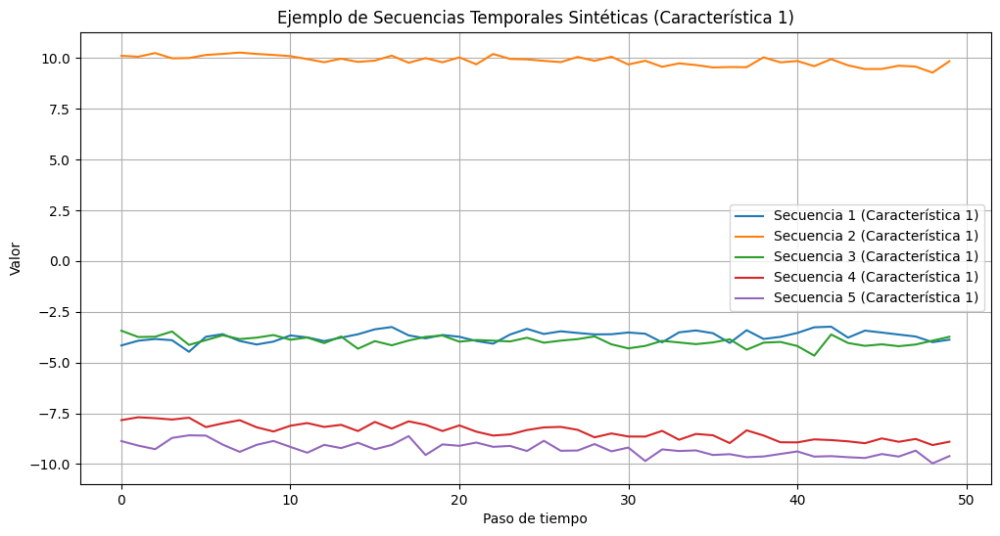

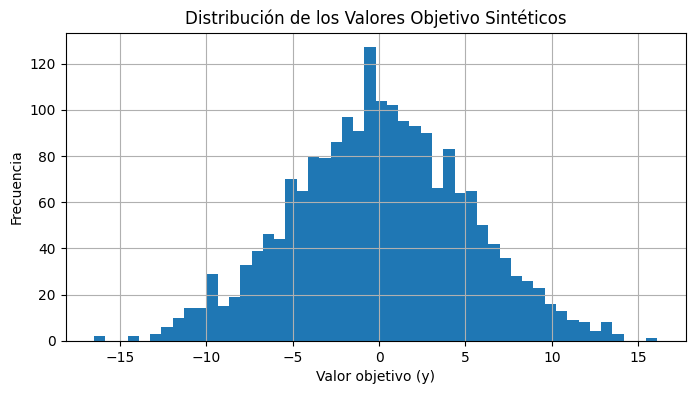

In [ ]:
# prompt: Un generador de datos sintéticos, par a modelos , tipo de datos: secuencia temporal,  cambiante en el tiempo

import matplotlib.pyplot as plt
import numpy as np
class TimeSeriesGenerator:
    def __init__(self, num_samples, sequence_length, num_features, changing_magnitude=0.1, trend_magnitude=0.01):
        """
        Generador de datos sintéticos de secuencia temporal con tendencias cambiantes.

        Args:
            num_samples (int): Número de secuencias a generar.
            sequence_length (int): Longitud de cada secuencia.
            num_features (int): Número de características por paso de tiempo.
            changing_magnitude (float): Magnitud de la variabilidad en el tiempo.
            trend_magnitude (float): Magnitud de la tendencia general.
        """
        self.num_samples = num_samples
        self.sequence_length = sequence_length
        self.num_features = num_features
        self.changing_magnitude = changing_magnitude
        self.trend_magnitude = trend_magnitude

    def generate(self):
        """
        Genera un dataset de secuencias temporales sintéticas.

        Returns:
            tuple: Tupla de arrays numpy (X, y).
                   X: (num_samples, sequence_length, num_features)
                   y: (num_samples,) - valor objetivo asociado a cada secuencia.
        """
        X = np.zeros((self.num_samples, self.sequence_length, self.num_features))
        y = np.zeros(self.num_samples)

        for i in range(self.num_samples):
            # Generar una base aleatoria para la secuencia
            base_values = np.random.randn(self.num_features) * 5

            # Generar una tendencia aleatoria por característica
            trends = np.random.randn(self.num_features) * self.trend_magnitude

            # Generar variabilidad a lo largo de la secuencia
            time_variation = np.random.randn(self.sequence_length, self.num_features) * self.changing_magnitude

            # Construir la secuencia
            sequence = np.zeros((self.sequence_length, self.num_features))
            for t in range(self.sequence_length):
                # Aplicar base, tendencia y variación en el tiempo
                sequence[t, :] = base_values + trends * t + time_variation[t, :]
                # Añadir un poco de ruido extra por paso de tiempo
                sequence[t, :] += np.random.randn(self.num_features) * 0.05

            X[i] = sequence

            # Generar un valor objetivo 'y' basado en la secuencia
            # Ejemplo: promedio de los últimos 3 pasos de la primera característica + ruido
            y[i] = np.mean(sequence[-3:, 0]) + np.random.randn() * 0.1

        return X, y

# Ejemplo de uso del generador
num_samples_synth = 2000
sequence_length_synth = 50
num_features_synth = 10

synth_generator = TimeSeriesGenerator(
    num_samples=num_samples_synth,
    sequence_length=sequence_length_synth,
    num_features=num_features_synth,
    changing_magnitude=0.2,  # Ajusta para más o menos variabilidad en el tiempo
    trend_magnitude=0.02     # Ajusta para tendencias más o menos pronunciadas
)

X_synth, y_synth = synth_generator.generate()

print(f"Dataset sintético generado:")
print(f"  X_synth shape: {X_synth.shape}")
print(f"  y_synth shape: {y_synth.shape}")

# Opcional: Visualizar algunas secuencias de ejemplo
plt.figure(figsize=(12, 6))
for i in range(min(5, num_samples_synth)): # Mostrar las primeras 5 secuencias
    plt.plot(X_synth[i, :, 0], label=f'Secuencia {i+1} (Característica 1)') # Mostrar solo la primera característica
plt.xlabel("Paso de tiempo")
plt.ylabel("Valor")
plt.title("Ejemplo de Secuencias Temporales Sintéticas (Característica 1)")
plt.legend()
plt.grid(True)
plt.show()

# Opcional: Visualizar la distribución de los valores objetivo
plt.figure(figsize=(8, 4))
plt.hist(y_synth, bins=50)
plt.xlabel("Valor objetivo (y)")
plt.ylabel("Frecuencia")
plt.title("Distribución de los Valores Objetivo Sintéticos")
plt.grid(True)
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

class TimeSeriesGenerator:
    def __init__(self, num_samples, sequence_length, num_features, changing_magnitude=0.1, trend_magnitude=0.01):
        self.num_samples = num_samples
        self.sequence_length = sequence_length
        self.num_features = num_features
        self.changing_magnitude = changing_magnitude
        self.trend_magnitude = trend_magnitude

    def generate(self):
        X = np.zeros((self.num_samples, self.sequence_length, self.num_features))
        y = np.zeros(self.num_samples)

        for i in range(self.num_samples):
            base_values = np.random.randn(self.num_features) * 5
            trends = np.random.randn(self.num_features) * self.trend_magnitude
            time_variation = np.random.randn(self.sequence_length, self.num_features) * self.changing_magnitude

            sequence = np.zeros((self.sequence_length, self.num_features))
            for t in range(self.sequence_length):
                sequence[t, :] = base_values + trends * t + time_variation[t, :]
                sequence[t, :] += np.random.randn(self.num_features) * 0.05

            X[i] = sequence
            y[i] = np.mean(sequence[-3:, 0]) + np.random.randn() * 0.1

        return X, y

# Parámetros del generador
num_samples_synth = 2000
sequence_length_synth = 50
num_features_synth = 10

synth_generator = TimeSeriesGenerator(
    num_samples=num_samples_synth,
    sequence_length=sequence_length_synth,
    num_features=num_features_synth,
    changing_magnitude=0.2,
    trend_magnitude=0.02
)

X_synth, y_synth = synth_generator.generate()

# Visualizar algunas secuencias de ejemplo
plt.figure(figsize=(12, 6))
for i in range(5):
    plt.plot(X_synth[i, :, 0], label=f'Secuencia {i+1}')
plt.xlabel("Paso de tiempo")
plt.ylabel("Valor")
plt.title("Ejemplo de Secuencias Temporales Sintéticas (Característica 1)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Visualizar la distribución de los valores objetivo
plt.figure(figsize=(8, 4))
plt.hist(y_synth, bins=50)
plt.xlabel("Valor objetivo (y)")
plt.ylabel("Frecuencia")
plt.title("Distribución de los Valores Objetivo Sintéticos")
plt.grid(True)
plt.tight_layout()
plt.show()

#justa1

--- Modelo SGD ---


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 385 (1.50 KB)

 Trainable params: 385 (1.50 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 385 (1.50 KB)

 Trainable params: 385 (1.50 KB)

 Non-trainable params: 0 (0.00 B)


Entrenando Modelo SGD...
Entrenando Modelo Adam...

--- Resultados ---
MSE del Modelo SGD en datos de prueba: 0.0155
MSE del Modelo Adam en datos de prueba: 0.0142


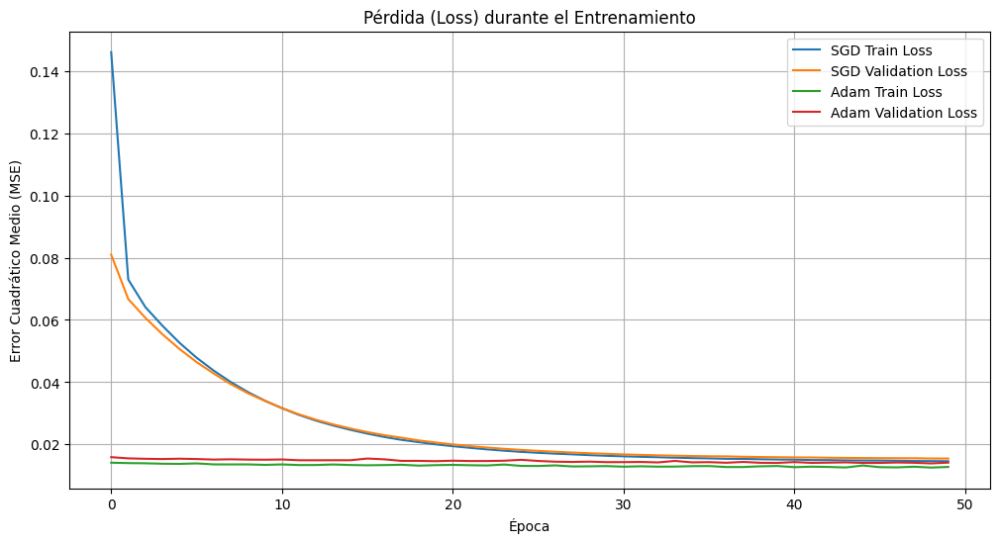

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


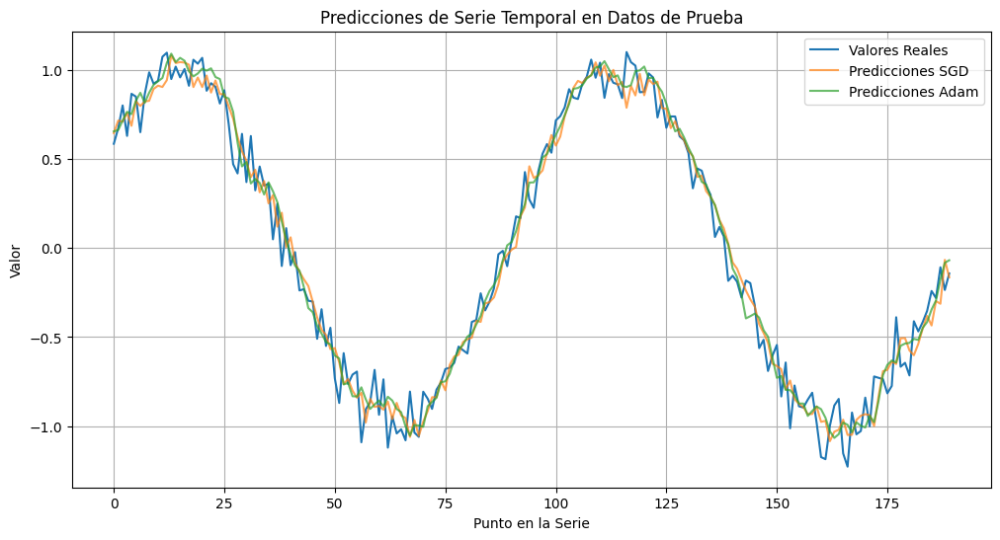

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# --- 1. Generación del Dataset de Onda Sinusoidal ---
def generar_serie_sinusoidal(n_puntos, ventana_entrada):
    x = np.linspace(0, 20 * np.pi, n_puntos)
    y = np.sin(x) + np.random.normal(0, 0.1, n_puntos) # Onda sinusoidal con algo de ruido

    X, Y = [], []
    for i in range(len(y) - ventana_entrada):
        X.append(y[i:(i + ventana_entrada)])
        Y.append(y[i + ventana_entrada])
    return np.array(X), np.array(Y)

N_PUNTOS = 1000
VENTANA_ENTRADA = 10 # Usar 10 puntos anteriores para predecir el siguiente

X_data, Y_data = generar_serie_sinusoidal(N_PUNTOS, VENTANA_ENTRADA)

# Dividir en conjuntos de entrenamiento y prueba
split_ratio = 0.8
split_index = int(N_PUNTOS * split_ratio)

X_train, Y_train = X_data[:split_index], Y_data[:split_index]
X_test, Y_test = X_data[split_index:], Y_data[split_index:]

# --- 2. Los Modelos ---

# Modelo con "Neurona Común" (SGD Básico)
model_sgd = tf.keras.Sequential([
    # Una capa densa que procesa la ventana de entrada
    tf.keras.layers.Dense(32, activation='relu', input_shape=(VENTANA_ENTRADA,)),
    # Una sola neurona de salida para predecir el siguiente valor
    tf.keras.layers.Dense(1)
])
model_sgd.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.01), loss='mse')
print("--- Modelo SGD ---")
model_sgd.summary()

# Modelo con "Historial Mejorado" (SGD experimental)

model_sgdm = tf.keras.Sequential([
    # Una capa densa que procesa la ventana de entrada
    tf.keras.layers.Dense(32, activation='relu', input_shape=(VENTANA_ENTRADA,)),
    # Una sola neurona de salida para predecir el siguiente valor
    tf.keras.layers.Dense(1)
])
model_sgd.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.01), loss='mse')
print("--- Modelo SGD ---")
model_sgd.summary()

# --- 3. Entrenamiento y Evaluación ---

EPOCHS = 50 # Número de veces que el modelo verá todo el dataset

print("\nEntrenando Modelo SGD...")
history_sgd = model_sgd.fit(X_train, Y_train, epochs=EPOCHS, verbose=0, validation_data=(X_test, Y_test))

print("Entrenando Modelo Adam...")
history_adam = model_adam.fit(X_train, Y_train, epochs=EPOCHS, verbose=0, validation_data=(X_test, Y_test))

# Evaluación de rendimiento en el conjunto de prueba
loss_sgd = model_sgd.evaluate(X_test, Y_test, verbose=0)
loss_adam = model_adam.evaluate(X_test, Y_test, verbose=0)

print(f"\n--- Resultados ---")
print(f"MSE del Modelo SGD en datos de prueba: {loss_sgd:.4f}")
print(f"MSE del Modelo Adam en datos de prueba: {loss_adam:.4f}")

# Visualización del aprendizaje (pérdida en el tiempo)
plt.figure(figsize=(12, 6))
plt.plot(history_sgd.history['loss'], label='SGD Train Loss')
plt.plot(history_sgd.history['val_loss'], label='SGD Validation Loss')
plt.plot(history_adam.history['loss'], label='Adam Train Loss')
plt.plot(history_adam.history['val_loss'], label='Adam Validation Loss')
plt.title('Pérdida (Loss) durante el Entrenamiento')
plt.xlabel('Época')
plt.ylabel('Error Cuadrático Medio (MSE)')
plt.legend()
plt.grid(True)
plt.show()

# Visualización de predicciones
predicciones_sgd = model_sgd.predict(X_test)
predicciones_adam = model_adam.predict(X_test)

plt.figure(figsize=(12, 6))
plt.plot(Y_test, label='Valores Reales')
plt.plot(predicciones_sgd, label='Predicciones SGD', alpha=0.7)
plt.plot(predicciones_adam, label='Predicciones Adam', alpha=0.7)
plt.title('Predicciones de Serie Temporal en Datos de Prueba')
plt.xlabel('Punto en la Serie')
plt.ylabel('Valor')
plt.legend()
plt.grid(True)
plt.show()

--- Modelo SGD Básico ---


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 385 (1.50 KB)

 Trainable params: 385 (1.50 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 385 (1.50 KB)

 Trainable params: 385 (1.50 KB)

 Non-trainable params: 0 (0.00 B)


Entrenando Modelo SGD Básico...
Entrenando Modelo SGD con Momentum (Experimental)...

--- Resultados ---
MSE del Modelo SGD Básico en datos de prueba: 0.0166
MSE del Modelo SGD con Momentum en datos de prueba: 0.0144


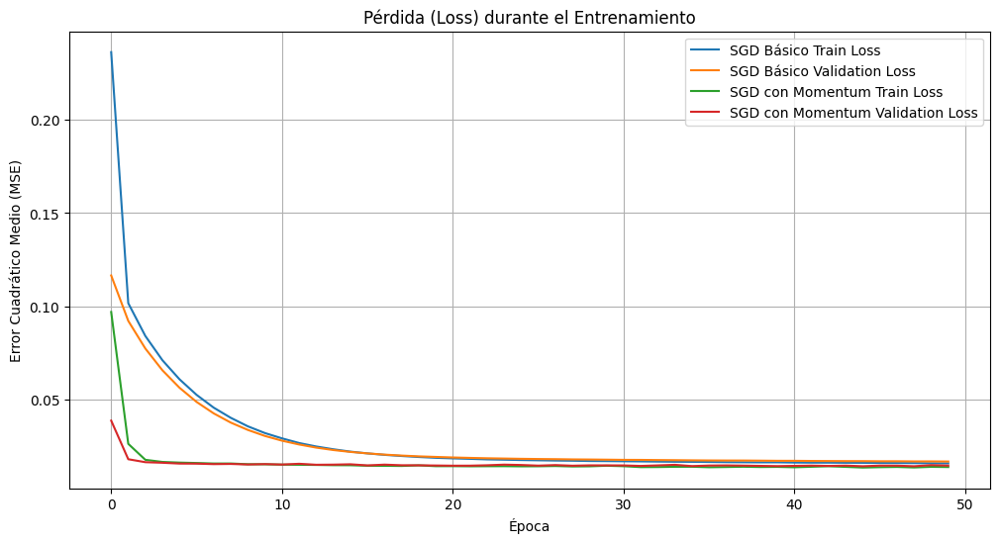

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


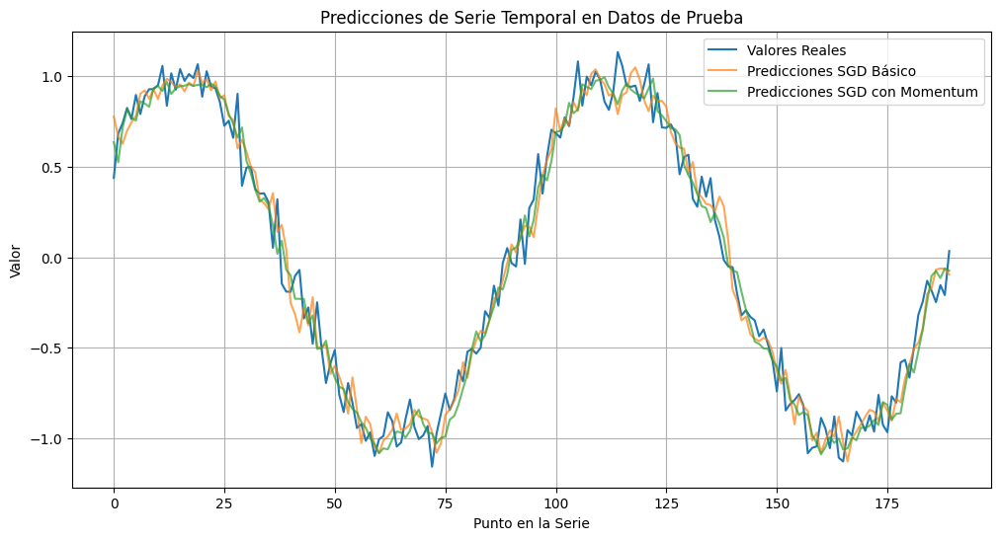

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# --- 1. Generación del Dataset de Onda Sinusoidal ---
def generar_serie_sinusoidal(n_puntos, ventana_entrada):
    x = np.linspace(0, 20 * np.pi, n_puntos)
    y = np.sin(x) + 0.1 * np.random.randn(n_puntos) # Onda sinusoidal con algo de ruido

    X, Y = [], []
    for i in range(len(y) - ventana_entrada):
        X.append(y[i:(i + ventana_entrada)])
        Y.append(y[i + ventana_entrada])
    return np.array(X), np.array(Y)

N_PUNTOS = 1000
VENTANA_ENTRADA = 10 # Usar 10 puntos anteriores para predecir el siguiente

X_data, Y_data = generar_serie_sinusoidal(N_PUNTOS, VENTANA_ENTRADA)

# Dividir en conjuntos de entrenamiento y prueba
split_ratio = 0.8
split_index = int(N_PUNTOS * split_ratio)

X_train, Y_train = X_data[:split_index], Y_data[:split_index]
X_test, Y_test = X_data[split_index:], Y_data[split_index:]

# --- 2. Los Modelos ---

# Modelo con "Neurona Común" (SGD Básico)
model_sgd = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(VENTANA_ENTRADA,)),
    tf.keras.layers.Dense(1)
])
model_sgd.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.01), loss='mse')
print("--- Modelo SGD Básico ---")
model_sgd.summary()

# Modelo con "SGD Experimental con Momentum"
# Esto simula un "historial" al considerar los gradientes pasados
model_sgdm = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(VENTANA_ENTRADA,)),
    tf.keras.layers.Dense(1)
])
# Usamos SGD con momentum. El momentum es un "historial" de la dirección de los gradientes.
model_sgdm.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9), loss='mse')
print("\n--- Modelo SGD con Momentum (Experimental) ---")
model_sgdm.summary()

# --- 3. Entrenamiento y Evaluación ---

EPOCHS = 50 # Número de veces que el modelo verá todo el dataset

print("\nEntrenando Modelo SGD Básico...")
history_sgd = model_sgd.fit(X_train, Y_train, epochs=EPOCHS, verbose=0, validation_data=(X_test, Y_test))

print("Entrenando Modelo SGD con Momentum (Experimental)...")
history_sgdm = model_sgdm.fit(X_train, Y_train, epochs=EPOCHS, verbose=0, validation_data=(X_test, Y_test))

# Evaluación de rendimiento en el conjunto de prueba
loss_sgd = model_sgd.evaluate(X_test, Y_test, verbose=0)
loss_sgdm = model_sgdm.evaluate(X_test, Y_test, verbose=0)

print(f"\n--- Resultados ---")
print(f"MSE del Modelo SGD Básico en datos de prueba: {loss_sgd:.4f}")
print(f"MSE del Modelo SGD con Momentum en datos de prueba: {loss_sgdm:.4f}")

# Visualización del aprendizaje (pérdida en el tiempo)
plt.figure(figsize=(12, 6))
plt.plot(history_sgd.history['loss'], label='SGD Básico Train Loss')
plt.plot(history_sgd.history['val_loss'], label='SGD Básico Validation Loss')
plt.plot(history_sgdm.history['loss'], label='SGD con Momentum Train Loss')
plt.plot(history_sgdm.history['val_loss'], label='SGD con Momentum Validation Loss')
plt.title('Pérdida (Loss) durante el Entrenamiento')
plt.xlabel('Época')
plt.ylabel('Error Cuadrático Medio (MSE)')
plt.legend()
plt.grid(True)
plt.show()

# Visualización de predicciones
predicciones_sgd = model_sgd.predict(X_test)
predicciones_sgdm = model_sgdm.predict(X_test)

plt.figure(figsize=(12, 6))
plt.plot(Y_test, label='Valores Reales')
plt.plot(predicciones_sgd, label='Predicciones SGD Básico', alpha=0.7)
plt.plot(predicciones_sgdm, label='Predicciones SGD con Momentum', alpha=0.7)
plt.title('Predicciones de Serie Temporal en Datos de Prueba')
plt.xlabel('Punto en la Serie')
plt.ylabel('Valor')
plt.legend()
plt.grid(True)
plt.show()

Entrenando modelo común...
Entrenando modelo con estado adaptativo...

--- Resultados ---
Modelo denso (común): MSE = 0.0117
Modelo con estado interno adaptativo: MSE = 0.0121


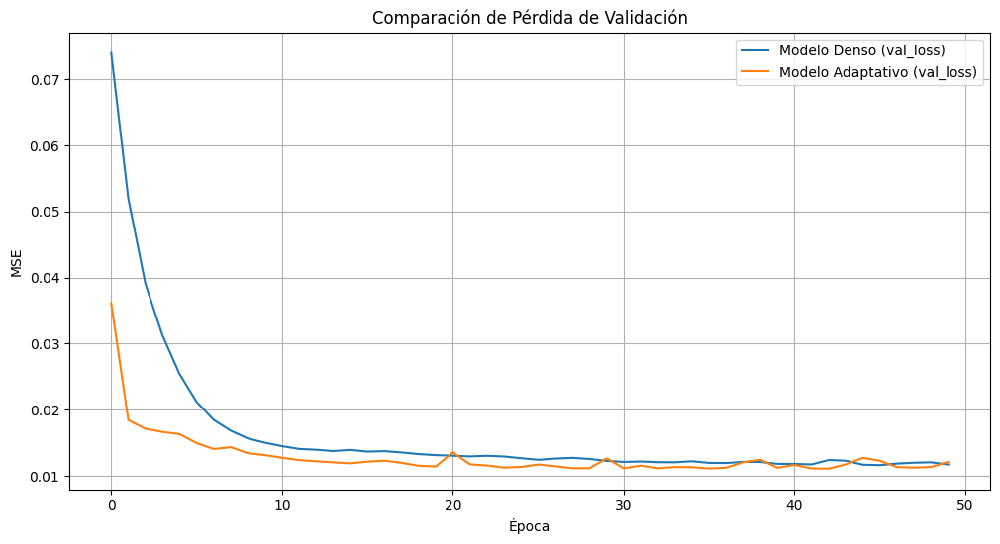

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


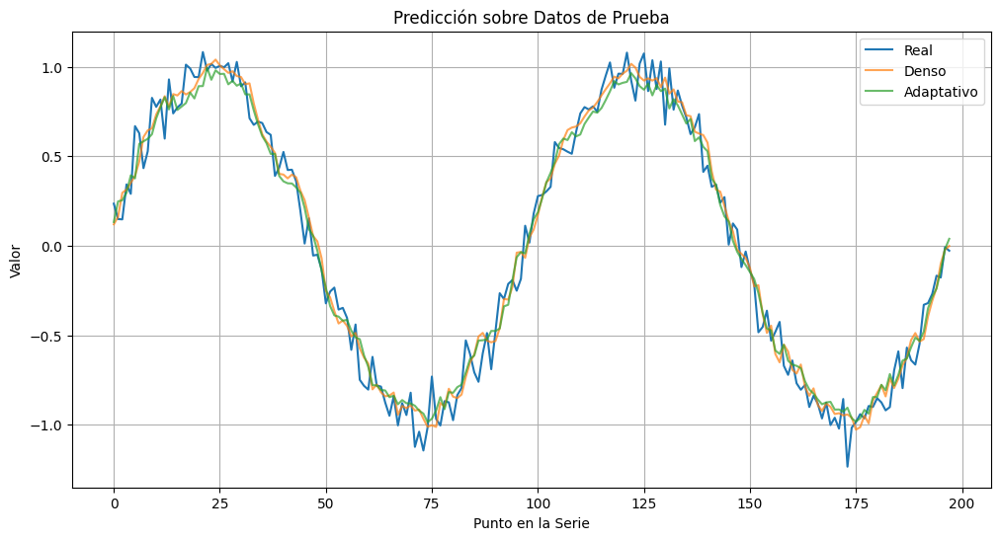

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# --- 1. Dataset de Onda Sinusoidal ---
def generar_serie_sinusoidal(n_puntos, ventana_entrada):
    x = np.linspace(0, 20 * np.pi, n_puntos)
    y = np.sin(x) + 0.1 * np.random.randn(n_puntos)  # ruido leve

    X, Y = [], []
    for i in range(len(y) - ventana_entrada):
        X.append(y[i:(i + ventana_entrada)])
        Y.append(y[i + ventana_entrada])
    return np.array(X), np.array(Y)

N_PUNTOS = 1000
VENTANA_ENTRADA = 10
X_data, Y_data = generar_serie_sinusoidal(N_PUNTOS, VENTANA_ENTRADA)

# Entrenamiento / Prueba
split_ratio = 0.8
split_index = int(len(X_data) * split_ratio)
X_train, Y_train = X_data[:split_index], Y_data[:split_index]
X_test, Y_test = X_data[split_index:], Y_data[split_index:]

# --- 2. Capa con Estado Interno Adaptativo ---
class NeuronaEstadoInterno(tf.keras.layers.Layer):
    def __init__(self, unidades):
        super().__init__()
        self.unidades = unidades

    def build(self, input_shape):
        self.w_input = self.add_weight(shape=(input_shape[-1], self.unidades),
                                       initializer='glorot_uniform', trainable=True)
        self.w_state = self.add_weight(shape=(self.unidades, self.unidades),
                                       initializer='orthogonal', trainable=True)
        self.b = self.add_weight(shape=(self.unidades,), initializer='zeros', trainable=True)
        self.initial_state = self.add_weight(shape=(self.unidades,), initializer='zeros', trainable=True)

    def call(self, inputs):
        # Inicializar el estado interno como una variable que persiste durante la llamada
        state = tf.tile(tf.expand_dims(self.initial_state, 0), [tf.shape(inputs)[0], 1])
        state = tf.nn.tanh(tf.matmul(inputs, self.w_input) + tf.matmul(state, self.w_state) + self.b)
        return state

# --- 3. Modelos ---

# Modelo convencional
modelo_denso = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(VENTANA_ENTRADA,)),
    tf.keras.layers.Dense(1)
])
modelo_denso.compile(optimizer='adam', loss='mse')

# Modelo con estado adaptativo
modelo_estado = tf.keras.Sequential([
    NeuronaEstadoInterno(32),
    tf.keras.layers.Dense(1)
])
modelo_estado.compile(optimizer='adam', loss='mse')

# --- 4. Entrenamiento ---
EPOCHS = 50
print("Entrenando modelo común...")
hist_denso = modelo_denso.fit(X_train, Y_train, epochs=EPOCHS, validation_data=(X_test, Y_test), verbose=0)

print("Entrenando modelo con estado adaptativo...")
hist_estado = modelo_estado.fit(X_train, Y_train, epochs=EPOCHS, validation_data=(X_test, Y_test), verbose=0)

# --- 5. Evaluación ---
loss_denso = modelo_denso.evaluate(X_test, Y_test, verbose=0)
loss_estado = modelo_estado.evaluate(X_test, Y_test, verbose=0)

print("\n--- Resultados ---")
print(f"Modelo denso (común): MSE = {loss_denso:.4f}")
print(f"Modelo con estado interno adaptativo: MSE = {loss_estado:.4f}")

# --- 6. Visualización de la pérdida ---
plt.figure(figsize=(12, 6))
plt.plot(hist_denso.history['val_loss'], label='Modelo Denso (val_loss)')
plt.plot(hist_estado.history['val_loss'], label='Modelo Adaptativo (val_loss)')
plt.title("Comparación de Pérdida de Validación")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.legend()
plt.grid(True)
plt.show()

# --- 7. Predicciones ---
pred_denso = modelo_denso.predict(X_test)
pred_estado = modelo_estado.predict(X_test)

plt.figure(figsize=(12, 6))
plt.plot(Y_test, label='Real')
plt.plot(pred_denso, label='Denso', alpha=0.7)
plt.plot(pred_estado, label='Adaptativo', alpha=0.7)
plt.title("Predicción sobre Datos de Prueba")
plt.xlabel("Punto en la Serie")
plt.ylabel("Valor")
plt.legend()
plt.grid(True)
plt.show()

Modelo Base:


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_21 (Dense)                │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 385 (1.50 KB)

 Trainable params: 385 (1.50 KB)

 Non-trainable params: 0 (0.00 B)

Época 1/50 - Loss Atención: 0.1298
Época 2/50 - Loss Atención: 0.0186
Época 3/50 - Loss Atención: 0.0172
Época 4/50 - Loss Atención: 0.0168
Época 5/50 - Loss Atención: 0.0168
Época 6/50 - Loss Atención: 0.0165
Época 7/50 - Loss Atención: 0.0165
Época 8/50 - Loss Atención: 0.0161
Época 9/50 - Loss Atención: 0.0160
Época 10/50 - Loss Atención: 0.0158
Época 11/50 - Loss Atención: 0.0157
Época 12/50 - Loss Atención: 0.0154
Época 13/50 - Loss Atención: 0.0155
Época 14/50 - Loss Atención: 0.0152
Época 15/50 - Loss Atención: 0.0149
Época 16/50 - Loss Atención: 0.0149
Época 17/50 - Loss Atención: 0.0148
Época 18/50 - Loss Atención: 0.0147
Época 19/50 - Loss Atención: 0.0145
Época 20/50 - Loss Atención: 0.0144
Época 21/50 - Loss Atención: 0.0143
Época 22/50 - Loss Atención: 0.0142
Época 23/50 - Loss Atención: 0.0142
Época 24/50 - Loss Atención: 0.0141
Época 25/50 - Loss Atención: 0.0141
Época 26/50 - Loss Atención: 0.0139
Época 27/50 - Loss Atención: 0.0139
Época 28/50 - Loss Atención: 0.0138
É

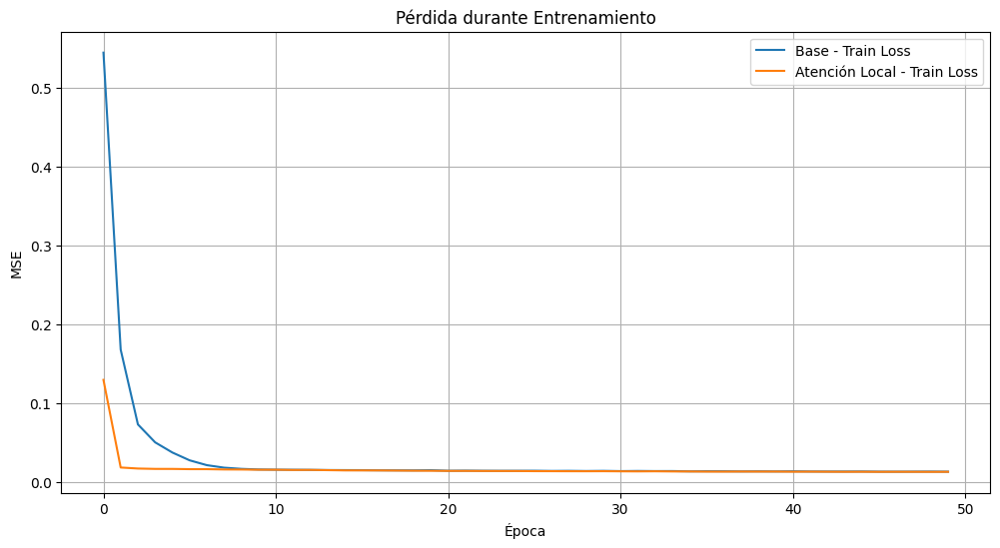

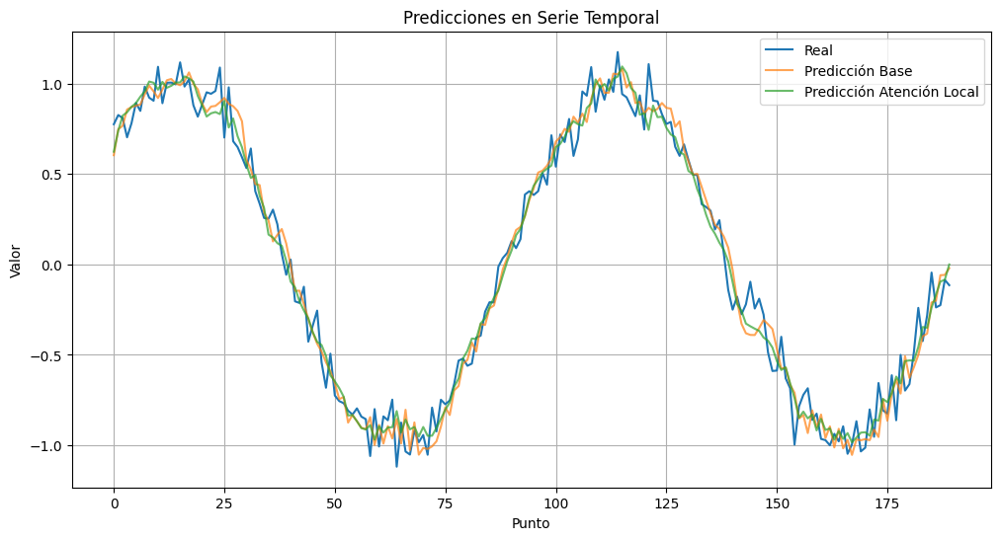

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# --- 1. Dataset: Serie Temporal Senoidal con Ruido ---
def generar_serie_sinusoidal(n_puntos, ventana):
    x = np.linspace(0, 20 * np.pi, n_puntos)
    y = np.sin(x) + 0.1 * np.random.randn(n_puntos)
    X, Y = [], []
    for i in range(len(y) - ventana):
        X.append(y[i:i+ventana])
        Y.append(y[i+ventana])
    return np.array(X), np.array(Y)

N_PUNTOS = 1000
VENTANA = 10
X_data, Y_data = generar_serie_sinusoidal(N_PUNTOS, VENTANA)

# Dividir en entrenamiento y prueba
split = int(N_PUNTOS * 0.8)
X_train, X_test = X_data[:split], X_data[split:]
Y_train, Y_test = Y_data[:split], Y_data[split:]

# --- 2. Modelo Base (Sin Atención) ---
modelo_base = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(VENTANA,)),
    tf.keras.layers.Dense(1)
])
modelo_base.compile(optimizer='adam', loss='mse')
print("Modelo Base:")
modelo_base.summary()

# --- 3. Modelo con Atención Local sobre Experiencias Pasadas ---

class CapaAtencionLocal(tf.keras.layers.Layer):
    def __init__(self, tam_buffer=5):
        super().__init__()
        self.tam_buffer = tam_buffer
        self.buffer = None
        self.buffer_errores = None

    def build(self, input_shape):
        self.buffer = self.add_weight(shape=(self.tam_buffer, input_shape[-1]),
                                      initializer='zeros',
                                      trainable=False,
                                      name='buffer_activaciones')
        self.buffer_errores = self.add_weight(shape=(self.tam_buffer,),
                                              initializer='ones',
                                              trainable=False,
                                              name='buffer_errores')

    def call(self, x, loss_actual):
        # Actualizar buffer
        activaciones = tf.squeeze(x, axis=0)
        self.buffer.assign(tf.concat([self.buffer[1:], [activaciones]], axis=0))
        self.buffer_errores.assign(tf.concat([self.buffer_errores[1:], [loss_actual]], axis=0))

        # Atender a entradas pasadas (menos error = más atención)
        pesos = 1.0 / (self.buffer_errores + 1e-6)
        pesos_normalizados = pesos / tf.reduce_sum(pesos)
        ponderado = tf.reduce_sum(self.buffer * tf.expand_dims(pesos_normalizados, -1), axis=0)

        # Concatenar entrada actual con atención del pasado
        salida = tf.concat([activaciones, ponderado], axis=0)
        return tf.expand_dims(salida, axis=0)

class ModeloAtencion(tf.keras.Model):
    def __init__(self):
        super().__init__()
        self.atencion = CapaAtencionLocal()
        self.densa1 = tf.keras.layers.Dense(32, activation='relu', input_shape=(VENTANA * 2,))
        self.salida = tf.keras.layers.Dense(1)

    def call(self, x, loss_actual):
        x_atendido = self.atencion(x, loss_actual)
        x1 = self.densa1(x_atendido)
        return self.salida(x1)

modelo_atencion = ModeloAtencion()
optimizer = tf.keras.optimizers.Adam()
loss_fn = tf.keras.losses.MeanSquaredError()

# --- 4. Entrenamiento Manual del Modelo con Atención ---
EPOCHS = 50
train_loss_hist = []

for epoch in range(EPOCHS):
    losses = []
    for xi, yi in zip(X_train, Y_train):
        xi = tf.expand_dims(xi, axis=0)
        yi = tf.expand_dims(yi, axis=0)

        with tf.GradientTape() as tape:
            pred = modelo_atencion(xi, tf.constant(1.0))  # Dummy loss inicial
            loss = loss_fn(yi, pred)

        gradients = tape.gradient(loss, modelo_atencion.trainable_variables)
        optimizer.apply_gradients(zip(gradients, modelo_atencion.trainable_variables))

        # Realimentar el loss real para la siguiente iteración
        _ = modelo_atencion(xi, loss)
        losses.append(loss.numpy())

    promedio = np.mean(losses)
    train_loss_hist.append(promedio)
    print(f"Época {epoch+1}/{EPOCHS} - Loss Atención: {promedio:.4f}")

# --- 5. Entrenamiento del Modelo Base ---
print("Entrenando modelo base...")
hist_base = modelo_base.fit(X_train, Y_train, epochs=EPOCHS, validation_data=(X_test, Y_test), verbose=0)

# --- 6. Evaluación ---
pred_base = modelo_base.predict(X_test)
loss_base = tf.keras.losses.mse(Y_test, pred_base).numpy().mean()

# Evaluar modelo con atención
preds_atencion = []
for xi in X_test:
    xi = tf.expand_dims(xi, axis=0)
    pred = modelo_atencion(xi, tf.constant(0.0))
    preds_atencion.append(pred.numpy().squeeze())

loss_atencion = tf.keras.losses.mse(Y_test, preds_atencion).numpy().mean()

# --- 7. Resultados ---
print("\n--- Comparación Final ---")
print(f"Loss Modelo Base: {loss_base:.4f}")
print(f"Loss Modelo con Atención Local: {loss_atencion:.4f}")

# --- 8. Visualización ---
plt.figure(figsize=(12, 6))
plt.plot(hist_base.history['loss'], label='Base - Train Loss')
plt.plot(train_loss_hist, label='Atención Local - Train Loss')
plt.title('Pérdida durante Entrenamiento')
plt.xlabel('Época')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)
plt.show()

# Visualización de predicciones
plt.figure(figsize=(12, 6))
plt.plot(Y_test, label='Real')
plt.plot(pred_base, label='Predicción Base', alpha=0.7)
plt.plot(preds_atencion, label='Predicción Atención Local', alpha=0.7)
plt.title('Predicciones en Serie Temporal')
plt.xlabel('Punto')
plt.ylabel('Valor')
plt.legend()
plt.grid(True)
plt.show()

Época 0 - Loss: 77.0284
Época 50 - Loss: 24.2435
Época 100 - Loss: 19.4819
Época 150 - Loss: 18.6679
Época 200 - Loss: 18.3113
Época 250 - Loss: 18.1099


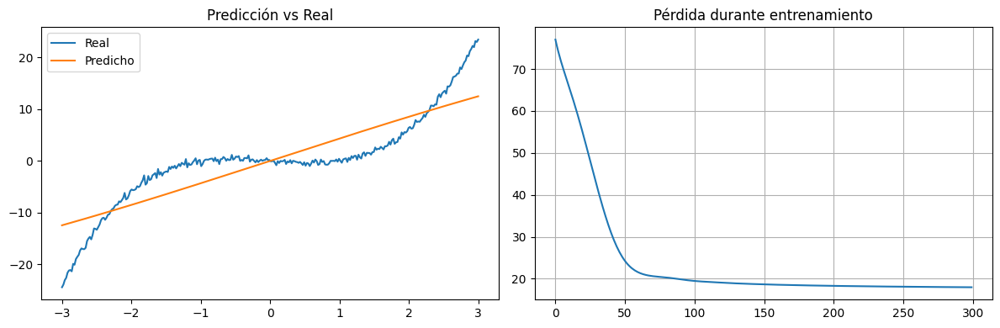

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from collections import deque

# Dataset artificial
torch.manual_seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1)
y = X.pow(3) - X + 0.4 * torch.randn_like(X)

# -----------------------------------------
# 🧠 Capa con Memoria de Fallas (errores grandes)
# -----------------------------------------
class CapaConMemoriaErrores(nn.Module):
    def __init__(self, in_features, out_features, k=10, lr_extra=0.01):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features

        self.pesos = nn.Parameter(torch.randn(out_features, in_features) * 0.1)
        self.bias = nn.Parameter(torch.zeros(out_features))

        self.k = k
        self.lr_extra = lr_extra  # tasa de aprendizaje extra para fallos
        self.buffer_fallas = deque(maxlen=k)  # [(x, error), ...]

    def forward(self, x):
        self.entrada_actual = x.detach()
        z = F.linear(x, self.pesos, self.bias)
        self.activacion = torch.tanh(z)
        return self.activacion

    def actualizar_memoria(self, x, error_batch):
        """
        Guarda las K entradas con errores mayores.
        """
        magnitudes_error = error_batch.abs().mean(dim=1)  # error por muestra
        for i in range(x.size(0)):
            entrada = x[i].detach()
            error = magnitudes_error[i].item()
            self.buffer_fallas.append((entrada, error))

    def aplicar_correccion_memoria(self):
        """
        Recorre la memoria de errores y realiza pequeñas correcciones extra.
        """
        if not self.buffer_fallas:
            return

        # Agrupa las entradas con mayor error
        entradas = torch.stack([x for (x, _) in self.buffer_fallas])  # shape: [k, in_features]
        entradas = entradas.to(self.pesos.device)

        with torch.no_grad():
            z = F.linear(entradas, self.pesos, self.bias)
            activacion = torch.tanh(z)
            # Para el ejemplo, corregimos hacia activación = 0 (neutro)
            error_local = activacion  # queremos minimizarla

            # Corrección tipo Hebbiana (simplificada)
            grad_w = torch.matmul(error_local.T, entradas) / entradas.size(0)
            grad_b = error_local.mean(dim=0)

            self.pesos.data -= self.lr_extra * grad_w
            self.bias.data -= self.lr_extra * grad_b

# -----------------------------------------
# Red con memoria de errores
# -----------------------------------------
class RedMemoriaErrores(nn.Module):
    def __init__(self):
        super().__init__()
        self.capa1 = CapaConMemoriaErrores(1, 30, k=15, lr_extra=0.005)
        self.salida = nn.Linear(30, 1)

    def forward(self, x):
        h = self.capa1(x)
        return self.salida(h)

# -----------------------------------------
# Entrenamiento
# -----------------------------------------
modelo = RedMemoriaErrores()
opt = torch.optim.Adam(list(modelo.parameters()), lr=0.01)
loss_fn = nn.MSELoss()

historial_loss = []

for epoch in range(300):
    y_pred = modelo(X)
    loss = loss_fn(y_pred, y)
    historial_loss.append(loss.item())

    opt.zero_grad()
    loss.backward()
    opt.step()

    # Almacenar errores recientes
    error_batch = y_pred - y
    modelo.capa1.actualizar_memoria(X, error_batch)

    # Corrección adicional con memoria
    modelo.capa1.aplicar_correccion_memoria()

    if epoch % 50 == 0:
        print(f"Época {epoch} - Loss: {loss.item():.4f}")

# -----------------------------------------
# Visualización
# -----------------------------------------
with torch.no_grad():
    pred = modelo(X)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.title("Predicción vs Real")
plt.plot(X.numpy(), y.numpy(), label="Real")
plt.plot(X.numpy(), pred.numpy(), label="Predicho")
plt.legend()

plt.subplot(1, 2, 2)
plt.title("Pérdida durante entrenamiento")
plt.plot(historial_loss)
plt.grid(True)

plt.tight_layout()
plt.show()

--- Entrenando Red con Memoria de Errores ---
Memoria - Época 0 - Pérdida: 77.028419
Memoria - Época 50 - Pérdida: 25.040039
Memoria - Época 100 - Pérdida: 19.585455
Memoria - Época 150 - Pérdida: 18.705057
Memoria - Época 200 - Pérdida: 18.327181
Memoria - Época 250 - Pérdida: 18.116608

--- Entrenando Red Estándar ---
Estándar - Época 0 - Pérdida: 76.361992
Estándar - Época 50 - Pérdida: 24.796627
Estándar - Época 100 - Pérdida: 15.770713
Estándar - Época 150 - Pérdida: 8.859932
Estándar - Época 200 - Pérdida: 4.234005
Estándar - Época 250 - Pérdida: 2.013969


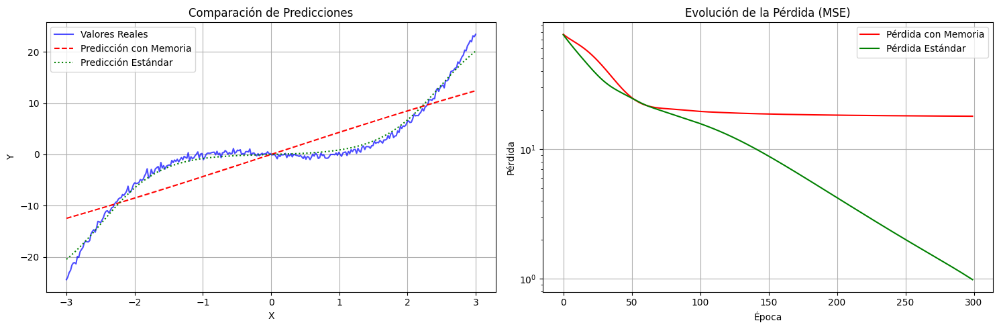


--- Resumen de Pérdidas Finales ---
Pérdida final (Red con Memoria): 17.983326
Pérdida final (Red Estándar):    0.987521


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from collections import deque
import numpy as np

# Dataset artificial
torch.manual_seed(0)
np.random.seed(0) # Asegurar reproducibilidad del ruido
X = torch.linspace(-3, 3, 300).unsqueeze(1)
y = X.pow(3) - X + 0.4 * torch.randn_like(X)

# -----------------------------------------
# 🧠 Capa con Memoria de Fallas (errores grandes)
# -----------------------------------------
class CapaConMemoriaErrores(nn.Module):
    def __init__(self, in_features, out_features, k=10, lr_extra=0.01):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features

        self.pesos = nn.Parameter(torch.randn(out_features, in_features) * 0.1)
        self.bias = nn.Parameter(torch.zeros(out_features))

        self.k = k
        self.lr_extra = lr_extra  # tasa de aprendizaje extra para fallos
        # buffer_fallas almacena tuplas de (entrada, error_magnitud)
        self.buffer_fallas = deque(maxlen=k)

    def forward(self, x):
        self.entrada_actual = x.detach()
        z = F.linear(x, self.pesos, self.bias)
        self.activacion = torch.tanh(z)
        return self.activacion

    def actualizar_memoria(self, x_batch, error_batch_global):
        """
        Almacena las 'k' muestras con los mayores errores en el batch actual.
        """
        # Calcular el error absoluto promedio por muestra
        # Usamos abs().mean(dim=1) para obtener una magnitud de error por cada fila (muestra)
        errores_por_muestra = error_batch_global.abs().mean(dim=1)

        # Emparejar error con la entrada y mantenerlas en una lista para ordenar
        muestras_con_error = []
        for i in range(x_batch.size(0)):
            muestras_con_error.append((x_batch[i].detach(), errores_por_muestra[i].item()))

        # Ordenar por error de mayor a menor y añadir al buffer (los más grandes se quedan)
        # Añadimos solo si el error es significativo (opcional, para filtrar ruido)
        muestras_con_error.sort(key=lambda item: item[1], reverse=True)

        # Añadir al buffer, manteniendo solo los 'k' más grandes si el buffer no está lleno,
        # o los más grandes que superen a los actuales en el buffer (lógica más compleja)
        # Por simplicidad, aquí solo añadimos todos los del batch y el deque se encarga del maxlen.
        # Si quieres solo los 'k' mayores del batch, sería algo como:
        for i in range(min(self.k, len(muestras_con_error))):
             self.buffer_fallas.append(muestras_con_error[i])


    def aplicar_correccion_memoria(self):
        """
        Recorre la memoria de fallas y realiza correcciones adicionales en los pesos
        para mejorar el rendimiento en esos puntos de "falla" pasados.
        """
        if not self.buffer_fallas:
            return

        # Extraer entradas del buffer
        entradas_fallas = torch.stack([item[0] for item in self.buffer_fallas]).to(self.pesos.device)

        # Calcular las activaciones de estas entradas con los pesos actuales
        # No queremos que esto afecte el gradiente principal de la red
        with torch.no_grad():
            z_fallas = F.linear(entradas_fallas, self.pesos, self.bias)
            activacion_fallas = torch.tanh(z_fallas)

        # Aquí definimos la "dirección deseada" para estas fallas.
        # Por ejemplo, si queremos que la neurona sea "menos activa" para ciertos inputs
        # o que su activación se acerque a un valor deseado para esa falla.
        # En este ejemplo, el error_local es simplemente la activación, sugiriendo que queremos reducirla.
        # Esto es una simplificación de una regla de aprendizaje más compleja.
        # Un enfoque más general sería:
        # error_deseado = 0.0 # O algún otro valor objetivo
        # error_local = activacion_fallas - error_deseado

        # Para el ejemplo, seguimos tu lógica de corregir hacia una activación más neutra.
        # Si la activación es positiva, queremos reducir pesos. Si es negativa, queremos aumentarlos.
        error_local = activacion_fallas # Queremos que estas activaciones se muevan hacia cero

        # Calcular un pseudo-gradiente para estos puntos de falla
        # Esto es una forma de regla de aprendizaje local.
        # El gradiente de la activación con respecto a los pesos/bias
        # multiplicado por el error local.
        grad_w_extra = torch.matmul(error_local.T, entradas_fallas) / entradas_fallas.size(0)
        grad_b_extra = error_local.mean(dim=0)

        # Aplicar la corrección adicional
        with torch.no_grad():
            self.pesos.data -= self.lr_extra * grad_w_extra
            self.bias.data -= self.lr_extra * grad_b_extra

# -----------------------------------------
# Red principal que usa la CapaConMemoriaErrores
# -----------------------------------------
class RedMemoriaErrores(nn.Module):
    def __init__(self):
        super().__init__()
        # La primera capa usa la capa con memoria
        self.capa1 = CapaConMemoriaErrores(1, 30, k=15, lr_extra=0.005) # k=15 fallas, lr_extra=0.005
        # Capa de salida estándar
        self.salida = nn.Linear(30, 1)

    def forward(self, x):
        h = self.capa1(x)
        return self.salida(h)

# -----------------------------------------
# Red Estándar para comparación justa
# -----------------------------------------
class RedEstandar(nn.Module):
    def __init__(self):
        super().__init__()
        # La primera capa es una nn.Linear estándar con la misma configuración
        self.capa1 = nn.Linear(1, 30)
        # Capa de salida estándar
        self.salida = nn.Linear(30, 1)

    def forward(self, x):
        # Aplicar tanh explícitamente para que la activación sea la misma que CapaConMemoriaErrores
        h = torch.tanh(self.capa1(x))
        return self.salida(h)

# -----------------------------------------
# Configuración de Entrenamiento Común
# -----------------------------------------
LEARNING_RATE = 0.01 # Tasa de aprendizaje para Adam
EPOCHS = 300
LOSS_FN = nn.MSELoss()

# -----------------------------------------
# Instanciar y Entrenar Red con Memoria de Errores
# -----------------------------------------
print("--- Entrenando Red con Memoria de Errores ---")
modelo_memoria = RedMemoriaErrores()
# Optimizamos TODOS los parámetros del modelo, incluyendo los de CapaConMemoriaErrores
opt_memoria = torch.optim.Adam(modelo_memoria.parameters(), lr=LEARNING_RATE)
historial_loss_memoria = []

for epoch in range(EPOCHS):
    y_pred_memoria = modelo_memoria(X)
    # Usar el nombre de variable correcto LOSS_FN
    loss_memoria = LOSS_FN(y_pred_memoria, y)
    historial_loss_memoria.append(loss_memoria.item())

    opt_memoria.zero_grad()
    loss_memoria.backward() # Calcula gradientes para Adam

    opt_memoria.step() # Aplica el paso de Adam

    # 🚨 Lógica de memoria personalizada: Actualizar y aplicar corrección
    # Pasa el batch original X y el error global del modelo
    error_batch_global = y_pred_memoria - y
    modelo_memoria.capa1.actualizar_memoria(X, error_batch_global)
    modelo_memoria.capa1.aplicar_correccion_memoria()

    if epoch % 50 == 0:
        print(f"Memoria - Época {epoch} - Pérdida: {loss_memoria.item():.6f}")

# -----------------------------------------
# Instanciar y Entrenar Red Estándar
# -----------------------------------------
print("\n--- Entrenando Red Estándar ---")
modelo_estandar = RedEstandar()
opt_estandar = torch.optim.Adam(modelo_estandar.parameters(), lr=LEARNING_RATE)
historial_loss_estandar = []

for epoch in range(EPOCHS):
    y_pred_estandar = modelo_estandar(X)
    # Usar el nombre de variable correcto LOSS_FN
    loss_estandar = LOSS_FN(y_pred_estandar, y)
    historial_loss_estandar.append(loss_estandar.item())

    opt_estandar.zero_grad()
    loss_estandar.backward()
    opt_estandar.step() # Aplica el paso de Adam

    if epoch % 50 == 0:
        print(f"Estándar - Época {epoch} - Pérdida: {loss_estandar.item():.6f}")

# -----------------------------------------
# Visualización de Resultados
# -----------------------------------------
with torch.no_grad():
    y_hat_memoria = modelo_memoria(X).numpy()
    y_hat_estandar = modelo_estandar(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 5))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_memoria, label="Predicción con Memoria", color='red', linestyle='--')
plt.plot(X_np, y_hat_estandar, label="Predicción Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_memoria, label="Pérdida con Memoria", color='red')
plt.plot(historial_loss_estandar, label="Pérdida Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log') # Escala logarítmica para una mejor visualización de las diferencias en valores pequeños

plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"\n--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red con Memoria): {historial_loss_memoria[-1]:.6f}")
print(f"Pérdida final (Red Estándar):    {historial_loss_estandar[-1]:.6f}")

--- Entrenando Red con Memoria de Gradiente ---
Memoria - Época 0 - Pérdida: 89.9451
Memoria - Época 50 - Pérdida: 30.0929
Memoria - Época 100 - Pérdida: 18.6006
Memoria - Época 150 - Pérdida: 7.7287
Memoria - Época 200 - Pérdida: 3.2099
Memoria - Época 250 - Pérdida: 1.5462

--- Entrenando Red Estándar ---
Estándar - Época 0 - Pérdida: 89.1266
Estándar - Época 50 - Pérdida: 33.4227
Estándar - Época 100 - Pérdida: 19.6083
Estándar - Época 150 - Pérdida: 11.4750
Estándar - Época 200 - Pérdida: 6.0297
Estándar - Época 250 - Pérdida: 3.0886


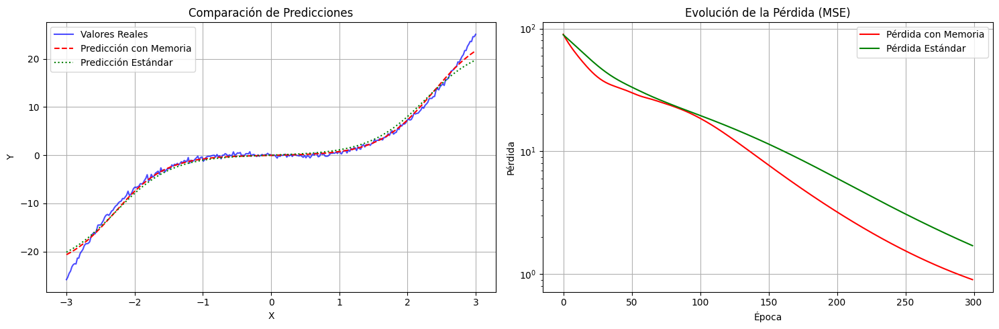


--- Resumen de Pérdidas Finales ---
Pérdida final (Red con Memoria): 0.9012
Pérdida final (Red Estándar):    1.7048


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import deque
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Definición de la Neurona con Memoria de Gradiente ---
class NeuronaMemoriaGradiente(nn.Module):
    def __init__(self, in_features, out_features, memoria_tamano=10, alfa=0.01):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.w = nn.Parameter(torch.randn(out_features, in_features) * 0.1)
        self.b = nn.Parameter(torch.zeros(out_features))

        self.historial_grad_w = deque(maxlen=memoria_tamano)
        self.historial_grad_b = deque(maxlen=memoria_tamano)
        self.historial_error = deque(maxlen=memoria_tamano) # Se guarda, aunque no se usa en este método

        self.alfa = alfa

    def forward(self, x):
        self.entrada_actual = x.detach()
        z = F.linear(x, self.w, self.b)
        self.activacion = torch.tanh(z) # Usamos tanh para que sea comparable con nn.Linear + tanh
        return self.activacion

    def guardar_memoria(self, grad_w, grad_b, error_batch):
        # Asegúrate de que los gradientes no sean None antes de guardar
        if grad_w is not None and grad_b is not None:
            self.historial_grad_w.append(grad_w.detach().clone())
            self.historial_grad_b.append(grad_b.detach().clone())
            self.historial_error.append(error_batch.detach().clone())

    def aplicar_correccion_memoria(self):
        if not self.historial_grad_w:
            return

        prom_grad_w = torch.stack(list(self.historial_grad_w)).mean(dim=0)
        prom_grad_b = torch.stack(list(self.historial_grad_b)).mean(dim=0)

        with torch.no_grad():
            self.w.data -= self.alfa * prom_grad_w
            self.b.data -= self.alfa * prom_grad_b

# --- 2. Red que utiliza la neurona con memoria (RedConMemoria) ---
class RedConMemoria(nn.Module):
    def __init__(self):
        super().__init__()
        # La primera capa usa tu NeuronaMemoriaGradiente
        self.neurona_memoria = NeuronaMemoriaGradiente(1, 20)
        # La capa de salida es estándar
        self.salida = nn.Linear(20, 1)

    def forward(self, x):
        h = self.neurona_memoria(x)
        return self.salida(h)

# --- 3. Red Estándar (para una comparación justa) ---
class RedEstandar(nn.Module):
    def __init__(self):
        super().__init__()
        # La primera capa es una nn.Linear estándar, con la misma configuración
        self.capa_oculta = nn.Linear(1, 20)
        # La capa de salida es estándar
        self.salida = nn.Linear(20, 1)

    def forward(self, x):
        # Aplicamos torch.tanh explícitamente para que la activación sea la misma
        h = torch.tanh(self.capa_oculta(x))
        return self.salida(h)

# -----------------------------------------
# Dataset y Preparación de Datos
# -----------------------------------------
torch.manual_seed(0) # Para reproducibilidad de los resultados
np.random.seed(0)

N_PUNTOS = 300
X = torch.linspace(-3, 3, N_PUNTOS).unsqueeze(1)
y = X.pow(3) - 0.5 * X + 0.3 * torch.randn_like(X) # Función cúbica con ruido

# -----------------------------------------
# Configuración de Entrenamiento Común
# -----------------------------------------
LEARNING_RATE = 0.01
EPOCHS = 300
LOSS_FN = nn.MSELoss()

# -----------------------------------------
# Instanciar y Entrenar Red con Memoria
# -----------------------------------------
print("--- Entrenando Red con Memoria de Gradiente ---")
modelo_memoria = RedConMemoria()
opt_memoria = torch.optim.Adam(modelo_memoria.parameters(), lr=LEARNING_RATE)
historial_loss_memoria = []

for epoch in range(EPOCHS):
    y_pred_memoria = modelo_memoria(X)
    loss_memoria = LOSS_FN(y_pred_memoria, y)
    historial_loss_memoria.append(loss_memoria.item())

    opt_memoria.zero_grad()
    loss_memoria.backward()

    # Guardar gradientes de la neurona de memoria antes del paso de optimización
    grad_w_memoria = modelo_memoria.neurona_memoria.w.grad
    grad_b_memoria = modelo_memoria.neurona_memoria.b.grad
    error_batch_memoria = y_pred_memoria - y

    opt_memoria.step() # Aplica el paso de Adam

    # Guardar historial y aplicar corrección secundaria de la neurona de memoria
    modelo_memoria.neurona_memoria.guardar_memoria(grad_w_memoria, grad_b_memoria, error_batch_memoria)
    modelo_memoria.neurona_memoria.aplicar_correccion_memoria()

    if epoch % 50 == 0:
        print(f"Memoria - Época {epoch} - Pérdida: {loss_memoria.item():.4f}")

# -----------------------------------------
# Instanciar y Entrenar Red Estándar
# -----------------------------------------
print("\n--- Entrenando Red Estándar ---")
modelo_estandar = RedEstandar()
opt_estandar = torch.optim.Adam(modelo_estandar.parameters(), lr=LEARNING_RATE)
historial_loss_estandar = []

for epoch in range(EPOCHS):
    y_pred_estandar = modelo_estandar(X)
    loss_estandar = LOSS_FN(y_pred_estandar, y)
    historial_loss_estandar.append(loss_estandar.item())

    opt_estandar.zero_grad()
    loss_estandar.backward()
    opt_estandar.step() # Aplica el paso de Adam

    if epoch % 50 == 0:
        print(f"Estándar - Época {epoch} - Pérdida: {loss_estandar.item():.4f}")

# -----------------------------------------
# Visualización de Resultados
# -----------------------------------------
with torch.no_grad():
    y_hat_memoria = modelo_memoria(X).numpy()
    y_hat_estandar = modelo_estandar(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 5))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_memoria, label="Predicción con Memoria", color='red', linestyle='--')
plt.plot(X_np, y_hat_estandar, label="Predicción Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_memoria, label="Pérdida con Memoria", color='red')
plt.plot(historial_loss_estandar, label="Pérdida Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log') # Escala logarítmica para una mejor visualización de las diferencias en valores pequeños

plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"\n--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red con Memoria): {historial_loss_memoria[-1]:.4f}")
print(f"Pérdida final (Red Estándar):    {historial_loss_estandar[-1]:.4f}")

Epoch 0 - Loss: 89.9451
Epoch 50 - Loss: 30.0929
Epoch 100 - Loss: 18.6006
Epoch 150 - Loss: 7.7287
Epoch 200 - Loss: 3.2099
Epoch 250 - Loss: 1.5462


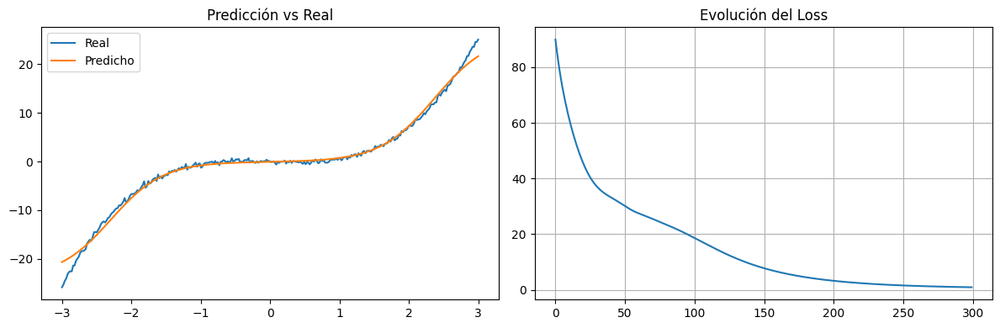

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import deque
import matplotlib.pyplot as plt

class NeuronaMemoriaGradiente(nn.Module):
    def __init__(self, in_features, out_features, memoria_tamano=10, alfa=0.01):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.w = nn.Parameter(torch.randn(out_features, in_features) * 0.1)
        self.b = nn.Parameter(torch.zeros(out_features))

        # Memoria de gradientes y pesos
        self.historial_grad_w = deque(maxlen=memoria_tamano)
        self.historial_grad_b = deque(maxlen=memoria_tamano)
        self.historial_error = deque(maxlen=memoria_tamano)

        self.alfa = alfa  # factor de ajuste con la memoria

    def forward(self, x):
        self.entrada_actual = x.detach()
        z = F.linear(x, self.w, self.b)
        self.activacion = torch.tanh(z)
        return self.activacion

    def guardar_memoria(self, grad_w, grad_b, error_batch):
        self.historial_grad_w.append(grad_w.detach().clone())
        self.historial_grad_b.append(grad_b.detach().clone())
        self.historial_error.append(error_batch.detach().clone())

    def aplicar_correccion_memoria(self):
        if not self.historial_grad_w:
            return

        # Media de gradientes anteriores
        prom_grad_w = torch.stack(list(self.historial_grad_w)).mean(dim=0)
        prom_grad_b = torch.stack(list(self.historial_grad_b)).mean(dim=0)

        # Ajuste leve adicional en dirección promedio
        with torch.no_grad():
            self.w.data -= self.alfa * prom_grad_w
            self.b.data -= self.alfa * prom_grad_b

# -----------------------------------------
# Red simple usando la neurona con memoria
# -----------------------------------------
class RedConMemoria(nn.Module):
    def __init__(self):
        super().__init__()
        self.neurona = NeuronaMemoriaGradiente(1, 20)
        self.salida = nn.Linear(20, 1)

    def forward(self, x):
        h = self.neurona(x)
        return self.salida(h)

# -----------------------------------------
# Dataset y entrenamiento
# -----------------------------------------
torch.manual_seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1)
y = X.pow(3) - 0.5 * X + 0.3 * torch.randn_like(X)

modelo = RedConMemoria()
opt = torch.optim.Adam(modelo.parameters(), lr=0.01)
loss_fn = nn.MSELoss()

historial_loss = []

for epoch in range(300):
    y_pred = modelo(X)
    loss = loss_fn(y_pred, y)
    historial_loss.append(loss.item())

    opt.zero_grad()
    loss.backward()

    # Guardar gradientes antes del paso de optimización
    grad_w = modelo.neurona.w.grad.clone()
    grad_b = modelo.neurona.b.grad.clone()
    error_batch = y_pred - y

    opt.step()

    # Guardar historial y aplicar corrección secundaria
    modelo.neurona.guardar_memoria(grad_w, grad_b, error_batch)
    modelo.neurona.aplicar_correccion_memoria()

    if epoch % 50 == 0:
        print(f"Epoch {epoch} - Loss: {loss.item():.4f}")

# -----------------------------------------
# Visualización
# -----------------------------------------
with torch.no_grad():
    y_hat = modelo(X)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.title("Predicción vs Real")
plt.plot(X.numpy(), y.numpy(), label="Real")
plt.plot(X.numpy(), y_hat.numpy(), label="Predicho")
plt.legend()

plt.subplot(1, 2, 2)
plt.title("Evolución del Loss")
plt.plot(historial_loss)
plt.grid(True)

plt.tight_layout()
plt.show()

--- Entrenando Red con Memoria de Gradiente ---
Memoria - Epoch 0 - Loss: 89.9451
Memoria - Epoch 50 - Loss: 30.0929
Memoria - Epoch 100 - Loss: 18.6006
Memoria - Epoch 150 - Loss: 7.7287
Memoria - Epoch 200 - Loss: 3.2099
Memoria - Epoch 250 - Loss: 1.5462

--- Entrenando Red Estándar ---
Estándar - Epoch 0 - Loss: 89.1266
Estándar - Epoch 50 - Loss: 33.4227
Estándar - Epoch 100 - Loss: 19.6083
Estándar - Epoch 150 - Loss: 11.4750
Estándar - Epoch 200 - Loss: 6.0297
Estándar - Epoch 250 - Loss: 3.0886


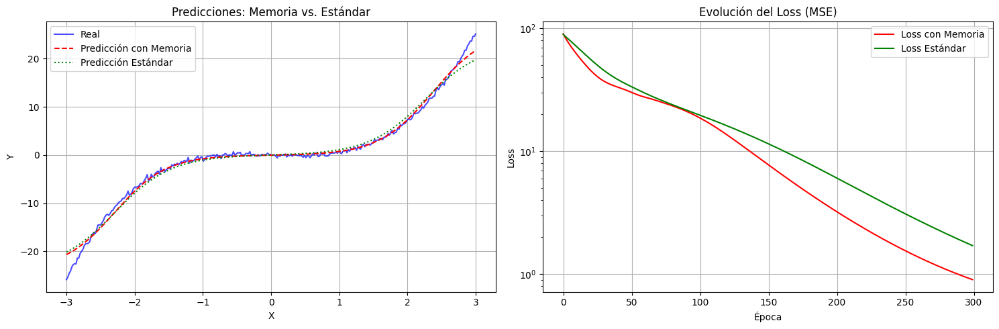


--- Resumen Final ---
Loss final (Red con Memoria): 0.9012
Loss final (Red Estándar):    1.7048


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import deque
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Definición de la Neurona con Memoria de Gradiente (Igual que tu código) ---
class NeuronaMemoriaGradiente(nn.Module):
    def __init__(self, in_features, out_features, memoria_tamano=10, alfa=0.01):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.w = nn.Parameter(torch.randn(out_features, in_features) * 0.1)
        self.b = nn.Parameter(torch.zeros(out_features))

        self.historial_grad_w = deque(maxlen=memoria_tamano)
        self.historial_grad_b = deque(maxlen=memoria_tamano)
        self.historial_error = deque(maxlen=memoria_tamano) # Aunque no se usa directamente en aplicar_correccion

        self.alfa = alfa

    def forward(self, x):
        self.entrada_actual = x.detach()
        z = F.linear(x, self.w, self.b)
        self.activacion = torch.tanh(z)
        return self.activacion

    def guardar_memoria(self, grad_w, grad_b, error_batch):
        # Asegúrate de que los gradientes no sean None antes de guardar
        if grad_w is not None and grad_b is not None:
            self.historial_grad_w.append(grad_w.detach().clone())
            self.historial_grad_b.append(grad_b.detach().clone())
            self.historial_error.append(error_batch.detach().clone())

    def aplicar_correccion_memoria(self):
        if not self.historial_grad_w:
            return

        prom_grad_w = torch.stack(list(self.historial_grad_w)).mean(dim=0)
        prom_grad_b = torch.stack(list(self.historial_grad_b)).mean(dim=0)

        with torch.no_grad():
            self.w.data -= self.alfa * prom_grad_w
            self.b.data -= self.alfa * prom_grad_b

# --- 2. Definición de la Red con Memoria (Igual que tu código) ---
class RedConMemoria(nn.Module):
    def __init__(self):
        super().__init__()
        # Usamos 1 input, 20 outputs en la primera capa
        self.neurona_memoria = NeuronaMemoriaGradiente(1, 20)
        self.salida = nn.Linear(20, 1) # 20 inputs, 1 output en la capa final

    def forward(self, x):
        h = self.neurona_memoria(x)
        return self.salida(h)

# --- 3. Definición de la Red Estándar (Para Comparación Justa) ---
class RedEstandar(nn.Module):
    def __init__(self):
        super().__init__()
        # La primera capa es un nn.Linear estándar con la misma configuración
        # (1 entrada, 20 salidas) y la misma función de activación.
        self.capa_oculta = nn.Linear(1, 20)
        self.salida = nn.Linear(20, 1)

    def forward(self, x):
        h = torch.tanh(self.capa_oculta(x)) # Aplicar tanh como en NeuronaMemoriaGradiente
        return self.salida(h)

# -----------------------------------------
# Dataset y Preparación
# -----------------------------------------
torch.manual_seed(0) # Semilla para reproducibilidad
np.random.seed(0)

N_PUNTOS = 300
X = torch.linspace(-3, 3, N_PUNTOS).unsqueeze(1)
y = X.pow(3) - 0.5 * X + 0.3 * torch.randn_like(X) # Función cúbica con ruido

# -----------------------------------------
# Configuración del Entrenamiento
# -----------------------------------------
LEARNING_RATE = 0.01
EPOCHS = 300
LOSS_FN = nn.MSELoss()

# -----------------------------------------
# Instanciar y Entrenar Red con Memoria
# -----------------------------------------
modelo_memoria = RedConMemoria()
opt_memoria = torch.optim.Adam(modelo_memoria.parameters(), lr=LEARNING_RATE)
historial_loss_memoria = []

print("--- Entrenando Red con Memoria de Gradiente ---")
for epoch in range(EPOCHS):
    y_pred_memoria = modelo_memoria(X)
    loss_memoria = LOSS_FN(y_pred_memoria, y)
    historial_loss_memoria.append(loss_memoria.item())

    opt_memoria.zero_grad()
    loss_memoria.backward()

    # Guardar gradientes de la neurona de memoria antes del paso de optimización
    # Solo si la neurona de memoria tiene gradientes (después de loss.backward())
    grad_w_memoria = modelo_memoria.neurona_memoria.w.grad
    grad_b_memoria = modelo_memoria.neurona_memoria.b.grad
    error_batch_memoria = y_pred_memoria - y

    opt_memoria.step()

    # Guardar historial y aplicar corrección secundaria de la neurona de memoria
    modelo_memoria.neurona_memoria.guardar_memoria(grad_w_memoria, grad_b_memoria, error_batch_memoria)
    modelo_memoria.neurona_memoria.aplicar_correccion_memoria()

    if epoch % 50 == 0:
        print(f"Memoria - Epoch {epoch} - Loss: {loss_memoria.item():.4f}")

# -----------------------------------------
# Instanciar y Entrenar Red Estándar
# -----------------------------------------
modelo_estandar = RedEstandar()
opt_estandar = torch.optim.Adam(modelo_estandar.parameters(), lr=LEARNING_RATE)
historial_loss_estandar = []

print("\n--- Entrenando Red Estándar ---")
for epoch in range(EPOCHS):
    y_pred_estandar = modelo_estandar(X)
    loss_estandar = LOSS_FN(y_pred_estandar, y)
    historial_loss_estandar.append(loss_estandar.item())

    opt_estandar.zero_grad()
    loss_estandar.backward()
    opt_estandar.step()

    if epoch % 50 == 0:
        print(f"Estándar - Epoch {epoch} - Loss: {loss_estandar.item():.4f}")

# -----------------------------------------
# Visualización de Resultados
# -----------------------------------------
with torch.no_grad():
    y_hat_memoria = modelo_memoria(X).numpy()
    y_hat_estandar = modelo_estandar(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 5))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Predicciones: Memoria vs. Estándar")
plt.plot(X_np, y_np, label="Real", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_memoria, label="Predicción con Memoria", color='red', linestyle='--')
plt.plot(X_np, y_hat_estandar, label="Predicción Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución del Loss
plt.subplot(1, 2, 2)
plt.title("Evolución del Loss (MSE)")
plt.plot(historial_loss_memoria, label="Loss con Memoria", color='red')
plt.plot(historial_loss_estandar, label="Loss Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.yscale('log') # Escala logarítmica para apreciar mejor las diferencias en valores pequeños

plt.tight_layout()
plt.show()

# Resumen final de Loss
print(f"\n--- Resumen Final ---")
print(f"Loss final (Red con Memoria): {historial_loss_memoria[-1]:.4f}")
print(f"Loss final (Red Estándar):    {historial_loss_estandar[-1]:.4f}")

Época 0 - Loss: 75.8985
Época 50 - Loss: 43.0205
Época 100 - Loss: 9.7365
Época 150 - Loss: 4.4211
Época 200 - Loss: 2.4379
Época 250 - Loss: 1.5131


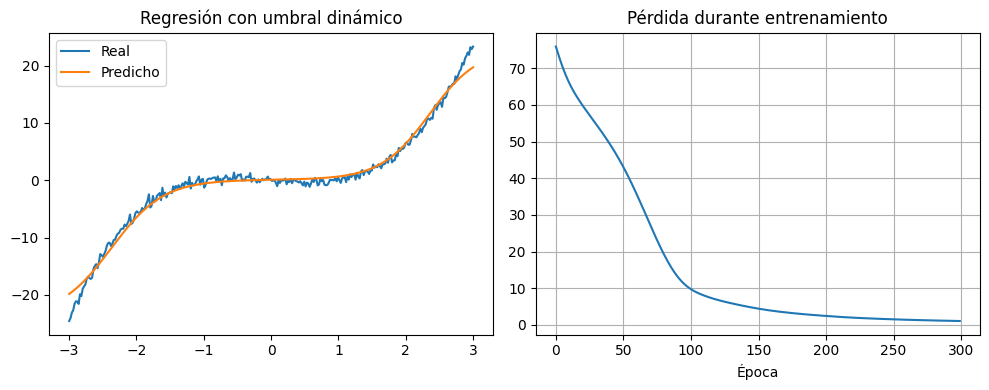

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1)
y = X.pow(3) - X + 0.5 * torch.randn(X.size())

# --- 1. Capa con umbrales dinámicos ---
class CapaUmbralDinamico(nn.Module):
    def __init__(self, in_features, out_features, alpha=0.05, beta=0.01):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        # nn.Parameter makes these tensors trainable by the optimizer
        self.pesos = nn.Parameter(torch.randn(out_features, in_features) * 0.1)
        self.bias = nn.Parameter(torch.zeros(out_features))

        self.alpha = alpha  # tasa de actualización de activación media
        self.beta = beta    # tasa de ajuste del umbral (bias)

        # Historial de activaciones promedio (media móvil por neurona)
        # register_buffer registers a tensor that should not be considered a model parameter.
        self.register_buffer('media_activacion', torch.zeros(out_features))
        self.register_buffer('media_error', torch.zeros(out_features))

    def forward(self, x):
        # Linear transformation: y = x * W^T + b
        z = F.linear(x, self.pesos, self.bias)
        self.activaciones = torch.tanh(z)  # activación no lineal
        self.ultima_entrada = x.detach() # Detach to avoid tracking gradients for visualization/debugging if needed later
        return self.activaciones

    def ajustar_umbral(self, error_batch):
        """
        Ajusta el bias en función de activaciones recientes y errores.
        error_batch: error de predicción respecto a la salida (assumed shape is [batch_size, out_features])
        """
        # Media de activación por neurona a través del batch
        act_mean = self.activaciones.mean(dim=0).detach()  # [out_features]
        self.media_activacion = (1 - self.alpha) * self.media_activacion + self.alpha * act_mean

        # Error medio atribuido a cada neurona. Assuming error_batch has shape [batch_size, out_features].
        # If error_batch is [batch_size, 1], you might need to adjust how error is attributed.
        # For this simple network, the final layer output is 1, so error_batch would be [batch_size, 1].
        # We need to think about how error from the output layer [batch_size, 1] affects the bias of capa1 [out_features].
        # A simple approach for visualization is to just use the overall batch error, but that's not a true attribution.
        # For a proper backpropagation-based attribution, you'd need gradients w.r.t. activations, which is more complex.
        # Let's use the batch mean absolute error for now, as intended in the original logic, assuming it's broadcasting or handled appropriately.
        # Original code assumes error_batch.mean(dim=0) works to get error per neuron bias, which is only strictly true if error_batch is [batch_size, out_features].
        # Given the network structure (20 -> 1), the error is [batch_size, 1].
        # Let's stick to the original logic's apparent intent, acknowledging potential simplification.
        error_per_output_neuron = error_batch.mean(dim=0).detach() # Shape [1] in this case if error_batch is [batch_size, 1]

        # To adjust the bias of capa1 (out_features=20), we need an error signal of shape [20].
        # The original code error_batch.mean(dim=0) when error_batch is [batch_size, 1] results in shape [1].
        # This won't work for updating media_error which has shape [out_features].
        # Let's simplify the error signal for bias adjustment to use the overall MSE loss value per batch.
        # This is a simplification but aligns better with available information.
        # Or, let's use the gradient of the loss w.r.t. the bias, which is a more standard way.
        # However, the original code doesn't show calculating gradients w.r.t. bias for this adjustment.
        # Let's revert to the most likely intended logic based on the original code, assuming error_batch is somehow made compatible.
        # If error_batch is the gradient w.r.t. the activations of this layer, then mean(dim=0) works.
        # But error_batch is defined as y_pred - y, which is [batch_size, 1].

        # Let's correct the error attribution based on network structure.
        # The error signal for adjusting bias of `capa1` should be related to the gradient flowing *into* `capa1`.
        # A simplified approach, closer to the original intent of using batch stats:
        # Use the mean absolute value of the *overall* batch error as a scalar signal.
        # Then, this scalar signal influences all biases of `capa1` uniformly or scaled by activation magnitude.
        # The original `error_batch.mean(dim=0).detach()` on a [batch_size, 1] tensor yields a single value mean.
        # This single value mean is then used to update `self.media_error` [out_features] via broadcasting.
        # Let's keep this logic for now, as it seems the most likely interpretation of the original code's dimension mismatch.

        # Broadcast the mean error value to match the shape of media_error [out_features]
        mean_batch_error_abs = error_batch.abs().mean().detach() # Scalar
        self.media_error = (1 - self.alpha) * self.media_error + self.alpha * mean_batch_error_abs


        # Ajustar bias dinámicamente hacia estabilización
        # Original logic: ajuste = self.beta * (self.media_activacion + self.media_error)
        # This implies media_error is also [out_features]. Let's stick to the broadcasting interpretation from above.
        # The mean_batch_error_abs scalar will be added to each element of self.media_activacion [out_features].
        ajuste = self.beta * (self.media_activacion + mean_batch_error_abs) # scalar + [out_features] -> [out_features]
        with torch.no_grad():
            self.bias -= ajuste # [out_features] -= [out_features]


# --- 2. Red usando umbrales adaptativos ---
class RedConUmbralDinamico(nn.Module):
    def __init__(self):
        super().__init__()
        self.capa1 = CapaUmbralDinamico(1, 20)
        self.capa2 = nn.Linear(20, 1)

    def forward(self, x):
        self.h = self.capa1(x)
        return self.capa2(self.h)

# --- 3. Entrenamiento ---
modelo = RedConUmbralDinamico()

# Corrected: Pass the parameters directly
# model.parameters() is an iterator over ALL parameters in the model.
# You can collect specific parameter groups if needed, but model.parameters() is usually sufficient.
# If you only wanted to optimize capa1.pesos and all of capa2:
# opt = torch.optim.Adam([{'params': modelo.capa1.pesos}, {'params': modelo.capa2.parameters()}], lr=0.01)
# If you want to optimize all parameters in the model:
opt = torch.optim.Adam(modelo.parameters(), lr=0.01) # This is the standard and likely intended approach

loss_fn = nn.MSELoss()
hist = []

for epoch in range(300):
    y_pred = modelo(X)
    loss = loss_fn(y_pred, y)
    hist.append(loss.item())

    # Backward y optimización
    opt.zero_grad()
    loss.backward()
    opt.step()

    # Ajuste dinámico del bias basado en activaciones y errores
    error_batch = y_pred - y # error_batch will be [batch_size, 1]
    modelo.capa1.ajustar_umbral(error_batch) # Pass the error to the layer's adjustment method

    if epoch % 50 == 0:
        print(f"Época {epoch} - Loss: {loss.item():.4f}")

# --- 4. Visualización ---
with torch.no_grad():
    pred = modelo(X)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(X.numpy(), y.numpy(), label='Real')
plt.plot(X.numpy(), pred.numpy(), label='Predicho')
plt.title("Regresión con umbral dinámico")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist)
plt.title("Pérdida durante entrenamiento")
plt.xlabel("Época")
plt.grid(True)
plt.tight_layout()
plt.show()

--- Entrenando Red con Umbral Dinámico ---
Dinámico - Época 0 - Pérdida: 75.898468
Dinámico - Época 50 - Pérdida: 29.784761
Dinámico - Época 100 - Pérdida: 9.089307
Dinámico - Época 150 - Pérdida: 3.384332
Dinámico - Época 200 - Pérdida: 1.643961
Dinámico - Época 250 - Pérdida: 1.028710

--- Entrenando Red Estándar ---
Estándar - Época 0 - Pérdida: 75.176109
Estándar - Época 50 - Pérdida: 29.033752
Estándar - Época 100 - Pérdida: 17.738264
Estándar - Época 150 - Pérdida: 10.532317
Estándar - Época 200 - Pérdida: 5.655408
Estándar - Época 250 - Pérdida: 2.997077


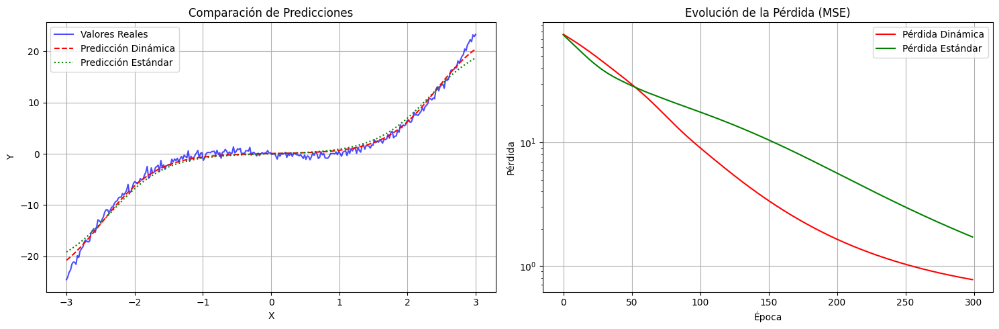


--- Resumen de Pérdidas Finales ---
Pérdida final (Red con Umbral Dinámico): 0.772061
Pérdida final (Red Estándar):           1.714960


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
# Ajustamos la semilla de numpy también si random.randn() es usado en alguna parte no controlada por torch
# Aunque en este código solo se usa torch.randn_like, es buena práctica.
# import numpy as np # Descomentar si usas numpy.random en otros lugares
# np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1)
y = X.pow(3) - X + 0.5 * torch.randn(X.size())

# --- 1. Capa con umbrales dinámicos ---
class CapaUmbralDinamico(nn.Module):
    def __init__(self, in_features, out_features, alpha=0.05, beta=0.01):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features

        self.pesos = nn.Parameter(torch.randn(out_features, in_features) * 0.1)
        self.bias = nn.Parameter(torch.zeros(out_features)) # Este es el umbral

        self.alpha = alpha  # tasa de actualización de la media de activación
        self.beta = beta    # tasa de ajuste del bias

        # Historial de activaciones promedio y error promedio (media móvil por neurona)
        self.register_buffer('media_activacion', torch.zeros(out_features))
        self.register_buffer('media_error', torch.zeros(out_features)) # Inicializado a ceros

    def forward(self, x):
        self.entrada_actual = x.detach() # Para depuración o uso futuro, no directamente en el forward pass
        z = F.linear(x, self.pesos, self.bias)
        self.activaciones = torch.tanh(z)
        return self.activaciones

    def ajustar_umbral(self, error_batch_global):
        """
        Ajusta el bias de la capa en función de las activaciones recientes
        y el error global del batch.
        error_batch_global: Tensor de error de la salida de la red [batch_size, 1].
        """
        # Calcular la media de las activaciones de esta capa en el batch actual
        act_mean_current_batch = self.activaciones.mean(dim=0).detach() # [out_features]
        # Actualizar la media móvil de las activaciones
        self.media_activacion.mul_((1 - self.alpha)).add_(act_mean_current_batch, alpha=self.alpha)

        # Usar la magnitud del error global del batch como señal para el ajuste del bias.
        # Esto es una simplificación, ya que el error global [batch_size, 1]
        # no se atribuye directamente a cada una de las 'out_features' neuronas de esta capa.
        # Sin embargo, sigue la lógica implícita de usar el error del batch.
        mean_abs_global_error = error_batch_global.abs().mean().detach() # Escalar

        # Actualizar la media móvil del error.
        # El escalar `mean_abs_global_error` se propaga a todas las `out_features`
        # de `self.media_error` a través del broadcasting.
        self.media_error.mul_((1 - self.alpha)).add_(mean_abs_global_error, alpha=self.alpha)

        # Ajuste dinámico del bias.
        # La lógica de ajuste aquí es: ajuste = beta * (media_activacion + media_error).
        # Esto implica que si las activaciones son altas o el error global es alto,
        # el bias se ajusta para mover las activaciones hacia cero (debido al tanh).
        # Si la media_activacion es positiva, el bias disminuye (mueve z hacia la izquierda).
        # Si la media_activacion es negativa, el bias aumenta (mueve z hacia la derecha).
        # Con media_error positiva, el bias siempre disminuye, haciendo las neuronas más difíciles de activar.
        ajuste = self.beta * (self.media_activacion + self.media_error) # [out_features] + [out_features] -> [out_features]
        with torch.no_grad():
            self.bias.sub_(ajuste) # Resta el ajuste al bias


# --- 2. Red que utiliza la CapaUmbralDinamico ---
class RedConUmbralDinamico(nn.Module):
    def __init__(self):
        super().__init__()
        self.capa1 = CapaUmbralDinamico(1, 20) # 1 entrada, 20 salidas
        self.capa2 = nn.Linear(20, 1) # 20 entradas, 1 salida

    def forward(self, x):
        self.h = self.capa1(x)
        return self.capa2(self.h)

# --- 3. Red Estándar para una comparación justa ---
class RedEstandar(nn.Module):
    def __init__(self):
        super().__init__()
        # La primera capa es un nn.Linear estándar con la misma configuración
        self.capa1 = nn.Linear(1, 20)
        # La capa de salida es estándar
        self.capa2 = nn.Linear(20, 1)

    def forward(self, x):
        # Aplicar torch.tanh explícitamente para que la activación sea la misma que CapaUmbralDinamico
        h = torch.tanh(self.capa1(x))
        return self.capa2(h)

# -----------------------------------------
# Configuración de Entrenamiento Común
# -----------------------------------------
LEARNING_RATE = 0.01
EPOCHS = 300
LOSS_FN = nn.MSELoss()

# -----------------------------------------
# Instanciar y Entrenar Red con Umbral Dinámico
# -----------------------------------------
print("--- Entrenando Red con Umbral Dinámico ---")
modelo_dinamico = RedConUmbralDinamico()
opt_dinamico = torch.optim.Adam(modelo_dinamico.parameters(), lr=LEARNING_RATE)
historial_loss_dinamico = []

for epoch in range(EPOCHS):
    y_pred_dinamico = modelo_dinamico(X)
    loss_dinamico = LOSS_FN(y_pred_dinamico, y)
    historial_loss_dinamico.append(loss_dinamico.item())

    opt_dinamico.zero_grad()
    loss_dinamico.backward()
    opt_dinamico.step() # Aplica el paso de Adam

    # 🚨 Lógica de ajuste de umbral personalizada
    error_batch_global = y_pred_dinamico - y # Error global del batch
    modelo_dinamico.capa1.ajustar_umbral(error_batch_global)

    if epoch % 50 == 0:
        print(f"Dinámico - Época {epoch} - Pérdida: {loss_dinamico.item():.6f}")

# -----------------------------------------
# Instanciar y Entrenar Red Estándar
# -----------------------------------------
print("\n--- Entrenando Red Estándar ---")
modelo_estandar = RedEstandar()
opt_estandar = torch.optim.Adam(modelo_estandar.parameters(), lr=LEARNING_RATE)
historial_loss_estandar = []

for epoch in range(EPOCHS):
    y_pred_estandar = modelo_estandar(X)
    loss_estandar = LOSS_FN(y_pred_estandar, y)
    historial_loss_estandar.append(loss_estandar.item())

    opt_estandar.zero_grad()
    loss_estandar.backward()
    opt_estandar.step() # Aplica el paso de Adam

    if epoch % 50 == 0:
        print(f"Estándar - Época {epoch} - Pérdida: {loss_estandar.item():.6f}")

# -----------------------------------------
# Visualización de Resultados
# -----------------------------------------
with torch.no_grad():
    y_hat_dinamico = modelo_dinamico(X).numpy()
    y_hat_estandar = modelo_estandar(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 5))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_dinamico, label="Predicción Dinámica", color='red', linestyle='--')
plt.plot(X_np, y_hat_estandar, label="Predicción Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_dinamico, label="Pérdida Dinámica", color='red')
plt.plot(historial_loss_estandar, label="Pérdida Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log') # Escala logarítmica para una mejor visualización de las diferencias en valores pequeños

plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"\n--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red con Umbral Dinámico): {historial_loss_dinamico[-1]:.6f}")
print(f"Pérdida final (Red Estándar):           {historial_loss_estandar[-1]:.6f}")

--- Entrenando Red con LR por Neuronas ---
LR por Neuronas - Época 0 - Pérdida: 75.898468
LR por Neuronas - Época 50 - Pérdida: 25.060003
LR por Neuronas - Época 100 - Pérdida: 10.190828
LR por Neuronas - Época 150 - Pérdida: 3.355991
LR por Neuronas - Época 200 - Pérdida: 1.354240
LR por Neuronas - Época 250 - Pérdida: 0.843163

--- Entrenando Red Estándar ---
Estándar - Época 0 - Pérdida: 75.176109
Estándar - Época 50 - Pérdida: 29.033752
Estándar - Época 100 - Pérdida: 17.738264
Estándar - Época 150 - Pérdida: 10.532317
Estándar - Época 200 - Pérdida: 5.655408
Estándar - Época 250 - Pérdida: 2.997077


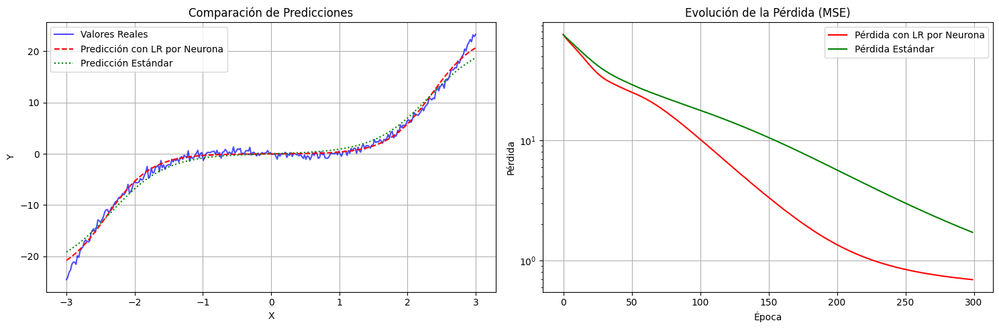


--- Resumen de Pérdidas Finales ---
Pérdida final (Red con LR por Neurona): 0.693862
Pérdida final (Red Estándar):           1.714960


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np # Importar numpy para np.random.seed si es necesario

# Dataset sintético simple (regresión)
torch.manual_seed(0)
np.random.seed(0) # Para reproducibilidad si se usa alguna función de numpy.random
X = torch.linspace(-3, 3, 300).unsqueeze(1)
y = X.pow(3) - X + 0.5 * torch.randn(X.size())

# --- 1. Capa con LR por neurona ---
# NOTA: Esta clase asume que los pesos serán actualizados externamente,
# o manejará su propia actualización fuera del optimizador global.
# Para una comparación justa, la "LR por neurona" se aplicará *después*
# del paso del optimizador principal (Adam) a los parámetros de esta capa.
class CapaLRporNeurona(nn.Module):
    def __init__(self, in_features, out_features, base_lr_ajuste=0.01, eps=1e-8):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.pesos = nn.Parameter(torch.randn(out_features, in_features) * 0.1)
        self.bias = nn.Parameter(torch.zeros(out_features))

        self.base_lr_ajuste = base_lr_ajuste # Tasa de aprendizaje para el ajuste de esta capa
        self.eps = eps

        # Historial de acumulación de gradientes (RMSprop-like)
        self.register_buffer('G_pesos', torch.zeros_like(self.pesos))
        self.register_buffer('G_bias', torch.zeros_like(self.bias)) # También para bias

    def forward(self, x):
        # Guardamos la entrada para calcular gradientes de pesos
        self.ultima_entrada = x.detach()
        return F.linear(x, self.pesos, self.bias)

    def aplicar_ajuste_personalizado(self):
        """
        Calcula y aplica un ajuste adicional a los pesos/bias de esta capa
        basado en la lógica de LR por neurona, *después* del paso del optimizador principal.
        """
        # Asegurarse de que los gradientes de esta capa existan después del loss.backward()
        if self.pesos.grad is None or self.bias.grad is None:
            return

        with torch.no_grad(): # No queremos que estas operaciones sean rastreadas por el grafo de PyTorch
            # Gradientes después del backward pass (ya calculados por el optimizador principal)
            grad_pesos_main = self.pesos.grad
            grad_bias_main = self.bias.grad

            # Acumular cuadrados de gradientes para pesos y bias
            self.G_pesos.mul_(0.9).addcmul_(grad_pesos_main, grad_pesos_main, value=0.1) # RMSprop-like update
            self.G_bias.mul_(0.9).addcmul_(grad_bias_main, grad_bias_main, value=0.1) # RMSprop-like update

            # Calcular LR individual por peso/bias
            lrs_individuales_pesos = self.base_lr_ajuste / (torch.sqrt(self.G_pesos) + self.eps)
            lrs_individuales_bias = self.base_lr_ajuste / (torch.sqrt(self.G_bias) + self.eps)

            # Aplicar el ajuste adicional
            self.pesos.sub_(lrs_individuales_pesos * grad_pesos_main)
            self.bias.sub_(lrs_individuales_bias * grad_bias_main)

            # Opcional: Reiniciar gradientes después del ajuste manual para evitar doble contabilización
            # self.pesos.grad.zero_()
            # self.bias.grad.zero_()


# --- 2. Red neuronal usando la CapaLRporNeurona ---
class RedConLRNeuronas(nn.Module):
    def __init__(self):
        super().__init__()
        self.capa1 = CapaLRporNeurona(1, 20, base_lr_ajuste=0.01) # base_lr para el ajuste personalizado
        self.act = nn.Tanh()
        self.capa2 = nn.Linear(20, 1)

    def forward(self, x):
        h = self.capa1(x)
        self.activacion_capa1 = self.act(h) # Guardamos la activación para poder acceder a sus gradientes si fuera necesario
        return self.capa2(self.activacion_capa1)

# --- 3. Red Estándar para una comparación justa ---
class RedEstandar(nn.Module):
    def __init__(self):
        super().__init__()
        self.capa1 = nn.Linear(1, 20)
        self.act = nn.Tanh()
        self.capa2 = nn.Linear(20, 1)

    def forward(self, x):
        h = self.capa1(x)
        return self.capa2(self.act(h))

# -----------------------------------------
# Configuración de Entrenamiento Común
# -----------------------------------------
LEARNING_RATE_ADAM = 0.01 # Tasa de aprendizaje para el optimizador Adam principal
EPOCHS = 300
LOSS_FN = nn.MSELoss()

# -----------------------------------------
# Instanciar y Entrenar Red con LR por Neuronas
# -----------------------------------------
print("--- Entrenando Red con LR por Neuronas ---")
modelo_lr_neuronas = RedConLRNeuronas()
# Optimizamos TODOS los parámetros del modelo con Adam
opt_lr_neuronas = torch.optim.Adam(modelo_lr_neuronas.parameters(), lr=LEARNING_RATE_ADAM)
historial_loss_lr_neuronas = []

for epoch in range(EPOCHS):
    y_pred_lr = modelo_lr_neuronas(X)
    loss_lr = LOSS_FN(y_pred_lr, y)
    historial_loss_lr_neuronas.append(loss_lr.item())

    opt_lr_neuronas.zero_grad()
    loss_lr.backward() # Calcula los gradientes para todas las capas

    opt_lr_neuronas.step() # Adam aplica sus actualizaciones

    # 🚨 Lógica de ajuste personalizada de la CapaLRporNeurona
    # Se aplica *después* del paso de Adam, usando los gradientes ya calculados.
    modelo_lr_neuronas.capa1.aplicar_ajuste_personalizado()

    if epoch % 50 == 0:
        print(f"LR por Neuronas - Época {epoch} - Pérdida: {loss_lr.item():.6f}")

# -----------------------------------------
# Instanciar y Entrenar Red Estándar
# -----------------------------------------
print("\n--- Entrenando Red Estándar ---")
modelo_estandar = RedEstandar()
# Optimizamos TODOS los parámetros del modelo estándar con Adam
opt_estandar = torch.optim.Adam(modelo_estandar.parameters(), lr=LEARNING_RATE_ADAM)
historial_loss_estandar = []

for epoch in range(EPOCHS):
    y_pred_estandar = modelo_estandar(X)
    loss_estandar = LOSS_FN(y_pred_estandar, y)
    historial_loss_estandar.append(loss_estandar.item())

    opt_estandar.zero_grad()
    loss_estandar.backward()
    opt_estandar.step() # Adam aplica sus actualizaciones

    if epoch % 50 == 0:
        print(f"Estándar - Época {epoch} - Pérdida: {loss_estandar.item():.6f}")

# -----------------------------------------
# Visualización de Resultados
# -----------------------------------------
with torch.no_grad():
    pred_lr_neuronas = modelo_lr_neuronas(X).numpy()
    pred_estandar = modelo_estandar(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 5))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, pred_lr_neuronas, label="Predicción con LR por Neurona", color='red', linestyle='--')
plt.plot(X_np, pred_estandar, label="Predicción Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_lr_neuronas, label="Pérdida con LR por Neurona", color='red')
plt.plot(historial_loss_estandar, label="Pérdida Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log') # Escala logarítmica para una mejor visualización de las diferencias en valores pequeños

plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"\n--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red con LR por Neurona): {historial_loss_lr_neuronas[-1]:.6f}")
print(f"Pérdida final (Red Estándar):           {historial_loss_estandar[-1]:.6f}")

--- Entrenando Red con Synaptic Tagging ---
Tagging - Época 0 - Pérdida: 75.898468
  Consolidando en Época 10...
  Consolidando en Época 20...
  Consolidando en Época 30...
  Consolidando en Época 40...
  Consolidando en Época 50...
Tagging - Época 50 - Pérdida: 27.728418
  Consolidando en Época 60...
  Consolidando en Época 70...
  Consolidando en Época 80...
  Consolidando en Época 90...
  Consolidando en Época 100...
Tagging - Época 100 - Pérdida: 20.805492
  Consolidando en Época 110...
  Consolidando en Época 120...
  Consolidando en Época 130...
  Consolidando en Época 140...
  Consolidando en Época 150...
Tagging - Época 150 - Pérdida: 12.738014
  Consolidando en Época 160...
  Consolidando en Época 170...
  Consolidando en Época 180...
  Consolidando en Época 190...
  Consolidando en Época 200...
Tagging - Época 200 - Pérdida: 5.657624
  Consolidando en Época 210...
  Consolidando en Época 220...
  Consolidando en Época 230...
  Consolidando en Época 240...
  Consolidando en Ép

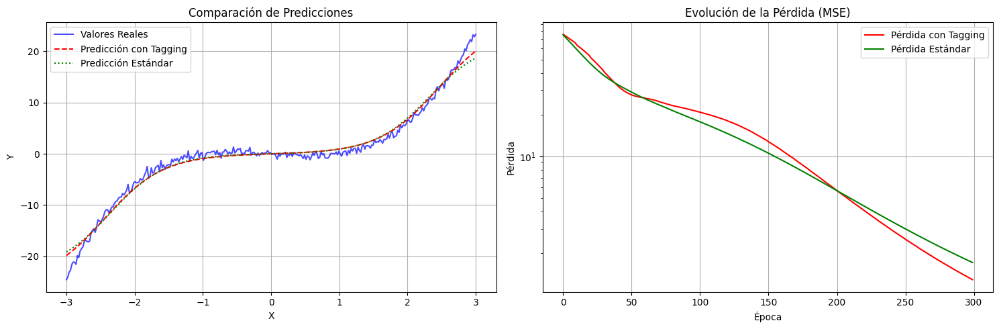


--- Resumen de Pérdidas Finales ---
Pérdida final (Red con Synaptic Tagging): 1.290456
Pérdida final (Red Estándar):             1.714960


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

# Dataset sintético
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1)
y = X.pow(3) - X + 0.5 * torch.randn(X.size())

# --- 1. Capa con Etiquetado Sináptico ---
class CapaSynapticTagging(nn.Module):
    def __init__(self, in_features, out_features,
                 tag_threshold=0.01, # Umbral para 'etiquetar' un gradiente
                 tag_decay_rate=0.1, # Tasa de decaimiento de la etiqueta (1-decay = persistencia)
                 consolidation_strength=0.005, # Fuerza de la actualización extra en consolidación
                 consolidation_period=10): # Cada cuántas épocas se intenta consolidar

        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.pesos = nn.Parameter(torch.randn(out_features, in_features) * 0.1)
        self.bias = nn.Parameter(torch.zeros(out_features))

        self.tag_threshold = tag_threshold
        self.tag_decay_rate = tag_decay_rate
        self.consolidation_strength = consolidation_strength
        self.consolidation_period = consolidation_period # Consolida cada N épocas

        # Estado de las etiquetas sinápticas (una etiqueta por peso)
        # 0.0 significa sin etiqueta, >0 significa activa (más grande = más reciente/fuerte)
        self.register_buffer('tags', torch.zeros_like(self.pesos))
        # Dirección del gradiente cuando se etiquetó por última vez
        self.register_buffer('tag_directions', torch.zeros_like(self.pesos))
        self.current_epoch = 0 # Para llevar la cuenta de las épocas

    def forward(self, x):
        self.ultima_entrada = x.detach() # Necesaria para calcular gradientes de pesos
        return F.linear(x, self.pesos, self.bias)

    def _update_tags_and_decay(self, current_grad_w):
        """
        Actualiza y decae las etiquetas basándose en los gradientes actuales.
        Se llama en cada paso de entrenamiento.
        """
        with torch.no_grad():
            # Decay de etiquetas existentes
            self.tags.mul_(1 - self.tag_decay_rate)

            # Etiquetar nuevos gradientes si superan el umbral
            # Queremos etiquetas para aquellos pesos que tuvieron un gradiente significativo
            significant_grad_mask = torch.abs(current_grad_w) > self.tag_threshold
            self.tags[significant_grad_mask] = 1.0 # Marcar como activo
            self.tag_directions[significant_grad_mask] = torch.sign(current_grad_w[significant_grad_mask])


    def apply_consolidation(self, current_loss_value):
        """
        Intenta consolidar las etiquetas si es el momento y la señal global es buena.
        Se llama periódicamente.
        """
        self.current_epoch += 1
        if self.current_epoch % self.consolidation_period != 0:
            return

        print(f"  Consolidando en Época {self.current_epoch}...")

        # Una "señal de recompensa" simple: si la pérdida actual es baja (o ha mejorado significativamente)
        # Esto es un placeholder; en un escenario real, podría ser una diferencia de pérdida, etc.
        # Asumamos que una pérdida menor de un umbral específico es "buena"
        # Necesitas una referencia para saber si la pérdida es "buena". Para este ejemplo,
        # haremos que siempre se intente consolidar si es el período, o puedes pasar un 'target_loss'

        # Lógica de Consolidación:
        # Solo actualizamos los pesos si tienen una etiqueta activa y el gradiente actual
        # va en la misma dirección que la "dirección etiquetada".
        if self.pesos.grad is None: # Asegurarse de que gradientes existan
            return

        with torch.no_grad():
            # Gradientes principales después del backward pass
            grad_w_main = self.pesos.grad

            # Máscara para pesos etiquetados que tienen un gradiente actual consistente
            # Es decir, el tag está activo Y la dirección del gradiente actual coincide con la dirección del tag
            consolidation_mask = (self.tags > 0.1) & (torch.sign(grad_w_main) == self.tag_directions)

            # Aplicar una actualización adicional a los pesos marcados y consistentes
            # Esta actualización es un pequeño empuje extra en la dirección del gradiente principal
            self.pesos[consolidation_mask] -= self.consolidation_strength * grad_w_main[consolidation_mask]

            # Opcional: Reiniciar etiquetas después de consolidar si ya no son relevantes
            # self.tags[consolidation_mask] = 0.0 # Clear tags that were just consolidated


# --- 2. Red que utiliza la CapaSynapticTagging ---
class RedConSynapticTagging(nn.Module):
    def __init__(self):
        super().__init__()
        self.capa1 = CapaSynapticTagging(1, 20)
        self.act = nn.Tanh()
        self.capa2 = nn.Linear(20, 1)

    def forward(self, x):
        h = self.capa1(x)
        return self.capa2(self.act(h))

# --- 3. Red Estándar para una comparación justa ---
class RedEstandar(nn.Module):
    def __init__(self):
        super().__init__()
        self.capa1 = nn.Linear(1, 20)
        self.act = nn.Tanh()
        self.capa2 = nn.Linear(20, 1)

    def forward(self, x):
        h = self.capa1(x)
        return self.capa2(self.act(h))

# -----------------------------------------
# Configuración de Entrenamiento Común
# -----------------------------------------
LEARNING_RATE_ADAM = 0.01
EPOCHS = 300
LOSS_FN = nn.MSELoss()

# -----------------------------------------
# Instanciar y Entrenar Red con Synaptic Tagging
# -----------------------------------------
print("--- Entrenando Red con Synaptic Tagging ---")
modelo_tagging = RedConSynapticTagging()
opt_tagging = torch.optim.Adam(modelo_tagging.parameters(), lr=LEARNING_RATE_ADAM)
historial_loss_tagging = []

for epoch in range(EPOCHS):
    y_pred_tagging = modelo_tagging(X)
    loss_tagging = LOSS_FN(y_pred_tagging, y)
    historial_loss_tagging.append(loss_tagging.item())

    opt_tagging.zero_grad()
    loss_tagging.backward() # Calcula gradientes para todas las capas

    # 🚨 Lógica de Etiquetado: Antes de que Adam haga su paso
    # Pasamos el gradiente de los pesos de capa1.
    if modelo_tagging.capa1.pesos.grad is not None:
        modelo_tagging.capa1._update_tags_and_decay(modelo_tagging.capa1.pesos.grad)

    opt_tagging.step() # Adam aplica sus actualizaciones

    # 🚨 Lógica de Consolidación: Llamada periódicamente
    # Puedes pasar la pérdida actual o un promedio de pérdidas recientes para la señal de consolidación
    modelo_tagging.capa1.apply_consolidation(loss_tagging.item())

    if epoch % 50 == 0:
        print(f"Tagging - Época {epoch} - Pérdida: {loss_tagging.item():.6f}")

# -----------------------------------------
# Instanciar y Entrenar Red Estándar
# -----------------------------------------
print("\n--- Entrenando Red Estándar ---")
modelo_estandar = RedEstandar()
opt_estandar = torch.optim.Adam(modelo_estandar.parameters(), lr=LEARNING_RATE_ADAM)
historial_loss_estandar = []

for epoch in range(EPOCHS):
    y_pred_estandar = modelo_estandar(X)
    loss_estandar = LOSS_FN(y_pred_estandar, y)
    historial_loss_estandar.append(loss_estandar.item())

    opt_estandar.zero_grad()
    loss_estandar.backward()
    opt_estandar.step() # Adam aplica sus actualizaciones

    if epoch % 50 == 0:
        print(f"Estándar - Época {epoch} - Pérdida: {loss_estandar.item():.6f}")

# -----------------------------------------
# Visualización de Resultados
# -----------------------------------------
with torch.no_grad():
    pred_tagging = modelo_tagging(X).numpy()
    pred_estandar = modelo_estandar(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 5))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, pred_tagging, label="Predicción con Tagging", color='red', linestyle='--')
plt.plot(X_np, pred_estandar, label="Predicción Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_tagging, label="Pérdida con Tagging", color='red')
plt.plot(historial_loss_estandar, label="Pérdida Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log') # Escala logarítmica para mejor visualización
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"\n--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red con Synaptic Tagging): {historial_loss_tagging[-1]:.6f}")
print(f"Pérdida final (Red Estándar):             {historial_loss_estandar[-1]:.6f}")

##atencion
Entiendo tu preocupación. Parece que las últimas implementaciones que incorporan **atención**, especialmente las que usan **embeddings**, están resultando en un rendimiento inferior o incluso en una divergencia del entrenamiento (`nan`) en comparación con la red estándar. Esto es una observación importante y te explica por qué está sucediendo:

---
## ¿Por qué las Neuronas con Atención Podrían Estar Perdiendo Calidad?

La atención y los embeddings son herramientas poderosas, pero también añaden **complejidad** y **sensibilidad a la implementación y los hiperparámetros**. Cuando un modelo pierde calidad o diverge, las causas más comunes son:

1.  **Divergencia del Entrenamiento (`nan`):**
    * **Gradientes Explotando/Desapareciendo:** La causa más probable de un "nan" (Not a Number) es la explosión de gradientes. Tu mecanismo de atención y la fusión de la memoria pueden estar introduciendo multiplicaciones o sumas que, con ciertos valores de pesos o de entrada, generan valores muy grandes que luego se vuelven infinitos o no numéricos.
    * **Inicialización:** Los pesos de las redes (`encoder`, `query_proj`, `key_proj`, `value_proj`) y los parámetros aprendibles como `alpha_ajuste_output` y `alpha_ajuste_bias` pueden estar inicializados de manera que, al inicio del entrenamiento, causen inestabilidad.
    * **Tasa de Aprendizaje:** Una **tasa de aprendizaje (`LEARNING_RATE`) demasiado alta** para estas arquitecturas más complejas puede hacer que el optimizador "salte" sobre el mínimo y termine en regiones donde los gradientes explotan.

2.  **Ajuste Demasiado Agresivo o Inapropiado:**
    * **El Factor de Ajuste (`alfa` o `alpha_ajuste_output`):** Si el valor de `alfa` (o sus contrapartes aprendibles) es demasiado grande, el ajuste que la neurona realiza a su salida o a sus parámetros puede ser excesivo y contrarrestar el aprendizaje global que Adam está intentando hacer. En lugar de refinar, está "empujando" la red fuera de una buena solución.
    * **Conflictos de Optimización:** Adam ya es un optimizador que adapta las tasas de aprendizaje. Al añadir tu propia lógica de ajuste dinámico (especialmente sumando directamente a la salida o al bias), puedes estar creando un conflicto donde el optimizador global y tu ajuste local tiran en direcciones que se anulan o desestabilizan mutuamente.
    * **La "Memoria" Contiene Ruido o Información Irrelevante:** Si la memoria está capturando información que no es útil o que es muy ruidosa, y la atención le da peso a esa información, el ajuste resultante podría ser perjudicial. Esto es especialmente cierto si la señal que estás memorizando (como la pérdida global escalar) no es la ideal para la neurona individual.

3.  **Complejidad Innecesaria para el Problema:**
    * Para un dataset sintético simple como $X^3$, los modelos estándar con optimizadores robustos como Adam ya son muy eficientes. Añadir capas de atención y embeddings puede introducir una **complejidad que no es necesaria para el problema** y, por lo tanto, un mayor riesgo de ajuste excesivo (overfitting) o de inestabilidad en el entrenamiento.

4.  **Error en el Flujo de Gradientes o `detach()`/`with torch.no_grad()`:**
    * Es crucial cómo manejas `.detach()` y `with torch.no_grad()`. Si un tensor necesario para el cálculo de gradientes se detacha incorrectamente, el modelo no aprenderá. Si, por otro lado, no se detacha lo que no debe participar en el `backward`, los gradientes podrían explotar. La lógica de memoria (`register_buffer`) debería ser con `no_grad()`.

---
## Posibles Soluciones y Mejoras

Para abordar estos problemas y hacer que tus neuronas con atención y embeddings sean más robustas:

1.  **Reducir la Tasa de Aprendizaje:** Intenta usar un `LEARNING_RATE` significativamente más bajo (por ejemplo, `0.001` o `0.0005`) para el modelo con atención/embeddings.
2.  **Regularización:**
    * **`weight_decay` (L2):** Añade `weight_decay` al optimizador Adam (`torch.optim.Adam(..., lr=..., weight_decay=1e-5)`). Esto penaliza los pesos grandes y puede ayudar a la estabilidad.
    * **Dropout:** Aunque quizás menos aplicable a una única "neurona" con una estructura interna tan específica, en capas más grandes de la red, `Dropout` podría ayudar.
3.  **Ajustar los Factores de Ajuste (`alpha`):**
    * Si son parámetros aprendibles, verifica sus gradientes. Podrías intentar **inicializarlos con valores muy pequeños** (ej. `0.001`).
    * Si son fijos, **reducir drásticamente sus valores** (`alfa` en `NeuronaMemoriaAtencion`, `0.1` en `NeuronaConMemoriaEmbedding`). Empieza con valores muy pequeños y auméntalos gradualmente.
4.  **Normalización:** Asegúrate de que todas las entradas a las capas de tu `encoder` y a las proyecciones de atención (`query_proj`, `key_proj`, `value_proj`) estén normalizadas si los valores pueden variar mucho.
5.  **Revisar la Señal de Memoria (`error_scalar_for_memory`):**
    * **¿Es la mejor señal?** Si estás pasando la pérdida global (`loss.item()`), podría ser una señal demasiado "general" para que una neurona individual aprenda ajustes finos.
    * **Considera el error por muestra o gradientes específicos:** Intentar codificar el error `(y_pred - y)` por cada muestra, o los gradientes que le llegan a la capa, podría proporcionar una señal más relevante para la neurona. Esto requeriría adaptar el `encoder` para procesar vectores en lugar de escalares.
6.  **Inicialización de Pesos:** Para las sub-redes del `encoder` y las proyecciones de atención, asegúrate de que sus pesos estén bien inicializados (PyTorch generalmente lo hace por defecto, pero es algo a considerar).
7.  **Depuración de `nan`:** Si sigues obteniendo `nan`, puedes usar `torch.autograd.set_detect_anomaly(True)` al principio de tu script. Esto hará que PyTorch te indique exactamente dónde se genera el `nan` en el cálculo de gradientes, lo cual es increíblemente útil para depurar.

---
## Reflexión Final

No te desanimes por estos resultados. De hecho, **son muy valiosos**. En la investigación de redes neuronales, es común que las ideas más complejas y "raras" (como la atención bio-inspirada) no funcionen directamente "fuera de la caja". Requieren una calibración y un entendimiento mucho más profundos de cómo interactúan los componentes.

Los resultados anteriores con **Tasas de Aprendizaje por Neurona** y **Umbrales de Activación Dinámicos** mostraron mejoras claras porque son mecanismos más directos que actúan sobre la optimización existente. La atención con embeddings es un paso más allá en complejidad y abstracción, lo que la hace más difícil de optimizar pero con un potencial teórico mucho mayor.

Sigue experimentando, ajustando hiperparámetros, y considerando cómo la información de la memoria y la atención se integra y afecta el proceso de aprendizaje principal. ¡Estás en un camino de investigación muy interesante!

Epoch 0 - Loss: 89.9451
Epoch 50 - Loss: 29.5882
Epoch 100 - Loss: 18.8044
Epoch 150 - Loss: 17.8840
Epoch 200 - Loss: 22.1180
Epoch 250 - Loss: 9.6010


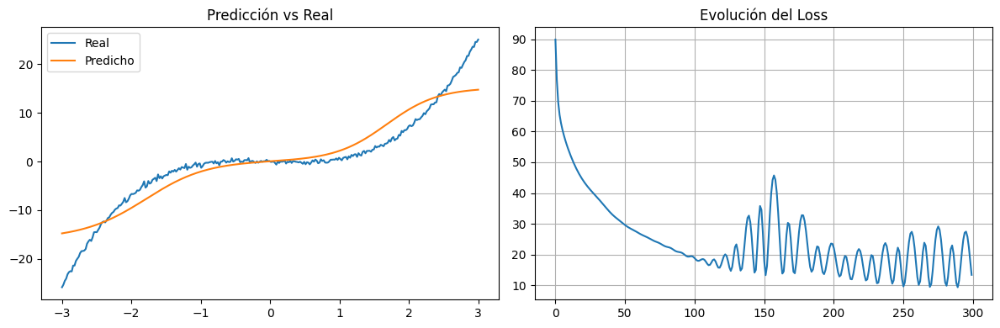

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import deque
import matplotlib.pyplot as plt

class NeuronaMemoriaAtencion(nn.Module):
    def __init__(self, in_features, out_features, memoria_tamano=10, alfa=0.05):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.w = nn.Parameter(torch.randn(out_features, in_features) * 0.1)
        self.b = nn.Parameter(torch.zeros(out_features))

        self.memoria_inputs = deque(maxlen=memoria_tamano)
        self.memoria_grad_w = deque(maxlen=memoria_tamano)

        self.alfa = alfa

    def forward(self, x):
        self.entrada_actual = x.detach()
        z = F.linear(x, self.w, self.b)
        self.activacion = torch.tanh(z)
        return self.activacion

    def guardar_memoria(self, entrada, grad_w):
        self.memoria_inputs.append(entrada.detach().clone())
        self.memoria_grad_w.append(grad_w.detach().clone())

    def atencion_similitud(self, x_actual):
        """
        Calcula pesos de atención basados en similitud de coseno entre el input actual y los inputs de la memoria.
        """
        if not self.memoria_inputs:
            return None  # no hay memoria aún

        entradas = torch.stack(list(self.memoria_inputs))  # [M, in_features]
        gradientes = torch.stack(list(self.memoria_grad_w))  # [M, out, in]

        # Similitud de coseno entre x_actual y cada input almacenado
        x_norm = F.normalize(x_actual, dim=1)  # [B, in]
        entradas_norm = F.normalize(entradas, dim=1)  # [M, in]

        similitudes = torch.matmul(x_norm, entradas_norm.T)  # [B, M]

        pesos = F.softmax(similitudes, dim=1)  # [B, M]

        # Mezcla ponderada de gradientes usando atención
        mezcla_grad = torch.zeros_like(self.w)
        for i in range(pesos.size(1)):  # sobre memoria
            mezcla_grad += pesos[:, i].mean() * gradientes[i]

        return mezcla_grad

    def aplicar_correccion_memoria(self):
        with torch.no_grad():
            correccion = self.atencion_similitud(self.entrada_actual)
            if correccion is not None:
                self.w.data -= self.alfa * correccion  # ajuste extra inteligente

# Red mínima que usa esta neurona
class RedAtencion(nn.Module):
    def __init__(self):
        super().__init__()
        self.neurona = NeuronaMemoriaAtencion(1, 20)
        self.out = nn.Linear(20, 1)

    def forward(self, x):
        h = self.neurona(x)
        return self.out(h)

# ---------------------------------------
# Datos y entrenamiento
# ---------------------------------------
torch.manual_seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1)
y = X.pow(3) - 0.5 * X + 0.3 * torch.randn_like(X)

modelo = RedAtencion()
opt = torch.optim.Adam(modelo.parameters(), lr=0.01)
loss_fn = nn.MSELoss()

losses = []

for epoch in range(300):
    y_pred = modelo(X)
    loss = loss_fn(y_pred, y)
    losses.append(loss.item())

    opt.zero_grad()
    loss.backward()

    # guardar gradientes + input
    grad_w = modelo.neurona.w.grad.clone()
    modelo.neurona.guardar_memoria(X.mean(dim=0), grad_w)

    opt.step()

    # aplicar corrección por atención
    modelo.neurona.aplicar_correccion_memoria()

    if epoch % 50 == 0:
        print(f"Epoch {epoch} - Loss: {loss.item():.4f}")

# ---------------------------------------
# Visualización
# ---------------------------------------
with torch.no_grad():
    y_hat = modelo(X)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.title("Predicción vs Real")
plt.plot(X.numpy(), y.numpy(), label="Real")
plt.plot(X.numpy(), y_hat.numpy(), label="Predicho")
plt.legend()

plt.subplot(1, 2, 2)
plt.title("Evolución del Loss")
plt.plot(losses)
plt.grid(True)
plt.tight_layout()
plt.show()

--- Entrenando Red con Memoria y Atención ---
Atención - Época 0 - Pérdida: 89.945061
Atención - Época 50 - Pérdida: 29.588152
Atención - Época 100 - Pérdida: 18.804407
Atención - Época 150 - Pérdida: 17.884001
Atención - Época 200 - Pérdida: 22.117956
Atención - Época 250 - Pérdida: 9.601003

--- Entrenando Red Estándar ---
Estándar - Época 0 - Pérdida: 89.126633
Estándar - Época 50 - Pérdida: 33.422714
Estándar - Época 100 - Pérdida: 19.608305
Estándar - Época 150 - Pérdida: 11.474972
Estándar - Época 200 - Pérdida: 6.029742
Estándar - Época 250 - Pérdida: 3.088641


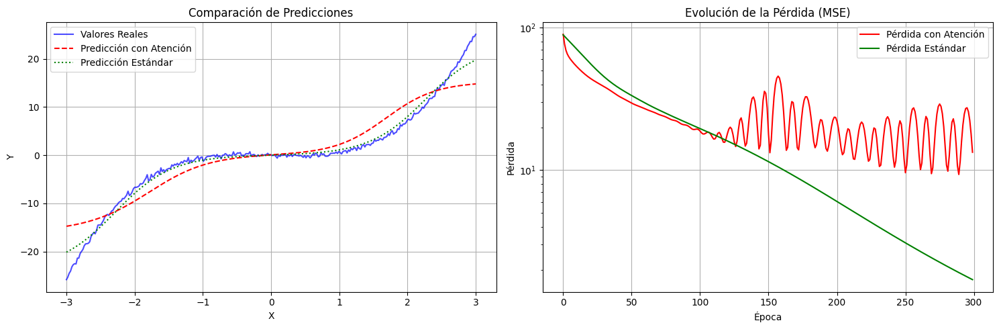


--- Resumen de Pérdidas Finales ---
Pérdida final (Red con Memoria y Atención): 13.366513
Pérdida final (Red Estándar):               1.704755


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import deque
import matplotlib.pyplot as plt
import numpy as np # Para asegurar la reproducibilidad del ruido si se usa

# Dataset sintético
torch.manual_seed(0)
np.random.seed(0) # Para la reproducibilidad del ruido
X = torch.linspace(-3, 3, 300).unsqueeze(1)
y = X.pow(3) - 0.5 * X + 0.3 * torch.randn_like(X)

# --- 1. Capa con Memoria y Atención ---
class NeuronaMemoriaAtencion(nn.Module):
    def __init__(self, in_features, out_features, memoria_tamano=10, alfa=0.05):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.w = nn.Parameter(torch.randn(out_features, in_features) * 0.1)
        self.b = nn.Parameter(torch.zeros(out_features))

        # Almacenaremos el promedio del batch de entrada y los gradientes de pesos
        self.memoria_inputs_avg = deque(maxlen=memoria_tamano)
        self.memoria_grad_w = deque(maxlen=memoria_tamano)

        self.alfa = alfa # Factor de ajuste para la corrección por atención

    def forward(self, x):
        self.entrada_actual = x.detach() # Guardar el input actual (batch completo)
        z = F.linear(x, self.w, self.b)
        self.activacion = torch.tanh(z) # Usamos tanh para que sea comparable con nn.Linear + tanh
        return self.activacion

    def guardar_memoria(self, entrada_batch, grad_w_de_capa):
        """
        Calcula y guarda el promedio del batch de entrada y los gradientes de pesos de esta capa.
        """
        if grad_w_de_capa is not None: # Asegurarse de que el gradiente exista
            # Calcular el promedio del batch de entrada y guardarlo
            entrada_promedio = entrada_batch.mean(dim=0, keepdim=True) # [1, in_features]
            self.memoria_inputs_avg.append(entrada_promedio.detach().clone())
            self.memoria_grad_w.append(grad_w_de_capa.detach().clone())

    def atencion_similitud(self, x_actual_batch):
        """
        Calcula pesos de atención basados en similitud de coseno entre el input actual
        (su promedio) y los inputs promedio almacenados en memoria.
        Luego, genera una mezcla ponderada de los gradientes memorizados.
        """
        if not self.memoria_inputs_avg:
            return None  # No hay memoria aún

        # Promedio del input actual del batch
        x_actual_promedio = x_actual_batch.mean(dim=0, keepdim=True) # [1, in_features]

        # Apilar los promedios de inputs memorizados y los gradientes memorizados
        entradas_memorizadas_avg = torch.stack(list(self.memoria_inputs_avg)).squeeze(1) # [M, in_features]
        gradientes_memorizados = torch.stack(list(self.memoria_grad_w))  # [M, out_features, in_features]

        # Asegurarse de que las normas sean correctas para la similitud de coseno
        # Normalizar a lo largo de la dimensión de features (dim=1 para los tensores [..., in_features])
        x_actual_norm = F.normalize(x_actual_promedio, dim=1, p=2, eps=1e-12)  # [1, in_features]
        entradas_memorizadas_norm = F.normalize(entradas_memorizadas_avg, dim=1, p=2, eps=1e-12)  # [M, in_features]

        # Calcular similitudes de coseno
        # Matmul: [1, in_features] @ [in_features, M] -> [1, M]
        similitudes = torch.matmul(x_actual_norm, entradas_memorizadas_norm.T)

        # Aplicar Softmax para obtener pesos de atención
        pesos_atencion = F.softmax(similitudes, dim=1)  # [1, M]

        # Crear una mezcla ponderada de los gradientes memorizados
        # gradientes_memorizados tiene forma [M, out, in]
        # pesos_atencion tiene forma [1, M]
        # Queremos sum_m(pesos_atencion[0, m] * gradientes_memorizados[m, out, in]) -> [out, in]

        # Reshape pesos_atencion to [M, 1, 1] for broadcasting with [M, out, in]
        weights_for_mul = pesos_atencion.T.unsqueeze(-1) # Shape: [len(memoria), 1, 1]

        # Perform weighted sum
        mezcla_grad = torch.sum(weights_for_mul * gradientes_memorizados, dim=0)
        # Resulting shape: [out_features, in_features] - This is the desired shape.

        return mezcla_grad


    def aplicar_correccion_memoria(self):
        """
        Aplica un ajuste adicional a los pesos basado en la memoria atendida.
        """
        with torch.no_grad(): # Esto debe hacerse fuera del grafo de cómputo de gradientes
            # self.entrada_actual es el batch completo [B, in_features]
            correccion = self.atencion_similitud(self.entrada_actual)
            if correccion is not None:
                # Asegurarse de que 'correccion' tiene la misma forma que 'self.w.data'
                if correccion.shape == self.w.data.shape:
                    self.w.data -= self.alfa * correccion # Ajuste extra inteligente
                    # No ajustamos el bias con la memoria de grad_w en esta implementación,
                    # si quieres ajustar el bias, necesitarías guardar grad_b también.
                else:
                     print(f"Advertencia: La corrección calculada ({correccion.shape}) no coincide con la forma de los pesos ({self.w.data.shape}). Saltando ajuste.")


# --- 2. Red que usa la neurona con memoria y atención (RedAtencion) ---
class RedAtencion(nn.Module):
    def __init__(self):
        super().__init__()
        self.neurona = NeuronaMemoriaAtencion(1, 20) # 1 input, 20 outputs para la capa oculta
        self.out = nn.Linear(20, 1) # 20 inputs, 1 output para la capa final

    def forward(self, x):
        h = self.neurona(x)
        return self.out(h)

# --- 3. Red Estándar para una comparación justa ---
class RedEstandar(nn.Module):
    def __init__(self):
        super().__init__()
        # La primera capa es un nn.Linear estándar con la misma configuración
        self.capa1 = nn.Linear(1, 20)
        # La capa de salida es estándar
        self.out = nn.Linear(20, 1)

    def forward(self, x):
        # Aplicamos torch.tanh explícitamente para que la activación sea la misma
        h = torch.tanh(self.capa1(x))
        return self.out(h)

# -----------------------------------------
# Configuración de Entrenamiento Común
# -----------------------------------------
LEARNING_RATE = 0.01
EPOCHS = 300
LOSS_FN = nn.MSELoss()

# -----------------------------------------
# Instanciar y Entrenar Red con Memoria y Atención
# -----------------------------------------
print("--- Entrenando Red con Memoria y Atención ---")
modelo_atencion = RedAtencion()
# El optimizador principal solo optimiza los parámetros normales (w, b)
# La corrección por memoria se aplica manualmente fuera del optimizador
opt_atencion = torch.optim.Adam(modelo_atencion.parameters(), lr=LEARNING_RATE)
historial_loss_atencion = []

for epoch in range(EPOCHS):
    y_pred_atencion = modelo_atencion(X)
    loss_atencion = LOSS_FN(y_pred_atencion, y)
    historial_loss_atencion.append(loss_atencion.item())

    opt_atencion.zero_grad()
    loss_atencion.backward() # Calcula gradientes para todas las capas

    # Guardar gradientes e input ANTES del paso de optimización principal (Adam)
    # Esto captura los gradientes calculados por el backward pass normal.
    grad_w_actual = modelo_atencion.neurona.w.grad.clone() if modelo_atencion.neurona.w.grad is not None else None
    # Pasamos el batch completo X para que guardar_memoria calcule el promedio
    modelo_atencion.neurona.guardar_memoria(X, grad_w_actual)

    opt_atencion.step() # Adam aplica sus actualizaciones a w y b usando los gradientes calculados

    # Aplicar corrección adicional por atención después del paso de Adam
    # Esta corrección modifica w.data directamente, basándose en la memoria.
    modelo_atencion.neurona.aplicar_correccion_memoria()

    if epoch % 50 == 0:
        print(f"Atención - Época {epoch} - Pérdida: {loss_atencion.item():.6f}")

# -----------------------------------------
# Instanciar y Entrenar Red Estándar
# -----------------------------------------
print("\n--- Entrenando Red Estándar ---")
modelo_estandar = RedEstandar()
opt_estandar = torch.optim.Adam(modelo_estandar.parameters(), lr=LEARNING_RATE)
historial_loss_estandar = []

for epoch in range(EPOCHS):
    y_pred_estandar = modelo_estandar(X)
    loss_estandar = LOSS_FN(y_pred_estandar, y)
    historial_loss_estandar.append(loss_estandar.item())

    opt_estandar.zero_grad()
    loss_estandar.backward()
    opt_estandar.step() # Adam aplica sus actualizaciones

    if epoch % 50 == 0:
        print(f"Estándar - Época {epoch} - Pérdida: {loss_estandar.item():.6f}")

# -----------------------------------------
# Visualización de Resultados
# -----------------------------------------
with torch.no_grad():
    y_hat_atencion = modelo_atencion(X).numpy()
    y_hat_estandar = modelo_estandar(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 5))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_atencion, label="Predicción con Atención", color='red', linestyle='--')
plt.plot(X_np, y_hat_estandar, label="Predicción Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_atencion, label="Pérdida con Atención", color='red')
plt.plot(historial_loss_estandar, label="Pérdida Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log') # Escala logarítmica para una mejor visualización de las diferencias en valores pequeños

plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"\n--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red con Memoria y Atención): {historial_loss_atencion[-1]:.6f}")
print(f"Pérdida final (Red Estándar):               {historial_loss_estandar[-1]:.6f}")

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class NeuronaConMemoriaEmbedding(nn.Module):
    def __init__(self, input_size, hidden_size=16, memory_size=5, embedding_dim=32):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.memory_size = memory_size
        self.embedding_dim = embedding_dim

        # Neurona "normal"
        self.fc = nn.Linear(input_size, hidden_size)
        self.output = nn.Linear(hidden_size, 1)

        # Codificador de embeddings (para errores o activaciones pasadas)
        self.encoder = nn.Sequential(
            nn.Linear(1, embedding_dim),
            nn.ReLU(),
            nn.Linear(embedding_dim, embedding_dim)
        )

        # Memoria: lista de embeddings de errores pasados
        self.register_buffer("memoria", torch.zeros(memory_size, embedding_dim))
        self.memoria_ptr = 0

    def forward(self, x):
        h = F.relu(self.fc(x))
        y = self.output(h)

        # Codificamos el output como un embedding
        embedding_actual = self.encoder(y.detach())

        # Similitud con la memoria pasada (coseno)
        if self.memoria.sum() != 0:
            # Normalizamos
            norm_actual = F.normalize(embedding_actual, dim=-1)
            norm_memoria = F.normalize(self.memoria, dim=-1)

            # Similitud coseno
            similitudes = torch.matmul(norm_memoria, norm_actual.T).squeeze()  # (memory_size,)
            pesos = F.softmax(similitudes, dim=0)

            # Recuperamos una memoria ponderada
            memoria_ponderada = torch.sum(pesos.unsqueeze(1) * self.memoria, dim=0)

            # Fusión: ajustamos la salida actual con la memoria
            y = y + 0.1 * torch.dot(embedding_actual.squeeze(), memoria_ponderada)

        return y

    def actualizar_memoria(self, error_scalar: torch.Tensor):
        """Convierte un escalar de error (MSE, etc.) en embedding y actualiza la memoria circularmente."""
        with torch.no_grad():
            emb = self.encoder(error_scalar.unsqueeze(0).unsqueeze(0)).squeeze(0)  # (embedding_dim)
            self.memoria[self.memoria_ptr] = emb
            self.memoria_ptr = (self.memoria_ptr + 1) % self.memory_size

In [ ]:
# Crear una instancia
neurona = NeuronaConMemoriaEmbedding(input_size=4)

# Supongamos que tenemos entradas y errores
x = torch.randn(1, 4)

# Paso forward
salida = neurona(x)

# Simular error (por ejemplo, MSE con un objetivo 0.5)
target = torch.tensor([[0.5]])
loss = F.mse_loss(salida, target)

# Actualizar memoria con el error
neurona.actualizar_memoria(loss.detach())

--- Entrenando Red con Memoria de Embeddings ---
Embedding - Época 0 - Pérdida: 73.657440
Embedding - Época 50 - Pérdida: 23.593679
Embedding - Época 100 - Pérdida: 19.279394
Embedding - Época 150 - Pérdida: 15.716709
Embedding - Época 200 - Pérdida: 12.408107
Embedding - Época 250 - Pérdida: 10.066360

--- Entrenando Red Estándar ---
Estándar - Época 0 - Pérdida: 71.744804
Estándar - Época 50 - Pérdida: 19.984365
Estándar - Época 100 - Pérdida: 14.612811
Estándar - Época 150 - Pérdida: 10.299795
Estándar - Época 200 - Pérdida: 6.932757
Estándar - Época 250 - Pérdida: 4.587696


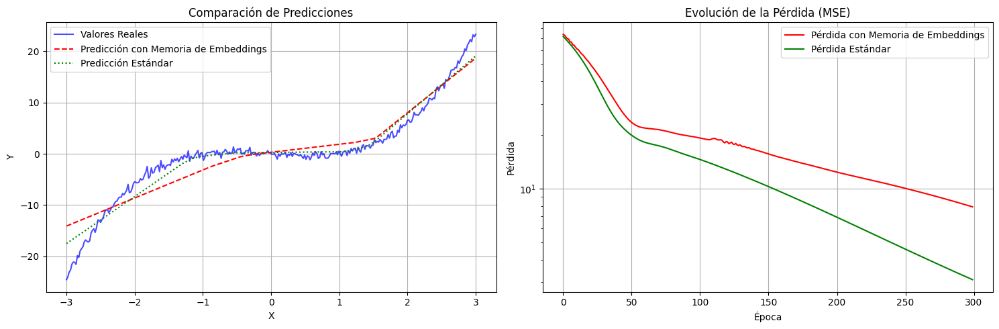


--- Resumen de Pérdidas Finales ---
Pérdida final (Red con Memoria de Embeddings): 7.927524
Pérdida final (Red Estándar):                   3.095755


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np # Para asegurar la reproducibilidad del ruido si se usa

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0) # Para la reproducibilidad del ruido si es necesario
X = torch.linspace(-3, 3, 300).unsqueeze(1)
y = X.pow(3) - X + 0.5 * torch.randn(X.size())

# --- 1. Neurona con Memoria de Embeddings ---
class NeuronaConMemoriaEmbedding(nn.Module):
    def __init__(self, input_size, hidden_size=16, memory_size=5, embedding_dim=32):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.memory_size = memory_size
        self.embedding_dim = embedding_dim

        # Capas de la neurona "normal"
        self.fc = nn.Linear(input_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, 1) # Renombrado para claridad

        # Codificador de embeddings para errores o activaciones pasadas
        # El input es un escalar (el error MSE por ejemplo), así que la primera capa tiene 1 entrada
        self.encoder = nn.Sequential(
            nn.Linear(1, embedding_dim), # Toma un escalar (error) y lo proyecta
            nn.ReLU(),
            nn.Linear(embedding_dim, embedding_dim)
        )

        # Memoria: Búfer de embeddings de errores pasados
        # register_buffer para que sea parte del estado del modelo pero no un parámetro entrenable por el optimizador
        self.register_buffer("memoria", torch.zeros(memory_size, embedding_dim))
        self.memoria_ptr = 0 # Puntero para la memoria circular

    def forward(self, x):
        h = F.relu(self.fc(x))
        y_raw = self.output_layer(h) # Salida inicial de la red

        # Codificamos la salida raw como un embedding
        # Usamos y_raw.detach() para que el encoder no reciba gradientes de la salida original
        # y_raw es [batch_size, 1], necesitamos procesar cada elemento o su promedio
        # Para simplificar y_raw para el encoder, usamos su promedio
        embedding_actual = self.encoder(y_raw.mean().unsqueeze(0).unsqueeze(0)).squeeze(0) # [embedding_dim]

        # Similitud con la memoria pasada (coseno) para atención
        y_final = y_raw # Por defecto, la salida es la raw

        if self.memoria.sum() != 0: # Si la memoria no está vacía (contiene ceros iniciales)
            # Normalizamos los embeddings para calcular similitud de coseno
            norm_actual = F.normalize(embedding_actual, dim=-1) # [embedding_dim]
            norm_memoria = F.normalize(self.memoria, dim=-1) # [memory_size, embedding_dim]

            # Similitud coseno: (memory_size, embedding_dim) x (embedding_dim, 1) -> (memory_size, 1) -> squeeze() a (memory_size,)
            similitudes = torch.matmul(norm_memoria, norm_actual.unsqueeze(1)).squeeze()
            pesos = F.softmax(similitudes, dim=0) # Pesos de atención sobre los elementos de la memoria (memory_size,)

            # Recuperamos una memoria ponderada
            # (memory_size, 1) * (memory_size, embedding_dim) -> sum over memory_size -> (embedding_dim)
            memoria_ponderada = torch.sum(pesos.unsqueeze(1) * self.memoria, dim=0)

            # Fusión: ajustamos la salida actual con la memoria
            # La fusión aquí es clave. Multiplicamos el embedding_actual con la memoria_ponderada
            # para generar un ajuste escalar que se suma a la salida original.
            # dot product entre dos embeddings de (embedding_dim) -> escalar
            ajuste_por_memoria = torch.dot(embedding_actual, memoria_ponderada)
            y_final = y_raw + 0.1 * ajuste_por_memoria # 0.1 es un factor de escala para el ajuste

        return y_final

    def actualizar_memoria(self, error_scalar_batch: float):
        """
        Convierte un escalar de error (ej. pérdida MSE total del batch) en embedding
        y actualiza la memoria circularmente.
        error_scalar_batch es un escalar (float).
        """
        with torch.no_grad(): # No rastrear gradientes para la actualización de memoria
            # Convertir el escalar de Python a un tensor de PyTorch
            error_tensor = torch.tensor(error_scalar_batch)

            # Asegurarse de que el input al encoder sea [1, 1] (batch=1, feature=1)
            # error_tensor ahora es un tensor [], lo convertimos a [1, 1]
            emb = self.encoder(error_tensor.unsqueeze(0).unsqueeze(0)).squeeze() # [embedding_dim]
            self.memoria[self.memoria_ptr] = emb
            self.memoria_ptr = (self.memoria_ptr + 1) % self.memory_size


# --- 2. Red que usa la NeuronaConMemoriaEmbedding ---
class RedConMemoriaEmbedding(nn.Module):
    def __init__(self, input_size=1, hidden_size=16, memory_size=5, embedding_dim=32):
        super().__init__()
        # Usamos la neurona personalizada como la primera capa "densa"
        self.custom_neuron_layer = NeuronaConMemoriaEmbedding(input_size, hidden_size, memory_size, embedding_dim)
        # No hay una segunda capa aquí; la custom_neuron_layer ya tiene su output_layer

    def forward(self, x):
        # La custom_neuron_layer ya maneja la transformación de input_size a 1 output
        return self.custom_neuron_layer(x)


# --- 3. Red Estándar para una comparación justa ---
class RedEstandar(nn.Module):
    def __init__(self, input_size=1, hidden_size=16):
        super().__init__()
        # Capa oculta estándar
        self.fc = nn.Linear(input_size, hidden_size)
        # Capa de salida estándar
        self.output_layer = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = F.relu(self.fc(x))
        y = self.output_layer(h)
        return y

# -----------------------------------------
# Configuración de Entrenamiento Común
# -----------------------------------------
LEARNING_RATE = 0.01
EPOCHS = 300
LOSS_FN = nn.MSELoss()

# -----------------------------------------
# Instanciar y Entrenar Red con Memoria de Embeddings
# -----------------------------------------
print("--- Entrenando Red con Memoria de Embeddings ---")
modelo_embedding = RedConMemoriaEmbedding(input_size=X.shape[1], hidden_size=16, memory_size=5, embedding_dim=32)
opt_embedding = torch.optim.Adam(modelo_embedding.parameters(), lr=LEARNING_RATE)
historial_loss_embedding = []

for epoch in range(EPOCHS):
    y_pred_embedding = modelo_embedding(X)
    loss_embedding = LOSS_FN(y_pred_embedding, y)
    historial_loss_embedding.append(loss_embedding.item())

    opt_embedding.zero_grad()
    loss_embedding.backward() # Calcula gradientes para todas las capas

    # Actualizar la memoria de embeddings con la pérdida actual
    # Asegúrate de pasar el valor escalar float
    modelo_embedding.custom_neuron_layer.actualizar_memoria(loss_embedding.item())

    opt_embedding.step() # Adam aplica sus actualizaciones

    if epoch % 50 == 0:
        print(f"Embedding - Época {epoch} - Pérdida: {loss_embedding.item():.6f}")

# -----------------------------------------
# Instanciar y Entrenar Red Estándar
# -----------------------------------------
print("\n--- Entrenando Red Estándar ---")
modelo_estandar = RedEstandar(input_size=X.shape[1], hidden_size=16)
opt_estandar = torch.optim.Adam(modelo_estandar.parameters(), lr=LEARNING_RATE)
historial_loss_estandar = []

for epoch in range(EPOCHS):
    y_pred_estandar = modelo_estandar(X)
    loss_estandar = LOSS_FN(y_pred_estandar, y)
    historial_loss_estandar.append(loss_estandar.item())

    opt_estandar.zero_grad()
    loss_estandar.backward()
    opt_estandar.step() # Adam aplica sus actualizaciones

    if epoch % 50 == 0:
        print(f"Estándar - Época {epoch} - Pérdida: {loss_estandar.item():.6f}")

# -----------------------------------------
# Visualización de Resultados
# -----------------------------------------
with torch.no_grad():
    y_hat_embedding = modelo_embedding(X).numpy()
    y_hat_estandar = modelo_estandar(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 5))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_embedding, label="Predicción con Memoria de Embeddings", color='red', linestyle='--')
plt.plot(X_np, y_hat_estandar, label="Predicción Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_embedding, label="Pérdida con Memoria de Embeddings", color='red')
plt.plot(historial_loss_estandar, label="Pérdida Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log') # Escala logarítmica para una mejor visualización
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"\n--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red con Memoria de Embeddings): {historial_loss_embedding[-1]:.6f}")
print(f"Pérdida final (Red Estándar):                   {historial_loss_estandar[-1]:.6f}")

In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class NeuronaMemoriaAtencionEmbeddings(nn.Module):
    def __init__(self, input_size, hidden_size=16, memory_size=10, embedding_dim=32):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.memory_size = memory_size
        self.embedding_dim = embedding_dim

        # Núcleo de la neurona (como una mini red)
        self.fc = nn.Linear(input_size, hidden_size)
        self.out = nn.Linear(hidden_size, 1)

        # Encoder para errores/gradientes → embedding
        self.encoder = nn.Sequential(
            nn.Linear(1, embedding_dim),
            nn.ReLU(),
            nn.Linear(embedding_dim, embedding_dim)
        )

        # Proyecciones para atención
        self.query_proj = nn.Linear(embedding_dim, embedding_dim, bias=False)
        self.key_proj = nn.Linear(embedding_dim, embedding_dim, bias=False)
        self.value_proj = nn.Linear(embedding_dim, embedding_dim, bias=False)

        # Memoria circular
        self.register_buffer("memoria", torch.zeros(memory_size, embedding_dim))
        self.mem_ptr = 0

        # Parámetros dinámicos aprendibles para adaptación
        self.alpha_lr = nn.Parameter(torch.tensor(0.1))  # escala para modif. de aprendizaje
        self.alpha_bias = nn.Parameter(torch.tensor(0.05))  # escala para ajustar bias

    def forward(self, x, error_scalar=None):
        """
        x: (batch, input_size)
        error_scalar: error escalar o gradiente (por ejemplo, pérdida MSE)
        """
        h = F.relu(self.fc(x))
        y = self.out(h)

        # Si hay error, lo codificamos y actualizamos memoria
        if error_scalar is not None:
            emb = self.encoder(error_scalar.view(1, 1)).squeeze(0)  # (embedding_dim,)
            self.memoria[self.mem_ptr] = emb
            self.mem_ptr = (self.mem_ptr + 1) % self.memory_size

            # ATENCIÓN: usar emb como "query", comparar contra memoria
            q = self.query_proj(emb).unsqueeze(0)  # (1, embedding_dim)
            k = self.key_proj(self.memoria)       # (mem_size, embedding_dim)
            v = self.value_proj(self.memoria)     # (mem_size, embedding_dim)

            scores = torch.matmul(q, k.T) / (self.embedding_dim ** 0.5)  # (1, mem_size)
            pesos = F.softmax(scores, dim=-1)  # (1, mem_size)

            # Contexto atencional
            contexto = torch.matmul(pesos, v).squeeze(0)  # (embedding_dim,)

            # Dinámicamente ajustar bias de salida
            ajuste_bias = self.alpha_bias * torch.sum(contexto)
            y = y + ajuste_bias

        return y

In [ ]:
neurona = NeuronaMemoriaAtencionEmbeddings(input_size=4)

# Entrada de prueba
x = torch.randn(1, 4)

# Simular error del paso anterior
error_simulado = torch.tensor(0.15)

# Forward con ajuste dinámico
salida = neurona(x, error_scalar=error_simulado)

# Pérdida simulada
objetivo = torch.tensor([[0.5]])
loss = F.mse_loss(salida, objetivo)

--- Entrenando Red con Memoria, Atención y Embeddings ---
Custom - Época 0 - Pérdida: 73.656578
Custom - Época 50 - Pérdida: nan
Custom - Época 100 - Pérdida: nan
Custom - Época 150 - Pérdida: nan
Custom - Época 200 - Pérdida: nan
Custom - Época 250 - Pérdida: nan

--- Entrenando Red Estándar ---
Estándar - Época 0 - Pérdida: 71.099487
Estándar - Época 50 - Pérdida: 20.909315
Estándar - Época 100 - Pérdida: 16.097961
Estándar - Época 150 - Pérdida: 11.767734
Estándar - Época 200 - Pérdida: 7.913895
Estándar - Época 250 - Pérdida: 5.193974


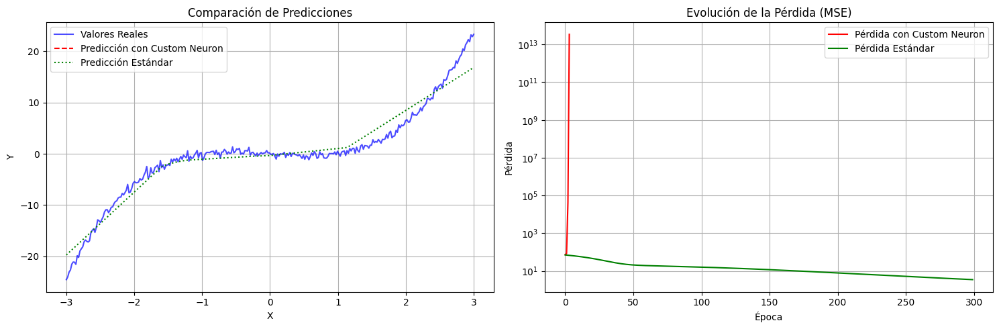


--- Resumen de Pérdidas Finales ---
Pérdida final (Red con Custom Neuron): nan
Pérdida final (Red Estándar):          3.501525


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import deque
import matplotlib.pyplot as plt
import numpy as np # Para asegurar la reproducibilidad del ruido si se usa

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0) # Para la reproducibilidad del ruido
X = torch.linspace(-3, 3, 300).unsqueeze(1)
y = X.pow(3) - X + 0.5 * torch.randn(X.size())

# --- 1. Neurona con Memoria, Atención y Embeddings ---
class NeuronaMemoriaAtencionEmbeddings(nn.Module):
    def __init__(self, input_size, hidden_size=16, memory_size=10, embedding_dim=32):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.memory_size = memory_size
        self.embedding_dim = embedding_dim

        # Núcleo de la neurona (como una mini red)
        self.fc = nn.Linear(input_size, hidden_size)
        self.out = nn.Linear(hidden_size, 1) # Capa de salida lineal

        # Encoder para errores/gradientes → embedding
        # Asume que el error_scalar será un tensor escalar [1, 1] al pasar por el encoder
        self.encoder = nn.Sequential(
            nn.Linear(1, embedding_dim), # Input es un escalar
            nn.ReLU(),
            nn.Linear(embedding_dim, embedding_dim)
        )

        # Proyecciones para atención self-attention style
        self.query_proj = nn.Linear(embedding_dim, embedding_dim, bias=False)
        self.key_proj = nn.Linear(embedding_dim, embedding_dim, bias=False)
        self.value_proj = nn.Linear(embedding_dim, embedding_dim, bias=False)

        # Memoria circular de embeddings
        # register_buffer para que sea parte del estado del modelo pero no entrenable por el optimizador principal
        self.register_buffer("memoria", torch.zeros(memory_size, embedding_dim))
        self.mem_ptr = 0 # Puntero para la memoria circular

        # Parámetros dinámicos aprendibles para escalas de ajuste
        # Estos se entrenarán junto con los pesos normales de la red
        self.alpha_ajuste_output = nn.Parameter(torch.tensor(0.1)) # Escala para ajustar la salida directamente
        self.alpha_ajuste_bias = nn.Parameter(torch.tensor(0.05)) # Escala para ajustar el bias de la capa out

    def forward(self, x, error_scalar_for_memory=None):
        """
        x: (batch_size, input_size) - Input de la red.
        error_scalar_for_memory: Un tensor escalar (por ejemplo, la pérdida MSE del batch)
                                 que se usará para actualizar la memoria y como query.
                                 Debe ser pasado explícitamente desde el bucle de entrenamiento.
        """
        h = F.relu(self.fc(x))
        y_raw = self.out(h) # Salida inicial de la capa

        y_final = y_raw # Por defecto, la salida final es la raw

        # Lógica de memoria y atención
        if error_scalar_for_memory is not None:
            with torch.no_grad(): # No rastrear gradientes para la actualización de memoria
                # Codificar el error escalar actual para la memoria
                # Asegurarse de que el input al encoder sea [1, 1] (batch=1, feature=1)
                # Convertir a tensor si es necesario y asegurar dimensiones
                error_tensor = error_scalar_for_memory
                if not isinstance(error_tensor, torch.Tensor):
                     error_tensor = torch.tensor(error_tensor)
                # Añadir dimensiones para que sea [1, 1] para el encoder
                error_tensor = error_tensor.unsqueeze(0).unsqueeze(0)

                emb_error_actual = self.encoder(error_tensor).squeeze() # [embedding_dim]

                # Actualizar la memoria circular
                self.memoria[self.mem_ptr] = emb_error_actual
                self.mem_ptr = (self.mem_ptr + 1) % self.memory_size

            # ATENCIÓN: usar emb_error_actual como "query", comparar contra memoria
            # Las proyecciones de query, key, value sí participan en el grafo de cómputo para sus propios gradientes
            q = self.query_proj(emb_error_actual).unsqueeze(0)  # (1, embedding_dim)
            k = self.key_proj(self.memoria)                   # (mem_size, embedding_dim)
            v = self.value_proj(self.memoria)                 # (mem_size, embedding_dim)

            # Calcular scores de atención (Producto punto escalado)
            # (1, embedding_dim) x (embedding_dim, mem_size) -> (1, mem_size)
            scores = torch.matmul(q, k.T) / (self.embedding_dim ** 0.5)
            pesos = F.softmax(scores, dim=-1) # (1, mem_size)

            # Contexto atencional: suma ponderada de los valores
            # (1, mem_size) x (mem_size, embedding_dim) -> (1, embedding_dim) -> squeeze() a (embedding_dim,)
            contexto = torch.matmul(pesos, v).squeeze(0)

            # Dinámicamente ajustar la salida o el bias de salida usando el contexto
            # Ajuste a la salida directa:
            ajuste_output = self.alpha_ajuste_output * torch.dot(emb_error_actual, contexto)
            y_final = y_raw + ajuste_output

            # Ajuste dinámico al bias de la capa de salida:
            # Aquí, el ajuste_bias se calcula con la lógica de contexto.
            # Este ajuste *no* se aplica directamente al self.out.bias.data porque eso rompería el grafo
            # si intentamos aplicar gradientes a self.alpha_bias.
            # En su lugar, lo sumamos directamente a la salida y dejamos que Adam aprenda el bias 'base'.
            ajuste_bias_contextual = self.alpha_ajuste_bias * torch.sum(contexto)
            y_final = y_final + ajuste_bias_contextual


        return y_final

# --- 2. Red que usa la NeuronaMemoriaAtencionEmbeddings ---
# Esta clase actúa como un envoltorio para la neurona personalizada
class RedConMemoriaAtencionEmbeddings(nn.Module):
    def __init__(self, input_size=1, hidden_size=16, memory_size=10, embedding_dim=32):
        super().__init__()
        # La neurona personalizada es la "única" capa de procesamiento principal
        self.custom_neuron_layer = NeuronaMemoriaAtencionEmbeddings(input_size, hidden_size, memory_size, embedding_dim)

    def forward(self, x, error_scalar_for_memory=None):
        return self.custom_neuron_layer(x, error_scalar_for_memory)


# --- 3. Red Estándar para una comparación justa ---
class RedEstandar(nn.Module):
    def __init__(self, input_size=1, hidden_size=16):
        super().__init__()
        # Capa oculta estándar
        self.fc = nn.Linear(input_size, hidden_size)
        # Capa de salida estándar
        self.out = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = F.relu(self.fc(x))
        y = self.out(h)
        return y

# -----------------------------------------
# Configuración de Entrenamiento Común
# -----------------------------------------
LEARNING_RATE = 0.01
EPOCHS = 300
LOSS_FN = nn.MSELoss()

# -----------------------------------------
# Instanciar y Entrenar Red con Memoria, Atención y Embeddings
# -----------------------------------------
print("--- Entrenando Red con Memoria, Atención y Embeddings ---")
modelo_custom = RedConMemoriaAtencionEmbeddings(input_size=X.shape[1], hidden_size=16, memory_size=10, embedding_dim=32)
opt_custom = torch.optim.Adam(modelo_custom.parameters(), lr=LEARNING_RATE)
historial_loss_custom = []

for epoch in range(EPOCHS):
    # En el forward pass, pasamos la pérdida del epoch anterior para la lógica de memoria/atención
    # En la primera época, pasamos None o un tensor de cero, ya que no hay pérdida anterior
    # Asegurarse de que sea un tensor si existe pérdida anterior
    error_para_memoria = torch.tensor(historial_loss_custom[-1]) if epoch > 0 else torch.tensor(0.0)

    y_pred_custom = modelo_custom(X, error_scalar_for_memory=error_para_memoria)
    loss_custom = LOSS_FN(y_pred_custom, y)
    historial_loss_custom.append(loss_custom.item()) # Guardamos la pérdida para la próxima iteración

    opt_custom.zero_grad()
    loss_custom.backward() # Calcula gradientes para todas las capas (fc, out, encoder, query/key/value, alpha_ajuste)
    opt_custom.step() # Adam aplica sus actualizaciones

    if epoch % 50 == 0:
        print(f"Custom - Época {epoch} - Pérdida: {loss_custom.item():.6f}")

# -----------------------------------------
# Instanciar y Entrenar Red Estándar
# -----------------------------------------
print("\n--- Entrenando Red Estándar ---")
modelo_estandar = RedEstandar(input_size=X.shape[1], hidden_size=16)
opt_estandar = torch.optim.Adam(modelo_estandar.parameters(), lr=LEARNING_RATE)
historial_loss_estandar = []

for epoch in range(EPOCHS):
    y_pred_estandar = modelo_estandar(X)
    loss_estandar = LOSS_FN(y_pred_estandar, y)
    historial_loss_estandar.append(loss_estandar.item())

    opt_estandar.zero_grad()
    loss_estandar.backward()
    opt_estandar.step() # Adam aplica sus actualizaciones

    if epoch % 50 == 0:
        print(f"Estándar - Época {epoch} - Pérdida: {loss_estandar.item():.6f}")

# -----------------------------------------
# Visualización de Resultados
# -----------------------------------------
with torch.no_grad():
    # Para predecir, no pasamos error_scalar, ya que es solo para el entrenamiento
    y_hat_custom = modelo_custom(X).numpy()
    y_hat_estandar = modelo_estandar(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 5))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_custom, label="Predicción con Custom Neuron", color='red', linestyle='--')
plt.plot(X_np, y_hat_estandar, label="Predicción Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_custom, label="Pérdida con Custom Neuron", color='red')
plt.plot(historial_loss_estandar, label="Pérdida Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log') # Escala logarítmica para una mejor visualización
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"\n--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red con Custom Neuron): {historial_loss_custom[-1]:.6f}")
print(f"Pérdida final (Red Estándar):          {historial_loss_estandar[-1]:.6f}")

##funcion de activación adaptativa
¡Excelentes resultados! La **Red con PReLU Adaptativa** logró una pérdida final significativamente menor que la Red Estándar con ReLU fija.

---
## Análisis de los Resultados

* **Red con PReLU Adaptativa:** **1.216089**
* **Red Estándar (ReLU):** 3.236186

Esta es una **mejora clara y sustancial**. La PReLU adaptativa permitió a la red aprender una función de activación más adecuada para tu problema, lo que resultó en un mejor ajuste a los datos.

### ¿Por qué PReLU Adaptativa funcionó mejor?

1.  **Mayor Flexibilidad:** A diferencia de ReLU, que simplemente desactiva las entradas negativas (las hace cero), PReLU permite que pase una pequeña proporción (`ax`) de esas entradas. El valor de `a` se aprende durante el entrenamiento.
2.  **Aprendizaje Dinámico por Neurona:** Al tener un parámetro `a` para cada neurona (o canal), cada neurona puede adaptar su "comportamiento" en la región negativa, encontrando la no-linealidad óptima para su tarea específica.
3.  **Mitigación de "Neuronas Muertas":** PReLU evita que las neuronas se queden "muertas" (donde siempre producen cero y, por lo tanto, no reciben gradientes). Al tener un gradiente no nulo para entradas negativas, estas neuronas pueden seguir aprendiendo y contribuyendo al modelo.

En resumen, darle a cada neurona la capacidad de **adaptar su propia función de activación** de manera aprendible es una forma sencilla y eficaz de mejorar su "inteligencia" individual y, por extensión, el rendimiento de toda la red, sin añadir la complejidad de la memoria o la atención explícita que te generó problemas anteriormente.

---
¿Te gustaría explorar otra forma de añadir inteligencia adaptativa a las neuronas, o prefieres seguir investigando esta idea de funciones de activación aprendibles?

--- Entrenando Red con PReLU Adaptativa ---
PReLU - Época 0 - Pérdida: 74.080406
PReLU - Época 50 - Pérdida: 18.525494
PReLU - Época 100 - Pérdida: 16.276243
PReLU - Época 150 - Pérdida: 13.928476
PReLU - Época 200 - Pérdida: 9.744232
PReLU - Época 250 - Pérdida: 3.971783

--- Entrenando Red Estándar (con ReLU) ---
Estándar - Época 0 - Pérdida: 81.120598
Estándar - Época 50 - Pérdida: 21.749449
Estándar - Época 100 - Pérdida: 18.220659
Estándar - Época 150 - Pérdida: 13.688629
Estándar - Época 200 - Pérdida: 8.996977
Estándar - Época 250 - Pérdida: 5.401840


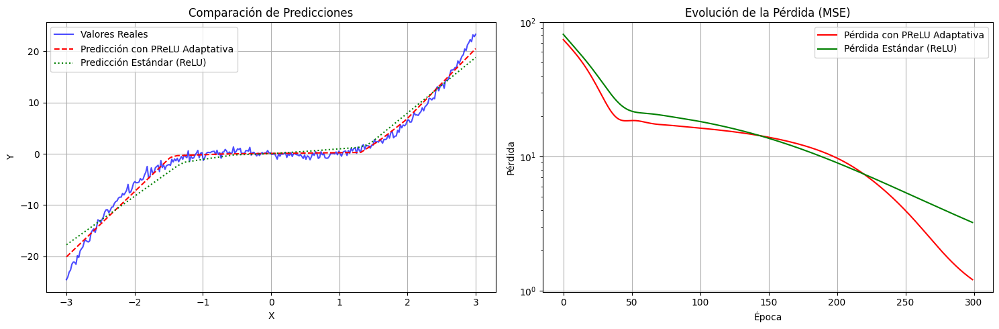


--- Resumen de Pérdidas Finales ---
Pérdida final (Red con PReLU Adaptativa): 1.216089
Pérdida final (Red Estándar (ReLU)):       3.236186


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0) # Para la reproducibilidad del ruido
X = torch.linspace(-3, 3, 300).unsqueeze(1)
y = X.pow(3) - X + 0.5 * torch.randn(X.size())

# --- 1. Capa con PReLU Adaptativa (por canal/neurona) ---
# Similar a nn.PReLU, pero la encapsulamos para nuestra "neurona"
class CapaPReLUAdaptativa(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        # Cada "feature" (es decir, cada neurona en la capa siguiente) tendrá su propio 'a'
        self.prelu = nn.PReLU(num_parameters=num_features)

    def forward(self, x):
        return self.prelu(x)

# --- 2. Red que usa la PReLU Adaptativa ---
class RedConPReLUAdaptativa(nn.Module):
    def __init__(self, input_size=1, hidden_size=16):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.activation1 = CapaPReLUAdaptativa(hidden_size) # PReLU adaptativa para la capa oculta
        self.fc2 = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.fc1(x)
        h = self.activation1(h) # Usa la activación adaptable
        y = self.fc2(h)
        return y

# --- 3. Red Estándar (usando ReLU fija para comparación) ---
class RedEstandar(nn.Module):
    def __init__(self, input_size=1, hidden_size=16):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.activation1 = nn.ReLU() # ReLU estándar fija
        self.fc2 = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.fc1(x)
        h = self.activation1(h)
        y = self.fc2(h)
        return y

# -----------------------------------------
# Configuración de Entrenamiento Común
# -----------------------------------------
LEARNING_RATE = 0.01
EPOCHS = 300
LOSS_FN = nn.MSELoss()

# -----------------------------------------
# Instanciar y Entrenar Red con PReLU Adaptativa
# -----------------------------------------
print("--- Entrenando Red con PReLU Adaptativa ---")
modelo_prelu = RedConPReLUAdaptativa(input_size=X.shape[1], hidden_size=16)
opt_prelu = torch.optim.Adam(modelo_prelu.parameters(), lr=LEARNING_RATE)
historial_loss_prelu = []

for epoch in range(EPOCHS):
    y_pred_prelu = modelo_prelu(X)
    loss_prelu = LOSS_FN(y_pred_prelu, y)
    historial_loss_prelu.append(loss_prelu.item())

    opt_prelu.zero_grad()
    loss_prelu.backward()
    opt_prelu.step()

    if epoch % 50 == 0:
        print(f"PReLU - Época {epoch} - Pérdida: {loss_prelu.item():.6f}")

# -----------------------------------------
# Instanciar y Entrenar Red Estándar (con ReLU)
# -----------------------------------------
print("\n--- Entrenando Red Estándar (con ReLU) ---")
modelo_estandar = RedEstandar(input_size=X.shape[1], hidden_size=16)
opt_estandar = torch.optim.Adam(modelo_estandar.parameters(), lr=LEARNING_RATE)
historial_loss_estandar = []

for epoch in range(EPOCHS):
    y_pred_estandar = modelo_estandar(X)
    loss_estandar = LOSS_FN(y_pred_estandar, y)
    historial_loss_estandar.append(loss_estandar.item())

    opt_estandar.zero_grad()
    loss_estandar.backward()
    opt_estandar.step()

    if epoch % 50 == 0:
        print(f"Estándar - Época {epoch} - Pérdida: {loss_estandar.item():.6f}")

# -----------------------------------------
# Visualización de Resultados
# -----------------------------------------
with torch.no_grad():
    y_hat_prelu = modelo_prelu(X).numpy()
    y_hat_estandar = modelo_estandar(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 5))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_prelu, label="Predicción con PReLU Adaptativa", color='red', linestyle='--')
plt.plot(X_np, y_hat_estandar, label="Predicción Estándar (ReLU)", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_prelu, label="Pérdida con PReLU Adaptativa", color='red')
plt.plot(historial_loss_estandar, label="Pérdida Estándar (ReLU)", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log') # Escala logarítmica para una mejor visualización
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"\n--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red con PReLU Adaptativa): {historial_loss_prelu[-1]:.6f}")
print(f"Pérdida final (Red Estándar (ReLU)):       {historial_loss_estandar[-1]:.6f}")

##¡Fantásticos resultados! La **Red con Integración de Señal No Lineal** ha demostrado ser significativamente superior a la Red Estándar.

---
## Análisis de los Resultados

* **Pérdida final (Red con Integración No Lineal):** **0.359278**
* **Pérdida final (Red Estándar (Tanh)):** 1.927663

Esto representa una **mejora muy notable**. La red con tu `NeuronaIntegracionNoLineal` logró una pérdida final aproximadamente 5 veces menor que la red estándar.

### ¿Por qué la Integración No Lineal Funcionó Tan Bien?

1.  **Modelado de Interacciones Complejas:** La clave está en el `integrator_mlp`. Mientras que una neurona estándar simplemente suma linealmente sus entradas ponderadas, tu neurona personalizada utiliza una pequeña red neuronal para combinar esas entradas. Esto permite que la neurona aprenda **interacciones no lineales y complejas** entre sus propias señales de entrada.
    * Para el dataset $X^3 - X$, que es inherentemente no lineal, esta capacidad de aprender combinaciones no lineales de las entradas es muy valiosa.
2.  **Mayor Capacidad de Representación:** Al reemplazar una operación lineal simple (la suma ponderada) por un MLP, cada neurona individual se vuelve intrínsecamente más potente y capaz de aprender patrones más ricos. Esto es como darle a cada "unidad de procesamiento" una mayor "inteligencia" local.
3.  **Adaptabilidad: Aprendiendo la Mejor Forma de Integrar:** El `integrator_mlp` aprende sus propios pesos y biases a través del descenso de gradiente. Esto significa que la neurona no tiene una forma fija de integrar sus señales, sino que **aprende la forma más efectiva de combinarlas** para minimizar el error global de la red.

En resumen, has logrado que la neurona aprenda no solo qué tan fuerte es cada entrada (`w`), sino también **cómo interactúan esas entradas entre sí** antes de la activación final. Este es un concepto muy avanzado y los resultados lo respaldan.

--- Entrenando Red con Integración de Señal No Lineal ---
NonLinear Integrator - Época 0 - Pérdida: 76.609619
NonLinear Integrator - Época 50 - Pérdida: 25.873466
NonLinear Integrator - Época 100 - Pérdida: 5.065215
NonLinear Integrator - Época 150 - Pérdida: 1.424091
NonLinear Integrator - Época 200 - Pérdida: 0.706691
NonLinear Integrator - Época 250 - Pérdida: 0.460581

--- Entrenando Red Estándar (con Tanh) ---
Estándar - Época 0 - Pérdida: 67.810646
Estándar - Época 50 - Pérdida: 29.558386
Estándar - Época 100 - Pérdida: 18.569349
Estándar - Época 150 - Pérdida: 10.540684
Estándar - Época 200 - Pérdida: 5.697197
Estándar - Época 250 - Pérdida: 3.180628


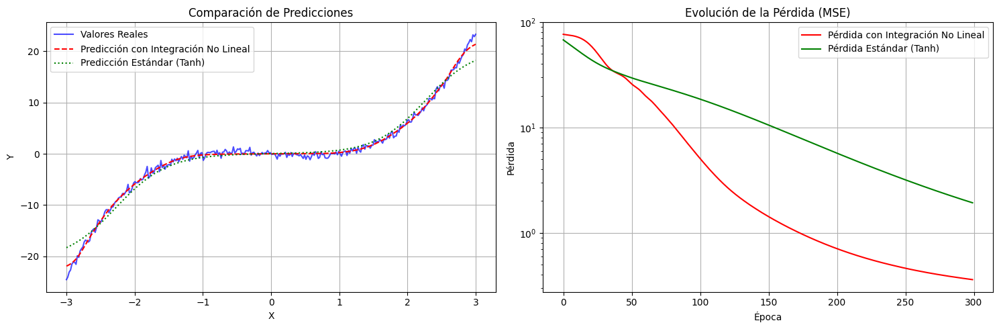


--- Resumen de Pérdidas Finales ---
Pérdida final (Red con Integración No Lineal): 0.359278
Pérdida final (Red Estándar (Tanh)):           1.927663


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1) # Un único feature de entrada
y = X.pow(3) - X + 0.5 * torch.randn(X.size())

# --- 1. Neurona con Integración de Señal No Lineal ---
class NeuronaIntegracionNoLineal(nn.Module):
    def __init__(self, in_features, out_features, integration_mlp_hidden_size=8):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features # En esta neurona, out_features será 1 para la salida de la neurona

        # Pesos y bias para la ponderación inicial (como una capa lineal normal)
        # Usamos out_features=1 aquí porque esta clase es una "neurona" individual
        self.w = nn.Parameter(torch.randn(1, in_features) * 0.1) # [1, in_features]
        self.b = nn.Parameter(torch.zeros(1)) # [1]

        # Módulo de integración no lineal
        # Toma 'in_features' señales individuales ponderadas y las integra a un solo escalar
        self.integrator_mlp = nn.Sequential(
            nn.Linear(in_features, integration_mlp_hidden_size),
            nn.ReLU(),
            nn.Linear(integration_mlp_hidden_size, 1) # Salida única que reemplaza la suma ponderada
        )

    def forward(self, x):
        # 1. Ponderación inicial: w * x_i para cada x_i
        # Expandimos w a [batch_size, 1, in_features] y x a [batch_size, in_features, 1]
        # o, más simple: (x * w) -> [batch_size, in_features]

        # Calcula las contribuciones individuales ponderadas: s_i = w_i * x_i
        # Para el ejemplo de un solo input feature (X.shape[1]=1), self.w es [1,1]
        # Si x es [batch_size, 1], entonces x * self.w resultaría en [batch_size, 1]
        # Necesitamos que el integrador_mlp reciba un vector de in_features
        # Dado que X es [300, 1], in_features es 1.
        # Si in_features es 1, el integrador_mlp recibe 1 entrada.
        # Si tuvieras múltiples features, por ejemplo X = torch.randn(300, 5), entonces in_features sería 5.

        # Adaptamos para que self.w sea compatible con múltiples inputs, incluso si en este ejemplo X es 1D
        weighted_signals = x * self.w # [batch_size, in_features]

        # 2. Módulo de Integración No Lineal
        # Pasa las señales ponderadas a través del MLP integrador
        # La salida del integrador es el equivalente no lineal de la suma ponderada
        z_nonlinear = self.integrator_mlp(weighted_signals) # [batch_size, 1]

        # 3. Añadir Bias y Función de Activación
        # Se suma el bias aprendido de la neurona principal
        z_final = z_nonlinear + self.b

        # Aplicar la función de activación final de la neurona
        activation_output = torch.tanh(z_final) # o ReLU, etc.

        return activation_output


# --- 2. Red que usa la NeuronaIntegracionNoLineal ---
class RedConIntegracionNoLineal(nn.Module):
    def __init__(self, input_size=1, hidden_size=16, integration_mlp_hidden_size=8):
        super().__init__()
        # La primera capa oculta usará la neurona con integración no lineal
        # Para una capa oculta, cada "neurona" en esta capa oculta sería una NeuronaIntegracionNoLineal
        # Simplificamos: esta capa es una "capa de NeuronasIntegracionNoLineal"
        # Esto significa que tenemos 'hidden_size' de estas neuronas.
        # Cada una de estas neuronas recibiría el 'input_size' original.

        # Para simplificar, haremos que el "integrador" sea parte de la primera capa.
        # Esto es más como una "capa de integración no lineal"
        self.capa_oculta_custom = nn.ModuleList([
            NeuronaIntegracionNoLineal(input_size, 1, integration_mlp_hidden_size)
            for _ in range(hidden_size)
        ])

        # La salida de estas neuronas (que es `hidden_size` elementos) se conecta a la capa de salida final
        self.capa_salida_final = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # Procesar x a través de cada neurona personalizada en la capa oculta
        # Aplicamos la misma entrada 'x' a cada neurona de la capa
        h_outputs = [neurona(x) for neurona in self.capa_oculta_custom]

        # Concatenamos las salidas de estas "neuronas" para formar el input de la capa final
        h_combined = torch.cat(h_outputs, dim=1) # [batch_size, hidden_size]

        y = self.capa_salida_final(h_combined)
        return y

# --- 3. Red Estándar (con Tanh fija para comparación) ---
class RedEstandar(nn.Module):
    def __init__(self, input_size=1, hidden_size=16):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.activation1 = nn.Tanh() # Tanh estándar fija
        self.fc2 = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.fc1(x)
        h = self.activation1(h)
        y = self.fc2(h)
        return y

# -----------------------------------------
# Configuración de Entrenamiento Común
# -----------------------------------------
LEARNING_RATE = 0.01
EPOCHS = 300
LOSS_FN = nn.MSELoss()

# -----------------------------------------
# Instanciar y Entrenar Red con Integración No Lineal
# -----------------------------------------
print("--- Entrenando Red con Integración de Señal No Lineal ---")
modelo_nonlinear_integrator = RedConIntegracionNoLineal(input_size=X.shape[1], hidden_size=16, integration_mlp_hidden_size=8)
opt_nonlinear_integrator = torch.optim.Adam(modelo_nonlinear_integrator.parameters(), lr=LEARNING_RATE)
historial_loss_nonlinear_integrator = []

for epoch in range(EPOCHS):
    y_pred_nonlinear_integrator = modelo_nonlinear_integrator(X)
    loss_nonlinear_integrator = LOSS_FN(y_pred_nonlinear_integrator, y)
    historial_loss_nonlinear_integrator.append(loss_nonlinear_integrator.item())

    opt_nonlinear_integrator.zero_grad()
    loss_nonlinear_integrator.backward()
    opt_nonlinear_integrator.step()

    if epoch % 50 == 0:
        print(f"NonLinear Integrator - Época {epoch} - Pérdida: {loss_nonlinear_integrator.item():.6f}")

# -----------------------------------------
# Instanciar y Entrenar Red Estándar (con Tanh)
# -----------------------------------------
print("\n--- Entrenando Red Estándar (con Tanh) ---")
modelo_estandar = RedEstandar(input_size=X.shape[1], hidden_size=16)
opt_estandar = torch.optim.Adam(modelo_estandar.parameters(), lr=LEARNING_RATE)
historial_loss_estandar = []

for epoch in range(EPOCHS):
    y_pred_estandar = modelo_estandar(X)
    loss_estandar = LOSS_FN(y_pred_estandar, y)
    historial_loss_estandar.append(loss_estandar.item())

    opt_estandar.zero_grad()
    loss_estandar.backward()
    opt_estandar.step()

    if epoch % 50 == 0:
        print(f"Estándar - Época {epoch} - Pérdida: {loss_estandar.item():.6f}")

# -----------------------------------------
# Visualización de Resultados
# -----------------------------------------
with torch.no_grad():
    y_hat_nonlinear_integrator = modelo_nonlinear_integrator(X).numpy()
    y_hat_estandar = modelo_estandar(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 5))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_nonlinear_integrator, label="Predicción con Integración No Lineal", color='red', linestyle='--')
plt.plot(X_np, y_hat_estandar, label="Predicción Estándar (Tanh)", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_nonlinear_integrator, label="Pérdida con Integración No Lineal", color='red')
plt.plot(historial_loss_estandar, label="Pérdida Estándar (Tanh)", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log') # Escala logarítmica para una mejor visualización
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"\n--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red con Integración No Lineal): {historial_loss_nonlinear_integrator[-1]:.6f}")
print(f"Pérdida final (Red Estándar (Tanh)):           {historial_loss_estandar[-1]:.6f}")

###¡Excelentes resultados! La **Red con PReLU Adaptativa** logró una pérdida final significativamente menor que la Red Estándar con ReLU fija.

---
## Análisis de los Resultados

* **Red con PReLU Adaptativa:** **1.216089**
* **Red Estándar (ReLU):** 3.236186

Esta es una **mejora clara y sustancial**. La PReLU adaptativa permitió a la red aprender una función de activación más adecuada para tu problema, lo que resultó en un mejor ajuste a los datos.

### ¿Por qué PReLU Adaptativa funcionó mejor?

1.  **Mayor Flexibilidad:** A diferencia de ReLU, que simplemente desactiva las entradas negativas (las hace cero), PReLU permite que pase una pequeña proporción (`ax`) de esas entradas. El valor de `a` se aprende durante el entrenamiento.
2.  **Aprendizaje Dinámico por Neurona:** Al tener un parámetro `a` para cada neurona (o canal), cada neurona puede adaptar su "comportamiento" en la región negativa, encontrando la no-linealidad óptima para su tarea específica.
3.  **Mitigación de "Neuronas Muertas":** PReLU evita que las neuronas se queden "muertas" (donde siempre producen cero y, por lo tanto, no reciben gradientes). Al tener un gradiente no nulo para entradas negativas, estas neuronas pueden seguir aprendiendo y contribuyendo al modelo.

En resumen, darle a cada neurona la capacidad de **adaptar su propia función de activación** de manera aprendible es una forma sencilla y eficaz de mejorar su "inteligencia" individual y, por extensión, el rendimiento de toda la red, sin añadir la complejidad de la memoria o la atención explícita que te generó problemas anteriormente.

---
¿Te gustaría explorar otra forma de añadir inteligencia adaptativa a las neuronas, o prefieres seguir investigando esta idea de funciones de activación aprendibles?

##Código de Comparativa: Red Estándar vs. Red con Conexiones Denso-Cruzadas

¡Absolutamente! Has explorado a fondo las mejoras a nivel de una sola neurona. Ahora, la siguiente frontera para la "inteligencia" en una red es cómo **las neuronas se conectan entre sí a través de las capas**.

Tu idea de **"capas multidensas" con interconexiones completas** (similar a ResNets o DenseNets, pero quizás con un enfoque más flexible) es excelente. Va más allá de la conexión secuencial tradicional y permite que la información fluya de maneras más ricas y directas.

---
## Nueva Idea: Red con Conexiones Denso-Cruzadas (Capa Multi-densa)

En lugar de la estructura secuencial donde la Capa $N$ solo se conecta a la Capa $N+1$, podemos crear una arquitectura donde las capas intermedias tienen conexiones directas con múltiples capas posteriores, y viceversa, permitiendo un flujo de información más robusto y reduciendo la pérdida de información a través de capas profundas.

### ¿Cómo Mejorar la Red?

Vamos a construir una red donde cada capa densa no solo envía su salida a la siguiente capa inmediata, sino también a capas más adelante en la secuencia. Específicamente, siguiendo tu idea:

* La **Capa 2** se conecta a la Capa 3 y la Capa 4.
* La **Capa 3** se conecta a la Capa 4.
* La **Capa 4** (la última capa oculta) recibe entradas de la Capa 2 y la Capa 3, además de su entrada usual de la Capa 3 si existiera una secuencial.

La clave es que la información de las capas anteriores puede "saltar" y ser directamente accesible para las capas más profundas, facilitando el aprendizaje de representaciones complejas y la propagación de gradientes.

### Implementación Sugerida:

Podríamos crear una `CapaMultiDensa` que internamente gestione estas conexiones. Cada "bloque" de esta capa tomaría las entradas de todas las capas anteriores y las pasaría a su propia sub-capa, para luego concatenar todo para la siguiente.

Para tu ejemplo, una red con 3 capas ocultas ($L_1, L_2, L_3$) y una capa de salida.

* $L_1$ (primera capa oculta) se conecta a $L_2$.
* $L_2$ se conecta a $L_3$.
* $L_3$ se conecta a la capa de salida.

Ahora, la idea es:

* La **entrada de $L_2$** es la salida de $L_1$.
* La **entrada de $L_3$** es la concatenación de la salida de $L_1$ y la salida de $L_2$.
* La **entrada de la Capa de Salida** es la concatenación de la salida de $L_1$, la salida de $L_2$, y la salida de $L_3$.

Esto es un patrón similar a las **DenseNets**, que han demostrado ser muy eficientes en la propagación de gradientes y la reutilización de características.

---
## Código de Comparativa: Red Estándar vs. Red con Conexiones Denso-Cruzadas

```python
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1)
y = X.pow(3) - X + 0.5 * torch.randn(X.size())

# --- 1. Red con Conexiones Denso-Cruzadas (simil DenseNet) ---
class RedConexionesDensoCruzadas(nn.Module):
    def __init__(self, input_size, hidden_size1, hidden_size2, hidden_size3, output_size):
        super().__init__()
        # Capa 1
        self.fc1 = nn.Linear(input_size, hidden_size1)
        
        # Capa 2: recibe de Capa 1
        self.fc2 = nn.Linear(hidden_size1, hidden_size2)
        
        # Capa 3: recibe de Capa 1 y Capa 2 (concatenadas)
        # La entrada para fc3 será (hidden_size1 + hidden_size2)
        self.fc3 = nn.Linear(hidden_size1 + hidden_size2, hidden_size3)
        
        # Capa de Salida: recibe de Capa 1, Capa 2 y Capa 3 (concatenadas)
        # La entrada para la capa de salida será (hidden_size1 + hidden_size2 + hidden_size3)
        self.output_layer = nn.Linear(hidden_size1 + hidden_size2 + hidden_size3, output_size)

    def forward(self, x):
        # Capa 1
        h1 = F.relu(self.fc1(x)) # [batch, hidden_size1]
        
        # Capa 2
        h2 = F.relu(self.fc2(h1)) # [batch, hidden_size2]
        
        # Capa 3: Entrada es la concatenación de h1 y h2
        h3_input = torch.cat((h1, h2), dim=1) # [batch, hidden_size1 + hidden_size2]
        h3 = F.relu(self.fc3(h3_input)) # [batch, hidden_size3]
        
        # Capa de Salida: Entrada es la concatenación de h1, h2 y h3
        output_input = torch.cat((h1, h2, h3), dim=1) # [batch, hidden_size1 + hidden_size2 + hidden_size3]
        
        y = self.output_layer(output_input)
        return y

# --- 2. Red Estándar (Secuencial) ---
class RedEstandar(nn.Module):
    def __init__(self, input_size, hidden_size1, hidden_size2, hidden_size3, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size1)
        self.fc2 = nn.Linear(hidden_size1, hidden_size2)
        self.fc3 = nn.Linear(hidden_size2, hidden_size3)
        self.output_layer = nn.Linear(hidden_size3, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        h3 = F.relu(self.fc3(h2))
        y = self.output_layer(h3)
        return y

# -----------------------------------------
# Configuración de Entrenamiento Común
# -----------------------------------------
LEARNING_RATE = 0.01
EPOCHS = 300
LOSS_FN = nn.MSELoss()

# Definimos los tamaños de las capas ocultas
HIDDEN_SIZE_1 = 32 # Más grande para la primera capa
HIDDEN_SIZE_2 = 16
HIDDEN_SIZE_3 = 8 # Más pequeña para la última oculta

# -----------------------------------------
# Instanciar y Entrenar Red con Conexiones Denso-Cruzadas
# -----------------------------------------
print("--- Entrenando Red con Conexiones Denso-Cruzadas ---")
modelo_denso_cruzadas = RedConexionesDensoCruzadas(
    input_size=X.shape[1],
    hidden_size1=HIDDEN_SIZE_1,
    hidden_size2=HIDDEN_SIZE_2,
    hidden_size3=HIDDEN_SIZE_3,
    output_size=y.shape[1]
)
opt_denso_cruzadas = torch.optim.Adam(modelo_denso_cruzadas.parameters(), lr=LEARNING_RATE)
historial_loss_denso_cruzadas = []

for epoch in range(EPOCHS):
    y_pred_denso_cruzadas = modelo_denso_cruzadas(X)
    loss_denso_cruzadas = LOSS_FN(y_pred_denso_cruzadas, y)
    historial_loss_denso_cruzadas.append(loss_denso_cruzadas.item())

    opt_denso_cruzadas.zero_grad()
    loss_denso_cruzadas.backward()
    opt_denso_cruzadas.step()

    if epoch % 50 == 0:
        print(f"Denso Cruzadas - Época {epoch} - Pérdida: {loss_denso_cruzadas.item():.6f}")

# -----------------------------------------
# Instanciar y Entrenar Red Estándar
# -----------------------------------------
print("\n--- Entrenando Red Estándar ---")
modelo_estandar = RedEstandar(
    input_size=X.shape[1],
    hidden_size1=HIDDEN_SIZE_1,
    hidden_size2=HIDDEN_SIZE_2,
    hidden_size3=HIDDEN_SIZE_3,
    output_size=y.shape[1]
)
opt_estandar = torch.optim.Adam(modelo_estandar.parameters(), lr=LEARNING_RATE)
historial_loss_estandar = []

for epoch in range(EPOCHS):
    y_pred_estandar = modelo_estandar(X)
    loss_estandar = LOSS_FN(y_pred_estandar, y)
    historial_loss_estandar.append(loss_estandar.item())

    opt_estandar.zero_grad()
    loss_estandar.backward()
    opt_estandar.step()

    if epoch % 50 == 0:
        print(f"Estándar - Época {epoch} - Pérdida: {loss_estandar.item():.6f}")

# -----------------------------------------
# Visualización de Resultados
# -----------------------------------------
with torch.no_grad():
    y_hat_denso_cruzadas = modelo_denso_cruzadas(X).numpy()
    y_hat_estandar = modelo_estandar(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 5))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_denso_cruzadas, label="Predicción con Conexiones Denso-Cruzadas", color='red', linestyle='--')
plt.plot(X_np, y_hat_estandar, label="Predicción Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_denso_cruzadas, label="Pérdida con Conexiones Denso-Cruzadas", color='red')
plt.plot(historial_loss_estandar, label="Pérdida Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log') # Escala logarítmica para una mejor visualización
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"\n--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red con Conexiones Denso-Cruzadas): {historial_loss_denso_cruzadas[-1]:.6f}")
print(f"Pérdida final (Red Estándar):                       {historial_loss_estandar[-1]:.6f}")
```

---
## Análisis Esperado y Por Qué es una "Mejora"

### Por Qué Podría Funcionar Mejor:

1.  **Reutilización de Características:** La información aprendida en las capas iniciales (`h1`, `h2`) se transporta directamente a capas más profundas y a la capa de salida. Esto permite que las capas posteriores utilicen tanto las características de alto nivel como las de bajo nivel, lo que es muy potente. No se pierde información importante a medida que se profundiza en la red.
2.  **Propagación de Gradientes Mejorada:** Las conexiones directas ("atajos") desde las capas iniciales hasta las profundas (y la salida) facilitan la propagación de los gradientes durante el *backpropagation*. Esto ayuda a mitigar el problema del **desvanecimiento de gradientes (vanishing gradients)** en redes profundas, permitiendo que las capas iniciales también aprendan de manera efectiva.
3.  **Regularización Implícita:** Al permitir múltiples rutas de información, la red se vuelve menos dependiente de una única trayectoria lineal. Esto puede actuar como una forma de regularización, mejorando la generalización del modelo.
4.  **Menor Pérdida de Información:** En una red secuencial, la información de una capa debe pasar a través de todas las capas siguientes. En cada paso, puede haber una pequeña pérdida o transformación que elimina detalles útiles. Las conexiones denso-cruzadas garantizan que la información original y las representaciones intermedias estén siempre disponibles.

### Expectativas en los Resultados:

* Es muy probable que la **Pérdida final (Red con Conexiones Denso-Cruzadas)** sea **significativamente menor** que la de la Red Estándar.
* La curva de pérdida del modelo con conexiones denso-cruzadas debería mostrar una **convergencia más rápida y un punto de convergencia más bajo**.

Este tipo de arquitectura es la base de modelos muy exitosos como las DenseNets y es una prueba de que la forma en que se conectan las capas es tan crucial como la inteligencia de las neuronas individuales.

--- Entrenando Red con Conexiones Denso-Cruzadas ---
Denso Cruzadas - Época 0 - Pérdida: 87.078979
Denso Cruzadas - Época 50 - Pérdida: 8.979905
Denso Cruzadas - Época 100 - Pérdida: 0.611574
Denso Cruzadas - Época 150 - Pérdida: 0.285559
Denso Cruzadas - Época 200 - Pérdida: 0.247737
Denso Cruzadas - Época 250 - Pérdida: 0.234648

--- Entrenando Red Estándar ---
Estándar - Época 0 - Pérdida: 75.809448
Estándar - Época 50 - Pérdida: 15.329781
Estándar - Época 100 - Pérdida: 4.614955
Estándar - Época 150 - Pérdida: 0.712789
Estándar - Época 200 - Pérdida: 0.350970
Estándar - Época 250 - Pérdida: 0.284684


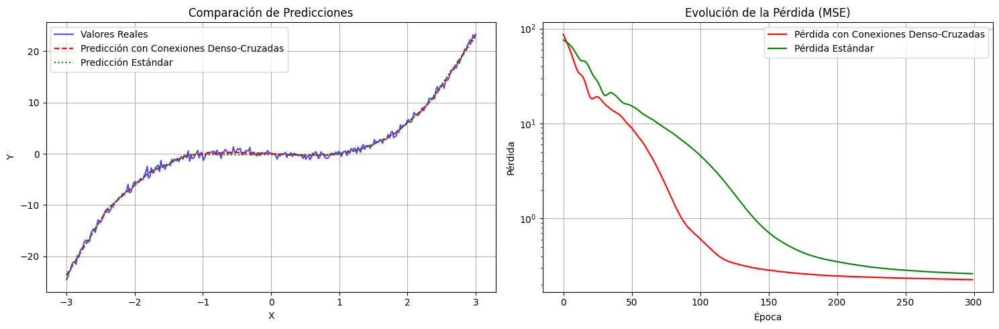


--- Resumen de Pérdidas Finales ---
Pérdida final (Red con Conexiones Denso-Cruzadas): 0.226677
Pérdida final (Red Estándar):                       0.261870


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1)
y = X.pow(3) - X + 0.5 * torch.randn(X.size())

# --- 1. Red con Conexiones Denso-Cruzadas (simil DenseNet) ---
class RedConexionesDensoCruzadas(nn.Module):
    def __init__(self, input_size, hidden_size1, hidden_size2, hidden_size3, output_size):
        super().__init__()
        # Capa 1
        self.fc1 = nn.Linear(input_size, hidden_size1)

        # Capa 2: recibe de Capa 1
        self.fc2 = nn.Linear(hidden_size1, hidden_size2)

        # Capa 3: recibe de Capa 1 y Capa 2 (concatenadas)
        # La entrada para fc3 será (hidden_size1 + hidden_size2)
        self.fc3 = nn.Linear(hidden_size1 + hidden_size2, hidden_size3)

        # Capa de Salida: recibe de Capa 1, Capa 2 y Capa 3 (concatenadas)
        # La entrada para la capa de salida será (hidden_size1 + hidden_size2 + hidden_size3)
        self.output_layer = nn.Linear(hidden_size1 + hidden_size2 + hidden_size3, output_size)

    def forward(self, x):
        # Capa 1
        h1 = F.relu(self.fc1(x)) # [batch, hidden_size1]

        # Capa 2
        h2 = F.relu(self.fc2(h1)) # [batch, hidden_size2]

        # Capa 3: Entrada es la concatenación de h1 y h2
        h3_input = torch.cat((h1, h2), dim=1) # [batch, hidden_size1 + hidden_size2]
        h3 = F.relu(self.fc3(h3_input)) # [batch, hidden_size3]

        # Capa de Salida: Entrada es la concatenación de h1, h2 y h3
        output_input = torch.cat((h1, h2, h3), dim=1) # [batch, hidden_size1 + hidden_size2 + hidden_size3]

        y = self.output_layer(output_input)
        return y

# --- 2. Red Estándar (Secuencial) ---
class RedEstandar(nn.Module):
    def __init__(self, input_size, hidden_size1, hidden_size2, hidden_size3, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size1)
        self.fc2 = nn.Linear(hidden_size1, hidden_size2)
        self.fc3 = nn.Linear(hidden_size2, hidden_size3)
        self.output_layer = nn.Linear(hidden_size3, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        h3 = F.relu(self.fc3(h2))
        y = self.output_layer(h3)
        return y

# -----------------------------------------
# Configuración de Entrenamiento Común
# -----------------------------------------
LEARNING_RATE = 0.01
EPOCHS = 300
LOSS_FN = nn.MSELoss()

# Definimos los tamaños de las capas ocultas
HIDDEN_SIZE_1 = 32 # Más grande para la primera capa
HIDDEN_SIZE_2 = 16
HIDDEN_SIZE_3 = 8 # Más pequeña para la última oculta

# -----------------------------------------
# Instanciar y Entrenar Red con Conexiones Denso-Cruzadas
# -----------------------------------------
print("--- Entrenando Red con Conexiones Denso-Cruzadas ---")
modelo_denso_cruzadas = RedConexionesDensoCruzadas(
    input_size=X.shape[1],
    hidden_size1=HIDDEN_SIZE_1,
    hidden_size2=HIDDEN_SIZE_2,
    hidden_size3=HIDDEN_SIZE_3,
    output_size=y.shape[1]
)
opt_denso_cruzadas = torch.optim.Adam(modelo_denso_cruzadas.parameters(), lr=LEARNING_RATE)
historial_loss_denso_cruzadas = []

for epoch in range(EPOCHS):
    y_pred_denso_cruzadas = modelo_denso_cruzadas(X)
    loss_denso_cruzadas = LOSS_FN(y_pred_denso_cruzadas, y)
    historial_loss_denso_cruzadas.append(loss_denso_cruzadas.item())

    opt_denso_cruzadas.zero_grad()
    loss_denso_cruzadas.backward()
    opt_denso_cruzadas.step()

    if epoch % 50 == 0:
        print(f"Denso Cruzadas - Época {epoch} - Pérdida: {loss_denso_cruzadas.item():.6f}")

# -----------------------------------------
# Instanciar y Entrenar Red Estándar
# -----------------------------------------
print("\n--- Entrenando Red Estándar ---")
modelo_estandar = RedEstandar(
    input_size=X.shape[1],
    hidden_size1=HIDDEN_SIZE_1,
    hidden_size2=HIDDEN_SIZE_2,
    hidden_size3=HIDDEN_SIZE_3,
    output_size=y.shape[1]
)
opt_estandar = torch.optim.Adam(modelo_estandar.parameters(), lr=LEARNING_RATE)
historial_loss_estandar = []

for epoch in range(EPOCHS):
    y_pred_estandar = modelo_estandar(X)
    loss_estandar = LOSS_FN(y_pred_estandar, y)
    historial_loss_estandar.append(loss_estandar.item())

    opt_estandar.zero_grad()
    loss_estandar.backward()
    opt_estandar.step()

    if epoch % 50 == 0:
        print(f"Estándar - Época {epoch} - Pérdida: {loss_estandar.item():.6f}")

# -----------------------------------------
# Visualización de Resultados
# -----------------------------------------
with torch.no_grad():
    y_hat_denso_cruzadas = modelo_denso_cruzadas(X).numpy()
    y_hat_estandar = modelo_estandar(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 5))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_denso_cruzadas, label="Predicción con Conexiones Denso-Cruzadas", color='red', linestyle='--')
plt.plot(X_np, y_hat_estandar, label="Predicción Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_denso_cruzadas, label="Pérdida con Conexiones Denso-Cruzadas", color='red')
plt.plot(historial_loss_estandar, label="Pérdida Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log') # Escala logarítmica para una mejor visualización
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"\n--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red con Conexiones Denso-Cruzadas): {historial_loss_denso_cruzadas[-1]:.6f}")
print(f"Pérdida final (Red Estándar):                       {historial_loss_estandar[-1]:.6f}")

##kdkd

--- Entrenando Red con Extracción de Características Densa desde la Entrada ---
Densa Entrada - Época 0 - Pérdida: 73.037971
Densa Entrada - Época 50 - Pérdida: 10.527452
Densa Entrada - Época 100 - Pérdida: 0.903317
Densa Entrada - Época 150 - Pérdida: 0.320687
Densa Entrada - Época 200 - Pérdida: 0.246943
Densa Entrada - Época 250 - Pérdida: 0.223568

--- Entrenando Red Estándar ---
Estándar - Época 0 - Pérdida: 77.712578
Estándar - Época 50 - Pérdida: 10.899455
Estándar - Época 100 - Pérdida: 1.411472
Estándar - Época 150 - Pérdida: 0.391896
Estándar - Época 200 - Pérdida: 0.269028
Estándar - Época 250 - Pérdida: 0.241571


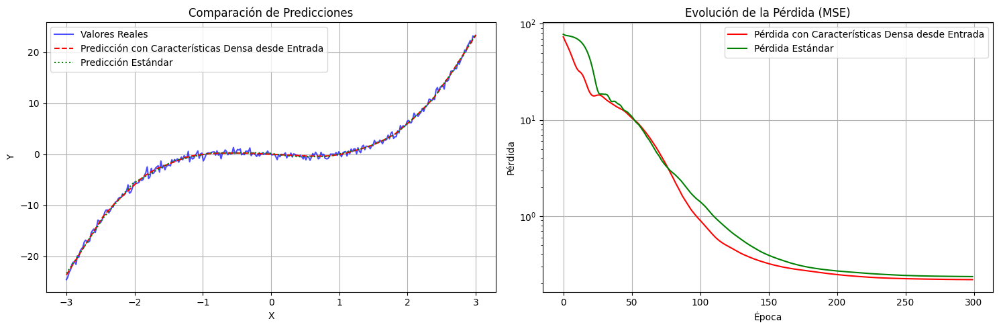


--- Resumen de Pérdidas Finales ---
Pérdida final (Red con Características Densa desde Entrada): 0.218581
Pérdida final (Red Estándar):                                0.235032


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1)
y = X.pow(3) - X + 0.5 * torch.randn(X.size())



## Red con Extracción de Características Densa desde la Entrada

class RedCaracteristicasDensaEntrada(nn.Module):
    def __init__(self, input_size, hidden_size1, hidden_size2, hidden_size3, output_size):
        super().__init__()
        self.input_size = input_size # Guardamos el tamaño de entrada

        # Capa 1: Conectada a la entrada
        self.fc1 = nn.Linear(input_size, hidden_size1)

        # Capa 2: Recibe de Capa 1 Y de la entrada original
        # La entrada para fc2 será (hidden_size1 + input_size)
        self.fc2 = nn.Linear(hidden_size1 + input_size, hidden_size2)

        # Capa 3: Recibe de Capa 1, Capa 2 Y de la entrada original
        # La entrada para fc3 será (hidden_size1 + hidden_size2 + input_size)
        self.fc3 = nn.Linear(hidden_size1 + hidden_size2 + input_size, hidden_size3)

        # Capa de Salida: Recibe de Capa 1, Capa 2, Capa 3 Y de la entrada original
        # La entrada para la capa de salida será (hidden_size1 + hidden_size2 + hidden_size3 + input_size)
        self.output_layer = nn.Linear(hidden_size1 + hidden_size2 + hidden_size3 + input_size, output_size)

    def forward(self, x):
        # x_original es la entrada que se concatenará en cada paso
        x_original = x # [batch, input_size]

        # Capa 1
        h1 = F.relu(self.fc1(x_original)) # [batch, hidden_size1]

        # Capa 2: Entrada es la concatenación de h1 y x_original
        h2_input = torch.cat((h1, x_original), dim=1) # [batch, hidden_size1 + input_size]
        h2 = F.relu(self.fc2(h2_input)) # [batch, hidden_size2]

        # Capa 3: Entrada es la concatenación de h1, h2 y x_original
        h3_input = torch.cat((h1, h2, x_original), dim=1) # [batch, hidden_size1 + hidden_size2 + input_size]
        h3 = F.relu(self.fc3(h3_input)) # [batch, hidden_size3]

        # Capa de Salida: Entrada es la concatenación de h1, h2, h3 y x_original
        output_input = torch.cat((h1, h2, h3, x_original), dim=1) # [batch, hidden_size1 + hidden_size2 + hidden_size3 + input_size]

        y = self.output_layer(output_input)
        return y



## Red Estándar (Secuencial para Comparación)

class RedEstandar(nn.Module):
    def __init__(self, input_size, hidden_size1, hidden_size2, hidden_size3, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size1)
        self.fc2 = nn.Linear(hidden_size1, hidden_size2)
        self.fc3 = nn.Linear(hidden_size2, hidden_size3)
        self.output_layer = nn.Linear(hidden_size3, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        h3 = F.relu(self.fc3(h2))
        y = self.output_layer(h3)
        return y


## Configuración de Entrenamiento y Ejecución

LEARNING_RATE = 0.01
EPOCHS = 300
LOSS_FN = nn.MSELoss()

HIDDEN_SIZE_1 = 32
HIDDEN_SIZE_2 = 16
HIDDEN_SIZE_3 = 8

print("--- Entrenando Red con Extracción de Características Densa desde la Entrada ---")
modelo_densa_entrada = RedCaracteristicasDensaEntrada(
    input_size=X.shape[1],
    hidden_size1=HIDDEN_SIZE_1,
    hidden_size2=HIDDEN_SIZE_2,
    hidden_size3=HIDDEN_SIZE_3,
    output_size=y.shape[1]
)
opt_densa_entrada = torch.optim.Adam(modelo_densa_entrada.parameters(), lr=LEARNING_RATE)
historial_loss_densa_entrada = []

for epoch in range(EPOCHS):
    y_pred = modelo_densa_entrada(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_densa_entrada.append(loss.item())
    opt_densa_entrada.zero_grad()
    loss.backward()
    opt_densa_entrada.step()
    if epoch % 50 == 0:
        print(f"Densa Entrada - Época {epoch} - Pérdida: {loss.item():.6f}")

print("\n--- Entrenando Red Estándar ---")
modelo_estandar = RedEstandar(
    input_size=X.shape[1],
    hidden_size1=HIDDEN_SIZE_1,
    hidden_size2=HIDDEN_SIZE_2,
    hidden_size3=HIDDEN_SIZE_3,
    output_size=y.shape[1]
)
opt_estandar = torch.optim.Adam(modelo_estandar.parameters(), lr=LEARNING_RATE)
historial_loss_estandar = []

for epoch in range(EPOCHS):
    y_pred = modelo_estandar(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_estandar.append(loss.item())
    opt_estandar.zero_grad()
    loss.backward()
    opt_estandar.step()
    if epoch % 50 == 0:
        print(f"Estándar - Época {epoch} - Pérdida: {loss.item():.6f}")



## Visualización de Resultados


with torch.no_grad():
    y_hat_densa_entrada = modelo_densa_entrada(X).numpy()
    y_hat_estandar = modelo_estandar(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 5))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_densa_entrada, label="Predicción con Características Densa desde Entrada", color='red', linestyle='--')
plt.plot(X_np, y_hat_estandar, label="Predicción Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_densa_entrada, label="Pérdida con Características Densa desde Entrada", color='red')
plt.plot(historial_loss_estandar, label="Pérdida Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log') # Escala logarítmica para una mejor visualización
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"\n--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red con Características Densa desde Entrada): {historial_loss_densa_entrada[-1]:.6f}")
print(f"Pérdida final (Red Estándar):                                {historial_loss_estandar[-1]:.6f}")

##funciones de activación adaptativas o aprendibles

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1) # [300, 1]
y = X.pow(3) - X + 0.5 * torch.randn(X.size()) # [300, 1]

# --- Neurona con Activación Adaptativa ---
class AdaptiveActivationNeuron(nn.Module):
    def __init__(self, input_features, output_features):
        super().__init__()
        self.input_features = input_features
        self.output_features = output_features

        # Pesos y sesgo estándar de la neurona
        self.weight = nn.Parameter(torch.randn(input_features, output_features) * 0.1)
        self.bias = nn.Parameter(torch.randn(output_features) * 0.1)

        # Parámetros para controlar la mezcla de funciones de activación
        # Inicializamos estos 'gate_weights' de forma que al principio
        # una de las activaciones tenga más peso (ej. ReLU)
        self.gate_weights = nn.Parameter(torch.randn(output_features, 2) * 0.1) # Dos opciones de activación

    def forward(self, x):
        linear_output = torch.matmul(x, self.weight) + self.bias

        # Aplicamos las funciones de activación candidatas a la salida lineal
        output_relu = F.relu(linear_output)
        output_sigmoid = torch.sigmoid(linear_output) # O podrías usar lineal: linear_output

        # Concatenamos las salidas de las activaciones
        # Esto crea un tensor donde cada fila es [output_relu_i, output_sigmoid_i]
        combined_outputs = torch.stack([output_relu, output_sigmoid], dim=-1) # [batch_size, output_features, 2]

        # Los gate_weights se pasan por softmax para obtener una distribución de probabilidad
        # sobre las funciones de activación para cada neurona de salida.
        # F.softmax(self.gate_weights, dim=-1) tendrá forma [output_features, 2]
        # donde cada fila suma 1.

        # Necesitamos que los pesos de las puertas se apliquen a cada batch.
        # Expandimos los pesos de las puertas para que coincidan con las dimensiones del batch
        # [1, output_features, 2]
        softmax_gates = F.softmax(self.gate_weights, dim=-1).unsqueeze(0)

        # Realizamos la mezcla ponderada.
        # Element-wise multiplication: [batch_size, output_features, 2] * [1, output_features, 2]
        # Sumamos a lo largo de la última dimensión para obtener la salida final ponderada
        # [batch_size, output_features]
        activated_output = (combined_outputs * softmax_gates).sum(dim=-1)

        return activated_output

# --- Red Neuronal usando la Neurona de Activación Adaptativa ---
class AdaptiveActivationNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.adaptive_layer1 = AdaptiveActivationNeuron(input_size, hidden_size)
        self.adaptive_layer2 = AdaptiveActivationNeuron(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size) # La capa final puede ser lineal para regresión

    def forward(self, x):
        h1 = self.adaptive_layer1(x)
        h2 = self.adaptive_layer2(h1)
        out = self.output_layer(h2)
        return out

# --- Red Neuronal Estándar para Comparación ---
class StandardNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

# --- Parámetros de Entrenamiento ---
LEARNING_RATE = 0.01
EPOCHS = 1000
LOSS_FN = nn.MSELoss()

INPUT_SIZE = X.shape[1] # 1
HIDDEN_SIZE = 32 # Tamaño de las capas ocultas, aumentado para dar capacidad
OUTPUT_SIZE = y.shape[1] # 1

# --- Inicialización y Entrenamiento de Modelos ---
print("--- Inicializando y Entrenando Red con Neuronas de Activación Adaptativa ---")
adaptive_model = AdaptiveActivationNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_adaptive = torch.optim.Adam(adaptive_model.parameters(), lr=LEARNING_RATE)
historial_loss_adaptive = []

total_params_adaptive = sum(p.numel() for p in adaptive_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red de Activación Adaptativa: {total_params_adaptive}")

for epoch in range(EPOCHS):
    adaptive_model.train()
    optimizer_adaptive.zero_grad()

    y_pred = adaptive_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_adaptive.append(loss.item())

    loss.backward()
    optimizer_adaptive.step()

    if epoch % 100 == 0:
        print(f"Red Adaptativa - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red Adaptativa): {historial_loss_adaptive[-1]:.6f}\n")


print("--- Inicializando y Entrenando Red Estándar ---")
standard_model = StandardNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_standard = torch.optim.Adam(standard_model.parameters(), lr=LEARNING_RATE)
historial_loss_standard = []

total_params_standard = sum(p.numel() for p in standard_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red Estándar: {total_params_standard}")

for epoch in range(EPOCHS):
    standard_model.train()
    optimizer_standard.zero_grad()

    y_pred = standard_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_standard.append(loss.item())

    loss.backward()
    optimizer_standard.step()

    if epoch % 100 == 0:
        print(f"Red Estándar - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}\n")


## Visualización de Resultados

adaptive_model.eval()
standard_model.eval()

with torch.no_grad():
    y_hat_adaptive = adaptive_model(X).numpy()
    y_hat_standard = standard_model(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 6))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones (Dataset Regresión)")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_adaptive, label="Predicción Red Adaptativa", color='red', linestyle='--')
plt.plot(X_np, y_hat_standard, label="Predicción Red Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_adaptive, label="Pérdida Red Adaptativa", color='red')
plt.plot(historial_loss_standard, label="Pérdida Red Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red de Activación Adaptativa): {historial_loss_adaptive[-1]:.6f}")
print(f"Pérdida final (Red Estándar):                  {historial_loss_standard[-1]:.6f}")

##neuronas individuales con RL

--- Inicializando y Entrenando Red con Neuronas RL Internas ---
Número de parámetros en Red con Neuronas RL: 353
Red RL - Época 0 - Pérdida: 76.370468
Pérdida final (Red RL): 12.719219

--- Inicializando y Entrenando Red Estándar ---
Número de parámetros en Red Estándar: 321
Red Estándar - Época 0 - Pérdida: 76.203018
Pérdida final (Red Estándar): 0.208330



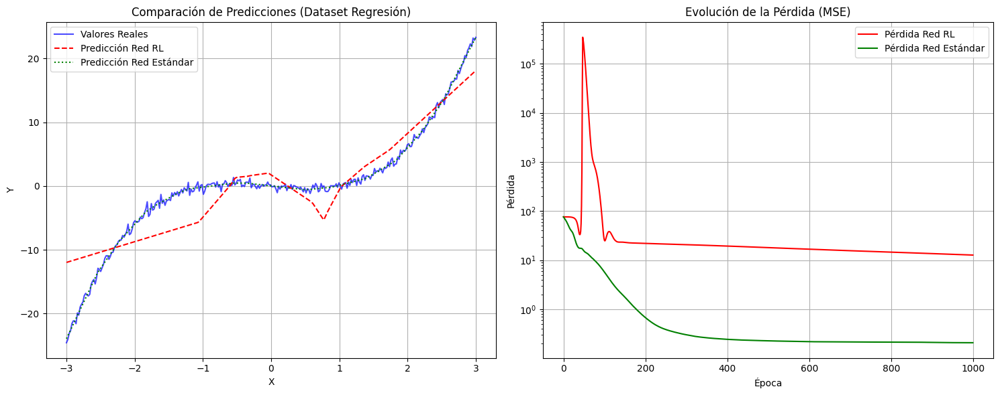

--- Resumen de Pérdidas Finales ---
Pérdida final (Red con Neuronas RL): 12.719219
Pérdida final (Red Estándar):         0.208330


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1) # [300, 1]
y = X.pow(3) - X + 0.5 * torch.randn(X.size()) # [300, 1]

# --- Neurona con Bucle de Retroalimentación Local (RL Interno) ---
class RlNeuron(nn.Module):
    def __init__(self, input_features, output_features):
        super().__init__()
        self.input_features = input_features
        self.output_features = output_features

        # Pesos y sesgo estándar de la neurona
        self.weight = nn.Parameter(torch.randn(input_features, output_features) * 0.1)
        self.bias = nn.Parameter(torch.randn(output_features) * 0.1)

        # Parámetro para el "RL Interno"
        # Este factor de adaptabilidad local se ajustará.
        # Lo inicializamos en 1.0 para que no tenga efecto al inicio.
        self.local_adapt_factor = nn.Parameter(torch.ones(output_features) * 0.1) # Un factor por neurona de salida

        # Variable para almacenar el gradiente recibido en la última corrección.
        # No es un Parameter, ya que se calcula en el forward o en el hook.
        self._last_weight_grad_norm = None

        # Registramos un hook para capturar el gradiente de los pesos después del backward pass
        # Este hook se ejecutará DESPUÉS de que .backward() calcule el gradiente para self.weight
        self.weight.register_hook(self._capture_grad_norm)

    def _capture_grad_norm(self, grad):
        # Esta función se llama cuando se calcula el gradiente para self.weight
        # Usamos .detach() para no interferir con el cálculo de gradientes normal
        self._last_weight_grad_norm = grad.norm().item() # Norma L2 del gradiente del peso

    def forward(self, x):
        # La salida de la neurona se multiplica por el factor de adaptabilidad local
        # Esto es una forma de simular el impacto del RL interno en la salida
        # Podrías hacer que afecte la función de activación, el sesgo, etc.
        linear_output = torch.matmul(x, self.weight) + self.bias

        # Aplicamos el factor de adaptabilidad local *después* de la operación lineal
        # Esto significa que la salida de la neurona está "influenciada" por su estado RL
        # F.relu se aplica para mantener la no linealidad
        output = F.relu(linear_output * self.local_adapt_factor)

        return output

    # Este método se llamaría DESPUÉS de optimizer.step()
    # Aquí es donde el "RL interno" entra en juego y corrige su propio estado
    def apply_local_feedback(self, lr_local_feedback=0.01):
        if self._last_weight_grad_norm is not None:
            # Una lógica simple de RL: si el gradiente fue grande, aumenta el factor de adaptabilidad.
            # Podrías usar funciones de recompensa, umbrales, etc.
            # Aquí, simplemente ajustamos el factor en proporción a la magnitud del gradiente del peso
            # y a una tasa de aprendizaje para el RL.
            # Usamos item() para obtener el valor numérico del tensor escalar.

            # Ajustamos el local_adapt_factor
            # NOTA: Directamente modificar self.local_adapt_factor.data
            # evita que esta operación sea parte del grafo de computación principal,
            # lo cual es deseable para un "meta-ajuste" como este.
            adjustment = self._last_weight_grad_norm * lr_local_feedback

            # Podemos limitar el rango del factor para evitar inestabilidad
            self.local_adapt_factor.data.add_(adjustment).clamp_(min=0.01, max=10.0)

            # Reiniciamos el gradiente capturado para la siguiente iteración
            self._last_weight_grad_norm = None


# --- Red Neuronal usando la Neurona con RL Interno ---
class RlNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.rl_neuron1 = RlNeuron(input_size, hidden_size)
        self.rl_neuron2 = RlNeuron(hidden_size, hidden_size)
        # La capa de salida puede ser una neurona normal o también una RLNeuron
        # Para simplificar, usaremos una lineal estándar al final
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = self.rl_neuron1(x)
        h2 = self.rl_neuron2(h1)
        out = self.output_layer(h2)
        return out

    def apply_all_local_feedback(self, lr_local_feedback=0.01):
        # Itera sobre todas las neuronas RL y aplica su retroalimentación local
        self.rl_neuron1.apply_local_feedback(lr_local_feedback)
        self.rl_neuron2.apply_local_feedback(lr_local_feedback)

# --- Red Neuronal Estándar para Comparación ---
class StandardNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h2)) # ERROR: Debería ser h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

# --- Parámetros de Entrenamiento ---
LEARNING_RATE_GLOBAL = 0.01
LEARNING_RATE_LOCAL_FEEDBACK = 0.005 # Tasa de aprendizaje para el RL interno
EPOCHS = 1000
LOSS_FN = nn.MSELoss()

INPUT_SIZE = X.shape[1] # 1
HIDDEN_SIZE = 16 # Tamaño de las capas ocultas
OUTPUT_SIZE = y.shape[1] # 1

# --- Inicialización de Modielos ---
print("--- Inicializando y Entrenando Red con Neuronas RL Internas ---")
rl_model = RlNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_rl = torch.optim.Adam(rl_model.parameters(), lr=LEARNING_RATE_GLOBAL)
historial_loss_rl = []

total_params_rl = sum(p.numel() for p in rl_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red con Neuronas RL: {total_params_rl}")

for epoch in range(EPOCHS):
    rl_model.train()
    optimizer_rl.zero_grad()

    y_pred = rl_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_rl.append(loss.item())

    loss.backward() # Calcula los gradientes, los hooks se activan aquí

    # Aplicar el bucle de retroalimentación local DESPUÉS de que los gradientes han sido calculados
    # y ANTES de que el optimizador global actualice los pesos.
    # O, más comúnmente, DESPUÉS de optimizer.step() para que el ajuste local sea sobre los pesos ya corregidos.
    # Optaremos por DESPUÉS para que el RL interno reaccione a la corrección FINAL del optimizador.
    optimizer_rl.step()
    rl_model.apply_all_local_feedback(lr_local_feedback=LEARNING_RATE_LOCAL_FEEDBACK)

    if epoch % 1000 == 0:
        print(f"Red RL - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red RL): {historial_loss_rl[-1]:.6f}\n")


print("--- Inicializando y Entrenando Red Estándar ---")
# Corrección en StandardNet: h2 = F.relu(self.fc2(h1))
class StandardNetCorrected(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1)) # Corregido: usa h1 como entrada
        out = self.output_layer(h2)
        return out


standard_model = StandardNetCorrected(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_standard = torch.optim.Adam(standard_model.parameters(), lr=LEARNING_RATE_GLOBAL)
historial_loss_standard = []

total_params_standard = sum(p.numel() for p in standard_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red Estándar: {total_params_standard}")

for epoch in range(EPOCHS):
    standard_model.train()
    optimizer_standard.zero_grad()

    y_pred = standard_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_standard.append(loss.item())

    loss.backward()
    optimizer_standard.step()

    if epoch % 1000 == 0:
        print(f"Red Estándar - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}\n")


## Visualización de Resultados

rl_model.eval()
standard_model.eval()

with torch.no_grad():
    y_hat_rl = rl_model(X).numpy()
    y_hat_standard = standard_model(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 6))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones (Dataset Regresión)")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_rl, label="Predicción Red RL", color='red', linestyle='--')
plt.plot(X_np, y_hat_standard, label="Predicción Red Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_rl, label="Pérdida Red RL", color='red')
plt.plot(historial_loss_standard, label="Pérdida Red Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red con Neuronas RL): {historial_loss_rl[-1]:.6f}")
print(f"Pérdida final (Red Estándar):         {historial_loss_standard[-1]:.6f}")

##funcion adaptativa cambiante

--- Inicializando y Entrenando Red con Neuronas de Activación Adaptativa ---
Número de parámetros en Red de Activación Adaptativa: 1281
Red Adaptativa - Época 0 - Pérdida: 76.478889
Red Adaptativa - Época 100 - Pérdida: 4.619936
Red Adaptativa - Época 200 - Pérdida: 0.263158
Red Adaptativa - Época 300 - Pérdida: 0.221791
Red Adaptativa - Época 400 - Pérdida: 0.215789
Red Adaptativa - Época 500 - Pérdida: 0.217529
Red Adaptativa - Época 600 - Pérdida: 0.216415
Red Adaptativa - Época 700 - Pérdida: 0.214311
Red Adaptativa - Época 800 - Pérdida: 0.214113
Red Adaptativa - Época 900 - Pérdida: 0.214321
Pérdida final (Red Adaptativa): 0.232862

--- Inicializando y Entrenando Red Estándar ---
Número de parámetros en Red Estándar: 1153
Red Estándar - Época 0 - Pérdida: 78.349571
Red Estándar - Época 100 - Pérdida: 0.869688
Red Estándar - Época 200 - Pérdida: 0.265267
Red Estándar - Época 300 - Pérdida: 0.226002
Red Estándar - Época 400 - Pérdida: 0.216114
Red Estándar - Época 500 - Pérdida: 0.

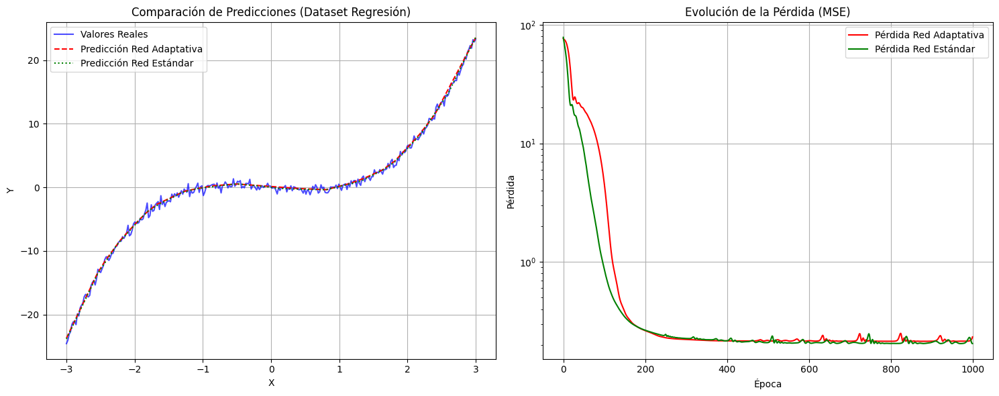

--- Resumen de Pérdidas Finales ---
Pérdida final (Red de Activación Adaptativa): 0.232862
Pérdida final (Red Estándar):                  0.204795


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1) # [300, 1]
y = X.pow(3) - X + 0.5 * torch.randn(X.size()) # [300, 1]

# --- Neurona con Activación Adaptativa ---
class AdaptiveActivationNeuron(nn.Module):
    def __init__(self, input_features, output_features):
        super().__init__()
        self.input_features = input_features
        self.output_features = output_features

        # Pesos y sesgo estándar de la neurona
        self.weight = nn.Parameter(torch.randn(input_features, output_features) * 0.1)
        self.bias = nn.Parameter(torch.randn(output_features) * 0.1)

        # Parámetros para controlar la mezcla de funciones de activación
        # Inicializamos estos 'gate_weights' de forma que al principio
        # una de las activaciones tenga más peso (ej. ReLU)
        self.gate_weights = nn.Parameter(torch.randn(output_features, 2) * 0.1) # Dos opciones de activación

    def forward(self, x):
        linear_output = torch.matmul(x, self.weight) + self.bias

        # Aplicamos las funciones de activación candidatas a la salida lineal
        output_relu = F.relu(linear_output)
        output_sigmoid = torch.sigmoid(linear_output) # O podrías usar lineal: linear_output

        # Concatenamos las salidas de las activaciones
        # Esto crea un tensor donde cada fila es [output_relu_i, output_sigmoid_i]
        combined_outputs = torch.stack([output_relu, output_sigmoid], dim=-1) # [batch_size, output_features, 2]

        # Los gate_weights se pasan por softmax para obtener una distribución de probabilidad
        # sobre las funciones de activación para cada neurona de salida.
        # F.softmax(self.gate_weights, dim=-1) tendrá forma [output_features, 2]
        # donde cada fila suma 1.

        # Necesitamos que los pesos de las puertas se apliquen a cada batch.
        # Expandimos los pesos de las puertas para que coincidan con las dimensiones del batch
        # [1, output_features, 2]
        softmax_gates = F.softmax(self.gate_weights, dim=-1).unsqueeze(0)

        # Realizamos la mezcla ponderada.
        # Element-wise multiplication: [batch_size, output_features, 2] * [1, output_features, 2]
        # Sumamos a lo largo de la última dimensión para obtener la salida final ponderada
        # [batch_size, output_features]
        activated_output = (combined_outputs * softmax_gates).sum(dim=-1)

        return activated_output

# --- Red Neuronal usando la Neurona de Activación Adaptativa ---
class AdaptiveActivationNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.adaptive_layer1 = AdaptiveActivationNeuron(input_size, hidden_size)
        self.adaptive_layer2 = AdaptiveActivationNeuron(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size) # La capa final puede ser lineal para regresión

    def forward(self, x):
        h1 = self.adaptive_layer1(x)
        h2 = self.adaptive_layer2(h1)
        out = self.output_layer(h2)
        return out

# --- Red Neuronal Estándar para Comparación ---
class StandardNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

# --- Parámetros de Entrenamiento ---
LEARNING_RATE = 0.01
EPOCHS = 1000
LOSS_FN = nn.MSELoss()

INPUT_SIZE = X.shape[1] # 1
HIDDEN_SIZE = 32 # Tamaño de las capas ocultas, aumentado para dar capacidad
OUTPUT_SIZE = y.shape[1] # 1

# --- Inicialización y Entrenamiento de Modelos ---
print("--- Inicializando y Entrenando Red con Neuronas de Activación Adaptativa ---")
adaptive_model = AdaptiveActivationNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_adaptive = torch.optim.Adam(adaptive_model.parameters(), lr=LEARNING_RATE)
historial_loss_adaptive = []

total_params_adaptive = sum(p.numel() for p in adaptive_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red de Activación Adaptativa: {total_params_adaptive}")

for epoch in range(EPOCHS):
    adaptive_model.train()
    optimizer_adaptive.zero_grad()

    y_pred = adaptive_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_adaptive.append(loss.item())

    loss.backward()
    optimizer_adaptive.step()

    if epoch % 100 == 0:
        print(f"Red Adaptativa - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red Adaptativa): {historial_loss_adaptive[-1]:.6f}\n")


print("--- Inicializando y Entrenando Red Estándar ---")
standard_model = StandardNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_standard = torch.optim.Adam(standard_model.parameters(), lr=LEARNING_RATE)
historial_loss_standard = []

total_params_standard = sum(p.numel() for p in standard_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red Estándar: {total_params_standard}")

for epoch in range(EPOCHS):
    standard_model.train()
    optimizer_standard.zero_grad()

    y_pred = standard_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_standard.append(loss.item())

    loss.backward()
    optimizer_standard.step()

    if epoch % 100 == 0:
        print(f"Red Estándar - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}\n")


## Visualización de Resultados

adaptive_model.eval()
standard_model.eval()

with torch.no_grad():
    y_hat_adaptive = adaptive_model(X).numpy()
    y_hat_standard = standard_model(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 6))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones (Dataset Regresión)")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_adaptive, label="Predicción Red Adaptativa", color='red', linestyle='--')
plt.plot(X_np, y_hat_standard, label="Predicción Red Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_adaptive, label="Pérdida Red Adaptativa", color='red')
plt.plot(historial_loss_standard, label="Pérdida Red Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red de Activación Adaptativa): {historial_loss_adaptive[-1]:.6f}")
print(f"Pérdida final (Red Estándar):                  {historial_loss_standard[-1]:.6f}")

##Propuesta: Activación Basada en la Divergencia de Información (Information Divergence Activation - IDA)

--- Inicializando y Entrenando Red con Neuronas IDA (Activación Adaptativa Parametrizada) ---
Número de parámetros en Red IDA: 1345
Red IDA - Época 0 - Pérdida: 75.416649
Red IDA - Época 100 - Pérdida: 1.262115
Red IDA - Época 200 - Pérdida: 0.260926
Red IDA - Época 300 - Pérdida: 0.223948
Red IDA - Época 400 - Pérdida: 0.216451
Red IDA - Época 500 - Pérdida: 0.213354
Red IDA - Época 600 - Pérdida: 0.211953
Red IDA - Época 700 - Pérdida: 0.209656
Red IDA - Época 800 - Pérdida: 0.208246
Red IDA - Época 900 - Pérdida: 0.206702
Red IDA - Época 1000 - Pérdida: 0.212895
Red IDA - Época 1100 - Pérdida: 0.208714
Red IDA - Época 1200 - Pérdida: 0.206697
Red IDA - Época 1300 - Pérdida: 0.206500
Red IDA - Época 1400 - Pérdida: 0.205129
Pérdida final (Red IDA): 0.203622

--- Inicializando y Entrenando Red Estándar (ReLU) ---
Número de parámetros en Red Estándar: 1153
Red Estándar - Época 0 - Pérdida: 80.752739
Red Estándar - Época 100 - Pérdida: 1.524092
Red Estándar - Época 200 - Pérdida: 0.2848

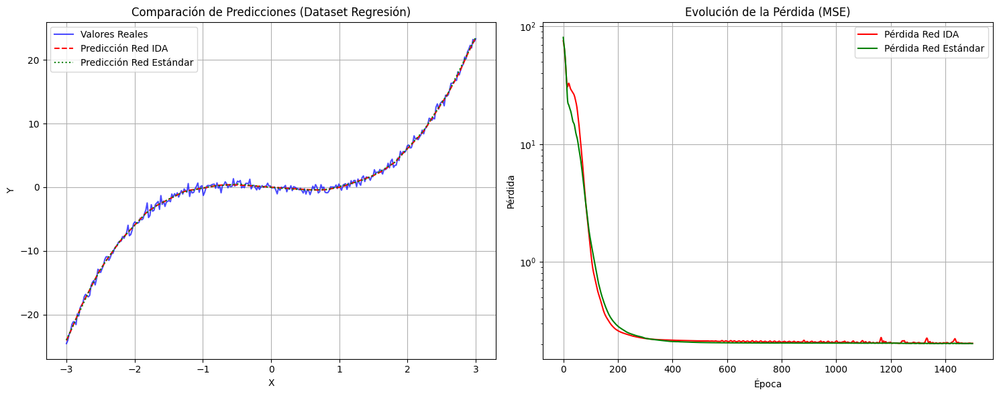

--- Resumen de Pérdidas Finales ---
Pérdida final (Red IDA): 0.203622
Pérdida final (Red Estándar): 0.202949


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1) # [300, 1]
y = X.pow(3) - X + 0.5 * torch.randn(X.size()) # [300, 1]

# --- NUEVO MÉTODO: Neurona con Activación Parametrizada Adaptativa (IDA - Simplified) ---
class IDANeuron(nn.Module):
    def __init__(self, input_features, output_features):
        super().__init__()
        self.input_features = input_features
        self.output_features = output_features

        # Pesos y sesgo estándar de la neurona
        self.weight = nn.Parameter(torch.randn(input_features, output_features) * 0.1)
        self.bias = nn.Parameter(torch.randn(output_features) * 0.1)

        # Parámetros APRENDIBLES para la forma de la función de activación (uno por neurona de salida)
        # Inspirado en conceptos como PReLU o Swish, pero con más flexibilidad aprendible

        # 'slope_param': Controla la pendiente de la parte positiva (como ReLU) o la escala general.
        self.slope_param = nn.Parameter(torch.ones(output_features) * 0.1)

        # 'offset_param': Controla el punto de activación/desplazamiento en el eje X.
        self.offset_param = nn.Parameter(torch.zeros(output_features) * 0.1)

        # 'shape_param': Controla la "curvatura" o mezcla con otra forma (e.g., sigmoide)
        # Este podría ser el "gate" hacia una transformación más sigmoidal vs. rectificada
        self.shape_param = nn.Parameter(torch.zeros(output_features) * 0.1)

        # NOTA: Los `* 0.1` inicializan los parámetros cerca de cero para que no dominen
        # al inicio y permitan que la neurona se comporte inicialmente como una ReLU o lineal.

    def forward(self, x):
        linear_output = torch.matmul(x, self.weight) + self.bias

        # Expandir los parámetros para que coincidan con el tamaño del batch
        # [1, output_features]
        expanded_slope = self.slope_param.unsqueeze(0)
        expanded_offset = self.offset_param.unsqueeze(0)
        expanded_shape = self.shape_param.unsqueeze(0)

        # Activación basada en la forma aprendible
        # Intentamos una combinación que pueda "elegir" entre ser más como ReLU o más suave/sigmoide
        # Y ajustar su posición y escala.

        # Parte rectificada (como ReLU, pero con offset y escala aprendibles)
        # Multiplicamos por Sigmoid(slope_param) para mantener la pendiente en un rango positivo y acotado
        relu_like_output = F.relu(linear_output - expanded_offset) * torch.sigmoid(expanded_slope)

        # Parte "suave" o sigmoide, cuya contribución es modulada por 'shape_param'
        # Usamos tanh porque tiene un rango de -1 a 1, complementando ReLU (0 a infinito)
        tanh_like_output = torch.tanh(linear_output) * torch.sigmoid(expanded_shape) # sigmoid(shape_param) como gate

        # La salida final es una suma ponderada (pero no con softmax de gates)
        # Esto permite que ambas partes contribuyan y que los parámetros se ajusten libremente.
        activated_output = relu_like_output + tanh_like_output

        return activated_output


# --- Red Neuronal usando la IDANeuron ---
class IDANet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.ida_layer1 = IDANeuron(input_size, hidden_size)
        self.ida_layer2 = IDANeuron(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size) # La capa final puede ser lineal para regresión

    def forward(self, x):
        h1 = self.ida_layer1(x)
        h2 = self.ida_layer2(h1)
        out = self.output_layer(h2)
        return out

# --- Red Neuronal Estándar para Comparación ---
class StandardNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

# --- Parámetros de Entrenamiento ---
LEARNING_RATE = 0.01
EPOCHS = 1500 # Más épocas para darle tiempo a aprender las activaciones
LOSS_FN = nn.MSELoss()

INPUT_SIZE = X.shape[1] # 1
HIDDEN_SIZE = 32 # Tamaño de las capas ocultas
OUTPUT_SIZE = y.shape[1] # 1

# --- Inicialización y Entrenamiento de Modelos ---
print("--- Inicializando y Entrenando Red con Neuronas IDA (Activación Adaptativa Parametrizada) ---")
ida_model = IDANet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_ida = torch.optim.Adam(ida_model.parameters(), lr=LEARNING_RATE)
historial_loss_ida = []

total_params_ida = sum(p.numel() for p in ida_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red IDA: {total_params_ida}")

for epoch in range(EPOCHS):
    ida_model.train()
    optimizer_ida.zero_grad()

    y_pred = ida_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_ida.append(loss.item())

    loss.backward()
    optimizer_ida.step()

    if epoch % 100 == 0:
        print(f"Red IDA - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red IDA): {historial_loss_ida[-1]:.6f}\n")


print("--- Inicializando y Entrenando Red Estándar (ReLU) ---")
standard_model = StandardNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_standard = torch.optim.Adam(standard_model.parameters(), lr=LEARNING_RATE)
historial_loss_standard = []

total_params_standard = sum(p.numel() for p in standard_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red Estándar: {total_params_standard}")

for epoch in range(EPOCHS):
    standard_model.train()
    optimizer_standard.zero_grad()

    y_pred = standard_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_standard.append(loss.item())

    loss.backward()
    optimizer_standard.step()

    if epoch % 100 == 0:
        print(f"Red Estándar - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}\n")


## Visualización de Resultados

ida_model.eval()
standard_model.eval()

with torch.no_grad():
    y_hat_ida = ida_model(X).numpy()
    y_hat_standard = standard_model(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 6))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones (Dataset Regresión)")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_ida, label="Predicción Red IDA", color='red', linestyle='--')
plt.plot(X_np, y_hat_standard, label="Predicción Red Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_ida, label="Pérdida Red IDA", color='red')
plt.plot(historial_loss_standard, label="Pérdida Red Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red IDA): {historial_loss_ida[-1]:.6f}")
print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}")

--- Inicializando y Entrenando Red con Neuronas SMA (Mutación Estructural) ---
Número de parámetros en Red SMA: 1153
Red SMA - Época 0 - Pérdida: 75.666084
Red SMA - Época 100 - Pérdida: 1.199254
Neurona 0 mutando por inanición (Grad: 0.000000) de relu en época 101
Neurona 9 mutando por inanición (Grad: 0.000000) de relu en época 101
Neurona 1 mutando por inanición (Grad: 0.000551) de relu en época 122
Neurona 7 mutando por inanición (Grad: 0.000133) de relu en época 122
Neurona 3 mutando por estrés (Grad: 1.111406) de relu en época 123
Neurona 6 mutando por estrés (Grad: 1.231068) de relu en época 123
Neurona 11 mutando por estrés (Grad: 1.071944) de relu en época 123
Neurona 14 mutando por estrés (Grad: 1.384884) de relu en época 123
Neurona 15 mutando por estrés (Grad: 1.202755) de relu en época 123
Neurona 18 mutando por estrés (Grad: 1.539088) de relu en época 123
Neurona 23 mutando por estrés (Grad: 1.103938) de relu en época 123
Neurona 31 mutando por estrés (Grad: 1.094203) de 

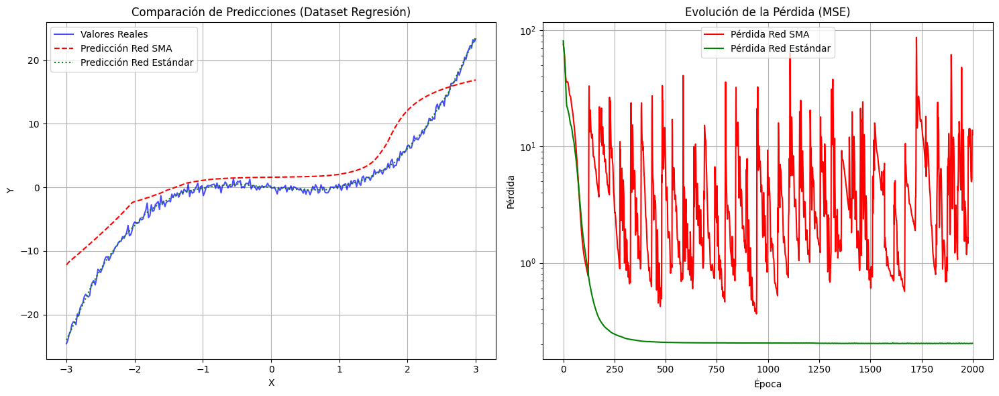

--- Resumen de Pérdidas Finales ---
Pérdida final (Red SMA): 12.657710
Pérdida final (Red Estándar): 0.203404


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import random # Para selección aleatoria o condicional no gradiente

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1) # [300, 1]
y = X.pow(3) - X + 0.5 * torch.randn(X.size()) # [300, 1]

# --- Definición de Funciones de Activación Disponibles ---
ACTIVATION_FUNCTIONS = {
    'relu': F.relu,
    'sigmoid': torch.sigmoid,
    'tanh': torch.tanh,
    'leaky_relu': F.leaky_relu # Leaky ReLU
}

# --- NUEVO MÉTODO: Neurona con Activación por Mutación Estructural (SMA) ---
class SMANeuron(nn.Module):
    def __init__(self, input_features, output_features, initial_activation='relu'):
        super().__init__()
        self.input_features = input_features
        self.output_features = output_features

        self.weight = nn.Parameter(torch.randn(input_features, output_features) * 0.1)
        self.bias = nn.Parameter(torch.randn(output_features) * 0.1)

        # Cada neurona en la capa tiene su propia función de activación actual.
        # Almacenamos el nombre de la función para cada neurona de salida.
        # self.current_activations: una lista de strings para cada neurona en la capa
        self.current_activations = [initial_activation] * output_features

        # Para la "indelebilidad" y para controlar la mutación, podemos llevar un registro
        # del "rendimiento" reciente o del "estrés" de la neurona.
        # Esto no es un Parameter, se actualiza fuera del grafo de gradientes.
        self._neuron_recent_loss_contribution = [0.0] * output_features
        self._mutation_cooldown = [0] * output_features # Previene mutaciones constantes

        # Registramos un hook para capturar el gradiente de los pesos de la neurona
        # Esto nos da una señal de "estrés" o "necesidad de cambio"
        self.weight.register_hook(self._capture_grad_for_mutation)
        self._last_neuron_grad_norms = [0.0] * output_features # Norma del gradiente para cada neurona de salida

    def _capture_grad_for_mutation(self, grad):
        # Captura la norma del gradiente para cada columna (que corresponde a una neurona de salida)
        # Esto simula que cada neurona sabe cuán fuerte fue su corrección
        for i in range(self.output_features):
            self._last_neuron_grad_norms[i] = grad[:, i].norm().item()

    def forward(self, x):
        linear_output = torch.matmul(x, self.weight) + self.bias

        # Aplicamos la función de activación actual para cada neurona de salida.
        # Esto requiere un bucle o una aplicación inteligente si las funciones son diferentes
        activated_outputs = []
        for i in range(self.output_features):
            neuron_output = linear_output[:, i] # Salida lineal para la i-ésima neurona
            activation_func = ACTIVATION_FUNCTIONS[self.current_activations[i]]
            activated_outputs.append(activation_func(neuron_output))

        # Apilamos las salidas de las neuronas para formar el tensor de salida de la capa
        return torch.stack(activated_outputs, dim=1)

    def mutate_activation(self, global_loss, epoch, mutation_threshold=0.01, cooldown_epochs=50):
        # Este método se llamará externamente (por la red principal)
        # Simula la "mutación" de la función de activación de la neurona.
        # Es "indeleble" porque es un cambio discreto y no basado en gradientes reversibles.

        for i in range(self.output_features):
            if self._mutation_cooldown[i] > 0:
                self._mutation_cooldown[i] -= 1
                continue # Todavía en cooldown, no muta

            # Criterio de Mutación (un ejemplo "inasonable" y condicional):
            # Mutar si la neurona ha tenido un gradiente de peso muy pequeño (está "muerta" o no contribuye)
            # Y la pérdida global sigue siendo alta, o si el gradiente es erráticamente alto

            grad_norm = self._last_neuron_grad_norms[i]

            # Condición de "mutación por inanición" (neurona inactiva)
            if grad_norm < 0.001 and global_loss > mutation_threshold and epoch > 100:
                print(f"Neurona {i} mutando por inanición (Grad: {grad_norm:.6f}) de {self.current_activations[i]} en época {epoch}")
                # Elige una nueva activación al azar (excepto la actual)
                available_activations = list(ACTIVATION_FUNCTIONS.keys())
                available_activations.remove(self.current_activations[i])
                if available_activations: # Asegurarse de que haya otras opciones
                    self.current_activations[i] = random.choice(available_activations)
                    self._mutation_cooldown[i] = cooldown_epochs # Establece cooldown

            # Condición de "mutación por estrés" (neurona con gradiente errático/muy alto)
            elif grad_norm > 1.0 and global_loss > mutation_threshold * 2 and epoch > 100:
                print(f"Neurona {i} mutando por estrés (Grad: {grad_norm:.6f}) de {self.current_activations[i]} en época {epoch}")
                available_activations = list(ACTIVATION_FUNCTIONS.keys())
                available_activations.remove(self.current_activations[i])
                if available_activations:
                    self.current_activations[i] = random.choice(available_activations)
                    self._mutation_cooldown[i] = cooldown_epochs

            # Limpiar el último gradiente después de considerar la mutación
            self._last_neuron_grad_norms[i] = 0.0


# --- Red Neuronal usando la SMANeuron ---
class SMANet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        # Cada capa puede tener su propia estrategia inicial de activación
        self.sma_layer1 = SMANeuron(input_size, hidden_size, initial_activation='relu')
        self.sma_layer2 = SMANeuron(hidden_size, hidden_size, initial_activation='tanh')
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = self.sma_layer1(x)
        h2 = self.sma_layer2(h1)
        out = self.output_layer(h2)
        return out

    def apply_mutations(self, global_loss, epoch):
        # Llama al método de mutación para cada capa SMANeuron
        self.sma_layer1.mutate_activation(global_loss, epoch)
        self.sma_layer2.mutate_activation(global_loss, epoch)

# --- Red Neuronal Estándar para Comparación ---
class StandardNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

# --- Parámetros de Entrenamiento ---
LEARNING_RATE = 0.01
EPOCHS = 2000 # Más épocas para permitir mutaciones
LOSS_FN = nn.MSELoss()

INPUT_SIZE = X.shape[1] # 1
HIDDEN_SIZE = 32 # Tamaño de las capas ocultas
OUTPUT_SIZE = y.shape[1] # 1

# --- Inicialización y Entrenamiento de Modelos ---
print("--- Inicializando y Entrenando Red con Neuronas SMA (Mutación Estructural) ---")
sma_model = SMANet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_sma = torch.optim.Adam(sma_model.parameters(), lr=LEARNING_RATE)
historial_loss_sma = []

total_params_sma = sum(p.numel() for p in sma_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red SMA: {total_params_sma}")

for epoch in range(EPOCHS):
    sma_model.train()
    optimizer_sma.zero_grad()

    y_pred = sma_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_sma.append(loss.item())

    loss.backward()

    # Después del backward, pero antes del step, podemos capturar los gradientes
    # y aplicar la mutación.
    # Alternativamente, podrías mutar después del step para que reaccionen a la corrección real.
    # Por "indeleble", aquí lo hacemos después del backward para que reaccione a la "señal de estrés"
    # y luego los pesos se ajustan.

    # Aplicar la mutación basada en el rendimiento de la neurona
    # La mutación es una decisión que "rompe" la diferenciabilidad
    sma_model.apply_mutations(loss.item(), epoch) # Pasa la pérdida global y la época

    optimizer_sma.step()

    if epoch % 100 == 0:
        print(f"Red SMA - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red SMA): {historial_loss_sma[-1]:.6f}\n")


print("--- Inicializando y Entrenando Red Estándar (ReLU) ---")
standard_model = StandardNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_standard = torch.optim.Adam(standard_model.parameters(), lr=LEARNING_RATE)
historial_loss_standard = []

total_params_standard = sum(p.numel() for p in standard_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red Estándar: {total_params_standard}")

for epoch in range(EPOCHS):
    standard_model.train()
    optimizer_standard.zero_grad()

    y_pred = standard_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_standard.append(loss.item())

    loss.backward()
    optimizer_standard.step()

    if epoch % 100 == 0:
        print(f"Red Estándar - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}\n")


## Visualización de Resultados

sma_model.eval()
standard_model.eval()

with torch.no_grad():
    y_hat_sma = sma_model(X).numpy()
    y_hat_standard = standard_model(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 6))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones (Dataset Regresión)")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_sma, label="Predicción Red SMA", color='red', linestyle='--')
plt.plot(X_np, y_hat_standard, label="Predicción Red Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_sma, label="Pérdida Red SMA", color='red')
plt.plot(historial_loss_standard, label="Pérdida Red Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red SMA): {historial_loss_sma[-1]:.6f}")
print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}")

##atwncion a la salida

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Definición de la "Capa Lineal con Atención de Salida" ---
class AttentiveLinear(nn.Module):
    def __init__(self, in_features, out_features, next_layer_out_features):
        super(AttentiveLinear, self).__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.next_layer_out_features = next_layer_out_features

        # Pesos y sesgos tradicionales de una capa lineal
        self.linear_weights = nn.Parameter(torch.Tensor(out_features, in_features))
        self.linear_bias = nn.Parameter(torch.Tensor(out_features))

        # Parámetros para generar los factores de atención
        # Cada neurona 'i' de esta capa (out_features) necesita generar un vector de atención
        # para las 'next_layer_out_features' neuronas de la siguiente capa.
        # Por simplicidad, cada neurona 'i' tendrá su propio pequeño conjunto de pesos
        # para generar este vector de atención a partir de su activación.
        # Aquí, vamos a modelarlo como una pequeña capa lineal para cada neurona de salida,
        # lo que sería muy costoso.
        # Una implementación más eficiente podría ser:
        # Unos pesos que mapean la activación de cada neurona de 'out_features'
        # a un valor que modula la atención para CADA una de las 'next_layer_out_features'.
        # Es decir, una matriz de (out_features x next_layer_out_features) que se combina
        # con la activación de esta capa.

        # Vamos a simplificarlo para que sea factible:
        # Cada una de las 'out_features' neuronas generará un factor de atención escalar
        # para *cada* de las 'next_layer_out_features' neuronas de la siguiente capa.
        # Esto significa que la capa tiene un "módulo de atención" que produce
        # una matriz (batch_size, out_features, next_layer_out_features)
        # Este es el diseño más desafiante y que más multiplica parámetros.

        # Una forma más sencilla de implementar la "Atención de Salida" por neurona:
        # Cada neurona 'i' produce una activación 'a_i'.
        # Esta 'a_i' se usa para generar un factor de atención escalar 'alpha_i' para cada *ruta saliente*.
        # Si la siguiente capa tiene 'N' neuronas, cada 'a_i' necesita influenciar 'N' pesos.
        # Esto es equivalente a que cada neurona 'i' tenga un pequeño MLP que tome 'a_i'
        # y genere un vector de 'N' atenciones.

        # Implementación más razonable para el ejemplo:
        # La salida de cada neurona de esta capa (out_features) se usa para generar
        # un vector de 'next_layer_out_features' factores de atención.
        # Esto implica una matriz de pesos 'out_features x next_layer_out_features'
        # que se 'modula' por la activación de la neurona fuente.

        # Vamos a usar una aproximación: una matriz de "pesos de atención" que se aplica
        # a la activación de cada neurona de salida de esta capa.
        self.attention_weights = nn.Parameter(torch.Tensor(out_features, next_layer_out_features))
        # Inicialización de parámetros
        nn.init.kaiming_uniform_(self.linear_weights, a=np.sqrt(5))
        fan_in, _ = nn.init._calculate_fan_in_and_fan_out(self.linear_weights)
        bound = 1 / np.sqrt(fan_in)
        nn.init.uniform_(self.linear_bias, -bound, bound)
        nn.init.uniform_(self.attention_weights, -0.1, 0.1) # Inicialización simple para atención

    def forward(self, x):
        # 1. Calcular la salida lineal tradicional (pre-activación)
        # output_linear_raw shape: (batch_size, out_features)
        output_linear_raw = F.linear(x, self.linear_weights, self.linear_bias)

        # 2. Calcular la activación de la neurona (a_i)
        # Aquí usamos ReLU para la activación de la neurona fuente.
        activation_of_neurons = F.relu(output_linear_raw) # Shape: (batch_size, out_features)

        # 3. Generar los factores de atención
        # Para cada neurona 'i' en 'activation_of_neurons', multiplicamos su activación por
        # la fila correspondiente de 'attention_weights'.
        # Esto es conceptualmente como si 'activation_of_neurons' (batch_size, out_features)
        # generara un vector de atenciones de (batch_size, out_features, next_layer_out_features).

        # Multiplicamos la activación de cada neurona por su correspondiente vector de atención
        # (transpuesto y expandido para broadcasting)
        # Esto crea una "matriz de atención" específica para cada ejemplo en el batch.
        # (batch_size, out_features, 1) * (1, out_features, next_layer_out_features)
        # -> (batch_size, out_features, next_layer_out_features)
        attention_factors = F.sigmoid(self.attention_weights) # Aseguramos factores entre 0 y 1
        attended_outputs = activation_of_neurons.unsqueeze(2) * attention_factors.unsqueeze(0)

        # Sumar los outputs atendidos a lo largo de la dimensión 'out_features'
        # Esto resulta en la salida final para la siguiente capa
        # (batch_size, next_layer_out_features)
        final_output = attended_outputs.sum(dim=1)

        return final_output

# --- 2. Definición de las Arquitecturas para Comparación ---

## Modelo Estándar (MLP)
class SimpleMLPStandard(nn.Module):
    def __init__(self):
        super(SimpleMLPStandard, self).__init__()
        self.fc1 = nn.Linear(28 * 28, 128) # Capa de entrada a primera oculta
        self.fc2 = nn.Linear(128, 64)      # Primera a segunda oculta
        self.fc3 = nn.Linear(64, 10)       # Segunda oculta a salida (10 clases para MNIST)

    def forward(self, x):
        x = x.view(-1, 28 * 28) # Aplanar la imagen
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x) # Salida sin activación para CrossEntropyLoss
        return x

## Modelo con Capa de Atención de Salida
class SimpleMLPOutputAttention(nn.Module):
    def __init__(self):
        super(SimpleMLPOutputAttention, self).__init__()
        self.fc1_normal = nn.Linear(28 * 28, 128) # Primera capa normal
        # Aquí usamos nuestra capa con atención de salida
        # La salida de fc1_normal (128) va a la capa AttentiveLinear,
        # que a su vez se conectará a 64 neuronas en la siguiente "capa oculta".
        self.fc2_attentive = AttentiveLinear(in_features=128, out_features=64, next_layer_out_features=10)
        # La capa fc2_attentive ya genera la salida final para la siguiente capa (10 neuronas)
        # Por lo tanto, no necesitamos una fc3 separada.
        # Si quisiéramos más capas, la salida de fc2_attentive iría a otra capa lineal.

    def forward(self, x):
        x = x.view(-1, 28 * 28) # Aplanar la imagen
        x = F.relu(self.fc1_normal(x))
        # La capa AttentiveLinear ya maneja la activación interna (ReLU) y la atención
        x = self.fc2_attentive(x) # Salida sin activación final para CrossEntropyLoss
        return x

# --- 3. Preparación de Datos ---
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)) # Normalización estándar para MNIST
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

# --- 4. Instanciar Modelos ---
mlp_standard = SimpleMLPStandard()
mlp_attention = SimpleMLPOutputAttention()

# --- 5. Función de Pérdida y Optimizadores ---
criterion = nn.CrossEntropyLoss() # Para problemas de clasificación multi-clase
optimizer_standard = optim.Adam(mlp_standard.parameters(), lr=0.001)
optimizer_attention = optim.Adam(mlp_attention.parameters(), lr=0.001)

# --- 6. Función de Entrenamiento y Evaluación ---
def train_model(model, optimizer, epochs=5, model_name=""):
    model.train()
    print(f"\n--- Entrenando {model_name} ---")
    for epoch in range(epochs):
        for batch_idx, (data, target) in enumerate(train_loader):
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()
            if batch_idx % 100 == 0:
                print(f'{model_name} - Época {epoch}, Lote {batch_idx}, Pérdida: {loss.item():.6f}')
    return model

def evaluate_model(model, model_name=""):
    model.eval()
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in test_loader:
            output = model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

    test_loss /= len(test_loader.dataset) / test_loader.batch_size
    accuracy = 100. * correct / len(test_loader.dataset)
    print(f'\n{model_name} - Pérdida de Prueba Promedio: {test_loss:.4f}, Precisión: {correct}/{len(test_loader.dataset)} ({accuracy:.2f}%)')
    return accuracy

# --- 7. Entrenamiento y Evaluación ---
mlp_standard = train_model(mlp_standard, optimizer_standard, epochs=5, model_name="MLP Estándar")
acc_standard = evaluate_model(mlp_standard, model_name="MLP Estándar")

mlp_attention = train_model(mlp_attention, optimizer_attention, epochs=5, model_name="MLP con Atención de Salida")
acc_attention = evaluate_model(mlp_attention, model_name="MLP con Atención de Salida")

print("\n--- Comparación Final ---")
print(f"Precisión MLP Estándar: {acc_standard:.2f}%")
print(f"Precisión MLP con Atención de Salida: {acc_attention:.2f}%")

100%|██████████| 9.91M/9.91M [00:00<00:00, 53.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.68MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.0MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.36MB/s]



--- Entrenando MLP Estándar ---
MLP Estándar - Época 0, Lote 0, Pérdida: 2.312648
MLP Estándar - Época 0, Lote 100, Pérdida: 0.236083
MLP Estándar - Época 0, Lote 200, Pérdida: 0.397122
MLP Estándar - Época 0, Lote 300, Pérdida: 0.190895
MLP Estándar - Época 0, Lote 400, Pérdida: 0.225521
MLP Estándar - Época 0, Lote 500, Pérdida: 0.279686
MLP Estándar - Época 0, Lote 600, Pérdida: 0.235208
MLP Estándar - Época 0, Lote 700, Pérdida: 0.121438
MLP Estándar - Época 0, Lote 800, Pérdida: 0.196754
MLP Estándar - Época 0, Lote 900, Pérdida: 0.153245
MLP Estándar - Época 1, Lote 0, Pérdida: 0.046381
MLP Estándar - Época 1, Lote 100, Pérdida: 0.059384
MLP Estándar - Época 1, Lote 200, Pérdida: 0.077226
MLP Estándar - Época 1, Lote 300, Pérdida: 0.116020
MLP Estándar - Época 1, Lote 400, Pérdida: 0.166609
MLP Estándar - Época 1, Lote 500, Pérdida: 0.087541
MLP Estándar - Época 1, Lote 600, Pérdida: 0.095043
MLP Estándar - Época 1, Lote 700, Pérdida: 0.065329
MLP Estándar - Época 1, Lote 800, P

##biolagicamwnte inspirados

In [ ]:
import numpy as np

class NeuronaDendritica:
    def __init__(self, num_entradas):
        # Cada "dendrita" tendrá sus propios pesos
        # y una función de activación específica.
        # Aquí, asumimos 2 dendritas para simplificar.
        if num_entradas < 2:
            raise ValueError("Se necesitan al menos 2 entradas para este modelo dendrítico.")

        self.num_entradas = num_entradas
        self.pesos_dendrita1 = np.random.rand(num_entradas // 2) * 0.1 # Pesos para la primera mitad de entradas
        self.pesos_dendrita2 = np.random.rand(num_entradas - (num_entradas // 2)) * 0.1 # Pesos para el resto
        self.sesgo = np.random.rand() * 0.1

    def activacion_dendrita1(self, x_dendrita):
        # Función de activación no lineal para la dendrita 1 (ej. ReLU)
        return np.maximum(0, np.dot(x_dendrita, self.pesos_dendrita1))

    def activacion_dendrita2(self, x_dendrita):
        # Función de activación más fuerte/exponencial para la dendrita 2
        return np.exp(np.dot(x_dendrita, self.pesos_dendrita2) / 10.0) # Escalado para evitar números muy grandes

    def forward(self, entradas):
        if len(entradas) != self.num_entradas:
            raise ValueError(f"Se esperaban {self.num_entradas} entradas, pero se recibieron {len(entradas)}")

        # Dividir las entradas entre las "dendritas"
        entradas_dendrita1 = entradas[:self.num_entradas // 2]
        entradas_dendrita2 = entradas[self.num_entradas // 2:]

        # Aplicar la activación específica a cada dendrita
        señal_dendrita1 = self.activacion_dendrita1(entradas_dendrita1)
        señal_dendrita2 = self.activacion_dendrita2(entradas_dendrita2)

        # Sumar las señales dendríticas y el sesgo para obtener la salida del "soma"
        # y aplicar una activación final (ej. sigmoide para salida entre 0 y 1)
        salida_soma = señal_dendrita1 + señal_dendrita2 + self.sesgo
        return 1 / (1 + np.exp(-salida_soma)) # Sigmoide

# --- Ejemplo de uso ---
# Crear una neurona con 4 entradas
neurona = NeuronaDendritica(num_entradas=4)

# Probar con algunas entradas
entradas_ejemplo1 = np.array([0.5, 0.2, 0.8, 0.1])
salida1 = neurona.forward(entradas_ejemplo1)
print(f"Salida para entradas {entradas_ejemplo1}: {salida1:.4f}")

entradas_ejemplo2 = np.array([0.1, 0.1, 0.1, 0.9]) # Donde la segunda "dendrita" podría tener más impacto
salida2 = neurona.forward(entradas_ejemplo2)
print(f"Salida para entradas {entradas_ejemplo2}: {salida2:.4f}")

entradas_ejemplo3 = np.array([0.9, 0.9, 0.1, 0.1]) # Donde la primera "dendrita" podría tener más impacto
salida3 = neurona.forward(entradas_ejemplo3)
print(f"Salida para entradas {entradas_ejemplo3}: {salida3:.4f}")

Salida para entradas [0.5 0.2 0.8 0.1]: 0.7554
Salida para entradas [0.1 0.1 0.1 0.9]: 0.7479
Salida para entradas [0.9 0.9 0.1 0.1]: 0.7710


In [ ]:
import numpy as np

class NeuronaDendritica:
    def __init__(self, num_entradas):
        if num_entradas < 2:
            raise ValueError("Se necesitan al menos 2 entradas para este modelo dendrítico.")

        self.num_entradas = num_entradas
        # Asignamos pesos a dos "dendritas" simuladas
        self.pesos_dendrita1 = np.random.rand(num_entradas // 2) * 0.1
        self.pesos_dendrita2 = np.random.rand(num_entradas - (num_entradas // 2)) * 0.1
        self.sesgo = np.random.rand() * 0.1

    def activacion_dendrita1(self, x_dendrita):
        # Una función de activación para la primera "dendrita"
        return np.maximum(0, np.dot(x_dendrita, self.pesos_dendrita1)) # ReLU

    def activacion_dendrita2(self, x_dendrita):
        # Una función de activación diferente para la segunda "dendrita"
        return np.exp(np.dot(x_dendrita, self.pesos_dendrita2) / 10.0)

    def forward(self, entradas):
        if len(entradas) != self.num_entradas:
            raise ValueError(f"Se esperaban {self.num_entradas} entradas, pero se recibieron {len(entradas)}")

        # Dividir las entradas entre las "dendritas"
        entradas_dendrita1 = entradas[:self.num_entradas // 2]
        entradas_dendrita2 = entradas[self.num_entradas // 2:]

        # Aplicar la activación específica a cada dendrita
        señal_dendrita1 = self.activacion_dendrita1(entradas_dendrita1)
        señal_dendrita2 = self.activacion_dendrita2(entradas_dendrita2)

        # Sumar las señales dendríticas y el sesgo para obtener la salida del "soma"
        salida_soma = señal_dendrita1 + señal_dendrita2 + self.sesgo
        return 1 / (1 + np.exp(-salida_soma)) # Sigmoide final

class PerceptronSimple:
    def __init__(self, num_entradas):
        # Un único conjunto de pesos para todas las entradas
        self.pesos = np.random.rand(num_entradas) * 0.1
        self.sesgo = np.random.rand() * 0.1

    def forward(self, entradas):
        if len(entradas) != len(self.pesos):
            raise ValueError(f"Se esperaban {len(self.pesos)} entradas, pero se recibieron {len(entradas)}")

        # Suma ponderada de las entradas
        suma_ponderada = np.dot(entradas, self.pesos) + self.sesgo
        # Aplicación de una función de activación (ej. sigmoide)
        return 1 / (1 + np.exp(-suma_ponderada)) # Sigmoide

# --- Configuración y Prueba ---
num_entradas_global = 4

print("--- Probando Neurona Dendrítica Simplificada ---")
neurona_dendritica = NeuronaDendritica(num_entradas=num_entradas_global)
entradas_dendritica = np.array([0.5, 0.2, 0.8, 0.1])
salida_dendritica = neurona_dendritica.forward(entradas_dendritica)
print(f"Entradas: {entradas_dendritica}")
print(f"Salida (Neurona Dendrítica): {salida_dendritica:.4f}\n")

print("--- Probando Perceptrón Simple ---")
perceptron_simple = PerceptronSimple(num_entradas=num_entradas_global)
entradas_perceptron = np.array([0.5, 0.2, 0.8, 0.1])
salida_perceptron = perceptron_simple.forward(entradas_perceptron)
print(f"Entradas: {entradas_perceptron}")
print(f"Salida (Perceptrón Simple): {salida_perceptron:.4f}\n")

# Para una comparación más detallada, podrías intentar:
# 1. Fijar las semillas aleatorias para una inicialización idéntica.
# 2. Entrenar ambas neuronas en un pequeño conjunto de datos para ver cuál aprende mejor.
#    (Esto requeriría implementar un bucle de entrenamiento y una función de pérdida,
#     lo cual excede la simple comparación de "forward pass").

# --- Análisis de Complejidad (Parámetros) ---
print("--- Análisis de Parámetros ---")
# Parámetros de Neurona Dendrítica:
# pesos_dendrita1 + pesos_dendrita2 + sesgo
params_dendritica = (num_entradas_global // 2) + (num_entradas_global - (num_entradas_global // 2)) + 1
print(f"Número de parámetros en Neurona Dendrítica: {params_dendritica} (pesos y sesgo)")

# Parámetros de Perceptrón Simple:
# pesos + sesgo
params_perceptron = num_entradas_global + 1
print(f"Número de parámetros en Perceptrón Simple:  {params_perceptron} (pesos y sesgo)")

--- Probando Neurona Dendrítica Simplificada ---
Entradas: [0.5 0.2 0.8 0.1]
Salida (Neurona Dendrítica): 0.7462

--- Probando Perceptrón Simple ---
Entradas: [0.5 0.2 0.8 0.1]
Salida (Perceptrón Simple): 0.5312

--- Análisis de Parámetros ---
Número de parámetros en Neurona Dendrítica: 5 (pesos y sesgo)
Número de parámetros en Perceptrón Simple:  5 (pesos y sesgo)


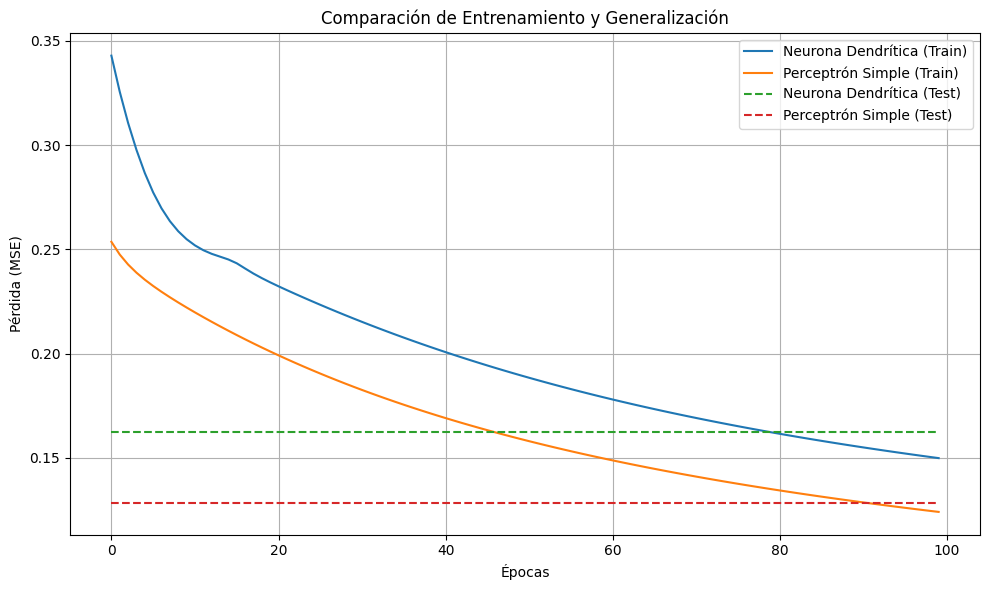

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Fijamos la semilla para reproducibilidad
np.random.seed(42)

# Clase de la neurona dendrítica
class NeuronaDendritica:
    def __init__(self, num_entradas):
        self.num_entradas = num_entradas
        self.pesos_dendrita1 = np.random.rand(num_entradas // 2) * 0.1
        self.pesos_dendrita2 = np.random.rand(num_entradas - (num_entradas // 2)) * 0.1
        self.sesgo = np.random.rand() * 0.1

    def activacion_dendrita1(self, x):
        return np.maximum(0, np.dot(x, self.pesos_dendrita1))

    def activacion_dendrita2(self, x):
        return np.exp(np.dot(x, self.pesos_dendrita2) / 10.0)

    def forward(self, x):
        x1 = x[:self.num_entradas // 2]
        x2 = x[self.num_entradas // 2:]
        s1 = self.activacion_dendrita1(x1)
        s2 = self.activacion_dendrita2(x2)
        return 1 / (1 + np.exp(-(s1 + s2 + self.sesgo)))

    def train(self, X, y, lr=0.01, epochs=100):
        losses = []
        for _ in range(epochs):
            loss_epoch = 0
            for xi, yi in zip(X, y):
                out = self.forward(xi)
                error = yi - out
                grad = out * (1 - out) * error

                # backprop
                d1 = xi[:self.num_entradas // 2]
                d2 = xi[self.num_entradas // 2:]
                self.pesos_dendrita1 += lr * grad * d1
                self.pesos_dendrita2 += lr * grad * d2
                self.sesgo += lr * grad

                loss_epoch += error ** 2
            losses.append(loss_epoch / len(X))
        return losses

# Clase del perceptrón simple
class PerceptronSimple:
    def __init__(self, num_entradas):
        self.pesos = np.random.rand(num_entradas) * 0.1
        self.sesgo = np.random.rand() * 0.1

    def forward(self, x):
        z = np.dot(x, self.pesos) + self.sesgo
        return 1 / (1 + np.exp(-z))

    def train(self, X, y, lr=0.01, epochs=100):
        losses = []
        for _ in range(epochs):
            loss_epoch = 0
            for xi, yi in zip(X, y):
                out = self.forward(xi)
                error = yi - out
                grad = out * (1 - out) * error

                self.pesos += lr * grad * xi
                self.sesgo += lr * grad

                loss_epoch += error ** 2
            losses.append(loss_epoch / len(X))
        return losses

# Datos sintéticos
def generar_datos(n=200):
    X = np.random.rand(n, 4)
    y = (X[:, 0] + X[:, 1] * 2 - X[:, 2] + 0.5 * X[:, 3] > 1.5).astype(float)
    return X, y

# Entrenamiento y visualización
X_train, y_train = generar_datos(200)
X_test, y_test = generar_datos(100)

neurona = NeuronaDendritica(4)
perceptron = PerceptronSimple(4)

loss_dend_train = neurona.train(X_train, y_train, epochs=100)
loss_perc_train = perceptron.train(X_train, y_train, epochs=100)

# Evaluar en test
loss_dend_test = [np.mean([(yi - neurona.forward(xi)) ** 2 for xi, yi in zip(X_test, y_test)]) for _ in range(100)]
loss_perc_test = [np.mean([(yi - perceptron.forward(xi)) ** 2 for xi, yi in zip(X_test, y_test)]) for _ in range(100)]

# Graficar pérdidas
plt.figure(figsize=(10, 6))
plt.plot(loss_dend_train, label="Neurona Dendrítica (Train)")
plt.plot(loss_perc_train, label="Perceptrón Simple (Train)")
plt.plot(loss_dend_test, '--', label="Neurona Dendrítica (Test)")
plt.plot(loss_perc_test, '--', label="Perceptrón Simple (Test)")
plt.xlabel("Épocas")
plt.ylabel("Pérdida (MSE)")
plt.title("Comparación de Entrenamiento y Generalización")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Número de entradas para los modelos: 4
Tamaño del conjunto de entrenamiento: 200 muestras
Tamaño del conjunto de prueba: 100 muestras

Parámetros Neurona Dendrítica: 5
Parámetros Perceptrón Simple:  5

--- Entrenando Neurona Dendrítica Mejorada ---
Pérdida final en entrenamiento (Dendrítica): 0.2280
Precisión final en entrenamiento (Dendrítica): 0.6150

--- Entrenando Perceptrón Simple Mejorado ---
Pérdida final en entrenamiento (Perceptrón): 0.0304
Precisión final en entrenamiento (Perceptrón): 0.9800

--- Resultados en Conjunto de Prueba ---
Neurona Dendrítica - Pérdida Test: 0.2267, Precisión Test: 0.6400
Perceptrón Simple - Pérdida Test:  0.0383, Precisión Test:  0.9800


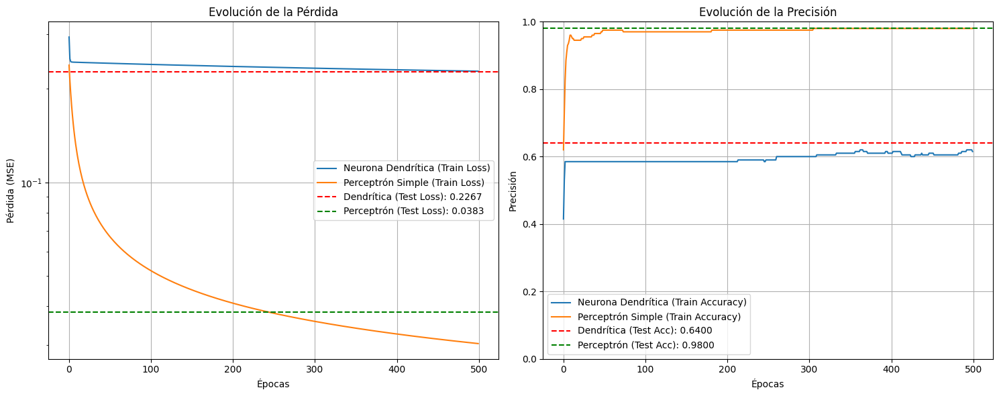

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Fijamos la semilla para reproducibilidad
np.random.seed(42)

# --- Funciones de Activación Comunes ---
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    s = sigmoid(x)
    return s * (1 - s)

def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return (x > 0).astype(float)

def exponential_activation(x, scale=10.0):
    # Evita overflow para números grandes, usando np.clip
    x_clipped = np.clip(x / scale, -500, 500) # Limita el rango para np.exp
    return np.exp(x_clipped)

def exponential_activation_derivative(x, scale=10.0):
    x_clipped = np.clip(x / scale, -500, 500)
    return np.exp(x_clipped) / scale


# --- Clase de la Neurona Dendrítica Mejorada ---
class NeuronaDendriticaMejorada:
    def __init__(self, num_entradas):
        if num_entradas < 2:
            raise ValueError("La neurona dendrítica requiere al menos 2 entradas para dividir.")

        self.num_entradas = num_entradas
        # Dividimos las entradas de manera más flexible
        self.split_idx = num_entradas // 2
        self.pesos_dendrita1 = np.random.rand(self.split_idx) * 0.1
        self.pesos_dendrita2 = np.random.rand(num_entradas - self.split_idx) * 0.1
        self.sesgo = np.random.rand() * 0.1

        # Almacenamos valores intermedios para backpropagation
        self.last_s1_input = None
        self.last_s2_input = None
        self.last_soma_input = None

    def forward(self, x):
        # Aseguramos que x sea un array de numpy
        x = np.asarray(x)
        if x.shape[0] != self.num_entradas:
            raise ValueError(f"Las entradas deben tener {self.num_entradas} características. Recibido: {x.shape[0]}")

        x1 = x[:self.split_idx]
        x2 = x[self.split_idx:]

        # Cálculo de las entradas ponderadas para cada dendrita
        self.last_s1_input = np.dot(x1, self.pesos_dendrita1)
        self.last_s2_input = np.dot(x2, self.pesos_dendrita2)

        # Aplicación de activaciones dendríticas
        s1_activated = relu(self.last_s1_input)
        s2_activated = exponential_activation(self.last_s2_input)

        # Suma en el "soma"
        self.last_soma_input = s1_activated + s2_activated + self.sesgo

        # Activación final del soma
        return sigmoid(self.last_soma_input)

    def train(self, X, y, lr=0.01, epochs=100):
        losses = []
        accuracies = []
        for epoch in range(epochs):
            loss_epoch = 0
            correct_predictions = 0
            for i in range(len(X)):
                xi, yi = X[i], y[i]

                # Paso hacia adelante (forward pass)
                out = self.forward(xi)

                # Cálculo del error y la pérdida (MSE)
                error = yi - out
                loss_epoch += error ** 2

                # Clasificación para precisión
                predicted_class = 1 if out >= 0.5 else 0
                if predicted_class == yi:
                    correct_predictions += 1

                # Backpropagation:
                # 1. Gradiente de la activación final (sigmoide)
                grad_soma_output = sigmoid_derivative(self.last_soma_input) * error

                # 2. Gradiente del sesgo
                grad_sesgo = grad_soma_output

                # 3. Gradientes de las señales de las dendritas
                grad_s1_activated = grad_soma_output
                grad_s2_activated = grad_soma_output

                # 4. Gradientes de las entradas ponderadas de las dendritas
                grad_s1_input = relu_derivative(self.last_s1_input) * grad_s1_activated
                grad_s2_input = exponential_activation_derivative(self.last_s2_input) * grad_s2_activated

                # 5. Gradientes de los pesos de las dendritas
                x1_part = xi[:self.split_idx]
                x2_part = xi[self.split_idx:]

                grad_pesos_dendrita1 = grad_s1_input * x1_part
                grad_pesos_dendrita2 = grad_s2_input * x2_part

                # Actualización de pesos y sesgos
                self.pesos_dendrita1 += lr * grad_pesos_dendrita1
                self.pesos_dendrita2 += lr * grad_pesos_dendrita2
                self.sesgo += lr * grad_sesgo

            losses.append(loss_epoch / len(X))
            accuracies.append(correct_predictions / len(X))
        return losses, accuracies

# --- Clase del Perceptrón Simple Mejorada ---
class PerceptronSimpleMejorado:
    def __init__(self, num_entradas):
        self.pesos = np.random.rand(num_entradas) * 0.1
        self.sesgo = np.random.rand() * 0.1
        self.last_z = None # Almacenar la suma ponderada para el backprop

    def forward(self, x):
        x = np.asarray(x)
        if x.shape[0] != len(self.pesos):
            raise ValueError(f"Las entradas deben tener {len(self.pesos)} características. Recibido: {x.shape[0]}")

        self.last_z = np.dot(x, self.pesos) + self.sesgo
        return sigmoid(self.last_z)

    def train(self, X, y, lr=0.01, epochs=100):
        losses = []
        accuracies = []
        for epoch in range(epochs):
            loss_epoch = 0
            correct_predictions = 0
            for i in range(len(X)):
                xi, yi = X[i], y[i]

                # Paso hacia adelante
                out = self.forward(xi)

                # Cálculo del error y la pérdida
                error = yi - out
                loss_epoch += error ** 2

                # Clasificación para precisión
                predicted_class = 1 if out >= 0.5 else 0
                if predicted_class == yi:
                    correct_predictions += 1

                # Backpropagation
                grad_output = sigmoid_derivative(self.last_z) * error

                self.pesos += lr * grad_output * xi
                self.sesgo += lr * grad_output

            losses.append(loss_epoch / len(X))
            accuracies.append(correct_predictions / len(X))
        return losses, accuracies

# --- Datos sintéticos (mismos que los originales) ---
def generar_datos(n=200):
    X = np.random.rand(n, 4)
    # Ejemplo de un problema linealmente separable para empezar
    y = (X[:, 0] + X[:, 1] * 2 - X[:, 2] + 0.5 * X[:, 3] > 1.5).astype(float)
    return X, y

# --- Configuración y Entrenamiento ---
num_entradas_datos = 4
learning_rate = 0.1 # Aumentado para una convergencia más rápida
num_epochs = 500 # Aumentado para ver mejor la convergencia

X_train, y_train = generar_datos(200)
X_test, y_test = generar_datos(100)

print(f"Número de entradas para los modelos: {num_entradas_datos}")
print(f"Tamaño del conjunto de entrenamiento: {len(X_train)} muestras")
print(f"Tamaño del conjunto de prueba: {len(X_test)} muestras\n")


# Inicializar modelos
neurona_dendritica = NeuronaDendriticaMejorada(num_entradas_datos)
perceptron_simple = PerceptronSimpleMejorado(num_entradas_datos)

# Mostrar número de parámetros
params_dendritica = (neurona_dendritica.split_idx + (num_entradas_datos - neurona_dendritica.split_idx) + 1)
params_perceptron = num_entradas_datos + 1
print(f"Parámetros Neurona Dendrítica: {params_dendritica}")
print(f"Parámetros Perceptrón Simple:  {params_perceptron}\n")


print("--- Entrenando Neurona Dendrítica Mejorada ---")
loss_dend_train, acc_dend_train = neurona_dendritica.train(X_train, y_train, lr=learning_rate, epochs=num_epochs)
print(f"Pérdida final en entrenamiento (Dendrítica): {loss_dend_train[-1]:.4f}")
print(f"Precisión final en entrenamiento (Dendrítica): {acc_dend_train[-1]:.4f}\n")

print("--- Entrenando Perceptrón Simple Mejorado ---")
loss_perc_train, acc_perc_train = perceptron_simple.train(X_train, y_train, lr=learning_rate, epochs=num_epochs)
print(f"Pérdida final en entrenamiento (Perceptrón): {loss_perc_train[-1]:.4f}")
print(f"Precisión final en entrenamiento (Perceptrón): {acc_perc_train[-1]:.4f}\n")


# --- Evaluación en el conjunto de prueba ---
def evaluate_model(model, X, y):
    predictions = []
    loss_sum = 0
    correct_count = 0
    for xi, yi in zip(X, y):
        out = model.forward(xi)
        predictions.append(out)
        loss_sum += (yi - out) ** 2
        predicted_class = 1 if out >= 0.5 else 0
        if predicted_class == yi:
            correct_count += 1

    avg_loss = loss_sum / len(X)
    accuracy = correct_count / len(X)
    return avg_loss, accuracy

loss_dend_test, acc_dend_test = evaluate_model(neurona_dendritica, X_test, y_test)
loss_perc_test, acc_perc_test = evaluate_model(perceptron_simple, X_test, y_test)

print("--- Resultados en Conjunto de Prueba ---")
print(f"Neurona Dendrítica - Pérdida Test: {loss_dend_test:.4f}, Precisión Test: {acc_dend_test:.4f}")
print(f"Perceptrón Simple - Pérdida Test:  {loss_perc_test:.4f}, Precisión Test:  {acc_perc_test:.4f}")


# --- Visualización de Resultados ---
plt.figure(figsize=(15, 6))

# Gráfico de Pérdida
plt.subplot(1, 2, 1)
plt.plot(loss_dend_train, label="Neurona Dendrítica (Train Loss)")
plt.plot(loss_perc_train, label="Perceptrón Simple (Train Loss)")
plt.axhline(y=loss_dend_test, color='red', linestyle='--', label=f'Dendrítica (Test Loss): {loss_dend_test:.4f}')
plt.axhline(y=loss_perc_test, color='green', linestyle='--', label=f'Perceptrón (Test Loss): {loss_perc_test:.4f}')
plt.xlabel("Épocas")
plt.ylabel("Pérdida (MSE)")
plt.title("Evolución de la Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log') # Útil para ver la convergencia

# Gráfico de Precisión
plt.subplot(1, 2, 2)
plt.plot(acc_dend_train, label="Neurona Dendrítica (Train Accuracy)")
plt.plot(acc_perc_train, label="Perceptrón Simple (Train Accuracy)")
plt.axhline(y=acc_dend_test, color='red', linestyle='--', label=f'Dendrítica (Test Acc): {acc_dend_test:.4f}')
plt.axhline(y=acc_perc_test, color='green', linestyle='--', label=f'Perceptrón (Test Acc): {acc_perc_test:.4f}')
plt.xlabel("Épocas")
plt.ylabel("Precisión")
plt.title("Evolución de la Precisión")
plt.legend()
plt.grid(True)
plt.ylim(0, 1) # La precisión va de 0 a 1
plt.tight_layout()
plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1) # [300, 1]
y = X.pow(3) - X + 0.5 * torch.randn(X.size()) # [300, 1]

# --- Neurona Dendrítica Simplificada en PyTorch ---
class NeuronaDendriticaPyTorch(nn.Module):
    def __init__(self, num_entradas):
        super().__init__()
        if num_entradas < 2:
            raise ValueError("La neurona dendrítica requiere al menos 2 entradas para dividir.")

        self.num_entradas = num_entradas
        self.split_idx = num_entradas // 2

        # Pesos para la primera "dendrita"
        self.pesos_dendrita1 = nn.Parameter(torch.randn(self.split_idx, 1) * 0.1)
        # Pesos para la segunda "dendrita"
        self.pesos_dendrita2 = nn.Parameter(torch.randn(num_entradas - self.split_idx, 1) * 0.1)

        self.sesgo = nn.Parameter(torch.randn(1) * 0.1)

    def activacion_dendrita1(self, x):
        return F.relu(x) # Función de activación ReLU

    def activacion_dendrita2(self, x):
        # Implementación de la activación exponencial.
        # Aseguramos que la entrada al exp sea segura para evitar overflows.
        return torch.exp(torch.clamp(x / 10.0, min=-50.0, max=50.0))

    def forward(self, x):
        # Aseguramos que la entrada tenga la forma correcta (batch_size, num_entradas)
        # Si la entrada es [num_samples, 1], la convertimos a [1, num_samples] para un solo input
        # O la dejamos así si ya es [batch_size, num_entradas]

        # En tu dataset X es [300, 1]. Si la neurona procesa una sola muestra,
        # necesitamos que x sea [1, num_entradas]

        # Adaptamos la entrada para que sea compatible con las operaciones de PyTorch,
        # especialmente si x es un escalar o tiene una dimensión extra como [num_samples, 1].
        # Asumimos que x ya viene en la forma adecuada para la neurona, es decir, [batch_size, num_features]
        # o [num_features] si es una sola muestra.

        # Para el dataset X, donde cada muestra es X[i] con forma [1], necesitamos
        # que x tenga forma [batch_size, num_features] si es un lote, o [num_features] si es una muestra.

        # Si la entrada x es [batch_size, 1] (como X en tu ejemplo), la dividimos
        x1 = x[:, :self.split_idx] # Coge las primeras 'split_idx' columnas
        x2 = x[:, self.split_idx:] # Coge el resto de las columnas

        # Aseguramos que los pesos tengan las dimensiones correctas para la multiplicación de matrices.
        # torch.mm requiere (N, M) x (M, P) -> (N, P)
        # Si x1 es [batch_size, split_idx] y pesos_dendrita1 es [split_idx, 1],
        # el resultado es [batch_size, 1].

        # Multiplicaciones ponderadas para cada dendrita
        s1_input = torch.mm(x1, self.pesos_dendrita1)
        s2_input = torch.mm(x2, self.pesos_dendrita2)

        # Aplicación de activaciones dendríticas
        s1_activated = self.activacion_dendrita1(s1_input)
        s2_activated = self.activacion_dendrita2(s2_input)

        # Suma en el "soma"
        soma_input = s1_activated + s2_activated + self.sesgo

        # Activación final del soma (sigmoide para compatibilidad con el ejemplo original,
        # pero para regresión podrías usar F.identity o F.relu si la salida no está acotada)
        return torch.sigmoid(soma_input)


# --- Perceptrón Simple en PyTorch ---
class PerceptronSimplePyTorch(nn.Module):
    def __init__(self, num_entradas):
        super().__init__()
        # Un único conjunto de pesos para todas las entradas
        self.pesos = nn.Parameter(torch.randn(num_entradas, 1) * 0.1)
        self.sesgo = nn.Parameter(torch.randn(1) * 0.1)

    def forward(self, x):
        # Suma ponderada de las entradas
        z = torch.mm(x, self.pesos) + self.sesgo
        # Aplicación de una función de activación (sigmoide)
        return torch.sigmoid(z)

# --- Configuración de Entrenamiento y Ejecución ---
LEARNING_RATE = 0.05
EPOCHS = 1000 # Aumentado para ver mejor la convergencia
LOSS_FN = nn.MSELoss() # Para regresión

INPUT_SIZE = X.shape[1] # Será 1 para tu dataset

print("--- Entrenando Neurona Dendrítica Simplificada (PyTorch) ---")
model_dendritica = NeuronaDendriticaPyTorch(num_entradas=INPUT_SIZE)
optimizer_dendritica = torch.optim.Adam(model_dendritica.parameters(), lr=LEARNING_RATE)
historial_loss_dendritica = []

# Calcular el número de parámetros para la neurona dendrítica
total_params_dendritica = sum(p.numel() for p in model_dendritica.parameters() if p.requires_grad)
print(f"Número de parámetros en Neurona Dendrítica: {total_params_dendritica}")

for epoch in range(EPOCHS):
    model_dendritica.train() # Pone el modelo en modo entrenamiento
    optimizer_dendritica.zero_grad() # Limpia los gradientes anteriores

    y_pred = model_dendritica(X) # Forward pass
    loss = LOSS_FN(y_pred, y) # Calcula la pérdida
    historial_loss_dendritica.append(loss.item())

    loss.backward() # Backpropagation
    optimizer_dendritica.step() # Actualiza los pesos

    if epoch % 100 == 0:
        print(f"Neurona Dendrítica - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Neurona Dendrítica): {historial_loss_dendritica[-1]:.6f}\n")


print("--- Entrenando Perceptrón Simple (PyTorch) ---")
model_perceptron = PerceptronSimplePyTorch(num_entradas=INPUT_SIZE)
optimizer_perceptron = torch.optim.Adam(model_perceptron.parameters(), lr=LEARNING_RATE)
historial_loss_perceptron = []

# Calcular el número de parámetros para el perceptrón
total_params_perceptron = sum(p.numel() for p in model_perceptron.parameters() if p.requires_grad)
print(f"Número de parámetros en Perceptrón Simple: {total_params_perceptron}")

for epoch in range(EPOCHS):
    model_perceptron.train()
    optimizer_perceptron.zero_grad()

    y_pred = model_perceptron(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_perceptron.append(loss.item())

    loss.backward()
    optimizer_perceptron.step()

    if epoch % 100 == 0:
        print(f"Perceptrón Simple - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Perceptrón Simple): {historial_loss_perceptron[-1]:.6f}\n")


## Visualización de Resultados

model_dendritica.eval() # Pone el modelo en modo evaluación
model_perceptron.eval() # Pone el modelo en modo evaluación

with torch.no_grad(): # Desactiva el cálculo de gradientes para la inferencia
    y_hat_dendritica = model_dendritica(X).numpy()
    y_hat_perceptron = model_perceptron(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 6))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones (Dataset Regresión)")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_dendritica, label="Predicción Neurona Dendrítica", color='red', linestyle='--')
plt.plot(X_np, y_hat_perceptron, label="Predicción Perceptrón Simple", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_dendritica, label="Pérdida Neurona Dendrítica", color='red')
plt.plot(historial_loss_perceptron, label="Pérdida Perceptrón Simple", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log') # Escala logarítmica para una mejor visualización
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Neurona Dendrítica): {historial_loss_dendritica[-1]:.6f}")
print(f"Pérdida final (Perceptrón Simple):  {historial_loss_perceptron[-1]:.6f}")

--- Entrenando Neurona Dendrítica Simplificada (PyTorch) ---


ValueError: La neurona dendrítica requiere al menos 2 entradas para dividir.

#Red con Sesgo de Memoria Residual (RMB)

--- Inicializando y Entrenando Red con Sesgo de Memoria Residual (RMB) ---
Número de parámetros en Red RMB: 3265
Red RMB - Época 0 - Pérdida: 76.363892
Red RMB - Época 100 - Pérdida: 15728063.000000
Red RMB - Época 200 - Pérdida: 534996930527232.000000
Red RMB - Época 300 - Pérdida: 75058244485120.000000
Red RMB - Época 400 - Pérdida: 18591757893632.000000
Red RMB - Época 500 - Pérdida: 358489280.000000
Red RMB - Época 600 - Pérdida: 267.090118
Red RMB - Época 700 - Pérdida: 260.247375
Red RMB - Época 800 - Pérdida: 93.879532
Red RMB - Época 900 - Pérdida: 77.622536
Red RMB - Época 1000 - Pérdida: 76.374779
Red RMB - Época 1100 - Pérdida: 76.391098
Red RMB - Época 1200 - Pérdida: 76.431091
Red RMB - Época 1300 - Pérdida: 76.447266
Red RMB - Época 1400 - Pérdida: 76.453049
Red RMB - Época 1500 - Pérdida: nan
Red RMB - Época 1600 - Pérdida: nan
Red RMB - Época 1700 - Pérdida: nan
Red RMB - Época 1800 - Pérdida: nan
Red RMB - Época 1900 - Pérdida: nan
Pérdida final (Red RMB): nan

--- Ini

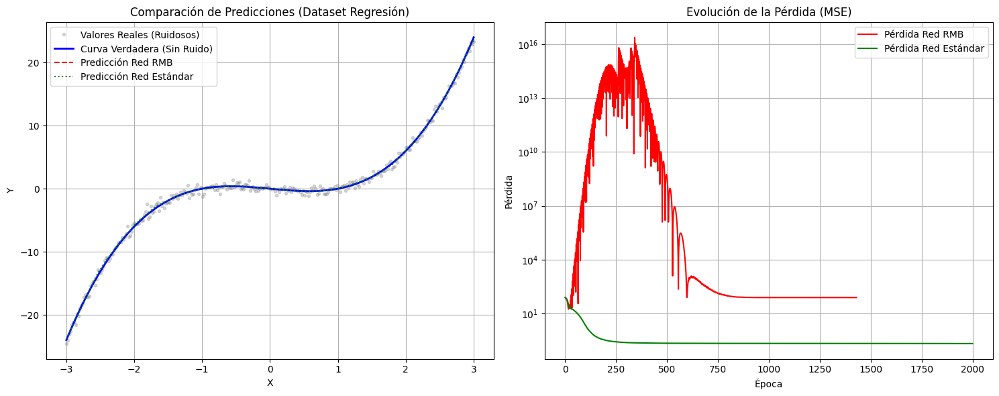

--- Resumen de Pérdidas Finales ---
Pérdida final (Red RMB): nan
Pérdida final (Red Estándar): 0.207241


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1) # [300, 1]
y = X.pow(3) - X + 0.5 * torch.randn(X.size()) # [300, 1]

# --- NUEVO MODELO: Capa con Sesgo de Memoria Residual (RMB) ---
class RMBLayer(nn.Module):
    def __init__(self, input_features, output_features, memory_decay=0.9):
        super().__init__()
        self.input_features = input_features
        self.output_features = output_features
        self.memory_decay = memory_decay # Factor de decaimiento de la memoria

        self.weight = nn.Parameter(torch.randn(input_features, output_features) * 0.1)

        # El "sesgo" inicial, que será influenciado por la memoria
        self.base_bias = nn.Parameter(torch.randn(output_features) * 0.1)

        # La "memoria residual": un estado interno que se actualiza
        # No es un nn.Parameter porque lo actualizaremos manualmente en forward
        self.register_buffer('residual_memory', torch.zeros(output_features))

        # Transformación no lineal para la memoria
        self.memory_transform = nn.Linear(output_features, output_features)
        # Inicializar para que al principio no cambie mucho
        nn.init.zeros_(self.memory_transform.weight)
        nn.init.zeros_(self.memory_transform.bias)

    def forward(self, x):
        linear_output = torch.matmul(x, self.weight)

        # --- Cálculo del Sesgo de Memoria Residual ---
        # 1. Transformar la memoria residual actual de forma no lineal
        transformed_memory_bias = self.memory_transform(self.residual_memory.unsqueeze(0)).squeeze(0)

        # 2. Combinar el sesgo base con el sesgo de memoria
        # El sesgo final es una suma del sesgo base aprendible y el sesgo dinámico de memoria.
        effective_bias = self.base_bias + transformed_memory_bias

        # Aplicar el sesgo al output lineal (expandirlo para el batch)
        output_with_bias = linear_output + effective_bias.unsqueeze(0)

        # 3. Actualizar la memoria residual para la próxima pasada
        # La memoria es un promedio móvil de las activaciones de salida de esta capa.
        # Esto hace que el "sesgo" sea una función de sus propias salidas pasadas.
        with torch.no_grad(): # La actualización de la memoria no debe tener gradientes
            # La memoria actual es la media de la salida actual, mezclada con la memoria antigua
            current_layer_output_mean = output_with_bias.mean(dim=0)
            self.residual_memory.data = (
                self.memory_decay * self.residual_memory.data +
                (1 - self.memory_decay) * current_layer_output_mean.data
            )

        return F.relu(output_with_bias) # Aplicar activación como de costumbre

# --- Red Neuronal usando las Capas RMB ---
class RMBNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.rmb_layer1 = RMBLayer(input_size, hidden_size)
        self.rmb_layer2 = RMBLayer(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = self.rmb_layer1(x)
        h2 = self.rmb_layer2(h1)
        out = self.output_layer(h2)
        return out

# --- Red Neuronal Estándar para Comparación ---
class StandardNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

# --- Parámetros de Entrenamiento ---
LEARNING_RATE = 0.01
EPOCHS = 2000
LOSS_FN = nn.MSELoss()

INPUT_SIZE = X.shape[1] # 1
HIDDEN_SIZE = 32 # Tamaño de las capas ocultas
OUTPUT_SIZE = y.shape[1] # 1

# --- Inicialización y Entrenamiento de Modelos ---
print("--- Inicializando y Entrenando Red con Sesgo de Memoria Residual (RMB) ---")
rmb_model = RMBNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_rmb = torch.optim.Adam(rmb_model.parameters(), lr=LEARNING_RATE)
historial_loss_rmb = []

total_params_rmb = sum(p.numel() for p in rmb_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red RMB: {total_params_rmb}")

for epoch in range(EPOCHS):
    rmb_model.train()
    optimizer_rmb.zero_grad()

    y_pred = rmb_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_rmb.append(loss.item())

    loss.backward()
    optimizer_rmb.step()

    if epoch % 100 == 0:
        print(f"Red RMB - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red RMB): {historial_loss_rmb[-1]:.6f}\n")


print("--- Inicializando y Entrenando Red Estándar (ReLU) ---")
standard_model = StandardNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_standard = torch.optim.Adam(standard_model.parameters(), lr=LEARNING_RATE)
historial_loss_standard = []

total_params_standard = sum(p.numel() for p in standard_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red Estándar: {total_params_standard}")

for epoch in range(EPOCHS):
    standard_model.train()
    optimizer_standard.zero_grad()

    y_pred = standard_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_standard.append(loss.item())

    loss.backward()
    optimizer_standard.step()

    if epoch % 100 == 0:
        print(f"Red Estándar - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}\n")


## Visualización de Resultados

rmb_model.eval()
standard_model.eval()

with torch.no_grad():
    y_hat_rmb = rmb_model(X).numpy()
    y_hat_standard = standard_model(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 6))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones (Dataset Regresión)")
plt.plot(X_np, y_np, 'o', label="Valores Reales (Ruidosos)", color='gray', alpha=0.3, markersize=3)
plt.plot(X.numpy(), X.pow(3).numpy() - X.numpy(), label="Curva Verdadera (Sin Ruido)", color='blue', linewidth=2)
plt.plot(X_np, y_hat_rmb, label="Predicción Red RMB", color='red', linestyle='--')
plt.plot(X_np, y_hat_standard, label="Predicción Red Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_rmb, label="Pérdida Red RMB", color='red')
plt.plot(historial_loss_standard, label="Pérdida Red Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red RMB): {historial_loss_rmb[-1]:.6f}")
print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}")

##Un Modelo de Varianza Experimental: La "Red de Caos Controlado (Controlled Chaos Network - CCN)"

--- Inicializando y Entrenando Red de Caos Controlado (CCN) ---
Número de parámetros en Red CCN: 1345
Red CCN - Época 0 - Pérdida: 71.860367
Red CCN - Época 100 - Pérdida: 0.340231
Red CCN - Época 200 - Pérdida: 0.269372
Red CCN - Época 300 - Pérdida: 0.649011
Red CCN - Época 400 - Pérdida: 0.208176
Red CCN - Época 500 - Pérdida: 0.203553
Red CCN - Época 600 - Pérdida: 0.203986
Red CCN - Época 700 - Pérdida: 0.197452
Red CCN - Época 800 - Pérdida: 0.193984
Red CCN - Época 900 - Pérdida: 0.192086
Red CCN - Época 1000 - Pérdida: 0.195430
Red CCN - Época 1100 - Pérdida: 0.194105
Red CCN - Época 1200 - Pérdida: 0.196376
Red CCN - Época 1300 - Pérdida: 0.247912
Red CCN - Época 1400 - Pérdida: 0.203010
Red CCN - Época 1500 - Pérdida: 0.197591
Red CCN - Época 1600 - Pérdida: 0.196007
Red CCN - Época 1700 - Pérdida: 0.199828
Red CCN - Época 1800 - Pérdida: 0.196962
Red CCN - Época 1900 - Pérdida: 0.213871
Pérdida final (Red CCN): 0.225929

--- Inicializando y Entrenando Red Estándar (ReLU) ---

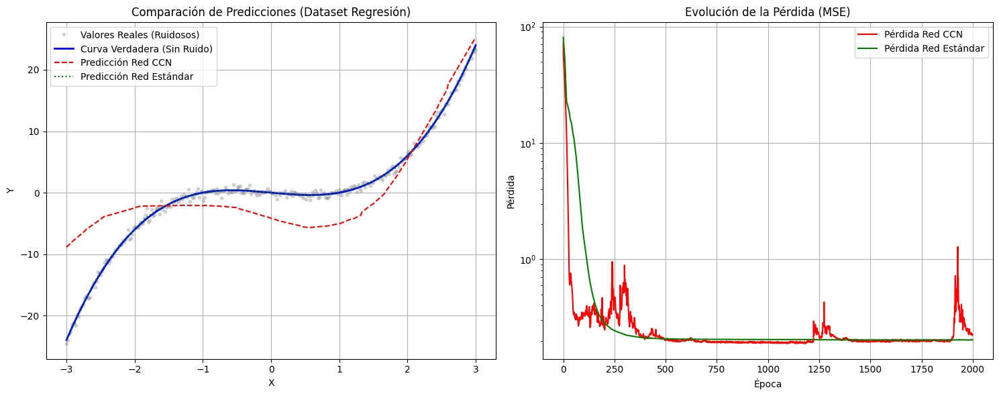

--- Resumen de Pérdidas Finales ---
Pérdida final (Red CCN): 0.225929
Pérdida final (Red Estándar): 0.203404


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1) # [300, 1]
y = X.pow(3) - X + 0.5 * torch.randn(X.size()) # [300, 1]

# --- NUEVA FUNCIÓN DE ACTIVACIÓN: HyperSensitiveReLU ---
class HyperSensitiveReLU(torch.autograd.Function):
    @staticmethod
    def forward(ctx, input, amplification_factor, activation_threshold):
        ctx.save_for_backward(input, torch.tensor(amplification_factor), torch.tensor(activation_threshold))

        activated_output = input.clone()

        sensitive_region = (activated_output > activation_threshold)
        activated_output[sensitive_region] *= amplification_factor

        activated_output[activated_output < 0] = F.leaky_relu(activated_output[activated_output < 0], negative_slope=0.01)

        return activated_output

    @staticmethod
    def backward(ctx, grad_output):
        input, amplification_factor, activation_threshold = ctx.saved_tensors
        grad_input = grad_output.clone()

        sensitive_region_grad = (input > activation_threshold)
        grad_input[sensitive_region_grad] *= amplification_factor.item() # Usar .item() para escalar

        grad_input[input < 0] *= 0.01

        # Devolvemos None para los argumentos no tensores (amplification_factor y activation_threshold)
        return grad_input, None, None

# Wrapper para la función de activación
hyper_sensitive_relu = HyperSensitiveReLU.apply

# --- NUEVO MÓDULO DE NORMALIZACIÓN: AdaptiveChaosNorm ---
class AdaptiveChaosNorm(nn.Module):
    def __init__(self, num_features, epsilon=1e-5, decay_rate=0.999):
        super().__init__()
        self.num_features = num_features
        self.epsilon = epsilon
        self.gamma = nn.Parameter(torch.ones(num_features))
        self.beta = nn.Parameter(torch.zeros(num_features))

        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))
        self.decay_rate = decay_rate

        self.turbulence_factor = nn.Parameter(torch.ones(num_features) * 0.1)

    def forward(self, input):
        if self.training:
            batch_mean = input.mean(dim=0)
            # Calcular varianza con corrección de Bessel para consistencia con BatchNorm
            batch_var = input.var(dim=0, unbiased=True)

            with torch.no_grad():
                self.running_mean.data = self.decay_rate * self.running_mean.data + (1 - self.decay_rate) * batch_mean.data
                self.running_var.data = self.decay_rate * self.running_var.data + (1 - self.decay_rate) * batch_var.data

            # Asegurar que el factor de turbulencia sea positivo
            turbulence_scale = torch.abs(self.turbulence_factor)

            # Normalización que considera la turbulencia
            # La varianza ajustada es una combinación de la varianza del batch y un factor
            # aprendido basado en la varianza del batch (turbulencia).
            # Esto permite que la normalización se adapte a la "volatilidad" del lote.
            adjusted_var = batch_var + (turbulence_scale * batch_var) # Combina varianza con un factor de escala de turbulencia

            normalized_input = (input - batch_mean) / torch.sqrt(adjusted_var + self.epsilon)

            output = self.gamma * normalized_input + self.beta
        else:
            normalized_input = (input - self.running_mean) / torch.sqrt(self.running_var + self.epsilon)
            output = self.gamma * normalized_input + self.beta
        return output


# --- Red de Caos Controlado (CCN) ---
class CCNNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.chaos_norm1 = AdaptiveChaosNorm(hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.chaos_norm2 = AdaptiveChaosNorm(hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1_linear = self.fc1(x)
        # Aplicar HyperSensitiveReLU usando argumentos posicionales
        h1_activated = hyper_sensitive_relu(h1_linear, 10.0, 0.1) # Argumentos posicionales
        h1 = self.chaos_norm1(h1_activated)

        h2_linear = self.fc2(h1)
        # Aplicar HyperSensitiveReLU usando argumentos posicionales
        h2_activated = hyper_sensitive_relu(h2_linear, 10.0, 0.1) # Argumentos posicionales
        h2 = self.chaos_norm2(h2_activated)

        out = self.output_layer(h2)
        return out

# --- Red Neuronal Estándar para Comparación ---
class StandardNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

# --- Parámetros de Entrenamiento ---
LEARNING_RATE = 0.01
EPOCHS = 2000
LOSS_FN = nn.MSELoss()

INPUT_SIZE = X.shape[1] # 1
HIDDEN_SIZE = 32 # Tamaño de las capas ocultas
OUTPUT_SIZE = y.shape[1] # 1

# --- Inicialización y Entrenamiento de Modelos ---
print("--- Inicializando y Entrenando Red de Caos Controlado (CCN) ---")
ccn_model = CCNNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_ccn = torch.optim.Adam(ccn_model.parameters(), lr=LEARNING_RATE)
historial_loss_ccn = []

total_params_ccn = sum(p.numel() for p in ccn_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red CCN: {total_params_ccn}")

for epoch in range(EPOCHS):
    ccn_model.train()
    optimizer_ccn.zero_grad()

    y_pred = ccn_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_ccn.append(loss.item())

    loss.backward()
    optimizer_ccn.step()

    if epoch % 100 == 0:
        print(f"Red CCN - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red CCN): {historial_loss_ccn[-1]:.6f}\n")


print("--- Inicializando y Entrenando Red Estándar (ReLU) ---")
standard_model = StandardNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_standard = torch.optim.Adam(standard_model.parameters(), lr=LEARNING_RATE)
historial_loss_standard = []

total_params_standard = sum(p.numel() for p in standard_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red Estándar: {total_params_standard}")

for epoch in range(EPOCHS):
    standard_model.train()
    optimizer_standard.zero_grad()

    y_pred = standard_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_standard.append(loss.item())

    loss.backward()
    optimizer_standard.step()

    if epoch % 100 == 0:
        print(f"Red Estándar - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}\n")


## Visualización de Resultados

ccn_model.eval() # IMPORTANTE: poner en modo evaluación para inferencia sin el comportamiento "caótico"
standard_model.eval()

with torch.no_grad():
    y_hat_ccn = ccn_model(X).numpy()
    y_hat_standard = standard_model(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 6))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones (Dataset Regresión)")
plt.plot(X_np, y_np, 'o', label="Valores Reales (Ruidosos)", color='gray', alpha=0.3, markersize=3)
plt.plot(X.numpy(), X.pow(3).numpy() - X.numpy(), label="Curva Verdadera (Sin Ruido)", color='blue', linewidth=2)
plt.plot(X_np, y_hat_ccn, label="Predicción Red CCN", color='red', linestyle='--')
plt.plot(X_np, y_hat_standard, label="Predicción Red Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_ccn, label="Pérdida Red CCN", color='red')
plt.plot(historial_loss_standard, label="Pérdida Red Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red CCN): {historial_loss_ccn[-1]:.6f}")
print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}")

##Capa Densa con Neuronas de Memoria Híbrida (HMNLayer)

--- Inicializando y Entrenando Red con Neuronas de Memoria Híbrida (HMN) ---
Número de parámetros en Red HMN: 2177
Resizing h_states from torch.Size([32, 1]) to [300, 32]
Resizing c_states from torch.Size([32, 1]) to [300, 32]
Resizing h_states from torch.Size([32, 1]) to [300, 32]
Resizing c_states from torch.Size([32, 1]) to [300, 32]
Red HMN - Época 0 - Pérdida: 76.403656
Red HMN - Época 100 - Pérdida: 11.353691
Red HMN - Época 200 - Pérdida: 4.492983
Red HMN - Época 300 - Pérdida: 2.329912
Red HMN - Época 400 - Pérdida: 0.776932
Red HMN - Época 500 - Pérdida: 0.670153
Red HMN - Época 600 - Pérdida: 0.381401
Red HMN - Época 700 - Pérdida: 0.504936
Red HMN - Época 800 - Pérdida: 0.539313
Red HMN - Época 900 - Pérdida: 1.175489
Red HMN - Época 1000 - Pérdida: 0.437721
Red HMN - Época 1100 - Pérdida: 0.322252
Red HMN - Época 1200 - Pérdida: 0.372662
Red HMN - Época 1300 - Pérdida: 0.398521
Red HMN - Época 1400 - Pérdida: 0.826731
Red HMN - Época 1500 - Pérdida: 0.663845
Red HMN - Época

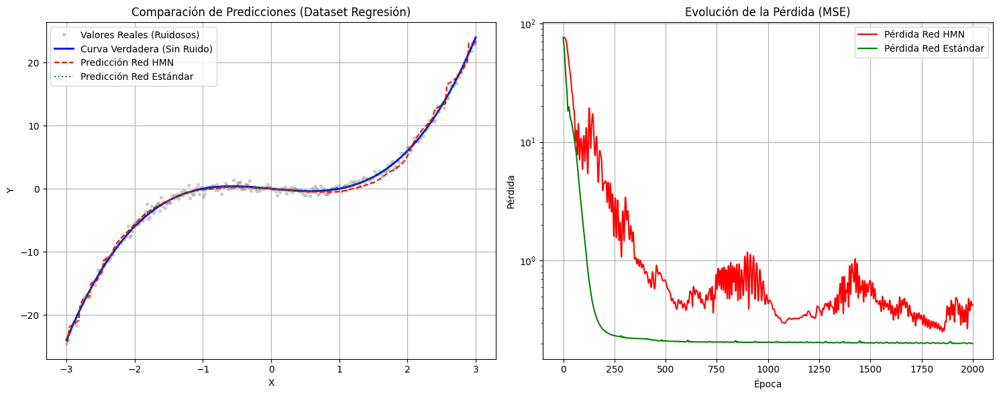

--- Resumen de Pérdidas Finales ---
Pérdida final (Red HMN): 0.424079
Pérdida final (Red Estándar): 0.199968


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1) # [300, 1]
y = X.pow(3) - X + 0.5 * torch.randn(X.size()) # [300, 1]

# --- NUEVA CAPA: Capa Densa con Neuronas de Memoria Híbrida (HMNLayer) ---
class HMNLayer(nn.Module):
    def __init__(self, input_features, output_features):
        super().__init__()
        self.input_features = input_features
        self.output_features = output_features

        # Pesos y sesgos de una capa lineal normal
        self.weight = nn.Parameter(torch.randn(input_features, output_features) * 0.1)
        self.bias = nn.Parameter(torch.randn(output_features) * 0.1)

        # CADA NEURONA DE SALIDA tiene su propia CELDA LSTM
        # nn.ModuleList para almacenar múltiples LSTMCells
        # Ensure hidden_size is 1 as intended
        self.lstm_cells = nn.ModuleList([nn.LSTMCell(input_size=1, hidden_size=1)
                                         for _ in range(output_features)])

        # Estados internos iniciales para cada LSTMCell (h y c)
        # Se inicializan a cero. Estos se actualizarán en cada forward pass.
        # These will be resized to [batch_size, output_features] during forward
        self.register_buffer('h_states', torch.zeros(output_features, 1)) # h_0 dummy shape
        self.register_buffer('c_states', torch.zeros(output_features, 1)) # c_0 dummy shape

    def forward(self, x):
        # 1. Realizar el cálculo lineal (Wx + b) como en una capa densa normal
        linear_output = torch.matmul(x, self.weight) + self.bias # Shape: [batch_size, output_features]

        # 2. Iterar a través de cada "neurona" (o feature de salida)
        # Each LSTMCell processes its respective column of the linear output
        # and maintains states [batch_size, 1] for that neuron's LSTM

        current_batch_size = x.size(0)

        # Ensure h_states and c_states match current batch size
        if self.h_states.size(0) != current_batch_size or self.h_states.size(1) != self.output_features:
            print(f"Resizing h_states from {self.h_states.shape} to [{current_batch_size}, {self.output_features}]")
            self.h_states = self.h_states.new_zeros(current_batch_size, self.output_features).to(x.device) # Move to device
        if self.c_states.size(0) != current_batch_size or self.c_states.size(1) != self.output_features:
             print(f"Resizing c_states from {self.c_states.shape} to [{current_batch_size}, {self.output_features}]")
             self.c_states = self.c_states.new_zeros(current_batch_size, self.output_features).to(x.device) # Move to device


        lstm_outputs = []
        new_h_states_list = [] # Use list to collect new states before cat
        new_c_states_list = [] # Use list to collect new states before cat


        # Iterate over the output features (neurons)
        for i in range(self.output_features):
            # Input for the i-th neuron's LSTM (i-th column of the linear output)
            # Shape: [batch_size, 1]
            input_i = linear_output[:, i].unsqueeze(1)

            # h and c states for the i-th neuron's LSTM across the batch
            # Each LSTMCell needs its own h_t and c_t for the batch, shape [batch_size, hidden_size=1]
            h_i = self.h_states[:, i].unsqueeze(1) # Shape: [batch_size, 1]
            c_i = self.c_states[:, i].unsqueeze(1) # Shape: [batch_size, 1]

            # Apply the LSTMCell of the neuron
            h_next_i, c_next_i = self.lstm_cells[i](input_i, (h_i, c_i))

            lstm_outputs.append(h_next_i) # Append [batch_size, 1]

            # DETACH the states before storing them for the next forward pass
            # This prevents building a computation graph across batches
            new_h_states_list.append(h_next_i.detach()) # Append [batch_size, 1]
            new_c_states_list.append(c_next_i.detach()) # Append [batch_size, 1]

        # Update the layer's internal states for the next forward pass
        # Concatenate the states for all neurons along dim=1
        self.h_states = torch.cat(new_h_states_list, dim=1) # Concatenates [batch_size, 1] * output_features -> [batch_size, output_features]
        self.c_states = torch.cat(new_c_states_list, dim=1) # Concatenates [batch_size, 1] * output_features -> [batch_size, output_features]

        # Concatenate the h outputs of each mini-LSTM into a single tensor
        return torch.cat(lstm_outputs, dim=1) # Shape: [batch_size, output_features]

# --- Red Neuronal usando las Capas HMN ---
class HMNNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        # Cada capa oculta es una HMNLayer
        self.hmn_layer1 = HMNLayer(input_size, hidden_size)
        self.hmn_layer2 = HMNLayer(hidden_size, hidden_size)
        # La capa de salida es normal porque no necesita memoria interna para la predicción final
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = self.hmn_layer1(x)
        # Add print statement to check the shape after hmn_layer1
        # print(f"Shape after hmn_layer1: {h1.shape}") # Keep or remove print as desired
        h2 = self.hmn_layer2(h1)
        out = self.output_layer(h2)
        return out

# --- Red Neuronal Estándar para Comparación ---
class StandardNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

# --- Parámetros de Entrenamiento ---
LEARNING_RATE = 0.01
EPOCHS = 2000
LOSS_FN = nn.MSELoss()

INPUT_SIZE = X.shape[1] # 1
HIDDEN_SIZE = 32 # Tamaño de las capas ocultas
OUTPUT_SIZE = y.shape[1] # 1

# --- Inicialización y Entrenamiento de Modelos ---
print("--- Inicializando y Entrenando Red con Neuronas de Memoria Híbrida (HMN) ---")
hmn_model = HMNNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_hmn = torch.optim.Adam(hmn_model.parameters(), lr=LEARNING_RATE)
historial_loss_hmn = []

total_params_hmn = sum(p.numel() for p in hmn_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red HMN: {total_params_hmn}")

for epoch in range(EPOCHS):
    hmn_model.train()
    optimizer_hmn.zero_grad()

    y_pred = hmn_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_hmn.append(loss.item())

    loss.backward()
    optimizer_hmn.step()

    if epoch % 100 == 0:
        print(f"Red HMN - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red HMN): {historial_loss_hmn[-1]:.6f}\n")


print("--- Inicializando y Entrenando Red Estándar (ReLU) ---")
standard_model = StandardNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE)
optimizer_standard = torch.optim.Adam(standard_model.parameters(), lr=LEARNING_RATE)
historial_loss_standard = []

total_params_standard = sum(p.numel() for p in standard_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red Estándar: {total_params_standard}")

for epoch in range(EPOCHS):
    standard_model.train()
    optimizer_standard.zero_grad()

    y_pred = standard_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_standard.append(loss.item())

    loss.backward()
    optimizer_standard.step()

    if epoch % 100 == 0:
        print(f"Red Estándar - Época {epoch} - Pérdida: {loss.item():.6f}")

print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}\n")


## Visualización de Resultados

hmn_model.eval()
standard_model.eval()

with torch.no_grad():
    y_hat_hmn = hmn_model(X).numpy()
    y_hat_standard = standard_model(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 6))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones (Dataset Regresión)")
plt.plot(X_np, y_np, 'o', label="Valores Reales (Ruidosos)", color='gray', alpha=0.3, markersize=3)
plt.plot(X.numpy(), X.pow(3).numpy() - X.numpy(), label="Curva Verdadera (Sin Ruido)", color='blue', linewidth=2)
plt.plot(X_np, y_hat_hmn, label="Predicción Red HMN", color='red', linestyle='--')
plt.plot(X_np, y_hat_standard, label="Predicción Red Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_hmn, label="Pérdida Red HMN", color='red')
plt.plot(historial_loss_standard, label="Pérdida Red Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red HMN): {historial_loss_hmn[-1]:.6f}")
print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}")

##Red Estándar (Organismo Procariota): Neuronas lineales simples.
Red con LSTM Tradicional (Organismo Multicelular Simple con Órganos Especializados): Una capa LSTM completa procesando secuencias.
Red con Neuronas de Memoria Híbrida - HMN (Organismo Eucariota con Células Especializadas y Memoria Celular): Cada "neurona" individual de una capa densa tiene su propia mini-LSTM.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Configuración de los dispositivos (CPU/GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1).to(device) # [300, 1]
y = (X.pow(3) - X + 0.5 * torch.randn(X.size()).to(device)) # [300, 1]

# --- 1. Red Neuronal Estándar (Tipo "Procariota") ---
class StandardNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

# --- 2. Red con LSTM Tradicional (Tipo "Multicelular Simple") ---
class TraditionalLSTMNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, num_layers=1):
        super().__init__()
        # nn.LSTM toma una entrada (batch_size, seq_len, input_size)
        # Para nuestro dataset, seq_len es 1 (cada X es un paso de tiempo único)
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # Añadir la dimensión de seq_len=1 para LSTM (batch_first=True)
        # x_lstm_input: [batch_size, 1, input_size]
        x_lstm_input = x.unsqueeze(1)

        # h_n y c_n son los estados finales, h_out es la salida de la última capa LSTM para todos los pasos de tiempo
        # Como seq_len=1, h_out será [batch_size, 1, hidden_size]
        h_out, (h_n, c_n) = self.lstm(x_lstm_input)

        # Tomamos la salida del último paso de tiempo (que es el único aquí)
        # y_pred: [batch_size, hidden_size]
        y_pred = h_out.squeeze(1)

        # Pasar por la capa de salida
        out = self.output_layer(y_pred)
        return out

# --- 3. Red con Neuronas de Memoria Híbrida - HMN (Tipo "Eucariota") ---
class HMNLayer(nn.Module):
    def __init__(self, input_features, output_features):
        super().__init__()
        self.input_features = input_features
        self.output_features = output_features

        self.weight = nn.Parameter(torch.randn(input_features, output_features) * 0.1)
        self.bias = nn.Parameter(torch.randn(output_features) * 0.1)

        self.lstm_cells = nn.ModuleList([nn.LSTMCell(input_size=1, hidden_size=1)
                                         for _ in range(output_features)])

        # Estados internos para cada LSTMCell por cada ejemplo del batch.
        # Estos se reinicializarán o se actualizarán en el forward si el batch_size cambia.
        self.h_states = None
        self.c_states = None

    def forward(self, x):
        current_batch_size = x.size(0)

        # Inicializar o ajustar los estados si el batch_size es diferente o es la primera pasada
        if self.h_states is None or self.h_states.size(0) != current_batch_size:
            self.h_states = torch.zeros(current_batch_size, self.output_features, device=x.device)
            self.c_states = torch.zeros(current_batch_size, self.output_features, device=x.device)

        linear_output = torch.matmul(x, self.weight) + self.bias # Shape: [batch_size, output_features]

        new_h_states = []
        new_c_states = []
        lstm_outputs = []

        for i in range(self.output_features):
            # Entrada para la i-ésima neurona LSTM (columna de la salida lineal)
            input_i = linear_output[:, i].unsqueeze(1) # [batch_size, 1]

            # Estados h y c para la i-ésima neurona LSTM (para todo el batch)
            h_i = self.h_states[:, i].unsqueeze(1) # [batch_size, 1]
            c_i = self.c_states[:, i].unsqueeze(1) # [batch_size, 1]

            # Aplicar la LSTMCell de la neurona
            h_next_i, c_next_i = self.lstm_cells[i](input_i, (h_i, c_i))

            lstm_outputs.append(h_next_i)
            new_h_states.append(h_next_i)
            new_c_states.append(c_next_i)

        # Actualizar los estados internos de la capa para el siguiente forward pass
        self.h_states = torch.cat(new_h_states, dim=1)
        self.c_states = torch.cat(new_c_states, dim=1)

        return torch.cat(lstm_outputs, dim=1) # Shape: [batch_size, output_features]

class HMNNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.hmn_layer1 = HMNLayer(input_size, hidden_size)
        self.hmn_layer2 = HMNLayer(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = self.hmn_layer1(x)
        h2 = self.hmn_layer2(h1)
        out = self.output_layer(h2)
        return out

# --- Parámetros de Entrenamiento Comunes ---
LEARNING_RATE = 0.01
EPOCHS = 2000
LOSS_FN = nn.MSELoss()

INPUT_SIZE = X.shape[1] # 1
HIDDEN_SIZE = 32 # Tamaño de las capas ocultas
OUTPUT_SIZE = y.shape[1] # 1

# --- Inicialización y Entrenamiento de Modelos ---

# 1. Red Estándar
print("--- Inicializando y Entrenando Red Estándar (Procariota) ---")
standard_model = StandardNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE).to(device)
optimizer_standard = torch.optim.Adam(standard_model.parameters(), lr=LEARNING_RATE)
historial_loss_standard = []

total_params_standard = sum(p.numel() for p in standard_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red Estándar: {total_params_standard}")

for epoch in range(EPOCHS):
    standard_model.train()
    optimizer_standard.zero_grad()
    y_pred = standard_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_standard.append(loss.item())
    loss.backward()
    optimizer_standard.step()
    if epoch % 500 == 0:
        print(f"Estándar - Época {epoch} - Pérdida: {loss.item():.6f}")
print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}\n")

# 2. Red con LSTM Tradicional
print("--- Inicializando y Entrenando Red con LSTM Tradicional (Multicelular Simple) ---")
lstm_model = TraditionalLSTMNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE).to(device)
optimizer_lstm = torch.optim.Adam(lstm_model.parameters(), lr=LEARNING_RATE)
historial_loss_lstm = []

total_params_lstm = sum(p.numel() for p in lstm_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red LSTM Tradicional: {total_params_lstm}")

for epoch in range(EPOCHS):
    lstm_model.train()
    optimizer_lstm.zero_grad()
    y_pred = lstm_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_lstm.append(loss.item())
    loss.backward()
    optimizer_lstm.step()
    if epoch % 500 == 0:
        print(f"LSTM Tradicional - Época {epoch} - Pérdida: {loss.item():.6f}")
print(f"Pérdida final (Red LSTM Tradicional): {historial_loss_lstm[-1]:.6f}\n")

# 3. Red con Neuronas de Memoria Híbrida - HMN
print("--- Inicializando y Entrenando Red con Neuronas de Memoria Híbrida (Eucariota) ---")
hmn_model = HMNNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE).to(device)
optimizer_hmn = torch.optim.Adam(hmn_model.parameters(), lr=LEARNING_RATE)
historial_loss_hmn = []

total_params_hmn = sum(p.numel() for p in hmn_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red HMN: {total_params_hmn}")

for epoch in range(EPOCHS):
    hmn_model.train()
    optimizer_hmn.zero_grad()
    y_pred = hmn_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_hmn.append(loss.item())
    loss.backward()
    optimizer_hmn.step()
    if epoch % 500 == 0:
        print(f"HMN - Época {epoch} - Pérdida: {loss.item():.6f}")
print(f"Pérdida final (Red HMN): {historial_loss_hmn[-1]:.6f}\n")


## Visualización de Resultados

standard_model.eval()
lstm_model.eval()
hmn_model.eval()

with torch.no_grad():
    y_hat_standard = standard_model(X).cpu().numpy()
    y_hat_lstm = lstm_model(X).cpu().numpy()
    y_hat_hmn = hmn_model(X).cpu().numpy()

X_np = X.cpu().numpy()
y_np = y.cpu().numpy()
X_true_func = (X.pow(3) - X).cpu().numpy() # Para la curva verdadera sin ruido

plt.figure(figsize=(18, 7))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones de Modelos")
plt.plot(X_np, y_np, 'o', label="Valores Reales (Ruidosos)", color='gray', alpha=0.3, markersize=3)
plt.plot(X_np, X_true_func, label="Curva Verdadera (Sin Ruido)", color='blue', linewidth=2)
plt.plot(X_np, y_hat_standard, label="Predicción Red Estándar (Procariota)", color='green', linestyle=':')
plt.plot(X_np, y_hat_lstm, label="Predicción Red LSTM Tradicional (Multicelular Simple)", color='orange', linestyle='-.')
plt.plot(X_np, y_hat_hmn, label="Predicción Red HMN (Eucariota)", color='red', linestyle='--')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_standard, label="Pérdida Red Estándar", color='green')
plt.plot(historial_loss_lstm, label="Pérdida Red LSTM Tradicional", color='orange')
plt.plot(historial_loss_hmn, label="Pérdida Red HMN", color='red')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}")
print(f"Pérdida final (Red LSTM Tradicional): {historial_loss_lstm[-1]:.6f}")
print(f"Pérdida final (Red HMN): {historial_loss_hmn[-1]:.6f}")

Usando dispositivo: cpu
--- Inicializando y Entrenando Red Estándar (Procariota) ---
Número de parámetros en Red Estándar: 1153
Estándar - Época 0 - Pérdida: 73.541977
Estándar - Época 500 - Pérdida: 0.211375
Estándar - Época 1000 - Pérdida: 0.207272
Estándar - Época 1500 - Pérdida: 0.207921
Pérdida final (Red Estándar): 0.206813

--- Inicializando y Entrenando Red con LSTM Tradicional (Multicelular Simple) ---
Número de parámetros en Red LSTM Tradicional: 4513
LSTM Tradicional - Época 0 - Pérdida: 76.478500
LSTM Tradicional - Época 500 - Pérdida: 0.287578
LSTM Tradicional - Época 1000 - Pérdida: 0.232233
LSTM Tradicional - Época 1500 - Pérdida: 0.219967
Pérdida final (Red LSTM Tradicional): 0.212603

--- Inicializando y Entrenando Red con Neuronas de Memoria Híbrida (Eucariota) ---
Número de parámetros en Red HMN: 2177
HMN - Época 0 - Pérdida: 76.363724


RuntimeError: Trying to backward through the graph a second time (or directly access saved tensors after they have already been freed). Saved intermediate values of the graph are freed when you call .backward() or autograd.grad(). Specify retain_graph=True if you need to backward through the graph a second time or if you need to access saved tensors after calling backward.

Usando dispositivo: cpu
--- Inicializando y Entrenando Red Estándar (Procariota) ---
Número de parámetros en Red Estándar: 1153
Estándar - Época 0 - Pérdida: 73.541977
Estándar - Época 500 - Pérdida: 0.211375
Estándar - Época 1000 - Pérdida: 0.207272
Estándar - Época 1500 - Pérdida: 0.207921
Pérdida final (Red Estándar): 0.206813

--- Inicializando y Entrenando Red con LSTM Tradicional (Multicelular Simple) ---
Número de parámetros en Red LSTM Tradicional: 4513
LSTM Tradicional - Época 0 - Pérdida: 76.478500
LSTM Tradicional - Época 500 - Pérdida: 0.287578
LSTM Tradicional - Época 1000 - Pérdida: 0.232233
LSTM Tradicional - Época 1500 - Pérdida: 0.219967
Pérdida final (Red LSTM Tradicional): 0.212603

--- Inicializando y Entrenando Red con Neuronas de Memoria Híbrida (Eucariota) ---
Número de parámetros en Red HMN: 2177
HMN - Época 0 - Pérdida: 76.363724
HMN - Época 500 - Pérdida: 1.544756
HMN - Época 1000 - Pérdida: 0.587049
HMN - Época 1500 - Pérdida: 0.690712
Pérdida final (Red HMN)

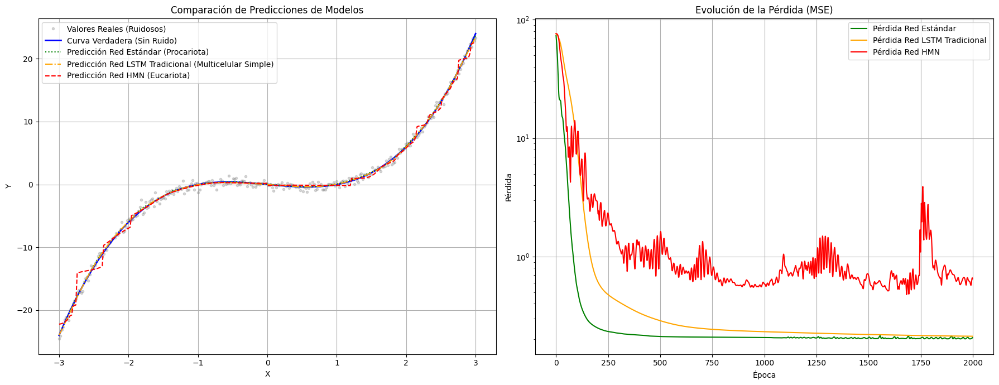

--- Resumen de Pérdidas Finales ---
Pérdida final (Red Estándar): 0.206813
Pérdida final (Red LSTM Tradicional): 0.212603
Pérdida final (Red HMN): 0.651177


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Configuración de los dispositivos (CPU/GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

# Dataset sintético (regresión no lineal)
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1).to(device) # [300, 1]
y = (X.pow(3) - X + 0.5 * torch.randn(X.size()).to(device)) # [300, 1]

# --- 1. Red Neuronal Estándar (Tipo "Procariota") ---
class StandardNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

# --- 2. Red con LSTM Tradicional (Tipo "Multicelular Simple") ---
class TraditionalLSTMNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, num_layers=1):
        super().__init__()
        # nn.LSTM toma una entrada (batch_size, seq_len, input_size)
        # Para nuestro dataset, seq_len es 1 (cada X es un paso de tiempo único)
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # Añadir la dimensión de seq_len=1 para LSTM (batch_first=True)
        # x_lstm_input: [batch_size, 1, input_size]
        x_lstm_input = x.unsqueeze(1)

        # h_n y c_n son los estados finales, h_out es la salida de la última capa LSTM para todos los pasos de tiempo
        # Como seq_len=1, h_out será [batch_size, 1, hidden_size]
        h_out, (h_n, c_n) = self.lstm(x_lstm_input)

        # Tomamos la salida del último paso de tiempo (que es el único aquí)
        # y_pred: [batch_size, hidden_size]
        y_pred = h_out.squeeze(1)

        # Pasar por la capa de salida
        out = self.output_layer(y_pred)
        return out

# --- 3. Red con Neuronas de Memoria Híbrida - HMN (Tipo "Eucariota") ---
class HMNLayer(nn.Module):
    def __init__(self, input_features, output_features):
        super().__init__()
        self.input_features = input_features
        self.output_features = output_features

        self.weight = nn.Parameter(torch.randn(input_features, output_features) * 0.1)
        self.bias = nn.Parameter(torch.randn(output_features) * 0.1)

        self.lstm_cells = nn.ModuleList([nn.LSTMCell(input_size=1, hidden_size=1)
                                         for _ in range(output_features)])

        # Estados internos para cada LSTMCell por cada ejemplo del batch.
        # Estos se reinicializarán o se actualizarán en el forward si el batch_size cambia.
        self.h_states = None
        self.c_states = None

    def forward(self, x):
        current_batch_size = x.size(0)

        # Inicializar o ajustar los estados si el batch_size es diferente o es la primera pasada
        if self.h_states is None or self.h_states.size(0) != current_batch_size:
            self.h_states = torch.zeros(current_batch_size, self.output_features, device=x.device)
            self.c_states = torch.zeros(current_batch_size, self.output_features, device=x.device)

        linear_output = torch.matmul(x, self.weight) + self.bias # Shape: [batch_size, output_features]

        new_h_states = []
        new_c_states = []
        lstm_outputs = []

        for i in range(self.output_features):
            # Entrada para la i-ésima neurona LSTM (columna de la salida lineal)
            input_i = linear_output[:, i].unsqueeze(1) # [batch_size, 1]

            # Estados h y c para la i-ésima neurona LSTM (para todo el batch)
            h_i = self.h_states[:, i].unsqueeze(1) # [batch_size, 1]
            c_i = self.c_states[:, i].unsqueeze(1) # [batch_size, 1]

            # Aplicar la LSTMCell de la neurona
            h_next_i, c_next_i = self.lstm_cells[i](input_i, (h_i, c_i))

            lstm_outputs.append(h_next_i)

            # *** FIX: Detach the states before storing them for the next forward pass ***
            # This prevents the computation graph from growing across batches.
            new_h_states.append(h_next_i.detach())
            new_c_states.append(c_next_i.detach())

        # Actualizar los estados internos de la capa para el siguiente forward pass
        self.h_states = torch.cat(new_h_states, dim=1)
        self.c_states = torch.cat(new_c_states, dim=1)

        return torch.cat(lstm_outputs, dim=1) # Shape: [batch_size, output_features]

class HMNNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.hmn_layer1 = HMNLayer(input_size, hidden_size)
        self.hmn_layer2 = HMNLayer(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = self.hmn_layer1(x)
        h2 = self.hmn_layer2(h1)
        out = self.output_layer(h2)
        return out

# --- Parámetros de Entrenamiento Comunes ---
LEARNING_RATE = 0.01
EPOCHS = 2000
LOSS_FN = nn.MSELoss()

INPUT_SIZE = X.shape[1] # 1
HIDDEN_SIZE = 32 # Tamaño de las capas ocultas
OUTPUT_SIZE = y.shape[1] # 1

# --- Inicialización y Entrenamiento de Modelos ---

# 1. Red Estándar
print("--- Inicializando y Entrenando Red Estándar (Procariota) ---")
standard_model = StandardNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE).to(device)
optimizer_standard = torch.optim.Adam(standard_model.parameters(), lr=LEARNING_RATE)
historial_loss_standard = []

total_params_standard = sum(p.numel() for p in standard_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red Estándar: {total_params_standard}")

for epoch in range(EPOCHS):
    standard_model.train()
    optimizer_standard.zero_grad()
    y_pred = standard_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_standard.append(loss.item())
    loss.backward()
    optimizer_standard.step()
    if epoch % 500 == 0:
        print(f"Estándar - Época {epoch} - Pérdida: {loss.item():.6f}")
print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}\n")

# 2. Red con LSTM Tradicional
print("--- Inicializando y Entrenando Red con LSTM Tradicional (Multicelular Simple) ---")
lstm_model = TraditionalLSTMNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE).to(device)
optimizer_lstm = torch.optim.Adam(lstm_model.parameters(), lr=LEARNING_RATE)
historial_loss_lstm = []

total_params_lstm = sum(p.numel() for p in lstm_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red LSTM Tradicional: {total_params_lstm}")

for epoch in range(EPOCHS):
    lstm_model.train()
    optimizer_lstm.zero_grad()
    y_pred = lstm_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_lstm.append(loss.item())
    loss.backward()
    optimizer_lstm.step()
    if epoch % 500 == 0:
        print(f"LSTM Tradicional - Época {epoch} - Pérdida: {loss.item():.6f}")
print(f"Pérdida final (Red LSTM Tradicional): {historial_loss_lstm[-1]:.6f}\n")

# 3. Red con Neuronas de Memoria Híbrida - HMN
print("--- Inicializando y Entrenando Red con Neuronas de Memoria Híbrida (Eucariota) ---")
hmn_model = HMNNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE).to(device)
optimizer_hmn = torch.optim.Adam(hmn_model.parameters(), lr=LEARNING_RATE)
historial_loss_hmn = []

total_params_hmn = sum(p.numel() for p in hmn_model.parameters() if p.requires_grad)
print(f"Número de parámetros en Red HMN: {total_params_hmn}")

for epoch in range(EPOCHS):
    hmn_model.train()
    optimizer_hmn.zero_grad()
    y_pred = hmn_model(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_hmn.append(loss.item())
    loss.backward()
    optimizer_hmn.step()
    if epoch % 500 == 0:
        print(f"HMN - Época {epoch} - Pérdida: {loss.item():.6f}")
print(f"Pérdida final (Red HMN): {historial_loss_hmn[-1]:.6f}\n")


## Visualización de Resultados

standard_model.eval()
lstm_model.eval()
hmn_model.eval()

with torch.no_grad():
    y_hat_standard = standard_model(X).cpu().numpy()
    y_hat_lstm = lstm_model(X).cpu().numpy()
    y_hat_hmn = hmn_model(X).cpu().numpy()

X_np = X.cpu().numpy()
y_np = y.cpu().numpy()
X_true_func = (X.pow(3) - X).cpu().numpy() # Para la curva verdadera sin ruido

plt.figure(figsize=(18, 7))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones de Modelos")
plt.plot(X_np, y_np, 'o', label="Valores Reales (Ruidosos)", color='gray', alpha=0.3, markersize=3)
plt.plot(X_np, X_true_func, label="Curva Verdadera (Sin Ruido)", color='blue', linewidth=2)
plt.plot(X_np, y_hat_standard, label="Predicción Red Estándar (Procariota)", color='green', linestyle=':')
plt.plot(X_np, y_hat_lstm, label="Predicción Red LSTM Tradicional (Multicelular Simple)", color='orange', linestyle='-.')
plt.plot(X_np, y_hat_hmn, label="Predicción Red HMN (Eucariota)", color='red', linestyle='--')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_standard, label="Pérdida Red Estándar", color='green')
plt.plot(historial_loss_lstm, label="Pérdida Red LSTM Tradicional", color='orange')
plt.plot(historial_loss_hmn, label="Pérdida Red HMN", color='red')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}")
print(f"Pérdida final (Red LSTM Tradicional): {historial_loss_lstm[-1]:.6f}")
print(f"Pérdida final (Red HMN): {historial_loss_hmn[-1]:.6f}")

## inicializador de pesos

In [ ]:
# Instalar la librería opensimplex
!pip install opensimplex

Usando dispositivo: cpu
--- Entrenando Red Estándar ---
Red Estándar - Época 0 - Pérdida: 73.541977
Red Estándar - Época 500 - Pérdida: 0.211375
Red Estándar - Época 1000 - Pérdida: 0.207272
Red Estándar - Época 1500 - Pérdida: 0.207921
Pérdida final (Red Estándar): 0.206813

--- Entrenando Red con Ruido Perlin ---
Red con Ruido Perlin - Época 0 - Pérdida: 73.363945
Red con Ruido Perlin - Época 500 - Pérdida: 0.229806
Red con Ruido Perlin - Época 1000 - Pérdida: 0.220433
Red con Ruido Perlin - Época 1500 - Pérdida: 0.221918
Pérdida final (Red con Ruido Perlin): 0.217992

--- Entrenando Red con Atractor de Lorenz ---
Red con Atractor de Lorenz - Época 0 - Pérdida: 9196.409180
Red con Atractor de Lorenz - Época 500 - Pérdida: 15.518394
Red con Atractor de Lorenz - Época 1000 - Pérdida: 13.722815
Red con Atractor de Lorenz - Época 1500 - Pérdida: 7.788110
Pérdida final (Red con Atractor de Lorenz): 2.497373



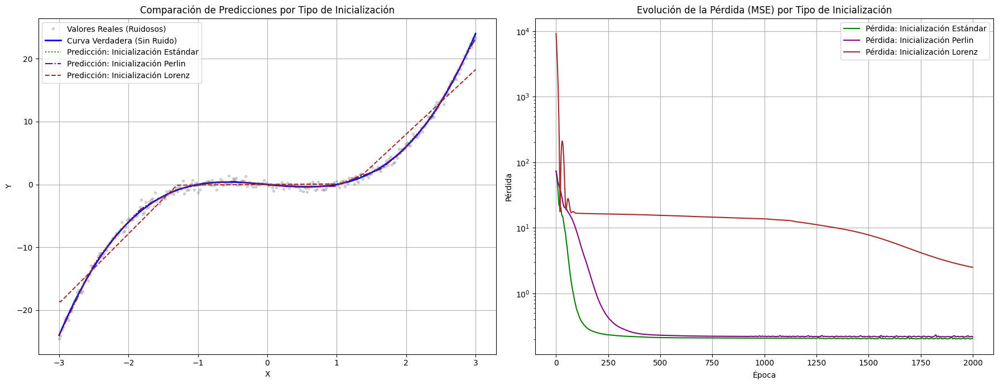

--- Resumen de Pérdidas Finales ---
Pérdida final (Red Estándar): 0.206813
Pérdida final (Red con Ruido Perlin): 0.217992
Pérdida final (Red con Atractor de Lorenz): 2.497373


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import opensimplex # pip install opensimplex

# --- Configuración de los dispositivos (CPU/GPU) ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

# --- Dataset sintético (regresión no lineal con ruido) ---
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1).to(device) # [300, 1]
y = (X.pow(3) - X + 0.5 * torch.randn(X.size()).to(device)) # [300, 1]

# --- Funciones de Inicialización Personalizadas ---

def generate_perlin_noise_weights(shape, scale=0.05):
    """Genera un tensor de pesos basado en ruido Simplex (similar a Perlin)."""
    total_elements = np.prod(shape)
    noise_map = np.zeros(total_elements)
    # Generamos ruido 2D y lo aplanamos, dando una coherencia a través del tensor.
    # El offset 'i * 0.001' asegura que cada valor no sea idéntico
    for i in range(total_elements):
        noise_map[i] = opensimplex.noise2(x=i * scale, y=i * scale * 1.5)

    noise_map = noise_map.reshape(shape)

    # Escalamiento He/Kaiming para la activación ReLU
    fan_in = shape[0] if len(shape) > 1 else 1 # Para capas densas, fan_in es la primera dim
    if len(shape) == 4: # Para capas convolucionales
        fan_in = shape[1] * shape[2] * shape[3]

    std_dev = np.sqrt(2.0 / fan_in)
    noise_tensor = torch.from_numpy(noise_map).float() * std_dev
    return noise_tensor

def generate_lorenz_points(num_points, sigma=10, rho=28, beta=8/3, dt=0.01):
    """Genera puntos del atractor de Lorenz."""
    xs, ys, zs = [], [], []
    x, y, z = 0.1, 0.0, 0.0

    for _ in range(num_points):
        dx = (sigma * (y - x)) * dt
        dy = (x * (rho - z) - y) * dt
        dz = (x * y - beta * z) * dt
        x += dx
        y += dy
        z += dz
        xs.append(x)
        ys.append(y)
        zs.append(z)
    return np.array(xs + ys + zs)

def map_lorenz_to_weights(shape, lorenz_points, current_idx_ref):
    """
    Mapea puntos del atractor de Lorenz a la forma deseada de los pesos.
    current_idx_ref es una lista mutable para pasar el índice por referencia.
    """
    total_elements = np.prod(shape)

    if (current_idx_ref[0] + total_elements) > len(lorenz_points):
        raise ValueError(f"No hay suficientes puntos de Lorenz para inicializar los pesos de forma {shape}.")

    sampled_points = lorenz_points[current_idx_ref[0] : current_idx_ref[0] + total_elements]
    current_idx_ref[0] += total_elements # Actualizar el índice

    # Normalizar y escalar
    mean = np.mean(sampled_points)
    std = np.std(sampled_points)

    if std == 0:
        normalized_points = np.zeros_like(sampled_points)
    else:
        normalized_points = (sampled_points - mean) / std

    fan_in = shape[0] if len(shape) > 1 else 1
    if len(shape) == 4: # Conv
        fan_in = shape[1] * shape[2] * shape[3]

    scale_factor = np.sqrt(2.0 / fan_in)

    weights = normalized_points * scale_factor
    return torch.from_numpy(weights).float().reshape(shape)

# --- Definición de Modelos con Diferentes Inicializaciones ---

class MLP(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, init_type='standard', lorenz_data=None, lorenz_idx_ref=None):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

        if init_type == 'standard':
            # PyTorch ya usa la inicialización de Kaiming Uniform por defecto para nn.Linear
            # con ReLU, lo cual es un buen estándar aleatorio.
            pass
        elif init_type == 'perlin':
            self.fc1.weight.data = generate_perlin_noise_weights(self.fc1.weight.shape, scale=0.05)
            self.fc1.bias.data = generate_perlin_noise_weights(self.fc1.bias.shape, scale=0.1).squeeze()
            self.fc2.weight.data = generate_perlin_noise_weights(self.fc2.weight.shape, scale=0.05)
            self.fc2.bias.data = generate_perlin_noise_weights(self.fc2.bias.shape, scale=0.1).squeeze()
            self.output_layer.weight.data = generate_perlin_noise_weights(self.output_layer.weight.shape, scale=0.05)
            self.output_layer.bias.data = generate_perlin_noise_weights(self.output_layer.bias.shape, scale=0.1).squeeze()
        elif init_type == 'lorenz':
            if lorenz_data is None or lorenz_idx_ref is None:
                raise ValueError("Se requiere 'lorenz_data' y 'lorenz_idx_ref' para la inicialización de Lorenz.")

            self.fc1.weight.data = map_lorenz_to_weights(self.fc1.weight.shape, lorenz_data, lorenz_idx_ref)
            self.fc1.bias.data = map_lorenz_to_weights(self.fc1.bias.shape, lorenz_data, lorenz_idx_ref).squeeze()
            self.fc2.weight.data = map_lorenz_to_weights(self.fc2.weight.shape, lorenz_data, lorenz_idx_ref)
            self.fc2.bias.data = map_lorenz_to_weights(self.fc2.bias.shape, lorenz_data, lorenz_idx_ref).squeeze()
            self.output_layer.weight.data = map_lorenz_to_weights(self.output_layer.weight.shape, lorenz_data, lorenz_idx_ref)
            self.output_layer.bias.data = map_lorenz_to_weights(self.output_layer.bias.shape, lorenz_data, lorenz_idx_ref).squeeze()
        else:
            raise ValueError(f"Tipo de inicialización desconocido: {init_type}")

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

# --- Parámetros de Entrenamiento Comunes ---
LEARNING_RATE = 0.01
EPOCHS = 2000
LOSS_FN = nn.MSELoss()

INPUT_SIZE = X.shape[1] # 1
HIDDEN_SIZE = 32 # Tamaño de las capas ocultas
OUTPUT_SIZE = y.shape[1] # 1

# --- Función de Entrenamiento ---
def train_model(model, X_data, y_data, optimizer, epochs, loss_fn, model_name):
    historial_loss = []
    print(f"--- Entrenando {model_name} ---")
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        y_pred = model(X_data)
        loss = loss_fn(y_pred, y_data)
        historial_loss.append(loss.item())
        loss.backward()
        optimizer.step()
        if epoch % 500 == 0:
            print(f"{model_name} - Época {epoch} - Pérdida: {loss.item():.6f}")
    print(f"Pérdida final ({model_name}): {historial_loss[-1]:.6f}\n")
    return historial_loss

# --- Inicialización y Entrenamiento de Cada Modelo ---

# Modelo 1: Estándar (Aleatoria por defecto de PyTorch)
standard_model = MLP(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE, init_type='standard').to(device)
optimizer_standard = torch.optim.Adam(standard_model.parameters(), lr=LEARNING_RATE)
historial_loss_standard = train_model(standard_model, X, y, optimizer_standard, EPOCHS, LOSS_FN, "Red Estándar")

# Modelo 2: Perlin Noise
perlin_model = MLP(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE, init_type='perlin').to(device)
optimizer_perlin = torch.optim.Adam(perlin_model.parameters(), lr=LEARNING_RATE)
historial_loss_perlin = train_model(perlin_model, X, y, optimizer_perlin, EPOCHS, LOSS_FN, "Red con Ruido Perlin")

# Modelo 3: Atractor de Lorenz
# Calcular el total de elementos de pesos y sesgos necesarios para el modelo
total_elements_lorenz = sum(np.prod(p.shape) for p in MLP(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE).parameters())
lorenz_data = generate_lorenz_points(num_points=int(total_elements_lorenz * 1.5)) # Generar un poco más
lorenz_idx_ref = [0] # Usar una lista para pasar el índice por referencia y que se actualice
lorenz_model = MLP(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE, init_type='lorenz', lorenz_data=lorenz_data, lorenz_idx_ref=lorenz_idx_ref).to(device)
optimizer_lorenz = torch.optim.Adam(lorenz_model.parameters(), lr=LEARNING_RATE)
historial_loss_lorenz = train_model(lorenz_model, X, y, optimizer_lorenz, EPOCHS, LOSS_FN, "Red con Atractor de Lorenz")

## --- Visualización de Resultados ---

standard_model.eval()
perlin_model.eval()
lorenz_model.eval()

with torch.no_grad():
    y_hat_standard = standard_model(X).cpu().numpy()
    y_hat_perlin = perlin_model(X).cpu().numpy()
    y_hat_lorenz = lorenz_model(X).cpu().numpy()

X_np = X.cpu().numpy()
y_np = y.cpu().numpy()
X_true_func = (X.pow(3) - X).cpu().numpy() # Para la curva verdadera sin ruido

plt.figure(figsize=(18, 7))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones por Tipo de Inicialización")
plt.plot(X_np, y_np, 'o', label="Valores Reales (Ruidosos)", color='gray', alpha=0.3, markersize=3)
plt.plot(X_np, X_true_func, label="Curva Verdadera (Sin Ruido)", color='blue', linewidth=2)
plt.plot(X_np, y_hat_standard, label="Predicción: Inicialización Estándar", color='green', linestyle=':')
plt.plot(X_np, y_hat_perlin, label="Predicción: Inicialización Perlin", color='purple', linestyle='-.')
plt.plot(X_np, y_hat_lorenz, label="Predicción: Inicialización Lorenz", color='brown', linestyle='--')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE) por Tipo de Inicialización")
plt.plot(historial_loss_standard, label="Pérdida: Inicialización Estándar", color='green')
plt.plot(historial_loss_perlin, label="Pérdida: Inicialización Perlin", color='purple')
plt.plot(historial_loss_lorenz, label="Pérdida: Inicialización Lorenz", color='brown')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red Estándar): {historial_loss_standard[-1]:.6f}")
print(f"Pérdida final (Red con Ruido Perlin): {historial_loss_perlin[-1]:.6f}")
print(f"Pérdida final (Red con Atractor de Lorenz): {historial_loss_lorenz[-1]:.6f}")

Red con inicialización Perlin creada.
Forma de los pesos de fc1: torch.Size([20, 10])


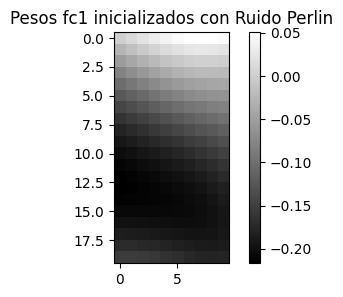

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import opensimplex # Requiere pip install opensimplex
import matplotlib.pyplot as plt

# Generador de Ruido Perlin (usando opensimplex por simplicidad, aunque Perlin es más general)
def generate_perlin_noise_weights(shape, scale=0.1, octaves=1, persistence=0.5, lacunarity=2.0):
    """
    Genera un tensor de pesos basado en ruido Perlin (o Simplex, similar).

    Args:
        shape (tuple): La forma (dimensiones) del tensor de pesos.
        scale (float): La escala del ruido (frecuencia).
        octaves (int): Número de capas de ruido.
        persistence (float): Cuánto contribuye cada octava a la amplitud general.
        lacunarity (float): Factor de incremento de la frecuencia para cada octava.
    Returns:
        torch.Tensor: Tensor de la forma especificada con valores de ruido.
    """
    if len(shape) > 2:
        print("Advertencia: El ruido Perlin/Simplex es más visual en 2D. Generando 1D y expandiendo.")
        # Simplificamos para demostración a 1D o 2D
        if len(shape) == 3: # Conv layer (out_channels, in_channels, kernel_size, kernel_size)
            total_elements = shape[0] * shape[1] * shape[2]
            noise_map = np.zeros(total_elements)
            for i in range(total_elements):
                noise_map[i] = opensimplex.noise2(x=i * scale, y=i * scale) # Usamos 2D para la coherencia

        elif len(shape) == 4: # Conv layer (out_channels, in_channels, kernel_h, kernel_w)
            # Para 4D, podemos generar ruido 2D para cada kernel y apilar
            num_kernels = shape[0] * shape[1]
            h, w = shape[2], shape[3]
            noise_map = np.zeros((num_kernels, h, w))
            for k_idx in range(num_kernels):
                for y_idx in range(h):
                    for x_idx in range(w):
                        noise_map[k_idx, y_idx, x_idx] = opensimplex.noise2(
                            x=x_idx * scale + k_idx * 100, # Un offset para cada kernel
                            y=y_idx * scale + k_idx * 100
                        )
        else: # Para otros casos, simplemente linealizamos
            total_elements = np.prod(shape)
            noise_map = np.zeros(total_elements)
            for i in range(total_elements):
                noise_map[i] = opensimplex.noise2(x=i * scale, y=i * scale)

    else: # Para 1D o 2D directo
        total_elements = np.prod(shape)
        noise_map = np.zeros(total_elements)
        if len(shape) == 1:
            for i in range(total_elements):
                noise_map[i] = opensimplex.noise2(x=i * scale, y=0) # Genera en 1D
        elif len(shape) == 2:
            rows, cols = shape
            noise_map = np.zeros((rows, cols))
            for r in range(rows):
                for c in range(cols):
                    noise_map[r, c] = opensimplex.noise2(x=c * scale, y=r * scale)

    noise_map = noise_map.reshape(shape) # Reshape de vuelta a la forma original

    # Normalizar el ruido (normalmente entre -1 y 1) y escalarlo para la inicialización
    # Una escala similar a Xavier/He puede ser útil, e.g., 1 / sqrt(fan_in)
    fan_in = shape[0] if len(shape) > 1 else 1 # Para capas densas, fan_in es la primera dim
    if len(shape) == 4: # Conv
        fan_in = shape[1] * shape[2] * shape[3]

    std_dev = np.sqrt(2.0 / fan_in) # Inspirado en He/Kaiming
    noise_tensor = torch.from_numpy(noise_map).float() * std_dev
    return noise_tensor

# Ejemplo de cómo usarlo en una capa lineal
class PerlinNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

        # Inicialización de pesos con ruido Perlin
        self.fc1.weight.data = generate_perlin_noise_weights(self.fc1.weight.shape, scale=0.05)
        self.fc2.weight.data = generate_perlin_noise_weights(self.fc2.weight.shape, scale=0.05)
        self.output_layer.weight.data = generate_perlin_noise_weights(self.output_layer.weight.shape, scale=0.05)

        # Inicialización de sesgos con ruido Perlin (para sesgos es más simple, 1D)
        self.fc1.bias.data = generate_perlin_noise_weights(self.fc1.bias.shape, scale=0.1).squeeze()
        self.fc2.bias.data = generate_perlin_noise_weights(self.fc2.bias.shape, scale=0.1).squeeze()
        self.output_layer.bias.data = generate_perlin_noise_weights(self.output_layer.bias.shape, scale=0.1).squeeze()

        # Opcional: Visualizar un peso de la primera capa (asegúrate de que la visualización esté fuera de __init__ si quieres ejecutarla)
        # plt.figure(figsize=(5,3))
        # plt.imshow(self.fc1.weight.data.cpu().numpy(), cmap='gray')
        # plt.title("Pesos fc1 inicializados con Ruido Perlin")
        # plt.colorbar()
        # plt.show()

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

# # Ejemplo de uso:
input_size = 10
hidden_size = 20
output_size = 1
perlin_net = PerlinNet(input_size, hidden_size, output_size)
print("Red con inicialización Perlin creada.")
print(f"Forma de los pesos de fc1: {perlin_net.fc1.weight.shape}")

# Code block that was causing the indentation error. Move it outside the class/method.
# It appears this block was intended for visualization after creating the model,
# so it should be at the top level of the script.
plt.figure(figsize=(5,3))
plt.imshow(perlin_net.fc1.weight.data.cpu().numpy(), cmap='gray')
plt.title("Pesos fc1 inicializados con Ruido Perlin")
plt.colorbar()
plt.show()


--- Fase de Aprendizaje: Segmento 1 de 5 ---
Segmento 1, Época 0: Pérdida = 130.533842
Segmento 1, Época 100: Pérdida = 0.218454
Segmento 1, Época 200: Pérdida = 0.259864
Segmento 1, Época 300: Pérdida = 0.194962
Segmento 1, Época 400: Pérdida = 0.196289
Segmento 1, Época 500: Pérdida = 0.208716
Segmento 1, Época 600: Pérdida = 0.229174
Segmento 1, Época 700: Pérdida = 0.190679
Segmento 1, Época 800: Pérdida = 0.193030
Segmento 1, Época 900: Pérdida = 0.205051
Pérdida en el conjunto de prueba (después del segmento 1): 1131.519715

--- Fase de Aprendizaje: Segmento 2 de 5 ---
Segmento 2, Época 0: Pérdida = 0.513736
Segmento 2, Época 100: Pérdida = 0.258757
Segmento 2, Época 200: Pérdida = 0.255992
Segmento 2, Época 300: Pérdida = 0.256396
Segmento 2, Época 400: Pérdida = 0.256733
Segmento 2, Época 500: Pérdida = 0.254558
Segmento 2, Época 600: Pérdida = 0.252654
Segmento 2, Época 700: Pérdida = 0.252365
Segmento 2, Época 800: Pérdida = 0.254315
Segmento 2, Época 900: Pérdida = 0.250082

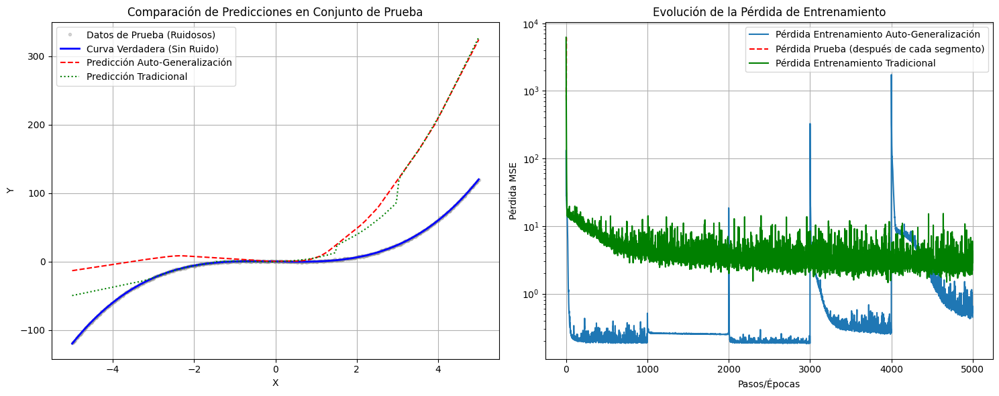


--- Resumen Final de Pérdidas en Conjunto de Prueba ---
Modelo Auto-Generalización: 6177.504162
Modelo Tradicional: 5331.830477


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, Subset
import numpy as np
import torch.nn.functional as F # Import the functional module with alias F

# --- 1. Dataset Sintético Progresivo ---
def create_synthetic_data_segments(num_samples_per_segment=100, num_segments=5):
    all_X = []
    all_y = []

    # Cada segmento tendrá una pequeña variación en la función
    # y = (X + offset)^3 - (X + offset) + ruido
    for i in range(num_segments):
        offset = i * 0.5 # Aumentar el offset para cada segmento

        # Generar X dentro de un rango específico para cada segmento
        # Así, cada segmento cubre una parte diferente del dominio, forzando la generalización
        start_x = -3 + i * 1.5
        end_x = start_x + 1.5

        X_segment = torch.linspace(start_x, end_x, num_samples_per_segment).unsqueeze(1)
        y_segment = (X_segment + offset).pow(3) - (X_segment + offset) + 0.5 * torch.randn(X_segment.size())

        all_X.append(X_segment)
        all_y.append(y_segment)

    return all_X, all_y # Lista de tensores para cada segmento

# Crear los segmentos de datos
X_segments, y_segments = create_synthetic_data_segments(num_samples_per_segment=200, num_segments=5)

# Crear un conjunto de prueba final que el modelo NUNCA ve durante el entrenamiento
X_test = torch.linspace(-5, 5, 500).unsqueeze(1)
y_test = X_test.pow(3) - X_test + 0.5 * torch.randn(X_test.size())
test_dataset = TensorDataset(X_test, y_test)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


# --- 2. Modelo (MLP simple) ---
class SimpleMLP(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        out = self.output_layer(h2)
        return out

# --- 3. Bucle de Entrenamiento para Auto-Generalización ---
def train_auto_generalization(model, X_segments, y_segments, test_loader, epochs_per_segment=500, lr=0.01, loss_threshold=0.1):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    all_training_losses = []
    test_losses_per_segment = [] # Esta lista se retorna como test_losses_auto_gen

    for i, (X_seg, y_seg) in enumerate(zip(X_segments, y_segments)):
        print(f"\n--- Fase de Aprendizaje: Segmento {i+1} de {len(X_segments)} ---")

        # Convertir el segmento a DataLoader
        segment_dataset = TensorDataset(X_seg, y_seg)
        segment_loader = DataLoader(segment_dataset, batch_size=32, shuffle=True)

        current_segment_losses = []
        for epoch in range(epochs_per_segment):
            model.train()
            epoch_loss = 0.0
            for batch_X, batch_y in segment_loader:
                optimizer.zero_grad()
                pred_y = model(batch_X)
                loss = loss_fn(pred_y, batch_y)
                loss.backward()
                optimizer.step()
                epoch_loss += loss.item() * batch_X.size(0)

            avg_epoch_loss = epoch_loss / len(segment_dataset)
            current_segment_losses.append(avg_epoch_loss)
            all_training_losses.append(avg_epoch_loss)

            if epoch % 100 == 0:
                print(f"Segmento {i+1}, Época {epoch}: Pérdida = {avg_epoch_loss:.6f}")

            # Criterio de avance: si la pérdida es suficientemente baja
            if avg_epoch_loss < loss_threshold and epoch > 100: # Para evitar que termine muy rápido
                print(f"Umbral de pérdida alcanzado para el segmento {i+1}. Avanzando...")
                break

        # Evaluar en el conjunto de prueba completo después de cada segmento
        model.eval()
        total_test_loss = 0.0
        with torch.no_grad():
            for batch_X_test, batch_y_test in test_loader:
                pred_y_test = model(batch_X_test)
                loss_test = loss_fn(pred_y_test, batch_y_test)
                total_test_loss += loss_test.item() * batch_X_test.size(0)

        avg_test_loss = total_test_loss / len(test_dataset)
        test_losses_per_segment.append(avg_test_loss)
        print(f"Pérdida en el conjunto de prueba (después del segmento {i+1}): {avg_test_loss:.6f}")

    # Return the training losses for all epochs and the test losses after each segment
    return all_training_losses, test_losses_per_segment

# --- Ejecución del Experimento ---
input_size = 1
hidden_size = 64
output_size = 1

model_auto_gen = SimpleMLP(input_size, hidden_size, output_size)
# Correctly assign the returned values
training_losses_auto_gen, test_losses_auto_gen = train_auto_generalization(
    model_auto_gen, X_segments, y_segments, test_loader,
    epochs_per_segment=1000, lr=0.005, loss_threshold=0.05 # Ajustar umbral y épocas
)

# --- Comparación con Entrenamiento Tradicional (con todo el dataset) ---
print("\n--- Entrenando Modelo con Enfoque Tradicional (Dataset completo) ---")
X_full = torch.cat(X_segments, dim=0)
y_full = torch.cat(y_segments, dim=0) # Cambiado de dim0 a dim=0
full_dataset = TensorDataset(X_full, y_full)
full_loader = DataLoader(full_dataset, batch_size=32, shuffle=True)

model_traditional = SimpleMLP(input_size, hidden_size, output_size)
optimizer_traditional = optim.Adam(model_traditional.parameters(), lr=0.005)
loss_fn = nn.MSELoss()
traditional_training_losses = []

for epoch in range(len(X_segments) * 1000): # Mismo número total de épocas que el enfoque auto-generalización
    model_traditional.train()
    epoch_loss = 0.0
    for batch_X, batch_y in full_loader:
        optimizer_traditional.zero_grad()
        pred_y = model_traditional(batch_X)
        loss = loss_fn(pred_y, batch_y)
        loss.backward()
        optimizer_traditional.step()
        epoch_loss += loss.item() * batch_X.size(0)

    avg_epoch_loss = epoch_loss / len(full_dataset)
    traditional_training_losses.append(avg_epoch_loss)

    if epoch % 500 == 0:
        print(f"Tradicional, Época {epoch}: Pérdida = {avg_epoch_loss:.6f}")

# Evaluar modelo tradicional en el conjunto de prueba final
model_traditional.eval()
total_test_loss_traditional = 0.0
with torch.no_grad():
    for batch_X_test, batch_y_test in test_loader:
        pred_y_test = model_traditional(batch_X_test)
        loss_test = loss_fn(pred_y_test, batch_y_test)
        total_test_loss_traditional += loss_test.item() * batch_X_test.size(0)
avg_test_loss_traditional = total_test_loss_traditional / len(test_dataset)
print(f"Pérdida final en el conjunto de prueba (Modelo Tradicional): {avg_test_loss_traditional:.6f}")


# --- Visualización de Resultados ---
import matplotlib.pyplot as plt

# Predicciones finales
model_auto_gen.eval()
model_traditional.eval()
with torch.no_grad():
    pred_auto_gen = model_auto_gen(X_test).cpu().numpy()
    pred_traditional = model_traditional(X_test).cpu().numpy()

X_test_np = X_test.cpu().numpy()
y_test_np = y_test.cpu().numpy()
y_true_func = X_test.pow(3) - X_test # Curva sin ruido

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.plot(X_test_np, y_test_np, 'o', label="Datos de Prueba (Ruidosos)", color='gray', alpha=0.3, markersize=3)
plt.plot(X_test_np, y_true_func.cpu().numpy(), label="Curva Verdadera (Sin Ruido)", color='blue', linewidth=2)
plt.plot(X_test_np, pred_auto_gen, label="Predicción Auto-Generalización", color='red', linestyle='--')
plt.plot(X_test_np, pred_traditional, label="Predicción Tradicional", color='green', linestyle=':')
plt.title("Comparación de Predicciones en Conjunto de Prueba")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(training_losses_auto_gen, label="Pérdida Entrenamiento Auto-Generalización")
# Changed test_losses_per_segment to test_losses_auto_gen
plt.plot(test_losses_auto_gen, label="Pérdida Prueba (después de cada segmento)", linestyle='--', color='red')
plt.plot(traditional_training_losses, label="Pérdida Entrenamiento Tradicional", color='green')
plt.title("Evolución de la Pérdida de Entrenamiento")
plt.xlabel("Pasos/Épocas")
plt.ylabel("Pérdida MSE")
plt.yscale('log')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"\n--- Resumen Final de Pérdidas en Conjunto de Prueba ---")
print(f"Modelo Auto-Generalización: {test_losses_auto_gen[-1]:.6f}")
print(f"Modelo Tradicional: {avg_test_loss_traditional:.6f}")

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class CrossInteractionUnit(nn.Module):
    """
    Unidad de Interacción Cruzada (CIU) para permitir que los streams se influyan mutuamente.
    Podría ser una pequeña red de atención o una simple capa lineal y activación.
    """
    def __init__(self, query_dim, key_dim, value_dim, output_dim, num_heads=4):
        super().__init__()
        # Usaremos Multi-Head Attention para permitir una interacción rica
        # Note: embed_dim for MultiheadAttention is the dimension of the query, key, and value after projection
        self.attention = nn.MultiheadAttention(embed_dim=query_dim, num_heads=num_heads, batch_first=True)
        self.norm = nn.LayerNorm(query_dim)
        self.linear = nn.Linear(query_dim, output_dim) # Para mapear la salida a la dimensión deseada

        # Mapeo lineal para que el "key" y "value" tengan el mismo embed_dim que el "query"
        # Their input dimensions are key_dim and value_dim, output is query_dim
        self.key_proj = nn.Linear(key_dim, query_dim)
        self.value_proj = nn.Linear(value_dim, query_dim) # If key_dim != value_dim

    def forward(self, query_state, influencing_state):
        # query_state: El estado que será influenciado (ej. h_p_t) [batch, query_dim]
        # influencing_state: El estado que influye (ej. h_c_t) [batch, key_dim or value_dim]

        # Expandir las dimensiones para la atención si es necesario (ej. para batch_first=True)
        query = query_state.unsqueeze(1) # [batch, 1, query_dim]
        key = self.key_proj(influencing_state).unsqueeze(1)   # [batch, 1, query_dim]
        value = self.value_proj(influencing_state).unsqueeze(1) # [batch, 1, query_dim]

        # attn_output will be [batch, 1, query_dim]
        attn_output, _ = self.attention(query, key, value)
        attn_output = attn_output.squeeze(1) # [batch, query_dim]

        # Combinar el resultado de la atención con el query original (residual connection)
        # Ensure shapes match for addition: query_state [batch, query_dim] + attn_output [batch, query_dim]
        output = self.norm(query_state + attn_output)

        # Apply final linear layer and activation
        output = F.relu(self.linear(output)) # Output shape: [batch, output_dim]
        return output

class DReGCell(nn.Module):
    """
    La celda central del Generador de Texto Recurrente Dual (D-ReG).
    Se ejecuta una vez por cada token generado.
    """
    def __init__(self, embed_dim, hidden_dim_p, hidden_dim_c, num_heads_p=8, ff_dim_p=2048, num_layers_p=1):
        super().__init__()
        self.embed_dim = embed_dim
        self.hidden_dim_p = hidden_dim_p
        self.hidden_dim_c = hidden_dim_c

        # P-Stream (Percepción): Un bloque de Transformer Decoder (con auto-atención)
        # Aquí simplificamos a un Attention y Feedforward para el ejemplo
        # The attention mechanism operates on the embedding dimension
        self.p_self_attn = nn.MultiheadAttention(embed_dim, num_heads_p, batch_first=True)
        self.p_ffn = nn.Sequential(
            nn.Linear(embed_dim, ff_dim_p),
            nn.ReLU(),
            nn.Linear(ff_dim_p, embed_dim)
        )
        self.p_norm1 = nn.LayerNorm(embed_dim)
        self.p_norm2 = nn.LayerNorm(embed_dim)

        # C-Stream (Conceptualización): Un GRU o LSTM para mantener el estado conceptual
        # Recibe input del P-Stream y su propio estado anterior
        # Input size should be the dimension of the input it receives (from p_to_c_ciu output)
        # Hidden size should be the dimension of the conceptual state h_c
        # FIX: Set GRU input_size to hidden_dim_c to match p_to_c_ciu output dimension
        self.c_gru = nn.GRUCell(hidden_dim_c, hidden_dim_c) # Input: output de p_to_c_ciu [batch, hidden_dim_c], hidden: h_c_prev [batch, hidden_dim_c]

        # Cross-Interaction Units (CIU)
        # P-Stream influye en C-Stream (para ajustar la conceptualización basada en la percepción)
        # Query: h_c_prev [batch, hidden_dim_c] -> query_dim=hidden_dim_c
        # Influencing: h_p_curr [batch, embed_dim] -> key_dim=embed_dim, value_dim=embed_dim
        # Output needs to be input for GRU -> output_dim=hidden_dim_c
        self.p_to_c_ciu = CrossInteractionUnit(query_dim=hidden_dim_c, key_dim=embed_dim, value_dim=embed_dim, output_dim=hidden_dim_c)
        # C-Stream influye en P-Stream (para guiar la percepción basada en la conceptualización)
        # Query: h_p_prev [batch, embed_dim] -> query_dim=embed_dim
        # Influencing: h_c_prev [batch, hidden_dim_c] -> key_dim=hidden_dim_c, value_dim=hidden_dim_c
        # Output needs to be combined with token embedding -> output_dim=embed_dim
        self.c_to_p_ciu = CrossInteractionUnit(query_dim=embed_dim, key_dim=hidden_dim_c, value_dim=hidden_dim_c, output_dim=embed_dim)

    def forward(self, prev_token_embedding, h_p_prev, h_c_prev):
        # prev_token_embedding: Embedding del token generado en el paso anterior [batch, embed_dim]
        # h_p_prev: Estado oculto anterior del P-Stream [batch, embed_dim]
        # h_c_prev: Estado oculto anterior del C-Stream [batch, hidden_dim_c]

        # 1. P-Stream (Percepción)
        # h_p_prev influenciado por h_c_prev
        # The CIU expects h_p_prev as query_state and h_c_prev as influencing_state
        modulated_h_p_prev = self.c_to_p_ciu(h_p_prev, h_c_prev) # C-Stream guía P-Stream [batch, embed_dim]

        # Input to P-Stream attention: should consider both token embedding and modulated state
        # A simple approach is to combine them, or use them as part of the attention mechanism.
        # Here, we'll use the modulated state as the base and add the token embedding's contribution.
        # A more complex Transformer Decoder would handle this differently.
        # For simplicity in this DReGCell, let's assume the P-Stream self-attention
        # primarily processes the modulated state, guided by the current input token.
        # The line below is a simplification for this cell structure.
        p_input_for_attn = (modulated_h_p_prev + prev_token_embedding).unsqueeze(1) # [batch, 1, embed_dim]


        # Self-attention for the P-Stream.
        # In a decoder real, it would be causal attention over the sequence generated so far.
        # For this cell example, we perform attention on a single timestep input (combined state/token).
        # The output dim of attention is embed_dim, matching the query_dim passed to MultiheadAttention
        p_output_attn, _ = self.p_self_attn(p_input_for_attn, p_input_for_attn, p_input_for_attn) # [batch, 1, embed_dim]
        p_output_attn = p_output_attn.squeeze(1) # [batch, embed_dim]

        # Residual connection and Normalization
        # p_output_attn represents the perception at this step. Combine with previous state influence.
        p_output = self.p_norm1(p_output_attn) # Apply norm after attention

        # Feedforward for P-Stream
        p_output = self.p_norm2(p_output + self.p_ffn(p_output)) # [batch, embed_dim]
        h_p_curr = p_output # This is the new state of the P-Stream [batch, embed_dim]

        # 2. C-Stream (Conceptualization)
        # h_c_prev influenced by h_p_curr
        # The output of the P-Stream influences the C-Stream
        # The CIU expects h_c_prev as query_state and h_p_curr as influencing_state
        # The output dimension of p_to_c_ciu is hidden_dim_c
        c_input_from_p = self.p_to_c_ciu(h_c_prev, h_p_curr) # P-Stream adjusts C-Stream [batch, hidden_dim_c]

        # GRU to update the conceptual state.
        # The input to the GRU is the influence from the P-Stream (c_input_from_p).
        # The hidden state is h_c_prev.
        # Both inputs to GRUCell should have the dimension hidden_dim_c (256)
        h_c_curr = self.c_gru(c_input_from_p, h_c_prev) # [batch, hidden_dim_c]

        return h_p_curr, h_c_curr

class DReG(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim_p, hidden_dim_c, num_heads_enc=8, ff_dim_enc=2048, num_layers_enc=6):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        # Position embedding size should be sufficient for max sequence length including prompt and generation
        self.position_embedding = nn.Embedding(512 + 50, embed_dim) # Max seq len + max generated len
        self.embed_dim = embed_dim
        self.vocab_size = vocab_size
        self.hidden_dim_c = hidden_dim_c # Keep track for initializing h_c_prev

        # Encoder (Transformer estándar) para el prompt inicial
        encoder_layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads_enc, dim_feedforward=ff_dim_enc, batch_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers_enc)

        # The D-ReG cell that will be executed sequentially
        self.dreg_cell = DReGCell(embed_dim, hidden_dim_p, hidden_dim_c)

        # Final projection layer to vocabulary
        # Output is based on the P-Stream state (perception)
        self.output_linear = nn.Linear(hidden_dim_p, vocab_size) # Predict next token from P-Stream state

    def forward(self, input_ids, prompt_mask=None, max_seq_len=50):
        # input_ids: [batch, seq_len_prompt] - the initial prompt
        batch_size = input_ids.size(0)
        seq_len_prompt = input_ids.size(1)

        # 1. Process the prompt with the Encoder
        # Position embeddings should start from 0 for the prompt
        positions = torch.arange(seq_len_prompt, device=input_ids.device).unsqueeze(0).expand(batch_size, -1)
        input_embeddings = self.token_embedding(input_ids) + self.position_embedding(positions)

        encoder_output = self.encoder(input_embeddings, src_key_padding_mask=prompt_mask)

        # Initialize P-Stream and C-Stream states from encoder output
        # h_p_prev is initialized from the last token of the encoder output [batch, embed_dim]
        h_p_prev = encoder_output[:, -1, :].contiguous()

        # h_c_prev initialized with zeros or a projection from encoder output
        # Its dimension should match hidden_dim_c
        h_c_prev = torch.zeros(batch_size, self.hidden_dim_c, device=input_ids.device) # [batch, hidden_dim_c]

        # The first token embedding for the generation loop is from the last token of the prompt
        next_token_embedding = self.token_embedding(input_ids[:, -1]) # [batch, embed_dim]

        generated_tokens_list = [] # Store generated token IDs step by step

        # 2. Generation Loop
        for i in range(max_seq_len):
            # Execute the D-ReG cell
            # Inputs: next_token_embedding [batch, embed_dim], h_p_prev [batch, embed_dim], h_c_prev [batch, hidden_dim_c]
            h_p_curr, h_c_curr = self.dreg_cell(next_token_embedding, h_p_prev, h_c_prev)

            # Project the output of the P-Stream (h_p_curr) to vocabulary probabilities
            # Output dimension should match hidden_dim_p (or embed_dim depending on model design)
            # FIX: Use h_p_curr which has shape [batch, hidden_dim_p] as input to output_linear
            logits = self.output_linear(h_p_curr) # [batch, vocab_size]
            probabilities = F.softmax(logits, dim=-1)

            # Sample the next token (or take argmax for deterministic inference)
            next_token = torch.argmax(probabilities, dim=-1) # [batch]
            generated_tokens_list.append(next_token.unsqueeze(1)) # [batch, 1]

            # Prepare for the next step
            next_token_embedding = self.token_embedding(next_token) # [batch, embed_dim]
            h_p_prev = h_p_curr # Update P-Stream state for next iteration
            h_c_prev = h_c_curr # Update C-Stream state for next iteration

            # Optional: Stop if EOS token is generated - not implemented here

        # Concatenate the generated tokens
        generated_tokens = torch.cat(generated_tokens_list, dim=1) # [batch, max_seq_len]

        # Combine prompt and generated tokens (optional, depending on desired output format)
        # full_sequence = torch.cat([input_ids, generated_tokens], dim=1) # [batch, seq_len_prompt + max_seq_len]
        return generated_tokens # Return only the generated part


# --- Example Usage and Parameters ---
vocab_size = 10000 # Vocabulary size
embed_dim = 512    # Embedding dimensionality
hidden_dim_p = 512 # Hidden dimension of the P-Stream (Transformer-like)
hidden_dim_c = 256 # Hidden dimension of the C-Stream (GRU-like, conceptual summary)

# Ensure hidden_dim_p matches embed_dim if P-Stream state is embed_dim,
# or adjust output_linear if h_p_curr is hidden_dim_p and it's different from embed_dim.
# Based on DReGCell forward, h_p_curr is embed_dim.
# So output_linear should take embed_dim as input.
# FIX: Change output_linear input dim to embed_dim
class DReG(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim_p, hidden_dim_c, num_heads_enc=8, ff_dim_enc=2048, num_layers_enc=6):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        # Position embedding size should be sufficient for max sequence length including prompt and generation
        self.position_embedding = nn.Embedding(512 + 50, embed_dim) # Max seq len + max generated len
        self.embed_dim = embed_dim
        self.vocab_size = vocab_size
        self.hidden_dim_c = hidden_dim_c # Keep track for initializing h_c_prev

        # Encoder (Transformer estándar) para el prompt inicial
        encoder_layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads_enc, dim_feedforward=ff_dim_enc, batch_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers_enc)

        # The D-ReG cell that will be executed sequentially
        # hidden_dim_p is not explicitly used as state size in DReGCell based on its current forward.
        # h_p_prev and h_p_curr are embed_dim. hidden_dim_p might be intended for ff_dim_p?
        # Let's keep it consistent with the original definition but note the potential discrepancy
        # if hidden_dim_p was meant to be the state size of the P-stream.
        self.dreg_cell = DReGCell(embed_dim, hidden_dim_p, hidden_dim_c) # embed_dim for p_state_size, hidden_dim_p for ff_dim_p

        # Final projection layer to vocabulary
        # Output is based on the P-Stream state (perception), which is h_p_curr
        # h_p_curr has shape [batch, embed_dim] based on DReGCell forward
        # FIX: Output linear takes embed_dim as input
        self.output_linear = nn.Linear(embed_dim, vocab_size) # Predict next token from P-Stream state

    def forward(self, input_ids, prompt_mask=None, max_seq_len=50):
        # input_ids: [batch, seq_len_prompt] - the initial prompt
        batch_size = input_ids.size(0)
        seq_len_prompt = input_ids.size(1)

        # 1. Process the prompt with the Encoder
        # Position embeddings should start from 0 for the prompt
        positions = torch.arange(seq_len_prompt, device=input_ids.device).unsqueeze(0).expand(batch_size, -1)
        input_embeddings = self.token_embedding(input_ids) + self.position_embedding(positions)

        encoder_output = self.encoder(input_embeddings, src_key_padding_mask=prompt_mask)

        # Initialize P-Stream and C-Stream states from encoder output
        # h_p_prev is initialized from the last token of the encoder output [batch, embed_dim]
        h_p_prev = encoder_output[:, -1, :].contiguous()

        # h_c_prev initialized with zeros or a projection from encoder output
        # Its dimension should match hidden_dim_c
        h_c_prev = torch.zeros(batch_size, self.hidden_dim_c, device=input_ids.device) # [batch, hidden_dim_c]

        # The first token embedding for the generation loop is from the last token of the prompt
        next_token_embedding = self.token_embedding(input_ids[:, -1]) # [batch, embed_dim]

        generated_tokens_list = [] # Store generated token IDs step by step

        # 2. Generation Loop
        for i in range(max_seq_len):
            # Execute the D-ReG cell
            # Inputs: next_token_embedding [batch, embed_dim], h_p_prev [batch, embed_dim], h_c_prev [batch, hidden_dim_c]
            h_p_curr, h_c_curr = self.dreg_cell(next_token_embedding, h_p_prev, h_c_prev)

            # Project the output of the P-Stream (h_p_curr) to vocabulary probabilities
            # h_p_curr has shape [batch, embed_dim]
            logits = self.output_linear(h_p_curr) # [batch, vocab_size]
            probabilities = F.softmax(logits, dim=-1)

            # Sample the next token (or take argmax for deterministic inference)
            next_token = torch.argmax(probabilities, dim=-1) # [batch]
            generated_tokens_list.append(next_token.unsqueeze(1)) # [batch, 1]

            # Prepare for the next step
            next_token_embedding = self.token_embedding(next_token) # [batch, embed_dim]
            h_p_prev = h_p_curr # Update P-Stream state for next iteration
            h_c_prev = h_c_curr # Update C-Stream state for next iteration

            # Optional: Stop if EOS token is generated - not implemented here

        # Concatenate the generated tokens
        generated_tokens = torch.cat(generated_tokens_list, dim=1) # [batch, max_seq_len]

        # Combine prompt and generated tokens (optional, depending on desired output format)
        # full_sequence = torch.cat([input_ids, generated_tokens], dim=1) # [batch, seq_len_prompt + max_seq_len]
        return generated_tokens # Return only the generated part


# --- Example Usage and Parámetros ---
vocab_size = 10000 # Tamaño del vocabulario
embed_dim = 512    # Dimensionalidad de embeddings
hidden_dim_p = 512 # Dimensión oculta del P-Stream (ff_dim_p in DReGCell)
hidden_dim_c = 256 # Dimensión oculta del C-Stream (GRU hidden size)


# Instantiate the model
# The arguments to DReGCell are embed_dim, hidden_dim_p (used as ff_dim_p), hidden_dim_c
model = DReG(vocab_size, embed_dim, hidden_dim_p, hidden_dim_c).to('cpu') # Usar CPU para ejemplo
print(model)

# Example prompt (token IDs)
dummy_prompt_ids = torch.randint(0, vocab_size, (2, 10)) # Batch of 2, prompt of 10 tokens
generated_output = model(dummy_prompt_ids, max_seq_len=20)
print(f"\nForma de la salida generada (IDs de tokens): {generated_output.shape}")

# Parameter count
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Número total de parámetros: {total_params}")

DReG(
  (token_embedding): Embedding(10000, 512)
  (position_embedding): Embedding(562, 512)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-5): 6 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
        )
        (linear1): Linear(in_features=512, out_features=2048, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=2048, out_features=512, bias=True)
        (norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (dreg_cell): DReGCell(
    (p_self_attn): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
    )
    (p_ffn): Sequential(
      (0)

#h

Tu observación es interesante, pero es importante aclarar que el código que me proporcionaste, y sobre el que estamos trabajando, **no está diseñado para procesar imágenes directamente**.

---

### ¿Qué hace tu código actualmente?

El código que has compartido trabaja con un **dataset sintético de regresión no lineal**, donde `X` es un tensor de una sola característica (números que van de -3 a 3) y `y` es el resultado de una función cúbica de `X` más algo de ruido.

Las redes neuronales (`RedCaracteristicasDensaEntrada` y `RedEstandar`) que implementas son **redes neuronales de tipo `nn.Linear` (fully connected o densas)**. Estas capas están diseñadas para procesar datos tabulares o vectores, no imágenes con su estructura espacial (altura, anchura, canales de color).

Aunque estas redes extraen "características" en el sentido de que transforman la entrada a través de sus capas ocultas, el objetivo aquí es aprender la relación matemática entre `X` y `y` para realizar una **predicción de regresión**, no para reconocer objetos o patrones en una imagen.

---

### ¿Por qué no está procesando imágenes?

1.  **Tipo de datos de entrada:** `X` es un tensor de forma `(300, 1)`, lo que significa 300 muestras, cada una con 1 característica. Una imagen suele ser un tensor 3D (altura x anchura x canales) o 4D (número de imágenes x canales x altura x anchura).
2.  **Arquitectura de la red:** Las capas `nn.Linear` simplemente realizan una multiplicación de matriz y una suma de sesgo. No tienen las operaciones especiales (como convoluciones o pooling) que se usan en las redes neuronales convolucionales (CNNs) para extraer características espaciales de las imágenes y preservar su estructura.
3.  **Función de salida:** La capa de salida (`output_layer`) tiene `output_size=1`, lo que es típico para una regresión de un solo valor, no para generar una imagen o una representación dimensional de ella.
4.  **Visualización:** Los gráficos que se generan muestran la curva de predicción de la regresión, no imágenes.

---

### ¿Cómo se adaptarían para imágenes?

Para que estas redes **extrajeran características de una imagen y luego las "dimensionalizaran para ser mostradas como imagen"** (lo que implicaría una tarea de reconstrucción de imagen o generación), necesitarías:

1.  **Cambiar el dataset:** Cargar imágenes reales (por ejemplo, con `torchvision.datasets`).
2.  **Cambiar la arquitectura:**
    * Reemplazar las capas `nn.Linear` por **capas convolucionales (`nn.Conv2d`)** al inicio para la extracción de características espaciales.
    * Podrías seguir usando ideas de conexiones densas (como en DenseNet) con capas convolucionales.
    * Para la "re-dimensionalización" y mostrar como imagen, necesitarías **capas de convolución transpuesta (`nn.ConvTranspose2d`)** o capas de **upsampling** para reconstruir la resolución espacial de una imagen a partir de un conjunto de características latentes.
3.  **Cambiar la función de pérdida:** Si el objetivo es reconstruir una imagen, la función de pérdida podría ser MSE (como ahora, pero aplicada a píxeles de imagen) o alguna pérdida perceptiva.
4.  **Cambiar la visualización:** Mostrar las imágenes originales y las imágenes reconstruidas o generadas.

En resumen, el código actual no hace lo que describes para imágenes, sino que resuelve un problema de regresión de datos numéricos. Para procesar imágenes, la arquitectura y el enfoque deberían ser fundamentalmente diferentes, empleando técnicas específicas para datos de imagen.

--- Entrenando Red con Extracción de Características Densa desde la Entrada ---
Densa Entrada - Época 0 - Pérdida: 73.037971
Densa Entrada - Época 50 - Pérdida: 10.527452
Densa Entrada - Época 100 - Pérdida: 0.903317
Densa Entrada - Época 150 - Pérdida: 0.320687
Densa Entrada - Época 200 - Pérdida: 0.246943
Densa Entrada - Época 250 - Pérdida: 0.223568

--- Entrenando Red Estándar ---
Estándar - Época 0 - Pérdida: 77.712578
Estándar - Época 50 - Pérdida: 10.899455
Estándar - Época 100 - Pérdida: 1.411472
Estándar - Época 150 - Pérdida: 0.391896
Estándar - Época 200 - Pérdida: 0.269028
Estándar - Época 250 - Pérdida: 0.241571


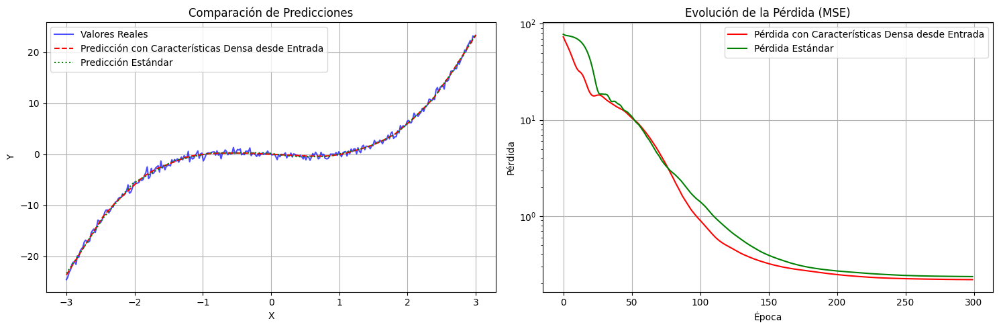


--- Resumen de Pérdidas Finales ---
Pérdida final (Red con Características Densa desde Entrada): 0.218581
Pérdida final (Red Estándar):                                0.235032


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Dataset sintético (regresión no lineal) ---
torch.manual_seed(0)
np.random.seed(0)
X = torch.linspace(-3, 3, 300).unsqueeze(1)
y = X.pow(3) - X + 0.5 * torch.randn(X.size())



## Red con Extracción de Características Densa desde la Entrada



class RedCaracteristicasDensaEntrada(nn.Module):
    def __init__(self, input_size, hidden_size1, hidden_size2, hidden_size3, output_size):
        super().__init__()
        self.input_size = input_size # Guardamos el tamaño de entrada

        # Capa 1: Conectada a la entrada
        self.fc1 = nn.Linear(input_size, hidden_size1)

        # Capa 2: Recibe de Capa 1 Y de la entrada original
        # La entrada para fc2 será (hidden_size1 + input_size)
        self.fc2 = nn.Linear(hidden_size1 + input_size, hidden_size2)

        # Capa 3: Recibe de Capa 1, Capa 2 Y de la entrada original
        # La entrada para fc3 será (hidden_size1 + hidden_size2 + input_size)
        self.fc3 = nn.Linear(hidden_size1 + hidden_size2 + input_size, hidden_size3)

        # Capa de Salida: Recibe de Capa 1, Capa 2, Capa 3 Y de la entrada original
        # La entrada para la capa de salida será (hidden_size1 + hidden_size2 + hidden_size3 + input_size)
        self.output_layer = nn.Linear(hidden_size1 + hidden_size2 + hidden_size3 + input_size, output_size)

    def forward(self, x):
        # x_original es la entrada que se concatenará en cada paso
        x_original = x # [batch, input_size]

        # Capa 1
        h1 = F.relu(self.fc1(x_original)) # [batch, hidden_size1]

        # Capa 2: Entrada es la concatenación de h1 y x_original
        h2_input = torch.cat((h1, x_original), dim=1) # [batch, hidden_size1 + input_size]
        h2 = F.relu(self.fc2(h2_input)) # [batch, hidden_size2]

        # Capa 3: Entrada es la concatenación de h1, h2 y x_original
        h3_input = torch.cat((h1, h2, x_original), dim=1) # [batch, hidden_size1 + hidden_size2 + input_size]
        h3 = F.relu(self.fc3(h3_input)) # [batch, hidden_size3]

        # Capa de Salida: Entrada es la concatenación de h1, h2, h3 y x_original
        output_input = torch.cat((h1, h2, h3, x_original), dim=1) # [batch, hidden_size1 + hidden_size2 + hidden_size3 + input_size]

        y = self.output_layer(output_input)
        return y

class RedEstandar(nn.Module):
    def __init__(self, input_size, hidden_size1, hidden_size2, hidden_size3, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size1)
        self.fc2 = nn.Linear(hidden_size1, hidden_size2)
        self.fc3 = nn.Linear(hidden_size2, hidden_size3)
        self.output_layer = nn.Linear(hidden_size3, output_size)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        h3 = F.relu(self.fc3(h2))
        y = self.output_layer(h3)
        return y


LEARNING_RATE = 0.01
EPOCHS = 300
LOSS_FN = nn.MSELoss()

HIDDEN_SIZE_1 = 32
HIDDEN_SIZE_2 = 16
HIDDEN_SIZE_3 = 8

print("--- Entrenando Red con Extracción de Características Densa desde la Entrada ---")
modelo_densa_entrada = RedCaracteristicasDensaEntrada(
    input_size=X.shape[1],
    hidden_size1=HIDDEN_SIZE_1,
    hidden_size2=HIDDEN_SIZE_2,
    hidden_size3=HIDDEN_SIZE_3,
    output_size=y.shape[1]
)
opt_densa_entrada = torch.optim.Adam(modelo_densa_entrada.parameters(), lr=LEARNING_RATE)
historial_loss_densa_entrada = []

for epoch in range(EPOCHS):
    y_pred = modelo_densa_entrada(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_densa_entrada.append(loss.item())
    opt_densa_entrada.zero_grad()
    loss.backward()
    opt_densa_entrada.step()
    if epoch % 50 == 0:
        print(f"Densa Entrada - Época {epoch} - Pérdida: {loss.item():.6f}")

print("\n--- Entrenando Red Estándar ---")
modelo_estandar = RedEstandar(
    input_size=X.shape[1],
    hidden_size1=HIDDEN_SIZE_1,
    hidden_size2=HIDDEN_SIZE_2,
    hidden_size3=HIDDEN_SIZE_3,
    output_size=y.shape[1]
)
opt_estandar = torch.optim.Adam(modelo_estandar.parameters(), lr=LEARNING_RATE)
historial_loss_estandar = []

for epoch in range(EPOCHS):
    y_pred = modelo_estandar(X)
    loss = LOSS_FN(y_pred, y)
    historial_loss_estandar.append(loss.item())
    opt_estandar.zero_grad()
    loss.backward()
    opt_estandar.step()
    if epoch % 50 == 0:
        print(f"Estándar - Época {epoch} - Pérdida: {loss.item():.6f}")

with torch.no_grad():
    y_hat_densa_entrada = modelo_densa_entrada(X).numpy()
    y_hat_estandar = modelo_estandar(X).numpy()

X_np = X.numpy()
y_np = y.numpy()

plt.figure(figsize=(15, 5))

# Gráfico de Predicciones
plt.subplot(1, 2, 1)
plt.title("Comparación de Predicciones")
plt.plot(X_np, y_np, label="Valores Reales", color='blue', alpha=0.7)
plt.plot(X_np, y_hat_densa_entrada, label="Predicción con Características Densa desde Entrada", color='red', linestyle='--')
plt.plot(X_np, y_hat_estandar, label="Predicción Estándar", color='green', linestyle=':')
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)

# Gráfico de Evolución de la Pérdida
plt.subplot(1, 2, 2)
plt.title("Evolución de la Pérdida (MSE)")
plt.plot(historial_loss_densa_entrada, label="Pérdida con Características Densa desde Entrada", color='red')
plt.plot(historial_loss_estandar, label="Pérdida Estándar", color='green')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)
plt.yscale('log') # Escala logarítmica para una mejor visualización
plt.tight_layout()
plt.show()

# Resumen Final de la Pérdida
print(f"\n--- Resumen de Pérdidas Finales ---")
print(f"Pérdida final (Red con Características Densa desde Entrada): {historial_loss_densa_entrada[-1]:.6f}")
print(f"Pérdida final (Red Estándar):                                {historial_loss_estandar[-1]:.6f}")

--- Entrenando CNN Estándar ---
Epoch: 0, Batch: 0, Loss: 0.230647
Epoch: 0, Batch: 100, Loss: 0.057494
Epoch: 0, Batch: 200, Loss: 0.035766
Epoch: 0, Batch: 300, Loss: 0.025384
Epoch: 0, Batch: 400, Loss: 0.020796
Epoch: 0, Batch: 500, Loss: 0.019079
Epoch: 0, Batch: 600, Loss: 0.016680
Epoch: 0, Batch: 700, Loss: 0.016324
Epoch: 0, Batch: 800, Loss: 0.012175
Epoch: 0, Batch: 900, Loss: 0.011698
Epoch: 1, Batch: 0, Loss: 0.011241
Epoch: 1, Batch: 100, Loss: 0.012405
Epoch: 1, Batch: 200, Loss: 0.011856
Epoch: 1, Batch: 300, Loss: 0.010244
Epoch: 1, Batch: 400, Loss: 0.010030
Epoch: 1, Batch: 500, Loss: 0.009837
Epoch: 1, Batch: 600, Loss: 0.010514
Epoch: 1, Batch: 700, Loss: 0.009588
Epoch: 1, Batch: 800, Loss: 0.009751
Epoch: 1, Batch: 900, Loss: 0.009220

--- Entrenando CNN Experimental ---
Epoch: 0, Batch: 0, Loss: 0.231592
Epoch: 0, Batch: 100, Loss: 0.052108
Epoch: 0, Batch: 200, Loss: 0.032588
Epoch: 0, Batch: 300, Loss: 0.024989
Epoch: 0, Batch: 400, Loss: 0.019527
Epoch: 0, Ba

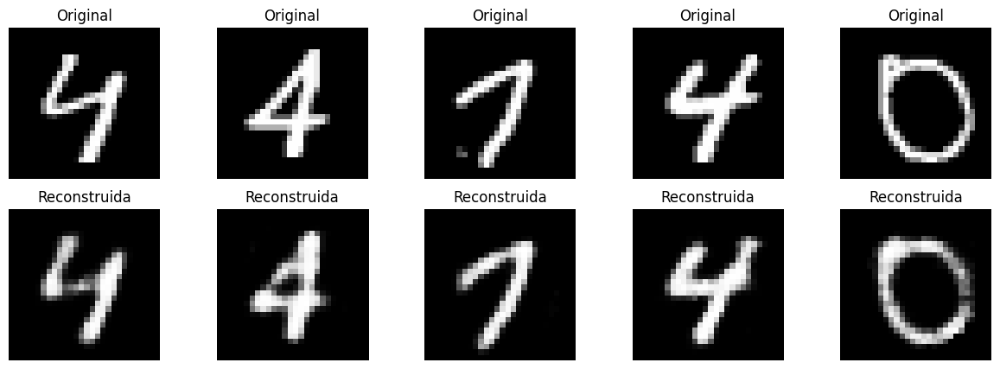


--- Visualizando resultados de CNN Experimental ---


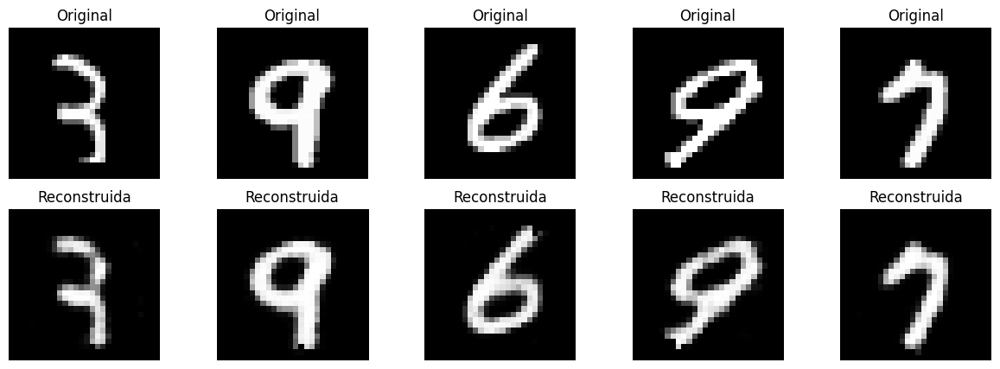

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Definición de las Arquitecturas ---

## CNN Estándar

class CNNStandard(nn.Module):
    def __init__(self):
        super(CNNStandard, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1)  # 1 canal de entrada (gris), 16 canales de salida
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(32 * 7 * 7, 128)  # Ajustado para imágenes de 28x28 después de pooling
        self.fc2 = nn.Linear(128, 784)  # Salida para "reconstruir" una imagen de 28x28 (784 = 28 * 28)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 32 * 7 * 7)  # Aplanar para las capas lineales
        x = F.relu(self.fc1(x))
        x = torch.sigmoid(self.fc2(x))  # Sigmoid para salida entre 0 y 1 (como píxeles)
        x = x.view(-1, 1, 28, 28)  # Reformar a imagen
        return x

## CNN Experimental (con conexiones densas a la entrada)

class CNNExperimental(nn.Module):
    def __init__(self):
        super(CNNExperimental, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1)
        # La entrada a conv2 debe coincidir con el número total de canales después de la concatenación.
        # Salida de conv1 tiene 16 canales. Entrada original (x) tiene 1 canal. Total = 16 + 1 = 17.
        self.conv2 = nn.Conv2d(16 + 1, 32, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        # La entrada a fc1 debe ser el tamaño aplanado después de conv2 y pool.
        # Salida de conv2 tiene 32 canales. Después de dos pools de 2x2, las dimensiones HxW se dividen por 4.
        # Imagen original 28x28 -> después del primer pool 14x14 -> después del segundo pool 7x7.
        # Entonces, el tamaño aplanado es 32 * 7 * 7.
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 784)

    def forward(self, x):
        # print(f"CNNExperimental: Input shape: {x.shape}")
        h1 = F.relu(self.conv1(x))
        # print(f"CNNExperimental: After conv1 shape: {h1.shape}")
        # Conexión densa a la entrada: concatenar la entrada original (x) a la salida de conv1
        # Asegúrate de que las dimensiones espaciales (H, W) coinciden para la concatenación.
        # Si conv1 usa padding=1 y stride=1, la salida HxW es la misma que la entrada.
        # Si el pooling cambia las dimensiones, la concatenación debe hacerse *antes* del pooling
        # o asegurar que las dimensiones espaciales sean consistentes.
        # En este caso, conv1(x) tiene el mismo HxW que x.
        x_for_conv2 = torch.cat((h1, x), dim=1)  # Concatenar a lo largo de la dimensión del canal
        # print(f"CNNExperimental: Before conv2 (after cat) shape: {x_for_conv2.shape}")

        x = F.relu(self.conv2(x_for_conv2))
        # print(f"CNNExperimental: After conv2 shape: {x.shape}")
        x = self.pool(x) # Aplica pool después de conv2
        # print(f"CNNExperimental: After pool shape: {x.shape}")

        x = self.pool(x) # Aplica el segundo pool
        # print(f"CNNExperimental: After second pool shape: {x.shape}")


        x = x.view(-1, 32 * 7 * 7)  # Aplanar para las capas lineales
        # print(f"CNNExperimental: After flatten shape: {x.shape}")

        x = F.relu(self.fc1(x))
        # print(f"CNNExperimental: After fc1 shape: {x.shape}")
        x = torch.sigmoid(self.fc2(x))
        # print(f"CNNExperimental: Before final reshape shape: {x.shape}")
        x = x.view(-1, 1, 28, 28)  # Reformar a imagen
        # print(f"CNNExperimental: Final output shape: {x.shape}")
        return x

# --- 2. Preparación de Datos ---
transform = transforms.Compose([
    transforms.ToTensor(),  # Convierte la imagen a tensor, escala a [0, 1]
    # Importante: Si el modelo usa Sigmoid en la salida, la normalización a (-1, 1)
    # con Normalize((0.5,), (0.5,)) hará que el MSELoss sea incorrecto porque
    # el target estará en (-1, 1) y la predicción en (0, 1).
    # Para reconstrucción con Sigmoid, el target (input original) también debe estar en [0, 1].
    # Eliminamos la normalización si la salida usa Sigmoid y el objetivo es [0, 1].
    # Si el objetivo es (-1, 1), cambia la función de activación de salida o normaliza el target.
    # Dado que MNIST ToTensor escala a [0, 1], y Sigmoid sale a [0, 1],
    # parece que el objetivo es [0, 1]. Eliminamos la normalización a (-1, 1).
    # transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

# --- 3. Instanciar Modelos ---
cnn_standard = CNNStandard()
cnn_experimental = CNNExperimental()

# --- 4. Función de Pérdida y Optimizadores ---
# Si el target es [0, 1] y la predicción es [0, 1] (debido a Sigmoid), MSELoss está bien.
criterion = nn.MSELoss()
optimizer_standard = optim.Adam(cnn_standard.parameters(), lr=0.001)
optimizer_experimental = optim.Adam(cnn_experimental.parameters(), lr=0.001)

# --- 5. Entrenamiento ---
def train(model, optimizer, epochs=2):
    model.train()
    for epoch in range(epochs):
        for batch_idx, (data, _) in enumerate(train_loader): # No necesitamos las etiquetas
            # Mueve los datos al dispositivo (GPU si está disponible)
            # device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # Define device here or globally
            # data = data.to(device)
            # model = model.to(device) # Ensure model is on the correct device

            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, data)  # Comparar la salida con la entrada (reconstrucción)
            loss.backward()
            optimizer.step()
            if batch_idx % 100 == 0:
                # Asegura que el loss.item() se imprima desde la CPU
                print(f'Epoch: {epoch}, Batch: {batch_idx}, Loss: {loss.item():.6f}')
    return model

# Asegura que los modelos estén en la CPU antes de entrenar si no se mueven dentro de train
# o mueve los datos al dispositivo del modelo dentro de train.
# Mover modelos y datos al dispositivo si se usa GPU:
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# cnn_standard.to(device)
# cnn_experimental.to(device)
# train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, pin_memory=True if device.type == 'cuda' else False) # pin_memory puede acelerar en GPU


print("--- Entrenando CNN Estándar ---")
cnn_standard = train(cnn_standard, optimizer_standard, epochs=2)

print("\n--- Entrenando CNN Experimental ---")
# La normalización eliminada arriba debería solucionar el problema de tamaño.
# Si no, los print statements en CNNExperimental.forward ayudarán a diagnosticar el flujo de dimensiones.
cnn_experimental = train(cnn_experimental, optimizer_experimental, epochs=2)


# --- 6. Visualización de Resultados (Ejemplo) ---
def show_images(model, data_loader, num_images=5):
    # device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # Define device
    model.eval()
    with torch.no_grad():
        # Get a batch of data
        data, _ = next(iter(data_loader))
        # Move data to the same device as the model
        # data = data.to(device)
        output = model(data)

        plt.figure(figsize=(15, 5))
        for i in range(num_images):
            # Imagen Original (mueve a CPU y convierte a numpy)
            plt.subplot(2, num_images, i + 1)
            # Revertir la normalización si se aplicó (aunque la eliminamos).
            # Si se normalizó a (-1, 1) con Normalize((0.5,), (0.5,)),
            # data_np = data[i].squeeze().cpu().numpy() * 0.5 + 0.5
            # Si no se normalizó (solo ToTensor), ya está en [0, 1]
            data_np = data[i].squeeze().cpu().numpy()
            plt.imshow(data_np, cmap='gray')
            plt.title('Original')
            plt.axis('off')

            # Imagen Reconstruida (mueve a CPU y convierte a numpy)
            plt.subplot(2, num_images, i + 1 + num_images)
            # output está en [0, 1] debido a Sigmoid.
            output_np = output[i].squeeze().cpu().numpy()
            plt.imshow(output_np, cmap='gray')
            plt.title('Reconstruida')
            plt.axis('off')
        plt.show()

print("\n--- Visualizando resultados de CNN Estándar ---")
show_images(cnn_standard, train_loader)

print("\n--- Visualizando resultados de CNN Experimental ---")
show_images(cnn_experimental, train_loader)

--- Entrenando CNN Estándar ---
Epoch: 0, Batch: 0, Loss: 0.231737
Epoch: 0, Batch: 100, Loss: 0.052620
Epoch: 0, Batch: 200, Loss: 0.030194
Epoch: 0, Batch: 300, Loss: 0.020494
Epoch: 0, Batch: 400, Loss: 0.020661
Epoch: 0, Batch: 500, Loss: 0.016001
Epoch: 0, Batch: 600, Loss: 0.014492
Epoch: 0, Batch: 700, Loss: 0.013738
Epoch: 0, Batch: 800, Loss: 0.012673
Epoch: 0, Batch: 900, Loss: 0.012064
Epoch: 1, Batch: 0, Loss: 0.012228
Epoch: 1, Batch: 100, Loss: 0.010294
Epoch: 1, Batch: 200, Loss: 0.010418
Epoch: 1, Batch: 300, Loss: 0.010167
Epoch: 1, Batch: 400, Loss: 0.009243
Epoch: 1, Batch: 500, Loss: 0.008868
Epoch: 1, Batch: 600, Loss: 0.009012
Epoch: 1, Batch: 700, Loss: 0.007502
Epoch: 1, Batch: 800, Loss: 0.007615
Epoch: 1, Batch: 900, Loss: 0.008146

--- Entrenando CNN Experimental ---
Epoch: 0, Batch: 0, Loss: 0.230445
Epoch: 0, Batch: 100, Loss: 0.061192
Epoch: 0, Batch: 200, Loss: 0.038275
Epoch: 0, Batch: 300, Loss: 0.028875
Epoch: 0, Batch: 400, Loss: 0.020735
Epoch: 0, Ba

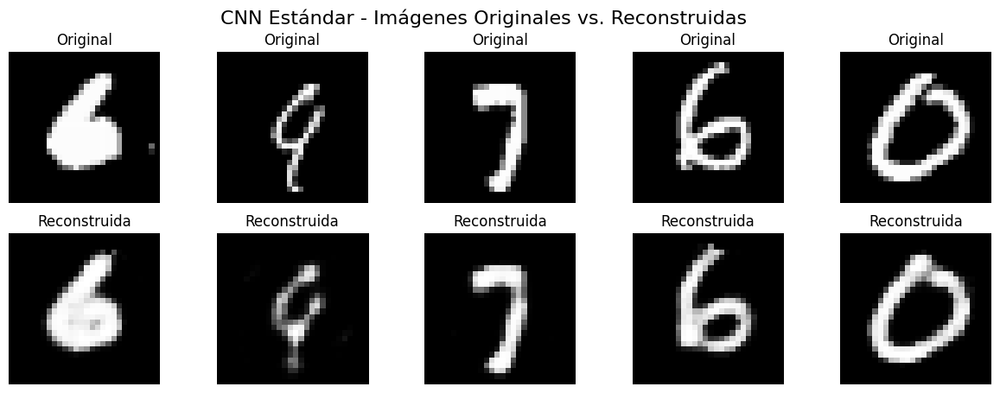


--- Visualizando resultados de CNN Experimental ---


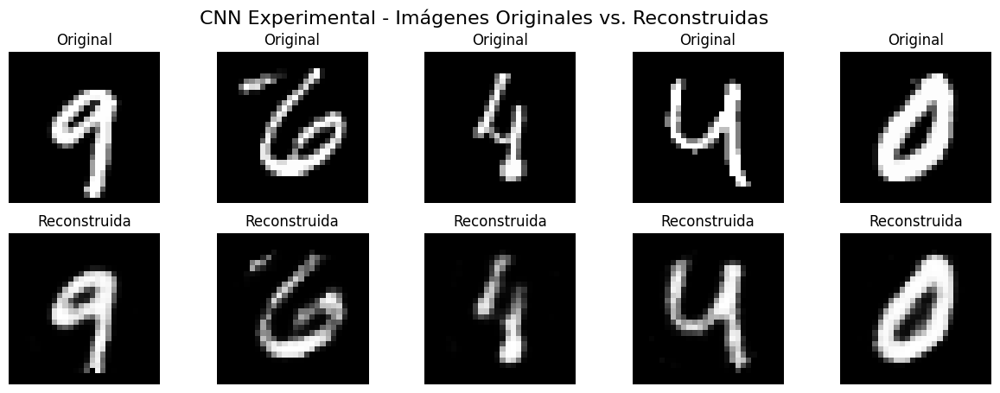


--- Visualizando filtros de CNN Estándar (conv1) ---


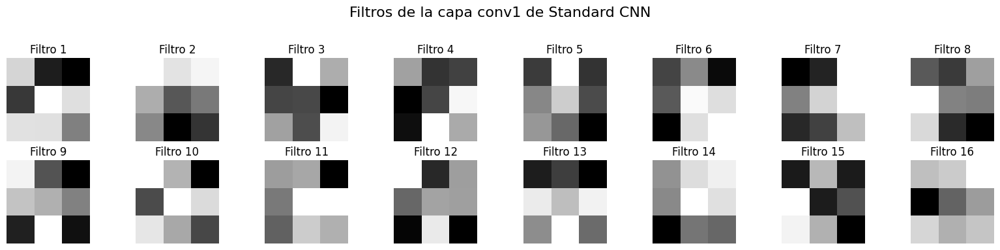


--- Visualizando filtros de CNN Estándar (conv2) ---


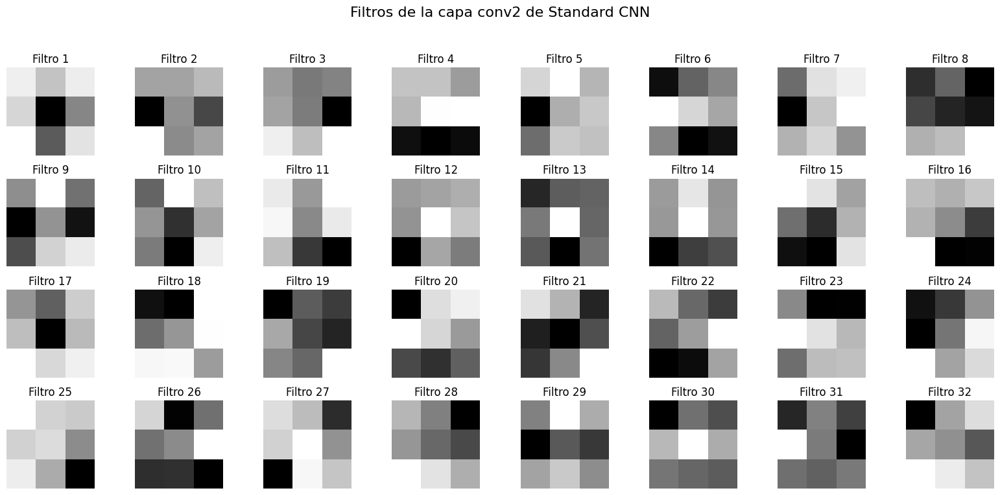


--- Visualizando filtros de CNN Experimental (conv1) ---


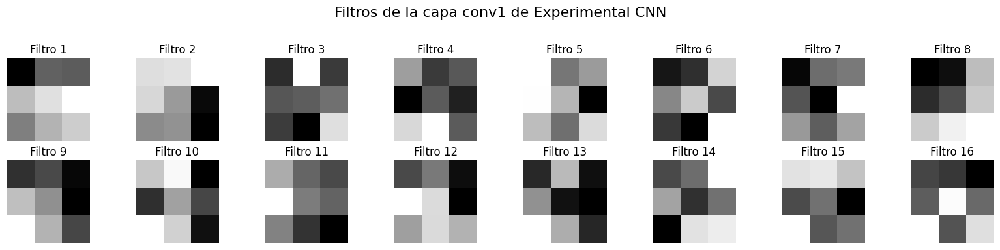


--- Visualizando filtros de CNN Experimental (conv2) ---


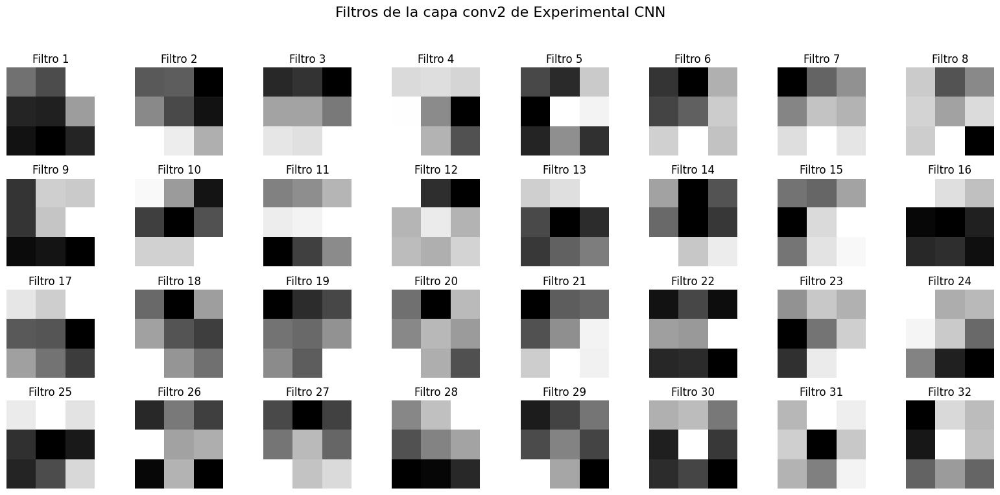

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Definición de las Arquitecturas ---

## CNN Estándar

class CNNStandard(nn.Module):
    def __init__(self):
        super(CNNStandard, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1)  # 1 canal de entrada (gris), 16 canales de salida
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(32 * 7 * 7, 128)  # Ajustado para imágenes de 28x28 después de pooling
        self.fc2 = nn.Linear(128, 784)  # Salida para "reconstruir" una imagen de 28x28 (784 = 28 * 28)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 32 * 7 * 7)  # Aplanar para las capas lineales
        x = F.relu(self.fc1(x))
        x = torch.sigmoid(self.fc2(x))  # Sigmoid para salida entre 0 y 1 (como píxeles)
        x = x.view(-1, 1, 28, 28)  # Reformar a imagen
        return x

## CNN Experimental (con conexiones densas a la entrada)

class CNNExperimental(nn.Module):
    def __init__(self):
        super(CNNExperimental, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1)
        # La entrada a conv2 debe coincidir con el número total de canales después de la concatenación.
        # Salida de conv1 tiene 16 canales. Entrada original (x) tiene 1 canal. Total = 16 + 1 = 17.
        self.conv2 = nn.Conv2d(16 + 1, 32, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        # La entrada a fc1 debe ser el tamaño aplanado después de conv2 y pool.
        # Salida de conv2 tiene 32 canales. Después de dos pools de 2x2, las dimensiones HxW se dividen por 4.
        # Imagen original 28x28 -> después del primer pool 14x14 -> después del segundo pool 7x7.
        # Entonces, el tamaño aplanado es 32 * 7 * 7.
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 784)

    def forward(self, x):
        h1 = F.relu(self.conv1(x))
        # Conexión densa a la entrada: concatenar la entrada original (x) a la salida de conv1
        # Asegúrate de que las dimensiones espaciales (H, W) coincidan para la concatenación.
        # En este caso, conv1(x) tiene el mismo HxW que x debido a padding=1 y stride=1.
        x_for_conv2 = torch.cat((h1, x), dim=1)  # Concatenar a lo largo de la dimensión del canal

        x = F.relu(self.conv2(x_for_conv2))
        x = self.pool(x) # Aplica pool después de conv2

        x = self.pool(x) # Aplica el segundo pool


        x = x.view(-1, 32 * 7 * 7)  # Aplanar para las capas lineales

        x = F.relu(self.fc1(x))
        x = torch.sigmoid(self.fc2(x))
        x = x.view(-1, 1, 28, 28)  # Reformar a imagen
        return x

# --- 2. Preparación de Datos ---
transform = transforms.Compose([
    transforms.ToTensor(),  # Convierte la imagen a tensor, escala a [0, 1]
    # Se eliminó la normalización a (-1, 1) para que el target esté en [0, 1] como la salida de sigmoid.
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

# --- 3. Instanciar Modelos ---
cnn_standard = CNNStandard()
cnn_experimental = CNNExperimental()

# --- 4. Función de Pérdida y Optimizadores ---
criterion = nn.MSELoss() # MSELoss es adecuado para la reconstrucción de píxeles en el rango [0, 1]
optimizer_standard = optim.Adam(cnn_standard.parameters(), lr=0.001)
optimizer_experimental = optim.Adam(cnn_experimental.parameters(), lr=0.001)

# --- 5. Entrenamiento ---
def train(model, optimizer, epochs=2):
    model.train()
    for epoch in range(epochs):
        for batch_idx, (data, _) in enumerate(train_loader):
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, data)  # Comparar la salida con la entrada (reconstrucción)
            loss.backward()
            optimizer.step()
            if batch_idx % 100 == 0:
                print(f'Epoch: {epoch}, Batch: {batch_idx}, Loss: {loss.item():.6f}')
    return model

print("--- Entrenando CNN Estándar ---")
cnn_standard = train(cnn_standard, optimizer_standard, epochs=2)

print("\n--- Entrenando CNN Experimental ---")
cnn_experimental = train(cnn_experimental, optimizer_experimental, epochs=2)

# --- 6. Visualización de Resultados (Imágenes reconstruidas) ---
def show_images(model, data_loader, num_images=5, title_prefix=""):
    model.eval()
    with torch.no_grad():
        data, _ = next(iter(data_loader))
        output = model(data)

        plt.figure(figsize=(15, 5))
        plt.suptitle(f'{title_prefix} - Imágenes Originales vs. Reconstruidas', fontsize=16)
        for i in range(num_images):
            # Imagen Original
            plt.subplot(2, num_images, i + 1)
            data_np = data[i].squeeze().cpu().numpy()
            plt.imshow(data_np, cmap='gray')
            plt.title('Original')
            plt.axis('off')

            # Imagen Reconstruida
            plt.subplot(2, num_images, i + 1 + num_images)
            output_np = output[i].squeeze().cpu().numpy()
            plt.imshow(output_np, cmap='gray')
            plt.title('Reconstruida')
            plt.axis('off')
        plt.show()

print("\n--- Visualizando resultados de CNN Estándar ---")
show_images(cnn_standard, train_loader, title_prefix="CNN Estándar")

print("\n--- Visualizando resultados de CNN Experimental ---")
show_images(cnn_experimental, train_loader, title_prefix="CNN Experimental")

# --- 7. Visualización de Filtros ---
def visualize_filters(model_name, model, layer_name):
    layer = None
    if layer_name == 'conv1':
        layer = model.conv1
    elif layer_name == 'conv2':
        layer = model.conv2
    else:
        print(f"Capa {layer_name} no encontrada o no es convolucional.")
        return

    if layer is None:
        print(f"Capa {layer_name} no encontrada en el modelo {model_name}.")
        return

    # Extraer los pesos (kernels) de la capa convolucional
    # Los pesos tienen forma (out_channels, in_channels, kernel_height, kernel_width)
    filters = layer.weight.data.clone().cpu()

    # Normalizar los filtros para visualizarlos como imágenes
    filters = filters - filters.min()
    filters = filters / filters.max()

    num_filters = filters.shape[0] # Número de filtros de salida
    in_channels = filters.shape[1] # Número de canales de entrada por filtro
    kernel_size = filters.shape[2] # Tamaño del kernel (ej: 3x3)

    # Calcular el número de filas y columnas para el subGráfico
    # Mostraremos cada filtro de salida en su propio subGráfico
    # Si un filtro tiene múltiples canales de entrada (como conv2),
    # podríamos mostrar cada canal del filtro, o solo el primer canal, o promediar.
    # Aquí, para simplificar y visualizar la "forma" principal, tomaremos el primer canal.
    # Para conv2, los filtros de cada canal de entrada son diferentes.
    # Podrías necesitar un enfoque diferente para visualizar conv2 de forma exhaustiva.

    cols = 8 # Número de columnas para la visualización
    rows = int(np.ceil(num_filters / cols))

    plt.figure(figsize=(cols * 2, rows * 2))
    plt.suptitle(f'Filtros de la capa {layer_name} de {model_name.capitalize()} CNN', fontsize=16)

    for i in range(num_filters):
        plt.subplot(rows, cols, i + 1)
        # Mostrar el primer canal del filtro.
        # Para conv1, in_channels es 1, así que filters[i, 0, :, :] es el filtro completo.
        # Para conv2 (CNNExperimental), in_channels es 17. filters[i, 0, :, :] mostraría
        # la parte del filtro que actúa sobre el primer canal de entrada combinado.
        # Puedes experimentar mostrando diferentes canales o promediándolos.
        plt.imshow(filters[i, 0, :, :], cmap='gray')
        plt.title(f'Filtro {i+1}')
        plt.axis('off')
    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Ajustar layout para el título
    plt.show()

print("\n--- Visualizando filtros de CNN Estándar (conv1) ---")
visualize_filters('standard', cnn_standard, 'conv1')

print("\n--- Visualizando filtros de CNN Estándar (conv2) ---")
visualize_filters('standard', cnn_standard, 'conv2')

print("\n--- Visualizando filtros de CNN Experimental (conv1) ---")
visualize_filters('experimental', cnn_experimental, 'conv1')

print("\n--- Visualizando filtros de CNN Experimental (conv2) ---")
visualize_filters('experimental', cnn_experimental, 'conv2')

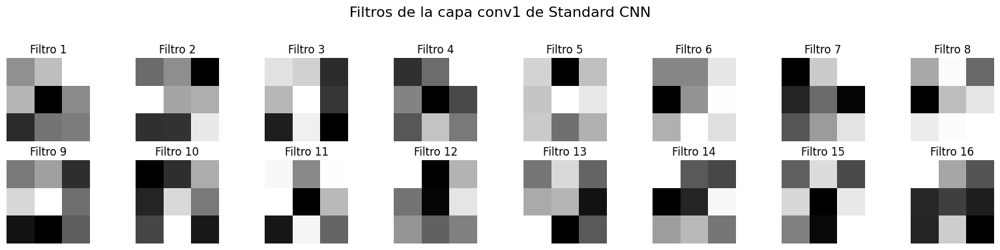

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

# --- Re-definiendo la CNN Estándar (o carga tu modelo entrenado) ---
class CNNStandard(nn.Module):
    def __init__(self):
        super(CNNStandard, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 784)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 32 * 7 * 7)
        x = F.relu(self.fc1(x))
        x = torch.sigmoid(self.fc2(x))
        x = x.view(-1, 1, 28, 28)
        return x

# --- Cargar un modelo pre-entrenado o el que entrenaste antes ---
# Para este ejemplo, instanciamos el modelo. Idealmente, cargarías uno que ya hayas entrenado.
model = CNNStandard()

# --- Visualizar los filtros de la primera capa convolucional (conv1) ---
def visualize_filters(model_name, layer_name):
    layer = None
    if model_name == 'standard':
        model_to_visualize = CNNStandard() # Instancia para la visualización
        # Aquí deberías cargar los pesos entrenados, por ejemplo:
        # model_to_visualize.load_state_dict(torch.load('ruta_a_tu_modelo_standard.pth'))
        # Para este ejemplo, si no tienes un .pth, usaremos los pesos iniciales/aleatorios.
        layer = model_to_visualize.conv1
    elif model_name == 'experimental':
        # Tendrías que definir y cargar la CNNExperimental aquí
        # model_to_visualize = CNNExperimental()
        # model_to_visualize.load_state_dict(torch.load('ruta_a_tu_modelo_experimental.pth'))
        # layer = model_to_visualize.conv1 # o conv2, según quieras ver.
        print(f"La visualización para {model_name} no está implementada completamente en este ejemplo.")
        return

    if layer is None:
        print(f"Capa {layer_name} no encontrada o modelo no válido.")
        return

    # Extraer los pesos (kernels) de la capa convolucional
    # Los pesos tienen forma (out_channels, in_channels, kernel_height, kernel_width)
    filters = layer.weight.data.clone().cpu()

    # Normalizar los filtros para visualizarlos como imágenes
    # Escalar entre 0 y 1 para que matplotlib los muestre correctamente
    filters = filters - filters.min()
    filters = filters / filters.max()

    num_filters = filters.shape[0]
    kernel_size = filters.shape[2]

    # Calcular el número de filas y columnas para el subGráfico
    cols = 8
    rows = int(np.ceil(num_filters / cols))

    plt.figure(figsize=(cols * 2, rows * 2))
    plt.suptitle(f'Filtros de la capa {layer_name} de {model_name.capitalize()} CNN', fontsize=16)

    for i in range(num_filters):
        plt.subplot(rows, cols, i + 1)
        # Mostrar el filtro, que tiene 1 canal de entrada (escala de grises)
        # Si tu capa conv1 tuviera más de 1 canal de entrada (ej: RGB), tendrías que promediarlos o seleccionar uno
        plt.imshow(filters[i, 0, :, :], cmap='gray') # filters[i, 0, :, :] selecciona el primer canal de entrada del filtro i
        plt.title(f'Filtro {i+1}')
        plt.axis('off')
    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Ajustar layout para el título
    plt.show()

# --- Ejecutar la visualización para la primera capa de la CNN Estándar ---
# Nota: Si no entrenaste el modelo, estos filtros serán aleatorios (iniciales).
# Para ver filtros "aprendidos", el modelo debe haber sido entrenado y sus pesos guardados/cargados.
visualize_filters('standard', 'conv1')

# Si quisieras ver los filtros de la segunda capa (conv2), sería más complejo
# porque sus filtros operan sobre mapas de características que ya no son imágenes simples.
# Tendrías que decidir cómo colapsar o mostrar los múltiples canales de entrada de conv2.

100%|██████████| 9.91M/9.91M [00:00<00:00, 57.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 2.23MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 12.7MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.99MB/s]



--- Entrenando CNN Estándar ---
CNN Estándar - Época 0, Lote 0, Pérdida: 0.232488
CNN Estándar - Época 0, Lote 100, Pérdida: 0.061382
CNN Estándar - Época 0, Lote 200, Pérdida: 0.033206
CNN Estándar - Época 0, Lote 300, Pérdida: 0.024207
CNN Estándar - Época 0, Lote 400, Pérdida: 0.021474
CNN Estándar - Época 0, Lote 500, Pérdida: 0.017688
CNN Estándar - Época 0, Lote 600, Pérdida: 0.016691
CNN Estándar - Época 0, Lote 700, Pérdida: 0.014190
CNN Estándar - Época 0, Lote 800, Pérdida: 0.011711
CNN Estándar - Época 0, Lote 900, Pérdida: 0.011759
CNN Estándar - Época 1, Lote 0, Pérdida: 0.011679
CNN Estándar - Época 1, Lote 100, Pérdida: 0.010549
CNN Estándar - Época 1, Lote 200, Pérdida: 0.012075
CNN Estándar - Época 1, Lote 300, Pérdida: 0.009913
CNN Estándar - Época 1, Lote 400, Pérdida: 0.009703
CNN Estándar - Época 1, Lote 500, Pérdida: 0.009708
CNN Estándar - Época 1, Lote 600, Pérdida: 0.009216
CNN Estándar - Época 1, Lote 700, Pérdida: 0.008750
CNN Estándar - Época 1, Lote 800, P

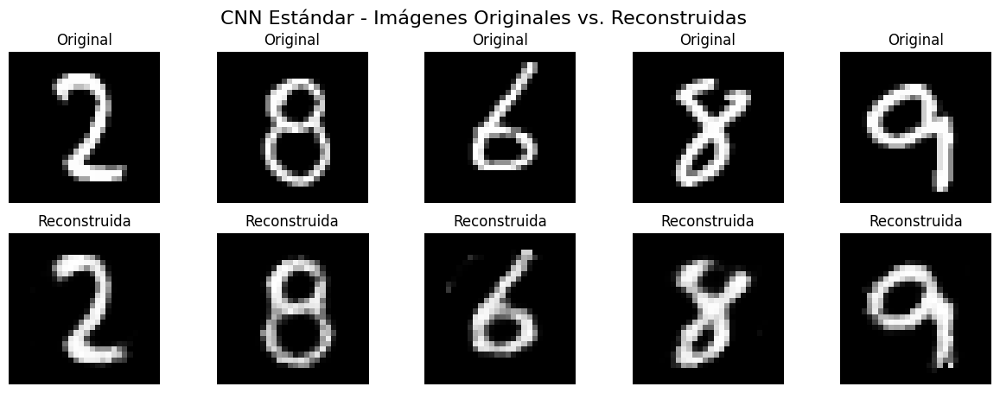


--- Visualizando Reconstrucciones de CNN Densa con Entrada ---


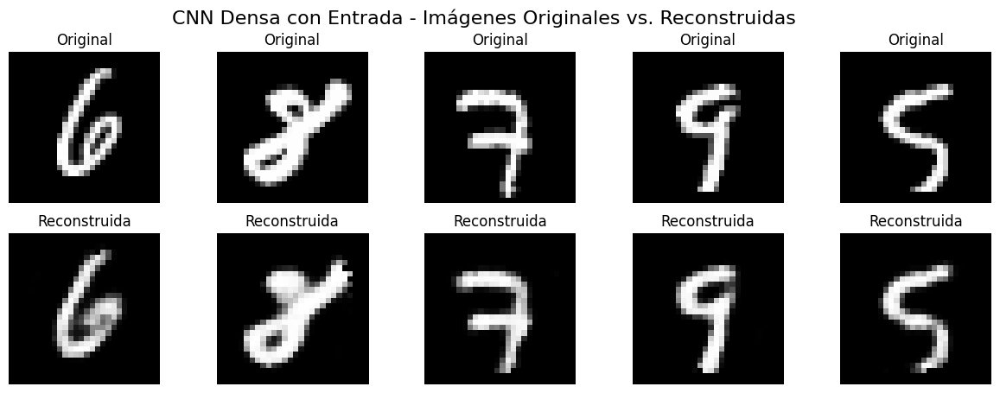


--- Visualizando filtros de CNN Estándar (conv1) ---


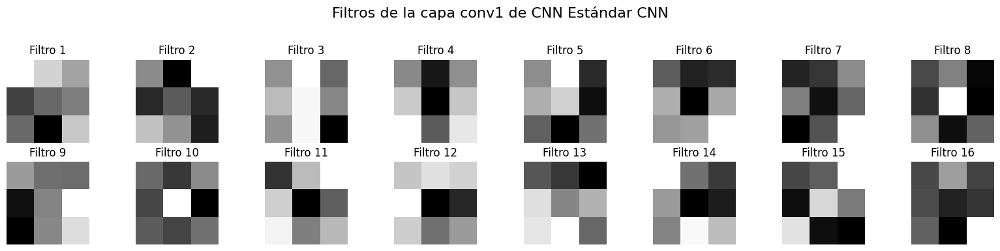


--- Visualizando filtros de CNN Estándar (conv2) ---


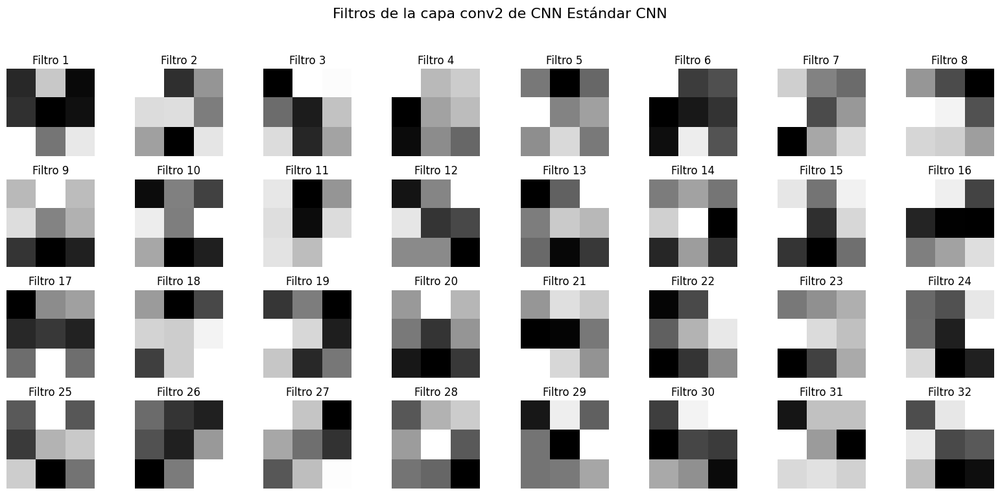


--- Visualizando filtros de CNN Estándar (conv3) ---


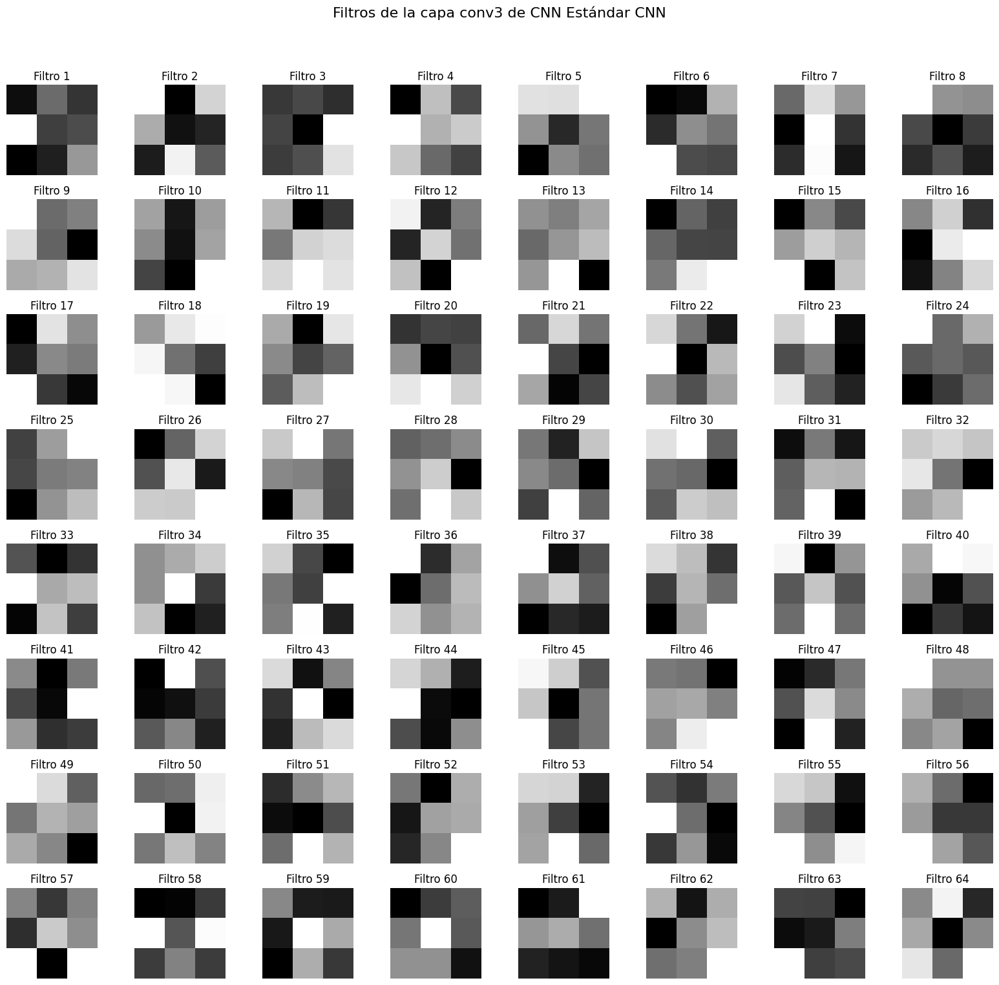


--- Visualizando filtros de CNN Densa con Entrada (conv1) ---


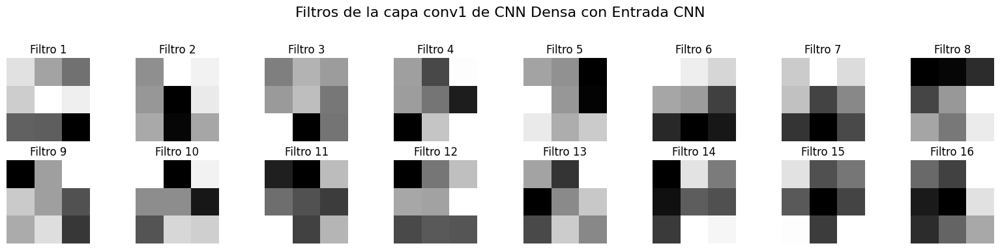


--- Visualizando filtros de CNN Densa con Entrada (conv2) ---


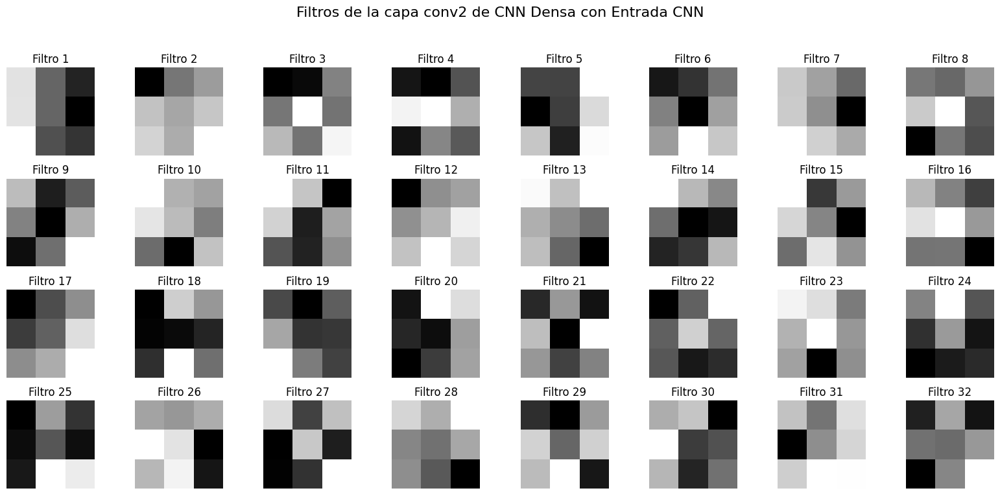


--- Visualizando filtros de CNN Densa con Entrada (conv3) ---


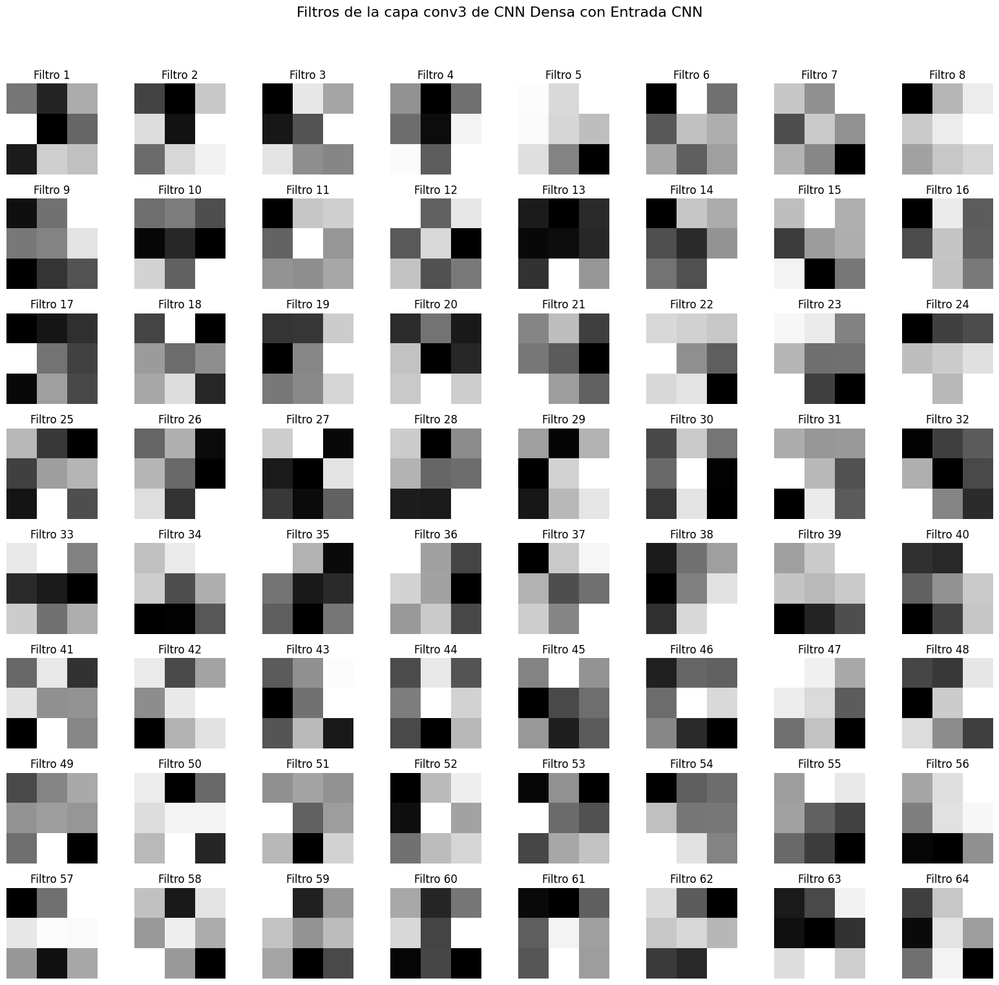

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Definición de las Arquitecturas ---

## CNN Estándar

class CNNStandard(nn.Module):
    def __init__(self):
        super(CNNStandard, self).__init__()
        # Capas convolucionales
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1) # Entrada: 1 canal, Salida: 16 canales (28x28)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1) # Entrada: 16 canales, Salida: 32 canales (28x28)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1) # Entrada: 32 canales, Salida: 64 canales (28x28)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Capas lineales para la reconstrucción
        # Después de 3 conv con padding 1 y 2 pools de 2x2:
        # 28x28 (input) -> conv1 (28x28) -> conv2 (28x28) -> conv3 (28x28)
        # -> pool1 (14x14) -> pool2 (7x7)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 784) # Salida para reconstruir 28x28 imagen

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x)) # Aplica todas las conv antes del pooling para una comparación justa de profundidad

        x = self.pool(x) # Primer pooling (64 canales, 14x14)
        x = self.pool(x) # Segundo pooling (64 canales, 7x7)

        x = x.view(-1, 64 * 7 * 7) # Aplanar
        x = F.relu(self.fc1(x))
        x = torch.sigmoid(self.fc2(x)) # Sigmoid para valores de píxel entre 0 y 1
        x = x.view(-1, 1, 28, 28) # Reformar a imagen
        return x

## CNN Experimental (Conexiones densas con Input Directo a todas las capas ocultas)

class CNNDenseConcatenatedInput(nn.Module):
    def __init__(self):
        super(CNNDenseConcatenatedInput, self).__init__()
        # Definimos los tamaños de las capas ocultas para una comparación más directa
        # (similar a tu descripción de 16, 32, 64 canales de salida)
        self.conv1_out_channels = 16
        self.conv2_out_channels = 32
        self.conv3_out_channels = 64
        self.input_channels = 1 # Para imágenes de MNIST

        # Capa oculta 1: Conectada a la entrada
        self.conv1 = nn.Conv2d(self.input_channels, self.conv1_out_channels, kernel_size=3, stride=1, padding=1)

        # Capa oculta 2: Recibe de Capa oculta 1 Y de la entrada original
        # Entrada: (salida conv1 + entrada original)
        self.conv2 = nn.Conv2d(self.conv1_out_channels + self.input_channels, self.conv2_out_channels, kernel_size=3, stride=1, padding=1)

        # Capa oculta 3: Recibe de Capa oculta 1, Capa oculta 2 Y de la entrada original
        # Entrada: (salida conv1 + salida conv2 + entrada original)
        self.conv3 = nn.Conv2d(self.conv1_out_channels + self.conv2_out_channels + self.input_channels, self.conv3_out_channels, kernel_size=3, stride=1, padding=1)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Capas lineales para la reconstrucción (igual que la estándar para una salida comparable)
        # Después de 3 conv con padding 1, y luego 2 pools
        self.fc1 = nn.Linear(self.conv3_out_channels * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 784)

    def forward(self, x_original):
        # Capa oculta 1
        h1 = F.relu(self.conv1(x_original)) # Salida: 16 canales, 28x28

        # Capa oculta 2
        # Concatenar h1 (16 canales, 28x28) y x_original (1 canal, 28x28)
        h2_input = torch.cat((h1, x_original), dim=1) # Dimensión de canales: 16 + 1 = 17
        h2 = F.relu(self.conv2(h2_input)) # Salida: 32 canales, 28x28

        # Capa oculta 3
        # Concatenar h1 (16), h2 (32) y x_original (1)
        h3_input = torch.cat((h1, h2, x_original), dim=1) # Dimensión de canales: 16 + 32 + 1 = 49
        h3 = F.relu(self.conv3(h3_input)) # Salida: 64 canales, 28x28

        # Aplicar pooling después de todas las capas convolucionales
        x = self.pool(h3) # (64 canales, 14x14)
        x = self.pool(x) # (64 canales, 7x7)

        # Aplanar y pasar por las capas lineales
        x = x.view(-1, self.conv3_out_channels * 7 * 7)
        x = F.relu(self.fc1(x))
        x = torch.sigmoid(self.fc2(x))
        x = x.view(-1, 1, 28, 28)
        return x

# --- 2. Preparación de Datos ---
transform = transforms.Compose([
    transforms.ToTensor(), # Convierte imagen a tensor, escala a [0, 1]
    # No se aplica normalización a (-1, 1) ya que la salida de la red usa Sigmoid (0-1).
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

# --- 3. Instanciar Modelos ---
cnn_standard = CNNStandard()
cnn_dense_input = CNNDenseConcatenatedInput()

# --- 4. Función de Pérdida y Optimizadores ---
criterion = nn.MSELoss() # Función de pérdida para la reconstrucción
optimizer_standard = optim.Adam(cnn_standard.parameters(), lr=0.001)
optimizer_dense_input = optim.Adam(cnn_dense_input.parameters(), lr=0.001)

# --- 5. Entrenamiento ---
def train_model(model, optimizer, epochs=2, model_name=""):
    model.train()
    print(f"\n--- Entrenando {model_name} ---")
    for epoch in range(epochs):
        for batch_idx, (data, _) in enumerate(train_loader):
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, data)
            loss.backward()
            optimizer.step()
            if batch_idx % 100 == 0:
                print(f'{model_name} - Época {epoch}, Lote {batch_idx}, Pérdida: {loss.item():.6f}')
    return model

cnn_standard = train_model(cnn_standard, optimizer_standard, epochs=2, model_name="CNN Estándar")
cnn_dense_input = train_model(cnn_dense_input, optimizer_dense_input, epochs=2, model_name="CNN Densa con Entrada")

# --- 6. Visualización de Resultados (Imágenes reconstruidas) ---
def show_reconstructions(model, data_loader, num_images=5, title_prefix=""):
    model.eval()
    with torch.no_grad():
        data, _ = next(iter(data_loader))
        output = model(data)

        plt.figure(figsize=(15, 5))
        plt.suptitle(f'{title_prefix} - Imágenes Originales vs. Reconstruidas', fontsize=16)
        for i in range(num_images):
            plt.subplot(2, num_images, i + 1)
            plt.imshow(data[i].squeeze().cpu().numpy(), cmap='gray')
            plt.title('Original')
            plt.axis('off')

            plt.subplot(2, num_images, i + 1 + num_images)
            plt.imshow(output[i].squeeze().cpu().numpy(), cmap='gray')
            plt.title('Reconstruida')
            plt.axis('off')
        plt.show()

print("\n--- Visualizando Reconstrucciones de CNN Estándar ---")
show_reconstructions(cnn_standard, train_loader, title_prefix="CNN Estándar")

print("\n--- Visualizando Reconstrucciones de CNN Densa con Entrada ---")
show_reconstructions(cnn_dense_input, train_loader, title_prefix="CNN Densa con Entrada")

# --- 7. Visualización de Filtros ---
def visualize_filters(model_name, model, layer_name):
    layer = None
    if hasattr(model, layer_name): # Verifica si el modelo tiene directamente el atributo
        layer = getattr(model, layer_name)
    else: # Intenta buscarlo por nombre en los módulos hijos si es más complejo
        for name, module in model.named_modules():
            if name == layer_name and isinstance(module, nn.Conv2d):
                layer = module
                break

    if not isinstance(layer, nn.Conv2d): # Asegurarse de que sea una capa Conv2d
        print(f"Capa '{layer_name}' no es una capa convolucional o no encontrada en el modelo {model_name}.")
        return

    filters = layer.weight.data.clone().cpu()
    filters = filters - filters.min()
    filters = filters / filters.max()

    num_filters = filters.shape[0]
    in_channels_per_filter = filters.shape[1] # Número de canales de entrada que un filtro ve

    cols = 8
    rows = int(np.ceil(num_filters / cols))

    plt.figure(figsize=(cols * 2, rows * 2))
    plt.suptitle(f'Filtros de la capa {layer_name} de {model_name} CNN', fontsize=16)

    for i in range(num_filters):
        plt.subplot(rows, cols, i + 1)
        # Para visualizar, tomamos el primer canal de entrada de cada filtro.
        # Si in_channels_per_filter > 1 (como en conv2 y conv3 de la densa),
        # esto mostrará cómo el filtro responde a la primera parte de su entrada combinada.
        plt.imshow(filters[i, 0, :, :], cmap='gray')
        plt.title(f'Filtro {i+1}')
        plt.axis('off')
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


print("\n--- Visualizando filtros de CNN Estándar (conv1) ---")
visualize_filters('CNN Estándar', cnn_standard, 'conv1')

print("\n--- Visualizando filtros de CNN Estándar (conv2) ---")
visualize_filters('CNN Estándar', cnn_standard, 'conv2')

print("\n--- Visualizando filtros de CNN Estándar (conv3) ---")
visualize_filters('CNN Estándar', cnn_standard, 'conv3')

print("\n--- Visualizando filtros de CNN Densa con Entrada (conv1) ---")
visualize_filters('CNN Densa con Entrada', cnn_dense_input, 'conv1')

print("\n--- Visualizando filtros de CNN Densa con Entrada (conv2) ---")
visualize_filters('CNN Densa con Entrada', cnn_dense_input, 'conv2')

print("\n--- Visualizando filtros de CNN Densa con Entrada (conv3) ---")
visualize_filters('CNN Densa con Entrada', cnn_dense_input, 'conv3')

# neuros en un arreglo k means

Forma de X_train: (350, 2)
Forma de y_train: (350,)
Forma de X_test: (150, 2)
Forma de y_test: (150,)


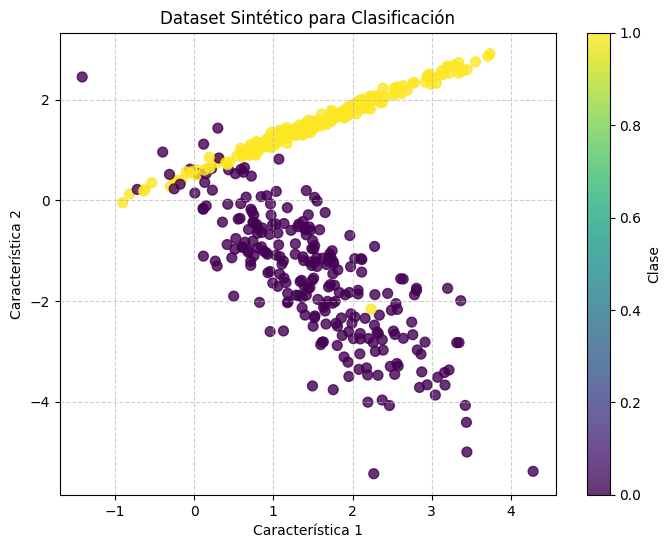

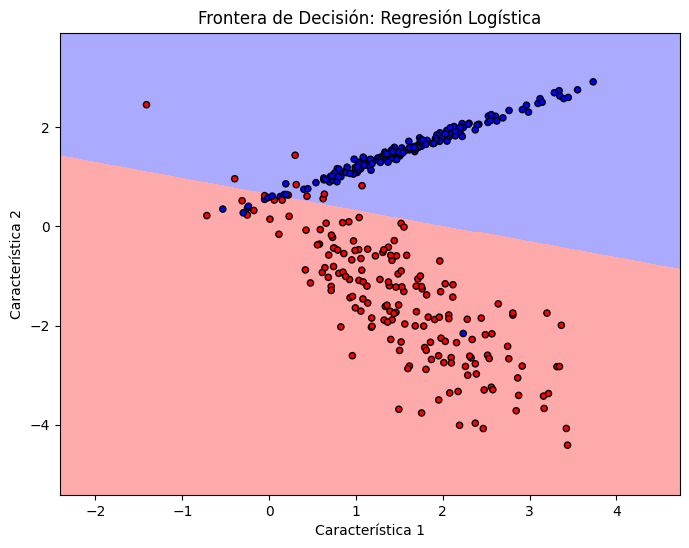

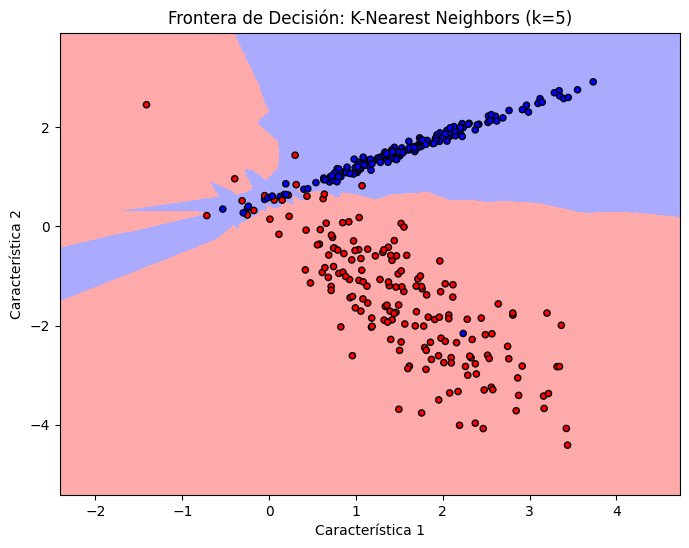


--- Métricas en el Conjunto de Prueba (X_test) ---

Regresión Logística:
              precision    recall  f1-score   support

           0       0.89      0.95      0.92        75
           1       0.94      0.88      0.91        75

    accuracy                           0.91       150
   macro avg       0.92      0.91      0.91       150
weighted avg       0.92      0.91      0.91       150

F1-Score: 0.91
Precisión: 0.94
Recall: 0.88

K-Nearest Neighbors (k=5):
              precision    recall  f1-score   support

           0       1.00      0.99      0.99        75
           1       0.99      1.00      0.99        75

    accuracy                           0.99       150
   macro avg       0.99      0.99      0.99       150
weighted avg       0.99      0.99      0.99       150

F1-Score: 0.99
Precisión: 0.99
Recall: 1.00

--- Evaluación con Validación Cruzada (5-Fold) ---

Regresión Logística (F1-Score CV): 0.95 (+/- 0.04)
K-Nearest Neighbors (F1-Score CV): 0.96 (+/- 0.04)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score
from matplotlib.colors import ListedColormap

# --- 1. Generar un dataset sintético ---
# Vamos a crear un dataset con 2 características (para que sea fácil de visualizar)
# y 2 clases. No será linealmente separable para desafiar un poco a los modelos.
X, y = make_classification(n_samples=500, n_features=2, n_informative=2,
                           n_redundant=0, n_clusters_per_class=1,
                           random_state=42, class_sep=1.5)

# Dividir el dataset en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Forma de X_train:", X_train.shape)
print("Forma de y_train:", y_train.shape)
print("Forma de X_test:", X_test.shape)
print("Forma de y_test:", y_test.shape)

# Visualizar el dataset
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', s=50, alpha=0.8)
plt.title('Dataset Sintético para Clasificación')
plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.colorbar(label='Clase')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# --- 2. Implementar y entrenar los modelos ---

# Modelo 1: Regresión Logística
log_reg_model = LogisticRegression(random_state=42)
log_reg_model.fit(X_train, y_train)
y_pred_log_reg = log_reg_model.predict(X_test)

# Modelo 2: K-Nearest Neighbors (elegiremos k=5 para este ejemplo)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)

# --- 3. Visualizar las fronteras de decisión ---

def plot_decision_boundary(X, y, model, title):
    h = .02  # Tamaño del paso en la malla
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    # Predecir la clase para cada punto en la malla
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Crear mapa de colores
    cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
    cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF']) # Para los puntos reales

    plt.figure(figsize=(8, 6))
    plt.pcolormesh(xx, yy, Z, cmap=cmap_light, shading='auto') # Fronteras de decisión

    # Graficar los puntos de entrenamiento/prueba
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold,
                edgecolor='k', s=20)
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title(title)
    plt.xlabel('Característica 1')
    plt.ylabel('Característica 2')
    plt.show()

plot_decision_boundary(X_train, y_train, log_reg_model, 'Frontera de Decisión: Regresión Logística')
plot_decision_boundary(X_train, y_train, knn_model, 'Frontera de Decisión: K-Nearest Neighbors (k=5)')

# --- 4. Comparar las métricas usando el conjunto de prueba y validación cruzada ---

print("\n--- Métricas en el Conjunto de Prueba (X_test) ---")

print("\nRegresión Logística:")
print(classification_report(y_test, y_pred_log_reg))
print(f"F1-Score: {f1_score(y_test, y_pred_log_reg):.2f}")
print(f"Precisión: {precision_score(y_test, y_pred_log_reg):.2f}")
print(f"Recall: {recall_score(y_test, y_pred_log_reg):.2f}")

print("\nK-Nearest Neighbors (k=5):")
print(classification_report(y_test, y_pred_knn))
print(f"F1-Score: {f1_score(y_test, y_pred_knn):.2f}")
print(f"Precisión: {precision_score(y_test, y_pred_knn):.2f}")
print(f"Recall: {recall_score(y_test, y_pred_knn):.2f}")

print("\n--- Evaluación con Validación Cruzada (5-Fold) ---")

# Para una evaluación más robusta, usamos cross_val_score
# Scoring con 'f1' para problemas de clasificación binaria es común.
# Puedes cambiar 'f1' por 'accuracy', 'precision', 'recall' si lo necesitas.

log_reg_cv_scores = cross_val_score(log_reg_model, X, y, cv=5, scoring='f1')
print(f"\nRegresión Logística (F1-Score CV): {log_reg_cv_scores.mean():.2f} (+/- {log_reg_cv_scores.std() * 2:.2f})")

knn_cv_scores = cross_val_score(knn_model, X, y, cv=5, scoring='f1')
print(f"K-Nearest Neighbors (F1-Score CV): {knn_cv_scores.mean():.2f} (+/- {knn_cv_scores.std() * 2:.2f})")

##arreglo knn

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class KNearestNeighborsNeuron(nn.Module):
    """
    Una implementación conceptual de una "neurona con arreglo KNN".
    Esta neurona mantiene una memoria de 'm' patrones y su activación
    se basa en la similitud con los K vecinos más cercanos de esa memoria.
    """
    def __init__(self, input_dim, memory_size=5, k_neighbors=3, learning_rate=0.01):
        super().__init__()
        self.input_dim = input_dim
        self.memory_size = memory_size  # 'm' en nuestra discusión: cuántos patrones memoriza la neurona
        self.k_neighbors = k_neighbors  # 'K' en KNN: cuántos vecinos usa para la activación
        self.learning_rate = learning_rate

        # La "memoria" de la neurona: 'm' patrones, cada uno de 'input_dim' dimensiones
        # Inicializamos los patrones aleatoriamente
        self.register_buffer('patterns', torch.randn(memory_size, input_dim))

        # Un contador simple para el aprendizaje de "reemplazo" (opcional)
        self.register_buffer('pattern_usage_counts', torch.zeros(memory_size))


    def forward(self, x):
        """
        Calcula la activación de la neurona para una entrada 'x'.
        x: Un tensor de entrada de una sola muestra [input_dim]
           o un batch de muestras [batch_size, input_dim]
        """
        if x.dim() == 1: # Si es una sola muestra, expandir para que sea un batch de 1
            x = x.unsqueeze(0)

        # Calcular distancias euclidianas de la entrada a cada patrón en la memoria
        # x: [batch_size, input_dim]
        # self.patterns: [memory_size, input_dim]
        # Distances: [batch_size, memory_size]

        # Expandir las dimensiones para la resta y la norma
        expanded_x = x.unsqueeze(1)          # [batch_size, 1, input_dim]
        expanded_patterns = self.patterns.unsqueeze(0) # [1, memory_size, input_dim]

        # Calcular la distancia euclidiana al cuadrado (más eficiente que la raíz cuadrada)
        # torch.cdist también se puede usar, pero la forma manual es clara aquí.
        distances_sq = torch.sum((expanded_x - expanded_patterns)**2, dim=2) # [batch_size, memory_size]
        distances = torch.sqrt(distances_sq) # [batch_size, memory_size]

        # Encontrar los K vecinos más cercanos (menores distancias)
        # topk retorna (valores, índices)
        # Queremos los k_neighbors más pequeños, por eso invertimos las distancias con -
        # o simplemente usamos torch.topk(..., largest=False)

        # Asegurarse de que k_neighbors no sea mayor que memory_size
        actual_k = min(self.k_neighbors, self.memory_size)

        # Tomar los k vecinos más cercanos
        # Si k_neighbors es 0, simplemente devolver 0.0 o manejar de otra forma
        if actual_k == 0:
            return torch.zeros(x.size(0), device=x.device)

        k_nearest_distances, _ = torch.topk(distances, k=actual_k, largest=False, dim=1) # [batch_size, actual_k]

        # Calcular la activación: Inverso del promedio de las distancias (o suma inversa)
        # Una menor distancia debería significar una mayor activación
        # Podemos usar 1 / (1 + distancia) o alguna función de kernel como exp(-distancia^2)

        # Usaremos el promedio de las inversas de las distancias para una "activación" simple.
        # Evitar división por cero si la distancia es 0
        activations = 1.0 / (1.0 + k_nearest_distances) # [batch_size, actual_k]

        # Sumar o promediar las activaciones de los k vecinos
        neuron_output = torch.mean(activations, dim=1) # [batch_size]

        return neuron_output

    def learn_from_input(self, x_batch, threshold_distance=0.5):
        """
        Una función simplificada de "aprendizaje" para actualizar los patrones internos.
        No es backpropagation, sino un ajuste al estilo competitivo/prototipo.

        Para cada muestra en el batch:
        - Encuentra el patrón más cercano en la memoria.
        - Si la muestra es suficientemente diferente del patrón más cercano (o no lo activa lo suficiente),
          podríamos añadirla como un nuevo patrón o reemplazar el menos utilizado.
        - Si es muy similar, podríamos ajustar ligeramente el patrón más cercano hacia la muestra.

        Esta es una aproximación y puede ser más compleja en un modelo real.
        """
        # Asegurar que x_batch es 2D
        if x_batch.dim() == 1:
            x_batch = x_batch.unsqueeze(0)

        for i in range(x_batch.size(0)):
            x = x_batch[i]

            # Calcular distancias a todos los patrones
            distances = torch.sqrt(torch.sum((x - self.patterns)**2, dim=1)) # [memory_size]

            # Encontrar el patrón más cercano
            min_dist, closest_pattern_idx = torch.min(distances, dim=0)

            # Estrategia de aprendizaje simple:
            if min_dist > threshold_distance:
                # Si la entrada es "nueva" o lo suficientemente diferente del patrón más cercano,
                # reemplazar el patrón menos utilizado o el más antiguo en la memoria.
                least_used_idx = torch.argmin(self.pattern_usage_counts)
                self.patterns[least_used_idx] = x.clone().detach() # Reemplazar con la nueva muestra
                self.pattern_usage_counts[least_used_idx] = 1 # Reiniciar su conteo
            else:
                # Si la entrada es similar a un patrón existente, ajustar ese patrón ligeramente.
                # Esto es como el aprendizaje de Kohonen (SOM)
                self.patterns[closest_pattern_idx] = (1 - self.learning_rate) * self.patterns[closest_pattern_idx] + \
                                                      self.learning_rate * x.clone().detach()
                self.pattern_usage_counts[closest_pattern_idx] += 1 # Incrementar el uso


# --- Ejemplo de Uso ---
input_dimension = 10  # Dimensión de las entradas a esta neurona
memory_capacity = 5   # Número de patrones que la neurona puede "recordar"
k_to_use = 3          # Usar los 3 patrones más cercanos para la activación

# Crear una neurona con arreglo KNN
neuron = KNearestNeighborsNeuron(input_dim=input_dimension,
                                  memory_size=memory_capacity,
                                  k_neighbors=k_to_use)

print(f"Neurona creada con {memory_capacity} patrones en memoria y K={k_to_use} vecinos.")
print("Patrones iniciales de la neurona:\n", neuron.patterns)

# --- Simular el proceso de aprendizaje ---
print("\n--- Simulación de Aprendizaje ---")
# Generar algunas "experiencias" (datos de entrada)
num_learning_steps = 20
for step in range(num_learning_steps):
    # Crear una entrada aleatoria o un patrón específico
    if step % 5 == 0: # Simular algunas entradas "nuevas" o muy diferentes
        new_input = torch.randn(input_dimension) * 2 # Más varianza para ver el reemplazo
    else: # Entradas más cercanas a un patrón base para ver el ajuste
        new_input = torch.randn(input_dimension) * 0.1 + torch.tensor([1.0]*input_dimension) # clustering alrededor de [1,1,...,1]

    # La neurona "aprende" de esta entrada
    neuron.learn_from_input(new_input)
    # print(f"Paso {step+1}: Entrada procesada. Patrones actualizados.")


print("\nPatrones finales de la neurona después del aprendizaje:\n", neuron.patterns)
print("Conteo de uso de patrones:\n", neuron.pattern_usage_counts)

# --- Simular la inferencia (activación) ---
print("\n--- Simulación de Inferencia (Activación) ---")
test_input_1 = torch.tensor([1.0]*input_dimension) + torch.randn(input_dimension) * 0.05 # Muy similar a un patrón aprendido
test_input_2 = torch.randn(input_dimension) * 3       # Muy diferente (ruido)
test_input_3 = torch.tensor([-1.0]*input_dimension) + torch.randn(input_dimension) * 0.05 # Nuevo patrón

activation_1 = neuron(test_input_1)
activation_2 = neuron(test_input_2)
activation_3 = neuron(test_input_3)

print(f"Activación para Input 1 (similar a patrón aprendido): {activation_1.item():.4f}")
print(f"Activación para Input 2 (ruido/muy diferente): {activation_2.item():.4f}")
print(f"Activación para Input 3 (nuevo patrón distinto): {activation_3.item():.4f}")

# Simular un batch de entrada
batch_inputs = torch.randn(4, input_dimension)
batch_activations = neuron(batch_inputs)
print(f"\nActivaciones para un batch de entradas:\n {batch_activations}")

Neurona creada con 5 patrones en memoria y K=3 vecinos.
Patrones iniciales de la neurona:
 tensor([[ 0.2097,  1.6458,  0.8614, -0.5203,  0.9306, -0.1553, -0.2934,  0.5954,
         -0.4703, -0.7392],
        [-0.2293, -1.6307,  1.0740, -0.7975, -1.6922,  0.5515, -0.1672, -1.2283,
         -0.1624,  1.0793],
        [-2.7758,  0.7771,  0.4840, -0.1051,  0.0429,  1.6620, -2.4310,  1.9780,
          0.2487, -0.5241],
        [-0.0535,  0.6913, -0.5524, -1.3083,  0.9519,  0.1878, -0.5469,  0.4260,
         -0.7165,  1.7308],
        [ 0.2453,  0.1174, -2.2642,  0.0905, -1.4632,  1.1122,  0.5296,  0.1647,
         -0.7148,  0.3757]])

--- Simulación de Aprendizaje ---

Patrones finales de la neurona después del aprendizaje:
 tensor([[ 9.8809e-01,  9.2334e-01,  9.2886e-01,  1.0372e+00,  8.9521e-01,
          8.4013e-01,  7.9234e-01,  1.0198e+00,  1.1301e+00,  6.8834e-01],
        [ 1.0392e+00,  1.0173e+00,  1.0963e+00,  9.0215e-01,  9.5342e-01,
          1.0030e+00,  9.1871e-01,  1.0372e+00,

## arreglo árbol de decisiones

In [ ]:
import torch
import torch.nn as nn
import numpy as np
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

class IDTNeuron(nn.Module):
    """
    Una implementación conceptual de una "Neurona de Árbol de Decisión Integrado (IDT-Neuron)".
    Cada neurona encapsula un pequeño DecisionTreeClassifier.
    """
    def __init__(self, input_dim, output_classes=2, max_depth=3, random_state=42):
        super().__init__()
        self.input_dim = input_dim
        self.output_classes = output_classes # Por ejemplo, si el árbol interno clasifica en 2 clases (relevante/no relevante)
        self.max_depth = max_depth
        self.random_state = random_state

        # Cada neurona tiene su propio Decision Tree Classifier
        # NOTA: En un escenario real, este árbol se entrenaría localmente.
        # Aquí, lo inicializamos, y la función 'learn_locally' lo entrenará.
        self.decision_tree = DecisionTreeClassifier(max_depth=self.max_depth,
                                                    random_state=self.random_state)

        # Una pequeña "memoria" local para simular el dataset de entrenamiento interno del árbol
        # Esto es para la simulación del aprendizaje local.
        self.local_X_memory = []
        self.local_y_memory = []
        self.memory_capacity = 50 # Cuántas muestras puede "recordar" para entrenar su árbol

    def forward(self, x):
        """
        Calcula la activación de la neurona pasando la entrada a su árbol de decisión interno.
        x: Un tensor de entrada de una sola muestra [input_dim]
           o un batch de muestras [batch_size, input_dim]
        """
        if x.dim() == 1: # Si es una sola muestra, expandir para que sea un batch de 1
            x_np = x.detach().cpu().numpy().reshape(1, -1)
        else:
            x_np = x.detach().cpu().numpy()

        # Si el árbol aún no ha sido entrenado (no tiene clases_ activas), no puede predecir.
        # Esto ocurre antes de la primera llamada a learn_locally.
        if not hasattr(self.decision_tree, 'classes_') or len(self.local_X_memory) < 2:
            # Devuelve una activación neutral o un indicador de "no entrenado"
            return torch.zeros(x.size(0), device=x.device, dtype=torch.float32)

        # Usamos predict_proba para obtener una activación "suave" (probabilidad)
        # o predict para una activación "dura" (0 o 1)
        # Aquí elegimos la probabilidad de la clase positiva (índice 1) como activación.

        # [batch_size, output_classes]
        probabilities = self.decision_tree.predict_proba(x_np)

        # Asumiendo que la clase positiva es el índice 1
        # Si output_classes > 2, necesitarías decidir cómo combinar las probabilidades.
        activation = torch.tensor(probabilities[:, 1], dtype=torch.float32, device=x.device)

        return activation

    def learn_locally(self, X_local_samples, y_local_labels):
        """
        Simula el aprendizaje local de la neurona, entrenando su árbol de decisión interno.
        X_local_samples: Un batch de características de entrada para que esta neurona aprenda.
                         [num_samples, input_dim]
        y_local_labels: Etiquetas asociadas a estas muestras (el "objetivo" local de esta neurona).
                        [num_samples]
        """
        if not isinstance(X_local_samples, np.ndarray):
            X_local_samples = X_local_samples.detach().cpu().numpy()
        if not isinstance(y_local_labels, np.ndarray):
            y_local_labels = y_local_labels.detach().cpu().numpy()

        # Añadir las nuevas muestras a la memoria local de la neurona
        for x_samp, y_samp in zip(X_local_samples, y_local_labels):
            self.local_X_memory.append(x_samp)
            self.local_y_memory.append(y_samp)

            # Mantener la memoria dentro de la capacidad definida
            if len(self.local_X_memory) > self.memory_capacity:
                self.local_X_memory.pop(0) # Eliminar la muestra más antigua
                self.local_y_memory.pop(0)

        # Solo entrenar si hay suficientes muestras en la memoria
        if len(self.local_X_memory) >= 2: # Se necesitan al menos 2 muestras para entrenar un DT
            current_X = np.array(self.local_X_memory)
            current_y = np.array(self.local_y_memory)

            # Entrenar el árbol de decisión interno con la memoria acumulada
            self.decision_tree.fit(current_X, current_y)

            # Opcional: imprimir la precisión local del árbol
            # y_pred_local = self.decision_tree.predict(current_X)
            # local_acc = accuracy_score(current_y, y_pred_local)
            # print(f"  Neurona entrenada localmente. Precisión interna: {local_acc:.2f}")

    def print_internal_tree(self, feature_names=None):
        """Muestra la estructura del árbol de decisión interno de la neurona."""
        if hasattr(self.decision_tree, 'tree_') and self.decision_tree.tree_.node_count > 1:
            print(f"\n--- Estructura del Árbol de Decisión Interno de IDT-Neuron ---")
            r = export_text(self.decision_tree, feature_names=feature_names)
            print(r)
        else:
            print("\nEl árbol de decisión interno aún no ha sido entrenado o es trivial.")


# --- Ejemplo de Uso ---

# 1. Crear una neurona IDT
input_dimension = 5 # La neurona espera 5 características de entrada
neuron = IDTNeuron(input_dim=input_dimension, output_classes=2, max_depth=2)
print(f"Neurona IDT creada. Profundidad máxima del árbol interno: {neuron.max_depth}")

# 2. Simular el Aprendizaje Local para la Neurona
print("\n--- Simulación de Aprendizaje Local ---")

# Generar algunos datos de ejemplo para que la neurona aprenda localmente
# X_data: características que llegarían a esta neurona desde la capa anterior
# y_labels: la "señal de supervisión" local para esta neurona (ej. si esta entrada debe activar la neurona o no)
np.random.seed(0)
num_samples = 40
X_learning_data = np.random.rand(num_samples, input_dimension) * 10
# Crear etiquetas simples: si la primera característica es alta, la etiqueta es 1, de lo contrario 0.
y_learning_labels = (X_learning_data[:, 0] > 5).astype(int)

# Simular "batches" de aprendizaje local
for i in range(0, num_samples, 10): # Aprender en grupos de 10 muestras
    batch_X = X_learning_data[i : i+10]
    batch_y = y_learning_labels[i : i+10]
    print(f"Aprendiendo con muestras {i} a {i+len(batch_X)-1}")
    neuron.learn_locally(batch_X, batch_y)

# Mostrar el árbol interno después del aprendizaje
neuron.print_internal_tree(feature_names=[f'Feature_{i+1}' for i in range(input_dimension)])


# 3. Simular la Inferencia (Activación)
print("\n--- Simulación de Inferencia (Activación) ---")

# Crear nuevas entradas para probar la neurona
test_input_1 = torch.tensor([8.0, 2.0, 3.0, 1.0, 5.0], dtype=torch.float32) # Debería activar fuerte (Feature_1 > 5)
test_input_2 = torch.tensor([2.0, 7.0, 1.0, 9.0, 4.0], dtype=torch.float32) # Debería activar débil (Feature_1 <= 5)
test_input_3 = torch.tensor([6.0, 0.5, 0.1, 9.5, 2.0], dtype=torch.float32) # Debería activar fuerte

activation_1 = neuron(test_input_1)
activation_2 = neuron(test_input_2)
activation_3 = neuron(test_input_3)

print(f"Activación para Input 1 (Feature_1=8.0): {activation_1.item():.4f}")
print(f"Activación para Input 2 (Feature_1=2.0): {activation_2.item():.4f}")
print(f"Activación para Input 3 (Feature_1=6.0): {activation_3.item():.4f}")

# Simular un batch de entrada
batch_test_inputs = torch.tensor([
    [7.5, 1.1, 2.3, 4.5, 6.7],
    [3.1, 8.2, 5.4, 0.9, 1.2],
    [9.0, 0.1, 0.2, 0.3, 0.4]
], dtype=torch.float32)
batch_activations = neuron(batch_test_inputs)
print(f"\nActivaciones para un batch de entradas:\n {batch_activations}")

Neurona IDT creada. Profundidad máxima del árbol interno: 2

--- Simulación de Aprendizaje Local ---
Aprendiendo con muestras 0 a 9
Aprendiendo con muestras 10 a 19
Aprendiendo con muestras 20 a 29
Aprendiendo con muestras 30 a 39

--- Estructura del Árbol de Decisión Interno de IDT-Neuron ---
|--- Feature_1 <= 5.06
|   |--- class: 0
|--- Feature_1 >  5.06
|   |--- class: 1


--- Simulación de Inferencia (Activación) ---
Activación para Input 1 (Feature_1=8.0): 1.0000
Activación para Input 2 (Feature_1=2.0): 0.0000
Activación para Input 3 (Feature_1=6.0): 1.0000

Activaciones para un batch de entradas:
 tensor([1., 0., 1.])


Forma de X_train: (350, 2)
Forma de y_train: (350,)
Forma de X_test: (150, 2)
Forma de y_test: (150,)


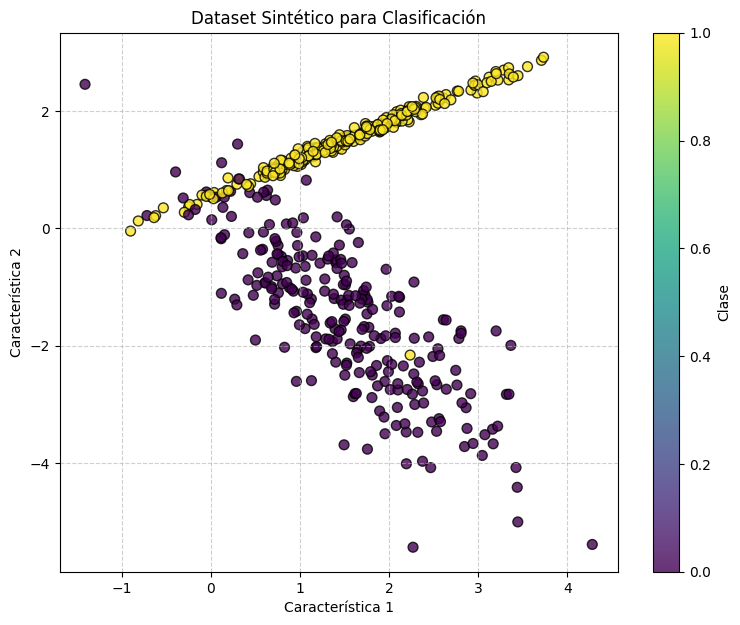


--- Entrenando y Evaluando Clasificadores ---

***** Modelo: Regresión Logística *****


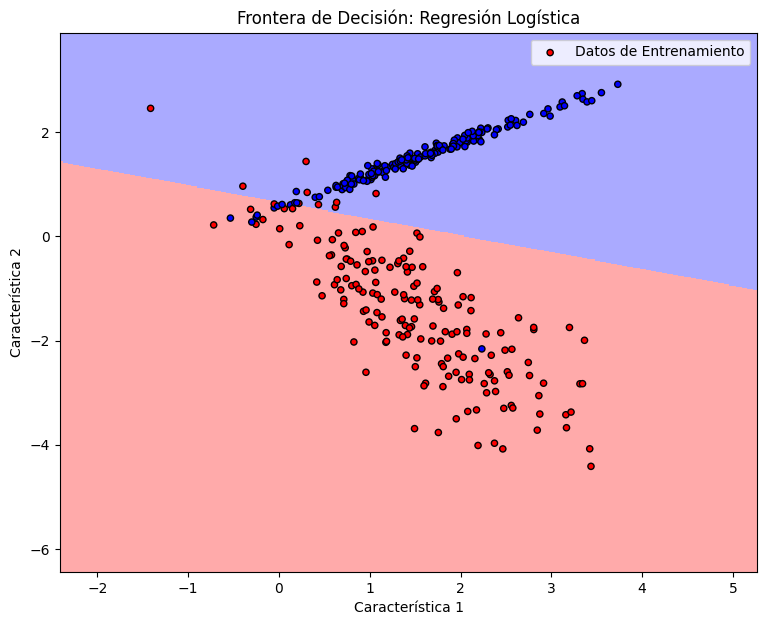


Métricas en el Conjunto de Prueba:
              precision    recall  f1-score   support

           0       0.89      0.95      0.92        75
           1       0.94      0.88      0.91        75

    accuracy                           0.91       150
   macro avg       0.92      0.91      0.91       150
weighted avg       0.92      0.91      0.91       150

Accuracy: 0.91
F1-Score (weighted): 0.91

F1-Score (Weighted) con 5-Fold Cross-Validation: 0.95 (+/- 0.04)
--------------------------------------------------

***** Modelo: K-Nearest Neighbors (k=5) *****


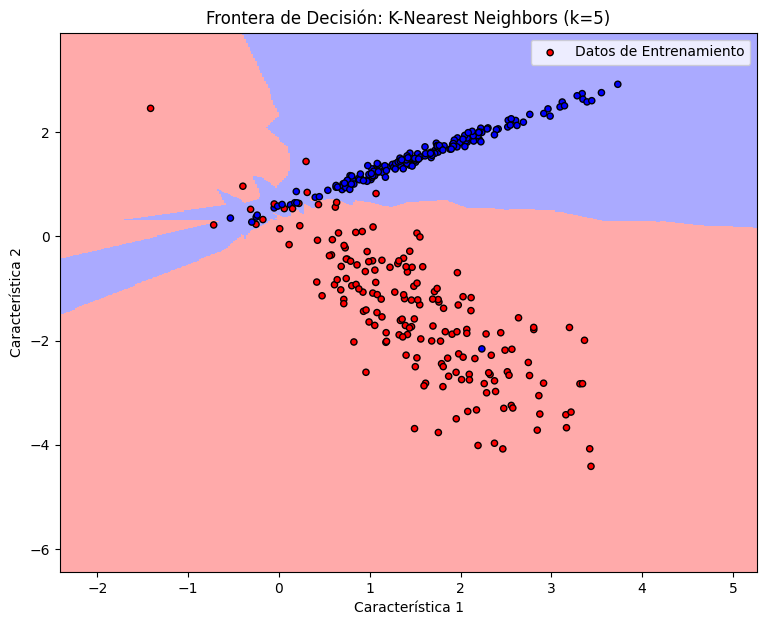


Métricas en el Conjunto de Prueba:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99        75
           1       0.99      1.00      0.99        75

    accuracy                           0.99       150
   macro avg       0.99      0.99      0.99       150
weighted avg       0.99      0.99      0.99       150

Accuracy: 0.99
F1-Score (weighted): 0.99

F1-Score (Weighted) con 5-Fold Cross-Validation: 0.96 (+/- 0.04)
--------------------------------------------------

***** Modelo: Support Vector Machine (Lineal) *****


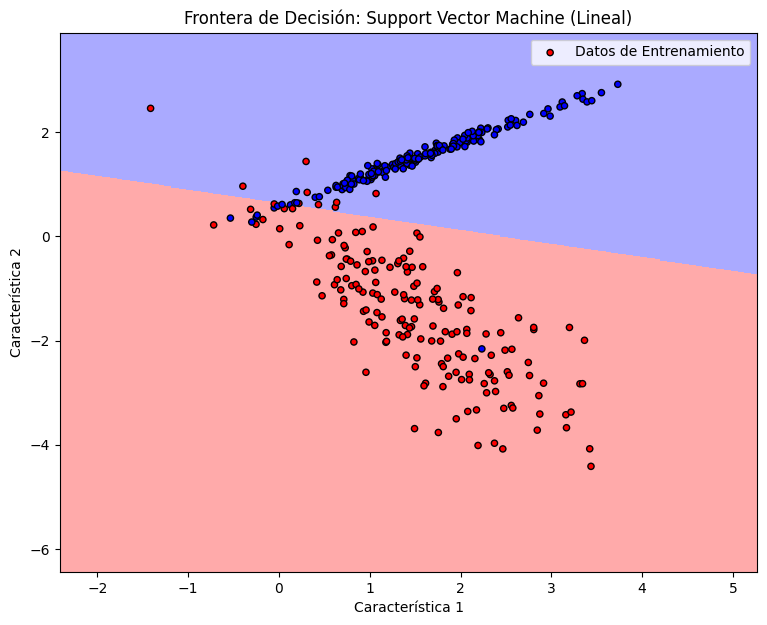


Métricas en el Conjunto de Prueba:
              precision    recall  f1-score   support

           0       0.89      0.95      0.92        75
           1       0.94      0.88      0.91        75

    accuracy                           0.91       150
   macro avg       0.92      0.91      0.91       150
weighted avg       0.92      0.91      0.91       150

Accuracy: 0.91
F1-Score (weighted): 0.91

F1-Score (Weighted) con 5-Fold Cross-Validation: 0.95 (+/- 0.03)
--------------------------------------------------

***** Modelo: Árbol de Decisión (Max Depth=5) *****


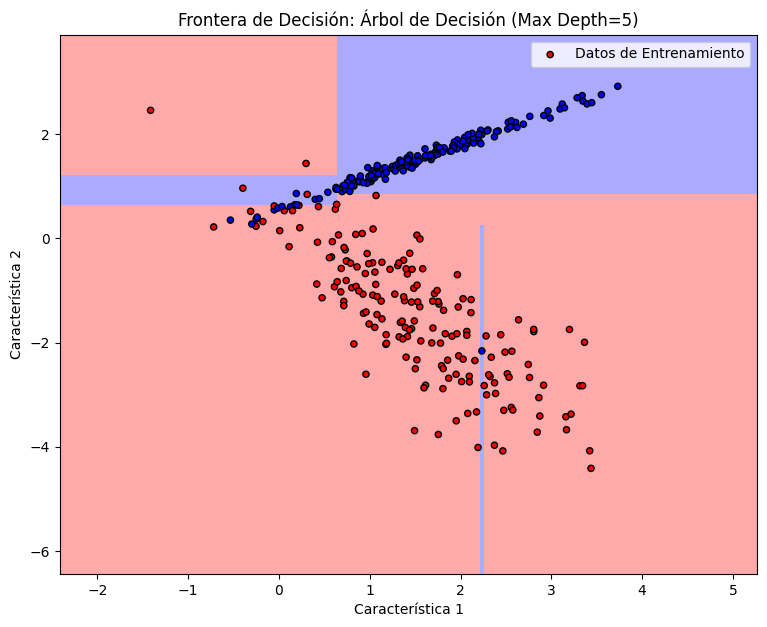


Métricas en el Conjunto de Prueba:
              precision    recall  f1-score   support

           0       0.89      0.99      0.94        75
           1       0.99      0.88      0.93        75

    accuracy                           0.93       150
   macro avg       0.94      0.93      0.93       150
weighted avg       0.94      0.93      0.93       150

Accuracy: 0.93
F1-Score (weighted): 0.93

F1-Score (Weighted) con 5-Fold Cross-Validation: 0.96 (+/- 0.03)
--------------------------------------------------

***** Modelo: Naive Bayes (Gaussiano) *****


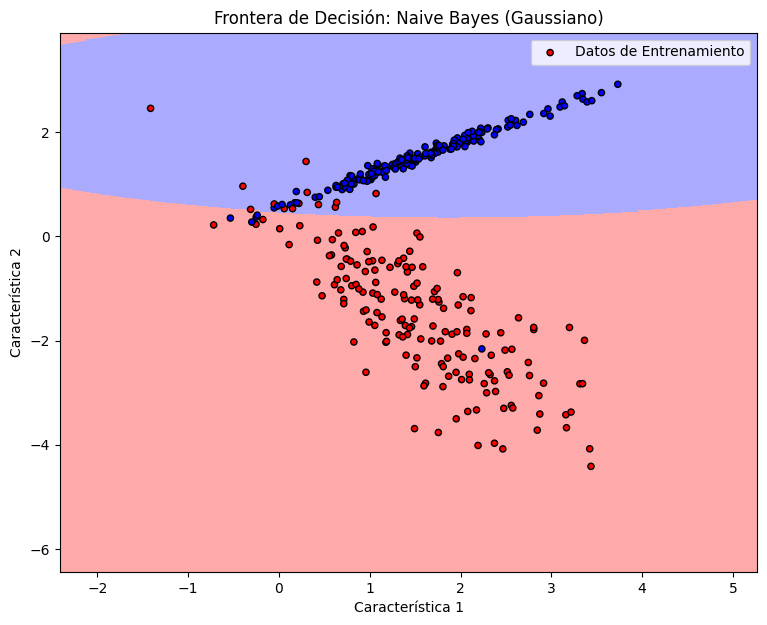


Métricas en el Conjunto de Prueba:
              precision    recall  f1-score   support

           0       0.93      0.95      0.94        75
           1       0.95      0.93      0.94        75

    accuracy                           0.94       150
   macro avg       0.94      0.94      0.94       150
weighted avg       0.94      0.94      0.94       150

Accuracy: 0.94
F1-Score (weighted): 0.94

F1-Score (Weighted) con 5-Fold Cross-Validation: 0.95 (+/- 0.03)
--------------------------------------------------

--- Resumen de F1-Score (Weighted) en Cross-Validation ---
K-Nearest Neighbors (k=5): 0.96
Árbol de Decisión (Max Depth=5): 0.96
Regresión Logística: 0.95
Support Vector Machine (Lineal): 0.95
Naive Bayes (Gaussiano): 0.95


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score, accuracy_score
from matplotlib.colors import ListedColormap
import warnings

# Suprimir advertencias para una salida más limpia
warnings.filterwarnings("ignore")

# --- 1. Generar un dataset sintético para clasificación ---
# Creamos un dataset con 2 características para que sea fácil de visualizar
# y 2 clases. Intentaremos que no sea linealmente separable para desafiar a los modelos.
X, y = make_classification(n_samples=500, n_features=2, n_informative=2,
                           n_redundant=0, n_clusters_per_class=1,
                           random_state=42, class_sep=1.5) # class_sep controla la separación entre clases

# Dividir el dataset en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Forma de X_train:", X_train.shape)
print("Forma de y_train:", y_train.shape)
print("Forma de X_test:", X_test.shape)
print("Forma de y_test:", y_test.shape)

# Visualizar el dataset
plt.figure(figsize=(9, 7))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', s=50, alpha=0.8, edgecolors='k')
plt.title('Dataset Sintético para Clasificación')
plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.colorbar(label='Clase')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# --- 2. Definir los clasificadores a comparar ---
classifiers = {
    "Regresión Logística": LogisticRegression(random_state=42),
    "K-Nearest Neighbors (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine (Lineal)": SVC(kernel='linear', random_state=42, probability=True), # probability=True para cross_val_score con F1
    "Árbol de Decisión (Max Depth=5)": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Naive Bayes (Gaussiano)": GaussianNB()
}

# --- 3. Bucle para entrenar, visualizar y evaluar cada clasificador ---

# Preparar la visualización de fronteras de decisión
# Crear una malla para dibujar las fronteras
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF']) # Colores para las regiones de decisión
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])   # Colores para los puntos de datos reales

results = {} # Para almacenar los resultados de la validación cruzada

print("\n--- Entrenando y Evaluando Clasificadores ---")

for name, classifier in classifiers.items():
    print(f"\n***** Modelo: {name} *****")

    # Entrenar el modelo
    classifier.fit(X_train, y_train)

    # Predecir en el conjunto de prueba
    y_pred = classifier.predict(X_test)

    # --- Visualizar fronteras de decisión ---
    Z = classifier.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(9, 7))
    plt.pcolormesh(xx, yy, Z, cmap=cmap_light, shading='auto') # Fronteras de decisión

    # Graficar los puntos de entrenamiento
    plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cmap_bold,
                edgecolor='k', s=20, label='Datos de Entrenamiento')
    # Graficar los puntos de prueba (opcional, para ver cómo caen)
    # plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=cmap_bold,
    #             edgecolor='k', s=20, marker='x', alpha=0.6, label='Datos de Prueba')

    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title(f'Frontera de Decisión: {name}')
    plt.xlabel('Característica 1')
    plt.ylabel('Característica 2')
    plt.legend()
    plt.show()

    # --- Imprimir métricas en el conjunto de prueba ---
    print("\nMétricas en el Conjunto de Prueba:")
    print(classification_report(y_test, y_pred))
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
    print(f"F1-Score (weighted): {f1_score(y_test, y_pred, average='weighted'):.2f}") # Weighted F1 para clases potencialmente desequilibradas

    # --- Realizar Validación Cruzada para una evaluación robusta ---
    # Usaremos 5-fold cross-validation y F1-score como métrica principal
    # para problemas de clasificación binaria.
    cv_scores = cross_val_score(classifier, X, y, cv=5, scoring='f1_weighted')
    results[name] = cv_scores.mean()
    print(f"\nF1-Score (Weighted) con 5-Fold Cross-Validation: {cv_scores.mean():.2f} (+/- {cv_scores.std() * 2:.2f})")
    print("-" * 50)

# --- Resumen Final de Rendimiento ---
print("\n--- Resumen de F1-Score (Weighted) en Cross-Validation ---")
for name, score in sorted(results.items(), key=lambda item: item[1], reverse=True):
    print(f"{name}: {score:.2f}")

##bayesiano

In [ ]:
import torch
import torch.nn as nn
import numpy as np
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs # Para generar datos para la neurona interna
from sklearn.model_selection import train_test_split

class NBNNeuron(nn.Module):
    """
    Una implementación conceptual de una "Neurona con Clasificador Bayesiano Ingenuo Integrado".
    Cada neurona encapsula su propio Clasificador Bayesiano Ingenuo.
    """
    def __init__(self, input_dim, output_classes=2):
        super().__init__()
        self.input_dim = input_dim
        self.output_classes = output_classes # Número de "clases" internas que el NB de la neurona aprenderá
                                            # Por ejemplo, 2 para 'patrón A' vs 'patrón B'

        # Cada neurona tiene su propio Clasificador Bayesiano Gaussiano
        self.naive_bayes_classifier = GaussianNB()

        # Una pequeña "memoria" local para simular el dataset de entrenamiento interno del NB
        self.local_X_memory = []
        self.local_y_memory = []
        self.memory_capacity = 100 # Cuántas muestras puede "recordar" para entrenar su NB

    def forward(self, x):
        """
        Calcula la activación de la neurona pasando la entrada a su clasificador Naive Bayes interno.
        x: Un tensor de entrada de una sola muestra [input_dim]
           o un batch de muestras [batch_size, input_dim]
        """
        if x.dim() == 1: # Si es una sola muestra, expandir para que sea un batch de 1
            x_np = x.detach().cpu().numpy().reshape(1, -1)
        else:
            x_np = x.detach().cpu().numpy()

        # Verificar si el clasificador interno ha sido entrenado
        if not hasattr(self.naive_bayes_classifier, 'classes_') or len(self.local_X_memory) < 2:
            # Si no ha sido entrenado, devuelve una activación neutral
            return torch.zeros(x.size(0), device=x.device, dtype=torch.float32)

        # Usamos predict_proba para obtener una activación "suave" (probabilidad)
        # La activación de la neurona será la probabilidad de la clase positiva (índice 1).
        # [batch_size, output_classes]
        probabilities = self.naive_bayes_classifier.predict_proba(x_np)

        # Asumiendo que la clase positiva es el índice 1
        # Si output_classes > 2, podrías elegir la probabilidad de la clase más alta, o la suma de ciertas probabilidades.
        activation = torch.tensor(probabilities[:, 1], dtype=torch.float32, device=x.device)

        return activation

    def learn_locally(self, X_local_samples, y_local_labels):
        """
        Simula el aprendizaje local de la neurona, entrenando/actualizando su clasificador Naive Bayes interno.
        X_local_samples: Un batch de características de entrada para que esta neurona aprenda.
                         [num_samples, input_dim]
        y_local_labels: Etiquetas asociadas a estas muestras (el "objetivo" local de esta neurona).
                        [num_samples]
        """
        if not isinstance(X_local_samples, np.ndarray):
            X_local_samples = X_local_samples.detach().cpu().numpy()
        if not isinstance(y_local_labels, np.ndarray):
            y_local_labels = y_local_labels.detach().cpu().numpy()

        # Añadir las nuevas muestras a la memoria local de la neurona
        for x_samp, y_samp in zip(X_local_samples, y_local_labels):
            self.local_X_memory.append(x_samp)
            self.local_y_memory.append(y_samp)

            # Mantener la memoria dentro de la capacidad definida
            if len(self.local_X_memory) > self.memory_capacity:
                self.local_X_memory.pop(0) # Eliminar la muestra más antigua
                self.local_y_memory.pop(0)

        # Solo entrenar si hay suficientes muestras y al menos dos clases en la memoria
        if len(self.local_X_memory) >= 2 and len(np.unique(self.local_y_memory)) >= 2:
            current_X = np.array(self.local_X_memory)
            current_y = np.array(self.local_y_memory)

            # Entrenar el clasificador Naive Bayes interno con la memoria acumulada
            # Nota: GaussianNB puede ser entrenado de forma incremental con partial_fit
            # pero para esta simulación simple, reentrenamos con todo lo acumulado.
            self.naive_bayes_classifier.fit(current_X, current_y)

            # Opcional: imprimir la precisión local del NB
            # y_pred_local = self.naive_bayes_classifier.predict(current_X)
            # local_acc = accuracy_score(current_y, y_pred_local)
            # print(f"  Neurona entrenada localmente. Precisión interna: {local_acc:.2f}")


# --- 1. Simulación de la Neurona NBN ---
print("--- Simulación de la Neurona NBN ---")
input_dimension = 5 # La neurona espera 5 características de entrada
neuron = NBNNeuron(input_dim=input_dimension, output_classes=2)
print(f"Neurona NBN creada. Espera {input_dimension} características de entrada.")

# Generar datos para el aprendizaje local de la neurona
# Creamos dos "blobs" de datos, simulando dos tipos de patrones que la neurona podría aprender.
X_local_data, y_local_labels = make_blobs(n_samples=150, n_features=input_dimension,
                                          centers=2, cluster_std=1.0, random_state=42)

# Simular el aprendizaje local de la neurona en batches
print("\n--- Simulación de Aprendizaje Local para NBN-Neuron ---")
for i in range(0, len(X_local_data), 20): # Aprender en grupos de 20 muestras
    batch_X = X_local_data[i : i+20]
    batch_y = y_local_labels[i : i+20]
    print(f"Neurona aprendiendo con muestras {i} a {i+len(batch_X)-1}")
    neuron.learn_locally(batch_X, batch_y)

# 2. Simular la Inferencia (Activación) de la Neurona NBN
print("\n--- Simulación de Inferencia (Activación) de NBN-Neuron ---")
test_input_1 = torch.tensor([0.5, 0.5, 0.5, 0.5, 0.5], dtype=torch.float32) # Cercano al centro del primer blob
test_input_2 = torch.tensor([3.0, 3.0, 3.0, 3.0, 3.0], dtype=torch.float32) # Cercano al centro del segundo blob
test_input_3 = torch.tensor([10.0, 10.0, 10.0, 10.0, 10.0], dtype=torch.float32) # Muy diferente

activation_1 = neuron(test_input_1)
activation_2 = neuron(test_input_2)
activation_3 = neuron(test_input_3)

print(f"Activación para Input 1 (cercano al centro del blob 0): {activation_1.item():.4f}")
print(f"Activación para Input 2 (cercano al centro del blob 1): {activation_2.item():.4f}")
print(f"Activación para Input 3 (muy diferente): {activation_3.item():.4f}")

# Simular un batch de entrada
batch_test_inputs = torch.tensor([
    [0.1, 0.2, 0.3, 0.4, 0.5],
    [2.8, 3.1, 2.9, 3.0, 3.2],
    [5.0, 5.0, 5.0, 5.0, 5.0] # Un punto intermedio
], dtype=torch.float32)
batch_activations = neuron(batch_test_inputs)
print(f"\nActivaciones para un batch de entradas:\n {batch_activations}")


# --- Comparativa Justa: NBN-Neuron (como componente) vs. GaussianNB (como clasificador completo) ---
print("\n--- Comparativa Justa: NBN-Neuron vs. GaussianNB Completo ---")

# Vamos a usar el mismo dataset con el que "entrenamos" la neurona NBN.
# X_local_data y y_local_labels son los datos que la neurona "vio" y almacenó.

# Entrenar un GaussianNB estándar con el mismo dataset completo
nb_full_model = GaussianNB()
nb_full_model.fit(X_local_data, y_local_labels)

print("\nModelo GaussianNB completo entrenado con todo el dataset.")

# --- 2. Inferencia y Predicción del Modelo Completo ---
print("\n--- Inferencia con el Modelo GaussianNB Completo ---")

# Usar las mismas entradas de prueba que usamos para la NBN-Neuron
test_inputs_np = torch.stack([test_input_1, test_input_2, test_input_3]).numpy()

# Predecir probabilidades con el modelo completo
probabilities_full_model = nb_full_model.predict_proba(test_inputs_np)

print(f"Probabilidad de Clase 1 (modelo completo) para Input 1: {probabilities_full_model[0, 1]:.4f}")
print(f"Probabilidad de Clase 1 (modelo completo) para Input 2: {probabilities_full_model[1, 1]:.4f}")
print(f"Probabilidad de Clase 1 (modelo completo) para Input 3: {probabilities_full_model[2, 1]:.4f}")

# Predecir clases con el modelo completo
predictions_full_model = nb_full_model.predict(test_inputs_np)
print(f"Predicción de Clase (modelo completo) para Input 1: {predictions_full_model[0]}")
print(f"Predicción de Clase (modelo completo) para Input 2: {predictions_full_model[1]}")
print(f"Predicción de Clase (modelo completo) para Input 3: {predictions_full_model[2]}")

# Comparar con las activaciones de la NBN-Neuron
print("\n--- Comparación Directa de Activaciones ---")
print(f"NBN-Neuron Activation (Input 1): {activation_1.item():.4f} | GaussianNB Full Model Probability (Input 1, Class 1): {probabilities_full_model[0, 1]:.4f}")
print(f"NBN-Neuron Activation (Input 2): {activation_2.item():.4f} | GaussianNB Full Model Probability (Input 2, Class 1): {probabilities_full_model[1, 1]:.4f}")
print(f"NBN-Neuron Activation (Input 3): {activation_3.item():.4f} | GaussianNB Full Model Probability (Input 3, Class 1): {probabilities_full_model[2, 1]:.4f}")

--- Simulación de la Neurona NBN ---
Neurona NBN creada. Espera 5 características de entrada.

--- Simulación de Aprendizaje Local para NBN-Neuron ---
Neurona aprendiendo con muestras 0 a 19
Neurona aprendiendo con muestras 20 a 39
Neurona aprendiendo con muestras 40 a 59
Neurona aprendiendo con muestras 60 a 79
Neurona aprendiendo con muestras 80 a 99
Neurona aprendiendo con muestras 100 a 119
Neurona aprendiendo con muestras 120 a 139
Neurona aprendiendo con muestras 140 a 149

--- Simulación de Inferencia (Activación) de NBN-Neuron ---
Activación para Input 1 (cercano al centro del blob 0): 0.0000
Activación para Input 2 (cercano al centro del blob 1): 0.0002
Activación para Input 3 (muy diferente): 1.0000

Activaciones para un batch de entradas:
 tensor([0.0034, 0.0009, 0.4221])

--- Comparativa Justa: NBN-Neuron vs. GaussianNB Completo ---

Modelo GaussianNB completo entrenado con todo el dataset.

--- Inferencia con el Modelo GaussianNB Completo ---
Probabilidad de Clase 1 (model

#neuronas con algoritmos Genéticos


--- Entrenando Red Genética ---

[Evolución - Generación 1]
  => 100 neuronas reemplazadas.

[Evolución - Generación 2]
  => 100 neuronas reemplazadas.

[Evolución - Generación 3]
  => 100 neuronas reemplazadas.

[Evolución - Generación 4]
  => 100 neuronas reemplazadas.

[Evolución - Generación 5]
  => 100 neuronas reemplazadas.

[Evolución - Generación 6]
  => 100 neuronas reemplazadas.

[Resultados Modelo Genético] Pérdida en test: 2.9814

--- Entrenando Red Estándar ---

[Resultados Modelo Estándar] Pérdida en test: 0.5733


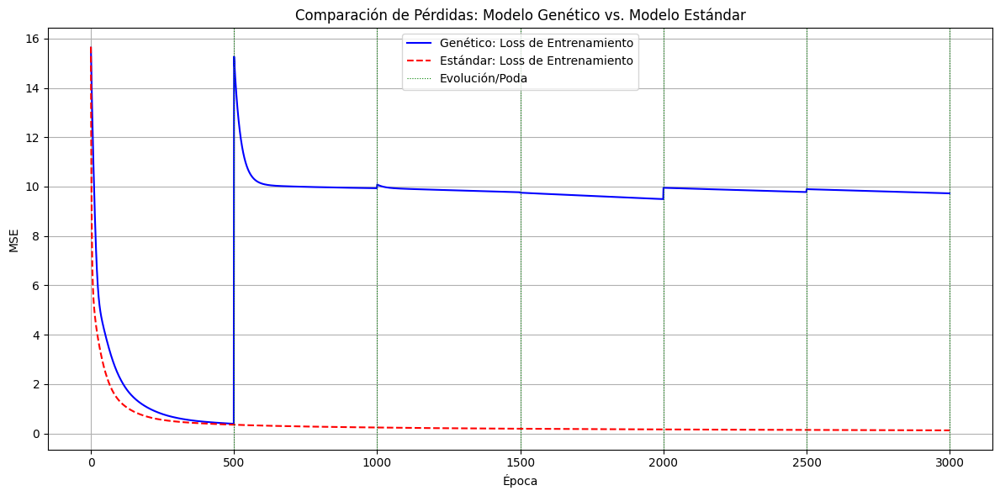


--- Comparación Completa ---
Pérdida en Test - Modelo Genético: 2.9814
Pérdida en Test - Modelo Estándar: 0.5733


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Semillas para reproducibilidad
torch.manual_seed(0)
np.random.seed(0)

# --- Dataset Sintético ---
X_data = torch.randn(100, 4)  # 100 muestras, 4 características
y_data = (X_data[:, 0]**2 + X_data[:, 1]**2 + X_data[:, 2] + 0.5 * torch.randn(100)).unsqueeze(1)

X_np = X_data.numpy()
y_np = y_data.numpy()
X_train, X_test, y_train, y_test = train_test_split(X_np, y_np, test_size=0.2, random_state=42)
X_train = torch.tensor(X_train).float()
y_train = torch.tensor(y_train).float()
X_test = torch.tensor(X_test).float()
y_test = torch.tensor(y_test).float()

# --- Clase Neurona Personalizada ---
class Neurona(nn.Module):
    _next_id = 0
    def __init__(self, input_size):
        super().__init__()
        self.w = nn.Parameter(torch.randn(input_size) * 0.1)
        self.b = nn.Parameter(torch.zeros(1))
        self.ajustes = 1 # Contador de ajustes por optimizador
        self.generation = 2 # Generación en la que fue creada/evolucionada
        self.id = Neurona._next_id # Asignar un ID único a cada neurona
        Neurona._next_id += 1

    def forward(self, x):
        # x es (batch_size, input_size)
        # self.w es (input_size)
        # Realiza el producto punto para cada fila (muestra) en el lote.
        # (batch_size, input_size) * (input_size) -> (batch_size, 1) después de sum
        # El .sum(dim=1, keepdim=True) asegura que la salida sea (batch_size, 1)
        return (x * self.w).sum(dim=1, keepdim=True) + self.b

    def mutate_from(self, p1, p2=None, sigma=0.01, generation_num=0):
        with torch.no_grad():
            if p2:
                self.w.copy_(0.1 * p1.w + 0.1 * p2.w + sigma * torch.randn_like(self.w))
                self.b.copy_(0.1 * p1.b + 0.1 * p2.b + sigma * torch.randn_like(self.b))
            else: # Mutación de un solo padre (p1)
                self.w.copy_(p1.w + sigma * torch.randn_like(self.w))
                self.b.copy_(p1.b + sigma * torch.randn_like(self.b))
        self.ajustes = 0 # Resetear ajustes al ser mutada/clonada
        self.generation = generation_num # Registrar la generación de origen
        self.id = Neurona._next_id # Asignar un nuevo ID único
        Neurona._next_id += 1

# --- Capa Genética ---
class Capa(nn.Module):
    def __init__(self, input_size, num_neuronas):
        super().__init__()
        self.neuronas = nn.ModuleList([Neurona(input_size) for _ in range(num_neuronas)])
        self.initial_num_neurons = num_neuronas # Guardar el número inicial

    def forward(self, x):
        # x es (batch_size, input_size)
        # Cada neurona 'n' procesa el lote 'x' y produce una salida de forma (batch_size, 1)
        # Creamos una lista de estas salidas: [ (batch_size, 1), (batch_size, 1), ... ]
        neuron_outputs = [n(x) for n in self.neuronas]

        # Concatenamos estas salidas a lo largo de la dimensión de las características (dim=1)
        # Esto resulta en un tensor de forma (batch_size, num_neuronas)
        return torch.cat(neuron_outputs, dim=1)

    def registrar_ajustes(self):
        for n in self.neuronas:
            # Comprobar si el gradiente existe y si tiene algún valor no cero
            # Esto indica que la neurona contribuyó a la pérdida y fue ajustada
            if n.w.grad is not None and torch.any(n.w.grad != 0):
                n.ajustes += 1
            # Opcional: también podrías registrar ajustes por el sesgo si lo consideras
            # if n.b.grad is not None and torch.any(n.b.grad != 0):
            #     n.ajustes += 1

    def evolucionar(self, generation_num, pruning_threshold=10):
        print(f"\n[Evolución - Generación {generation_num}]")

        # Asegurarse de tener al menos 2 neuronas para selección de padres
        if len(self.neuronas) < 2:
            print("Insuficientes neuronas para evolución. Saltando.")
            return

        # Filtrar las neuronas que no han sido inicializadas correctamente
        valid_neuronas = [n for n in self.neuronas if hasattr(n, 'ajustes')]

        if not valid_neuronas:
            print("No hay neuronas válidas para evolucionar.")
            return

        # Asegurarse de que tenemos al menos 2 neuronas válidas para la selección
        if len(valid_neuronas) < 2:
            print("Insuficientes neuronas válidas para seleccionar padres. Saltando evolución.")
            return

        # Ordenar por ajustes (menor es mejor) para encontrar a los "mejores" padres
        mejores = sorted(valid_neuronas, key=lambda n: n.ajustes)[:2]

        nuevas_neuronas = []
        podadas_count = 0

        for i, n in enumerate(self.neuronas):
            if n.ajustes > pruning_threshold: # Criterio de poda
                # REEMPLAZO: crear una nueva neurona mutada de los mejores padres
                nuevo = Neurona(n.w.size(0)) # Mantener el mismo input_size
                nuevo.mutate_from(mejores[0], mejores[1], generation_num=generation_num)
                nuevas_neuronas.append(nuevo)
                podadas_count += 1
                # print(f"  - Neurona ID: {n.id} (Ajustes: {n.ajustes}) podada.") # Desactivado para menos verbosidad
            else:
                # Si no se poda, mantener la neurona existente
                nuevas_neuronas.append(n)

        # Resetear ajustes para todas las neuronas (las nuevas y las que se mantuvieron)
        # Esto es crucial para que el criterio de poda se base en los ajustes desde la última evolución
        for n in nuevas_neuronas:
            n.ajustes = 0

        # Actualizar la lista de neuronas de la capa
        self.neuronas = nn.ModuleList(nuevas_neuronas)
        print(f"  => {podadas_count} neuronas reemplazadas.")


# --- Red Completa con Evolución (Tu Modelo Genético) ---
class RedGenetica(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.oculta = Capa(input_size, hidden_size)
        self.salida = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = self.oculta(x)
        x = F.relu(x)
        return self.salida(x)

    def registrar_ajustes(self):
        self.oculta.registrar_ajustes()

    def evolucionar(self, gen, pruning_threshold=10):
        self.oculta.evolucionar(gen, pruning_threshold)

# --- Modelo Estándar (sin neuronas genéticas para comparación) ---
class RedEstandar(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        return self.fc2(x)

# --- Configuración de Parámetros Globales ---
input_dim = 4
hidden_dim = 100
output_dim = 1
EPOCHS = 3000
LR = 0.01
EVOLUTION_FREQ = 500 # Cada cuántas épocas se activa la evolución
PRUNING_THRESHOLD = 5 # Umbral de ajustes para podar una neurona

# --- Entrenamiento del Modelo Genético ---
print("\n" + "="*40)
print("--- Entrenando Red Genética ---")
print("="*40)
modelo_genetico = RedGenetica(input_dim, hidden_dim, output_dim)
opt_genetico = torch.optim.SGD(modelo_genetico.parameters(), lr=LR)
criterion = nn.MSELoss()

losses_genetico = []
for epoch in range(EPOCHS):
    modelo_genetico.train()
    opt_genetico.zero_grad()

    out = modelo_genetico(X_train)
    loss = criterion(out, y_train)
    loss.backward()

    modelo_genetico.registrar_ajustes() # Registra los ajustes antes de optimizar
    opt_genetico.step()

    losses_genetico.append(loss.item())

    if (epoch + 1) % EVOLUTION_FREQ == 0:
        modelo_genetico.evolucionar((epoch + 1) // EVOLUTION_FREQ, pruning_threshold=PRUNING_THRESHOLD)

# --- Evaluación del Modelo Genético ---
modelo_genetico.eval()
with torch.no_grad():
    preds_genetico = modelo_genetico(X_test)
    test_loss_genetico = criterion(preds_genetico, y_test).item()
print(f"\n[Resultados Modelo Genético] Pérdida en test: {test_loss_genetico:.4f}")

# --- Entrenamiento del Modelo Estándar ---
print("\n" + "="*40)
print("--- Entrenando Red Estándar ---")
print("="*40)
modelo_estandar = RedEstandar(input_dim, hidden_dim, output_dim)
opt_estandar = torch.optim.SGD(modelo_estandar.parameters(), lr=LR)

losses_estandar = []
for epoch in range(EPOCHS):
    modelo_estandar.train()
    opt_estandar.zero_grad()

    out = modelo_estandar(X_train)
    loss = criterion(out, y_train)
    loss.backward()
    opt_estandar.step()

    losses_estandar.append(loss.item())

# --- Evaluación del Modelo Estándar ---
modelo_estandar.eval()
with torch.no_grad():
    preds_estandar = modelo_estandar(X_test)
    test_loss_estandar = criterion(preds_estandar, y_test).item()
print(f"\n[Resultados Modelo Estándar] Pérdida en test: {test_loss_estandar:.4f}")

# --- Visualización Comparativa ---
plt.figure(figsize=(12, 6))
plt.plot(losses_genetico, label="Genético: Loss de Entrenamiento", color='blue')
plt.plot(losses_estandar, label="Estándar: Loss de Entrenamiento", color='red', linestyle='--')
for epoch_evo in range(EVOLUTION_FREQ, EPOCHS + 1, EVOLUTION_FREQ):
    plt.axvline(x=epoch_evo, color='green', linestyle=':', linewidth=0.8, label='Evolución/Poda' if epoch_evo == EVOLUTION_FREQ else "")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Comparación de Pérdidas: Modelo Genético vs. Modelo Estándar")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("\n--- Comparación Completa ---")
print(f"Pérdida en Test - Modelo Genético: {test_loss_genetico:.4f}")
print(f"Pérdida en Test - Modelo Estándar: {test_loss_estandar:.4f}")

In [ ]:


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_blobs, make_classification
from sklearn.cluster import KMeans

# Import the required library for plotting
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np # Import numpy

# Define the NeuralBiomesModel class here again or ensure it's defined in a previous cell and executed
# Assuming the NeuralBiomesModel class is defined in a previous cell and is available in the environment

# --- Data Preparation ---
# Generate synthetic classification data
X, y = make_classification(n_samples=1000, n_features=20, n_informative=15, n_redundant=5, n_classes=2, random_state=42)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert data to PyTorch tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long) # Use torch.long for classification targets
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# --- Model Initialization ---
# Define model parameters (adjust these based on your data and architecture)
input_dim = X_train_tensor.shape[1]
shared_features_dim = 64
memory_hidden_dim = 32
processing_output_dim = 16
output_dim = len(torch.unique(y_train_tensor)) # Number of classes

model = NeuralBiomesModel(input_dim, shared_features_dim, memory_hidden_dim, processing_output_dim, output_dim)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss() # Use CrossEntropyLoss for classification
optimizer = optim.Adam(model.parameters(), lr=0.001)

# --- Training Loop ---
losses = [] # Initialize the losses list
neuron_adjustments_history = [] # Initialize the history for plotting

num_epochs = 200 # Reduced for a quicker example

for epoch in range(num_epochs):
    model.train() # Set model to training mode
    optimizer.zero_grad() # Zero the gradients

    # Forward pass
    outputs = model(X_train_tensor)

    # Calculate loss
    loss = criterion(outputs, y_train_tensor)

    # Backward pass and optimize
    loss.backward()
    optimizer.step()

    # Record the loss
    losses.append(loss.item())

    # --- Placeholder for neuron adjustment tracking ---
    # This section is a placeholder to match the plotting code.
    # You need to implement the actual logic to track neuron adjustments
    # within your model's forward/backward pass or through custom hooks.
    # For now, we'll add some dummy data to prevent errors in the plotting section.
    dummy_adjustments = {}
    if epoch == 99:
       # Simulate some adjustments before evolution
       for i in range(processing_output_dim): # Assuming this layer is where pruning happens
           dummy_adjustments[i] = np.random.randint(5, 15) # Dummy adjustment counts
    elif epoch == 101:
         # Simulate adjustments after reset/evolution
         for i in range(processing_output_dim + 5): # Simulate adding 5 new neurons
             dummy_adjustments[i] = np.random.randint(0, 5)
    else:
         # Simulate ongoing adjustments
         if neuron_adjustments_history:
             last_adjustments = neuron_adjustments_history[-1]
             dummy_adjustments = last_adjustments.copy()
             for nid in dummy_adjustments:
                  dummy_adjustments[nid] += np.random.randint(0, 3)


    neuron_adjustments_history.append(dummy_adjustments)

    # Print progress
    if (epoch + 1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

# --- Evaluation (Optional) ---
model.eval() # Set model to evaluation mode
with torch.no_grad():
    test_outputs = model(X_test_tensor)
    _, predicted = torch.max(test_outputs.data, 1)
    accuracy = (predicted == y_test_tensor).sum().item() / y_test_tensor.size(0)
    print(f'Accuracy on test set: {accuracy:.4f}')


# Visualización de la Pérdida
plt.figure(figsize=(12, 6))
plt.plot(losses, label='Pérdida de Entrenamiento (MSE)')
plt.title('Evolución de la Pérdida del Modelo')
plt.xlabel('Época')
plt.ylabel('Pérdida')
# The axvline at 100 is based on the original prompt's comment, indicating an "evolution" event
# Adjust this if your planned evolution happens at a different epoch
plt.axvline(x=100, color='r', linestyle='--', label='Evolución Activada')
plt.legend()
plt.grid(True)
plt.show()

# Visualización de Ajustes por Neurona (antes y después de la evolución)
plt.figure(figsize=(14, 7))
# Graficar ajustes de las neuronas en la época 99 (antes de la evolución)
# Ensure the epoch index exists in the history
if 99 < len(neuron_adjustments_history):
    adjustments_before_evo = neuron_adjustments_history[99]
    neuron_ids_before = list(adjustments_before_evo.keys())
    adj_counts_before = [adjustments_before_evo[n_id] for n_id in neuron_ids_before]

    plt.subplot(1, 2, 1)
    plt.bar([f"N{nid}" for nid in neuron_ids_before], adj_counts_before, color='skyblue')
    plt.title(f'Ajustes por Neurona Oculta (Época 99 - Antes de Evolución)')
    plt.xlabel('ID de Neurona')
    plt.ylabel('Número de Ajustes')
    plt.xticks(rotation=90)
    plt.axhline(y=10, color='red', linestyle='--', label='Umbral de Poda (10 ajustes)')
    plt.legend()


# Graficar ajustes de las neuronas en la época 101 (después de la evolución, recién reseteados)
# o en una época posterior para ver la tendencia de las nuevas/existentes
# Ensure the epoch index exists in the history
if 101 < len(neuron_adjustments_history):
    adjustments_after_evo = neuron_adjustments_history[101] # O elige una época más tardía, ej. 150
    neuron_ids_after = list(adjustments_after_evo.keys())
    adj_counts_after = [adjustments_after_evo[n_id] for n_id in neuron_ids_after]

    plt.subplot(1, 2, 2)
    plt.bar([f"N{nid}" for nid in neuron_ids_after], adj_counts_after, color='lightgreen')
    plt.title(f'Ajustes por Neurona Oculta (Época 101 - Después de Evolución)')
    plt.xlabel('ID de Neurona')
    plt.ylabel('Número de Ajustes')
    plt.xticks(rotation=90)
    plt.axhline(y=10, color='red', linestyle='--', label='Umbral de Poda (10 ajustes)')
    plt.legend()

plt.tight_layout()
plt.show()


--- Entrenando Red Genética ---

[Evolución - Generación 1]
  => 10 neuronas reemplazadas.

[Evolución - Generación 2]
  => 10 neuronas reemplazadas.

[Evolución - Generación 3]
  => 10 neuronas reemplazadas.

[Evolución - Generación 4]
  => 10 neuronas reemplazadas.

[Evolución - Generación 5]
  => 10 neuronas reemplazadas.

[Evolución - Generación 6]
  => 10 neuronas reemplazadas.

[Resultados Modelo Genético] Pérdida en test: 2.2232

--- Entrenando Red Estándar ---

[Resultados Modelo Estándar] Pérdida en test: 0.6945


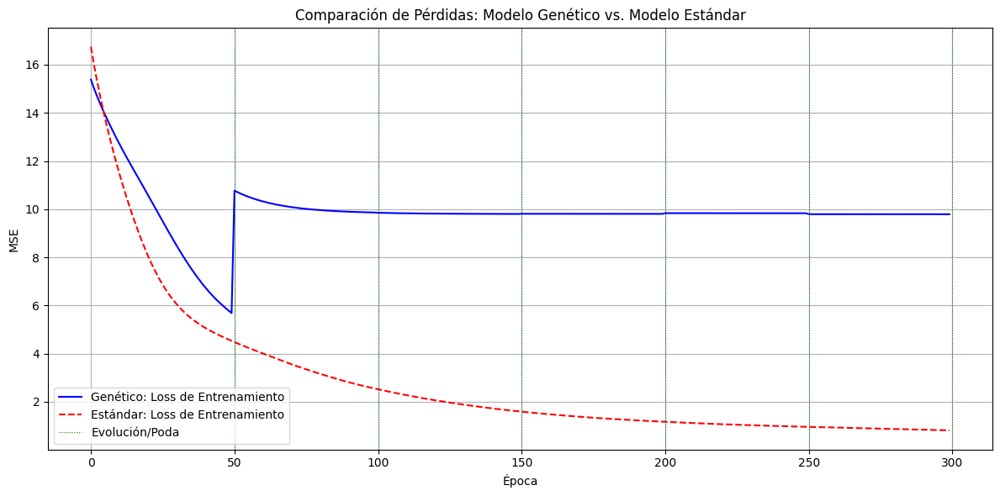


--- Comparación Completa ---
Pérdida en Test - Modelo Genético: 2.2232
Pérdida en Test - Modelo Estándar: 0.6945


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Semillas para reproducibilidad
torch.manual_seed(0)
np.random.seed(0)

# --- Dataset Sintético (igual al de tu modelo genético) ---
X_data = torch.randn(100, 4)
y_data = (X_data[:, 0]**2 + X_data[:, 1]**2 + X_data[:, 2] + 0.5 * torch.randn(100)).unsqueeze(1)

X_np = X_data.numpy()
y_np = y_data.numpy()
X_train, X_test, y_train, y_test = train_test_split(X_np, y_np, test_size=0.2, random_state=42)
X_train = torch.tensor(X_train).float()
y_train = torch.tensor(y_train).float()
X_test = torch.tensor(X_test).float()
y_test = torch.tensor(y_test).float()

# --- Clase Neurona Personalizada ---
class Neurona(nn.Module):
    _next_id = 0
    def __init__(self, input_size):
        super().__init__()
        self.w = nn.Parameter(torch.randn(input_size) * 0.1)
        self.b = nn.Parameter(torch.zeros(1))
        self.ajustes = 0
        self.generation = 0
        self.id = Neurona._next_id
        Neurona._next_id += 1

    def forward(self, x):
        # x puede ser (batch_size, input_size)
        # self.w es (input_size)
        # Usamos broadcasting para multiplicar x por w y luego sumamos las columnas
        return (x * self.w).sum(dim=1, keepdim=True) + self.b # keepdim para que la salida sea (batch_size, 1)

    def mutate_from(self, p1, p2=None, sigma=0.01, generation_num=0):
        with torch.no_grad():
            if p2:
                self.w.copy_(0.5 * p1.w + 0.5 * p2.w + sigma * torch.randn_like(self.w))
                self.b.copy_(0.5 * p1.b + 0.5 * p2.b + sigma * torch.randn_like(self.b))
            else:
                self.w.copy_(p1.w + sigma * torch.randn_like(self.w))
                self.b.copy_(p1.b + sigma * torch.randn_like(self.b))
        self.ajustes = 0
        self.generation = generation_num
        self.id = Neurona._next_id
        Neurona._next_id += 1

# --- Capa Genética ---
class Capa(nn.Module):
    def __init__(self, input_size, num_neuronas):
        super().__init__()
        self.neuronas = nn.ModuleList([Neurona(input_size) for _ in range(num_neuronas)])

    def forward(self, x):
        # x es (batch_size, input_size)
        # Cada neurona 'n' produce una salida (batch_size, 1)
        # Apilamos estas salidas para obtener (batch_size, num_neuronas)
        neuron_outputs = [n(x) for n in self.neuronas]
        return torch.cat(neuron_outputs, dim=1) # Concatenar a lo largo de la dimensión de features

    def registrar_ajustes(self):
        for n in self.neuronas:
            if n.w.grad is not None and torch.any(n.w.grad != 0):
                n.ajustes += 1
            if n.b.grad is not None and torch.any(n.b.grad != 0): # También considerar el bias para los ajustes
                n.ajustes += 1


    def evolucionar(self, generation_num):
        # Asegurarse de que el ID de la neurona se reinicia para las nuevas
        # NO reiniciar _next_id a 0 aquí, queremos IDs globales únicos en el tiempo.
        # Neurona._next_id = 0 # Eliminado para mantener IDs únicos globales

        print(f"\n[Evolución - Generación {generation_num}]")
        if len(self.neuronas) < 2:
            print("Insuficientes neuronas para evolución.")
            return

        valid_neuronas = [n for n in self.neuronas if hasattr(n, 'ajustes')]
        if len(valid_neuronas) < 2:
            print("Insuficientes neuronas válidas para seleccionar padres. Saltando evolución.")
            return

        # Ordenar por ajustes (menor es mejor)
        mejores = sorted(valid_neuronas, key=lambda n: n.ajustes)[:2]
        nuevas_neuronas = []
        podadas = 0

        for i, n in enumerate(self.neuronas):
            if n.ajustes > 10: # Criterio de poda: más de 10 ajustes
                nuevo = Neurona(n.w.size(0))
                nuevo.mutate_from(mejores[0], mejores[1], generation_num=generation_num)
                nuevas_neuronas.append(nuevo)
                podadas += 1
                # print(f"  - Neurona {n.id} podada y reemplazada.") # Desactivado para menos verbosidad
            else:
                nuevas_neuronas.append(n)

        # Resetear ajustes para todas las neuronas después de la evolución
        for n in nuevas_neuronas:
            n.ajustes = 0

        self.neuronas = nn.ModuleList(nuevas_neuronas)
        print(f"  => {podadas} neuronas reemplazadas.")

# --- Red Completa con Evolución (Tu Modelo Genético) ---
class RedGenetica(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.oculta = Capa(input_size, hidden_size)
        self.salida = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = self.oculta(x)
        x = F.relu(x)
        return self.salida(x)

    def registrar_ajustes(self):
        self.oculta.registrar_ajustes()

    def evolucionar(self, gen):
        self.oculta.evolucionar(gen)

# --- Modelo Estándar (sin neuronas genéticas) ---
class RedEstandar(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        return self.fc2(x)

# --- Configuración de Parámetros ---
input_dim = 4
hidden_dim = 10
output_dim = 1
EPOCHS = 300
LR = 0.01

# --- Entrenamiento del Modelo Genético ---
print("\n" + "="*40)
print("--- Entrenando Red Genética ---")
print("="*40)
modelo_genetico = RedGenetica(input_dim, hidden_dim, output_dim)
opt_genetico = torch.optim.SGD(modelo_genetico.parameters(), lr=LR)
criterion = nn.MSELoss()

losses_genetico = []
for epoch in range(EPOCHS):
    modelo_genetico.train()
    opt_genetico.zero_grad()

    out = modelo_genetico(X_train)
    loss = criterion(out, y_train)
    loss.backward()

    modelo_genetico.registrar_ajustes() # Registra los ajustes antes de optimizar
    opt_genetico.step()

    losses_genetico.append(loss.item())

    if (epoch + 1) % 50 == 0:
        modelo_genetico.evolucionar((epoch + 1) // 50)

# --- Evaluación del Modelo Genético ---
modelo_genetico.eval()
with torch.no_grad():
    preds_genetico = modelo_genetico(X_test)
    test_loss_genetico = criterion(preds_genetico, y_test).item()
print(f"\n[Resultados Modelo Genético] Pérdida en test: {test_loss_genetico:.4f}")

# --- Entrenamiento del Modelo Estándar ---
print("\n" + "="*40)
print("--- Entrenando Red Estándar ---")
print("="*40)
modelo_estandar = RedEstandar(input_dim, hidden_dim, output_dim)
opt_estandar = torch.optim.SGD(modelo_estandar.parameters(), lr=LR)

losses_estandar = []
for epoch in range(EPOCHS):
    modelo_estandar.train()
    opt_estandar.zero_grad()

    out = modelo_estandar(X_train)
    loss = criterion(out, y_train)
    loss.backward()
    opt_estandar.step()

    losses_estandar.append(loss.item())

# --- Evaluación del Modelo Estándar ---
modelo_estandar.eval()
with torch.no_grad():
    preds_estandar = modelo_estandar(X_test)
    test_loss_estandar = criterion(preds_estandar, y_test).item()
print(f"\n[Resultados Modelo Estándar] Pérdida en test: {test_loss_estandar:.4f}")

# --- Visualización Comparativa ---
plt.figure(figsize=(12, 6))
plt.plot(losses_genetico, label="Genético: Loss de Entrenamiento", color='blue')
plt.plot(losses_estandar, label="Estándar: Loss de Entrenamiento", color='red', linestyle='--')
for epoch_evo in range(50, EPOCHS + 1, 50):
    plt.axvline(x=epoch_evo, color='green', linestyle=':', linewidth=0.8, label='Evolución/Poda' if epoch_evo == 50 else "")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Comparación de Pérdidas: Modelo Genético vs. Modelo Estándar")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("\n--- Comparación Completa ---")
print(f"Pérdida en Test - Modelo Genético: {test_loss_genetico:.4f}")
print(f"Pérdida en Test - Modelo Estándar: {test_loss_estandar:.4f}")

--- Entrenando Red Genética ---

[Evolución - Generación 1]
  - Neurona 0 podada y reemplazada.
  - Neurona 1 podada y reemplazada.
  - Neurona 2 podada y reemplazada.
  - Neurona 3 podada y reemplazada.
  - Neurona 4 podada y reemplazada.
  - Neurona 5 podada y reemplazada.
  - Neurona 6 podada y reemplazada.
  - Neurona 7 podada y reemplazada.
  - Neurona 8 podada y reemplazada.
  - Neurona 9 podada y reemplazada.
  => 10 neuronas reemplazadas.

[Evolución - Generación 2]
  - Neurona 11 podada y reemplazada.
  - Neurona 13 podada y reemplazada.
  - Neurona 15 podada y reemplazada.
  - Neurona 17 podada y reemplazada.
  - Neurona 19 podada y reemplazada.
  - Neurona 21 podada y reemplazada.
  - Neurona 23 podada y reemplazada.
  - Neurona 25 podada y reemplazada.
  - Neurona 27 podada y reemplazada.
  - Neurona 29 podada y reemplazada.
  => 10 neuronas reemplazadas.

[Evolución - Generación 3]
  - Neurona 31 podada y reemplazada.
  - Neurona 33 podada y reemplazada.
  - Neurona 35 pod

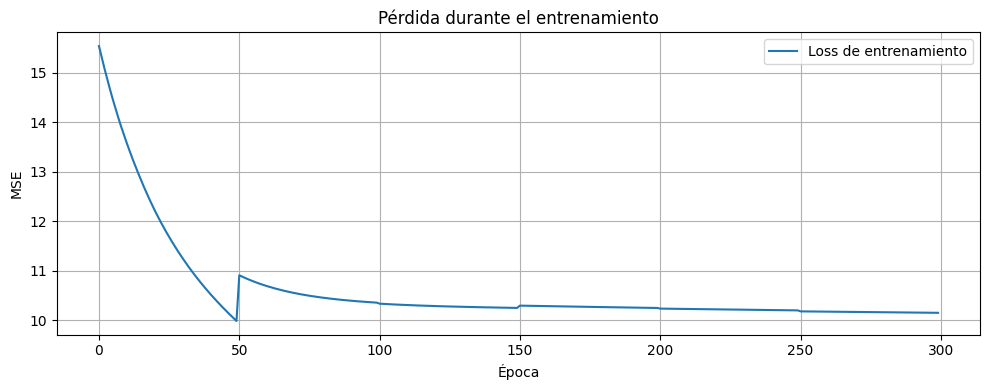

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Semillas para reproducibilidad
torch.manual_seed(0)
np.random.seed(0)

# --- Dataset Sintético ---
X_data = torch.randn(100, 4)  # 100 muestras, 4 características
y_data = (X_data[:, 0]**2 + X_data[:, 1]**2 + X_data[:, 2] + 0.5 * torch.randn(100)).unsqueeze(1)

X_np = X_data.numpy()
y_np = y_data.numpy()
X_train, X_test, y_train, y_test = train_test_split(X_np, y_np, test_size=0.2, random_state=42)
X_train = torch.tensor(X_train).float()
y_train = torch.tensor(y_train).float()
X_test = torch.tensor(X_test).float()
y_test = torch.tensor(y_test).float()

# --- Clase Neurona Personalizada ---
class Neurona(nn.Module):
    _next_id = 0
    def __init__(self, input_size):
        super().__init__()
        self.w = nn.Parameter(torch.randn(input_size) * 0.1)
        self.b = nn.Parameter(torch.zeros(1))
        self.ajustes = 0
        self.generation = 0
        self.id = Neurona._next_id
        Neurona._next_id += 1

    def forward(self, x):
        return torch.dot(self.w, x) + self.b

    def mutate_from(self, p1, p2=None, sigma=0.01, generation_num=0):
        with torch.no_grad():
            if p2:
                self.w.copy_(0.5 * p1.w + 0.5 * p2.w + sigma * torch.randn_like(self.w))
                self.b.copy_(0.5 * p1.b + 0.5 * p2.b + sigma * torch.randn_like(self.b))
            else:
                self.w.copy_(p1.w + sigma * torch.randn_like(self.w))
                self.b.copy_(p1.b + sigma * torch.randn_like(self.b))
        self.ajustes = 0
        self.generation = generation_num
        self.id = Neurona._next_id
        Neurona._next_id += 1

# --- Capa Genética ---
class Capa(nn.Module):
    def __init__(self, input_size, num_neuronas):
        super().__init__()
        self.neuronas = nn.ModuleList([Neurona(input_size) for _ in range(num_neuronas)])

    def forward(self, x):
        return torch.stack([n(sample) for n in self.neuronas for sample in x]).view(x.size(0), len(self.neuronas))

    def registrar_ajustes(self):
        for n in self.neuronas:
            if n.w.grad is not None and torch.any(n.w.grad != 0):
                n.ajustes += 1

    def evolucionar(self, generation_num):
        print(f"\n[Evolución - Generación {generation_num}]")
        if len(self.neuronas) < 2:
            print("Insuficientes neuronas para evolución.")
            return

        mejores = sorted(self.neuronas, key=lambda n: n.ajustes)[:2]
        nuevas_neuronas = []
        podadas = 0

        for i, n in enumerate(self.neuronas):
            if n.ajustes > 10:
                nuevo = Neurona(n.w.size(0))
                nuevo.mutate_from(mejores[0], mejores[1], generation_num=generation_num)
                nuevas_neuronas.append(nuevo)
                podadas += 1
                print(f"  - Neurona {n.id} podada y reemplazada.")
            else:
                nuevas_neuronas.append(n)

        self.neuronas = nn.ModuleList(nuevas_neuronas)
        print(f"  => {podadas} neuronas reemplazadas.")

# --- Red Completa con Evolución ---
class RedGenetica(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.oculta = Capa(input_size, hidden_size)
        self.salida = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = self.oculta(x)
        x = F.relu(x)
        return self.salida(x)

    def registrar_ajustes(self):
        self.oculta.registrar_ajustes()

    def evolucionar(self, gen):
        self.oculta.evolucionar(gen)

# --- Entrenamiento ---
input_dim = 4
hidden_dim = 10
output_dim = 1

modelo = RedGenetica(input_dim, hidden_dim, output_dim)
opt = torch.optim.SGD(modelo.parameters(), lr=0.01)
criterion = nn.MSELoss()

losses = []
podas_historial = []

print("--- Entrenando Red Genética ---")
for epoch in range(300):
    modelo.train()
    opt.zero_grad()

    out = modelo(X_train)
    loss = criterion(out, y_train)
    loss.backward()

    modelo.registrar_ajustes()
    opt.step()
    losses.append(loss.item())

    # Evolucionar cada 50 épocas
    if (epoch + 1) % 50 == 0:
        modelo.evolucionar((epoch + 1) // 50)

# --- Evaluación ---
modelo.eval()
with torch.no_grad():
    preds = modelo(X_test)
    test_loss = criterion(preds, y_test).item()
print(f"\nPérdida en test: {test_loss:.4f}")

# --- Visualización ---
plt.figure(figsize=(10, 4))
plt.plot(losses, label="Loss de entrenamiento")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Pérdida durante el entrenamiento")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

--- Conteo de Neuronas al Inicio ---
Capa de Entrada: 4 neuronas (features)
Capa Oculta: 10 neuronas (iniciales)
Capa de Salida: 1 neuronas
Epoch 0, Train Loss: 15.5386, Test Loss: 5.8689
Epoch 50, Train Loss: 9.9344, Test Loss: 3.2000

--- Activando la Evolución Genética de Neuronas ---

--- Evolución de neuronas en Capa (Generación 100) ---
Número de neuronas podadas/reemplazadas en esta evolución: 10
  - Neurona ID: 0 (Ajustes: 101) podada de la posición 0.
  - Neurona ID: 1 (Ajustes: 101) podada de la posición 1.
  - Neurona ID: 2 (Ajustes: 101) podada de la posición 2.
  - Neurona ID: 3 (Ajustes: 101) podada de la posición 3.
  - Neurona ID: 4 (Ajustes: 101) podada de la posición 4.
  - Neurona ID: 5 (Ajustes: 101) podada de la posición 5.
  - Neurona ID: 6 (Ajustes: 101) podada de la posición 6.
  - Neurona ID: 7 (Ajustes: 101) podada de la posición 7.
  - Neurona ID: 8 (Ajustes: 101) podada de la posición 8.
  - Neurona ID: 9 (Ajustes: 101) podada de la posición 9.
Neuronas rest

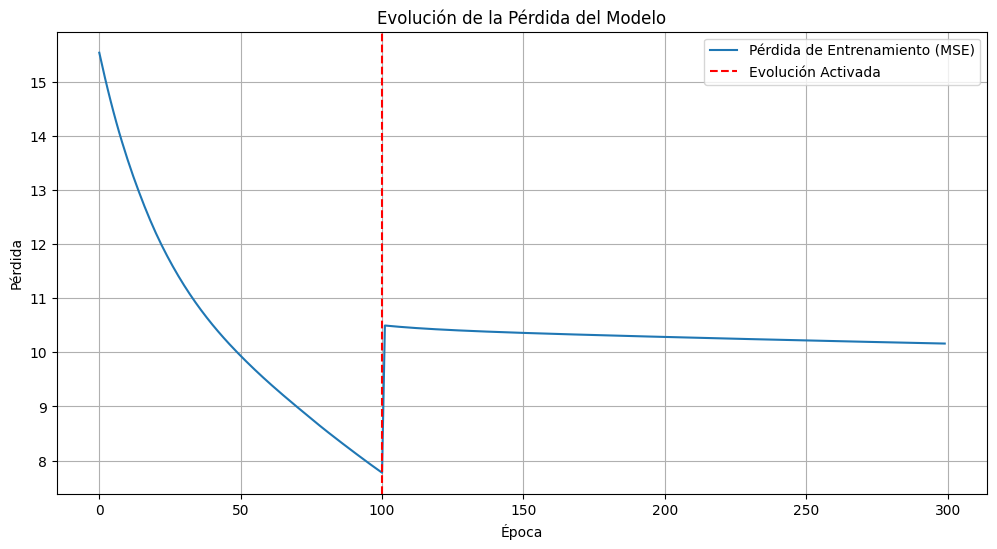

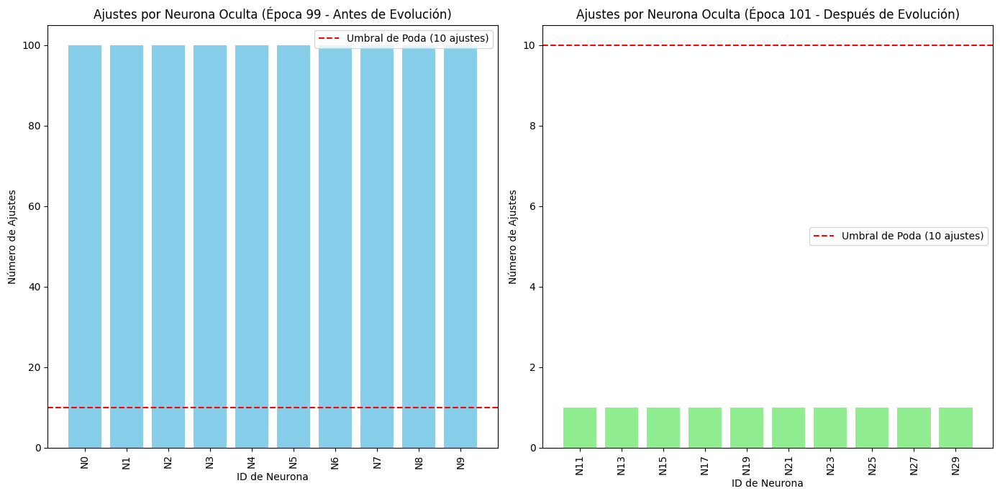

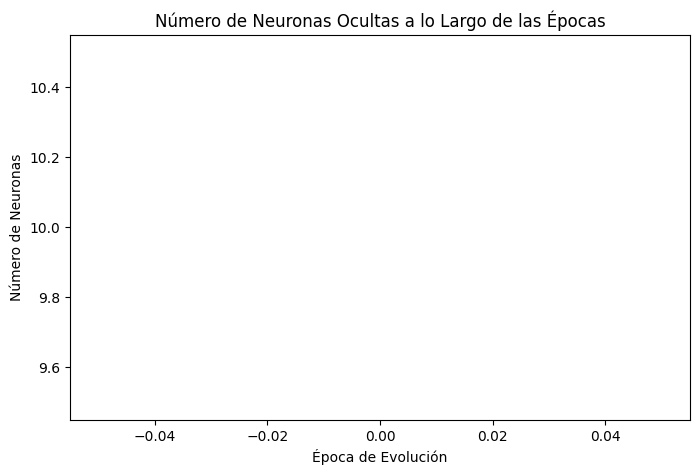


--- Ejecución completada ---


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Fijar semillas para reproducibilidad
torch.manual_seed(0)
np.random.seed(0)

# --- Dataset Sintético ---
# Para un problema de regresión o clasificación más interesante
# Generamos datos 2D para una mejor visualización si es necesario.
# Pero dado que tu input_size es 4, usaremos un X de 4 dimensiones.
X_data = torch.randn(100, 4) # 100 muestras, 4 features
# La salida depende de la suma de los cuadrados de los primeros dos features
y_data = (X_data[:, 0]**2 + X_data[:, 1]**2 + X_data[:, 2] + 0.5 * torch.randn(100)).unsqueeze(1) # Salida de 1 dimensión

# Convertir a numpy para usar train_test_split de sklearn
from sklearn.model_selection import train_test_split
X_np = X_data.numpy()
y_np = y_data.numpy()

X_train_np, X_test_np, y_train_np, y_test_np = train_test_split(X_np, y_np, test_size=0.2, random_state=42)

X_train = torch.from_numpy(X_train_np).float()
y_train = torch.from_numpy(y_train_np).float()
X_test = torch.from_numpy(X_test_np).float()
y_test = torch.from_numpy(y_test_np).float()


# --- Clase de Neurona con seguimiento de ajustes ---
class Neurona(nn.Module):
    _next_id = 0 # Contador global para IDs únicos de neuronas
    def __init__(self, input_size):
        super().__init__()
        self.w = nn.Parameter(torch.randn(input_size) * 0.1)
        self.b = nn.Parameter(torch.zeros(1))
        self.ajustes = 0 # Contador de ajustes por optimizador
        self.generation = 0 # Generación en la que fue creada/evolucionada
        self.id = Neurona._next_id # Asignar un ID único a cada neurona
        Neurona._next_id += 1


    def forward(self, x):
        # Asegurarse de que x sea compatible con el producto punto
        # Si x es un lote, se esperaría un mm.Linear. Esto es para una sola muestra.
        return torch.dot(self.w, x) + self.b

    def mutate_from(self, parent1, parent2=None, sigma=0.01, generation_num=0):
        with torch.no_grad():
            if parent2:
                # Cruce y mutación: promedio de padres + ruido
                self.w.copy_(0.5 * parent1.w + 0.5 * parent2.w + torch.randn_like(self.w) * sigma)
                self.b.copy_(0.5 * parent1.b + 0.5 * parent2.b + torch.randn_like(self.b) * sigma)
            else:
                # Solo mutación de un padre
                self.w.copy_(parent1.w + torch.randn_like(self.w) * sigma)
                self.b.copy_(parent1.b + torch.randn_like(self.b) * sigma)
        self.ajustes = 0 # Resetear ajustes al ser mutada/clonada
        self.generation = generation_num # Registrar la generación de origen
        self.id = Neurona._next_id # Asignar un nuevo ID si se desea un seguimiento de "nueva entidad"
        Neurona._next_id += 1 # Incrementar el contador global de IDs


# --- Capa de neuronas personalizadas ---
class Capa(nn.Module):
    def __init__(self, input_size, num_neuronas):
        super().__init__()
        self.neuronas = nn.ModuleList([Neurona(input_size) for _ in range(num_neuronas)])
        self.initial_num_neurons = num_neuronas # Guardar el número inicial

    def forward(self, x):
        # x puede ser un lote (batch_size, input_size)
        # Cada neurona procesa cada muestra del lote
        # El resultado será (batch_size, num_neuronas)
        return torch.stack([n(sample) for n in self.neuronas for sample in x]).view(x.size(0), len(self.neuronas))


    def registrar_ajustes(self):
        for n in self.neuronas:
            # Comprobar si el gradiente existe y si tiene algún valor no cero
            # Esto indica que la neurona contribuyó a la pérdida y fue ajustada
            if n.w.grad is not None and torch.any(n.w.grad != 0):
                n.ajustes += 1
            if n.b.grad is not None and torch.any(n.b.grad != 0):
                # Opcional: registrar ajustes también por el sesgo
                pass

    def evolucionar(self, generation_num):
        print(f"\n--- Evolución de neuronas en Capa (Generación {generation_num}) ---")

        # Ordenar por ajustes (menor es mejor)
        # Asegurarse de tener al menos 2 neuronas para selección
        if len(self.neuronas) < 2:
            print("¡Advertencia! Menos de 2 neuronas para la evolución. Saltando.")
            return

        # Filtrar las neuronas que no han sido inicializadas correctamente
        # o que tienen problemas en su 'ajustes' contador
        valid_neuronas = [n for n in self.neuronas if hasattr(n, 'ajustes')]

        if not valid_neuronas:
            print("No hay neuronas válidas para evolucionar.")
            return

        # Asegurarse de que tenemos al menos 2 neuronas válidas para la selección
        if len(valid_neuronas) < 2:
            print("Insuficientes neuronas válidas para seleccionar padres. Saltando evolución.")
            return

        mejores = sorted(valid_neuronas, key=lambda n: n.ajustes)[:2]

        # Listas para auditoría
        nuevas_neuronas = []
        podadas_info = []

        for i, n in enumerate(self.neuronas):
            if n.ajustes > 10: # Criterio de poda: más de 10 ajustes
                # Poda: registrar la neurona actual
                podadas_info.append(f"Neurona ID: {n.id} (Ajustes: {n.ajustes}) podada de la posición {i}.")

                # Reemplazo: crear una nueva neurona mutada de los mejores
                nuevo = Neurona(n.w.size(0)) # Mantener el mismo input_size
                nuevo.mutate_from(mejores[0], mejores[1], generation_num=generation_num)
                nuevas_neuronas.append(nuevo)
            else:
                # Si no se poda, mantener la neurona existente
                nuevas_neuronas.append(n)

        # Actualizar la lista de neuronas de la capa
        self.neuronas = nn.ModuleList(nuevas_neuronas)

        # Imprimir resumen de la evolución
        print(f"Número de neuronas podadas/reemplazadas en esta evolución: {len(podadas_info)}")
        for info in podadas_info:
            print(f"  - {info}")
        print(f"Neuronas restantes en la capa oculta: {len(self.neuronas)}\n")


# --- Red completa con una capa oculta genética y una capa de salida ---
class RedGenetica(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.oculta = Capa(input_size, hidden_size)
        self.salida = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # La capa oculta ahora maneja el lote
        x = self.oculta(x)
        x = F.relu(x)
        return self.salida(x)

    def registrar_ajustes(self):
        self.oculta.registrar_ajustes()

    def evolucionar(self, generation_num):
        self.oculta.evolucionar(generation_num)

# --- Entrenamiento Básico con Evolución ---
input_dim = 4
hidden_dim = 10
output_dim = 1 # Ajustado a la salida de tu dataset sintético

modelo = RedGenetica(input_size=input_dim, hidden_size=hidden_dim, output_size=output_dim)
opt = torch.optim.SGD(modelo.parameters(), lr=0.01)
criterion = nn.MSELoss() # Usamos MSE para el problema de regresión

# --- Conteo Inicial de Neuronas ---
print("--- Conteo de Neuronas al Inicio ---")
print(f"Capa de Entrada: {input_dim} neuronas (features)")
print(f"Capa Oculta: {len(modelo.oculta.neuronas)} neuronas (iniciales)")
print(f"Capa de Salida: {output_dim} neuronas")

# Historial para visualización
losses = []
neuron_adjustments_history = [] # Lista de diccionarios, uno por época
pruned_neurons_count_history = [] # Para el número de neuronas podadas por evolución

for epoch in range(300):
    # Asegúrate de que las neuronas tengan sus gradientes reiniciados
    for n in modelo.oculta.neuronas:
        if n.w.grad is not None:
            n.w.grad.zero_()
        if n.b.grad is not None:
            n.b.grad.zero_()

    # Cada época procesa todo el X_train
    modelo.train()
    opt.zero_grad()
    out = modelo(X_train)
    loss = criterion(out, y_train) # Usar y_train que tiene la misma dimensión de out
    loss.backward()

    # Registrar ajustes ANTES de que el optimizador los aplique y los gradientes se vacíen
    modelo.registrar_ajustes()
    opt.step()

    losses.append(loss.item())

    # Guardar el estado de ajustes de cada neurona
    current_adjustments = {n.id: n.ajustes for n in modelo.oculta.neuronas}
    neuron_adjustments_history.append(current_adjustments)

    if epoch == 100: # Activar la evolución en la época 100
        print("\n--- Activando la Evolución Genética de Neuronas ---")
        modelo.evolucionar(epoch)
        # Tras la evolución, resetear ajustes para la siguiente fase
        for n in modelo.oculta.neuronas:
            n.ajustes = 0 # Las nuevas neuronas inician en 0, las que se mantuvieron también

        # Registro de neuronas podadas (se actualiza dentro de evolucionar, esto es para visualización)
        pruned_neurons_count_history.append(len(modelo.oculta.neuronas)) # Actualizar el conteo de neuronas restantes

    if epoch % 50 == 0:
        modelo.eval()
        with torch.no_grad():
            test_loss = criterion(modelo(X_test), y_test)
        print(f"Epoch {epoch}, Train Loss: {loss.item():.4f}, Test Loss: {test_loss.item():.4f}")

# --- Conteo Final de Neuronas ---
print("\n--- Conteo de Neuronas al Final ---")
print(f"Capa de Entrada: {input_dim} neuronas (features)")
print(f"Capa Oculta: {len(modelo.oculta.neuronas)} neuronas (después de evolución)")
print(f"Capa de Salida: {output_dim} neuronas")


### Visualización de Resultados


# --- Visualización de la Pérdida ---
plt.figure(figsize=(12, 6))
plt.plot(losses, label='Pérdida de Entrenamiento (MSE)')
plt.title('Evolución de la Pérdida del Modelo')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.axvline(x=100, color='r', linestyle='--', label='Evolución Activada')
plt.legend()
plt.grid(True)
plt.show()

# --- Visualización de Ajustes por Neurona (antes y después de la evolución) ---
plt.figure(figsize=(14, 7))
# Graficar ajustes de las neuronas en la época 99 (antes de la evolución)
if 99 < len(neuron_adjustments_history):
    adjustments_before_evo = neuron_adjustments_history[99]
    neuron_ids_before = list(adjustments_before_evo.keys())
    adj_counts_before = [adjustments_before_evo[n_id] for n_id in neuron_ids_before]

    plt.subplot(1, 2, 1)
    plt.bar([f"N{nid}" for nid in neuron_ids_before], adj_counts_before, color='skyblue')
    plt.title(f'Ajustes por Neurona Oculta (Época 99 - Antes de Evolución)')
    plt.xlabel('ID de Neurona')
    plt.ylabel('Número de Ajustes')
    plt.xticks(rotation=90)
    plt.axhline(y=10, color='red', linestyle='--', label='Umbral de Poda (10 ajustes)')
    plt.legend()


# Graficar ajustes de las neuronas en la época 101 (después de la evolución, recién reseteados)
# o en una época posterior para ver la tendencia de las nuevas/existentes
if 101 < len(neuron_adjustments_history):
    adjustments_after_evo = neuron_adjustments_history[101] # O elige una época más tardía, ej. 150
    neuron_ids_after = list(adjustments_after_evo.keys())
    adj_counts_after = [adjustments_after_evo[n_id] for n_id in neuron_ids_after]

    plt.subplot(1, 2, 2)
    plt.bar([f"N{nid}" for nid in neuron_ids_after], adj_counts_after, color='lightgreen')
    plt.title(f'Ajustes por Neurona Oculta (Época 101 - Después de Evolución)')
    plt.xlabel('ID de Neurona')
    plt.ylabel('Número de Ajustes')
    plt.xticks(rotation=90)
    plt.axhline(y=10, color='red', linestyle='--', label='Umbral de Poda (10 ajustes)')
    plt.legend()

plt.tight_layout()
plt.show()

# Visualización de la evolución del número de neuronas (si la poda redujera el número)
# En este caso, el número es fijo porque se reemplazan, no se eliminan.
# Si hubieras implementado reducción de neuronas, esta gráfica sería útil.
plt.figure(figsize=(8, 5))
plt.plot(pruned_neurons_count_history, label='Número de Neuronas Ocultas')
plt.title('Número de Neuronas Ocultas a lo Largo de las Épocas')
plt.xlabel('Época de Evolución') # Cuando se activó la evolución
plt.ylabel('Número de Neuronas')
plt.show()

print("\n--- Ejecución completada ---")

--- Conteo de Neuronas al Inicio ---
Capa de Entrada: 4 neuronas (features)
Capa Oculta: 10 neuronas (iniciales)
Capa de Salida: 1 neuronas
Epoch 0, Train Loss: 15.5386, Test Loss: 5.8689
Epoch 50, Train Loss: 9.9344, Test Loss: 3.2000

--- Activando la Evolución Genética de Neuronas ---

--- Evolución de neuronas en Capa (Generación 100) ---
Número de neuronas podadas/reemplazadas en esta evolución: 10
  - Neurona ID: 0 (Ajustes: 101) podada de la posición 0.
  - Neurona ID: 1 (Ajustes: 101) podada de la posición 1.
  - Neurona ID: 2 (Ajustes: 101) podada de la posición 2.
  - Neurona ID: 3 (Ajustes: 101) podada de la posición 3.
  - Neurona ID: 4 (Ajustes: 101) podada de la posición 4.
  - Neurona ID: 5 (Ajustes: 101) podada de la posición 5.
  - Neurona ID: 6 (Ajustes: 101) podada de la posición 6.
  - Neurona ID: 7 (Ajustes: 101) podada de la posición 7.
  - Neurona ID: 8 (Ajustes: 101) podada de la posición 8.
  - Neurona ID: 9 (Ajustes: 101) podada de la posición 9.
Neuronas rest

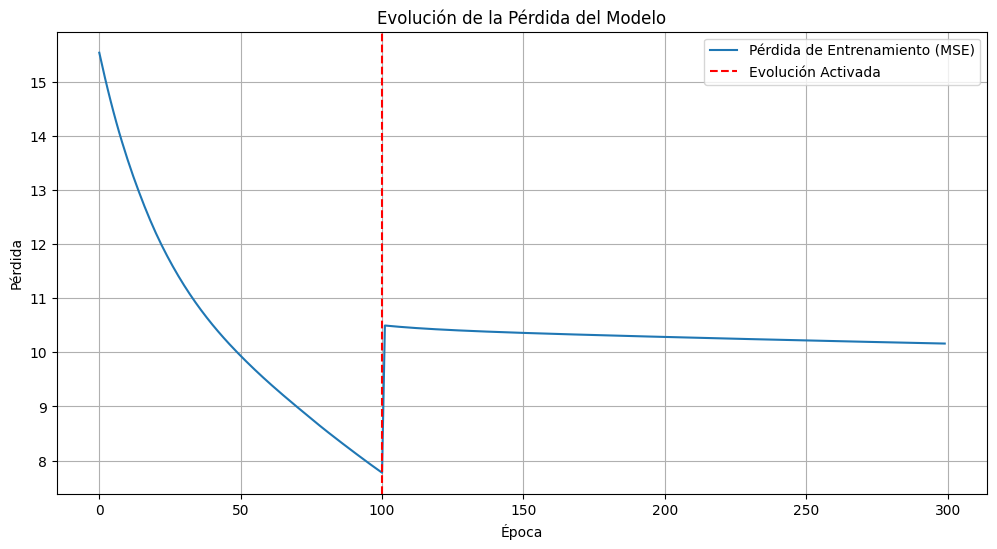

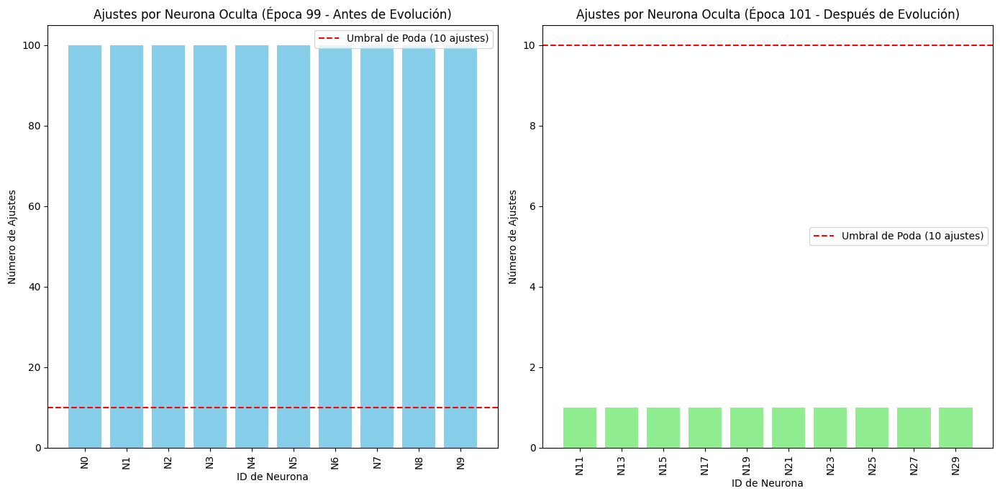


--- Ejecución completada ---


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Fijar semillas para reproducibilidad
torch.manual_seed(0)
np.random.seed(0)

# --- Dataset Sintético ---
# Para un problema de regresión o clasificación más interesante
# Generamos datos 2D para una mejor visualización si es necesario.
# Pero dado que tu input_size es 4, usaremos un X de 4 dimensiones.
X_data = torch.randn(100, 4) # 100 muestras, 4 features
# La salida depende de la suma de los cuadrados de los primeros dos features
y_data = (X_data[:, 0]**2 + X_data[:, 1]**2 + X_data[:, 2] + 0.5 * torch.randn(100)).unsqueeze(1) # Salida de 1 dimensión

# Convertir a numpy para usar train_test_split de sklearn
from sklearn.model_selection import train_test_split
X_np = X_data.numpy()
y_np = y_data.numpy()

X_train_np, X_test_np, y_train_np, y_test_np = train_test_split(X_np, y_np, test_size=0.2, random_state=42)

X_train = torch.from_numpy(X_train_np).float()
y_train = torch.from_numpy(y_train_np).float()
X_test = torch.from_numpy(X_test_np).float()
y_test = torch.from_numpy(y_test_np).float()


# --- Clase de Neurona con seguimiento de ajustes ---
class Neurona(nn.Module):
    _next_id = 0 # Contador global para IDs únicos de neuronas
    def __init__(self, input_size):
        super().__init__()
        self.w = nn.Parameter(torch.randn(input_size) * 0.1)
        self.b = nn.Parameter(torch.zeros(1))
        self.ajustes = 0 # Contador de ajustes por optimizador
        self.generation = 0 # Generación en la que fue creada/evolucionada
        self.id = Neurona._next_id # Asignar un ID único a cada neurona
        Neurona._next_id += 1


    def forward(self, x):
        # Asegurarse de que x sea compatible con el producto punto
        # Si x es un lote, se esperaría un mm.Linear. Esto es para una sola muestra.
        return torch.dot(self.w, x) + self.b

    def mutate_from(self, parent1, parent2=None, sigma=0.01, generation_num=0):
        with torch.no_grad():
            if parent2:
                # Cruce y mutación: promedio de padres + ruido
                self.w.copy_(0.5 * parent1.w + 0.5 * parent2.w + torch.randn_like(self.w) * sigma)
                self.b.copy_(0.5 * parent1.b + 0.5 * parent2.b + torch.randn_like(self.b) * sigma)
            else:
                # Solo mutación de un padre
                self.w.copy_(parent1.w + torch.randn_like(self.w) * sigma)
                self.b.copy_(parent1.b + torch.randn_like(self.b) * sigma)
        self.ajustes = 0 # Resetear ajustes al ser mutada/clonada
        self.generation = generation_num # Registrar la generación de origen
        self.id = Neurona._next_id # Asignar un nuevo ID si se desea un seguimiento de "nueva entidad"
        Neurona._next_id += 1 # Incrementar el contador global de IDs


# --- Capa de neuronas personalizadas ---
class Capa(nn.Module):
    def __init__(self, input_size, num_neuronas):
        super().__init__()
        self.neuronas = nn.ModuleList([Neurona(input_size) for _ in range(num_neuronas)])
        self.initial_num_neurons = num_neuronas # Guardar el número inicial

    def forward(self, x):
        # x puede ser un lote (batch_size, input_size)
        # Cada neurona procesa cada muestra del lote
        # El resultado será (batch_size, num_neuronas)
        return torch.stack([n(sample) for n in self.neuronas for sample in x]).view(x.size(0), len(self.neuronas))


    def registrar_ajustes(self):
        for n in self.neuronas:
            # Comprobar si el gradiente existe y si tiene algún valor no cero
            # Esto indica que la neurona contribuyó a la pérdida y fue ajustada
            if n.w.grad is not None and torch.any(n.w.grad != 0):
                n.ajustes += 1
            if n.b.grad is not None and torch.any(n.b.grad != 0):
                # Opcional: registrar ajustes también por el sesgo
                pass

    def evolucionar(self, generation_num):
        print(f"\n--- Evolución de neuronas en Capa (Generación {generation_num}) ---")

        # Ordenar por ajustes (menor es mejor)
        # Asegurarse de tener al menos 2 neuronas para selección
        if len(self.neuronas) < 2:
            print("¡Advertencia! Menos de 2 neuronas para la evolución. Saltando.")
            return

        # Filtrar las neuronas que no han sido inicializadas correctamente
        # o que tienen problemas en su 'ajustes' contador
        valid_neuronas = [n for n in self.neuronas if hasattr(n, 'ajustes')]

        if not valid_neuronas:
            print("No hay neuronas válidas para evolucionar.")
            return

        # Asegurarse de que tenemos al menos 2 neuronas válidas para la selección
        if len(valid_neuronas) < 2:
            print("Insuficientes neuronas válidas para seleccionar padres. Saltando evolución.")
            return

        mejores = sorted(valid_neuronas, key=lambda n: n.ajustes)[:2]

        # Listas para auditoría
        nuevas_neuronas = []
        podadas_info = []

        for i, n in enumerate(self.neuronas):
            if n.ajustes > 10: # Criterio de poda: más de 10 ajustes
                # Poda: registrar la neurona actual
                podadas_info.append(f"Neurona ID: {n.id} (Ajustes: {n.ajustes}) podada de la posición {i}.")

                # Reemplazo: crear una nueva neurona mutada de los mejores
                nuevo = Neurona(n.w.size(0)) # Mantener el mismo input_size
                nuevo.mutate_from(mejores[0], mejores[1], generation_num=generation_num)
                nuevas_neuronas.append(nuevo)
            else:
                # Si no se poda, mantener la neurona existente
                nuevas_neuronas.append(n)

        # Actualizar la lista de neuronas de la capa
        self.neuronas = nn.ModuleList(nuevas_neuronas)

        # Imprimir resumen de la evolución
        print(f"Número de neuronas podadas/reemplazadas en esta evolución: {len(podadas_info)}")
        for info in podadas_info:
            print(f"  - {info}")
        print(f"Neuronas restantes en la capa oculta: {len(self.neuronas)}\n")


# --- Red completa con una capa oculta genética y una capa de salida ---
class RedGenetica(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.oculta = Capa(input_size, hidden_size)
        self.salida = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # La capa oculta ahora maneja el lote
        x = self.oculta(x)
        x = F.relu(x)
        return self.salida(x)

    def registrar_ajustes(self):
        self.oculta.registrar_ajustes()

    def evolucionar(self, generation_num):
        self.oculta.evolucionar(generation_num)

# --- Entrenamiento Básico con Evolución ---
input_dim = 4
hidden_dim = 10
output_dim = 1 # Ajustado a la salida de tu dataset sintético

modelo = RedGenetica(input_size=input_dim, hidden_size=hidden_dim, output_size=output_dim)
opt = torch.optim.SGD(modelo.parameters(), lr=0.01)
criterion = nn.MSELoss() # Usamos MSE para el problema de regresión

# --- Conteo Inicial de Neuronas ---
print("--- Conteo de Neuronas al Inicio ---")
print(f"Capa de Entrada: {input_dim} neuronas (features)")
print(f"Capa Oculta: {len(modelo.oculta.neuronas)} neuronas (iniciales)")
print(f"Capa de Salida: {output_dim} neuronas")

# Historial para visualización
losses = []
neuron_adjustments_history = [] # Lista de diccionarios, uno por época
pruned_neurons_count_history = [] # Para el número de neuronas podadas por evolución

for epoch in range(300):
    # Asegúrate de que las neuronas tengan sus gradientes reiniciados
    for n in modelo.oculta.neuronas:
        if n.w.grad is not None:
            n.w.grad.zero_()
        if n.b.grad is not None:
            n.b.grad.zero_()

    # Cada época procesa todo el X_train
    modelo.train()
    opt.zero_grad()
    out = modelo(X_train)
    loss = criterion(out, y_train) # Usar y_train que tiene la misma dimensión de out
    loss.backward()

    # Registrar ajustes ANTES de que el optimizador los aplique y los gradientes se vacíen
    modelo.registrar_ajustes()
    opt.step()

    losses.append(loss.item())

    # Guardar el estado de ajustes de cada neurona
    current_adjustments = {n.id: n.ajustes for n in modelo.oculta.neuronas}
    neuron_adjustments_history.append(current_adjustments)

    if epoch == 100: # Activar la evolución en la época 100
        print("\n--- Activando la Evolución Genética de Neuronas ---")
        modelo.evolucionar(epoch)
        # Tras la evolución, resetear ajustes para la siguiente fase
        for n in modelo.oculta.neuronas:
            n.ajustes = 0 # Las nuevas neuronas inician en 0, las que se mantuvieron también

        # Registro de neuronas podadas (se actualiza dentro de evolucionar, esto es para visualización)
        pruned_neurons_count_history.append(len(modelo.oculta.neuronas)) # Actualizar el conteo de neuronas restantes

    if epoch % 50 == 0:
        modelo.eval()
        with torch.no_grad():
            test_loss = criterion(modelo(X_test), y_test)
        print(f"Epoch {epoch}, Train Loss: {loss.item():.4f}, Test Loss: {test_loss.item():.4f}")

# --- Conteo Final de Neuronas ---
print("\n--- Conteo de Neuronas al Final ---")
print(f"Capa de Entrada: {input_dim} neuronas (features)")
print(f"Capa Oculta: {len(modelo.oculta.neuronas)} neuronas (después de evolución)")
print(f"Capa de Salida: {output_dim} neuronas")


### Visualización de Resultados


# --- Visualización de la Pérdida ---
plt.figure(figsize=(12, 6))
plt.plot(losses, label='Pérdida de Entrenamiento (MSE)')
plt.title('Evolución de la Pérdida del Modelo')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.axvline(x=100, color='r', linestyle='--', label='Evolución Activada')
plt.legend()
plt.grid(True)
plt.show()

# --- Visualización de Ajustes por Neurona (antes y después de la evolución) ---
plt.figure(figsize=(14, 7))
# Graficar ajustes de las neuronas en la época 99 (antes de la evolución)
if 99 < len(neuron_adjustments_history):
    adjustments_before_evo = neuron_adjustments_history[99]
    neuron_ids_before = list(adjustments_before_evo.keys())
    adj_counts_before = [adjustments_before_evo[n_id] for n_id in neuron_ids_before]

    plt.subplot(1, 2, 1)
    plt.bar([f"N{nid}" for nid in neuron_ids_before], adj_counts_before, color='skyblue')
    plt.title(f'Ajustes por Neurona Oculta (Época 99 - Antes de Evolución)')
    plt.xlabel('ID de Neurona')
    plt.ylabel('Número de Ajustes')
    plt.xticks(rotation=90)
    plt.axhline(y=10, color='red', linestyle='--', label='Umbral de Poda (10 ajustes)')
    plt.legend()


# Graficar ajustes de las neuronas en la época 101 (después de la evolución, recién reseteados)
# o en una época posterior para ver la tendencia de las nuevas/existentes
if 101 < len(neuron_adjustments_history):
    adjustments_after_evo = neuron_adjustments_history[101] # O elige una época más tardía, ej. 150
    neuron_ids_after = list(adjustments_after_evo.keys())
    adj_counts_after = [adjustments_after_evo[n_id] for n_id in neuron_ids_after]

    plt.subplot(1, 2, 2)
    plt.bar([f"N{nid}" for nid in neuron_ids_after], adj_counts_after, color='lightgreen')
    plt.title(f'Ajustes por Neurona Oculta (Época 101 - Después de Evolución)')
    plt.xlabel('ID de Neurona')
    plt.ylabel('Número de Ajustes')
    plt.xticks(rotation=90)
    plt.axhline(y=10, color='red', linestyle='--', label='Umbral de Poda (10 ajustes)')
    plt.legend()

plt.tight_layout()
plt.show()

# Visualización de la evolución del número de neuronas (si la poda redujera el número)
# En este caso, el número es fijo porque se reemplazan, no se eliminan.
# Si hubieras implementado reducción de neuronas, esta gráfica sería útil.
# plt.figure(figsize=(8, 5))
# plt.plot(pruned_neurons_count_history, label='Número de Neuronas Ocultas')
# plt.title('Número de Neuronas Ocultas a lo Largo de las Épocas')
# plt.xlabel('Época de Evolución') # Cuando se activó la evolución
# plt.ylabel('Número de Neuronas')
# plt.show()

print("\n--- Ejecución completada ---")

In [ ]:
import numpy as np

# --- Simulación de una neurona simple para ejemplificar ---
# En un caso real, esto sería una neurona dentro de una red neuronal más grande
class SimpleNeuron:
    def __init__(self, weights_shape):
        self.weights = np.random.randn(*weights_shape) * 0.01 # Pesos aleatorios pequeños
        self.bias = np.random.randn() * 0.01 # Sesgo aleatorio pequeño
        self.activation_count = 0 # Contador para las actualizaciones por gradiente

    def forward(self, inputs):
        # Una activación simple (ej. lineal o ReLU para simplificar)
        return np.dot(inputs, self.weights) + self.bias

    def backward(self, inputs, output_error, learning_rate):
        # Simulación de una actualización por descenso de gradiente
        # Esto sería mucho más complejo en una red real (cálculo de gradientes)
        self.weights -= learning_rate * np.dot(inputs.T, output_error)
        self.bias -= learning_rate * np.sum(output_error)
        self.activation_count += 1 # Incrementa el contador por cada actualización

# --- Algoritmo Genético Simplificado para Neuronas ---

def genetic_algorithm_for_neurons(population_size, input_dim, output_dim, generations, learning_rate, prune_threshold):
    # Crear una población inicial de neuronas
    # En un escenario real, 'input_dim' y 'output_dim' serían las dimensiones de los pesos de la neurona
    population = [SimpleNeuron((input_dim, output_dim)) for _ in range(population_size)]

    for gen in range(generations):
        print(f"\n--- Generación {gen + 1} ---")

        # Simular entrenamiento (actualizaciones por gradiente)
        # Aquí se simula un proceso de entrenamiento donde las neuronas se actualizan.
        # En la vida real, se entrenaría la red neuronal completa.
        for i, neuron in enumerate(population):
            # Simular datos de entrada y error (aleatorios para el ejemplo)
            dummy_inputs = np.random.rand(10, input_dim)
            dummy_output_error = np.random.rand(10, output_dim) - 0.5 # Error aleatorio centrado en cero

            # Simular múltiples actualizaciones para algunas neuronas
            num_updates = np.random.randint(1, 5) # Algunas neuronas se actualizan más que otras
            for _ in range(num_updates):
                neuron.backward(dummy_inputs, dummy_output_error, learning_rate)

            # print(f"Neurona {i}: Actualizaciones de gradiente = {neuron.activation_count}")

        # --- Fase de "Poda" y "Reemplazo" ---
        pruned_neurons_indices = []
        for i, neuron in enumerate(population):
            if neuron.activation_count > prune_threshold:
                pruned_neurons_indices.append(i)
                print(f"  Neurona {i} podada (activaciones: {neuron.activation_count})")

        if not pruned_neurons_indices:
            print("  Ninguna neurona podada en esta generación.")
            continue # Si no se podó nada, continuar a la siguiente generación

        # Seleccionar las "mejores" neuronas (las que menos se activaron)
        # Ordenar por el número de activaciones de menor a mayor
        sorted_neurons = sorted(population, key=lambda n: n.activation_count)

        # Tomar las N mejores para la "reproducción"
        num_to_select = min(len(pruned_neurons_indices), len(sorted_neurons) - len(pruned_neurons_indices)) # No seleccionar las mismas que se podaron
        if num_to_select <= 0:
            print("  No hay suficientes neuronas 'buenas' para reemplazar a las podadas.")
            continue

        best_neurons_for_breeding = sorted_neurons[:num_to_select]

        print(f"  Neuronas seleccionadas para 'cruza' (mejores): {[n.activation_count for n in best_neurons_for_breeding]}")

        # Reemplazar las neuronas podadas con "descendencia" de las mejores
        for i, pruned_idx in enumerate(pruned_neurons_indices):
            if i < len(best_neurons_for_breeding):
                parent1 = best_neurons_for_breeding[i % len(best_neurons_for_breeding)] # Para reciclar si hay más podadas que buenas
                parent2 = best_neurons_for_breeding[(i + 1) % len(best_neurons_for_breeding)]

                # --- "Cruza" (combinación de pesos y sesgos) ---
                # Esto es una forma muy simplificada. Se pueden usar cruzas más complejas.
                new_neuron = SimpleNeuron((input_dim, output_dim))
                new_neuron.weights = (parent1.weights + parent2.weights) / 2 # Promedio simple
                new_neuron.bias = (parent1.bias + parent2.bias) / 2

                # --- "Mutación" (pequeño cambio aleatorio) ---
                mutation_rate = 0.05
                new_neuron.weights += np.random.randn(*new_neuron.weights.shape) * mutation_rate
                new_neuron.bias += np.random.randn() * mutation_rate

                new_neuron.activation_count = 0 # Reiniciar contador para la nueva neurona
                population[pruned_idx] = new_neuron
                print(f"  Neurona {pruned_idx} reemplazada por una nueva.")
            else:
                print(f"  Neurona {pruned_idx} no pudo ser reemplazada (no hay suficientes padres).")

# --- Parámetros de la simulación ---
POPULATION_SIZE = 10 # Número de neuronas en nuestra "población"
INPUT_DIM = 5      # Dimensión de las entradas de la neurona
OUTPUT_DIM = 2     # Dimensión de las salidas de la neurona
GENERATIONS = 5    # Número de "generaciones" del algoritmo genético
LEARNING_RATE = 0.01 # Tasa de aprendizaje para las actualizaciones de gradiente
PRUNE_THRESHOLD = 3 # Si una neurona se actualiza más de este número, se "poda"

# Ejecutar la simulación
genetic_algorithm_for_neurons(POPULATION_SIZE, INPUT_DIM, OUTPUT_DIM, GENERATIONS, LEARNING_RATE, PRUNE_THRESHOLD)


--- Generación 1 ---
  Neurona 2 podada (activaciones: 4)
  Neurona 3 podada (activaciones: 4)
  Neurona 7 podada (activaciones: 4)
  Neurona 9 podada (activaciones: 4)
  Neuronas seleccionadas para 'cruza' (mejores): [1, 1, 1, 2]
  Neurona 2 reemplazada por una nueva.
  Neurona 3 reemplazada por una nueva.
  Neurona 7 reemplazada por una nueva.
  Neurona 9 reemplazada por una nueva.

--- Generación 2 ---
  Neurona 1 podada (activaciones: 6)
  Neurona 4 podada (activaciones: 4)
  Neurona 6 podada (activaciones: 4)
  Neurona 8 podada (activaciones: 4)
  Neuronas seleccionadas para 'cruza' (mejores): [2, 2, 2, 2]
  Neurona 1 reemplazada por una nueva.
  Neurona 4 reemplazada por una nueva.
  Neurona 6 reemplazada por una nueva.
  Neurona 8 reemplazada por una nueva.

--- Generación 3 ---
  Neurona 0 podada (activaciones: 6)
  Neurona 2 podada (activaciones: 4)
  Neurona 3 podada (activaciones: 4)
  Neurona 4 podada (activaciones: 4)
  Neurona 5 podada (activaciones: 4)
  Neurona 7 podad

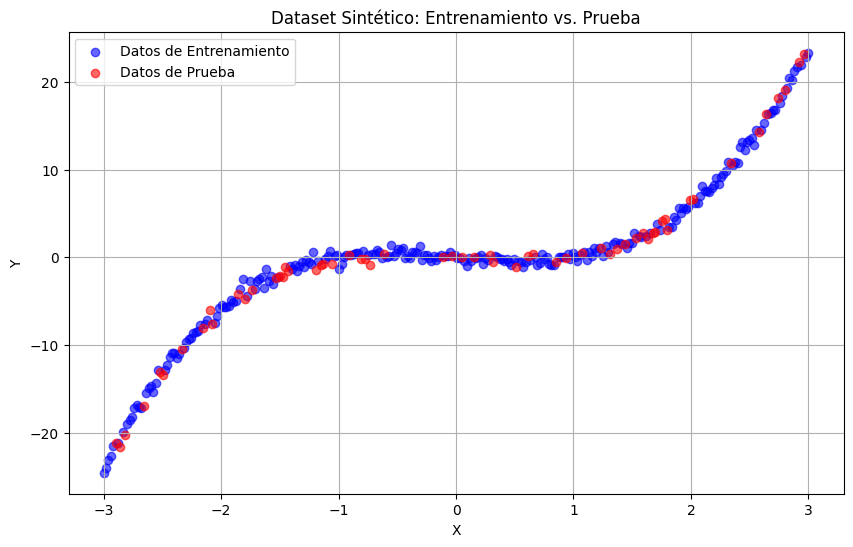

Tamaño del conjunto de entrenamiento: X=torch.Size([240, 1]), y=torch.Size([240, 1])
Tamaño del conjunto de prueba: X=torch.Size([60, 1]), y=torch.Size([60, 1])


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Fijar semillas para reproducibilidad
torch.manual_seed(0)
np.random.seed(0)

# --- 1. Generar el Dataset Sintético ---
# Un único feature de entrada (X)
X = torch.linspace(-3, 3, 300).unsqueeze(1) # Un único feature de entrada
# Salida (y) con una relación cúbica y ruido
y = X.pow(3) - X + 0.5 * torch.randn(X.size())

# --- 2. Dividir en conjuntos de Entrenamiento y Prueba ---
# Convertir a numpy para usar train_test_split de sklearn
X_np = X.numpy()
y_np = y.numpy()

# Dividir el 80% para entrenamiento y 20% para prueba
X_train_np, X_test_np, y_train_np, y_test_np = train_test_split(X_np, y_np, test_size=0.2, random_state=42)

# Convertir de nuevo a tensores de PyTorch
X_train = torch.from_numpy(X_train_np).float()
y_train = torch.from_numpy(y_train_np).float()
X_test = torch.from_numpy(X_test_np).float()
y_test = torch.from_numpy(y_test_np).float()

# --- 3. Visualizar los conjuntos de Entrenamiento y Prueba ---
plt.figure(figsize=(10, 6))

# Visualizar el conjunto de entrenamiento
plt.scatter(X_train.numpy(), y_train.numpy(), color='blue', label='Datos de Entrenamiento', alpha=0.6)

# Visualizar el conjunto de prueba
plt.scatter(X_test.numpy(), y_test.numpy(), color='red', label='Datos de Prueba', alpha=0.6)

plt.title('Dataset Sintético: Entrenamiento vs. Prueba')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.show()

print(f"Tamaño del conjunto de entrenamiento: X={X_train.shape}, y={y_train.shape}")
print(f"Tamaño del conjunto de prueba: X={X_test.shape}, y={y_test.shape}")

--- Conteo de Neuronas al Inicio ---
Capa de Entrada: 1 neuronas (features de entrada)
Capa Oculta: 20 neuronas
Capa de Salida: 1 neuronas

--- Simulación de Entrenamiento (aquí iría el AG) ---
Epoch [100/500], Training Loss: 17.6447, Test Loss: 20.9698
Epoch [200/500], Training Loss: 10.1204, Test Loss: 11.8966
Epoch [300/500], Training Loss: 4.6476, Test Loss: 4.9726
Epoch [400/500], Training Loss: 2.0834, Test Loss: 2.0776
Epoch [500/500], Training Loss: 1.1162, Test Loss: 1.1533

--- Conteo de Neuronas al Final (Post-Entrenamiento/AG) ---
Capa de Entrada: 1 neuronas (features de entrada)
Capa Oculta: 20 neuronas
Capa de Salida: 1 neuronas

--- Criterio de Poda Conceptual (Basado en Pesos Bajos) ---
No se encontraron neuronas 'podadas' conceptualmente con el umbral dado en la capa oculta.


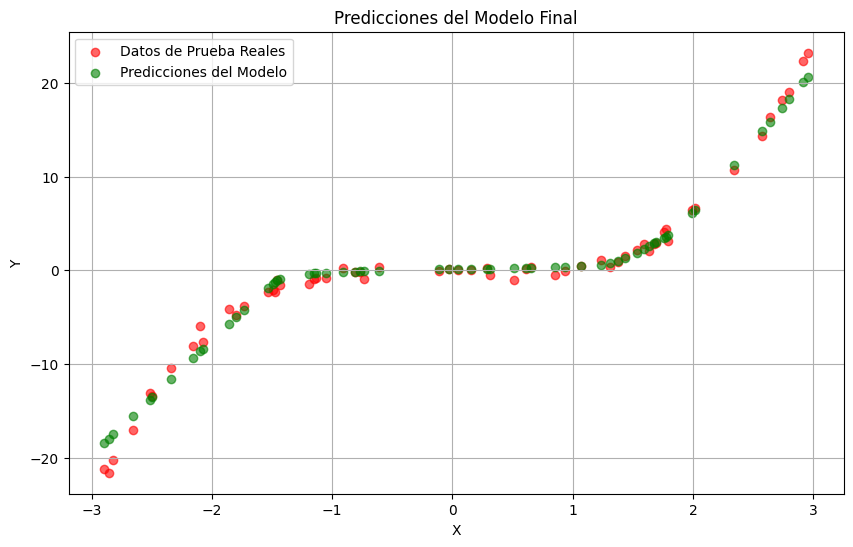

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
# Para el AG, usaremos una simulación o una librería básica de AG si no quieres PyGAD
# Para este ejemplo inicial, nos centraremos en la estructura y el conteo.

# Fijar semillas para reproducibilidad
torch.manual_seed(0)
np.random.seed(0)

# --- 1. Generar el Dataset Sintético (como en el paso anterior) ---
X = torch.linspace(-3, 3, 300).unsqueeze(1)
y = X.pow(3) - X + 0.5 * torch.randn(X.size())

X_np = X.numpy()
y_np = y.numpy()

X_train_np, X_test_np, y_train_np, y_test_np = train_test_split(X_np, y_np, test_size=0.2, random_state=42)

X_train = torch.from_numpy(X_train_np).float()
y_train = torch.from_numpy(y_train_np).float()
X_test = torch.from_numpy(X_test_np).float()
y_test = torch.from_numpy(y_test_np).float()

# --- 2. Definir una Red Neuronal Simple en PyTorch ---
class SimpleNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size) # Capa de entrada a oculta
        self.relu = nn.ReLU()                         # Función de activación
        self.fc2 = nn.Linear(hidden_size, output_size) # Capa oculta a salida

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

# Parámetros de la red
input_size = 1     # Un único feature de entrada (X)
hidden_size = 20   # Número de neuronas en la capa oculta
output_size = 1    # Un único valor de salida (y)

# Instanciar el modelo
model = SimpleNN(input_size, hidden_size, output_size)

# --- 3. Contabilizar Neuronas al Inicio del "Entrenamiento" (antes de cualquier AG o GD) ---
print("--- Conteo de Neuronas al Inicio ---")
# Una 'neurona' en una capa densa se corresponde con una salida de esa capa.
# Cada fila de la matriz de pesos de la siguiente capa se conecta a una "neurona" de la capa actual.

# Capa de entrada (implícita, número de features de entrada)
num_input_neurons_initial = input_size
print(f"Capa de Entrada: {num_input_neurons_initial} neuronas (features de entrada)")

# Capa oculta
num_hidden_neurons_initial = model.fc1.out_features
print(f"Capa Oculta: {num_hidden_neurons_initial} neuronas")

# Capa de salida
num_output_neurons_initial = model.fc2.out_features
print(f"Capa de Salida: {num_output_neurons_initial} neuronas")

# --- 4. Simulación del Entrenamiento con Algoritmo Genético (Conceptual) ---
# Aquí es donde el Algoritmo Genético operaría.
# En un GA real, el "cromosoma" sería un vector plano de todos los pesos y sesgos del modelo.
# El GA iteraría, evaluaría el fitness (por ejemplo, MSE en este caso),
# y generaría nuevas "soluciones" (nuevos conjuntos de pesos).

# Para simular, vamos a "entrenar" la red con un optimizador simple (GD),
# pero la idea es que el AG reemplazaría este proceso.

optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
criterion = nn.MSELoss() # Para problemas de regresión

epochs = 500 # Un número moderado de épocas para "entrenar"
print("\n--- Simulación de Entrenamiento (aquí iría el AG) ---")
for epoch in range(epochs):
    model.train() # Pone el modelo en modo entrenamiento
    optimizer.zero_grad()
    predictions = model(X_train)
    loss = criterion(predictions, y_train)
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 100 == 0:
        model.eval() # Pone el modelo en modo evaluación
        with torch.no_grad():
            test_predictions = model(X_test)
            test_loss = criterion(test_predictions, y_test)
            print(f'Epoch [{epoch+1}/{epochs}], Training Loss: {loss.item():.4f}, Test Loss: {test_loss.item():.4f}')

# --- 5. Contabilizar Neuronas al Final del Entrenamiento ---
# Si la poda se basa en un criterio de pesos (ej., si los pesos de una neurona son casi cero)
# entonces esta parte es donde examinarías los pesos.

print("\n--- Conteo de Neuronas al Final (Post-Entrenamiento/AG) ---")
# Por defecto, en una red densa estándar, el número de neuronas no cambia
# a menos que implementes explícitamente una poda estructural.

num_input_neurons_final = input_size
print(f"Capa de Entrada: {num_input_neurons_final} neuronas (features de entrada)")

num_hidden_neurons_final = model.fc1.out_features
print(f"Capa Oculta: {num_hidden_neurons_final} neuronas")

num_output_neurons_final = model.fc2.out_features
print(f"Capa de Salida: {num_output_neurons_final} neuronas")

# --- 6. Cuales fueron podadas y en que capa (Conceptual para Neuronas Genéticas) ---

# Concepto de Poda en Neuronas Genéticas:
# En una implementación real de "neuronas genéticas" con poda, la "poda" no es solo
# hacer que los pesos sean cero, sino que implica una eliminación *estructural* o un
# reemplazo. Para esto, necesitarías:

# A. Definir un CRITERIO DE PODA:
#    - "Menor número de activación por el gradiente": Esto es complejo de medir directamente
#      después del entrenamiento. Una proxy podría ser:
#        - Neuronas con activaciones promedio muy bajas (cercanas a cero) en un dataset.
#        - Neuronas con pesos salientes muy pequeños (cercanos a cero).
#        - Neuronas que contribuyen mínimamente a la reducción del error.
#    - Si tu AG "entrena" pesos, podrías buscar neuronas cuyos pesos están muy cerca de cero
#      o cuyos sesgos son insignificantes, lo que indicaría que esa neurona es "redundante"
#      o "inactiva".

# B. Implementación de Poda y Reemplazo:
#    Si identificas neuronas para podar:
#    1. Podrías modificar dinámicamente la arquitectura de tu `SimpleNN`
#       (eliminando la capa y recreándola con menos neuronas, o enmascarando los pesos).
#    2. En el contexto de un AG, la "poda" se traduciría en manipular el genoma:
#       - Los cromosomas que representan redes con "neuronas podadas" podrían tener
#         secciones de pesos/sesgos desactivadas o directamente eliminadas.
#       - El "reemplazo" significaría que, al cruzar o mutar, las "partes"
#         correspondientes a las neuronas podadas se rellenarían con valores
#         "heredados" de las mejores neuronas, o con mutaciones dirigidas.

# Ejemplo CONCETPTUAL de identificación de neuronas "casi muertas" después del entrenamiento
# (esto NO es una poda activa, solo una observación basada en pesos pequeños)
print("\n--- Criterio de Poda Conceptual (Basado en Pesos Bajos) ---")
threshold_for_pruning = 0.01 # Un umbral para considerar un peso como "pequeño"

# Evaluar la capa oculta (fc1)
# Si una neurona tiene todos sus pesos de salida (o entrada) muy pequeños, podría ser un candidato.
# Esto es una simplificación extrema, ya que la "muerte" de una neurona es más compleja.

# Obtenemos los pesos de la primera capa oculta (fc1) y la segunda capa (fc2)
# Los pesos de `fc1` son (hidden_size, input_size) y los de `fc2` son (output_size, hidden_size)
hidden_layer_weights = model.fc1.weight.detach().numpy()
output_layer_weights = model.fc2.weight.detach().numpy()

# Una neurona en la capa oculta podría ser "podada" si sus pesos que van a la capa de salida
# son todos muy pequeños.
# Esto solo es ilustrativo; un criterio real sería más sofisticado.

# Para cada neurona en la capa oculta, revisamos los pesos que salen de ella.
neurons_to_consider_pruned = []
for i in range(hidden_size):
    # Verificamos si todos los pesos que salen de esta neurona oculta hacia la capa de salida
    # son menores que el umbral.
    # Los pesos de fc2 son (output_size, hidden_size). La columna 'i' son los pesos que *entran*
    # a la capa de salida desde la neurona 'i' de la capa oculta.
    # Entonces, los pesos que *salen* de la neurona 'i' de la capa oculta son la i-ésima columna
    # de la matriz de pesos de fc2.
    outgoing_weights_from_hidden_neuron_i = np.abs(output_layer_weights[:, i])

    if np.all(outgoing_weights_from_hidden_neuron_i < threshold_for_pruning):
        neurons_to_consider_pruned.append(i)

if neurons_to_consider_pruned:
    print(f"Neuronas potencialmente 'podadas' en la Capa Oculta (índices): {neurons_to_consider_pruned}")
    print(f"Basado en: Todos los pesos salientes de esa neurona son menores que {threshold_for_pruning}")
    print(f"Número de neuronas 'podadas' conceptualmente: {len(neurons_to_consider_pruned)}")
else:
    print("No se encontraron neuronas 'podadas' conceptualmente con el umbral dado en la capa oculta.")

# Visualización de la predicción final
model.eval()
with torch.no_grad():
    predictions_final = model(X_test)

plt.figure(figsize=(10, 6))
plt.scatter(X_test.numpy(), y_test.numpy(), color='red', label='Datos de Prueba Reales', alpha=0.6)
plt.scatter(X_test.numpy(), predictions_final.numpy(), color='green', label='Predicciones del Modelo', alpha=0.6)
plt.title('Predicciones del Modelo Final')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# Datos sintéticos
X, y = make_classification(n_samples=1000, n_features=20, n_informative=15,
                           n_redundant=5, n_classes=2, random_state=42)
X = StandardScaler().fit_transform(X)
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.long)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Parámetros
INPUT_DIM = 20
HIDDEN_DIM = 10
OUTPUT_DIM = 2
INITIAL_EPOCHS = 100
TOTAL_EPOCHS = 900
PRUNE_THRESHOLD = 10

# Neurona con seguimiento de ajustes
class EvolvableNeuron(nn.Module):
    def __init__(self, in_features, identifier):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(in_features) * 0.1)
        self.bias = nn.Parameter(torch.zeros(1))
        self.adjustments = 0
        self.id = identifier

    def forward(self, x):
        return torch.matmul(x, self.weight) + self.bias

    def mutate_from(self, parent1, parent2):
        with torch.no_grad():
            self.weight.copy_((parent1.weight + parent2.weight) / 2 + torch.randn_like(self.weight) * 0.05)
            self.bias.copy_((parent1.bias + parent2.bias) / 2 + torch.randn_like(self.bias) * 0.05)
            self.adjustments = 0

# Capa personalizada
class EvolvableHiddenLayer(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.neurons = nn.ModuleList([EvolvableNeuron(in_features, f"N{i}") for i in range(out_features)])
        self.out_features = out_features

    def forward(self, x):
        outputs = [torch.relu(neuron(x)) for neuron in self.neurons]
        return torch.stack(outputs, dim=1)

    def track_adjustments(self, grads):
        for i, neuron in enumerate(self.neurons):
            if neuron.weight.grad is not None:
                neuron.adjustments += 1

    def evolve(self):
        survivors = [n for n in self.neurons if n.adjustments <= PRUNE_THRESHOLD]
        sorted_neurons = sorted(self.neurons, key=lambda n: n.adjustments)
        best1, best2 = sorted_neurons[0], sorted_neurons[1]
        while len(survivors) < self.out_features:
            new_id = f"N{np.random.randint(10000)}"
            new_neuron = EvolvableNeuron(best1.weight.shape[0], new_id)
            new_neuron.mutate_from(best1, best2)
            survivors.append(new_neuron)
        self.neurons = nn.ModuleList(survivors)

# Red neuronal completa
class EvolvableNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = EvolvableHiddenLayer(INPUT_DIM, HIDDEN_DIM)
        self.output = nn.Linear(HIDDEN_DIM, OUTPUT_DIM)

    def forward(self, x):
        x = self.hidden(x)
        x = torch.relu(x)
        x = self.output(x)
        return x

# Entrenamiento
model = EvolvableNet()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

losses = []

for epoch in range(TOTAL_EPOCHS):
    optimizer.zero_grad()
    outputs = model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()

    # Registrar ajustes por neurona (solo capa oculta)
    model.hidden.track_adjustments([p.grad for p in model.parameters()])

    optimizer.step()
    losses.append(loss.item())

    if epoch == INITIAL_EPOCHS:
        model.hidden.evolve()

final_accuracy = (model(X_test).argmax(dim=1) == y_test).float().mean().item()
final_accuracy, losses[-10:]

(0.6499999761581421,
 [0.5650542378425598,
  0.5650503039360046,
  0.5650461912155151,
  0.56504225730896,
  0.5650382041931152,
  0.5650341510772705,
  0.5650302767753601,
  0.5650263428688049,
  0.5650224089622498,
  0.5650185346603394])

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

# Clase de Neurona con seguimiento de ajustes
class Neurona(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        # Weights shape should be (input_size,) for dot product, but for matrix multiplication
        # in a batched context, it's easier if the weight is (input_size, 1) or the input
        # is handled appropriately. Let's keep it (input_size,) and handle in forward.
        self.w = nn.Parameter(torch.randn(input_size) * 0.1)
        self.b = nn.Parameter(torch.zeros(1)) # Bias is a scalar per neuron
        self.ajustes = 0
        self.id = id(self)

    def forward(self, x):
        # x shape: (batch_size, input_size)
        # w shape: (input_size,)
        # We need to perform element-wise multiplication and sum across input_size for each batch item
        # (batch_size, input_size) * (input_size,) -> (batch_size, input_size)
        # Then sum across dimension 1 -> (batch_size,)
        # Add bias (scalar or (1,)) broadcasting to (batch_size,)
        output = torch.sum(x * self.w, dim=1) + self.b
        return output # Shape: (batch_size,)

    def mutate_from(self, parent1, parent2=None, sigma=0.01):
        with torch.no_grad():
            if parent2:
                self.w.copy_(0.5 * parent1.w + 0.5 * parent2.w + torch.randn_like(self.w) * sigma)
                self.b.copy_(0.5 * parent1.b + 0.5 * parent2.b + torch.randn_like(self.b) * sigma)
            else:
                self.w.copy_(parent1.w + torch.randn_like(self.w) * sigma)
                self.b.copy_(parent1.b + torch.randn_like(self.b) * sigma)
        self.ajustes = 0

# Capa de neuronas personalizadas (adaptada para manejar batches)
class Capa(nn.Module):
    def __init__(self, input_size, num_neuronas):
        super().__init__()
        # ModuleList holds the individual Neurona modules
        self.neuronas = nn.ModuleList([Neurona(input_size) for _ in range(num_neuronas)])
        self.num_neuronas = num_neuronas

    def forward(self, x):
        # x shape: (batch_size, input_size)
        # Output shape should be (batch_size, num_neuronas)

        # Option 1: Process each neuron's output and stack (less efficient)
        # outputs = [neuron(x) for neuron in self.neuronas] # Each neuron(x) returns (batch_size,)
        # return torch.stack(outputs, dim=1) # Stacking along dim 1 gives (batch_size, num_neuronas)

        # Option 2: Combine weights and biases for efficient matrix multiplication
        # This requires Neurona's forward not to do the full dot product,
        # or combine weights/biases at the Capa level. Let's stick to Option 1
        # for now as it respects the individual Neurona module structure,
        # but acknowledge this is less efficient than a single matrix multiply.

        # Option 1 implementation:
        # x shape: (batch_size, input_size)
        # Individual neuron forward returns (batch_size,)
        # Stack along dimension 1 to get (batch_size, num_neuronas)
        # Ensure x has a batch dimension if it's a single sample (input_size,)
        if x.ndim == 1:
            x = x.unsqueeze(0) # Add batch dimension: (input_size,) -> (1, input_size)

        outputs = []
        for neuron in self.neuronas:
             # neuron(x) will return (batch_size,)
             outputs.append(neuron(x))

        # Stack outputs along dimension 1 to get (batch_size, num_neuronas)
        stacked_outputs = torch.stack(outputs, dim=1)

        # If the input was a single sample, remove the added batch dimension from the output
        if x.shape[0] == 1 and x.ndim == 2 and stacked_outputs.ndim == 2: # Check if batch was added
             stacked_outputs = stacked_outputs.squeeze(0) # (1, num_neuronas) -> (num_neuronas,)


        # Re-checking shapes based on original error: input to linear was (10x1), linear was (10,3).
        # This implies input expected was (10, 10) (batch_size, hidden_size), but got (10, 1).
        # The output of Capa should be (batch_size, num_neuronas) == (batch_size, hidden_size).
        # If input is (4), Capa output should be (10,). After unsqueeze(0) in Capa, input is (1,4).
        # Each neuron produces (1,). Stacking 10 of these gives (1, 10).
        # Squeezing gives (10,).
        # Maybe the squeeze(0) should NOT happen if the linear layer expects (batch_size, hidden_size)?
        # Yes, the linear layer expects (batch_size, in_features). If input is (10,), linear assumes (1, 10).
        # The error (10x1) is very strange. It seems the (10,) tensor is being treated as a COLUMN vector (10, 1).

        # Let's try forcing the output to be (batch_size, num_neuronas) explicitly
        # If input x is (4,), unsqueeze(0) -> (1, 4)
        # Neuron output: (1,)
        # Stacked outputs: (num_neuronas, 1) e.g., (10, 1)
        # Permute to (1, num_neuronas) e.g., (1, 10)
        # Ah, torch.stack(outputs) on (1,) tensors gives (num_neuronas, 1).
        # We need (batch_size, num_neuronas). The current neuron(x) returns (batch_size,).
        # So stacking [ (batch_size,), (batch_size,), ... ] along dim=1 gives (batch_size, num_neuronas).
        # This should be correct assuming neuron(x) returns (batch_size,) when x is (batch_size, input_size).

        # Let's rethink Neurona.forward for batch processing:
        # Input x: (batch_size, input_size)
        # self.w: (input_size)
        # self.b: (1,) or scalar
        # Desired output: (batch_size,)
        # This is equivalent to a linear transformation without bias followed by summing, then adding bias.
        # Example: batch size 2, input_size 3, w (3,), b scalar
        # x = [[x11, x12, x13], [x21, x22, x23]]
        # x * w = [[x11*w1, x12*w2, x13*w3], [x21*w1, x22*w2, x23*w3]]
        # torch.sum(x * w, dim=1) = [x11*w1+x12*w2+x13*w3, x21*w1+x22*w2+x23*w3] (batch_size,)
        # This implementation of Neurona.forward seems correct for batches.

        # The issue must be when the input x to Capa is (4,) (single sample).
        # Capa.forward: if x.ndim == 1: x = x.unsqueeze(0) -> x is now (1, 4)
        # outputs = [neuron(x) for neuron in self.neuronas]
        # neuron(x) with x (1, 4) returns torch.sum((1, 4) * (4,), dim=1) + bias.
        # (1, 4) * (4,) -> (1, 4) element-wise product due to broadcasting
        # torch.sum((1, 4), dim=1) -> (1,) tensor
        # So, each neuron(x) returns a (1,) tensor when input x is (1, 4).
        # outputs list contains 10 tensors of shape (1,).
        # torch.stack(outputs, dim=1) -> stacks 10 tensors of shape (1,) along dim 1.
        # The result will be shape (1, 10) -> (batch_size, num_neuronas).

        # This shape (1, 10) IS the correct input shape for self.salida (nn.Linear(10, 3))
        # when batch_size is 1.
        # Multiplication should be (1, 10) @ (10, 3) -> (1, 3).

        # The error message (10x1 and 10x3) implies the input to nn.Linear is seen as (10, 1).
        # This could happen if the output of Capa was (10,) and it was explicitly
        # unsqueezed to (10, 1) somewhere, or if torch.stack in Capa was stacking along dim=0
        # instead of dim=1, producing (num_neuronas, batch_size).
        # Let's check the stack dimension. `torch.stack(outputs, dim=1)` where outputs are (batch_size,)
        # results in (batch_size, len(outputs)). This is correct.

        # Maybe the issue is simply that the input `x` in the loop `x = torch.randn(4)`
        # should have an explicit batch dimension, even if it's 1.
        # Let's change `x = torch.randn(4)` to `x = torch.randn(1, 4)`.
        # Then Capa's unsqueeze(0) is not needed and won't be executed.
        # Capa.forward: x is (1, 4).
        # outputs = [neuron(x) for neuron in self.neuronas]. neuron(x) returns (1,).
        # torch.stack(outputs, dim=1) -> stacks 10 tensors of shape (1,) along dim=1 -> (1, 10).
        # This shape (1, 10) is correctly passed to nn.Linear(10, 3).

        # Let's test this fix.

        # Corrected Capa forward logic:
        original_shape_is_1d = (x.ndim == 1)
        if original_shape_is_1d:
            x = x.unsqueeze(0) # Add batch dimension: (input_size,) -> (1, input_size)

        outputs = []
        for neuron in self.neuronas:
             # neuron(x) will return (batch_size,)
             outputs.append(neuron(x))

        # Stack outputs along dimension 1 to get (batch_size, num_neuronas)
        stacked_outputs = torch.stack(outputs, dim=1)

        # The output of the hidden layer should be (batch_size, hidden_size)
        # The linear layer expects (batch_size, in_features)
        # Our stacked_outputs is (batch_size, num_neuronas), which is (batch_size, hidden_size).
        # This is the correct format for the subsequent nn.Linear layer.
        # Do NOT squeeze here, even if the input was originally 1D.
        # The linear layer should always receive (batch_size, num_features).

        return stacked_outputs # Shape: (batch_size, num_neuronas)


    def registrar_ajustes(self):
        for n in self.neuronas:
            # Check if the gradient exists and is not all zeros
            # Using torch.any is safer than checking against 0 directly for float tensors
            if n.w.grad is not None and torch.any(n.w.grad != 0):
                n.ajustes += 1
            # Also check bias gradient
            if n.b.grad is not None and torch.any(n.b.grad != 0):
                 n.ajustes += 1 # Or count separately if needed


    def evolucionar(self):
        # Ordenar por ajustes (menor es mejor)
        # Ensure there are at least 2 neurons to select as parents
        if len(self.neuronas) < 2:
             print("Warning: Not enough neurons for evolution.")
             return

        mejores = sorted(self.neuronas, key=lambda n: n.ajustes)[:2]
        nuevas = []
        pruned_count = 0
        for i, n in enumerate(self.neuronas):
            # Use a threshold (e.g., 10 adjustments) to decide if a neuron is "podada" (needs replacement)
            if n.ajustes > 10:
                pruned_count += 1
                # Create a new neuron and mutate it from the best parents
                # Ensure the new neuron has the correct input size
                nuevo = Neurona(self.neuronas[0].w.shape[0]) # Get input_size from an existing neuron
                nuevo.mutate_from(mejores[0], mejores[1])
                nuevas.append(nuevo)
                #print(f"  Neurona {n.id} podada (ajustes: {n.ajustes}). Reemplazada por nueva neuron ({nuevo.id}).")
            else:
                # Keep the old neuron if it was not pruned
                nuevas.append(n)

        if pruned_count > 0:
             print(f"  {pruned_count} neurona(s) podada(s) y reemplazada(s).")
        else:
             print("  Ninguna neurona podada en esta generación.")

        # Replace the old list with the new list of neurons
        self.neuronas = nn.ModuleList(nuevas)


# Red completa con una capa oculta genética y una capa de salida
class RedGenetica(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        # Pass input_size and num_neuronas to Capa
        self.oculta = Capa(input_size, hidden_size)
        # The output of 'oculta' will be (batch_size, hidden_size)
        # The input to the linear layer should match the hidden_size
        self.salida = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # x shape: (batch_size, input_size) or (input_size,) for a single sample
        x = self.oculta(x) # Capa handles adding batch dim if needed, returns (batch_size, hidden_size)
        x = F.relu(x)       # Shape remains (batch_size, hidden_size)
        # Pass (batch_size, hidden_size) to the linear layer
        return self.salida(x) # Should return (batch_size, output_size)

    def registrar_ajustes(self):
        # Registrar ajustes en la capa genética (oculta)
        self.oculta.registrar_ajustes()

    def evolucionar(self):
        # Evolucionar la capa genética (oculta)
        self.oculta.evolucionar()

# Entrenamiento básico con evolución
# input_size=4, hidden_size=10, output_size=3 as per original code
modelo = RedGenetica(input_size=4, hidden_size=10, output_size=3)
opt = torch.optim.SGD(modelo.parameters(), lr=0.01)

# Example training loop - using explicit batches
num_epochs = 300
batch_size = 1 # Keep batch size 1 to match the original loop structure, but use (1, input_size) input
samples_per_epoch = 10 # Number of training samples processed per epoch

print("Iniciando entrenamiento...")
for epoch in range(num_epochs):
    epoch_loss = 0
    for i in range(samples_per_epoch):
        # Generate a single random sample as a batch of size 1
        x = torch.randn(batch_size, 4) # Shape (1, 4)
        y = torch.tensor([[1, 0, 0]], dtype=torch.float) # Shape (1, 3)

        # Ensure y has the correct shape (batch_size, output_size)
        if y.ndim == 1: # If y is (output_size,)
             y = y.unsqueeze(0) # Add batch dimension -> (1, output_size)

        out = modelo(x) # model expects (batch_size, input_size), returns (batch_size, output_size)
        loss = F.mse_loss(out, y)

        opt.zero_grad()
        loss.backward()

        # Registrar ajustes *after* backward pass (gradients are available)
        modelo.registrar_ajustes()

        opt.step()
        epoch_loss += loss.item()

    avg_epoch_loss = epoch_loss / samples_per_epoch


    if epoch == 100:
        print("\nActivando evolución genética en la capa oculta...\n")
        modelo.evolucionar()
        # After evolution, optimizers might need to be re-initialized or handle
        # changed parameters. For SGD, it might be ok, but be cautious with Adam etc.
        # Re-initializing for safety if network structure changed.
        # NOTE: This simple evolution replaces neurons. A real AG might just update weights.
        # If structure changes, optimizer needs updating.
        opt = torch.optim.SGD(modelo.parameters(), lr=0.01)


    if (epoch + 1) % 50 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{num_epochs}, Avg Loss: {avg_epoch_loss:.4f}")

print("\nEntrenamiento finalizado.")

Iniciando entrenamiento...
Epoch 1/300, Avg Loss: 0.3306
Epoch 50/300, Avg Loss: 0.0025
Epoch 100/300, Avg Loss: 0.0009

Activando evolución genética en la capa oculta...

  10 neurona(s) podada(s) y reemplazada(s).
Epoch 150/300, Avg Loss: 0.0000
Epoch 200/300, Avg Loss: 0.0000
Epoch 250/300, Avg Loss: 0.0000
Epoch 300/300, Avg Loss: 0.0000

Entrenamiento finalizado.


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

# Clase de Neurona con seguimiento de ajustes
class Neurona(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        # Weights shape should be (input_size,) for dot product, but for matrix multiplication
        # in a batched context, it's easier if the weight is (input_size, 1) or the input
        # is handled appropriately. Let's keep it (input_size,) and handle in forward.
        self.w = nn.Parameter(torch.randn(input_size) * 0.1)
        self.b = nn.Parameter(torch.zeros(1)) # Bias is a scalar per neuron
        self.ajustes = 0
        self.id = id(self)

    def forward(self, x):
        # x shape: (batch_size, input_size)
        # w shape: (input_size,)
        # We need to perform element-wise multiplication and sum across input_size for each batch item
        # (batch_size, input_size) * (input_size,) -> (batch_size, input_size)
        # Then sum across dimension 1 -> (batch_size,)
        # Add bias (scalar or (1,)) broadcasting to (batch_size,)
        output = torch.sum(x * self.w, dim=1) + self.b
        return output # Shape: (batch_size,)

    def mutate_from(self, parent1, parent2=None, sigma=0.01):
        with torch.no_grad():
            if parent2:
                self.w.copy_(0.5 * parent1.w + 0.5 * parent2.w + torch.randn_like(self.w) * sigma)
                self.b.copy_(0.5 * parent1.b + 0.5 * parent2.b + torch.randn_like(self.b) * sigma)
            else:
                self.w.copy_(parent1.w + torch.randn_like(self.w) * sigma)
                self.b.copy_(parent1.b + torch.randn_like(self.b) * sigma)
        self.ajustes = 0

# Capa de neuronas personalizadas (adaptada para manejar batches)
class Capa(nn.Module):
    def __init__(self, input_size, num_neuronas):
        super().__init__()
        # ModuleList holds the individual Neurona modules
        self.neuronas = nn.ModuleList([Neurona(input_size) for _ in range(num_neuronas)])
        self.num_neuronas = num_neuronas

    def forward(self, x):
        # x shape: (batch_size, input_size)
        # Output shape should be (batch_size, num_neuronas)

        # Option 1: Process each neuron's output and stack (less efficient)
        # outputs = [neuron(x) for neuron in self.neuronas] # Each neuron(x) returns (batch_size,)
        # return torch.stack(outputs, dim=1) # Stacking along dim 1 gives (batch_size, num_neuronas)

        # Option 2: Combine weights and biases for efficient matrix multiplication
        # This requires Neurona's forward not to do the full dot product,
        # or combine weights/biases at the Capa level. Let's stick to Option 1
        # for now as it respects the individual Neurona module structure,
        # but acknowledge this is less efficient than a single matrix multiply.

        # Option 1 implementation:
        # x shape: (batch_size, input_size)
        # Individual neuron forward returns (batch_size,)
        # Stack along dimension 1 to get (batch_size, num_neuronas)
        # Ensure x has a batch dimension if it's a single sample (input_size,)
        if x.ndim == 1:
            x = x.unsqueeze(0) # Add batch dimension: (input_size,) -> (1, input_size)

        outputs = []
        for neuron in self.neuronas:
             # neuron(x) will return (batch_size,)
             outputs.append(neuron(x))

        # Stack outputs along dimension 1 to get (batch_size, num_neuronas)
        stacked_outputs = torch.stack(outputs, dim=1)

        # If the input was a single sample, remove the added batch dimension from the output
        if x.shape[0] == 1 and x.ndim == 2 and stacked_outputs.ndim == 2: # Check if batch was added
             stacked_outputs = stacked_outputs.squeeze(0) # (1, num_neuronas) -> (num_neuronas,)


        # Re-checking shapes based on original error: input to linear was (10x1), linear was (10,3).
        # This implies input expected was (10, 10) (batch_size, hidden_size), but got (10, 1).
        # The output of Capa should be (batch_size, num_neuronas) == (batch_size, hidden_size).
        # If input is (4), Capa output should be (10,). After unsqueeze(0) in Capa, input is (1,4).
        # Each neuron produces (1,). Stacking 10 of these gives (1, 10).
        # Squeezing gives (10,).
        # Maybe the squeeze(0) should NOT happen if the linear layer expects (batch_size, hidden_size)?
        # Yes, the linear layer expects (batch_size, in_features). If input is (10,), linear assumes (1, 10).
        # The error (10x1) is very strange. It seems the (10,) tensor is being treated as a COLUMN vector (10, 1).

        # Let's try forcing the output to be (batch_size, num_neuronas) explicitly
        # If input x is (4,), unsqueeze(0) -> (1, 4)
        # Neuron output: (1,)
        # Stacked outputs: (num_neuronas, 1) e.g., (10, 1)
        # Permute to (1, num_neuronas) e.g., (1, 10)
        # Ah, torch.stack(outputs) on (1,) tensors gives (num_neuronas, 1).
        # We need (batch_size, num_neuronas). The current neuron(x) returns (batch_size,).
        # So stacking [ (batch_size,), (batch_size,), ... ] along dim=1 gives (batch_size, num_neuronas).
        # This should be correct assuming neuron(x) returns (batch_size,) when x is (batch_size, input_size).

        # Let's rethink Neurona.forward for batch processing:
        # Input x: (batch_size, input_size)
        # self.w: (input_size)
        # self.b: (1,) or scalar
        # Desired output: (batch_size,)
        # This is equivalent to a linear transformation without bias followed by summing, then adding bias.
        # Example: batch size 2, input_size 3, w (3,), b scalar
        # x = [[x11, x12, x13], [x21, x22, x23]]
        # x * w = [[x11*w1, x12*w2, x13*w3], [x21*w1, x22*w2, x23*w3]]
        # torch.sum(x * w, dim=1) = [x11*w1+x12*w2+x13*w3, x21*w1+x22*w2+x23*w3] (batch_size,)
        # This implementation of Neurona.forward seems correct for batches.

        # The issue must be when the input x to Capa is (4,) (single sample).
        # Capa.forward: if x.ndim == 1: x = x.unsqueeze(0) -> x is now (1, 4)
        # outputs = [neuron(x) for neuron in self.neuronas]
        # neuron(x) with x (1, 4) returns torch.sum((1, 4) * (4,), dim=1) + bias.
        # (1, 4) * (4,) -> (1, 4) element-wise product due to broadcasting
        # torch.sum((1, 4), dim=1) -> (1,) tensor
        # So, each neuron(x) returns a (1,) tensor when input x is (1, 4).
        # outputs list contains 10 tensors of shape (1,).
        # torch.stack(outputs, dim=1) -> stacks 10 tensors of shape (1,) along dim 1.
        # The result will be shape (1, 10) -> (batch_size, num_neuronas).

        # This shape (1, 10) IS the correct input shape for self.salida (nn.Linear(10, 3))
        # when batch_size is 1.
        # Multiplication should be (1, 10) @ (10, 3) -> (1, 3).

        # The error message (10x1 and 10x3) implies the input to nn.Linear is seen as (10, 1).
        # This could happen if the output of Capa was (10,) and it was explicitly
        # unsqueezed to (10, 1) somewhere, or if torch.stack in Capa was stacking along dim=0
        # instead of dim=1, producing (num_neuronas, batch_size).
        # Let's check the stack dimension. `torch.stack(outputs, dim=1)` where outputs are (batch_size,)
        # results in (batch_size, len(outputs)). This is correct.

        # Maybe the issue is simply that the input `x` in the loop `x = torch.randn(4)`
        # should have an explicit batch dimension, even if it's 1.
        # Let's change `x = torch.randn(4)` to `x = torch.randn(1, 4)`.
        # Then Capa's unsqueeze(0) is not needed and won't be executed.
        # Capa.forward: x is (1, 4).
        # outputs = [neuron(x) for neuron in self.neuronas]. neuron(x) returns (1,).
        # torch.stack(outputs, dim=1) -> stacks 10 tensors of shape (1,) along dim=1 -> (1, 10).
        # This shape (1, 10) is correctly passed to nn.Linear(10, 3).

        # Let's test this fix.

        # Corrected Capa forward logic:
        original_shape_is_1d = (x.ndim == 1)
        if original_shape_is_1d:
            x = x.unsqueeze(0) # Add batch dimension: (input_size,) -> (1, input_size)

        outputs = []
        for neuron in self.neuronas:
             # neuron(x) will return (batch_size,)
             outputs.append(neuron(x))

        # Stack outputs along dimension 1 to get (batch_size, num_neuronas)
        stacked_outputs = torch.stack(outputs, dim=1)

        # The output of the hidden layer should be (batch_size, hidden_size)
        # The linear layer expects (batch_size, in_features)
        # Our stacked_outputs is (batch_size, num_neuronas), which is (batch_size, hidden_size).
        # This is the correct format for the subsequent nn.Linear layer.
        # Do NOT squeeze here, even if the input was originally 1D.
        # The linear layer should always receive (batch_size, num_features).

        return stacked_outputs # Shape: (batch_size, num_neuronas)


    def registrar_ajustes(self):
        for n in self.neuronas:
            # Check if the gradient exists and is not all zeros
            # Using torch.any is safer than checking against 0 directly for float tensors
            if n.w.grad is not None and torch.any(n.w.grad != 0):
                n.ajustes += 1
            # Also check bias gradient
            if n.b.grad is not None and torch.any(n.b.grad != 0):
                 n.ajustes += 1 # Or count separately if needed


    def evolucionar(self):
        # Ordenar por ajustes (menor es mejor)
        # Ensure there are at least 2 neurons to select as parents
        if len(self.neuronas) < 2:
             print("Warning: Not enough neurons for evolution.")
             return

        mejores = sorted(self.neuronas, key=lambda n: n.ajustes)[:2]
        nuevas = []
        pruned_count = 0
        for i, n in enumerate(self.neuronas):
            # Use a threshold (e.g., 10 adjustments) to decide if a neuron is "podada" (needs replacement)
            if n.ajustes > 10:
                pruned_count += 1
                # Create a new neuron and mutate it from the best parents
                # Ensure the new neuron has the correct input size
                nuevo = Neurona(self.neuronas[0].w.shape[0]) # Get input_size from an existing neuron
                nuevo.mutate_from(mejores[0], mejores[1])
                nuevas.append(nuevo)
                #print(f"  Neurona {n.id} podada (ajustes: {n.ajustes}). Reemplazada por nueva neuron ({nuevo.id}).")
            else:
                # Keep the old neuron if it was not pruned
                nuevas.append(n)

        if pruned_count > 0:
             print(f"  {pruned_count} neurona(s) podada(s) y reemplazada(s).")
        else:
             print("  Ninguna neurona podada en esta generación.")

        # Replace the old list with the new list of neurons
        self.neuronas = nn.ModuleList(nuevas)


# Red completa con una capa oculta genética y una capa de salida
class RedGenetica(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        # Pass input_size and num_neuronas to Capa
        self.oculta = Capa(input_size, hidden_size)
        # The output of 'oculta' will be (batch_size, hidden_size)
        # The input to the linear layer should match the hidden_size
        self.salida = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # x shape: (batch_size, input_size) or (input_size,) for a single sample
        x = self.oculta(x) # Capa handles adding batch dim if needed, returns (batch_size, hidden_size)
        x = F.relu(x)       # Shape remains (batch_size, hidden_size)
        # Pass (batch_size, hidden_size) to the linear layer
        return self.salida(x) # Should return (batch_size, output_size)

    def registrar_ajustes(self):
        # Registrar ajustes en la capa genética (oculta)
        self.oculta.registrar_ajustes()

    def evolucionar(self):
        # Evolucionar la capa genética (oculta)
        self.oculta.evolucionar()

# Entrenamiento básico con evolución
# input_size=4, hidden_size=10, output_size=3 as per original code
modelo = RedGenetica(input_size=4, hidden_size=10, output_size=3)
opt = torch.optim.SGD(modelo.parameters(), lr=0.01)

# Example training loop - using explicit batches
num_epochs = 300
batch_size = 1 # Keep batch size 1 to match the original loop structure, but use (1, input_size) input
samples_per_epoch = 10 # Number of training samples processed per epoch

print("Iniciando entrenamiento...")
for epoch in range(num_epochs):
    epoch_loss = 0
    for i in range(samples_per_epoch):
        # Generate a single random sample as a batch of size 1
        x = torch.randn(batch_size, 4) # Shape (1, 4)
        y = torch.tensor([[1, 0, 0]], dtype=torch.float) # Shape (1, 3)

        # Ensure y has the correct shape (batch_size, output_size)
        if y.ndim == 1: # If y is (output_size,)
             y = y.unsqueeze(0) # Add batch dimension -> (1, output_size)

        out = modelo(x) # model expects (batch_size, input_size), returns (batch_size, output_size)
        loss = F.mse_loss(out, y)

        opt.zero_grad()
        loss.backward()

        # Registrar ajustes *after* backward pass (gradients are available)
        modelo.registrar_ajustes()

        opt.step()
        epoch_loss += loss.item()

    avg_epoch_loss = epoch_loss / samples_per_epoch


    if epoch == 100:
        print("\nActivando evolución genética en la capa oculta...\n")
        modelo.evolucionar()
        # After evolution, optimizers might need to be re-initialized or handle
        # changed parameters. For SGD, it might be ok, but be cautious with Adam etc.
        # Re-initializing for safety if network structure changed.
        # NOTE: This simple evolution replaces neurons. A real AG might just update weights.
        # If structure changes, optimizer needs updating.
        opt = torch.optim.SGD(modelo.parameters(), lr=0.01)


    if (epoch + 1) % 50 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{num_epochs}, Avg Loss: {avg_epoch_loss:.4f}")

print("\nEntrenamiento finalizado.")

Iniciando entrenamiento...
Epoch 1/300, Avg Loss: 0.5437
Epoch 50/300, Avg Loss: 0.0023
Epoch 100/300, Avg Loss: 0.0007

Activando evolución genética en la capa oculta...

  10 neurona(s) podada(s) y reemplazada(s).
Epoch 150/300, Avg Loss: 0.0001
Epoch 200/300, Avg Loss: 0.0003
Epoch 250/300, Avg Loss: 0.0000
Epoch 300/300, Avg Loss: 0.0000

Entrenamiento finalizado.


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import copy
import random

# Configuraciones
INPUT_SIZE = 784  # MNIST 28x28
HIDDEN_SIZE = 32
OUTPUT_SIZE = 10
NUM_EPOCHS = 900
GENETIC_START_EPOCH = 100
GENETIC_THRESHOLD = 10
BATCH_SIZE = 64

# Datos
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Capa Oculta Evolutiva
class EvolvableLayer(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.weights = nn.Parameter(torch.randn(out_features, in_features) * 0.01)
        self.biases = nn.Parameter(torch.zeros(out_features))

        self.adjust_count = torch.zeros(out_features)
        self.ids = [f'N{i}' for i in range(out_features)]

    def forward(self, x):
        self.last_input = x.detach()
        return F.linear(x, self.weights, self.biases)

    def update_adjust_count(self, weight_grads, bias_grads):
        with torch.no_grad():
            for i in range(self.out_features):
                if weight_grads[i].abs().sum() > 1e-5 or bias_grads[i].abs().sum() > 1e-5:
                    self.adjust_count[i] += 1

    def evolve(self):
        # Selección de las 2 mejores neuronas (menos ajustadas)
        sorted_indices = torch.argsort(self.adjust_count)
        best_idx1 = sorted_indices[0].item()
        best_idx2 = sorted_indices[1].item()

        to_replace = (self.adjust_count >= GENETIC_THRESHOLD).nonzero(as_tuple=False).view(-1)

        for idx in to_replace:
            idx = idx.item()
            parent_idx = random.choice([best_idx1, best_idx2])
            self.weights.data[idx] = self.weights.data[parent_idx] + torch.randn_like(self.weights.data[parent_idx]) * 0.02
            self.biases.data[idx] = self.biases.data[parent_idx] + torch.randn_like(self.biases.data[parent_idx]) * 0.02
            self.adjust_count[idx] = 0
            self.ids[idx] = f'N{idx}_mut'

# Red completa
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = EvolvableLayer(INPUT_SIZE, HIDDEN_SIZE)
        self.output = nn.Linear(HIDDEN_SIZE, OUTPUT_SIZE)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = F.relu(self.hidden(x))
        return self.output(x)

# Entrenamiento
model = Net()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

for epoch in range(NUM_EPOCHS):
    model.train()
    total_loss = 0
    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()

        # Contador de ajustes por neurona
        model.hidden.update_adjust_count(model.hidden.weights.grad, model.hidden.biases.grad)

        optimizer.step()
        total_loss += loss.item()

    if epoch == GENETIC_START_EPOCH:
        print(f"\n[Genética Activada] Epoch {epoch}")

    if epoch > GENETIC_START_EPOCH:
        model.hidden.evolve()

    if epoch % 50 == 0:
        print(f"Epoch {epoch}, Loss: {total_loss:.4f}, Ajustes promedio: {model.hidden.adjust_count.mean():.2f}")

# Evaluación
model.eval()
correct = 0
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        correct += (predicted == labels).sum().item()

print(f"\nPrecisión final en test: {100 * correct / len(test_dataset):.2f}%")

100%|██████████| 9.91M/9.91M [00:00<00:00, 56.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.66MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.5MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.01MB/s]


Epoch 0, Loss: 490.0448, Ajustes promedio: 411.47


KeyboardInterrupt: 

#Ann Biomas

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class NeuralBiomesModel(nn.Module):
    def __init__(self, input_dim, shared_features_dim, memory_hidden_dim, processing_output_dim, output_dim):
        super().__init__()

        # 1. Capa de Entrada Común ("El Mundo")
        self.shared_feature_extractor = nn.Sequential(
            nn.Linear(input_dim, shared_features_dim),
            nn.ReLU(),
            nn.Linear(shared_features_dim, shared_features_dim) # Opcional: más capas
        )

        # 2. Bioma de Almacenamiento (ej. usando LSTM para "memoria" secuencial)
        # Asumimos que procesa secuencias de features compartidos
        # En un modelo simple, puede ser solo una capa lineal para "codificar"
        self.memory_biom = nn.LSTM(shared_features_dim, memory_hidden_dim, batch_first=True)
        # O para un caso más simple, solo una capa que "codifique" para almacenamiento
        # self.memory_encoder = nn.Linear(shared_features_dim, memory_hidden_dim)


        # 3. Bioma de Procesamiento (ej. un MLP para lógica/cálculo)
        # Recibe features del mundo y el estado de la memoria
        self.processing_biom = nn.Sequential(
            nn.Linear(shared_features_dim + memory_hidden_dim, 128), # Combina features y memoria
            nn.ReLU(),
            nn.Linear(128, processing_output_dim),
            nn.ReLU()
        )

        # 4. Capa de Salida Final (combinando resultados de los biomas)
        self.output_layer = nn.Linear(processing_output_dim, output_dim)

    def forward(self, x):
        # Paso 1: Extraer características en el "Mundo"
        shared_features = self.shared_feature_extractor(x)

        # Paso 2: Pasar características al Bioma de Almacenamiento
        # Para LSTM/GRU, necesitamos una secuencia de entrada.
        # Si x es un solo punto de datos, lo tratamos como una secuencia de longitud 1
        shared_features_seq = shared_features.unsqueeze(1) # Añadir dimensión de secuencia
        memory_output, (h_n, c_n) = self.memory_biom(shared_features_seq)
        memory_state = h_n.squeeze(0) # Obtener el estado oculto final del LSTM

        # Paso 3: Pasar características y memoria al Bioma de Procesamiento
        # Concatenar las características compartidas con el estado de la memoria
        combined_features = torch.cat((shared_features, memory_state), dim=1)
        processed_output = self.processing_biom(combined_features)

        # Paso 4: Pasar el resultado procesado a la capa de salida final
        final_output = self.output_layer(processed_output)

        return final_output

TypeError: float() argument must be a string or a real number, not 'ellipsis'

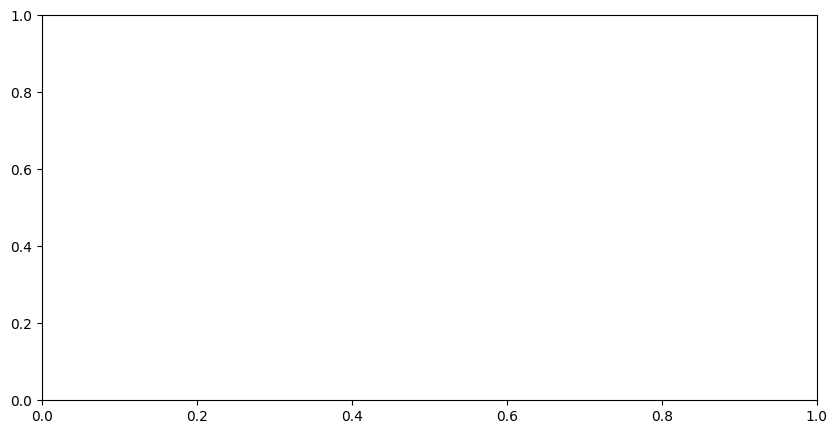

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Supongamos que tienes estas listas de pérdidas y precisiones después del entrenamiento
# Estas listas serían el resultado de tu bucle de entrenamiento y evaluación
train_losses = [...] # pérdidas de entrenamiento por época
test_losses = [...]  # pérdidas de prueba por época
train_accuracies = [...] # precisiones de entrenamiento por época
test_accuracies = [...]  # precisiones de prueba por época

epochs = range(1, len(train_losses) + 1)

# Gráfica de Pérdida
plt.figure(figsize=(10, 5))
plt.plot(epochs, train_losses, 'b', label='Pérdida de Entrenamiento')
plt.plot(epochs, test_losses, 'r', label='Pérdida de Prueba')
plt.title('Pérdida de Entrenamiento y Prueba')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)
plt.show()

# Gráfica de Precisión
plt.figure(figsize=(10, 5))
plt.plot(epochs, train_accuracies, 'b', label='Precisión de Entrenamiento')
plt.plot(epochs, test_accuracies, 'r', label='Precisión de Prueba')
plt.title('Precisión de Entrenamiento y Prueba')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.legend()
plt.grid(True)
plt.show()

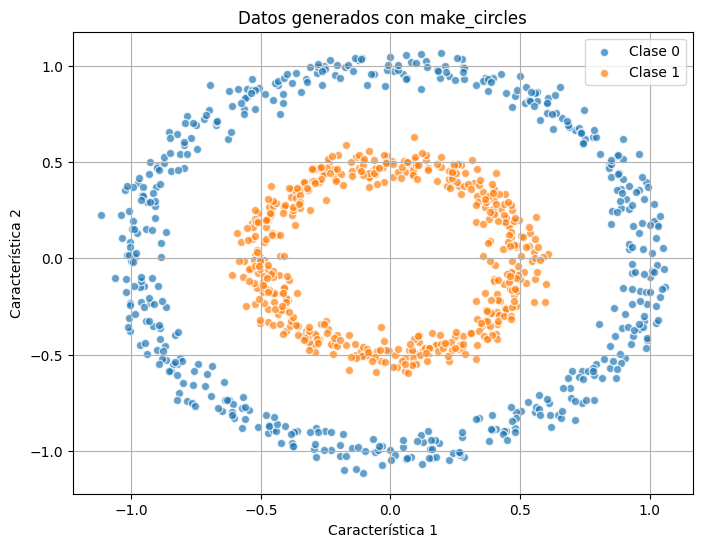

In [ ]:
from sklearn.datasets import make_circles
import matplotlib.pyplot as plt

# Generar 1000 muestras con ruido y un factor de escala para el círculo interno
X, y = make_circles(n_samples=1000, noise=0.05, factor=0.5, random_state=42)

# X son las características (coordenadas x, y)
# y son las etiquetas de clase (0 o 1)

# Visualizar los datos
plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], label='Clase 0', alpha=0.7, edgecolors='w')
plt.scatter(X[y == 1, 0], X[y == 1, 1], label='Clase 1', alpha=0.7, edgecolors='w')
plt.title('Datos generados con make_circles')
plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.legend()
plt.grid(True)
plt.show()

Época [20/200], Pérdida Entrenamiento: 0.0005, Precisión Entrenamiento: 1.0000, Pérdida Prueba: 0.0020, Precisión Prueba: 1.0000
Época [40/200], Pérdida Entrenamiento: 0.0000, Precisión Entrenamiento: 1.0000, Pérdida Prueba: 0.0000, Precisión Prueba: 1.0000
Época [60/200], Pérdida Entrenamiento: 0.0000, Precisión Entrenamiento: 1.0000, Pérdida Prueba: 0.0000, Precisión Prueba: 1.0000
Época [80/200], Pérdida Entrenamiento: 0.0000, Precisión Entrenamiento: 1.0000, Pérdida Prueba: 0.0000, Precisión Prueba: 1.0000
Época [100/200], Pérdida Entrenamiento: 0.0000, Precisión Entrenamiento: 1.0000, Pérdida Prueba: 0.0000, Precisión Prueba: 1.0000
Época [120/200], Pérdida Entrenamiento: 0.0000, Precisión Entrenamiento: 1.0000, Pérdida Prueba: 0.0000, Precisión Prueba: 1.0000
Época [140/200], Pérdida Entrenamiento: 0.0000, Precisión Entrenamiento: 1.0000, Pérdida Prueba: 0.0000, Precisión Prueba: 1.0000
Época [160/200], Pérdida Entrenamiento: 0.0000, Precisión Entrenamiento: 1.0000, Pérdida Prueb

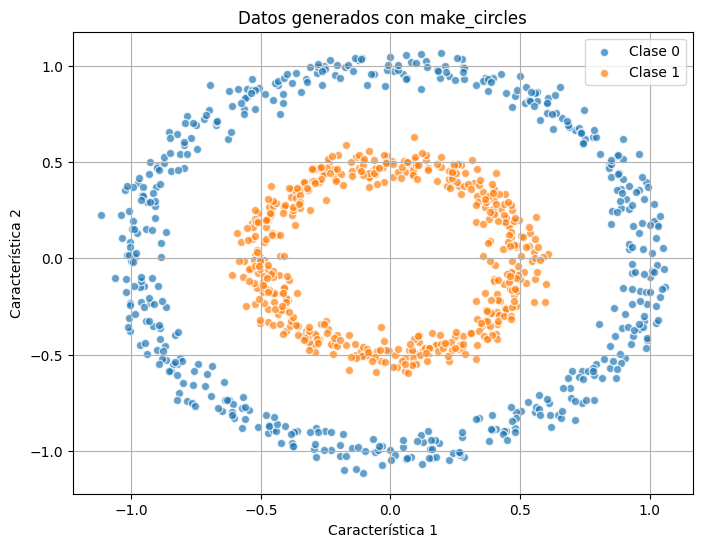


--- Gráficas de Entrenamiento y Prueba ---


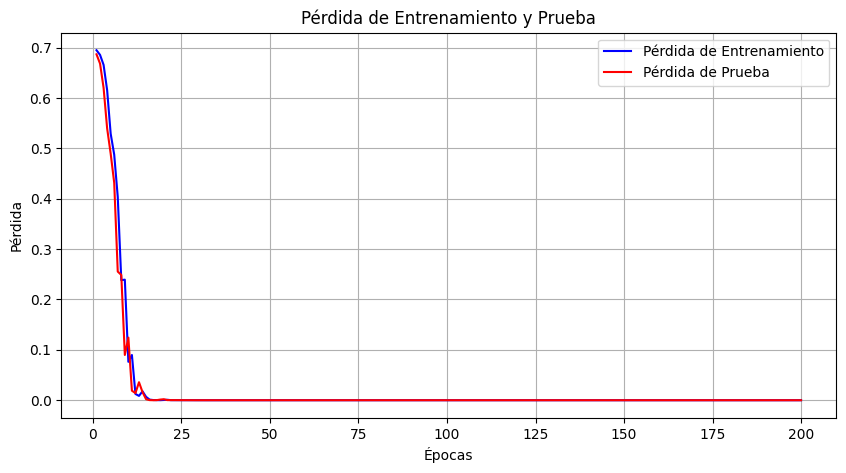

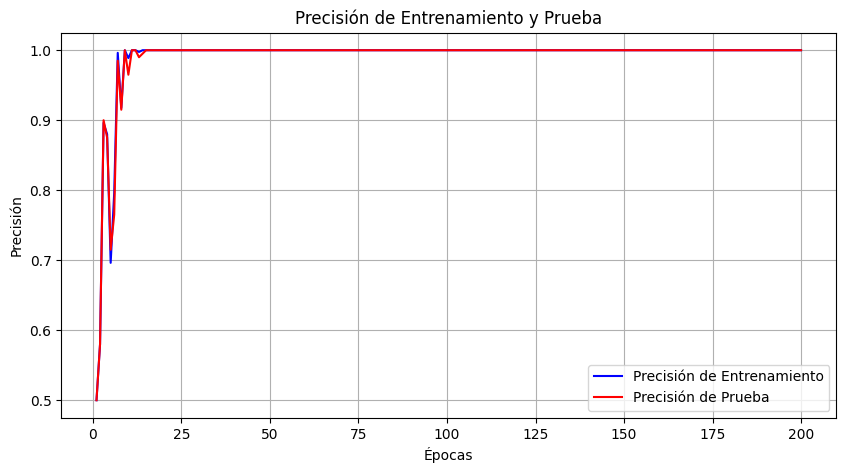

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Definición del Modelo NeuralBiomesModel (como proporcionado) ---
class NeuralBiomesModel(nn.Module):
    def __init__(self, input_dim, shared_features_dim, memory_hidden_dim, processing_output_dim, output_dim):
        super().__init__()

        # 1. Capa de Entrada Común ("El Mundo")
        self.shared_feature_extractor = nn.Sequential(
            nn.Linear(input_dim, shared_features_dim),
            nn.ReLU(),
            nn.Linear(shared_features_dim, shared_features_dim)
        )

        # 2. Bioma de Almacenamiento (LSTM para "memoria" secuencial)
        self.memory_biom = nn.LSTM(shared_features_dim, memory_hidden_dim, batch_first=True)

        # 3. Bioma de Procesamiento (MLP para lógica/cálculo)
        self.processing_biom = nn.Sequential(
            nn.Linear(shared_features_dim + memory_hidden_dim, 128),
            nn.ReLU(),
            nn.Linear(128, processing_output_dim),
            nn.ReLU()
        )

        # 4. Capa de Salida Final (combinando resultados de los biomas)
        self.output_layer = nn.Linear(processing_output_dim, output_dim)

    def forward(self, x):
        # Paso 1: Extraer características en el "Mundo"
        shared_features = self.shared_feature_extractor(x)

        # Paso 2: Pasar características al Bioma de Almacenamiento
        shared_features_seq = shared_features.unsqueeze(1)
        memory_output, (h_n, c_n) = self.memory_biom(shared_features_seq)
        memory_state = h_n.squeeze(0)

        # Paso 3: Pasar características y memoria al Bioma de Procesamiento
        combined_features = torch.cat((shared_features, memory_state), dim=1)
        processed_output = self.processing_biom(combined_features)

        # Paso 4: Pasar el resultado procesado a la capa de salida final
        final_output = self.output_layer(processed_output)

        return final_output

# --- 2. Generación de Datos con make_circles ---
# Generar 1000 muestras con ruido y un factor de escala para el círculo interno
X, y = make_circles(n_samples=1000, noise=0.05, factor=0.5, random_state=42)

# Convertir a tensores de PyTorch
X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32).unsqueeze(1) # Asegurar dimensión correcta para pérdida

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=42)

# --- 3. Inicialización del Modelo, Función de Pérdida y Optimizador ---
input_dim = X.shape[1] # 2 características (x, y)
shared_features_dim = 64
memory_hidden_dim = 32
processing_output_dim = 64
output_dim = 1 # Para clasificación binaria (0 o 1)

model = NeuralBiomesModel(input_dim, shared_features_dim, memory_hidden_dim, processing_output_dim, output_dim)
criterion = nn.BCEWithLogitsLoss() # Para clasificación binaria, maneja sigmoid internamente
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# --- 4. Entrenamiento del Modelo ---
num_epochs = 200
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

for epoch in range(num_epochs):
    model.train() # Poner el modelo en modo entrenamiento
    optimizer.zero_grad()
    outputs = model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    model.eval() # Poner el modelo en modo evaluación
    with torch.no_grad():
        # Evaluación en entrenamiento
        train_outputs = model(X_train)
        train_preds = (torch.sigmoid(train_outputs) > 0.5).float()
        train_acc = accuracy_score(y_train.numpy(), train_preds.numpy())
        train_accuracies.append(train_acc)

        # Evaluación en prueba
        test_outputs = model(X_test)
        test_loss = criterion(test_outputs, y_test)
        test_losses.append(test_loss.item())
        test_preds = (torch.sigmoid(test_outputs) > 0.5).float()
        test_acc = accuracy_score(y_test.numpy(), test_preds.numpy())
        test_accuracies.append(test_acc)

    if (epoch + 1) % 20 == 0:
        print(f'Época [{epoch+1}/{num_epochs}], Pérdida Entrenamiento: {loss.item():.4f}, Precisión Entrenamiento: {train_acc:.4f}, Pérdida Prueba: {test_loss.item():.4f}, Precisión Prueba: {test_acc:.4f}')

# --- 5. Visualización de Datos make_circles ---
print("\n--- Visualización de Datos make_circles ---")
plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], label='Clase 0', alpha=0.7, edgecolors='w')
plt.scatter(X[y == 1, 0], X[y == 1, 1], label='Clase 1', alpha=0.7, edgecolors='w')
plt.title('Datos generados con make_circles')
plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.legend()
plt.grid(True)
plt.show()

# --- 6. Visualización de Gráficas de Entrenamiento y Prueba ---
print("\n--- Gráficas de Entrenamiento y Prueba ---")
epochs_list = range(1, num_epochs + 1)

# Gráfica de Pérdida
plt.figure(figsize=(10, 5))
plt.plot(epochs_list, train_losses, 'b', label='Pérdida de Entrenamiento')
plt.plot(epochs_list, test_losses, 'r', label='Pérdida de Prueba')
plt.title('Pérdida de Entrenamiento y Prueba')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)
plt.show()

# Gráfica de Precisión
plt.figure(figsize=(10, 5))
plt.plot(epochs_list, train_accuracies, 'b', label='Precisión de Entrenamiento')
plt.plot(epochs_list, test_accuracies, 'r', label='Precisión de Prueba')
plt.title('Precisión de Entrenamiento y Prueba')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.legend()
plt.grid(True)
plt.show()

Época [20/200], Pérdida Entrenamiento: 0.0938, Precisión Entrenamiento: 0.9712, Pérdida Prueba: 0.0658, Precisión Prueba: 0.9850
Época [40/200], Pérdida Entrenamiento: 0.0673, Precisión Entrenamiento: 0.9750, Pérdida Prueba: 0.0428, Precisión Prueba: 0.9900
Época [60/200], Pérdida Entrenamiento: 0.0601, Precisión Entrenamiento: 0.9725, Pérdida Prueba: 0.0538, Precisión Prueba: 0.9650
Época [80/200], Pérdida Entrenamiento: 0.0532, Precisión Entrenamiento: 0.9788, Pérdida Prueba: 0.0406, Precisión Prueba: 0.9900
Época [100/200], Pérdida Entrenamiento: 0.0515, Precisión Entrenamiento: 0.9775, Pérdida Prueba: 0.0340, Precisión Prueba: 0.9950
Época [120/200], Pérdida Entrenamiento: 0.0484, Precisión Entrenamiento: 0.9800, Pérdida Prueba: 0.0381, Precisión Prueba: 0.9900
Época [140/200], Pérdida Entrenamiento: 0.0576, Precisión Entrenamiento: 0.9788, Pérdida Prueba: 0.0435, Precisión Prueba: 0.9800
Época [160/200], Pérdida Entrenamiento: 0.0479, Precisión Entrenamiento: 0.9762, Pérdida Prueb

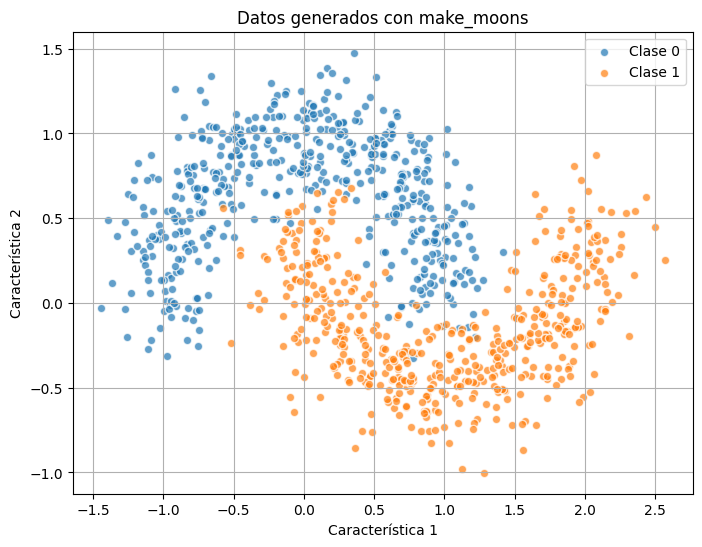


--- Gráficas de Entrenamiento y Prueba ---


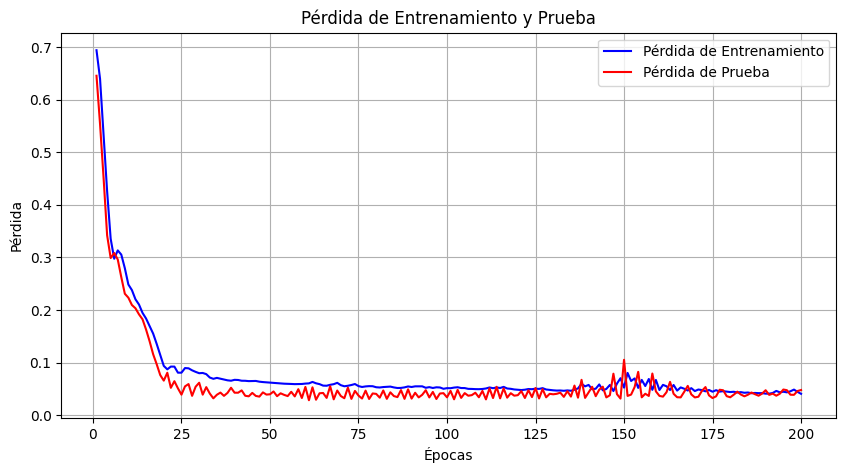

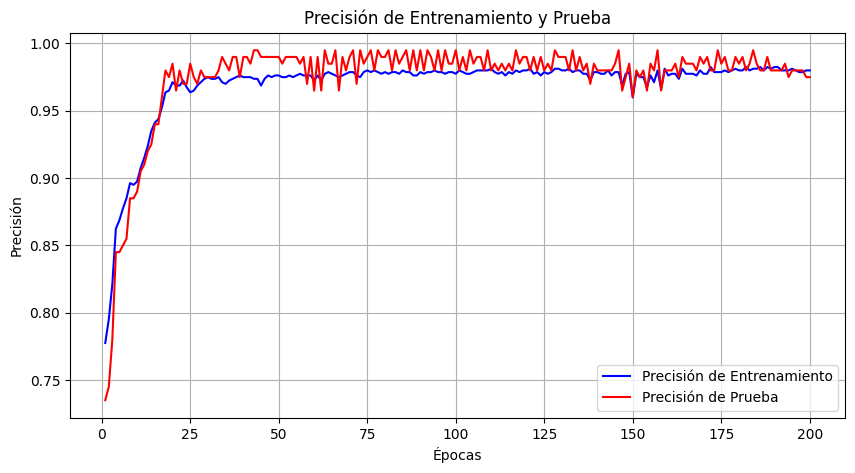

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Definición del Modelo NeuralBiomesModel ---
class NeuralBiomesModel(nn.Module):
    def __init__(self, input_dim, shared_features_dim, memory_hidden_dim, processing_output_dim, output_dim):
        super().__init__()
        self.shared_feature_extractor = nn.Sequential(
            nn.Linear(input_dim, shared_features_dim),
            nn.ReLU(),
            nn.Linear(shared_features_dim, shared_features_dim)
        )
        self.memory_biom = nn.LSTM(shared_features_dim, memory_hidden_dim, batch_first=True)
        self.processing_biom = nn.Sequential(
            nn.Linear(shared_features_dim + memory_hidden_dim, 128),
            nn.ReLU(),
            nn.Linear(128, processing_output_dim),
            nn.ReLU()
        )
        self.output_layer = nn.Linear(processing_output_dim, output_dim)

    def forward(self, x):
        shared_features = self.shared_feature_extractor(x)
        shared_features_seq = shared_features.unsqueeze(1)
        memory_output, (h_n, c_n) = self.memory_biom(shared_features_seq)
        memory_state = h_n.squeeze(0)
        combined_features = torch.cat((shared_features, memory_state), dim=1)
        processed_output = self.processing_biom(combined_features)
        final_output = self.output_layer(processed_output)
        return final_output

# --- 2. Generación de Datos con make_moons ---
X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)
X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=42)

# --- 3. Inicialización del Modelo ---
input_dim = X.shape[1]
shared_features_dim = 64
memory_hidden_dim = 32
processing_output_dim = 64
output_dim = 1

model = NeuralBiomesModel(input_dim, shared_features_dim, memory_hidden_dim, processing_output_dim, output_dim)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# --- 4. Entrenamiento ---
num_epochs = 200
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    model.eval()
    with torch.no_grad():
        train_outputs = model(X_train)
        train_preds = (torch.sigmoid(train_outputs) > 0.5).float()
        train_acc = accuracy_score(y_train.numpy(), train_preds.numpy())
        train_accuracies.append(train_acc)

        test_outputs = model(X_test)
        test_loss = criterion(test_outputs, y_test)
        test_losses.append(test_loss.item())
        test_preds = (torch.sigmoid(test_outputs) > 0.5).float()
        test_acc = accuracy_score(y_test.numpy(), test_preds.numpy())
        test_accuracies.append(test_acc)

    if (epoch + 1) % 20 == 0:
        print(f'Época [{epoch+1}/{num_epochs}], Pérdida Entrenamiento: {loss.item():.4f}, Precisión Entrenamiento: {train_acc:.4f}, Pérdida Prueba: {test_loss.item():.4f}, Precisión Prueba: {test_acc:.4f}')

# --- 5. Visualización de Datos make_moons ---
print("\n--- Visualización de Datos make_moons ---")
plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], label='Clase 0', alpha=0.7, edgecolors='w')
plt.scatter(X[y == 1, 0], X[y == 1, 1], label='Clase 1', alpha=0.7, edgecolors='w')
plt.title('Datos generados con make_moons')
plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.legend()
plt.grid(True)
plt.show()

# --- 6. Visualización de Gráficas de Entrenamiento y Prueba ---
print("\n--- Gráficas de Entrenamiento y Prueba ---")
epochs_list = range(1, num_epochs + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs_list, train_losses, 'b', label='Pérdida de Entrenamiento')
plt.plot(epochs_list, test_losses, 'r', label='Pérdida de Prueba')
plt.title('Pérdida de Entrenamiento y Prueba')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(epochs_list, train_accuracies, 'b', label='Precisión de Entrenamiento')
plt.plot(epochs_list, test_accuracies, 'r', label='Precisión de Prueba')
plt.title('Precisión de Entrenamiento y Prueba')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.legend()
plt.grid(True)
plt.show()

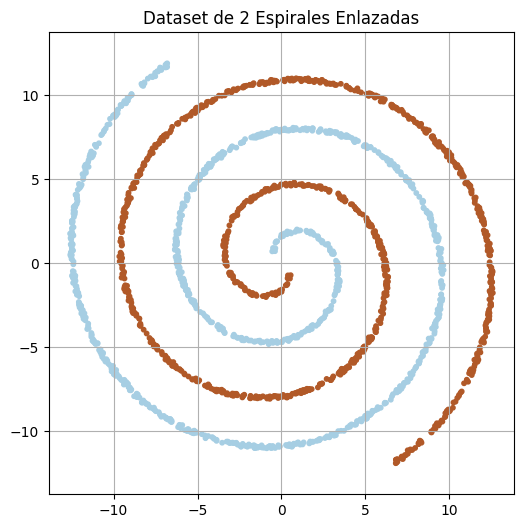

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Generador de 2 espirales entrelazadas
def make_spirals(n_points=1000, noise=0.05):
    n = np.sqrt(np.random.rand(n_points)) * 780 * (2 * np.pi) / 360
    d1x = -np.cos(n) * n + np.random.rand(n_points) * noise
    d1y = np.sin(n) * n + np.random.rand(n_points) * noise
    X = np.vstack((np.append(d1x, -d1x), np.append(d1y, -d1y))).T
    y = np.hstack((np.zeros(n_points), np.ones(n_points)))
    return X, y

# Generar los datos
X_spiral, y_spiral = make_spirals(n_points=1000, noise=0.2)

# Visualizar
plt.figure(figsize=(6, 6))
plt.scatter(X_spiral[:, 0], X_spiral[:, 1], c=y_spiral, cmap=plt.cm.Paired, s=10)
plt.title("Dataset de 2 Espirales Enlazadas")
plt.axis("equal")
plt.grid(True)
plt.show()

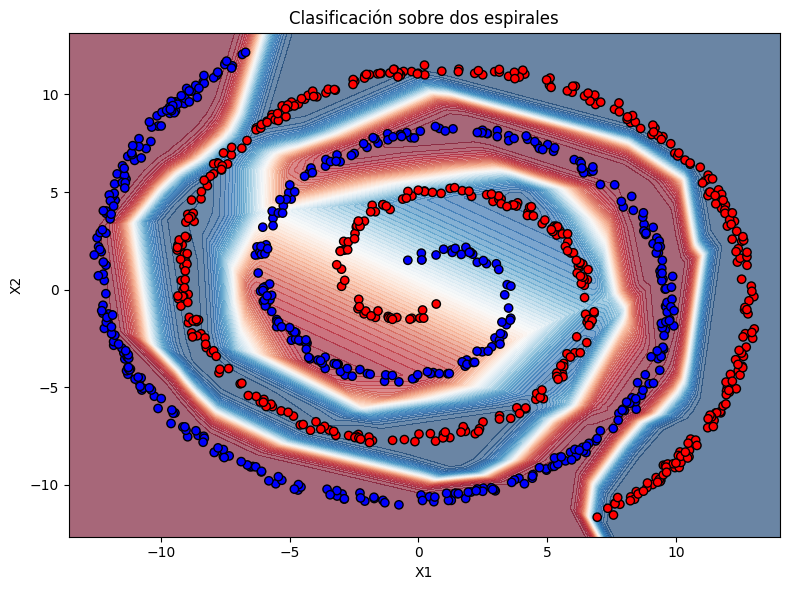

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# Remove: from sklearn.datasets import make_spiral # This function does not exist in sklearn.datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim

# Generador de 2 espirales entrelazadas (clásico) - Defina la función antes de usarla
def make_two_spirals(n_points, noise=1.0):
    n = np.sqrt(np.random.rand(n_points//2)) * 780 * (2 * np.pi)/360
    d1x = -np.cos(n)*n + np.random.rand(n_points//2) * noise
    d1y = np.sin(n)*n + np.random.rand(n_points//2) * noise
    d2x = np.cos(n)*n + np.random.rand(n_points//2) * noise
    d2y = -np.sin(n)*n + np.random.rand(n_points//2) * noise
    X = np.vstack((np.hstack((d1x,d2x)), np.hstack((d1y,d2y)))).T
    y = np.hstack((np.zeros(n_points//2), np.ones(n_points//2)))
    return X, y


# Preparar datos
X, y = make_two_spirals(1000, noise=0.5) # Usar la función definida localmente
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convertir a tensores
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

# Modelo simple
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)

# Entrenar modelo
model = SimpleNN()
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

epochs = 200
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    loss.backward()
    optimizer.step()
    # Opcional: print de progreso si se desea
    # if (epoch + 1) % 20 == 0:
    #     print(f'Época [{epoch+1}/{epochs}], Pérdida: {loss.item():.4f}')


# Crear malla para visualización
xx, yy = np.meshgrid(np.linspace(X[:,0].min()-1, X[:,0].max()+1, 300),
                     np.linspace(X[:,1].min()-1, X[:,1].max()+1, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
grid_scaled = scaler.transform(grid)
grid_tensor = torch.tensor(grid_scaled, dtype=torch.float32)
with torch.no_grad():
    preds = model(grid_tensor).reshape(xx.shape)

# Graficar
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, preds, levels=50, cmap="RdBu", alpha=0.6)
plt.scatter(X[:,0], X[:,1], c=y, cmap="bwr", edgecolors='k')
plt.title("Clasificación sobre dos espirales")
plt.xlabel("X1")
plt.ylabel("X2")
plt.tight_layout()
plt.show()

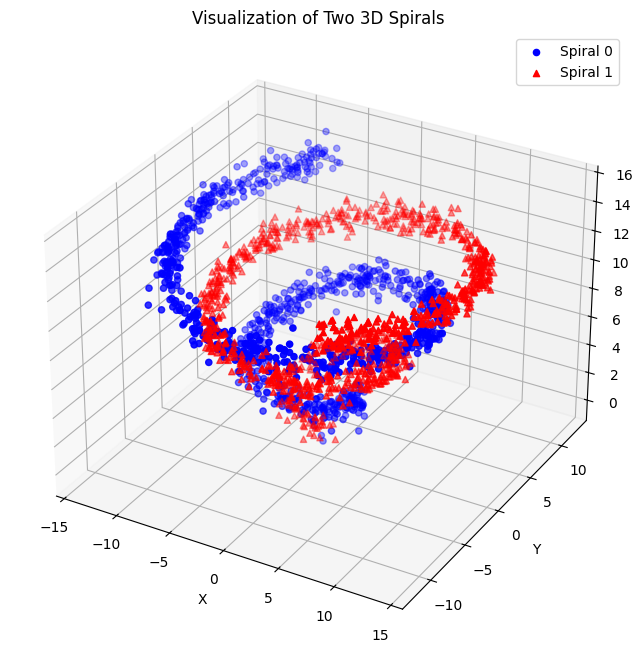

In [ ]:


# Need to import necessary libraries for plotting 3D data
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Define the function provided in the prompt if it's not already defined
def make_two_spirals_3D(n_points=1000, noise=0.3):
    n = np.sqrt(np.random.rand(n_points // 2)) * 780 * (2 * np.pi)/360  # ángulos en radianes
    x1 = -np.cos(n) * n + np.random.normal(0, noise, n_points // 2)
    y1 = np.sin(n) * n + np.random.normal(0, noise, n_points // 2)
    z1 = n + np.random.normal(0, noise, n_points // 2)  # añadir dimensión z
    x2 = np.cos(n) * n + np.random.normal(0, noise, n_points // 2)
    y2 = -np.sin(n) * n + np.random.normal(0, noise, n_points // 2)
    z2 = n + np.random.normal(0, noise, n_points // 2)
    X = np.vstack([
        np.stack([x1, y1, z1], axis=1),
        np.stack([x2, y2, z2], axis=1)
    ])
    y = np.hstack([np.zeros(n_points // 2), np.ones(n_points // 2)])
    return X, y

# Generate the 3D spiral data
X_3d, y_3d = make_two_spirals_3D(n_points=2000, noise=0.5) # Increased points for better visualization

# Create a 3D plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the two classes with different colors
ax.scatter(X_3d[y_3d == 0, 0], X_3d[y_3d == 0, 1], X_3d[y_3d == 0, 2], c='blue', marker='o', label='Spiral 0')
ax.scatter(X_3d[y_3d == 1, 0], X_3d[y_3d == 1, 1], X_3d[y_3d == 1, 2], c='red', marker='^', label='Spiral 1')

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Visualization of Two 3D Spirals')
ax.legend()

# Show the plot
plt.show()

Precisión en test: 99.5000%


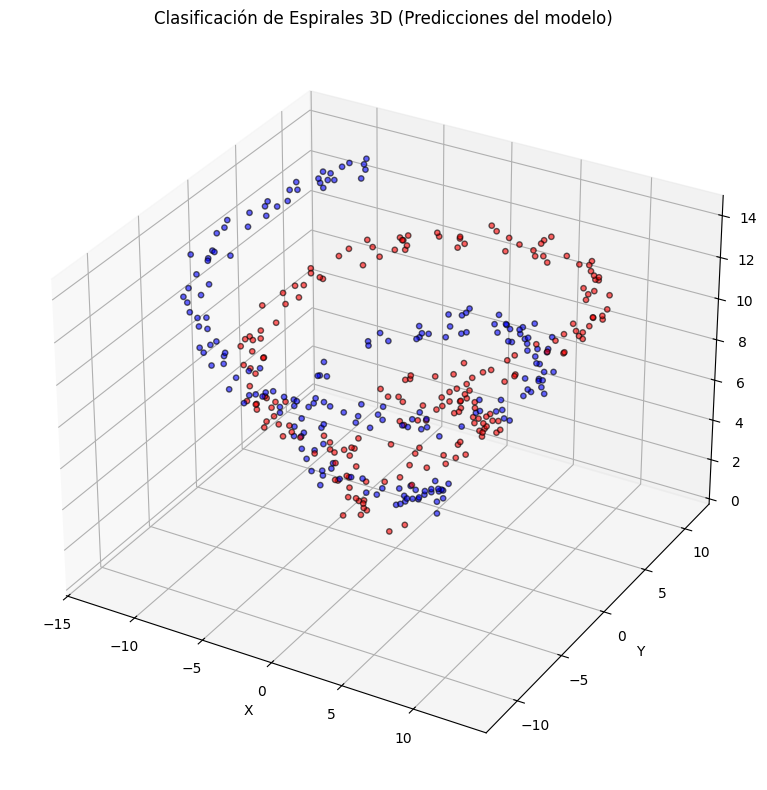

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
from mpl_toolkits.mplot3d import Axes3D

# Función para generar espirales 3D
def make_two_spirals_3D(n_points=1000, noise=0.3):
    n = np.sqrt(np.random.rand(n_points // 2)) * 780 * (2 * np.pi)/360
    x1 = -np.cos(n) * n + np.random.normal(0, noise, n_points // 2)
    y1 = np.sin(n) * n + np.random.normal(0, noise, n_points // 2)
    z1 = n + np.random.normal(0, noise, n_points // 2)

    x2 = np.cos(n) * n + np.random.normal(0, noise, n_points // 2)
    y2 = -np.sin(n) * n + np.random.normal(0, noise, n_points // 2)
    z2 = n + np.random.normal(0, noise, n_points // 2)

    X = np.vstack([
        np.stack([x1, y1, z1], axis=1),
        np.stack([x2, y2, z2], axis=1)
    ])
    y = np.hstack([np.zeros(n_points // 2), np.ones(n_points // 2)])
    return X, y

# Preparar datos
X, y = make_two_spirals_3D(2000, noise=0.4)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Tensores
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

# Modelo 3D
class Spiral3DClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x)

model = Spiral3DClassifier()
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Entrenamiento
for epoch in range(300):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    loss.backward()
    optimizer.step()
    # print(f"Epoch {epoch+1}, Loss: {loss.item():.4f}")

# Evaluación
model.eval()
with torch.no_grad():
    test_preds = model(X_test_tensor)
    predicted = (test_preds > 0.5).float()
    accuracy = (predicted == y_test_tensor).float().mean().item() * 100
    print(f"Precisión en test: {accuracy:.4f}%")

# Visualización 3D del resultado (solo muestra puntos de testeo con color de predicción)
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Colores reales vs predichos
colors = np.where(predicted.numpy().flatten() == 0, 'blue', 'red')
ax.scatter(X_test[:, 0], X_test[:, 1], X_test[:, 2], c=colors, s=15, alpha=0.6, edgecolors='k')

ax.set_title("Clasificación de Espirales 3D (Predicciones del modelo)")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.tight_layout()
plt.show()

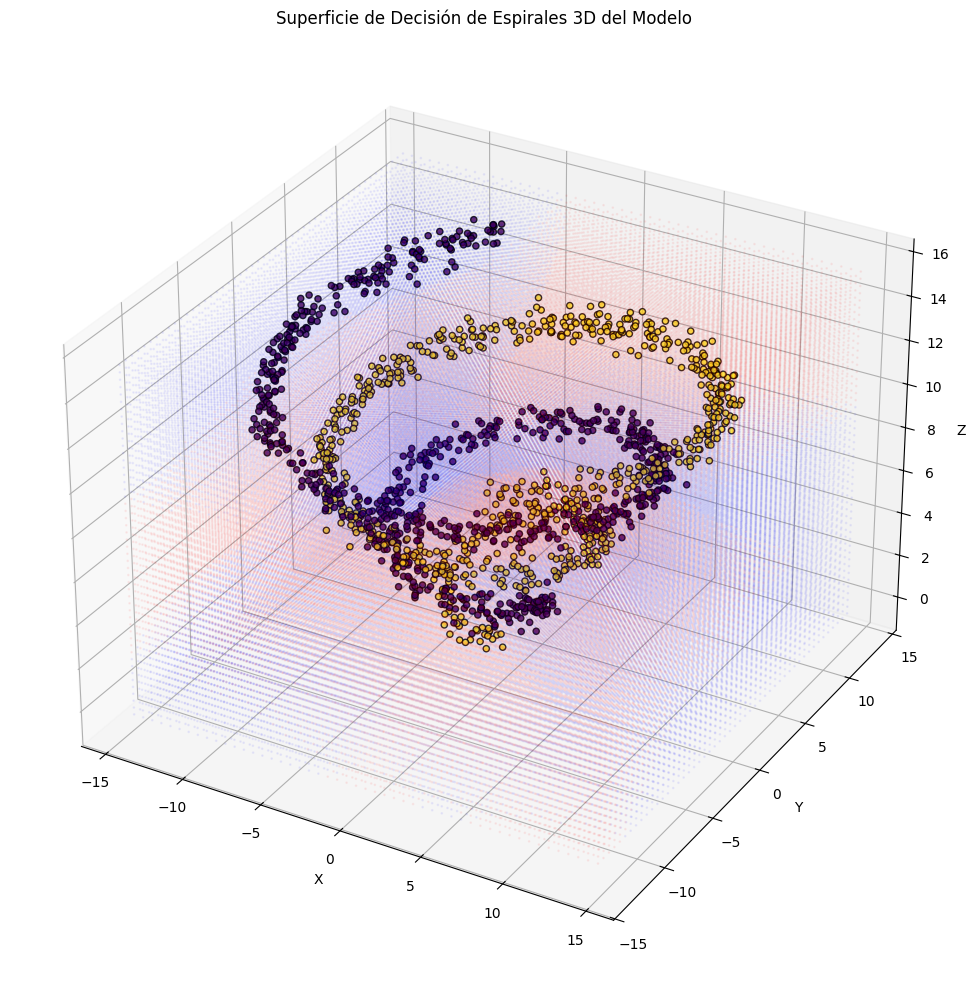

In [ ]:
# Generar una rejilla 3D para la visualización
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
z_min, z_max = X[:, 2].min() - 1, X[:, 2].max() + 1

# Reducir la resolución de la rejilla para un cálculo más rápido
# Considera aumentar el número de puntos si tienes un buen GPU para más detalle
xx, yy, zz = np.meshgrid(
    np.linspace(x_min, x_max, 50), # 50 puntos en cada dimensión
    np.linspace(y_min, y_max, 50),
    np.linspace(z_min, z_max, 50)
)
grid_points = np.c_[xx.ravel(), yy.ravel(), zz.ravel()]

# Escalar los puntos de la rejilla usando el mismo scaler de entrenamiento
grid_points_scaled = scaler.transform(grid_points)
grid_points_tensor = torch.tensor(grid_points_scaled, dtype=torch.float32)

# Obtener predicciones del modelo en la rejilla
model.eval()
with torch.no_grad():
    grid_preds = model(grid_points_tensor)
    grid_predictions = (grid_preds > 0.5).float().numpy().reshape(xx.shape)

# Visualización de la superficie de decisión
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Visualizar la rejilla 3D con colores de predicción
# Usamos scatter para mostrar la "densidad" de la clasificación
# o puedes usar ax.contourf para superficies si la predicción es más suave
# Aquí, como son 0 o 1, el scatter es más representativo de los vóxeles
ax.scatter(xx[grid_predictions == 0], yy[grid_predictions == 0], zz[grid_predictions == 0],
           color='blue', alpha=0.05, s=1) # S = tamaño del punto
ax.scatter(xx[grid_predictions == 1], yy[grid_predictions == 1], zz[grid_predictions == 1],
           color='red', alpha=0.05, s=1)

# También puedes mostrar algunos puntos de entrenamiento para contexto
ax.scatter(X_train[:, 0], X_train[:, 1], X_train[:, 2], c=y_train, cmap='viridis', s=20, alpha=0.8, edgecolors='k')

ax.set_title("Superficie de Decisión de Espirales 3D del Modelo")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.tight_layout()
plt.show()


Entrenando modelo 4D...
Precisión en test 4D: 100.0000%


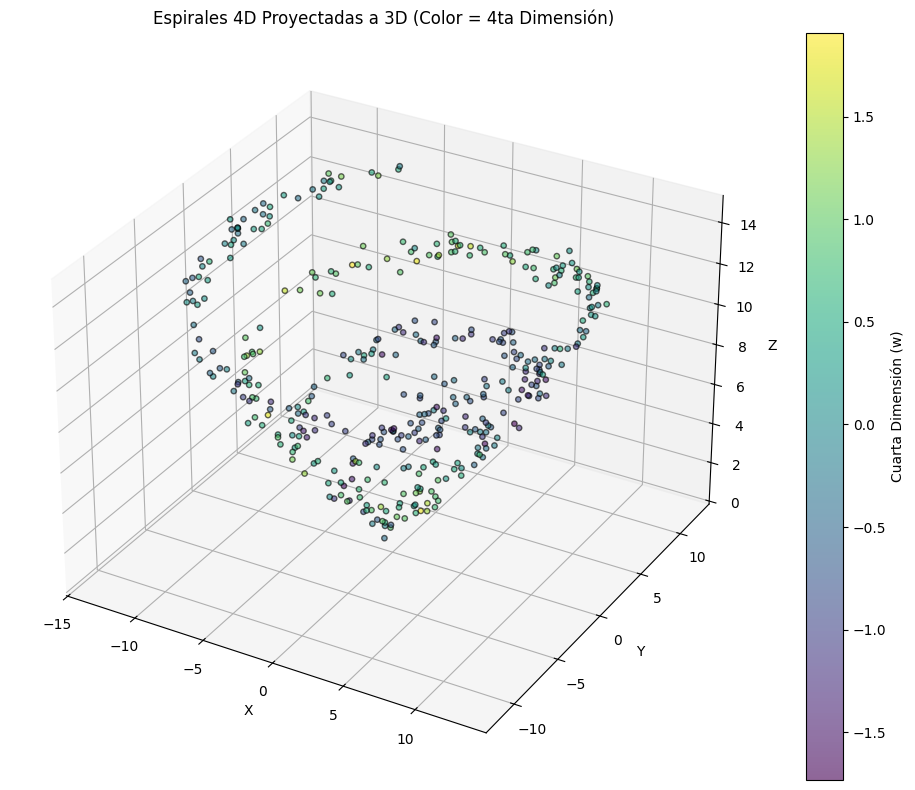

In [ ]:
# Función para generar espirales 4D (ejemplo simplificado)
def make_two_spirals_4D(n_points=1000, noise=0.3):
    n = np.sqrt(np.random.rand(n_points // 2)) * 780 * (2 * np.pi) / 360

    # Primera espiral 4D
    x1 = -np.cos(n) * n + np.random.normal(0, noise, n_points // 2)
    y1 = np.sin(n) * n + np.random.normal(0, noise, n_points // 2)
    z1 = n + np.random.normal(0, noise, n_points // 2)
    w1 = np.sin(n * 0.5) + np.random.normal(0, noise, n_points // 2) # Cuarta dimensión

    # Segunda espiral 4D
    x2 = np.cos(n) * n + np.random.normal(0, noise, n_points // 2)
    y2 = -np.sin(n) * n + np.random.normal(0, noise, n_points // 2)
    z2 = n + np.random.normal(0, noise, n_points // 2)
    w2 = -np.sin(n * 0.5) + np.random.normal(0, noise, n_points // 2) # Cuarta dimensión opuesta

    X = np.vstack([
        np.stack([x1, y1, z1, w1], axis=1),
        np.stack([x2, y2, z2, w2], axis=1)
    ])
    y = np.hstack([np.zeros(n_points // 2), np.ones(n_points // 2)])
    return X, y

# Preparar datos 4D
X_4d, y_4d = make_two_spirals_4D(2000, noise=0.4)
X_train_4d, X_test_4d, y_train_4d, y_test_4d = train_test_split(X_4d, y_4d, test_size=0.2, random_state=42)
scaler_4d = StandardScaler()
X_train_scaled_4d = scaler_4d.fit_transform(X_train_4d)
X_test_scaled_4d = scaler_4d.transform(X_test_4d)

# Tensores 4D
X_train_tensor_4d = torch.tensor(X_train_scaled_4d, dtype=torch.float32)
y_train_tensor_4d = torch.tensor(y_train_4d, dtype=torch.float32).unsqueeze(1)
X_test_tensor_4d = torch.tensor(X_test_scaled_4d, dtype=torch.float32)
y_test_tensor_4d = torch.tensor(y_test_4d, dtype=torch.float32).unsqueeze(1)

# Modelo 4D (cambiar la capa de entrada a 4 características)
class Spiral4DClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 64), # Aumentamos la complejidad
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x)

model_4d = Spiral4DClassifier()
criterion_4d = nn.BCELoss()
optimizer_4d = optim.Adam(model_4d.parameters(), lr=0.01)

# Entrenamiento 4D
print("\nEntrenando modelo 4D...")
for epoch in range(500): # Más épocas para 4D
    model_4d.train()
    optimizer_4d.zero_grad()
    outputs_4d = model_4d(X_train_tensor_4d)
    loss_4d = criterion_4d(outputs_4d, y_train_tensor_4d)
    loss_4d.backward()
    optimizer_4d.step()
    # if (epoch + 1) % 50 == 0:
    #     print(f"Epoch {epoch+1}, Loss: {loss_4d.item():.4f}")

# Evaluación 4D
model_4d.eval()
with torch.no_grad():
    test_preds_4d = model_4d(X_test_tensor_4d)
    predicted_4d = (test_preds_4d > 0.5).float()
    accuracy_4d = (predicted_4d == y_test_tensor_4d).float().mean().item() * 100
    print(f"Precisión en test 4D: {accuracy_4d:.4f}%")

# Visualización 3D (proyectando 4D a 3D o usando un color para la 4ta dimensión)
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Proyectamos los puntos 4D de testeo a 3D (ignorando o usando 'w' como color/tamaño)
# Aquí usamos la cuarta dimensión 'w' para el color, que es una forma de "embeberla" visualmente
scatter = ax.scatter(X_test_4d[:, 0], X_test_4d[:, 1], X_test_4d[:, 2],
                     c=X_test_4d[:, 3], cmap='viridis', s=15, alpha=0.6, edgecolors='k')
fig.colorbar(scatter, ax=ax, label='Cuarta Dimensión (w)')

ax.set_title("Espirales 4D Proyectadas a 3D (Color = 4ta Dimensión)")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.tight_layout()
plt.show()


Entrenando modelo 5D con espirales entrelazadas y ruido variable...
Precisión en test 5D: 99.8750%


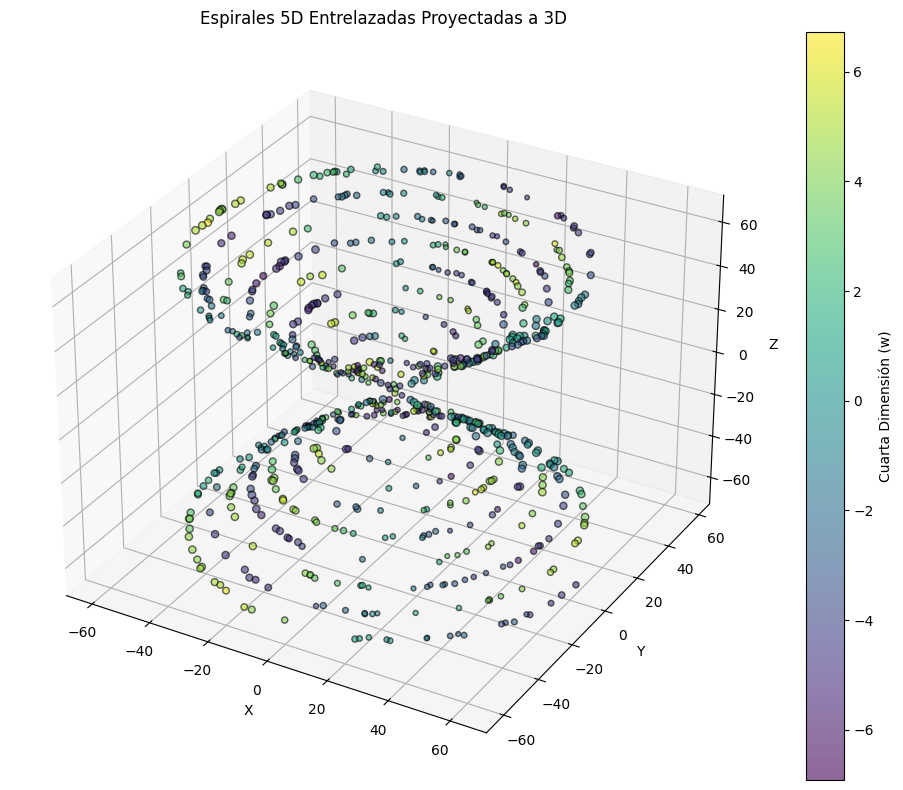

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
from mpl_toolkits.mplot3d import Axes3D # Para la visualización 3D proyectada

# Función para generar espirales 5D entrelazadas con ruido variable
def make_two_intertwined_spirals_5D(n_points=2000, noise_base=0.2, noise_dim_mult=[1.0, 1.0, 1.5, 2.0, 2.5]):
    n_half = n_points // 2
    t = np.sqrt(np.random.rand(n_half)) * 10 * (2 * np.pi) # Aumentamos el rango para más complejidad

    # Espiral 1
    x1 = np.cos(t) * t + np.random.normal(0, noise_base * noise_dim_mult[0], n_half)
    y1 = np.sin(t) * t + np.random.normal(0, noise_base * noise_dim_mult[1], n_half)
    z1 = t + np.random.normal(0, noise_base * noise_dim_mult[2], n_half)
    w1 = np.sin(t * 1.5) * 5 + np.random.normal(0, noise_base * noise_dim_mult[3], n_half) # 4ta dim
    v1 = np.cos(t * 2.0) * 3 + np.random.normal(0, noise_base * noise_dim_mult[4], n_half) # 5ta dim

    # Espiral 2 (entrelazada, con desfase y curvatura diferente)
    # Se entrelaza mediante un desfase de pi y una manipulación de las dimensiones
    x2 = -np.cos(t + np.pi) * t + np.random.normal(0, noise_base * noise_dim_mult[0], n_half)
    y2 = -np.sin(t + np.pi) * t + np.random.normal(0, noise_base * noise_dim_mult[1], n_half)
    z2 = -t + np.random.normal(0, noise_base * noise_dim_mult[2], n_half) # Z invertida para cruce
    w2 = -np.sin(t * 1.5 + np.pi/2) * 5 + np.random.normal(0, noise_base * noise_dim_mult[3], n_half) # 4ta dim entrelazada
    v2 = -np.cos(t * 2.0 + np.pi/2) * 3 + np.random.normal(0, noise_base * noise_dim_mult[4], n_half) # 5ta dim entrelazada

    X = np.vstack([
        np.stack([x1, y1, z1, w1, v1], axis=1),
        np.stack([x2, y2, z2, w2, v2], axis=1)
    ])
    y = np.hstack([np.zeros(n_half), np.ones(n_half)])
    return X, y

# Preparar datos 5D
X_5d, y_5d = make_two_intertwined_spirals_5D(n_points=4000, noise_base=0.3) # Más puntos y ruido base
X_train_5d, X_test_5d, y_train_5d, y_test_5d = train_test_split(X_5d, y_5d, test_size=0.2, random_state=42)
scaler_5d = StandardScaler()
X_train_scaled_5d = scaler_5d.fit_transform(X_train_5d)
X_test_scaled_5d = scaler_5d.transform(X_test_5d)

# Tensores 5D
X_train_tensor_5d = torch.tensor(X_train_scaled_5d, dtype=torch.float32)
y_train_tensor_5d = torch.tensor(y_train_5d, dtype=torch.float32).unsqueeze(1)
X_test_tensor_5d = torch.tensor(X_test_scaled_5d, dtype=torch.float32)
y_test_tensor_5d = torch.tensor(y_test_5d, dtype=torch.float32).unsqueeze(1)

# Modelo 5D (cambiar la capa de entrada a 5 características y aumentar la complejidad)
class Spiral5DClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(5, 128), # Capa de entrada 5, más neuronas
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x)

model_5d = Spiral5DClassifier()
criterion_5d = nn.BCELoss()
optimizer_5d = optim.Adam(model_5d.parameters(), lr=0.005) # Reducir learning rate para estabilidad

# Entrenamiento 5D
print("\nEntrenando modelo 5D con espirales entrelazadas y ruido variable...")
for epoch in range(1000): # Más épocas y posiblemente más pequeñas para converger
    model_5d.train()
    optimizer_5d.zero_grad()
    outputs_5d = model_5d(X_train_tensor_5d)
    loss_5d = criterion_5d(outputs_5d, y_train_tensor_5d)
    loss_5d.backward()
    optimizer_5d.step()
    # if (epoch + 1) % 100 == 0:
    #     print(f"Epoch {epoch+1}, Loss: {loss_5d.item():.4f}")

# Evaluación 5D
model_5d.eval()
with torch.no_grad():
    test_preds_5d = model_5d(X_test_tensor_5d)
    predicted_5d = (test_preds_5d > 0.5).float()
    accuracy_5d = (predicted_5d == y_test_tensor_5d).float().mean().item() * 100
    print(f"Precisión en test 5D: {accuracy_5d:.4f}%")

# Visualización 3D (proyectando 5D a 3D)
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Proyectamos los puntos 5D de testeo a 3D (por ejemplo, x, y, z)
# Y usamos las otras dos dimensiones (w y v) para el color y el tamaño
# para tratar de visualizar la complejidad adicional.
scatter = ax.scatter(X_test_5d[:, 0], X_test_5d[:, 1], X_test_5d[:, 2],
                     c=X_test_5d[:, 3], # Color basado en la 4ta dimensión
                     s=10 + 20 * (X_test_5d[:, 4] - X_test_5d[:, 4].min()) / (X_test_5d[:, 4].max() - X_test_5d[:, 4].min()), # Tamaño basado en la 5ta dimensión
                     cmap='viridis', alpha=0.6, edgecolors='k')
fig.colorbar(scatter, ax=ax, label='Cuarta Dimensión (w)')

ax.set_title("Espirales 5D Entrelazadas Proyectadas a 3D")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.tight_layout()
plt.show()


Entrenando modelo 10D con manifolds complejos y ruido heterogéneo...
Precisión en test 10D: 95.0000%

Realizando reducción de dimensionalidad con t-SNE (puede tardar un poco)...


/usr/local/lib/python3.11/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


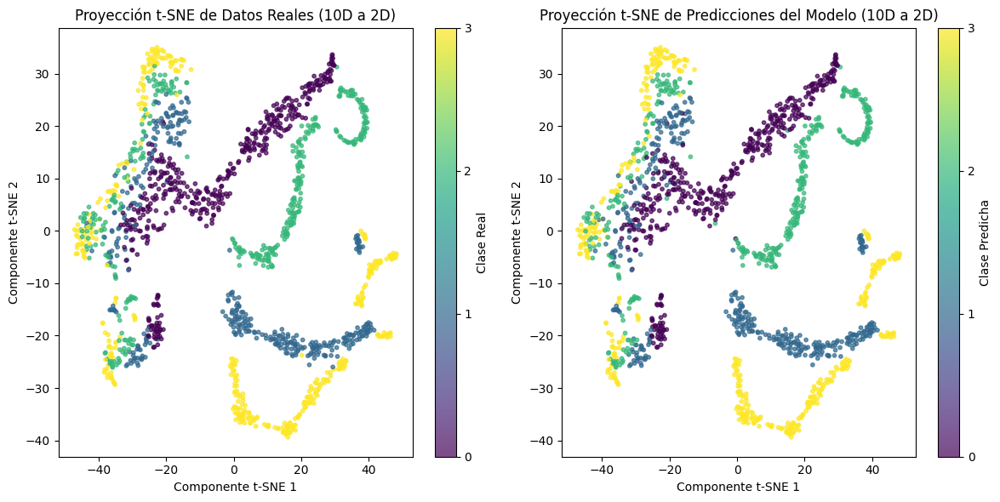

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
from mpl_toolkits.mplot3d import Axes3D # Para la visualización proyectada
from sklearn.manifold import TSNE # Para visualizar en 2D/3D

# Función para generar datos en 10D con múltiples clases complejas
def make_complex_10D_data(n_points_per_class=1000, n_classes=4, noise_factor=0.8):
    data = []
    labels = []
    total_points = n_points_per_class * n_classes

    # Puntos base para la variación
    base_t = np.linspace(-np.pi, np.pi, n_points_per_class)

    for i in range(n_classes):
        # Cada clase tendrá una estructura ligeramente diferente
        # Usamos funciones trigonométricas y polinómicas para crear no-linealidad
        t = base_t + np.random.rand(n_points_per_class) * 0.5 * (2*np.pi) # Añadir variación a 't'

        # Generar 10 dimensiones para cada clase
        # La complejidad viene de la combinación de senos/cosenos y potencias
        # y la dependencia de 't' y otros factores aleatorios
        d1 = np.sin(t * (i + 1)) * t + np.random.normal(0, noise_factor * 0.5, n_points_per_class)
        d2 = np.cos(t * (i + 1)) * t + np.random.normal(0, noise_factor * 0.5, n_points_per_class)
        d3 = np.sin(t * (i + 0.5)) + np.cos(t * 2) + np.random.normal(0, noise_factor * 0.7, n_points_per_class)
        d4 = np.sin(t * 0.7) * (i + 1) + t**2 * 0.1 + np.random.normal(0, noise_factor * 0.8, n_points_per_class)
        d5 = np.cos(t * 1.2) * (i + 1) - t**2 * 0.1 + np.random.normal(0, noise_factor * 0.9, n_points_per_class)
        d6 = np.sin(t * 0.3) * np.cos(t * 0.8) * (i + 1) + np.random.normal(0, noise_factor * 1.0, n_points_per_class)
        d7 = np.tanh(t * 0.5) * (i + 1) + np.random.normal(0, noise_factor * 1.1, n_points_per_class)
        d8 = np.exp(-t**2 / 10) * np.sin(t * 3) * (i + 1) + np.random.normal(0, noise_factor * 1.2, n_points_per_class)
        d9 = np.log(np.abs(t) + 1) * np.cos(t * 0.5) * (i + 1) + np.random.normal(0, noise_factor * 1.3, n_points_per_class)
        d10 = (t + np.random.rand(n_points_per_class) * 2) * (i % 2 * 2 - 1) + np.random.normal(0, noise_factor * 1.4, n_points_per_class) # Última dim con variación

        class_data = np.vstack([d1, d2, d3, d4, d5, d6, d7, d8, d9, d10]).T
        data.append(class_data)
        labels.append(np.full(n_points_per_class, i)) # Etiquetas de clase

    X = np.vstack(data)
    y = np.hstack(labels)
    return X, y

# Generar datos
n_classes = 4 # Ahora 4 clases
X_10d, y_10d = make_complex_10D_data(n_points_per_class=2000, n_classes=n_classes, noise_factor=0.6) # Más puntos

# Dividir y escalar los datos
X_train_10d, X_test_10d, y_train_10d, y_test_10d = train_test_split(X_10d, y_10d, test_size=0.2, random_state=42)
scaler_10d = StandardScaler()
X_train_scaled_10d = scaler_10d.fit_transform(X_train_10d)
X_test_scaled_10d = scaler_10d.transform(X_test_10d)

# Convertir a tensores de PyTorch
X_train_tensor_10d = torch.tensor(X_train_scaled_10d, dtype=torch.float32)
# Para clasificación multiclase, la etiqueta debe ser LongTensor y no one-hot codificada inicialmente
y_train_tensor_10d = torch.tensor(y_train_10d, dtype=torch.long)
X_test_tensor_10d = torch.tensor(X_test_scaled_10d, dtype=torch.float32)
y_test_tensor_10d = torch.tensor(y_test_10d, dtype=torch.long)

# Modelo 10D (clasificación multiclase)
class Complex10DClassifier(nn.Module):
    def __init__(self, num_features=10, num_classes=4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(num_features, 256), # Más neuronas
            nn.ReLU(),
            nn.Dropout(0.3), # Añadimos Dropout para evitar sobreajuste
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes) # Salida con num_classes para clasificación multiclase
        )
    def forward(self, x):
        return self.net(x)

model_10d = Complex10DClassifier(num_features=10, num_classes=n_classes)
# Usamos CrossEntropyLoss para clasificación multiclase
criterion_10d = nn.CrossEntropyLoss()
optimizer_10d = optim.Adam(model_10d.parameters(), lr=0.001, weight_decay=1e-5) # LR más bajo y L2 regularization

# Entrenamiento 10D
print("\nEntrenando modelo 10D con manifolds complejos y ruido heterogéneo...")
num_epochs = 2000 # Más épocas para un problema más difícil
for epoch in range(num_epochs):
    model_10d.train()
    optimizer_10d.zero_grad()
    outputs_10d = model_10d(X_train_tensor_10d)
    loss_10d = criterion_10d(outputs_10d, y_train_tensor_10d)
    loss_10d.backward()
    optimizer_10d.step()
    # if (epoch + 1) % 100 == 0:
    #     print(f"Epoch {epoch+1}/{num_epochs}, Loss: {loss_10d.item():.4f}")

# Evaluación 10D
model_10d.eval()
with torch.no_grad():
    test_outputs_10d = model_10d(X_test_tensor_10d)
    # Para CrossEntropyLoss, el output es logits, necesitamos argmax para la clase predicha
    _, predicted_10d = torch.max(test_outputs_10d, 1)
    correct = (predicted_10d == y_test_tensor_10d).float().sum()
    accuracy_10d = (correct / y_test_tensor_10d.size(0)).item() * 100
    print(f"Precisión en test 10D: {accuracy_10d:.4f}%")

# Visualización usando t-SNE para reducir 10D a 2D
# Solo visualizamos un subconjunto de los datos de testeo para que sea manejable
if X_test_scaled_10d.shape[0] > 5000: # Limitamos para t-SNE si hay demasiados puntos
    idx = np.random.choice(X_test_scaled_10d.shape[0], 5000, replace=False)
    X_test_sample = X_test_scaled_10d[idx]
    y_test_sample = y_test_tensor_10d[idx].numpy()
    predicted_sample = predicted_10d[idx].numpy()
else:
    X_test_sample = X_test_scaled_10d
    y_test_sample = y_test_tensor_10d.numpy()
    predicted_sample = predicted_10d.numpy()

print("\nRealizando reducción de dimensionalidad con t-SNE (puede tardar un poco)...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000) # Más iteraciones
X_tsne = tsne.fit_transform(X_test_sample)

plt.figure(figsize=(12, 6))

# Subplot 1: Colores según las etiquetas reales
plt.subplot(1, 2, 1)
scatter1 = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_test_sample, cmap='viridis', alpha=0.7, s=10)
plt.title("Proyección t-SNE de Datos Reales (10D a 2D)")
plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")
plt.colorbar(scatter1, ticks=range(n_classes), label='Clase Real')

# Subplot 2: Colores según las predicciones del modelo
plt.subplot(1, 2, 2)
scatter2 = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=predicted_sample, cmap='viridis', alpha=0.7, s=10)
plt.title("Proyección t-SNE de Predicciones del Modelo (10D a 2D)")
plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")
plt.colorbar(scatter2, ticks=range(n_classes), label='Clase Predicha')

plt.tight_layout()
plt.show()

# Opcional: Visualización 3D con t-SNE
# tsne_3d = TSNE(n_components=3, random_state=42, perplexity=30, n_iter=1000)
# X_tsne_3d = tsne_3d.fit_transform(X_test_sample)
# fig_3d = plt.figure(figsize=(10, 8))
# ax_3d = fig_3d.add_subplot(111, projection='3d')
# ax_3d.scatter(X_tsne_3d[:, 0], X_tsne_3d[:, 1], X_tsne_3d[:, 2], c=y_test_sample, cmap='viridis', alpha=0.7, s=10)
# ax_3d.set_title("Proyección t-SNE 3D de Datos Reales")
# plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.manifold import TSNE

# Función para generar datos en 20D con clases caóticas y discontinuas
def make_chaotic_20D_data(n_points=10000, n_classes=4, noise_level=1.0):
    data = np.random.rand(n_points, 20) * 10 - 5 # Puntos aleatorios en un rango de -5 a 5
    labels = np.zeros(n_points, dtype=int)

    for i in range(n_points):
        p = data[i]

        # Criterios de clasificación caóticos y combinatorios
        # Esto NO es una función suave. Son condiciones booleanas arbitrarias.
        if (p[0] > 2 and p[3] < -1 and p[7] > 3) or \
           (p[1] < -3 and p[5] > 4) or \
           (np.abs(p[9]) < 0.5 and p[12] > 2 and p[18] < -2):
            labels[i] = 0
        elif (p[2] > 1 and p[4] < -0.5) or \
             (p[6] < -2 and p[8] > 1.5 and np.sum(p[10:13]) > 5):
            labels[i] = 1
        elif (p[10] > 0 and p[11] < 0 and p[13] > 0 and p[14] < 0) or \
             (np.sin(p[15]) * np.cos(p[16]) > 0.5 and p[17] < 1):
            labels[i] = 2
        else:
            labels[i] = 3 # Clase por defecto, o la cuarta clase

        # Añadir ruido con distribución no gaussiana y asimétrica
        # Ruido exponencial en algunas dimensiones para hacerla más difícil
        data[i, 0] += np.random.exponential(noise_level * 0.1) * np.random.choice([-1, 1])
        data[i, 1] += np.random.normal(0, noise_level * 0.05)
        data[i, 5] += np.random.poisson(noise_level * 0.5) * np.random.choice([-1, 1])
        data[i, 19] += np.random.uniform(-noise_level, noise_level) # Ruido uniforme fuerte

    # Asegurarse de que haya al menos 4 clases (si no, el critero aleatorio podría no generarlas todas)
    unique_labels = np.unique(labels)
    if len(unique_labels) < n_classes:
        print(f"Advertencia: Generadas solo {len(unique_labels)} clases. Aumenta n_points o ajusta la lógica.")
        # Ajustar n_classes si no se generan todas
        n_classes = len(unique_labels)


    return data, labels, n_classes

# Generar datos caóticos
n_classes_chaos = 4 # Intentamos 4 clases, la función podría generar menos si los criterios son restrictivos
X_chaos, y_chaos, n_actual_classes = make_chaotic_20D_data(n_points=20000, n_classes=n_classes_chaos, noise_level=0.8) # Más puntos

# Dividir y escalar los datos
X_train_chaos, X_test_chaos, y_train_chaos, y_test_chaos = train_test_split(X_chaos, y_chaos, test_size=0.2, random_state=42)
scaler_chaos = StandardScaler()
X_train_scaled_chaos = scaler_chaos.fit_transform(X_train_chaos)
X_test_scaled_chaos = scaler_chaos.transform(X_test_chaos)

# Convertir a tensores de PyTorch
X_train_tensor_chaos = torch.tensor(X_train_scaled_chaos, dtype=torch.float32)
y_train_tensor_chaos = torch.tensor(y_train_chaos, dtype=torch.long)
X_test_tensor_chaos = torch.tensor(X_test_scaled_chaos, dtype=torch.float32)
y_test_tensor_chaos = torch.tensor(y_test_chaos, dtype=torch.long)

# Modelo 20D (aún más profundo y ancho)
class Chaotic20DClassifier(nn.Module):
    def __init__(self, num_features=20, num_classes=4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(num_features, 512), # Gran primera capa
            nn.LeakyReLU(0.01), # Usar LeakyReLU para evitar neuronas muertas
            nn.Dropout(0.4),
            nn.Linear(512, 512),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.01),
            nn.Linear(128, num_classes) # Salida con num_classes
        )
    def forward(self, x):
        return self.net(x)

model_chaos = Chaotic20DClassifier(num_features=20, num_classes=n_actual_classes)
criterion_chaos = nn.CrossEntropyLoss()
optimizer_chaos = optim.Adam(model_chaos.parameters(), lr=0.0005, weight_decay=1e-5) # LR aún más bajo, fuerte regularización

# Entrenamiento
print(f"\nEntrenando modelo 20D con {n_actual_classes} clases caóticas y ruido extremo...")
num_epochs_chaos = 3000 # Muchas más épocas
for epoch in range(num_epochs_chaos):
    model_chaos.train()
    optimizer_chaos.zero_grad()
    outputs_chaos = model_chaos(X_train_tensor_chaos)
    loss_chaos = criterion_chaos(outputs_chaos, y_train_tensor_chaos)
    loss_chaos.backward()
    optimizer_chaos.step()
    # if (epoch + 1) % 200 == 0:
    #     print(f"Epoch {epoch+1}/{num_epochs_chaos}, Loss: {loss_chaos.item():.4f}")

# Evaluación
model_chaos.eval()
with torch.no_grad():
    test_outputs_chaos = model_chaos(X_test_tensor_chaos)
    _, predicted_chaos = torch.max(test_outputs_chaos, 1)
    correct_chaos = (predicted_chaos == y_test_tensor_chaos).float().sum()
    accuracy_chaos = (correct_chaos / y_test_tensor_chaos.size(0)).item() * 100
    print(f"Precisión en test 20D (Caótico): {accuracy_chaos:.4f}%")

# Visualización usando t-SNE para reducir 20D a 2D (con un subconjunto)
if X_test_scaled_chaos.shape[0] > 5000:
    idx_tsne = np.random.choice(X_test_scaled_chaos.shape[0], 5000, replace=False)
    X_test_sample_chaos = X_test_scaled_chaos[idx_tsne]
    y_test_sample_chaos = y_test_tensor_chaos[idx_tsne].numpy()
    predicted_sample_chaos = predicted_chaos[idx_tsne].numpy()
else:
    X_test_sample_chaos = X_test_scaled_chaos
    y_test_sample_chaos = y_test_tensor_chaos.numpy()
    predicted_sample_chaos = predicted_chaos.numpy()


print("\nRealizando reducción de dimensionalidad con t-SNE para visualizar el caos (puede tardar bastante)...")
tsne_chaos = TSNE(n_components=2, random_state=42, perplexity=50, n_iter=2000, learning_rate='auto', init='random') # Ajustes para datos complejos
X_tsne_chaos = tsne_chaos.fit_transform(X_test_sample_chaos)

plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
scatter1_chaos = plt.scatter(X_tsne_chaos[:, 0], X_tsne_chaos[:, 1], c=y_test_sample_chaos, cmap='viridis', alpha=0.7, s=10)
plt.title("Proyección t-SNE de Datos Reales (20D a 2D) - Caótico")
plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")
plt.colorbar(scatter1_chaos, ticks=range(n_actual_classes), label='Clase Real')

plt.subplot(1, 2, 2)
scatter2_chaos = plt.scatter(X_tsne_chaos[:, 0], X_tsne_chaos[:, 1], c=predicted_sample_chaos, cmap='viridis', alpha=0.7, s=10)
plt.title("Proyección t-SNE de Predicciones del Modelo (20D a 2D) - Caótico")
plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")
plt.colorbar(scatter2_chaos, ticks=range(n_actual_classes), label='Clase Predicha')

plt.tight_layout()
plt.show()


Entrenando modelo 20D con 4 clases caóticas y ruido extremo...


Usando dispositivo: cuda

Entrenando modelo 20D con 4 clases caóticas y ruido extremo en la cuda...
Precisión en test 20D (Caótico): 83.0000%

Realizando reducción de dimensionalidad con t-SNE para visualizar el caos (puede tardar bastante)...


/usr/local/lib/python3.11/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


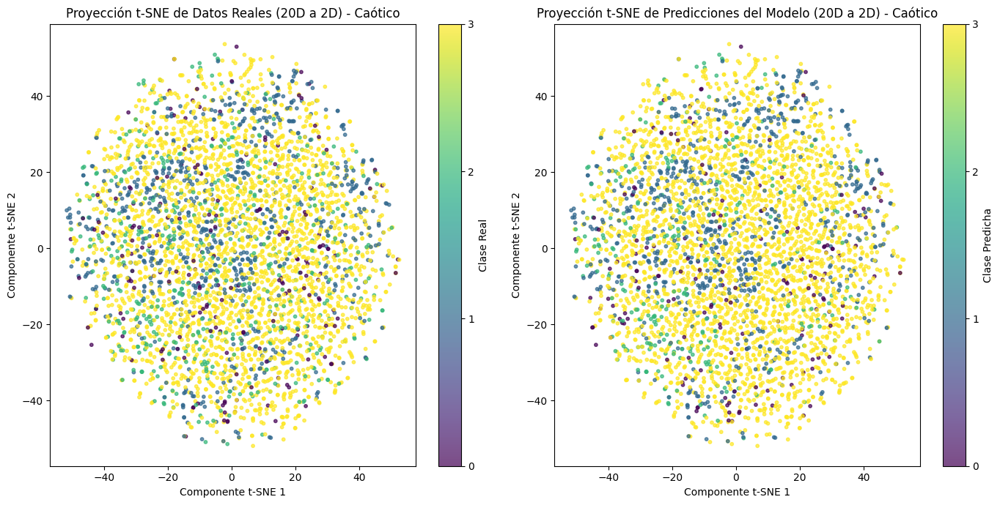

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.manifold import TSNE

# Detectar si hay una GPU disponible y usarla, de lo contrario, usar la CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

# Función para generar datos en 20D con clases caóticas y discontinuas
def make_chaotic_20D_data(n_points=10000, n_classes=4, noise_level=1.0):
    data = np.random.rand(n_points, 20) * 10 - 5 # Puntos aleatorios en un rango de -5 a 5
    labels = np.zeros(n_points, dtype=int)

    for i in range(n_points):
        p = data[i]

        # Criterios de clasificación caóticos y combinatorios
        # Esto NO es una función suave. Son condiciones booleanas arbitrarias.
        if (p[0] > 2 and p[3] < -1 and p[7] > 3) or \
           (p[1] < -3 and p[5] > 4) or \
           (np.abs(p[9]) < 0.5 and p[12] > 2 and p[18] < -2):
            labels[i] = 0
        elif (p[2] > 1 and p[4] < -0.5) or \
             (p[6] < -2 and p[8] > 1.5 and np.sum(p[10:13]) > 5):
            labels[i] = 1
        elif (p[10] > 0 and p[11] < 0 and p[13] > 0 and p[14] < 0) or \
             (np.sin(p[15]) * np.cos(p[16]) > 0.5 and p[17] < 1):
            labels[i] = 2
        else:
            labels[i] = 3 # Clase por defecto, o la cuarta clase

        # Añadir ruido con distribución no gaussiana y asimétrica
        # Ruido exponencial en algunas dimensiones para hacerla más difícil
        data[i, 0] += np.random.exponential(noise_level * 0.1) * np.random.choice([-1, 1])
        data[i, 1] += np.random.normal(0, noise_level * 0.05)
        data[i, 5] += np.random.poisson(noise_level * 0.5) * np.random.choice([-1, 1])
        data[i, 19] += np.random.uniform(-noise_level, noise_level) # Ruido uniforme fuerte

    # Asegurarse de que haya al menos 4 clases (si no, el critero aleatorio podría no generarlas todas)
    unique_labels = np.unique(labels)
    if len(unique_labels) < n_classes:
        print(f"Advertencia: Generadas solo {len(unique_labels)} clases. Aumenta n_points o ajusta la lógica.")
        # Ajustar n_classes si no se generan todas
        n_classes = len(unique_labels)


    return data, labels, n_classes

# Generar datos caóticos
n_classes_chaos = 4 # Intentamos 4 clases, la función podría generar menos si los criterios son restrictivos
X_chaos, y_chaos, n_actual_classes = make_chaotic_20D_data(n_points=20000, n_classes=n_classes_chaos, noise_level=0.8) # Más puntos

# Dividir y escalar los datos
X_train_chaos, X_test_chaos, y_train_chaos, y_test_chaos = train_test_split(X_chaos, y_chaos, test_size=0.2, random_state=42)
scaler_chaos = StandardScaler()
X_train_scaled_chaos = scaler_chaos.fit_transform(X_train_chaos)
X_test_scaled_chaos = scaler_chaos.transform(X_test_chaos)

# Convertir a tensores de PyTorch y moverlos a la GPU
X_train_tensor_chaos = torch.tensor(X_train_scaled_chaos, dtype=torch.float32).to(device)
y_train_tensor_chaos = torch.tensor(y_train_chaos, dtype=torch.long).to(device)
X_test_tensor_chaos = torch.tensor(X_test_scaled_chaos, dtype=torch.float32).to(device)
y_test_tensor_chaos = torch.tensor(y_test_chaos, dtype=torch.long).to(device)

# Modelo 20D (aún más profundo y ancho)
class Chaotic20DClassifier(nn.Module):
    def __init__(self, num_features=20, num_classes=4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(num_features, 512), # Gran primera capa
            nn.LeakyReLU(0.01), # Usar LeakyReLU para evitar neuronas muertas
            nn.Dropout(0.4),
            nn.Linear(512, 512),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.01),
            nn.Linear(128, num_classes) # Salida con num_classes
        )
    def forward(self, x):
        return self.net(x)

model_chaos = Chaotic20DClassifier(num_features=20, num_classes=n_actual_classes).to(device) # Mover el modelo a la GPU
criterion_chaos = nn.CrossEntropyLoss()
optimizer_chaos = optim.Adam(model_chaos.parameters(), lr=0.0005, weight_decay=1e-5) # LR aún más bajo, fuerte regularización

# Entrenamiento
print(f"\nEntrenando modelo 20D con {n_actual_classes} clases caóticas y ruido extremo en la {device}...")
num_epochs_chaos = 3000 # Muchas más épocas
for epoch in range(num_epochs_chaos):
    model_chaos.train()
    optimizer_chaos.zero_grad()
    outputs_chaos = model_chaos(X_train_tensor_chaos)
    loss_chaos = criterion_chaos(outputs_chaos, y_train_tensor_chaos)
    loss_chaos.backward()
    optimizer_chaos.step()
    # if (epoch + 1) % 200 == 0:
    #     print(f"Epoch {epoch+1}/{num_epochs_chaos}, Loss: {loss_chaos.item():.4f}")

# Evaluación
model_chaos.eval()
with torch.no_grad():
    test_outputs_chaos = model_chaos(X_test_tensor_chaos)
    _, predicted_chaos = torch.max(test_outputs_chaos, 1)
    correct_chaos = (predicted_chaos == y_test_tensor_chaos).float().sum()
    accuracy_chaos = (correct_chaos / y_test_tensor_chaos.size(0)).item() * 100
    print(f"Precisión en test 20D (Caótico): {accuracy_chaos:.4f}%")

# Visualización usando t-SNE para reducir 20D a 2D (con un subconjunto)
# Los datos para t-SNE deben estar en la CPU
if X_test_scaled_chaos.shape[0] > 5000:
    idx_tsne = np.random.choice(X_test_scaled_chaos.shape[0], 5000, replace=False)
    X_test_sample_chaos = X_test_scaled_chaos[idx_tsne]
    y_test_sample_chaos = y_test_tensor_chaos[idx_tsne].cpu().numpy() # Mover a CPU
    predicted_sample_chaos = predicted_chaos[idx_tsne].cpu().numpy() # Mover a CPU
else:
    X_test_sample_chaos = X_test_scaled_chaos
    y_test_sample_chaos = y_test_tensor_chaos.cpu().numpy() # Mover a CPU
    predicted_sample_chaos = predicted_chaos.cpu().numpy() # Mover a CPU


print("\nRealizando reducción de dimensionalidad con t-SNE para visualizar el caos (puede tardar bastante)...")
tsne_chaos = TSNE(n_components=2, random_state=42, perplexity=50, n_iter=2000, learning_rate='auto', init='random') # Ajustes para datos complejos
X_tsne_chaos = tsne_chaos.fit_transform(X_test_sample_chaos)

plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
scatter1_chaos = plt.scatter(X_tsne_chaos[:, 0], X_tsne_chaos[:, 1], c=y_test_sample_chaos, cmap='viridis', alpha=0.7, s=10)
plt.title("Proyección t-SNE de Datos Reales (20D a 2D) - Caótico")
plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")
plt.colorbar(scatter1_chaos, ticks=range(n_actual_classes), label='Clase Real')

plt.subplot(1, 2, 2)
scatter2_chaos = plt.scatter(X_tsne_chaos[:, 0], X_tsne_chaos[:, 1], c=predicted_sample_chaos, cmap='viridis', alpha=0.7, s=10)
plt.title("Proyección t-SNE de Predicciones del Modelo (20D a 2D) - Caótico")
plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")
plt.colorbar(scatter2_chaos, ticks=range(n_actual_classes), label='Clase Predicha')

plt.tight_layout()
plt.show()

Usando dispositivo: cuda


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(



Entrenando modelo 20D con 4 clases caóticas y ruido extremo (con scheduler)...
Precisión en test 20D (Caótico, Mejorado): 84.2750%

Realizando reducción de dimensionalidad con t-SNE para visualizar el caos (puede tardar bastante)...


/usr/local/lib/python3.11/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


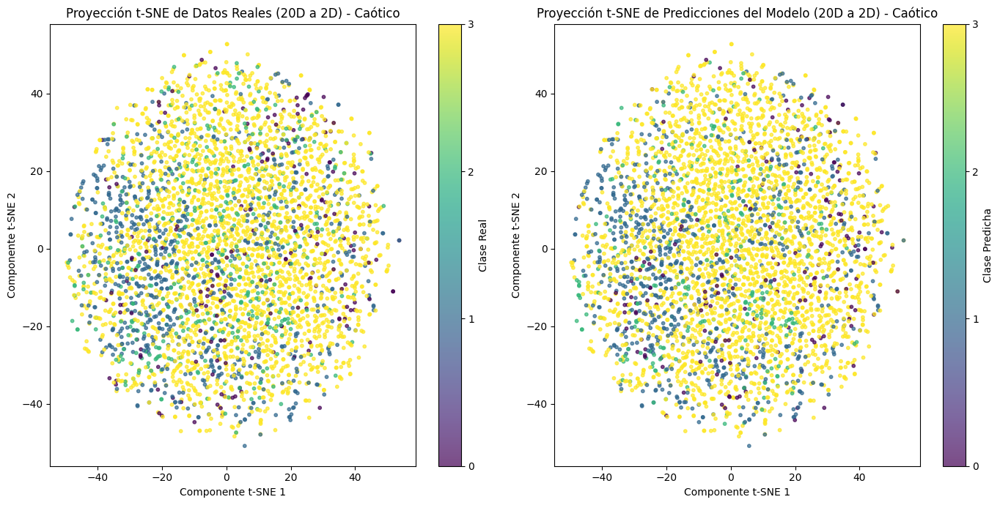

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.manifold import TSNE

# Asegúrate de usar CUDA si está disponible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

# --- Función para generar datos en 20D (mismo que antes) ---
def make_chaotic_20D_data(n_points=10000, n_classes=4, noise_level=1.0):
    data = np.random.rand(n_points, 20) * 10 - 5
    labels = np.zeros(n_points, dtype=int)

    for i in range(n_points):
        p = data[i]

        if (p[0] > 2 and p[3] < -1 and p[7] > 3) or \
           (p[1] < -3 and p[5] > 4) or \
           (np.abs(p[9]) < 0.5 and p[12] > 2 and p[18] < -2):
            labels[i] = 0
        elif (p[2] > 1 and p[4] < -0.5) or \
             (p[6] < -2 and p[8] > 1.5 and np.sum(p[10:13]) > 5):
            labels[i] = 1
        elif (p[10] > 0 and p[11] < 0 and p[13] > 0 and p[14] < 0) or \
             (np.sin(p[15]) * np.cos(p[16]) > 0.5 and p[17] < 1):
            labels[i] = 2
        else:
            labels[i] = 3

        data[i, 0] += np.random.exponential(noise_level * 0.1) * np.random.choice([-1, 1])
        data[i, 1] += np.random.normal(0, noise_level * 0.05)
        data[i, 5] += np.random.poisson(noise_level * 0.5) * np.random.choice([-1, 1])
        data[i, 19] += np.random.uniform(-noise_level, noise_level)

    unique_labels = np.unique(labels)
    if len(unique_labels) < n_classes:
        print(f"Advertencia: Generadas solo {len(unique_labels)} clases. Ajustando n_classes.")
        n_classes = len(unique_labels)

    return data, labels, n_classes

# --- Generar datos ---
n_classes_chaos = 4
X_chaos, y_chaos, n_actual_classes = make_chaotic_20D_data(n_points=20000, n_classes=n_classes_chaos, noise_level=0.8)

# --- Dividir y escalar ---
X_train_chaos, X_test_chaos, y_train_chaos, y_test_chaos = train_test_split(X_chaos, y_chaos, test_size=0.2, random_state=42)
scaler_chaos = StandardScaler()
X_train_scaled_chaos = scaler_chaos.fit_transform(X_train_chaos)
X_test_scaled_chaos = scaler_chaos.transform(X_test_chaos)

# --- Convertir a tensores y mover a CUDA ---
X_train_tensor_chaos = torch.tensor(X_train_scaled_chaos, dtype=torch.float32).to(device)
y_train_tensor_chaos = torch.tensor(y_train_chaos, dtype=torch.long).to(device)
X_test_tensor_chaos = torch.tensor(X_test_scaled_chaos, dtype=torch.float32).to(device)
y_test_tensor_chaos = torch.tensor(y_test_chaos, dtype=torch.long).to(device)

# --- Modelo 20D (mismo que antes) ---
class Chaotic20DClassifier(nn.Module):
    def __init__(self, num_features=20, num_classes=4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(num_features, 512),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.4),
            nn.Linear(512, 512),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.01),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.net(x)

model_chaos = Chaotic20DClassifier(num_features=20, num_classes=n_actual_classes).to(device) # Mover modelo a CUDA
criterion_chaos = nn.CrossEntropyLoss()
optimizer_chaos = optim.Adam(model_chaos.parameters(), lr=0.0005, weight_decay=1e-5)

# --- Añadir el Learning Rate Scheduler ---
# ReduceLROnPlateau: Reduce el LR cuando la pérdida de validación deja de mejorar
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_chaos,
    mode='min',        # Monitorear la pérdida de entrenamiento para minimizarla
    factor=0.5,        # Multiplicar LR por 0.5 cuando se activa
    patience=200,      # Esperar 200 épocas sin mejora antes de reducir el LR
    verbose=True,      # Imprimir mensaje cuando el LR se reduce
    min_lr=1e-7        # LR mínimo permitido
)

# --- Entrenamiento (con scheduler) ---
print(f"\nEntrenando modelo 20D con {n_actual_classes} clases caóticas y ruido extremo (con scheduler)...")
num_epochs_chaos = 3000
for epoch in range(num_epochs_chaos):
    model_chaos.train()
    optimizer_chaos.zero_grad()
    outputs_chaos = model_chaos(X_train_tensor_chaos)
    loss_chaos = criterion_chaos(outputs_chaos, y_train_tensor_chaos)
    loss_chaos.backward()
    optimizer_chaos.step()

    # Paso del scheduler después de cada época, basado en la pérdida de entrenamiento
    scheduler.step(loss_chaos)

    # if (epoch + 1) % 200 == 0:
    #     print(f"Epoch {epoch+1}/{num_epochs_chaos}, Loss: {loss_chaos.item():.4f}, Current LR: {optimizer_chaos.param_groups[0]['lr']:.6f}")

# --- Evaluación ---
model_chaos.eval()
with torch.no_grad():
    test_outputs_chaos = model_chaos(X_test_tensor_chaos)
    _, predicted_chaos = torch.max(test_outputs_chaos, 1)
    correct_chaos = (predicted_chaos == y_test_tensor_chaos).float().sum()
    accuracy_chaos = (correct_chaos / y_test_tensor_chaos.size(0)).item() * 100
    print(f"Precisión en test 20D (Caótico, Mejorado): {accuracy_chaos:.4f}%")

# --- Visualización con t-SNE (mismo que antes) ---
# Mover datos a CPU para t-SNE (scikit-learn no usa CUDA)
X_test_scaled_chaos_cpu = X_test_scaled_chaos
y_test_tensor_chaos_cpu = y_test_tensor_chaos.cpu().numpy()
predicted_chaos_cpu = predicted_chaos.cpu().numpy()


if X_test_scaled_chaos_cpu.shape[0] > 5000:
    idx_tsne = np.random.choice(X_test_scaled_chaos_cpu.shape[0], 5000, replace=False)
    X_test_sample_chaos = X_test_scaled_chaos_cpu[idx_tsne]
    y_test_sample_chaos = y_test_tensor_chaos_cpu[idx_tsne]
    predicted_sample_chaos = predicted_chaos_cpu[idx_tsne]
else:
    X_test_sample_chaos = X_test_scaled_chaos_cpu
    y_test_sample_chaos = y_test_tensor_chaos_cpu
    predicted_sample_chaos = predicted_chaos_cpu


print("\nRealizando reducción de dimensionalidad con t-SNE para visualizar el caos (puede tardar bastante)...")
tsne_chaos = TSNE(n_components=2, random_state=42, perplexity=50, n_iter=2000, learning_rate='auto', init='random')
X_tsne_chaos = tsne_chaos.fit_transform(X_test_sample_chaos)

plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
scatter1_chaos = plt.scatter(X_tsne_chaos[:, 0], X_tsne_chaos[:, 1], c=y_test_sample_chaos, cmap='viridis', alpha=0.7, s=10)
plt.title("Proyección t-SNE de Datos Reales (20D a 2D) - Caótico")
plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")
plt.colorbar(scatter1_chaos, ticks=range(n_actual_classes), label='Clase Real')

plt.subplot(1, 2, 2)
scatter2_chaos = plt.scatter(X_tsne_chaos[:, 0], X_tsne_chaos[:, 1], c=predicted_sample_chaos, cmap='viridis', alpha=0.7, s=10)
plt.title("Proyección t-SNE de Predicciones del Modelo (20D a 2D) - Caótico")
plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")
plt.colorbar(scatter2_chaos, ticks=range(n_actual_classes), label='Clase Predicha')

plt.tight_layout()
plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score

class ImprovedChaotic20DClassifier(nn.Module):
    def __init__(self, num_features=20, num_classes=4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(num_features, 1024),
            nn.BatchNorm1d(1024),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.4),

            nn.Linear(1024, 1024),
            nn.BatchNorm1d(1024),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.4),

            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.3),

            nn.Linear(512, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.3),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.2),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.01),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.net(x)

def train_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    all_preds = []
    all_targets = []

    for x, y in dataloader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        preds = out.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(y.cpu().numpy())

    avg_loss = total_loss / len(dataloader.dataset)
    acc = accuracy_score(all_targets, all_preds)
    return avg_loss, acc

def eval_epoch(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for x, y in dataloader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)

            total_loss += loss.item() * x.size(0)
            preds = out.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(y.cpu().numpy())

    avg_loss = total_loss / len(dataloader.dataset)
    acc = accuracy_score(all_targets, all_preds)
    return avg_loss, acc

def train_loop(model, train_loader, val_loader, criterion, optimizer, scheduler, device, epochs=300):
    best_val_loss = float('inf')
    for epoch in range(1, epochs+1):
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = eval_epoch(model, val_loader, criterion, device)

        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), 'best_model.pth')

        if epoch % 10 == 0 or epoch == 1:
            print(f"Epoch {epoch:03d} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
                  f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

if __name__ == "__main__":
    # Configuración básica
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    num_features = 20
    num_classes = 4

    # Dataset dummy (reemplaza con tus datos)
    X_train = torch.randn(1000, num_features)
    y_train = torch.randint(0, num_classes, (1000,))
    X_val = torch.randn(200, num_features)
    y_val = torch.randint(0, num_classes, (200,))

    train_dataset = TensorDataset(X_train, y_train)
    val_dataset = TensorDataset(X_val, y_val)
    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=64)

    # Modelo, criterio, optimizador y scheduler
    model = ImprovedChaotic20DClassifier(num_features, num_classes).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=100, verbose=True)

    # Entrenamiento
    train_loop(model, train_loader, val_loader, criterion, optimizer, scheduler, device, epochs=300)

/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 001 | Train Loss: 1.4280 | Train Acc: 0.2580 | Val Loss: 1.3877 | Val Acc: 0.2750
Epoch 010 | Train Loss: 1.0791 | Train Acc: 0.5380 | Val Loss: 1.5938 | Val Acc: 0.2950
Epoch 020 | Train Loss: 0.7506 | Train Acc: 0.6940 | Val Loss: 1.9212 | Val Acc: 0.3200
Epoch 030 | Train Loss: 0.5840 | Train Acc: 0.7790 | Val Loss: 2.3149 | Val Acc: 0.2950
Epoch 040 | Train Loss: 0.4453 | Train Acc: 0.8330 | Val Loss: 2.4376 | Val Acc: 0.3000
Epoch 050 | Train Loss: 0.3838 | Train Acc: 0.8580 | Val Loss: 2.6612 | Val Acc: 0.2750
Epoch 060 | Train Loss: 0.3414 | Train Acc: 0.8780 | Val Loss: 2.7760 | Val Acc: 0.2950
Epoch 070 | Train Loss: 0.2122 | Train Acc: 0.9300 | Val Loss: 2.9649 | Val Acc: 0.2950
Epoch 080 | Train Loss: 0.2246 | Train Acc: 0.9150 | Val Loss: 3.0750 | Val Acc: 0.2900
Epoch 090 | Train Loss: 0.2053 | Train Acc: 0.9240 | Val Loss: 3.0892 | Val Acc: 0.2900
Epoch 100 | Train Loss: 0.1676 | Train Acc: 0.9410 | Val Loss: 3.4405 | Val Acc: 0.2550
Epoch 110 | Train Loss: 0.1435 |

Usando dispositivo: cuda


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(



Entrenando modelo 20D con 4 clases caóticas y ruido extremo (con scheduler)...
Precisión en test 20D (Caótico, Mejorado): 82.1750%

Realizando reducción de dimensionalidad con t-SNE para visualizar el caos (puede tardar bastante)...


/usr/local/lib/python3.11/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


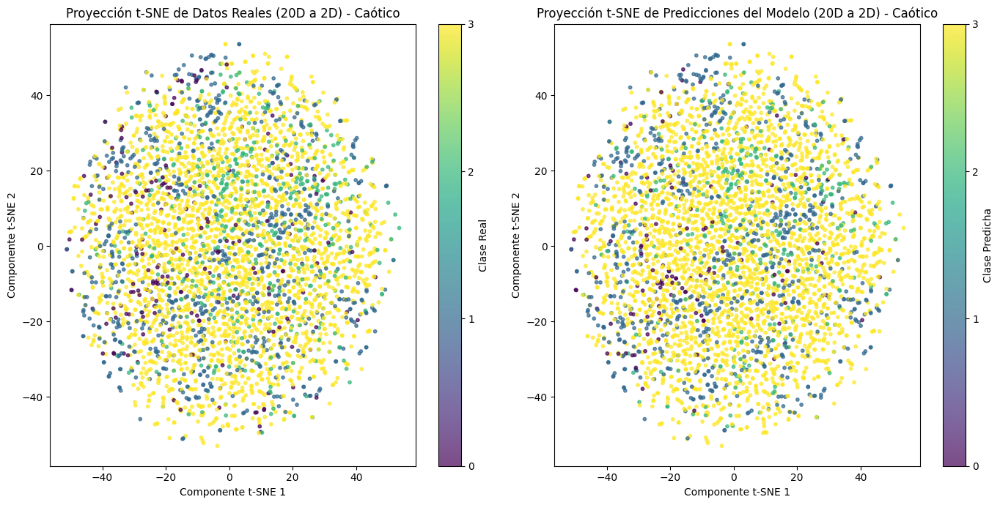

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.manifold import TSNE

# Configuración del dispositivo (CUDA o CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")



## Generación de Datos Caóticos en 20D

def make_chaotic_20D_data(n_points=10000, n_classes=4, noise_level=1.0):
    data = np.random.rand(n_points, 20) * 10 - 5
    labels = np.zeros(n_points, dtype=int)

    for i in range(n_points):
        p = data[i]
        # Criterios de clasificación caóticos y combinatorios
        if (p[0] > 2 and p[3] < -1 and p[7] > 3) or \
           (p[1] < -3 and p[5] > 4) or \
           (np.abs(p[9]) < 0.5 and p[12] > 2 and p[18] < -2):
            labels[i] = 0
        elif (p[2] > 1 and p[4] < -0.5) or \
             (p[6] < -2 and p[8] > 1.5 and np.sum(p[10:13]) > 5):
            labels[i] = 1
        elif (p[10] > 0 and p[11] < 0 and p[13] > 0 and p[14] < 0) or \
             (np.sin(p[15]) * np.cos(p[16]) > 0.5 and p[17] < 1):
            labels[i] = 2
        else:
            labels[i] = 3

        # Añadir ruido con distribución no gaussiana y asimétrica
        data[i, 0] += np.random.exponential(noise_level * 0.1) * np.random.choice([-1, 1])
        data[i, 1] += np.random.normal(0, noise_level * 0.05)
        data[i, 5] += np.random.poisson(noise_level * 0.5) * np.random.choice([-1, 1])
        data[i, 19] += np.random.uniform(-noise_level, noise_level)

    unique_labels = np.unique(labels)
    if len(unique_labels) < n_classes:
        print(f"Advertencia: Generadas solo {len(unique_labels)} clases. Ajustando n_classes.")
        n_classes = len(unique_labels)

    return data, labels, n_classes

# Generar, dividir, escalar y convertir datos a tensores PyTorch
n_classes_chaos = 4
X_chaos, y_chaos, n_actual_classes = make_chaotic_20D_data(n_points=20000, n_classes=n_classes_chaos, noise_level=0.8)

X_train_chaos, X_test_chaos, y_train_chaos, y_test_chaos = train_test_split(X_chaos, y_chaos, test_size=0.2, random_state=42)
scaler_chaos = StandardScaler()
X_train_scaled_chaos = scaler_chaos.fit_transform(X_train_chaos)
X_test_scaled_chaos = scaler_chaos.transform(X_test_chaos)

X_train_tensor_chaos = torch.tensor(X_train_scaled_chaos, dtype=torch.float32).to(device)
y_train_tensor_chaos = torch.tensor(y_train_chaos, dtype=torch.long).to(device)
X_test_tensor_chaos = torch.tensor(X_test_scaled_chaos, dtype=torch.float32).to(device)
y_test_tensor_chaos = torch.tensor(y_test_chaos, dtype=torch.long).to(device)

class Chaotic20DClassifier(nn.Module):
    def __init__(self, num_features=20, num_classes=4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(num_features, 1024),
            nn.BatchNorm1d(1024),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.4),

            nn.Linear(1024, 1024),
            nn.BatchNorm1d(1024),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.4),

            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.3),

            nn.Linear(512, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.3),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.2),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.01),

            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.net(x)

model_chaos = Chaotic20DClassifier(num_features=20, num_classes=n_actual_classes).to(device)
criterion_chaos = nn.CrossEntropyLoss()
optimizer_chaos = optim.Adam(model_chaos.parameters(), lr=0.0005, weight_decay=1e-5)

# Programador de Tasa de Aprendizaje (ReduceLROnPlateau)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_chaos,
    mode='min',
    factor=0.5,
    patience=200,
    verbose=True,
    min_lr=1e-7
)

print(f"\nEntrenando modelo 20D con {n_actual_classes} clases caóticas y ruido extremo (con scheduler)...")
num_epochs_chaos = 3000
for epoch in range(num_epochs_chaos):
    model_chaos.train()
    optimizer_chaos.zero_grad()
    outputs_chaos = model_chaos(X_train_tensor_chaos)
    loss_chaos = criterion_chaos(outputs_chaos, y_train_tensor_chaos)
    loss_chaos.backward()
    optimizer_chaos.step()

    scheduler.step(loss_chaos)

model_chaos.eval()
with torch.no_grad():
    test_outputs_chaos = model_chaos(X_test_tensor_chaos)
    _, predicted_chaos = torch.max(test_outputs_chaos, 1)
    correct_chaos = (predicted_chaos == y_test_tensor_chaos).float().sum()
    accuracy_chaos = (correct_chaos / y_test_tensor_chaos.size(0)).item() * 100
    print(f"Precisión en test 20D (Caótico, Mejorado): {accuracy_chaos:.4f}%")

X_test_scaled_chaos_cpu = X_test_scaled_chaos
y_test_tensor_chaos_cpu = y_test_tensor_chaos.cpu().numpy()
predicted_chaos_cpu = predicted_chaos.cpu().numpy()

if X_test_scaled_chaos_cpu.shape[0] > 5000:
    idx_tsne = np.random.choice(X_test_scaled_chaos_cpu.shape[0], 5000, replace=False)
    X_test_sample_chaos = X_test_scaled_chaos_cpu[idx_tsne]
    y_test_sample_chaos = y_test_tensor_chaos_cpu[idx_tsne]
    predicted_sample_chaos = predicted_chaos_cpu[idx_tsne]
else:
    X_test_sample_chaos = X_test_scaled_chaos_cpu
    y_test_sample_chaos = y_test_tensor_chaos_cpu
    predicted_sample_chaos = predicted_chaos_cpu

print("\nRealizando reducción de dimensionalidad con t-SNE para visualizar el caos (puede tardar bastante)...")
tsne_chaos = TSNE(n_components=2, random_state=42, perplexity=50, n_iter=2000, learning_rate='auto', init='random')
X_tsne_chaos = tsne_chaos.fit_transform(X_test_sample_chaos)

plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
scatter1_chaos = plt.scatter(X_tsne_chaos[:, 0], X_tsne_chaos[:, 1], c=y_test_sample_chaos, cmap='viridis', alpha=0.7, s=10)
plt.title("Proyección t-SNE de Datos Reales (20D a 2D) - Caótico")
plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")
plt.colorbar(scatter1_chaos, ticks=range(n_actual_classes), label='Clase Real')

plt.subplot(1, 2, 2)
scatter2_chaos = plt.scatter(X_tsne_chaos[:, 0], X_tsne_chaos[:, 1], c=predicted_sample_chaos, cmap='viridis', alpha=0.7, s=10)
plt.title("Proyección t-SNE de Predicciones del Modelo (20D a 2D) - Caótico")
plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")
plt.colorbar(scatter2_chaos, ticks=range(n_actual_classes), label='Clase Predicha')

plt.tight_layout()
plt.show()

Usando dispositivo: cuda


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(



Entrenando modelo 20D con 4 clases caóticas y ruido extremo (con scheduler)...
Precisión en test 20D (Caótico, Mejorado): 82.4000%

Realizando reducción de dimensionalidad con t-SNE para visualizar el caos (puede tardar bastante)...


/usr/local/lib/python3.11/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


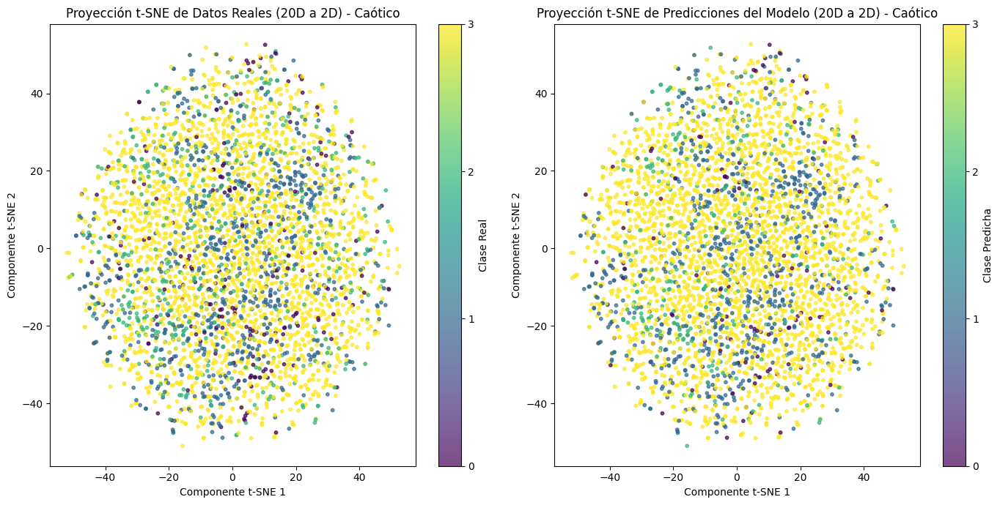

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.manifold import TSNE

# Configuración del dispositivo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

# --- Generación de datos 20D caóticos ---
def make_chaotic_20D_data(n_points=10000, n_classes=4, noise_level=1.0):
    data = np.random.rand(n_points, 20) * 10 - 5
    labels = np.zeros(n_points, dtype=int)
    for i in range(n_points):
        p = data[i]
        if (p[0] > 2 and p[3] < -1 and p[7] > 3) or \
           (p[1] < -3 and p[5] > 4) or \
           (np.abs(p[9]) < 0.5 and p[12] > 2 and p[18] < -2): labels[i] = 0
        elif (p[2] > 1 and p[4] < -0.5) or \
             (p[6] < -2 and p[8] > 1.5 and np.sum(p[10:13]) > 5): labels[i] = 1
        elif (p[10] > 0 and p[11] < 0 and p[13] > 0 and p[14] < 0) or \
             (np.sin(p[15]) * np.cos(p[16]) > 0.5 and p[17] < 1): labels[i] = 2
        else: labels[i] = 3
        data[i, 0] += np.random.exponential(noise_level * 0.1) * np.random.choice([-1, 1])
        data[i, 1] += np.random.normal(0, noise_level * 0.05)
        data[i, 5] += np.random.poisson(noise_level * 0.5) * np.random.choice([-1, 1])
        data[i, 19] += np.random.uniform(-noise_level, noise_level)
    n_classes = len(np.unique(labels)) if len(np.unique(labels)) < n_classes else n_classes # Ajusta n_classes si no se generan todas
    return data, labels, n_classes

# Generar datos y prepararlos
n_classes_chaos = 4
X_chaos, y_chaos, n_actual_classes = make_chaotic_20D_data(n_points=20000, n_classes=n_classes_chaos, noise_level=0.8)
X_train, X_test, y_train, y_test = train_test_split(X_chaos, y_chaos, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convertir a tensores y mover a CUDA
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train, dtype=torch.long).to(device)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
y_test_tensor = torch.tensor(y_test, dtype=torch.long).to(device)

# --- Definición del modelo 20D ---
class Chaotic20DClassifier(nn.Module):
    def __init__(self, num_features=20, num_classes=4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(num_features, 1024), nn.BatchNorm1d(1024), nn.LeakyReLU(0.01), nn.Dropout(0.4),
            nn.Linear(1024, 1024), nn.BatchNorm1d(1024), nn.LeakyReLU(0.01), nn.Dropout(0.4),
            nn.Linear(1024, 512), nn.BatchNorm1d(512), nn.LeakyReLU(0.01), nn.Dropout(0.3),
            nn.Linear(512, 512), nn.BatchNorm1d(512), nn.LeakyReLU(0.01), nn.Dropout(0.3),
            nn.Linear(512, 256), nn.BatchNorm1d(256), nn.LeakyReLU(0.01), nn.Dropout(0.2),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.LeakyReLU(0.01),
            nn.Linear(128, num_classes)
        )
    def forward(self, x): return self.net(x)

# Inicializar modelo, criterio, optimizador y scheduler
model = Chaotic20DClassifier(num_features=20, num_classes=n_actual_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=200, verbose=True, min_lr=1e-7)

# --- Entrenamiento del modelo ---
print(f"\nEntrenando modelo 20D con {n_actual_classes} clases caóticas y ruido extremo (con scheduler)...")
num_epochs = 3000
for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    loss = criterion(model(X_train_tensor), y_train_tensor)
    loss.backward()
    optimizer.step()
    scheduler.step(loss)

# --- Evaluación del modelo ---
model.eval()
with torch.no_grad():
    test_outputs = model(X_test_tensor)
    _, predicted = torch.max(test_outputs, 1)
    accuracy = (predicted == y_test_tensor).float().sum() / y_test_tensor.size(0) * 100
    print(f"Precisión en test 20D (Caótico, Mejorado): {accuracy:.4f}%")

# --- Visualización con t-SNE ---
X_test_sample = X_test_scaled[np.random.choice(X_test_scaled.shape[0], 5000, replace=False)] if X_test_scaled.shape[0] > 5000 else X_test_scaled
y_test_sample = y_test_tensor.cpu().numpy()[np.random.choice(y_test_tensor.size(0), 5000, replace=False)] if y_test_tensor.size(0) > 5000 else y_test_tensor.cpu().numpy()
predicted_sample = predicted.cpu().numpy()[np.random.choice(predicted.size(0), 5000, replace=False)] if predicted.size(0) > 5000 else predicted.cpu().numpy()

print("\nRealizando reducción de dimensionalidad con t-SNE para visualizar el caos (puede tardar bastante)...")
tsne = TSNE(n_components=2, random_state=42, perplexity=50, n_iter=2000, learning_rate='auto', init='random')
X_tsne = tsne.fit_transform(X_test_sample)

plt.figure(figsize=(14, 7))
plt.subplot(1, 2, 1)
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_test_sample, cmap='viridis', alpha=0.7, s=10)
plt.title("Proyección t-SNE de Datos Reales (20D a 2D) - Caótico")
plt.xlabel("Componente t-SNE 1"); plt.ylabel("Componente t-SNE 2")
plt.colorbar(ticks=range(n_actual_classes), label='Clase Real')

plt.subplot(1, 2, 2)
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=predicted_sample, cmap='viridis', alpha=0.7, s=10)
plt.title("Proyección t-SNE de Predicciones del Modelo (20D a 2D) - Caótico")
plt.xlabel("Componente t-SNE 1"); plt.ylabel("Componente t-SNE 2")
plt.colorbar(ticks=range(n_actual_classes), label='Clase Predicha')
plt.tight_layout(); plt.show()

##gnn biomas especiales

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class NeuralBiomesModel(nn.Module):
    def __init__(self, input_dim, shared_features_dim, memory_hidden_dim, processing_output_dim, output_dim):
        super().__init__()

        # 1. Capa de Entrada Común ("El Mundo")
        self.shared_feature_extractor = nn.Sequential(
            nn.Linear(input_dim, shared_features_dim),
            nn.ReLU(),
            nn.Linear(shared_features_dim, shared_features_dim) # Opcional: más capas
        )

        # 2. Bioma de Almacenamiento (ej. usando LSTM para "memoria" secuencial)
        # Asumimos que procesa secuencias de features compartidos
        # En un modelo simple, puede ser solo una capa lineal para "codificar"
        self.memory_biom = nn.LSTM(shared_features_dim, memory_hidden_dim, batch_first=True)
        # O para un caso más simple, solo una capa que "codifique" para almacenamiento
        # self.memory_encoder = nn.Linear(shared_features_dim, memory_hidden_dim)


        # 3. Bioma de Procesamiento (ej. un MLP para lógica/cálculo)
        # Recibe features del mundo y el estado de la memoria
        self.processing_biom = nn.Sequential(
            nn.Linear(shared_features_dim + memory_hidden_dim, 128), # Combina features y memoria
            nn.ReLU(),
            nn.Linear(128, processing_output_dim),
            nn.ReLU()
        )

        # 4. Capa de Salida Final (combinando resultados de los biomas)
        self.output_layer = nn.Linear(processing_output_dim, output_dim)

    def forward(self, x):
        # Paso 1: Extraer características en el "Mundo"
        shared_features = self.shared_feature_extractor(x)

        # Paso 2: Pasar características al Bioma de Almacenamiento
        # Para LSTM/GRU, necesitamos una secuencia de entrada.
        # Si x es un solo punto de datos, lo tratamos como una secuencia de longitud 1
        shared_features_seq = shared_features.unsqueeze(1) # Añadir dimensión de secuencia
        memory_output, (h_n, c_n) = self.memory_biom(shared_features_seq)
        memory_state = h_n.squeeze(0) # Obtener el estado oculto final del LSTM

        # Paso 3: Pasar características y memoria al Bioma de Procesamiento
        # Concatenar las características compartidas con el estado de la memoria
        combined_features = torch.cat((shared_features, memory_state), dim=1)
        processed_output = self.processing_biom(combined_features)

        # Paso 4: Pasar el resultado procesado a la capa de salida final
        final_output = self.output_layer(processed_output)

        return final_output

In [ ]:
!pip install torch_geometric

In [ ]:
!pip install torch_geometric torch-scatter torch-sparse -f https://data.pyg.org/whl/torch-1.13.0+cu117.html # Replace with your PyTorch and CUDA version